In [1]:
import config.const
from src.tools.load_model import *

tokenizer_7b, model_7b , bert_tokenizer_7b, bert_model_7b = load_model(with_bert=True)
tokenizer_1_5b, model_1_5b , bert_tokenizer_1_5b, bert_model_1_5b = load_model(model_name="Qwen/Qwen2.5-1.5B-Instruct",with_bert=True)

system check:
Python path: /usr/local/bin/python3.12
Torch version: 2.14.1+cu130
GPU: NVIDIA GeForce RTX 5060 Ti
PyTorch: 2.14.1+cu130
CUDA: 13.0
CUDA available: True
Capability: (12, 0)
this is include the following functions torch , torch.nn.functional as F, transformers.AutoTokenizer, transformers.AutoModelForCausalLM


Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


system check:
Python path: /usr/local/bin/python3.12
Torch version: 2.14.1+cu130
GPU: NVIDIA GeForce RTX 5060 Ti
PyTorch: 2.14.1+cu130
CUDA: 13.0
CUDA available: True
Capability: (12, 0)
this is include the following functions torch , torch.nn.functional as F, transformers.AutoTokenizer, transformers.AutoModelForCausalLM


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [2]:
from src.tools.embeddings import *
from src.tools.wordnet import *

In [3]:
import re

def check_special_symbols(target_symbols: str, next_word: str = "") -> bool:
    cleaned_word = target_symbols.rstrip('"\')]}')
    if not cleaned_word:
        return False
        
    last_symbol = cleaned_word[-1]
    if last_symbol in ("!", "?"):
        return True
        
    last_symbol = cleaned_word[-1] if cleaned_word else ""

    if last_symbol == ".":
        lower_word = cleaned_word.lower()

        # 2. ראשי תיבות מרובי-נקודות כמו U.S. או Ph.D.
        if re.fullmatch(r"(?:[A-Za-z]\.){2,}", cleaned_word):
            return False

        # 3. אות בודדת עם נקודה (J., M.) או קיצור שם קצר (Th.) כשלאחריו מגיעה אות גדולה
        # למשל: "Piek Th. J. M. Vossen" -> ממשיך; אבל "end of sentence. Next" -> חותך
        stem = cleaned_word[:-1]
        if len(stem) <= 2 and stem.isalpha() and stem[0].isupper():
            # אם המילה הבאה מתחילה באות גדולה, זה כנראה המשך של שם/ראשי תיבות (כמו Th. J. או M. Vossen)
            if next_word and next_word[0].isupper():
                return False

        return True
       
    return False

In [4]:
import math

def get_lca_distance(valid_words, context_words):
    synset_words = []
    distance_per_word = {}  # (word1, word2) : distance
    max_distance = 0

    #get synset format
    for word in valid_words:
        synset_words.append(lesk_target(context_words, word))  # lesk_target(context, word)

    #get distance between synsets
    for i in range(len(synset_words)):
        for j in range(i + 1, len(synset_words)):
            if synset_words[i] is None or synset_words[j] is None:
                continue
            distance = distance_to_common_lca(synset_words[i], synset_words[j])
            if distance is None:
                continue
            if distance > max_distance:
                max_distance = distance
            distance_per_word[(valid_words[i], valid_words[j])] = distance
            # print(max_distance)
            
    return distance_per_word, max_distance


def build_lca_matrix(valid_words, distance_per_word):
    """NxN matrix from the (word1, word2) : distance dict. Missing pairs = NaN, diagonal = 0."""
    n = len(valid_words)
    lca_matrix = torch.full((n, n), math.nan)
    for i in range(n):
        lca_matrix[i, i] = 0.0
    for i in range(n):
        for j in range(i + 1, n):
            distance = distance_per_word.get((valid_words[i], valid_words[j]))
            if distance is not None:
                lca_matrix[i, j] = distance
                lca_matrix[j, i] = distance
    return lca_matrix

In [29]:
def analyze_semantic_with_context_segments(
    text: str,
    tokenizer,
    model,
    with_bert: bool = False,
    bert_tokenizer=None,
    bert_model=None,
    print_results: bool = False,
):
    if with_bert and (bert_tokenizer is None or bert_model is None):
        raise ValueError("must add bert model/tokenizer to use its features")
        
    # TODO: MODE in the future what context window we want
    stop_words = get_stopwords(with_adj=True)
    words = text.split() 
    context_start_idx = 0
    context_blocks = []
    emb_block = {}
    blocks_max_distances = {}  # {block1: [max, max, ...], block2: [...]}
     
    
    for i, current_next_word in enumerate(words):
        context_words = words[context_start_idx:i]   # context so far, built live
        # print(f"current word={current_next_word} | context_len={len(context_words)}")

        clean_target_word = "".join(c for c in current_next_word if c.isalpha()).lower()
        
        if context_words and clean_target_word and clean_target_word not in stop_words:
            context_str = " ".join(context_words)
            batch = tokenizer(context_str, return_tensors="pt").to(model.device)

            with torch.no_grad():
                outputs = model(**batch , output_hidden_states=True)
                
                logits = outputs.logits[0, -1, :]
                top_probs, top_indices = torch.topk(F.softmax(logits, dim=-1), 50)

                valid_words, valid_probs = get_top_probs(top_probs, top_indices, tokenizer, stop_words)
                if not valid_words:
                    continue
                    
                clean_valid_words = ["".join(c for c in w if c.isalpha()).lower() or w for w in valid_words] #maybe remove
                
                
                distance_per_word, max_distance = get_lca_distance(clean_valid_words, context_words)
                lca_matrix = build_lca_matrix(clean_valid_words, distance_per_word)
                
                # the block we're in now = the next one to be closed
                block_key = f"block{len(context_blocks) + 1}"
                if block_key not in blocks_max_distances:
                    blocks_max_distances[block_key] = []
                if max_distance == 0:
                    blocks_max_distances[block_key].append(None)  # 0 / no LCA -> gap in the plot
                else:
                    blocks_max_distances[block_key].append(max_distance)
                
                if with_bert:
                    cos_matrix = check_cosine_similarity(
                        words=valid_words,
                        bert_tokenizer=bert_tokenizer,
                        bert_model=bert_model,
                        model=model,
                        context_str=context_str,
                        target_word=current_next_word,
                        plot=False,
                    )
                    
                    labels = [f"{idx}:{cw}" for idx, cw in enumerate(clean_valid_words)]
                    plot_cosine_lca_heatmaps(
                        cos_matrix,
                        lca_matrix,
                        labels,
                        title=f"Target: '{current_next_word}'",
                        max_distance=max_distance,
                    )

                
                
                if print_results and not with_bert:
                    print(f"  (Context): '{context_str}'")
                    print(f"  (Target):  '{current_next_word}'")
                    for w, p in zip(valid_words, valid_probs):
                        print(f"    - {w}: {p:.4f}")
                    # print(
                    
                    print("-" * 40)
                # if with_bert:
                    

        # after reading the word, decide live whether the block ends here
        next_word = words[i + 1] if i + 1 < len(words) else ""
        if check_special_symbols(current_next_word, next_word):
            block = " ".join(words[context_start_idx : i + 1])
            context_blocks.append(block)
            if print_results:
                print(f"Block {len(context_blocks)}: {block}\n")
            context_start_idx = i + 1        # reset context

    if context_start_idx < len(words):
        context_blocks.append(" ".join(words[context_start_idx:]))
        
    return context_blocks, blocks_max_distances

def get_top_probs(top_probs, top_indices, tokenizer, stop_words):
    valid_words = []
    valid_probs = []
    seen = set()
    
    for prob, idx in zip(top_probs, top_indices):
        word = tokenizer.decode(idx.item()).strip()
        clean_predicted_word = "".join([c for c in word if c.isalpha()]).lower()
        # check_word = word.lower()

        if not clean_predicted_word or clean_predicted_word in stop_words:
            continue

        if clean_predicted_word in seen: # " science" and "Science" -> keep only the first
            continue
            
        # if any(c.isalpha() for c in word) and check_word not in stop_words:
        seen.add(clean_predicted_word)
        
        valid_words.append(word)
        valid_probs.append(prob.item())
        
        if len(valid_words) == 5:
            break

    return valid_words, valid_probs

In [6]:
def check_cosine_similarity(
    words: list[str],
    bert_tokenizer,
    bert_model,
    model,
    context_str: str = "",
    target_word: str = "",
    decimals: int = 4,
    plot: bool = True,
):
    if not words:
        return None

    clean_words = ["".join(c for c in w if c.isalpha()).lower() or w for w in words]
    labels = [f"{idx}:{cw}" for idx, cw in enumerate(clean_words)]

    vectors = [
        get_bert_vec(cw, bert_tokenizer, bert_model, model).detach().float().cpu()
        for cw in clean_words
    ]
    emb_matrix = torch.stack(vectors)  # (N, D)
    norm_emb = F.normalize(emb_matrix, p=2, dim=-1)
    cos_matrix = torch.mm(norm_emb, norm_emb.t())  # (N, N)

    col_width = max(10, max(len(lbl) for lbl in labels) + 2)
    row_width = max(12, max(len(lbl) for lbl in labels) + 2)

    if context_str or target_word:
        print(f"\nContext: '{context_str}' | Target: '{target_word}'")
    header = f"{'Top-5':<{row_width}} | " + " | ".join(f"{lbl:>{col_width}}" for lbl in labels)
    print(header)
    print("-" * len(header))

    for i, row_lbl in enumerate(labels):
        vals = [f"{cos_matrix[i, j].item():>{col_width}.{decimals}f}" for j in range(len(labels))]
        print(f"{row_lbl:<{row_width}} | " + " | ".join(vals))

    title = f"Target: '{target_word}'" if target_word else "Top-5 Cosine Similarity"
    if plot:
        plot_mini_heatmap(cos_matrix, labels, title=title, decimals=2)
    
    return cos_matrix

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F


def plot_mini_heatmap(cos_matrix: torch.Tensor, labels: list[str], title: str = "", decimals: int = 2):
    matrix_np = cos_matrix.detach().cpu().numpy()
    n = matrix_np.shape[0]

    fig, ax = plt.subplots(figsize=(4.2, 3.5), dpi=100)
    im = ax.imshow(matrix_np, vmin=-1.0, vmax=1.0, cmap="coolwarm")

    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticklabels(labels, rotation=35, ha="right", fontsize=8)
    ax.set_yticklabels(labels, fontsize=8)

    for i in range(n):
        for j in range(n):
            val = matrix_np[i, j]
            text_color = "white" if abs(val) > 0.65 else "black"
            ax.text(j, i, f"{val:.{decimals}f}", ha="center", va="center", color=text_color, fontsize=7.5)

    if title:
        ax.set_title(title, fontsize=9, pad=8)

    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    fig.tight_layout()
    plt.show()
    plt.close(fig)


def _draw_heatmap(ax, fig, matrix_np, labels, title, vmin, vmax, cmap, decimals, dark_above):
    n = matrix_np.shape[0]
    im = ax.imshow(matrix_np, vmin=vmin, vmax=vmax, cmap=cmap)

    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticklabels(labels, rotation=35, ha="right", fontsize=8)
    ax.set_yticklabels(labels, fontsize=8)

    for i in range(n):
        for j in range(n):
            val = matrix_np[i, j]
            if np.isnan(val):
                ax.text(j, i, "-", ha="center", va="center", color="gray", fontsize=7.5)
                continue
            text_color = "white" if dark_above(val) else "black"
            ax.text(j, i, f"{val:.{decimals}f}", ha="center", va="center", color=text_color, fontsize=7.5)

    ax.set_title(title, fontsize=9, pad=8)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)


def plot_cosine_lca_heatmaps(
    cos_matrix: torch.Tensor,
    lca_matrix: torch.Tensor,
    labels: list[str],
    title: str = "",
    max_distance: float = 0,
):
    cos_np = cos_matrix.detach().cpu().numpy()
    lca_np = lca_matrix.detach().cpu().numpy()
    lca_max = max(max_distance, 1)

    fig, (ax_cos, ax_lca) = plt.subplots(1, 2, figsize=(8.8, 3.6), dpi=100)

    # cosine: -1..1, higher = more similar
    _draw_heatmap(ax_cos, fig, cos_np, labels, "Cosine similarity",
                  vmin=-1.0, vmax=1.0, cmap="coolwarm", decimals=2,
                  dark_above=lambda v: abs(v) > 0.65)

    # LCA: 0..max, lower = more similar (reversed colormap so similar looks "hot" in both)
    _draw_heatmap(ax_lca, fig, lca_np, labels, "LCA distance",
                  vmin=0, vmax=lca_max, cmap="viridis_r", decimals=0,
                  dark_above=lambda v: v > lca_max * 0.5)

    if title:
        fig.suptitle(title, fontsize=10)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

In [8]:
def plot_lca_curve(
    heights,
    title="LCA height",
    blocks_per_row=15,
    show_values=False,
    figsize_per_row=(16, 3.0),
):
    """מציג את ערכי ה-LCA בחלוקה נוחה לשורות כדי למנוע צפיפות ודריסת תוויות."""
    if not isinstance(heights, dict):
        heights = {"block1": heights}

    # סינון בלוקים ריקים
    valid_blocks = [
        (name, [np.nan if h is None else float(h) for h in vals])
        for name, vals in heights.items()
        if vals
    ]

    if not valid_blocks:
        print("No valid data to plot.")
        return None

    num_blocks = len(valid_blocks)
    num_rows = math.ceil(num_blocks / blocks_per_row)

    fig, axes = plt.subplots(
        num_rows,
        1,
        figsize=(figsize_per_row[0], figsize_per_row[1] * num_rows),
        squeeze=False,
    )
    colors = plt.cm.tab10.colors

    # חישוב מקסימום גלובלי כדי שכל השורות יהיו באותה סקאלה
    all_vals = [v for _, vals in valid_blocks for v in vals if not np.isnan(v)]
    y_max = max(all_vals) + 1 if all_vals else 14

    global_pos = 1

    for row_idx in range(num_rows):
        ax = axes[row_idx, 0]
        chunk = valid_blocks[row_idx * blocks_per_row : (row_idx + 1) * blocks_per_row]
        row_start_pos = global_pos

        for idx_in_chunk, (block_name, values) in enumerate(chunk):
            block_idx = row_idx * blocks_per_row + idx_in_chunk
            color = colors[block_idx % len(colors)]
            positions = np.arange(global_pos, global_pos + len(values))

            # רקע עדין לבלוק
            ax.axvspan(positions[0] - 0.5, positions[-1] + 0.5, color=color, alpha=0.10, lw=0)

            # קו ונקודות
            ax.plot(positions, values, color=color, lw=1.6, marker="o", ms=4.5)

            # הצגת המספר מעל כל נקודה אם מופעל
            if show_values:
                for x, y in zip(positions, values):
                    if not np.isnan(y):
                        ax.text(x, y + 0.3, f"{int(y)}", ha="center", va="bottom", fontsize=7.5, color="#333333")

            # קו הפרדה בין בלוקים
            if idx_in_chunk > 0:
                ax.axvline(positions[0] - 0.5, color=color, ls="--", lw=0.9, alpha=0.7)

            # הצגת שם הבלוק רק אם יש מספיק מקום (לפחות 2 מילים) או עם הטיה קלה
            if block_name:
                label = block_name.replace("block", "B")
                rotation = 0 if len(values) >= 3 else 45
                ax.text(
                    (positions[0] + positions[-1]) / 2,
                    1.02,
                    label,
                    transform=ax.get_xaxis_transform(),
                    ha="center",
                    va="bottom",
                    fontsize=8,
                    fontweight="bold",
                    color=color,
                    rotation=rotation,
                )

            global_pos += len(values)

        ax.set_xlim(row_start_pos - 0.5, global_pos - 0.5)
        ax.set_ylim(0, y_max)
        ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
        ax.grid(axis="y", linestyle=":", alpha=0.5)
        ax.set_ylabel("LCA distance", fontsize=9)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        if row_idx == 0:
            ax.set_title(title, loc="left", fontsize=12, fontweight="bold", pad=22)

    axes[-1, 0].set_xlabel("Measured word index (in reading order)", fontsize=10)
    fig.tight_layout()
    plt.show()
    return fig

Computer science is the study of computation, information, and automation.
Computer science spans theoretical disciplines (such as algorithms, theory of computation, and information theory) to applied disciplines (including the design and implementation of hardware and software).
Computer science is generally considered an area of academic research and distinct from computer programming.



Context: 'Computer' | Target: 'science'
Top-5        |    0:science |   1:software |   2:graphics |     3:vision |     4:memory
---------------------------------------------------------------------------------------
0:science    |       1.0000 |       0.5609 |       0.5013 |       0.5255 |       0.5749
1:software   |       0.5609 |       1.0000 |       0.6474 |       0.6912 |       0.6670
2:graphics   |       0.5013 |       0.6474 |       1.0000 |       0.5171 |       0.5423
3:vision     |       0.5255 |       0.6912 |       0.5171 |       1.0000 |       0.8018
4:memory     |       0.5749 |       0.

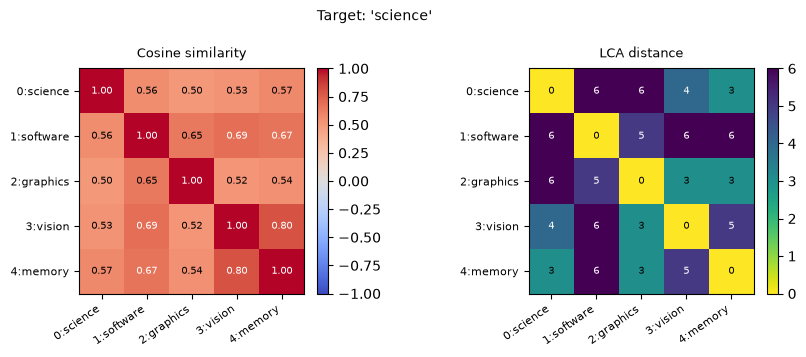


Context: 'Computer science is the' | Target: 'study'
Top-5           |         0:study |       1:science |         2:heart |      3:backbone |   4:application
---------------------------------------------------------------------------------------------------------
0:study         |          1.0000 |          0.5834 |          0.6025 |          0.7605 |          0.7301
1:science       |          0.5834 |          1.0000 |          0.4909 |          0.5987 |          0.5985
2:heart         |          0.6025 |          0.4909 |          1.0000 |          0.6377 |          0.5442
3:backbone      |          0.7605 |          0.5987 |          0.6377 |          1.0000 |          0.7333
4:application   |          0.7301 |          0.5985 |          0.5442 |          0.7333 |          1.0000


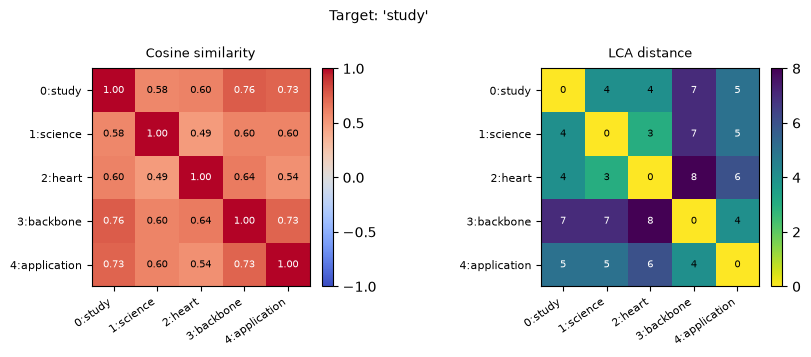


Context: 'Computer science is the study of' | Target: 'computation,'
Top-5           |     0:computers |   1:information |    2:algorithms |   3:computation |     4:algorithm
---------------------------------------------------------------------------------------------------------
0:computers     |          1.0000 |          0.4713 |          0.7392 |          0.6850 |          0.6270
1:information   |          0.4713 |          1.0000 |          0.5000 |          0.6272 |          0.4486
2:algorithms    |          0.7392 |          0.5000 |          1.0000 |          0.7581 |          0.8656
3:computation   |          0.6850 |          0.6272 |          0.7581 |          1.0000 |          0.7071
4:algorithm     |          0.6270 |          0.4486 |          0.8656 |          0.7071 |          1.0000


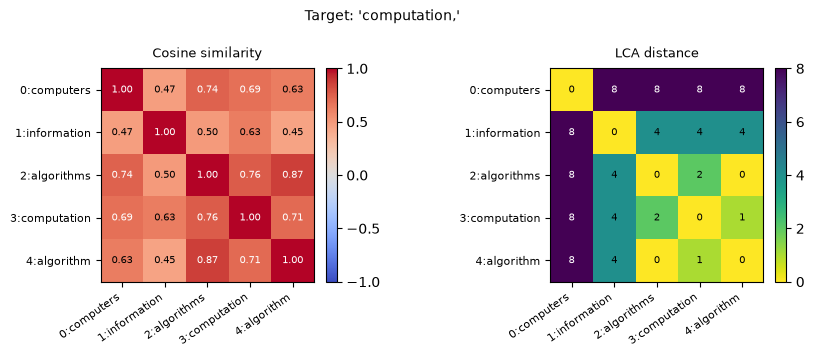


Context: 'Computer science is the study of computation,' | Target: 'information,'
Top-5          |   0:automation |   1:algorithms |      2:automat |     3:automate |      4:seeking
---------------------------------------------------------------------------------------------------
0:automation   |         1.0000 |         0.7314 |         0.6028 |         0.5793 |         0.5920
1:algorithms   |         0.7314 |         1.0000 |         0.4739 |         0.4701 |         0.6255
2:automat      |         0.6028 |         0.4739 |         1.0000 |         0.7723 |         0.4042
3:automate     |         0.5793 |         0.4701 |         0.7723 |         1.0000 |         0.4612
4:seeking      |         0.5920 |         0.6255 |         0.4042 |         0.4612 |         1.0000


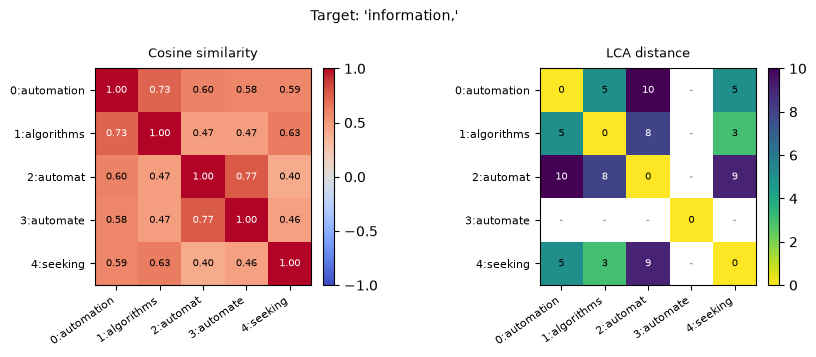


Context: 'Computer science is the study of computation, information, and' | Target: 'automation.'
Top-5           |    0:automation |   1:programming |         2:autom |     3:automatic |      4:automate
---------------------------------------------------------------------------------------------------------
0:automation    |          1.0000 |          0.7214 |          0.5761 |          0.7031 |          0.5793
1:programming   |          0.7214 |          1.0000 |          0.5232 |          0.5816 |          0.4568
2:autom         |          0.5761 |          0.5232 |          1.0000 |          0.5511 |          0.5503
3:automatic     |          0.7031 |          0.5816 |          0.5511 |          1.0000 |          0.6458
4:automate      |          0.5793 |          0.4568 |          0.5503 |          0.6458 |          1.0000


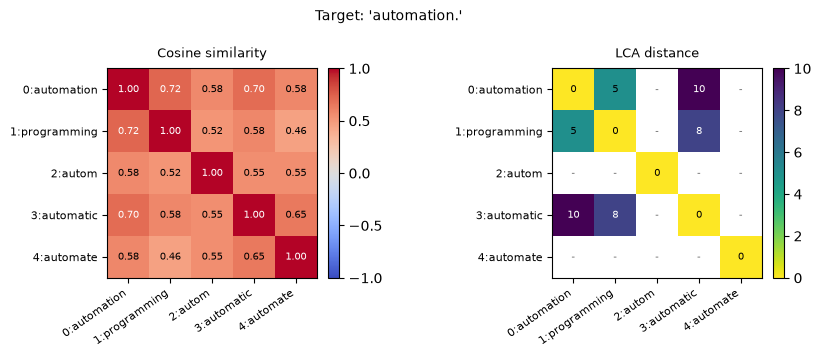

Block 1: Computer science is the study of computation, information, and automation.


Context: 'Computer' | Target: 'science'
Top-5        |    0:science |   1:software |   2:graphics |     3:vision |     4:memory
---------------------------------------------------------------------------------------
0:science    |       1.0000 |       0.5609 |       0.5013 |       0.5255 |       0.5749
1:software   |       0.5609 |       1.0000 |       0.6474 |       0.6912 |       0.6670
2:graphics   |       0.5013 |       0.6474 |       1.0000 |       0.5171 |       0.5423
3:vision     |       0.5255 |       0.6912 |       0.5171 |       1.0000 |       0.8018
4:memory     |       0.5749 |       0.6670 |       0.5423 |       0.8018 |       1.0000


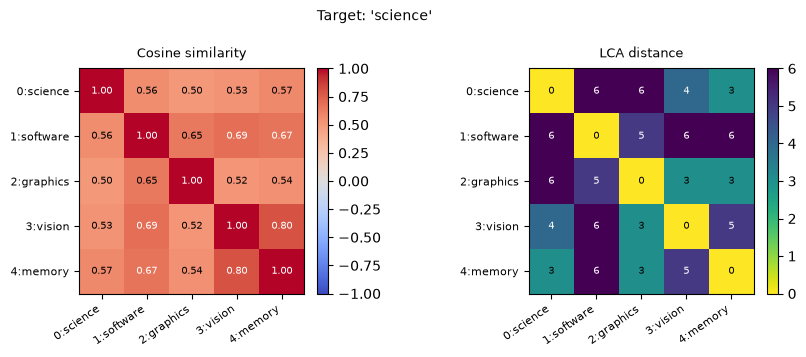


Context: 'Computer science' | Target: 'spans'
Top-5           |      0:students |     1:professor |   2:researchers |     3:education |   4:encompasses
---------------------------------------------------------------------------------------------------------
0:students      |          1.0000 |          0.6779 |          0.7753 |          0.5401 |          0.5491
1:professor     |          0.6779 |          1.0000 |          0.7087 |          0.4394 |          0.6331
2:researchers   |          0.7753 |          0.7087 |          1.0000 |          0.4661 |          0.6108
3:education     |          0.5401 |          0.4394 |          0.4661 |          1.0000 |          0.4199
4:encompasses   |          0.5491 |          0.6331 |          0.6108 |          0.4199 |          1.0000


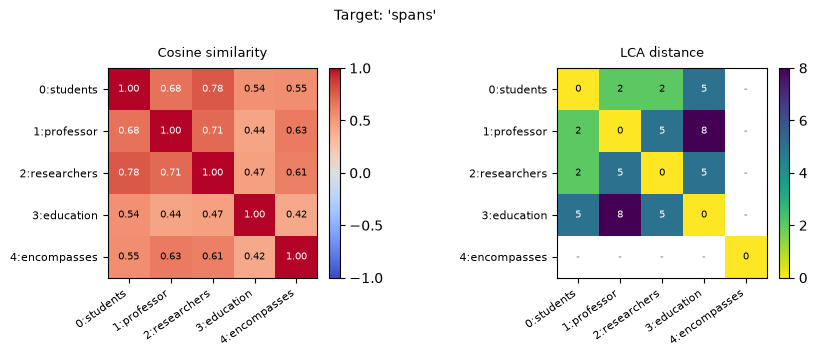


Context: 'Computer science spans theoretical' | Target: 'disciplines'
Top-5           |   0:foundations |       1:studies |      2:concepts |      3:computer |        4:fields
---------------------------------------------------------------------------------------------------------
0:foundations   |          1.0000 |          0.8443 |          0.8522 |          0.6683 |          0.7649
1:studies       |          0.8443 |          1.0000 |          0.8046 |          0.6717 |          0.7392
2:concepts      |          0.8522 |          0.8046 |          1.0000 |          0.6786 |          0.7961
3:computer      |          0.6683 |          0.6717 |          0.6786 |          1.0000 |          0.6343
4:fields        |          0.7649 |          0.7392 |          0.7961 |          0.6343 |          1.0000


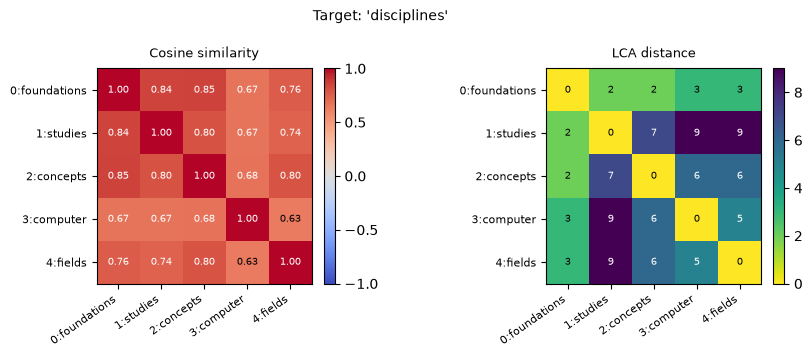


Context: 'Computer science spans theoretical disciplines (such as' | Target: 'algorithms,'
Top-5           |    0:algorithms |        1:comput |        2:theory |     3:algorithm |   4:computation
---------------------------------------------------------------------------------------------------------
0:algorithms    |          1.0000 |          0.5552 |          0.7124 |          0.8656 |          0.7581
1:comput        |          0.5552 |          1.0000 |          0.6013 |          0.5964 |          0.5933
2:theory        |          0.7124 |          0.6013 |          1.0000 |          0.6641 |          0.7070
3:algorithm     |          0.8656 |          0.5964 |          0.6641 |          1.0000 |          0.7071
4:computation   |          0.7581 |          0.5933 |          0.7070 |          0.7071 |          1.0000


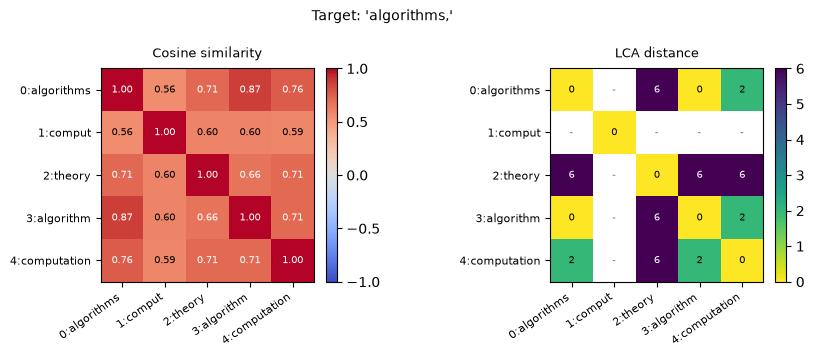


Context: 'Computer science spans theoretical disciplines (such as algorithms,' | Target: 'theory'
Top-5           |        0:theory |          1:data |   2:computation |    3:complexity |        4:comput
---------------------------------------------------------------------------------------------------------
0:theory        |          1.0000 |          0.5517 |          0.7070 |          0.8161 |          0.6013
1:data          |          0.5517 |          1.0000 |          0.6609 |          0.5230 |          0.5114
2:computation   |          0.7070 |          0.6609 |          1.0000 |          0.7026 |          0.5933
3:complexity    |          0.8161 |          0.5230 |          0.7026 |          1.0000 |          0.6467
4:comput        |          0.6013 |          0.5114 |          0.5933 |          0.6467 |          1.0000


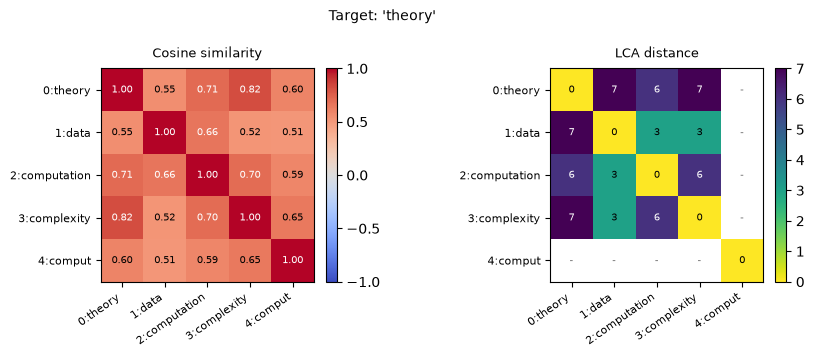


Context: 'Computer science spans theoretical disciplines (such as algorithms, theory of' | Target: 'computation,'
Top-5            |    0:computation |      1:computing |         2:comput |   3:computations |            4:com
---------------------------------------------------------------------------------------------------------------
0:computation    |           1.0000 |           0.8199 |           0.5933 |           0.7876 |           0.4770
1:computing      |           0.8199 |           1.0000 |           0.5968 |           0.6057 |           0.5147
2:comput         |           0.5933 |           0.5968 |           1.0000 |           0.5950 |           0.5592
3:computations   |           0.7876 |           0.6057 |           0.5950 |           1.0000 |           0.3955
4:com            |           0.4770 |           0.5147 |           0.5592 |           0.3955 |           1.0000


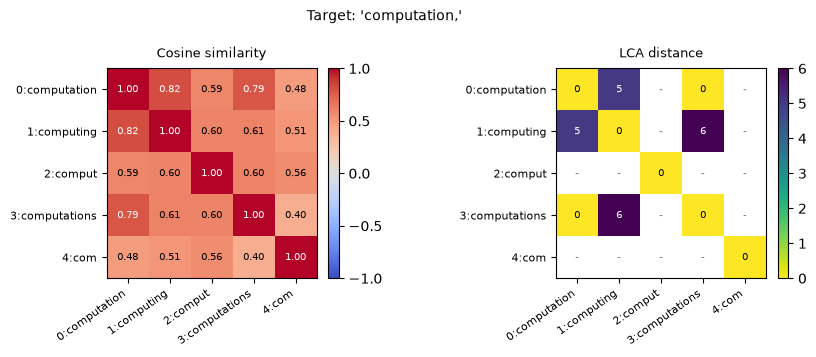


Context: 'Computer science spans theoretical disciplines (such as algorithms, theory of computation, and' | Target: 'information'
Top-5           |   0:information |        1:comput |   2:computation |     3:semantics |           4:sem
---------------------------------------------------------------------------------------------------------
0:information   |          1.0000 |          0.3857 |          0.6272 |          0.4271 |          0.4227
1:comput        |          0.3857 |          1.0000 |          0.5933 |          0.6285 |          0.6519
2:computation   |          0.6272 |          0.5933 |          1.0000 |          0.7031 |          0.5438
3:semantics     |          0.4271 |          0.6285 |          0.7031 |          1.0000 |          0.5419
4:sem           |          0.4227 |          0.6519 |          0.5438 |          0.5419 |          1.0000


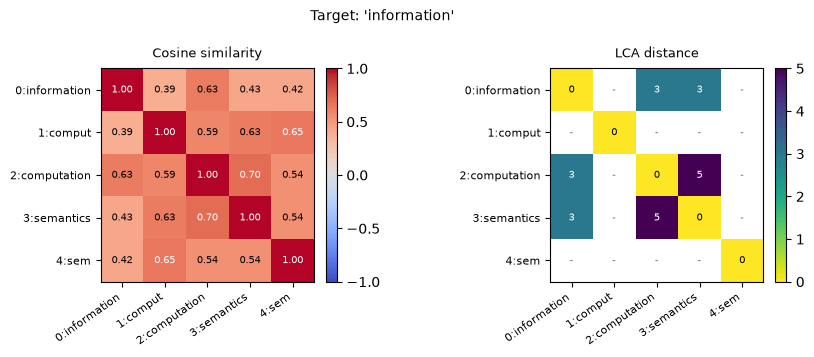


Context: 'Computer science spans theoretical disciplines (such as algorithms, theory of computation, and information' | Target: 'theory)'
Top-5           |        0:theory |             1:论 |   2:engineering |       3:systems |       4:science
---------------------------------------------------------------------------------------------------------
0:theory        |          1.0000 |          0.5630 |          0.7342 |          0.7543 |          0.6707
1:论             |          0.5630 |          1.0000 |          0.4514 |          0.4075 |          0.4259
2:engineering   |          0.7342 |          0.4514 |          1.0000 |          0.7353 |          0.7074
3:systems       |          0.7543 |          0.4075 |          0.7353 |          1.0000 |          0.5906
4:science       |          0.6707 |          0.4259 |          0.7074 |          0.5906 |          1.0000


/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 35770 (\N{CJK UNIFIED IDEOGRAPH-8BBA}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 35770 (\N{CJK UNIFIED IDEOGRAPH-8BBA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


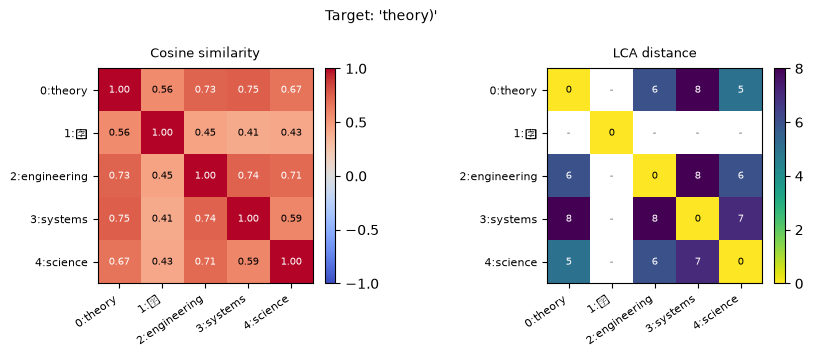


Context: 'Computer science spans theoretical disciplines (such as algorithms, theory of computation, and information theory) to applied' | Target: 'disciplines'
Top-5           |   0:disciplines |          1:ones |         2:areas |   3:engineering |     4:computing
---------------------------------------------------------------------------------------------------------
0:disciplines   |          1.0000 |          0.6153 |          0.6786 |          0.5421 |          0.5551
1:ones          |          0.6153 |          1.0000 |          0.7847 |          0.5324 |          0.5955
2:areas         |          0.6786 |          0.7847 |          1.0000 |          0.5809 |          0.6705
3:engineering   |          0.5421 |          0.5324 |          0.5809 |          1.0000 |          0.6985
4:computing     |          0.5551 |          0.5955 |          0.6705 |          0.6985 |          1.0000


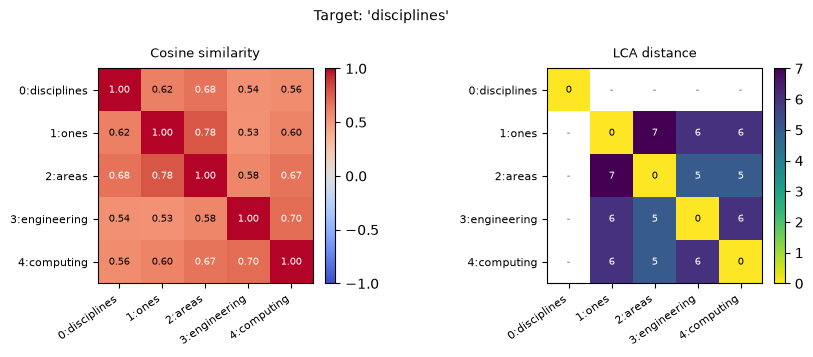


Context: 'Computer science spans theoretical disciplines (such as algorithms, theory of computation, and information theory) to applied disciplines' | Target: '(including'
Top-5         |   0:including |   1:involving |      2:within |    3:focusing |    4:relating
---------------------------------------------------------------------------------------------
0:including   |        1.0000 |        0.7961 |        0.7615 |        0.6939 |        0.7382
1:involving   |        0.7961 |        1.0000 |        0.8548 |        0.7662 |        0.8785
2:within      |        0.7615 |        0.8548 |        1.0000 |        0.8115 |        0.8226
3:focusing    |        0.6939 |        0.7662 |        0.8115 |        1.0000 |        0.7832
4:relating    |        0.7382 |        0.8785 |        0.8226 |        0.7832 |        1.0000


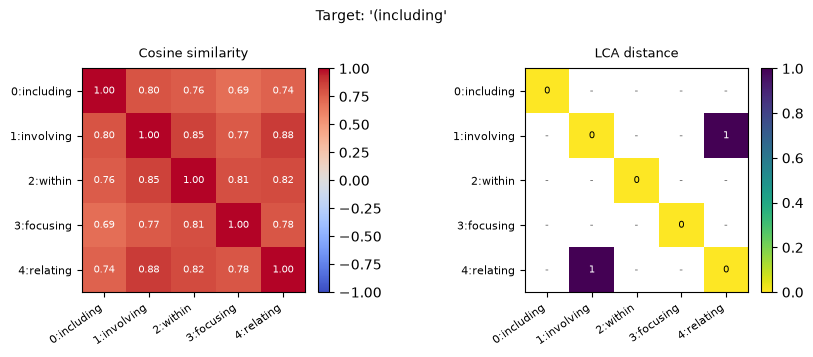


Context: 'Computer science spans theoretical disciplines (such as algorithms, theory of computation, and information theory) to applied disciplines (including the' | Target: 'design'
Top-5            |         0:design |    1:development |       2:computer |          3:study |   4:construction
---------------------------------------------------------------------------------------------------------------
0:design         |           1.0000 |           0.7993 |           0.7145 |           0.7792 |           0.5352
1:development    |           0.7993 |           1.0000 |           0.6394 |           0.6300 |           0.6681
2:computer       |           0.7145 |           0.6394 |           1.0000 |           0.6340 |           0.4539
3:study          |           0.7792 |           0.6300 |           0.6340 |           1.0000 |           0.3951
4:construction   |           0.5352 |           0.6681 |           0.4539 |           0.3951 |           1.0000


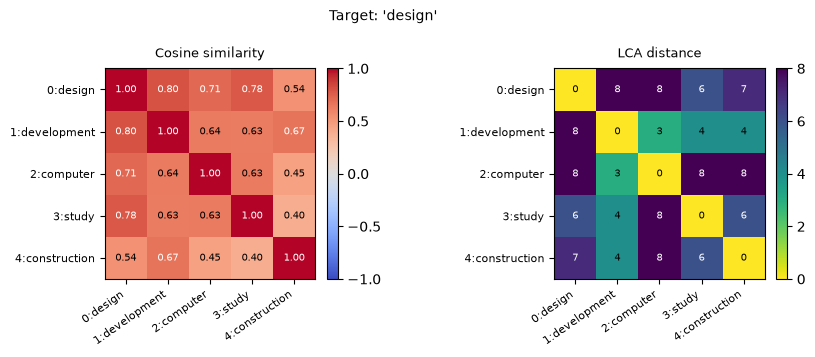


Context: 'Computer science spans theoretical disciplines (such as algorithms, theory of computation, and information theory) to applied disciplines (including the design and' | Target: 'implementation'
Top-5              |   0:implementation |         1:analysis |     2:construction |      3:engineering |      4:development
---------------------------------------------------------------------------------------------------------------------------
0:implementation   |             1.0000 |             0.7751 |             0.4836 |             0.6164 |             0.7626
1:analysis         |             0.7751 |             1.0000 |             0.5231 |             0.7326 |             0.7564
2:construction     |             0.4836 |             0.5231 |             1.0000 |             0.5577 |             0.6681
3:engineering      |             0.6164 |             0.7326 |             0.5577 |             1.0000 |             0.6944
4:development      |             0.7626 |            

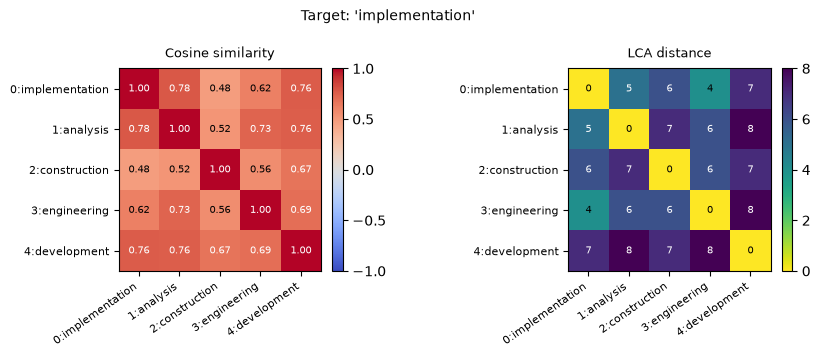


Context: 'Computer science spans theoretical disciplines (such as algorithms, theory of computation, and information theory) to applied disciplines (including the design and implementation of' | Target: 'hardware'
Top-5         |    0:software |    1:hardware |    2:computer |   3:computing |     4:complex
---------------------------------------------------------------------------------------------
0:software    |        1.0000 |        0.5737 |        0.7751 |        0.7413 |        0.6440
1:hardware    |        0.5737 |        1.0000 |        0.5925 |        0.5827 |        0.4288
2:computer    |        0.7751 |        0.5925 |        1.0000 |        0.7759 |        0.5878
3:computing   |        0.7413 |        0.5827 |        0.7759 |        1.0000 |        0.6295
4:complex     |        0.6440 |        0.4288 |        0.5878 |        0.6295 |        1.0000


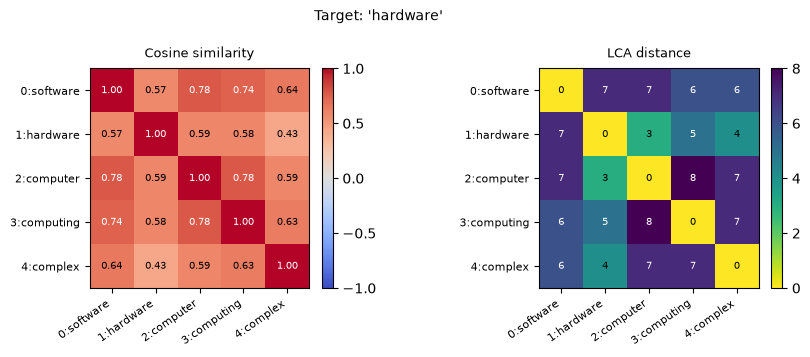


Context: 'Computer science spans theoretical disciplines (such as algorithms, theory of computation, and information theory) to applied disciplines (including the design and implementation of hardware and' | Target: 'software).'
Top-5        |   0:software |         1:软件 |   2:computer |    3:systems |   4:firmware
---------------------------------------------------------------------------------------
0:software   |       1.0000 |       0.5008 |       0.7751 |       0.7596 |       0.6213
1:软件         |       0.5008 |       1.0000 |       0.4704 |       0.3636 |       0.4417
2:computer   |       0.7751 |       0.4704 |       1.0000 |       0.7037 |       0.6127
3:systems    |       0.7596 |       0.3636 |       0.7037 |       1.0000 |       0.4958
4:firmware   |       0.6213 |       0.4417 |       0.6127 |       0.4958 |       1.0000


/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 36719 (\N{CJK UNIFIED IDEOGRAPH-8F6F}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 20214 (\N{CJK UNIFIED IDEOGRAPH-4EF6}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 36719 (\N{CJK UNIFIED IDEOGRAPH-8F6F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 20214 (\N{CJK UNIFIED IDEOGRAPH-4EF6}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


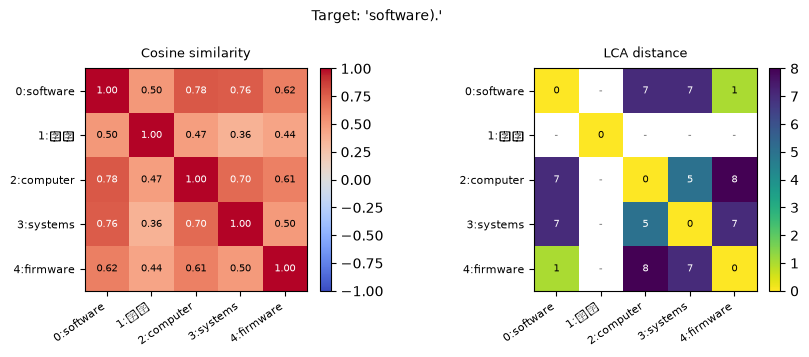

Block 2: Computer science spans theoretical disciplines (such as algorithms, theory of computation, and information theory) to applied disciplines (including the design and implementation of hardware and software).


Context: 'Computer' | Target: 'science'
Top-5        |    0:science |   1:software |   2:graphics |     3:vision |     4:memory
---------------------------------------------------------------------------------------
0:science    |       1.0000 |       0.5609 |       0.5013 |       0.5255 |       0.5749
1:software   |       0.5609 |       1.0000 |       0.6474 |       0.6912 |       0.6670
2:graphics   |       0.5013 |       0.6474 |       1.0000 |       0.5171 |       0.5423
3:vision     |       0.5255 |       0.6912 |       0.5171 |       1.0000 |       0.8018
4:memory     |       0.5749 |       0.6670 |       0.5423 |       0.8018 |       1.0000


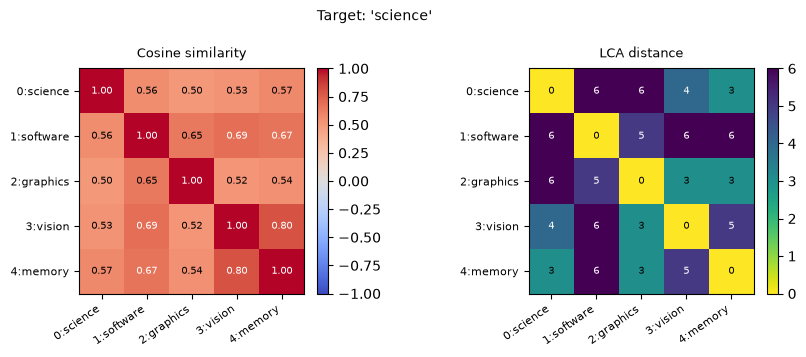


Context: 'Computer science is' | Target: 'generally'
Top-5            |          0:often |     1:everywhere |   2:increasingly |        3:rapidly |          4:among
---------------------------------------------------------------------------------------------------------------
0:often          |           1.0000 |           0.6827 |           0.8376 |           0.7918 |           0.7483
1:everywhere     |           0.6827 |           1.0000 |           0.7018 |           0.6756 |           0.5731
2:increasingly   |           0.8376 |           0.7018 |           1.0000 |           0.8715 |           0.6989
3:rapidly        |           0.7918 |           0.6756 |           0.8715 |           1.0000 |           0.6533
4:among          |           0.7483 |           0.5731 |           0.6989 |           0.6533 |           1.0000


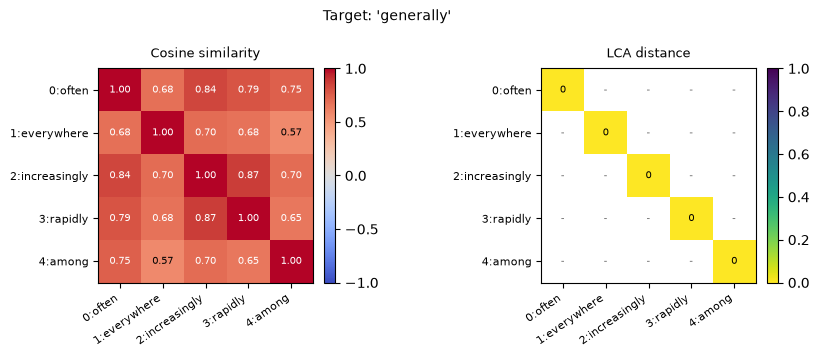


Context: 'Computer science is generally considered an' | Target: 'area'
Top-5           |   0:engineering |      1:academic |     2:extremely |      3:abstract |          4:area
---------------------------------------------------------------------------------------------------------
0:engineering   |          1.0000 |          0.6106 |          0.4995 |          0.5943 |          0.5556
1:academic      |          0.6106 |          1.0000 |          0.5529 |          0.5969 |          0.6008
2:extremely     |          0.4995 |          0.5529 |          1.0000 |          0.6001 |          0.6932
3:abstract      |          0.5943 |          0.5969 |          0.6001 |          1.0000 |          0.5883
4:area          |          0.5556 |          0.6008 |          0.6932 |          0.5883 |          1.0000


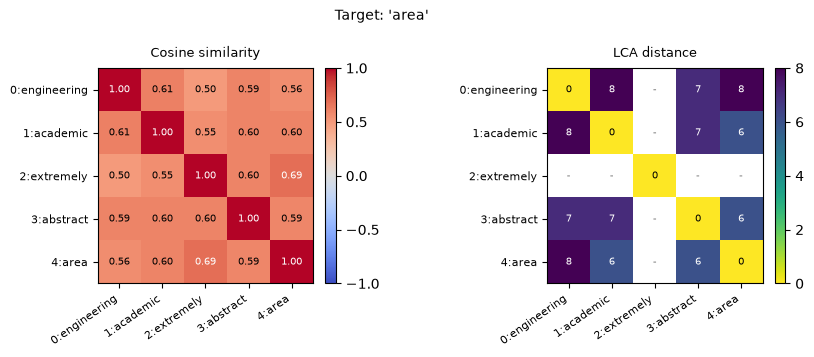


Context: 'Computer science is generally considered an area of' | Target: 'academic'
Top-5           |         0:study |       1:science |   2:engineering |   3:mathematics |     4:expertise
---------------------------------------------------------------------------------------------------------
0:study         |          1.0000 |          0.5834 |          0.5616 |          0.4277 |          0.7600
1:science       |          0.5834 |          1.0000 |          0.7074 |          0.5182 |          0.5720
2:engineering   |          0.5616 |          0.7074 |          1.0000 |          0.6446 |          0.5972
3:mathematics   |          0.4277 |          0.5182 |          0.6446 |          1.0000 |          0.4803
4:expertise     |          0.7600 |          0.5720 |          0.5972 |          0.4803 |          1.0000


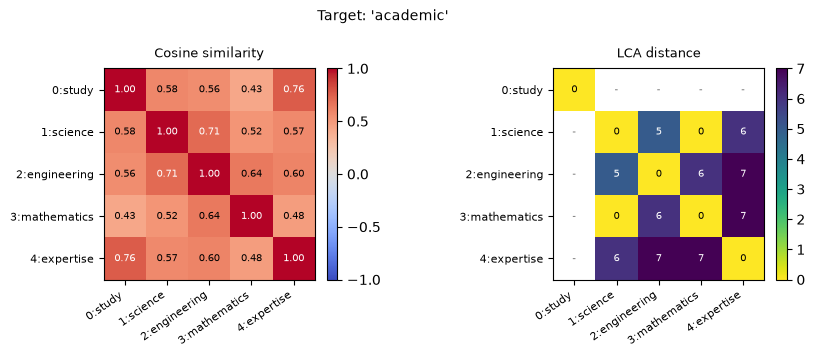


Context: 'Computer science is generally considered an area of academic' | Target: 'research'
Top-5              |            0:study |         1:research |   2:specialization |         3:interest |          4:inquiry
---------------------------------------------------------------------------------------------------------------------------
0:study            |             1.0000 |             0.6752 |             0.6738 |             0.7773 |             0.7528
1:research         |             0.6752 |             1.0000 |             0.6963 |             0.6715 |             0.7151
2:specialization   |             0.6738 |             0.6963 |             1.0000 |             0.7981 |             0.7452
3:interest         |             0.7773 |             0.6715 |             0.7981 |             1.0000 |             0.8196
4:inquiry          |             0.7528 |             0.7151 |             0.7452 |             0.8196 |             1.0000


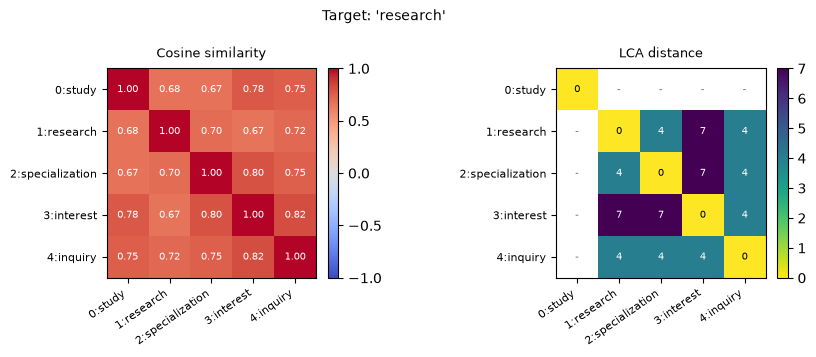


Context: 'Computer science is generally considered an area of academic research and distinct from' | Target: 'computer'
Top-5           |      0:software |      1:computer |   2:information |   3:engineering |   4:programming
---------------------------------------------------------------------------------------------------------
0:software      |          1.0000 |          0.7751 |          0.5389 |          0.6742 |          0.7857
1:computer      |          0.7751 |          1.0000 |          0.5066 |          0.6942 |          0.6973
2:information   |          0.5389 |          0.5066 |          1.0000 |          0.5409 |          0.6240
3:engineering   |          0.6742 |          0.6942 |          0.5409 |          1.0000 |          0.7363
4:programming   |          0.7857 |          0.6973 |          0.6240 |          0.7363 |          1.0000


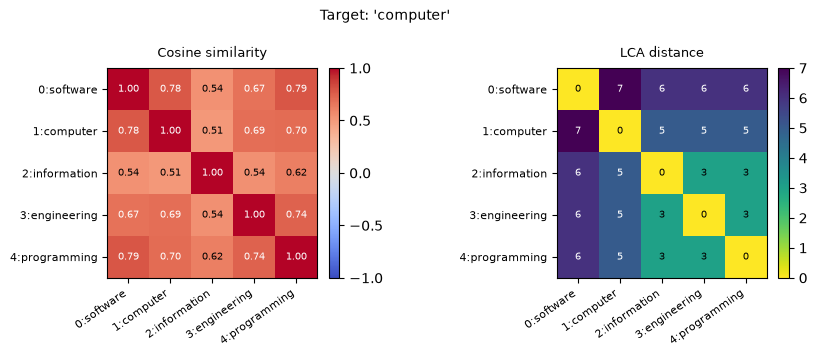


Context: 'Computer science is generally considered an area of academic research and distinct from computer' | Target: 'programming.'
Top-5           |   0:engineering |   1:programming |    2:technology |       3:science |      4:literacy
---------------------------------------------------------------------------------------------------------
0:engineering   |          1.0000 |          0.7363 |          0.8057 |          0.7074 |          0.5570
1:programming   |          0.7363 |          1.0000 |          0.7233 |          0.6154 |          0.5001
2:technology    |          0.8057 |          0.7233 |          1.0000 |          0.6116 |          0.5920
3:science       |          0.7074 |          0.6154 |          0.6116 |          1.0000 |          0.4874
4:literacy      |          0.5570 |          0.5001 |          0.5920 |          0.4874 |          1.0000


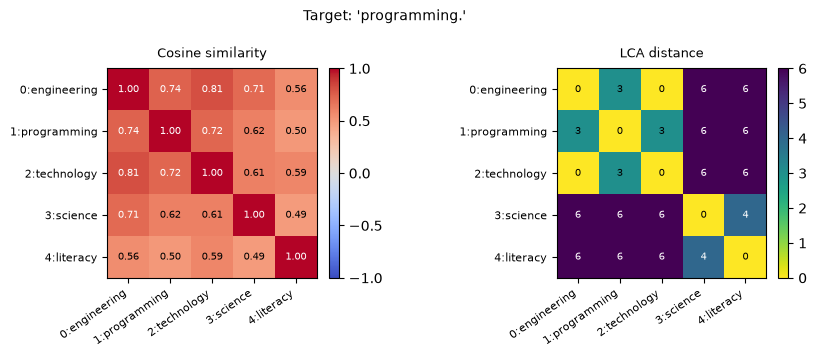

Block 3: Computer science is generally considered an area of academic research and distinct from computer programming.

{'block1': [6, 8, 8, 10, 10], 'block2': [6, 8, 9, 6, 7, 6, 5, 8, 7, 1, 8, 8, 8, 8], 'block3': [6, None, 8, 7, 7, 7, 6]}


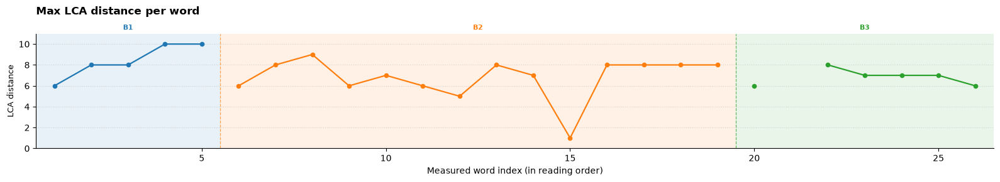

In [30]:
with open('./texts_data/factual_wiki_computer_science.txt', 'r') as file:
    content = file.read()
    print(content)
    print("\n")
    context_blocks, blocks_max_distances = analyze_semantic_with_context_segments(
        content,
        tokenizer = tokenizer_7b,
        model = model_7b,
        with_bert=True,
        bert_tokenizer=bert_tokenizer_7b,
        bert_model=bert_model_7b,
        print_results=True)

print(blocks_max_distances)
fig = plot_lca_curve(blocks_max_distances, title="Max LCA distance per word")
fig.tight_layout()
plt.show()
plt.close(fig)




Context: 'It' | Target: 'felt'
Top-5        |    0:takes |     1:took |    2:seems |    3:looks |    4:makes
-----------------------------------------------------------------------------
0:takes      |     1.0000 |     0.8302 |     0.6651 |     0.6800 |     0.8116
1:took       |     0.8302 |     1.0000 |     0.6684 |     0.7129 |     0.7483
2:seems      |     0.6651 |     0.6684 |     1.0000 |     0.8092 |     0.7510
3:looks      |     0.6800 |     0.7129 |     0.8092 |     1.0000 |     0.7770
4:makes      |     0.8116 |     0.7483 |     0.7510 |     0.7770 |     1.0000


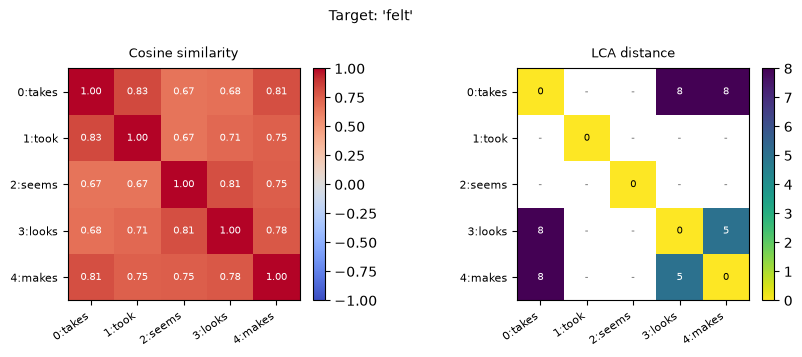


Context: 'It felt as' | Target: 'though'
Top-5        |    0:though |      1:good |   2:natural |      3:cold |   4:thought
----------------------------------------------------------------------------------
0:though     |      1.0000 |      0.4988 |      0.5992 |      0.6011 |      0.5476
1:good       |      0.4988 |      1.0000 |      0.5632 |      0.5979 |      0.4818
2:natural    |      0.5992 |      0.5632 |      1.0000 |      0.6214 |      0.6154
3:cold       |      0.6011 |      0.5979 |      0.6214 |      1.0000 |      0.6109
4:thought    |      0.5476 |      0.4818 |      0.6154 |      0.6109 |      1.0000


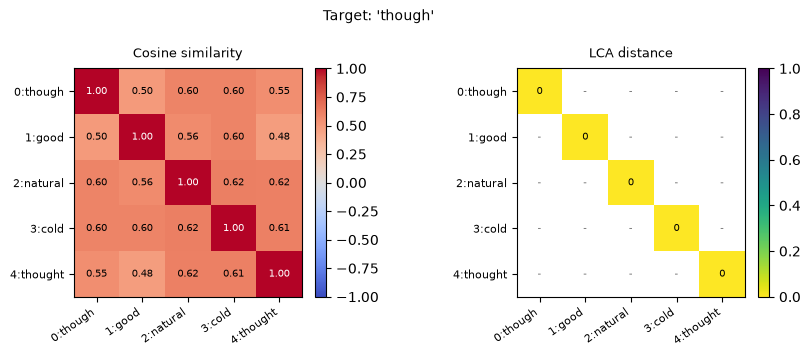


Context: 'It felt as though his' | Target: 'arm'
Top-5        |    0:heart |     1:body |     2:eyes |    3:whole |     4:life
-----------------------------------------------------------------------------
0:heart      |     1.0000 |     0.7181 |     0.6251 |     0.5083 |     0.6114
1:body       |     0.7181 |     1.0000 |     0.6708 |     0.5896 |     0.6896
2:eyes       |     0.6251 |     0.6708 |     1.0000 |     0.6147 |     0.6264
3:whole      |     0.5083 |     0.5896 |     0.6147 |     1.0000 |     0.5740
4:life       |     0.6114 |     0.6896 |     0.6264 |     0.5740 |     1.0000


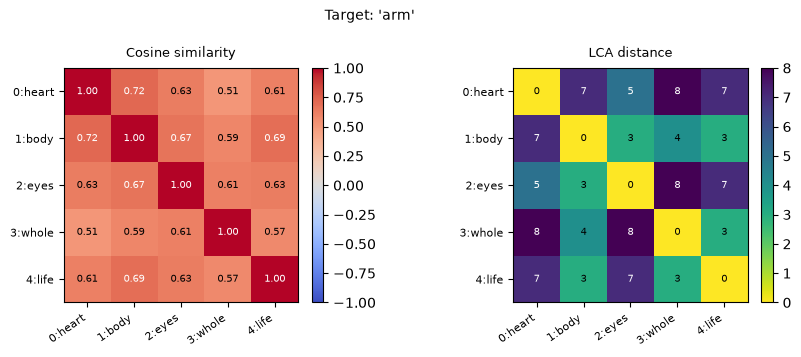


Context: 'He' | Target: 'didn’t'
Top-5        |       0:al |     1:took |     2:aven |    3:wrote |     4:isen
-----------------------------------------------------------------------------
0:al         |     1.0000 |     0.6038 |     0.5057 |     0.6844 |     0.4871
1:took       |     0.6038 |     1.0000 |     0.6218 |     0.7256 |     0.5555
2:aven       |     0.5057 |     0.6218 |     1.0000 |     0.5338 |     0.6020
3:wrote      |     0.6844 |     0.7256 |     0.5338 |     1.0000 |     0.5233
4:isen       |     0.4871 |     0.5555 |     0.6020 |     0.5233 |     1.0000


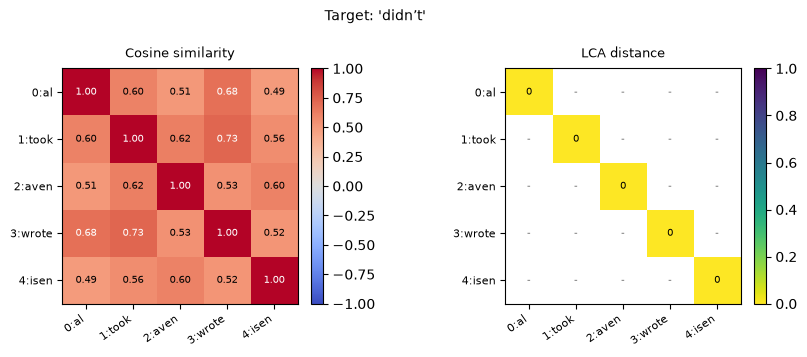


Context: 'He didn’t' | Target: 'dare'
Top-5        |      0:know |      1:want |      2:tell |      3:feel |   4:realize
----------------------------------------------------------------------------------
0:know       |      1.0000 |      0.7659 |      0.7425 |      0.7788 |      0.7489
1:want       |      0.7659 |      1.0000 |      0.7581 |      0.7578 |      0.6913
2:tell       |      0.7425 |      0.7581 |      1.0000 |      0.7106 |      0.6937
3:feel       |      0.7788 |      0.7578 |      0.7106 |      1.0000 |      0.6651
4:realize    |      0.7489 |      0.6913 |      0.6937 |      0.6651 |      1.0000


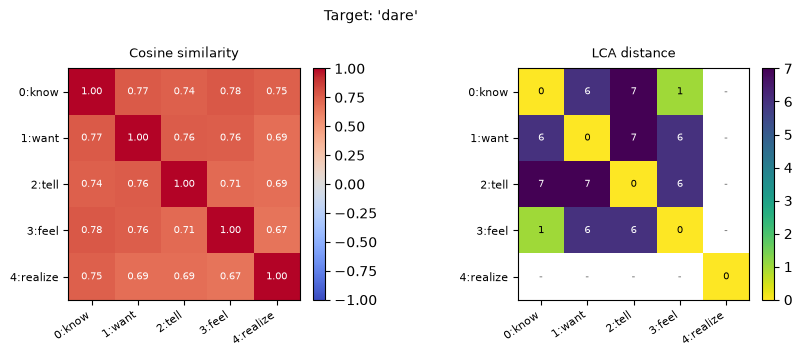


Context: 'He didn’t dare' | Target: 'look'
Top-5        |     0:look |     1:tell |    2:speak |     3:open |     4:walk
-----------------------------------------------------------------------------
0:look       |     1.0000 |     0.7375 |     0.7566 |     0.6330 |     0.8122
1:tell       |     0.7375 |     1.0000 |     0.7323 |     0.6158 |     0.7126
2:speak      |     0.7566 |     0.7323 |     1.0000 |     0.6244 |     0.8011
3:open       |     0.6330 |     0.6158 |     0.6244 |     1.0000 |     0.6005
4:walk       |     0.8122 |     0.7126 |     0.8011 |     0.6005 |     1.0000


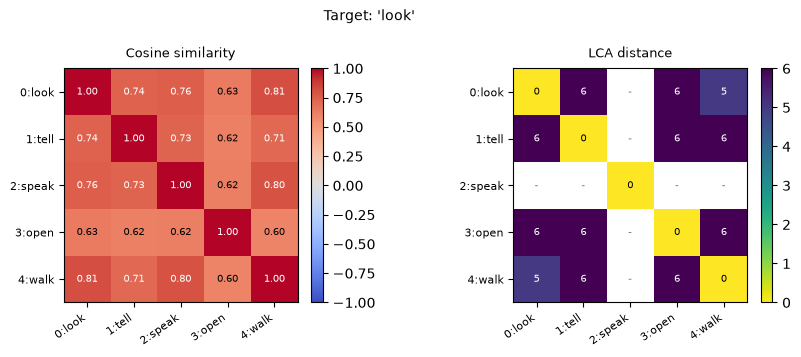


Context: 'He didn’t dare look at what was' | Target: 'happening.'
Top-5         |      0:inside |        1:left |      2:behind |   3:happening |       4:lying
---------------------------------------------------------------------------------------------
0:inside      |        1.0000 |        0.4763 |        0.6500 |        0.5364 |        0.5430
1:left        |        0.4763 |        1.0000 |        0.5451 |        0.6035 |        0.5016
2:behind      |        0.6500 |        0.5451 |        1.0000 |        0.6484 |        0.6269
3:happening   |        0.5364 |        0.6035 |        0.6484 |        1.0000 |        0.6296
4:lying       |        0.5430 |        0.5016 |        0.6269 |        0.6296 |        1.0000


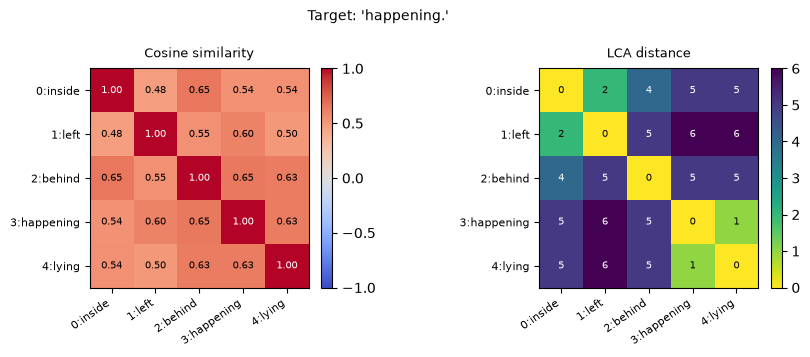


Context: 'He had' | Target: 'shut'
Top-5        |     0:never |   1:already |    2:always |    3:worked |   4:trouble
----------------------------------------------------------------------------------
0:never      |      1.0000 |      0.6469 |      0.8476 |      0.6767 |      0.7864
1:already    |      0.6469 |      1.0000 |      0.6682 |      0.5495 |      0.6119
2:always     |      0.8476 |      0.6682 |      1.0000 |      0.6475 |      0.7798
3:worked     |      0.6767 |      0.5495 |      0.6475 |      1.0000 |      0.7155
4:trouble    |      0.7864 |      0.6119 |      0.7798 |      0.7155 |      1.0000


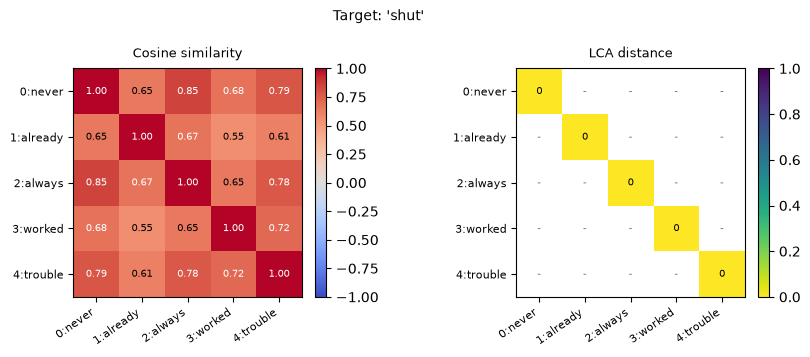


Context: 'He had shut his' | Target: 'eyes,'
Top-5        |      0:eyes |      1:door |   2:bedroom |      3:mind |      4:shop
----------------------------------------------------------------------------------
0:eyes       |      1.0000 |      0.7014 |      0.7678 |      0.6403 |      0.7488
1:door       |      0.7014 |      1.0000 |      0.7623 |      0.5881 |      0.7105
2:bedroom    |      0.7678 |      0.7623 |      1.0000 |      0.6257 |      0.7377
3:mind       |      0.6403 |      0.5881 |      0.6257 |      1.0000 |      0.5892
4:shop       |      0.7488 |      0.7105 |      0.7377 |      0.5892 |      1.0000


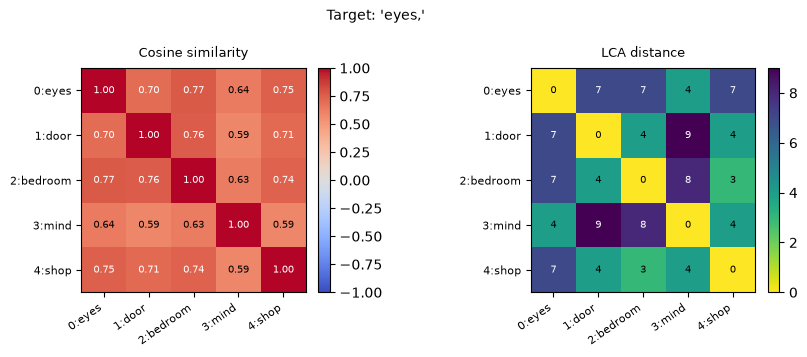


Context: 'He had shut his eyes, his' | Target: 'face'
Top-5         |        0:face |        1:body |        2:head |   3:breathing |        4:last
---------------------------------------------------------------------------------------------
0:face        |        1.0000 |        0.7632 |        0.7801 |        0.6080 |        0.7249
1:body        |        0.7632 |        1.0000 |        0.7401 |        0.6515 |        0.6385
2:head        |        0.7801 |        0.7401 |        1.0000 |        0.5272 |        0.6751
3:breathing   |        0.6080 |        0.6515 |        0.5272 |        1.0000 |        0.5648
4:last        |        0.7249 |        0.6385 |        0.6751 |        0.5648 |        1.0000


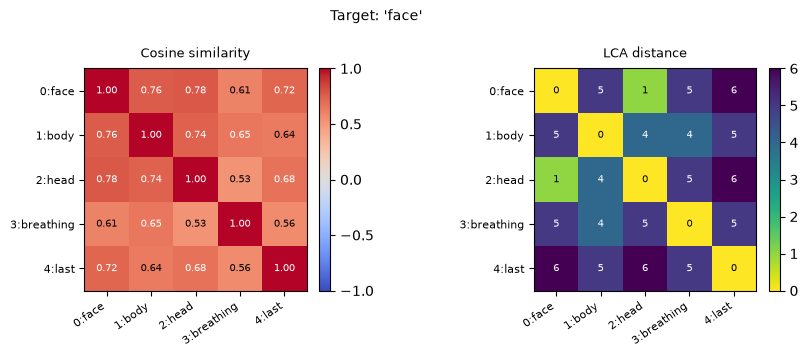


Context: 'He had shut his eyes, his face turned away from his' | Target: 'arm,'
Top-5         |   0:companion |        1:wife |      2:father |      3:mother |     4:brother
---------------------------------------------------------------------------------------------
0:companion   |        1.0000 |        0.6189 |        0.5586 |        0.5856 |        0.6102
1:wife        |        0.6189 |        1.0000 |        0.8083 |        0.8203 |        0.8223
2:father      |        0.5586 |        0.8083 |        1.0000 |        0.9228 |        0.8733
3:mother      |        0.5856 |        0.8203 |        0.9228 |        1.0000 |        0.8438
4:brother     |        0.6102 |        0.8223 |        0.8733 |        0.8438 |        1.0000


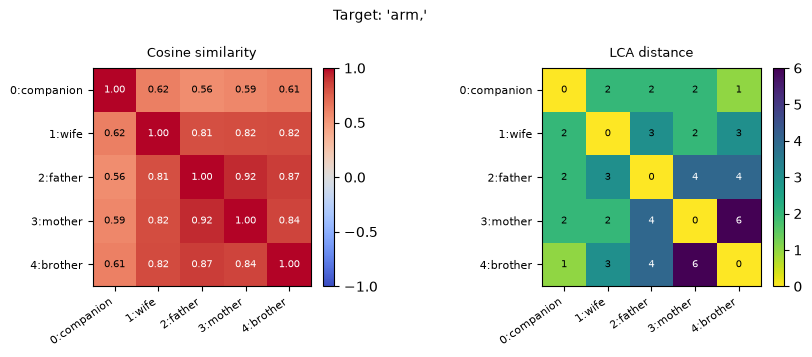


Context: 'He had shut his eyes, his face turned away from his arm, but his' | Target: 'worst'
Top-5        |     0:body |     1:hand |     2:head |     3:eyes |      4:arm
-----------------------------------------------------------------------------
0:body       |     1.0000 |     0.7126 |     0.7401 |     0.6708 |     0.7037
1:hand       |     0.7126 |     1.0000 |     0.6788 |     0.7355 |     0.7849
2:head       |     0.7401 |     0.6788 |     1.0000 |     0.7277 |     0.6429
3:eyes       |     0.6708 |     0.7355 |     0.7277 |     1.0000 |     0.6204
4:arm        |     0.7037 |     0.7849 |     0.6429 |     0.6204 |     1.0000


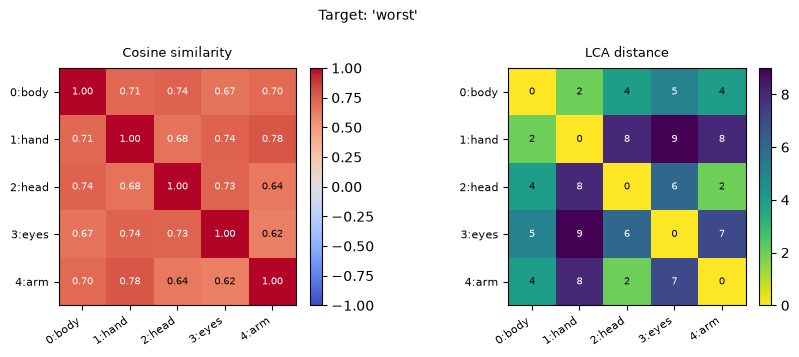


Context: 'He had shut his eyes, his face turned away from his arm, but his worst' | Target: 'fears'
Top-5          |        0:fears |         1:fear |    2:nightmare |   3:nightmares |   4:suspicions
---------------------------------------------------------------------------------------------------
0:fears        |         1.0000 |         0.7397 |         0.8296 |         0.8603 |         0.8774
1:fear         |         0.7397 |         1.0000 |         0.6724 |         0.7174 |         0.6182
2:nightmare    |         0.8296 |         0.6724 |         1.0000 |         0.8951 |         0.8228
3:nightmares   |         0.8603 |         0.7174 |         0.8951 |         1.0000 |         0.8321
4:suspicions   |         0.8774 |         0.6182 |         0.8228 |         0.8321 |         1.0000


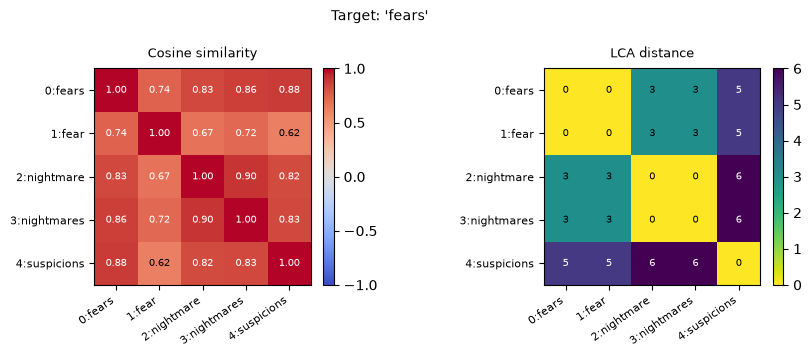


Context: 'He had shut his eyes, his face turned away from his arm, but his worst fears were realized as the' | Target: 'people'
Top-5        |    0:blood |   1:doctor |      2:man |    3:nurse |    4:sound
-----------------------------------------------------------------------------
0:blood      |     1.0000 |     0.5393 |     0.5328 |     0.5006 |     0.5234
1:doctor     |     0.5393 |     1.0000 |     0.7385 |     0.7900 |     0.6433
2:man        |     0.5328 |     0.7385 |     1.0000 |     0.6511 |     0.7612
3:nurse      |     0.5006 |     0.7900 |     0.6511 |     1.0000 |     0.6163
4:sound      |     0.5234 |     0.6433 |     0.7612 |     0.6163 |     1.0000


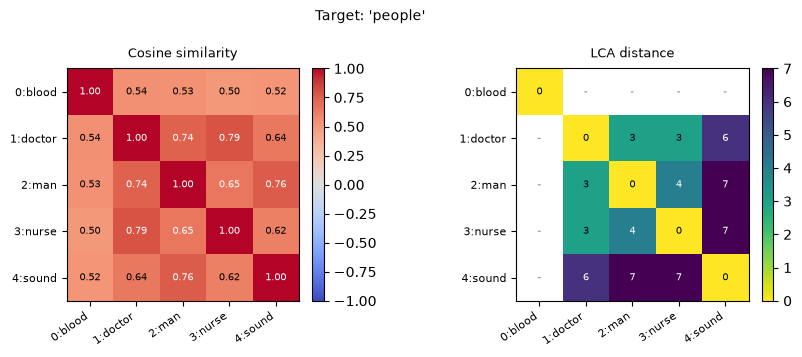


Context: 'He had shut his eyes, his face turned away from his arm, but his worst fears were realized as the people above him' | Target: 'gasped'
Top-5        |      0:began |   1:screamed |    2:laughed |    3:started |        4:gas
---------------------------------------------------------------------------------------
0:began      |       1.0000 |       0.5519 |       0.6327 |       0.8759 |       0.5720
1:screamed   |       0.5519 |       1.0000 |       0.6639 |       0.5297 |       0.4306
2:laughed    |       0.6327 |       0.6639 |       1.0000 |       0.6541 |       0.5480
3:started    |       0.8759 |       0.5297 |       0.6541 |       1.0000 |       0.6122
4:gas        |       0.5720 |       0.4306 |       0.5480 |       0.6122 |       1.0000


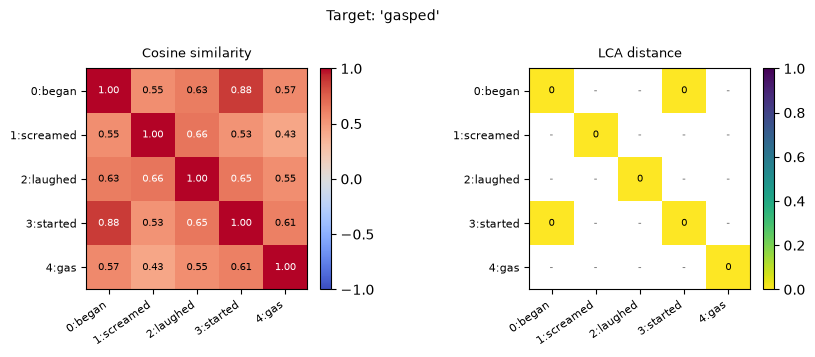


Context: 'He had shut his eyes, his face turned away from his arm, but his worst fears were realized as the people above him gasped and' | Target: 'Colin'
Top-5        |   0:screamed |       1:shri |      2:began |       3:fell |      4:cried
---------------------------------------------------------------------------------------
0:screamed   |       1.0000 |       0.3789 |       0.5519 |       0.5419 |       0.7459
1:shri       |       0.3789 |       1.0000 |       0.5037 |       0.5384 |       0.4905
2:began      |       0.5519 |       0.5037 |       1.0000 |       0.7984 |       0.6919
3:fell       |       0.5419 |       0.5384 |       0.7984 |       1.0000 |       0.7244
4:cried      |       0.7459 |       0.4905 |       0.6919 |       0.7244 |       1.0000


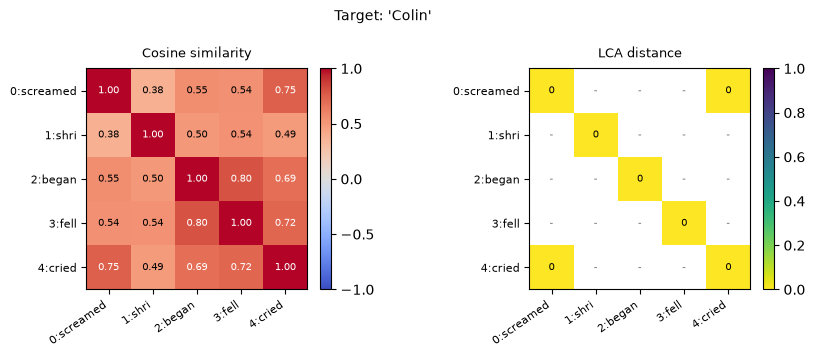


Context: 'He had shut his eyes, his face turned away from his arm, but his worst fears were realized as the people above him gasped and Colin' | Target: 'Creevey'
Top-5        |       0:felt |        1:gas |     2:looked |   3:screamed |        4:let
---------------------------------------------------------------------------------------
0:felt       |       1.0000 |       0.6171 |       0.8613 |       0.5210 |       0.5548
1:gas        |       0.6171 |       1.0000 |       0.6408 |       0.4306 |       0.5645
2:looked     |       0.8613 |       0.6408 |       1.0000 |       0.5367 |       0.6226
3:screamed   |       0.5210 |       0.4306 |       0.5367 |       1.0000 |       0.3774
4:let        |       0.5548 |       0.5645 |       0.6226 |       0.3774 |       1.0000


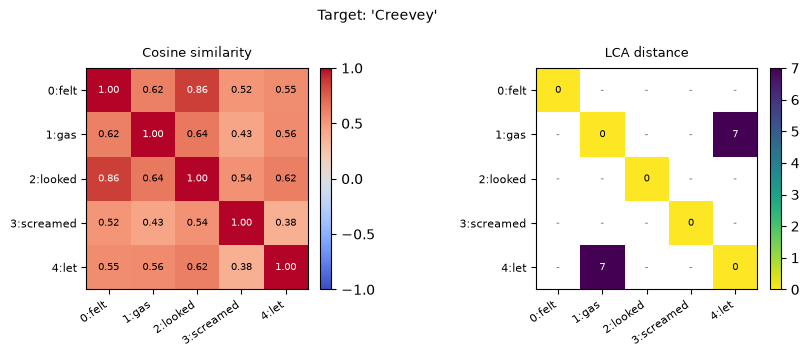


Context: 'He had shut his eyes, his face turned away from his arm, but his worst fears were realized as the people above him gasped and Colin Creevey' | Target: 'began'
Top-5        |   0:screamed |       1:fell |        2:let |        3:gas |     4:looked
---------------------------------------------------------------------------------------
0:screamed   |       1.0000 |       0.5419 |       0.3774 |       0.4306 |       0.5367
1:fell       |       0.5419 |       1.0000 |       0.6044 |       0.6750 |       0.7999
2:let        |       0.3774 |       0.6044 |       1.0000 |       0.5645 |       0.6226
3:gas        |       0.4306 |       0.6750 |       0.5645 |       1.0000 |       0.6408
4:looked     |       0.5367 |       0.7999 |       0.6226 |       0.6408 |       1.0000


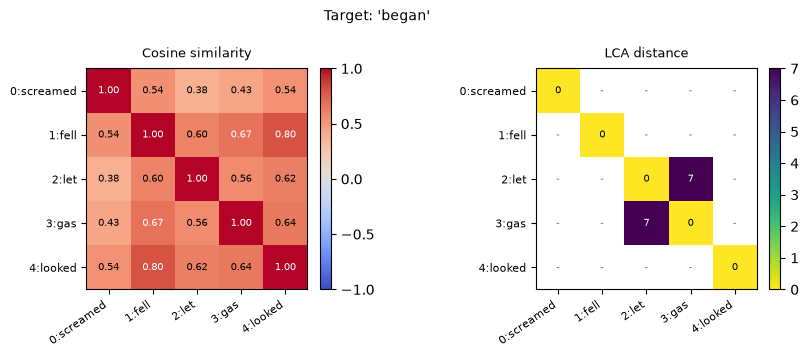


Context: 'He had shut his eyes, his face turned away from his arm, but his worst fears were realized as the people above him gasped and Colin Creevey began' | Target: 'clicking'
Top-5         |         0:sob |   1:screaming |      2:crying |      3:taking |    4:shouting
---------------------------------------------------------------------------------------------
0:sob         |        1.0000 |        0.5215 |        0.6082 |        0.6107 |        0.5348
1:screaming   |        0.5215 |        1.0000 |        0.7619 |        0.6344 |        0.8424
2:crying      |        0.6082 |        0.7619 |        1.0000 |        0.6480 |        0.7008
3:taking      |        0.6107 |        0.6344 |        0.6480 |        1.0000 |        0.6833
4:shouting    |        0.5348 |        0.8424 |        0.7008 |        0.6833 |        1.0000


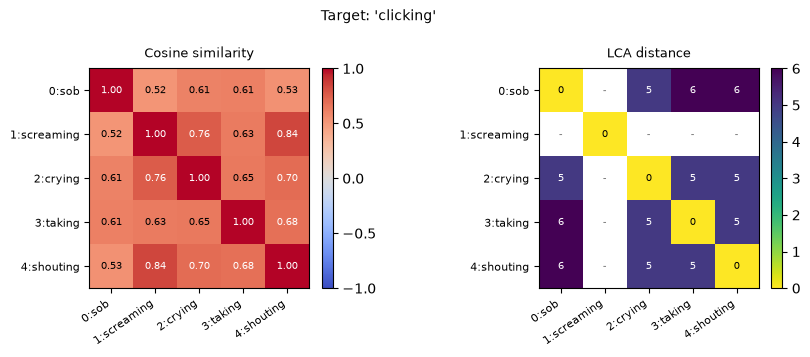


Context: 'He had shut his eyes, his face turned away from his arm, but his worst fears were realized as the people above him gasped and Colin Creevey began clicking away' | Target: 'madly.'
Top-5        |       0:fur |        1:fr |   2:rapidly |    3:wildly |     4:fever
----------------------------------------------------------------------------------
0:fur        |      1.0000 |      0.4255 |      0.7350 |      0.6934 |      0.6748
1:fr         |      0.4255 |      1.0000 |      0.5134 |      0.4984 |      0.4838
2:rapidly    |      0.7350 |      0.5134 |      1.0000 |      0.8750 |      0.7143
3:wildly     |      0.6934 |      0.4984 |      0.8750 |      1.0000 |      0.7142
4:fever      |      0.6748 |      0.4838 |      0.7143 |      0.7142 |      1.0000


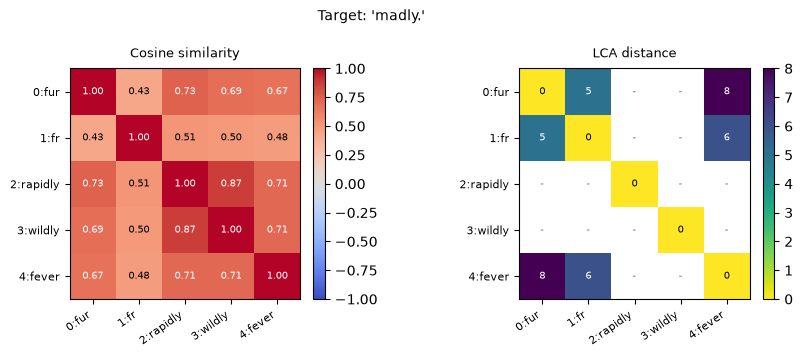


Context: 'His' | Target: 'arm'
Top-5        |     0:first |    1:father |      2:work |      3:name |   4:brother
----------------------------------------------------------------------------------
0:first      |      1.0000 |      0.6635 |      0.5576 |      0.5878 |      0.6332
1:father     |      0.6635 |      1.0000 |      0.6586 |      0.7675 |      0.8733
2:work       |      0.5576 |      0.6586 |      1.0000 |      0.6775 |      0.6646
3:name       |      0.5878 |      0.7675 |      0.6775 |      1.0000 |      0.7747
4:brother    |      0.6332 |      0.8733 |      0.6646 |      0.7747 |      1.0000


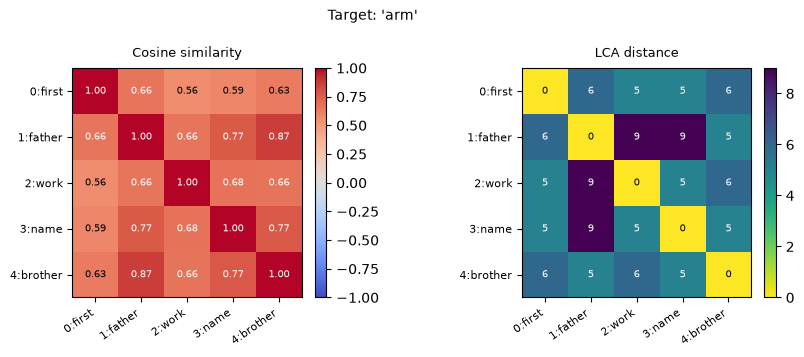


Context: 'His arm' | Target: 'didn’t'
Top-5        |      0:fell |   1:muscles |     2:chair |     3:still |      4:hurt
----------------------------------------------------------------------------------
0:fell       |      1.0000 |      0.6098 |      0.6547 |      0.3770 |      0.7224
1:muscles    |      0.6098 |      1.0000 |      0.7006 |      0.4120 |      0.6238
2:chair      |      0.6547 |      0.7006 |      1.0000 |      0.3440 |      0.6409
3:still      |      0.3770 |      0.4120 |      0.3440 |      1.0000 |      0.3835
4:hurt       |      0.7224 |      0.6238 |      0.6409 |      0.3835 |      1.0000


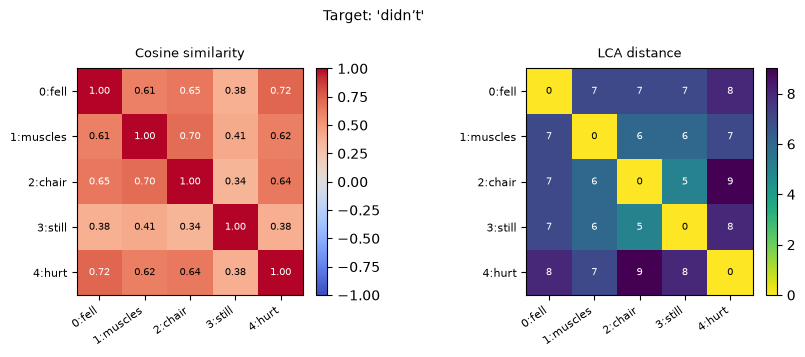


Context: 'His arm didn’t' | Target: 'hurt'
Top-5        |     0:hurt |     1:work |     2:look |     3:move |     4:feel
-----------------------------------------------------------------------------
0:hurt       |     1.0000 |     0.6460 |     0.6832 |     0.6012 |     0.6824
1:work       |     0.6460 |     1.0000 |     0.7214 |     0.6838 |     0.6813
2:look       |     0.6832 |     0.7214 |     1.0000 |     0.7805 |     0.8176
3:move       |     0.6012 |     0.6838 |     0.7805 |     1.0000 |     0.7653
4:feel       |     0.6824 |     0.6813 |     0.8176 |     0.7653 |     1.0000


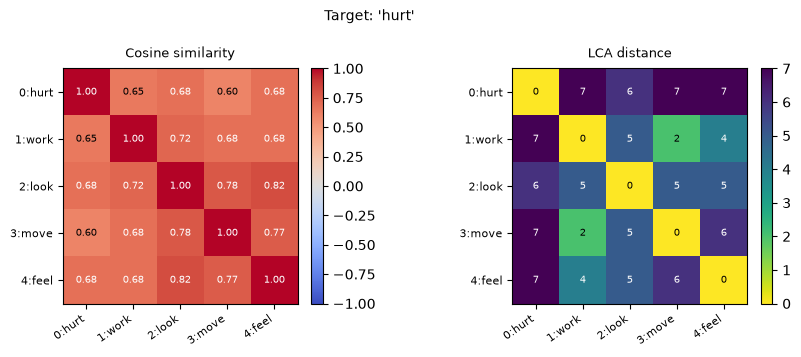


Context: 'His arm didn’t hurt' | Target: 'anymore'
Top-5        |   0:anymore |    1:enough |    2:nearly |     3:badly |     4:right
----------------------------------------------------------------------------------
0:anymore    |      1.0000 |      0.6536 |      0.7266 |      0.7514 |      0.6987
1:enough     |      0.6536 |      1.0000 |      0.6707 |      0.6457 |      0.5465
2:nearly     |      0.7266 |      0.6707 |      1.0000 |      0.8024 |      0.7155
3:badly      |      0.7514 |      0.6457 |      0.8024 |      1.0000 |      0.7702
4:right      |      0.6987 |      0.5465 |      0.7155 |      0.7702 |      1.0000


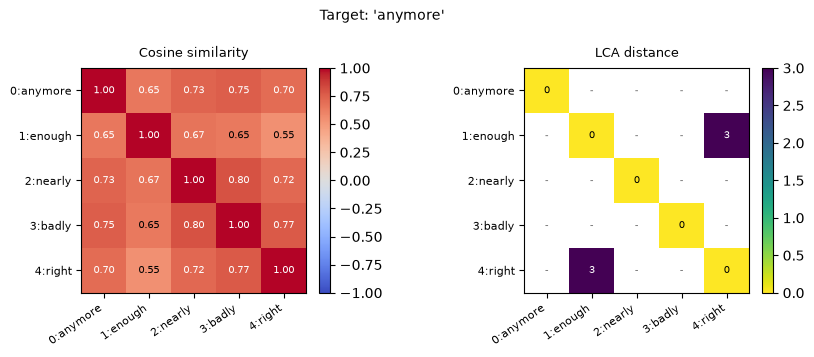


Context: 'His arm didn’t hurt anymore — nor did it' | Target: 'feel'
Top-5        |     0:feel |     1:hurt |     2:look |     3:ache |    4:swell
-----------------------------------------------------------------------------
0:feel       |     1.0000 |     0.6824 |     0.8176 |     0.7091 |     0.6337
1:hurt       |     0.6824 |     1.0000 |     0.6832 |     0.7980 |     0.6644
2:look       |     0.8176 |     0.6832 |     1.0000 |     0.6927 |     0.6660
3:ache       |     0.7091 |     0.7980 |     0.6927 |     1.0000 |     0.7127
4:swell      |     0.6337 |     0.6644 |     0.6660 |     0.7127 |     1.0000


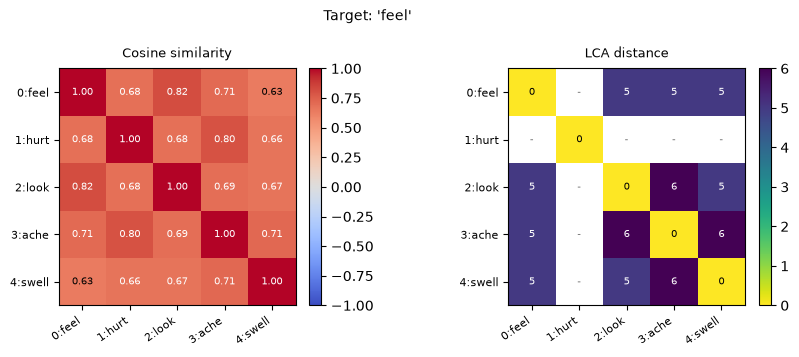


Context: 'His arm didn’t hurt anymore — nor did it feel' | Target: 'remotely'
Top-5            |   0:particularly |          1:right |         2:normal |           3:numb |          4:heavy
---------------------------------------------------------------------------------------------------------------
0:particularly   |           1.0000 |           0.6793 |           0.6901 |           0.6602 |           0.6961
1:right          |           0.6793 |           1.0000 |           0.7064 |           0.6865 |           0.6652
2:normal         |           0.6901 |           0.7064 |           1.0000 |           0.7267 |           0.7375
3:numb           |           0.6602 |           0.6865 |           0.7267 |           1.0000 |           0.6738
4:heavy          |           0.6961 |           0.6652 |           0.7375 |           0.6738 |           1.0000


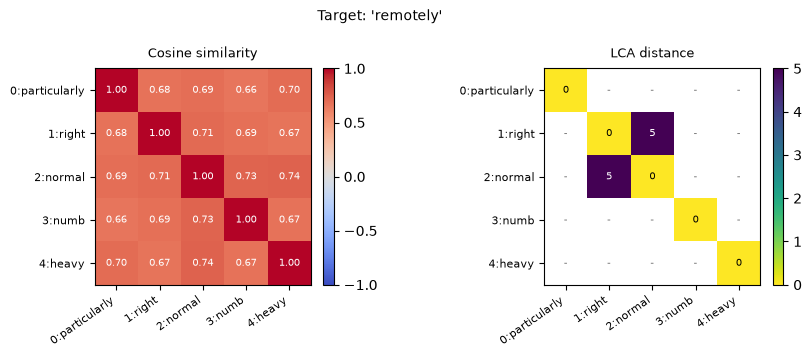


Context: 'His arm didn’t hurt anymore — nor did it feel remotely like an' | Target: 'arm.'
Top-5        |        0:arm |     1:injury |     2:append |      3:upper |   4:ordinary
---------------------------------------------------------------------------------------
0:arm        |       1.0000 |       0.5965 |       0.5311 |       0.5692 |       0.5723
1:injury     |       0.5965 |       1.0000 |       0.4273 |       0.5452 |       0.5387
2:append     |       0.5311 |       0.4273 |       1.0000 |       0.5295 |       0.4869
3:upper      |       0.5692 |       0.5452 |       0.5295 |       1.0000 |       0.7310
4:ordinary   |       0.5723 |       0.5387 |       0.4869 |       0.7310 |       1.0000


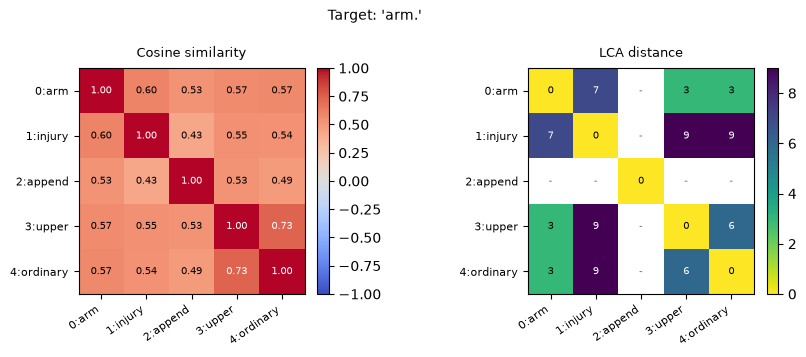


Context: '“Ah,” said' | Target: 'Lockhart.'
Top-5        |       0:mr |       1:dr |      2:mrs |     3:john |     4:miss
-----------------------------------------------------------------------------
0:mr         |     1.0000 |     0.7659 |     0.8692 |     0.6716 |     0.7803
1:dr         |     0.7659 |     1.0000 |     0.8018 |     0.6554 |     0.6904
2:mrs        |     0.8692 |     0.8018 |     1.0000 |     0.7087 |     0.7830
3:john       |     0.6716 |     0.6554 |     0.7087 |     1.0000 |     0.6516
4:miss       |     0.7803 |     0.6904 |     0.7830 |     0.6516 |     1.0000


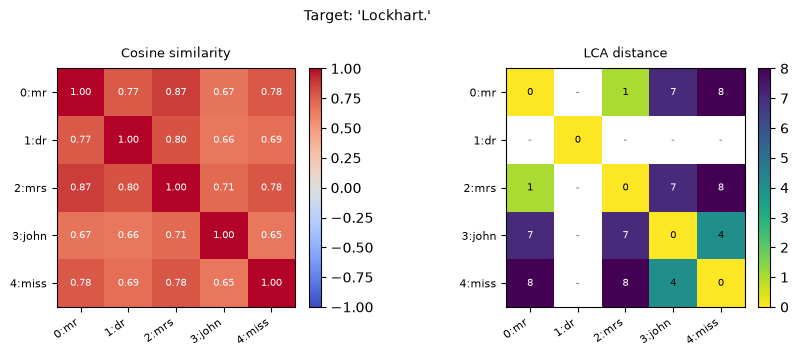


Context: 'Well, that can' | Target: 'sometimes'
Top-5         |      0:happen |      1:depend |        2:mean |   3:certainly |        4:wait
---------------------------------------------------------------------------------------------
0:happen      |        1.0000 |        0.7377 |        0.7721 |        0.5209 |        0.5887
1:depend      |        0.7377 |        1.0000 |        0.7004 |        0.4657 |        0.4993
2:mean        |        0.7721 |        0.7004 |        1.0000 |        0.4919 |        0.5619
3:certainly   |        0.5209 |        0.4657 |        0.4919 |        1.0000 |        0.4927
4:wait        |        0.5887 |        0.4993 |        0.5619 |        0.4927 |        1.0000


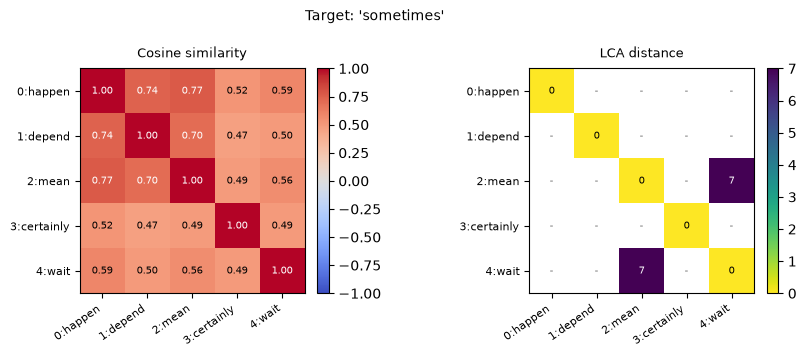


Context: 'Well, that can sometimes' | Target: 'happen.'
Top-5        |   0:happen |   1:depend |     2:take |     3:lead |     4:mean
-----------------------------------------------------------------------------
0:happen     |     1.0000 |     0.7377 |     0.7618 |     0.5269 |     0.7721
1:depend     |     0.7377 |     1.0000 |     0.7206 |     0.5920 |     0.7004
2:take       |     0.7618 |     0.7206 |     1.0000 |     0.6419 |     0.7058
3:lead       |     0.5269 |     0.5920 |     0.6419 |     1.0000 |     0.5810
4:mean       |     0.7721 |     0.7004 |     0.7058 |     0.5810 |     1.0000


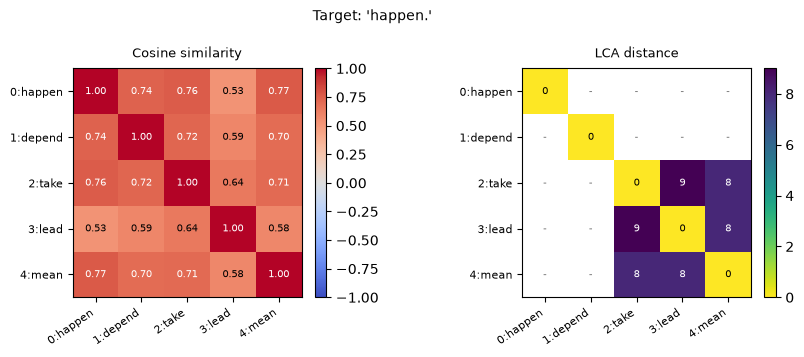


Context: 'But the' | Target: 'point'
Top-5        |   0:problem |      1:real |     2:first |      3:best |      4:fact
----------------------------------------------------------------------------------
0:problem    |      1.0000 |      0.6162 |      0.5349 |      0.5987 |      0.6784
1:real       |      0.6162 |      1.0000 |      0.5495 |      0.6549 |      0.7705
2:first      |      0.5349 |      0.5495 |      1.0000 |      0.5971 |      0.5984
3:best       |      0.5987 |      0.6549 |      0.5971 |      1.0000 |      0.6629
4:fact       |      0.6784 |      0.7705 |      0.5984 |      0.6629 |      1.0000


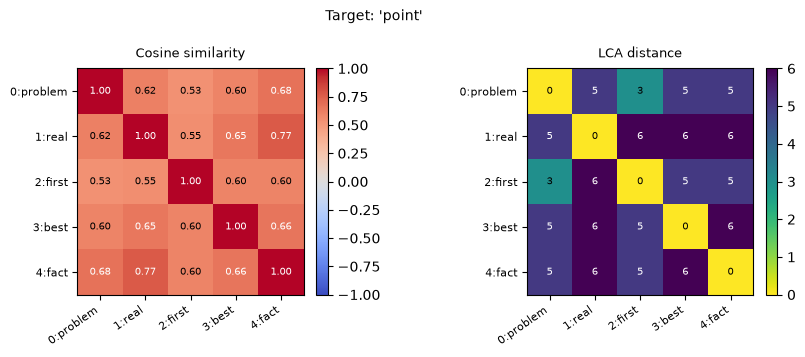


Context: 'But the point is, the' | Target: 'bones'
Top-5        |      0:way |    1:whole |   2:people |      3:man |    4:first
-----------------------------------------------------------------------------
0:way        |     1.0000 |     0.6258 |     0.5438 |     0.6472 |     0.4943
1:whole      |     0.6258 |     1.0000 |     0.6346 |     0.6537 |     0.5299
2:people     |     0.5438 |     0.6346 |     1.0000 |     0.7098 |     0.5699
3:man        |     0.6472 |     0.6537 |     0.7098 |     1.0000 |     0.5969
4:first      |     0.4943 |     0.5299 |     0.5699 |     0.5969 |     1.0000


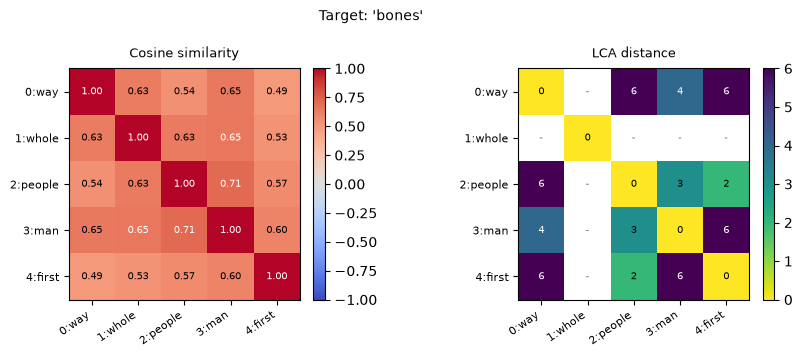


Context: 'But the point is, the bones are no' | Target: 'longer'
Top-5        |   0:longer |     1:good |      2:use |    3:bones |     4:help
-----------------------------------------------------------------------------
0:longer     |     1.0000 |     0.4898 |     0.5279 |     0.4896 |     0.5298
1:good       |     0.4898 |     1.0000 |     0.4723 |     0.4959 |     0.5270
2:use        |     0.5279 |     0.4723 |     1.0000 |     0.5077 |     0.6707
3:bones      |     0.4896 |     0.4959 |     0.5077 |     1.0000 |     0.6383
4:help       |     0.5298 |     0.5270 |     0.6707 |     0.6383 |     1.0000


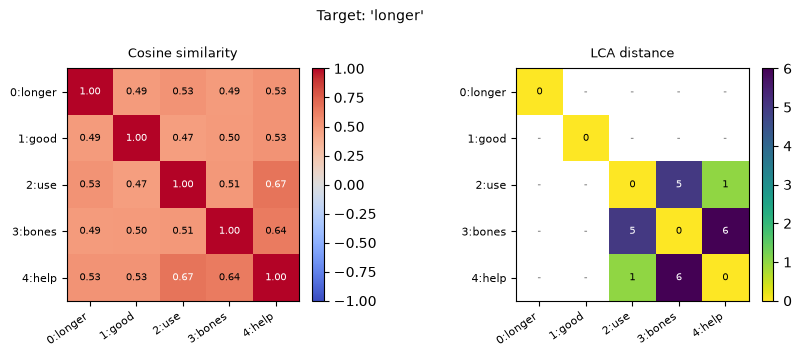


Context: 'That’s the' | Target: 'thing'
Top-5          |     0:question |      1:message |        2:title |        3:first |   4:conclusion
---------------------------------------------------------------------------------------------------
0:question     |         1.0000 |         0.7548 |         0.4694 |         0.6274 |         0.6255
1:message      |         0.7548 |         1.0000 |         0.5316 |         0.5352 |         0.5809
2:title        |         0.4694 |         0.5316 |         1.0000 |         0.4539 |         0.5104
3:first        |         0.6274 |         0.5352 |         0.4539 |         1.0000 |         0.5301
4:conclusion   |         0.6255 |         0.5809 |         0.5104 |         0.5301 |         1.0000


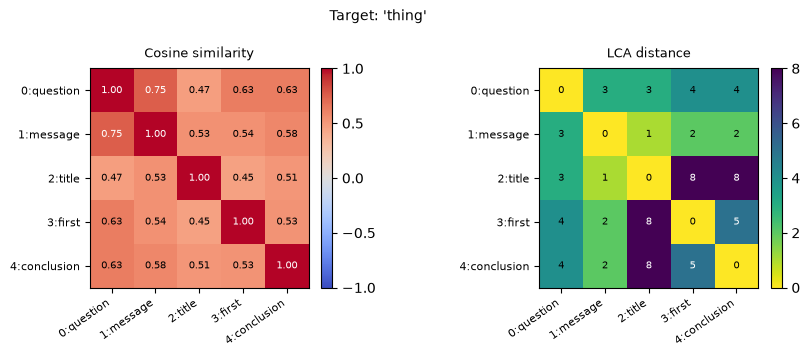


Context: 'That’s the thing to' | Target: 'bear'
Top-5        |   0:remember |       1:keep |       2:know |       3:look |      4:think
---------------------------------------------------------------------------------------
0:remember   |       1.0000 |       0.6042 |       0.6623 |       0.5651 |       0.6294
1:keep       |       0.6042 |       1.0000 |       0.7421 |       0.7083 |       0.6614
2:know       |       0.6623 |       0.7421 |       1.0000 |       0.7639 |       0.7372
3:look       |       0.5651 |       0.7083 |       0.7639 |       1.0000 |       0.7606
4:think      |       0.6294 |       0.6614 |       0.7372 |       0.7606 |       1.0000


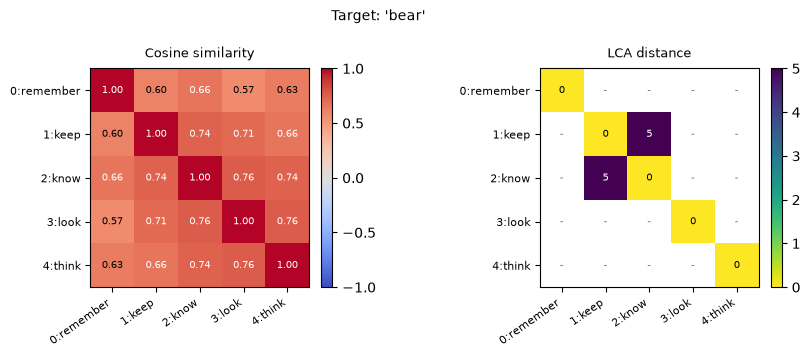


Context: 'That’s the thing to bear in' | Target: 'mind.'
Top-5             |            0:mind |            1:mine |             2:min |   3:consideration |           4:minds
---------------------------------------------------------------------------------------------------------------------
0:mind            |            1.0000 |            0.4996 |            0.4368 |            0.6509 |            0.7841
1:mine            |            0.4996 |            1.0000 |            0.3507 |            0.5117 |            0.5713
2:min             |            0.4368 |            0.3507 |            1.0000 |            0.5652 |            0.4794
3:consideration   |            0.6509 |            0.5117 |            0.5652 |            1.0000 |            0.7843
4:minds           |            0.7841 |            0.5713 |            0.4794 |            0.7843 |            1.0000


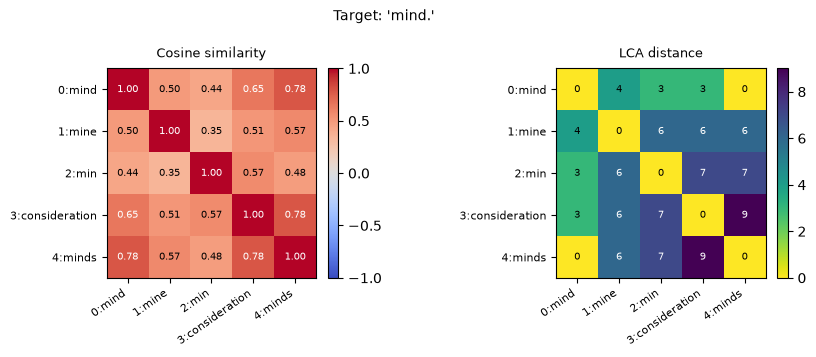


Context: 'So,' | Target: 'Harry,'
Top-5         |         0:let |       1:today |       2:first |   3:basically |       4:given
---------------------------------------------------------------------------------------------
0:let         |        1.0000 |        0.4180 |        0.5580 |        0.5972 |        0.7179
1:today       |        0.4180 |        1.0000 |        0.5455 |        0.5426 |        0.4368
2:first       |        0.5580 |        0.5455 |        1.0000 |        0.6073 |        0.5947
3:basically   |        0.5972 |        0.5426 |        0.6073 |        1.0000 |        0.6779
4:given       |        0.7179 |        0.4368 |        0.5947 |        0.6779 |        1.0000


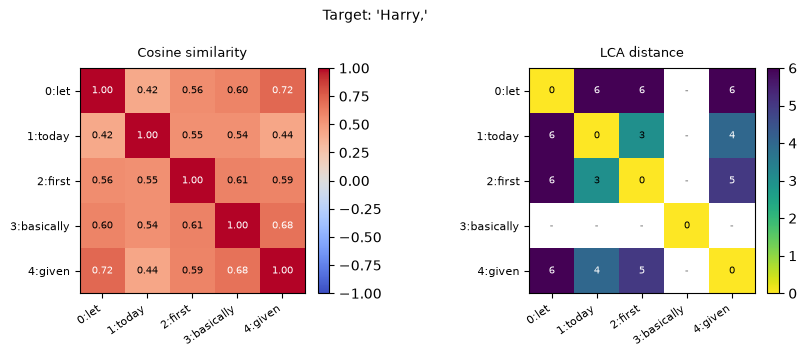


Context: 'So, Harry, just' | Target: 'toddle'
Top-5        |      0:tell |      1:back |      2:give |       3:let |   4:exactly
----------------------------------------------------------------------------------
0:tell       |      1.0000 |      0.6765 |      0.8343 |      0.6276 |      0.6610
1:back       |      0.6765 |      1.0000 |      0.6958 |      0.5449 |      0.6156
2:give       |      0.8343 |      0.6958 |      1.0000 |      0.7298 |      0.6079
3:let        |      0.6276 |      0.5449 |      0.7298 |      1.0000 |      0.5418
4:exactly    |      0.6610 |      0.6156 |      0.6079 |      0.5418 |      1.0000


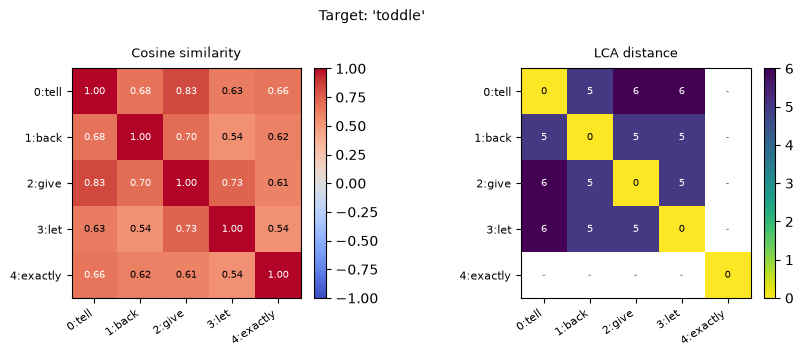


Context: 'So, Harry, just toddle up to the' | Target: 'hospital'
Top-5        |    0:counter |       1:desk |   2:platform |      3:front |        4:bar
---------------------------------------------------------------------------------------
0:counter    |       1.0000 |       0.6618 |       0.6299 |       0.7784 |       0.7414
1:desk       |       0.6618 |       1.0000 |       0.5540 |       0.6243 |       0.5805
2:platform   |       0.6299 |       0.5540 |       1.0000 |       0.5887 |       0.5645
3:front      |       0.7784 |       0.6243 |       0.5887 |       1.0000 |       0.6488
4:bar        |       0.7414 |       0.5805 |       0.5645 |       0.6488 |       1.0000


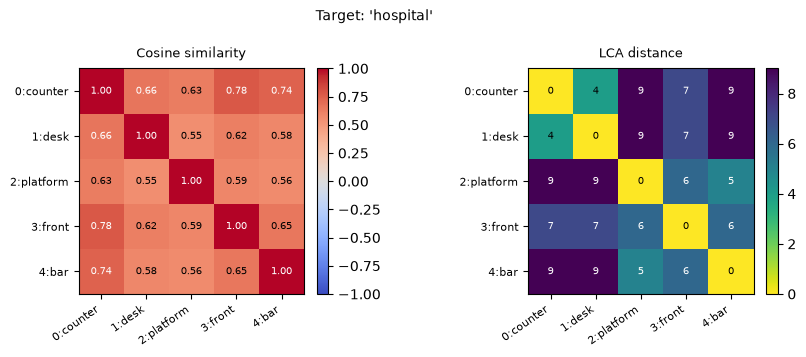


Context: 'So, Harry, just toddle up to the hospital' | Target: 'wing'
Top-5        |       0:wing |        1:bed |       2:room |   3:entrance |       4:ward
---------------------------------------------------------------------------------------
0:wing       |       1.0000 |       0.5330 |       0.6100 |       0.6088 |       0.6037
1:bed        |       0.5330 |       1.0000 |       0.7034 |       0.5782 |       0.5389
2:room       |       0.6100 |       0.7034 |       1.0000 |       0.6726 |       0.6393
3:entrance   |       0.6088 |       0.5782 |       0.6726 |       1.0000 |       0.6491
4:ward       |       0.6037 |       0.5389 |       0.6393 |       0.6491 |       1.0000


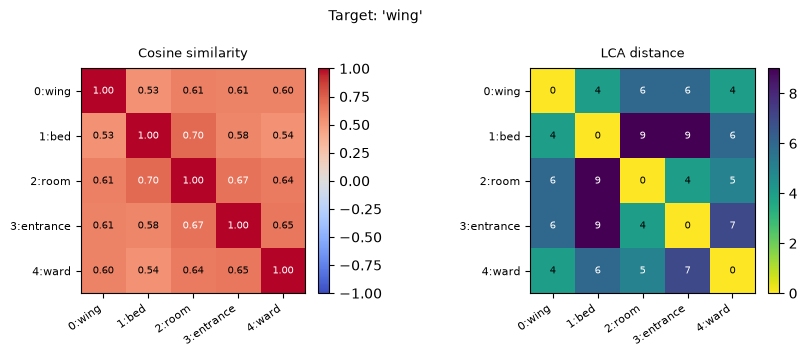


Context: 'So, Harry, just toddle up to the hospital wing —' | Target: 'ah,'
Top-5         |   0:professor |         1:yes |         2:see |         3:mrs |       4:right
---------------------------------------------------------------------------------------------
0:professor   |        1.0000 |        0.5505 |        0.6318 |        0.7482 |        0.5987
1:yes         |        0.5505 |        1.0000 |        0.5600 |        0.6320 |        0.6864
2:see         |        0.6318 |        0.5600 |        1.0000 |        0.6750 |        0.6569
3:mrs         |        0.7482 |        0.6320 |        0.6750 |        1.0000 |        0.6689
4:right       |        0.5987 |        0.6864 |        0.6569 |        0.6689 |        1.0000


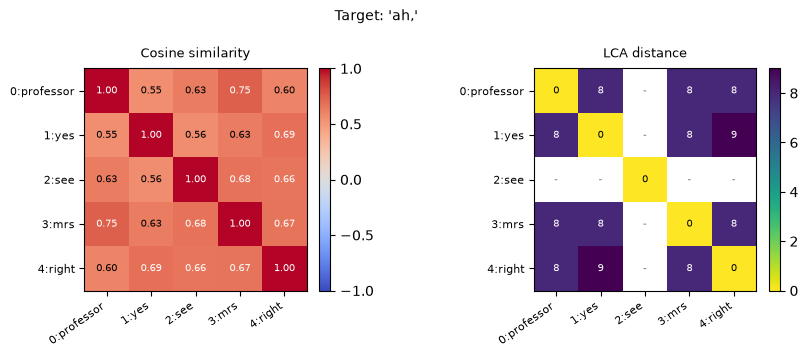


Context: 'So, Harry, just toddle up to the hospital wing — ah,' | Target: 'Mr.'
Top-5        |      0:yes |    1:hello |     2:wait |       3:mr |    4:right
-----------------------------------------------------------------------------
0:yes        |     1.0000 |     0.5649 |     0.6492 |     0.6803 |     0.6864
1:hello      |     0.5649 |     1.0000 |     0.4557 |     0.6039 |     0.4618
2:wait       |     0.6492 |     0.4557 |     1.0000 |     0.5786 |     0.5539
3:mr         |     0.6803 |     0.6039 |     0.5786 |     1.0000 |     0.6883
4:right      |     0.6864 |     0.4618 |     0.5539 |     0.6883 |     1.0000


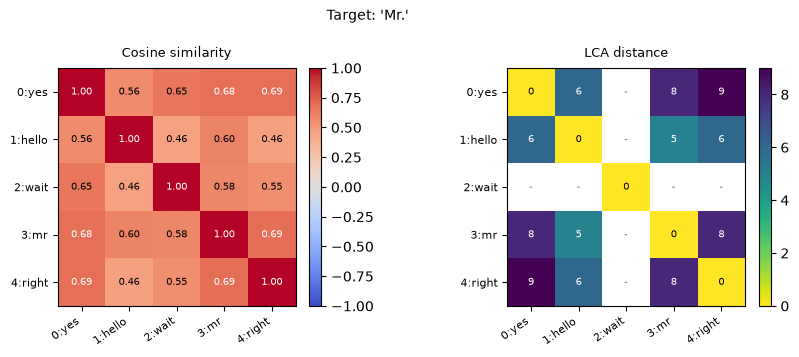


Context: 'So, Harry, just toddle up to the hospital wing — ah, Mr.' | Target: 'Weasley,'
Top-5        |      0:fil |        1:f |        2:c |     3:lock |   4:potter
-----------------------------------------------------------------------------
0:fil        |     1.0000 |     0.5666 |     0.5112 |     0.5009 |     0.4489
1:f          |     0.5666 |     1.0000 |     0.7730 |     0.6222 |     0.5179
2:c          |     0.5112 |     0.7730 |     1.0000 |     0.5478 |     0.4775
3:lock       |     0.5009 |     0.6222 |     0.5478 |     1.0000 |     0.6501
4:potter     |     0.4489 |     0.5179 |     0.4775 |     0.6501 |     1.0000


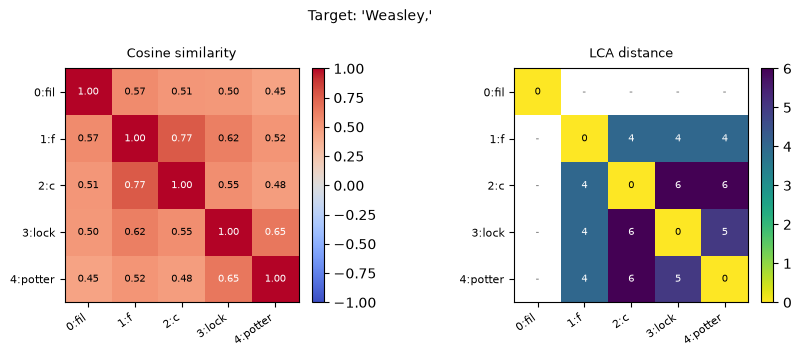


Context: 'So, Harry, just toddle up to the hospital wing — ah, Mr. Weasley,' | Target: 'Miss'
Top-5        |     0:good |     1:nice |       2:mr |    3:hello |    4:thank
-----------------------------------------------------------------------------
0:good       |     1.0000 |     0.7113 |     0.5993 |     0.4877 |     0.6100
1:nice       |     0.7113 |     1.0000 |     0.7084 |     0.5641 |     0.6457
2:mr         |     0.5993 |     0.7084 |     1.0000 |     0.6039 |     0.6645
3:hello      |     0.4877 |     0.5641 |     0.6039 |     1.0000 |     0.5658
4:thank      |     0.6100 |     0.6457 |     0.6645 |     0.5658 |     1.0000


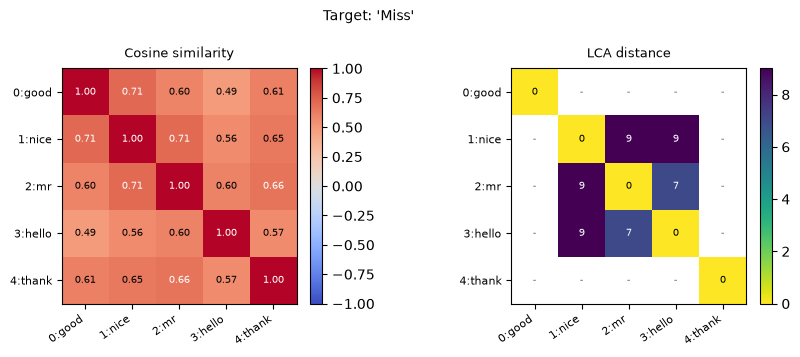


Context: 'So, Harry, just toddle up to the hospital wing — ah, Mr. Weasley, Miss' | Target: 'Granger,'
Top-5        |       0:gr |     1:finn |   2:potter |     3:love |    4:bones
-----------------------------------------------------------------------------
0:gr         |     1.0000 |     0.5138 |     0.6216 |     0.5021 |     0.5259
1:finn       |     0.5138 |     1.0000 |     0.5380 |     0.4986 |     0.6890
2:potter     |     0.6216 |     0.5380 |     1.0000 |     0.4225 |     0.5678
3:love       |     0.5021 |     0.4986 |     0.4225 |     1.0000 |     0.5517
4:bones      |     0.5259 |     0.6890 |     0.5678 |     0.5517 |     1.0000


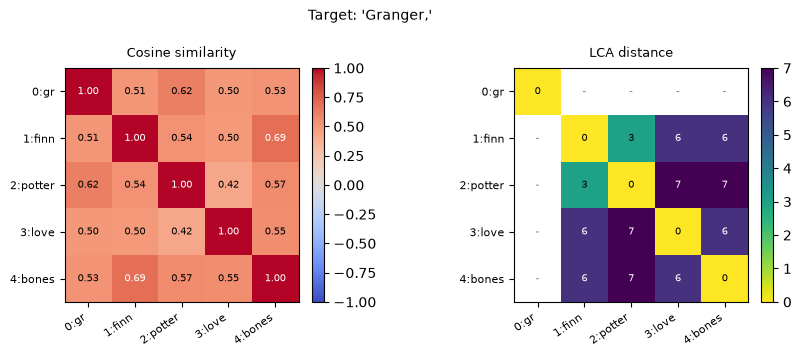


Context: 'So, Harry, just toddle up to the hospital wing — ah, Mr. Weasley, Miss Granger, would you' | Target: 'escort'
Top-5        |     0:care |     1:mind |     2:come |     3:join |   4:excuse
-----------------------------------------------------------------------------
0:care       |     1.0000 |     0.6623 |     0.5560 |     0.6232 |     0.6273
1:mind       |     0.6623 |     1.0000 |     0.5894 |     0.6246 |     0.6248
2:come       |     0.5560 |     0.5894 |     1.0000 |     0.7072 |     0.6602
3:join       |     0.6232 |     0.6246 |     0.7072 |     1.0000 |     0.7457
4:excuse     |     0.6273 |     0.6248 |     0.6602 |     0.7457 |     1.0000


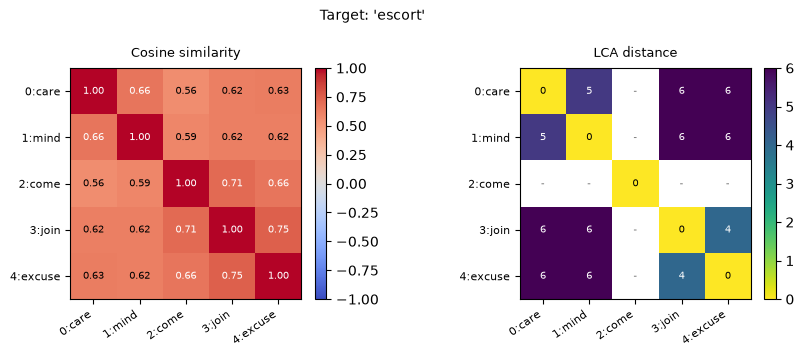


Context: '— and' | Target: 'Madam'
Top-5        |       0:yet |   1:perhaps
----------------------------------------
0:yet        |      1.0000 |      0.6058
1:perhaps    |      0.6058 |      1.0000


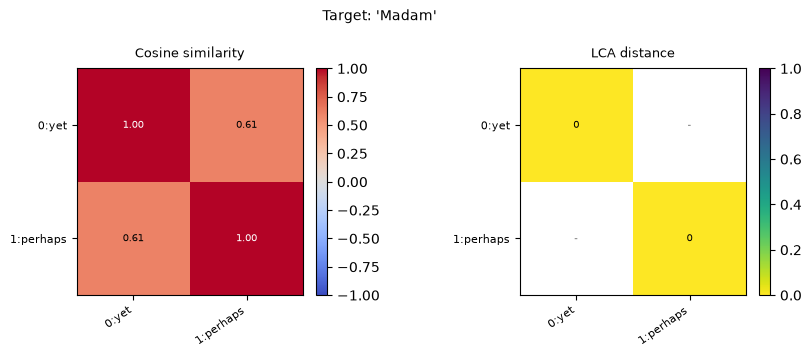


Context: '— and Madam' | Target: 'Pomfrey'
Top-5         |   0:president |     1:speaker |     2:justice |   3:secretary |         4:cur
---------------------------------------------------------------------------------------------
0:president   |        1.0000 |        0.6683 |        0.6381 |        0.7542 |        0.5647
1:speaker     |        0.6683 |        1.0000 |        0.5752 |        0.5919 |        0.4269
2:justice     |        0.6381 |        0.5752 |        1.0000 |        0.6285 |        0.4499
3:secretary   |        0.7542 |        0.5919 |        0.6285 |        1.0000 |        0.4310
4:cur         |        0.5647 |        0.4269 |        0.4499 |        0.4310 |        1.0000


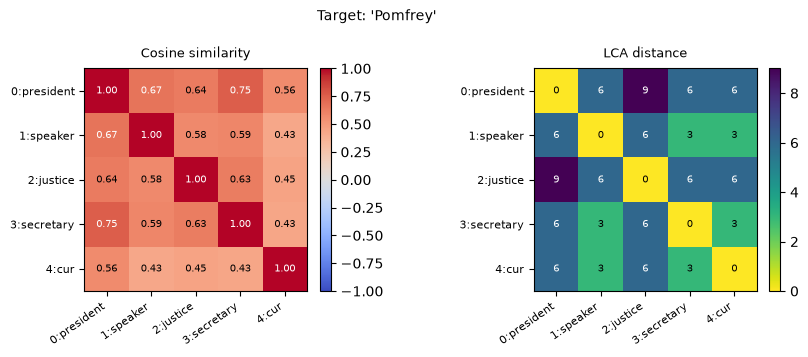


Context: '— and Madam Pomfrey will be able to —' | Target: 'er'
Top-5        |     0:take |     1:help |     2:give |       3:er |       4:oh
-----------------------------------------------------------------------------
0:take       |     1.0000 |     0.7621 |     0.8652 |     0.5699 |     0.6402
1:help       |     0.7621 |     1.0000 |     0.8014 |     0.5905 |     0.6708
2:give       |     0.8652 |     0.8014 |     1.0000 |     0.5634 |     0.6766
3:er         |     0.5699 |     0.5905 |     0.5634 |     1.0000 |     0.5437
4:oh         |     0.6402 |     0.6708 |     0.6766 |     0.5437 |     1.0000


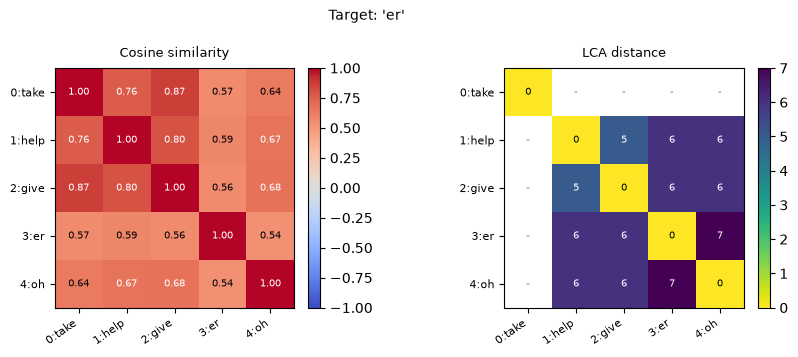


Context: '— and Madam Pomfrey will be able to — er —' | Target: 'tidy'
Top-5        |     0:mend |     1:take |      2:fix |     3:give |     4:help
-----------------------------------------------------------------------------
0:mend       |     1.0000 |     0.5964 |     0.5917 |     0.5486 |     0.5363
1:take       |     0.5964 |     1.0000 |     0.7807 |     0.8652 |     0.7621
2:fix        |     0.5917 |     0.7807 |     1.0000 |     0.8113 |     0.8410
3:give       |     0.5486 |     0.8652 |     0.8113 |     1.0000 |     0.8014
4:help       |     0.5363 |     0.7621 |     0.8410 |     0.8014 |     1.0000


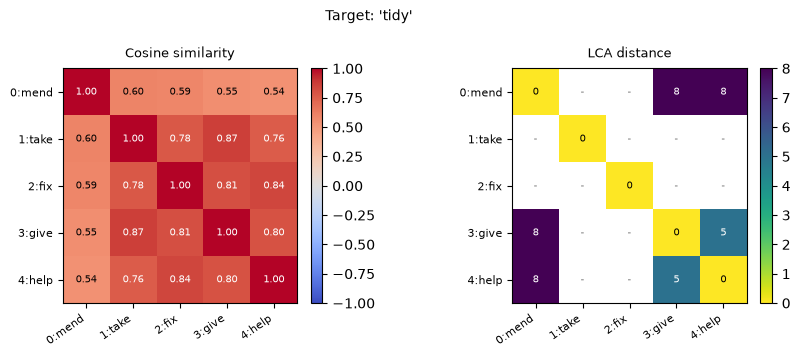


Context: '— and Madam Pomfrey will be able to — er — tidy you up a' | Target: 'bit.”'
Top-5        |      0:bit |   1:little |     2:spot |      3:lot |     4:good
-----------------------------------------------------------------------------
0:bit        |     1.0000 |     0.6506 |     0.6604 |     0.7945 |     0.5043
1:little     |     0.6506 |     1.0000 |     0.6352 |     0.7226 |     0.5371
2:spot       |     0.6604 |     0.6352 |     1.0000 |     0.7412 |     0.5167
3:lot        |     0.7945 |     0.7226 |     0.7412 |     1.0000 |     0.5824
4:good       |     0.5043 |     0.5371 |     0.5167 |     0.5824 |     1.0000


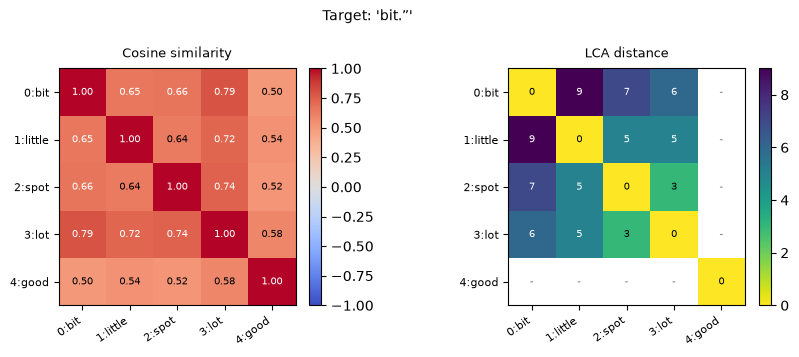


Context: '— and Madam Pomfrey will be able to — er — tidy you up a bit.” As' | Target: 'Harry'
Top-5          |        0:harry |         1:soon |   2:dumbledore |     3:hermione |            4:h
---------------------------------------------------------------------------------------------------
0:harry        |         1.0000 |         0.5121 |         0.3280 |         0.4042 |         0.6282
1:soon         |         0.5121 |         1.0000 |         0.2087 |         0.2909 |         0.3645
2:dumbledore   |         0.3280 |         0.2087 |         1.0000 |         0.3562 |         0.2244
3:hermione     |         0.4042 |         0.2909 |         0.3562 |         1.0000 |         0.3197
4:h            |         0.6282 |         0.3645 |         0.2244 |         0.3197 |         1.0000


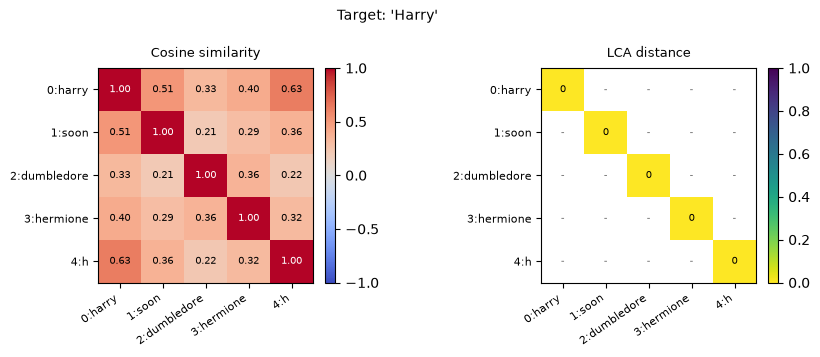


Context: '— and Madam Pomfrey will be able to — er — tidy you up a bit.” As Harry got to his' | Target: 'feet,'
Top-5        |     0:feet |    1:knees |      2:bed |    3:first |    4:hands
-----------------------------------------------------------------------------
0:feet       |     1.0000 |     0.7614 |     0.6413 |     0.5782 |     0.7672
1:knees      |     0.7614 |     1.0000 |     0.6849 |     0.6165 |     0.8032
2:bed        |     0.6413 |     0.6849 |     1.0000 |     0.5080 |     0.6704
3:first      |     0.5782 |     0.6165 |     0.5080 |     1.0000 |     0.6418
4:hands      |     0.7672 |     0.8032 |     0.6704 |     0.6418 |     1.0000


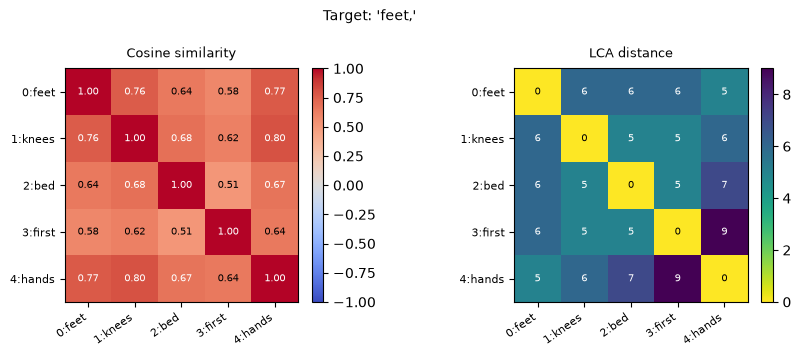


Context: '— and Madam Pomfrey will be able to — er — tidy you up a bit.” As Harry got to his feet, he' | Target: 'felt'
Top-5        |        0:saw |       1:felt |     2:looked |      3:found |   4:suddenly
---------------------------------------------------------------------------------------
0:saw        |       1.0000 |       0.8889 |       0.8470 |       0.7088 |       0.4969
1:felt       |       0.8889 |       1.0000 |       0.8613 |       0.6992 |       0.4881
2:looked     |       0.8470 |       0.8613 |       1.0000 |       0.7016 |       0.5342
3:found      |       0.7088 |       0.6992 |       0.7016 |       1.0000 |       0.4577
4:suddenly   |       0.4969 |       0.4881 |       0.5342 |       0.4577 |       1.0000


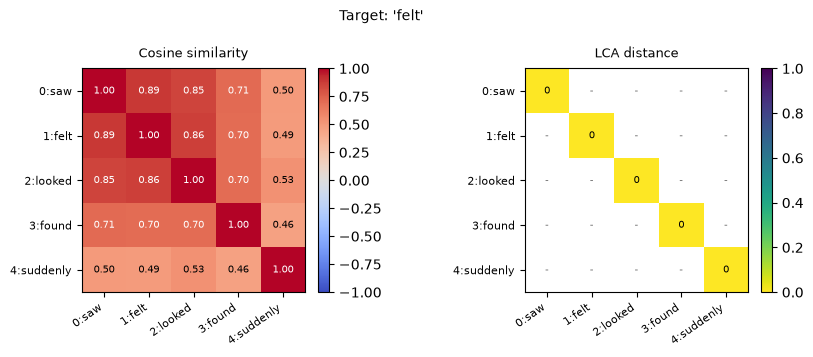


Context: '— and Madam Pomfrey will be able to — er — tidy you up a bit.” As Harry got to his feet, he felt' | Target: 'strangely'
Top-5         |   0:something |      1:rather |    2:hermione |         3:ron |   4:extremely
---------------------------------------------------------------------------------------------
0:something   |        1.0000 |        0.7008 |        0.3752 |        0.7302 |        0.8623
1:rather      |        0.7008 |        1.0000 |        0.3132 |        0.6245 |        0.7119
2:hermione    |        0.3752 |        0.3132 |        1.0000 |        0.3613 |        0.3545
3:ron         |        0.7302 |        0.6245 |        0.3613 |        1.0000 |        0.7821
4:extremely   |        0.8623 |        0.7119 |        0.3545 |        0.7821 |        1.0000


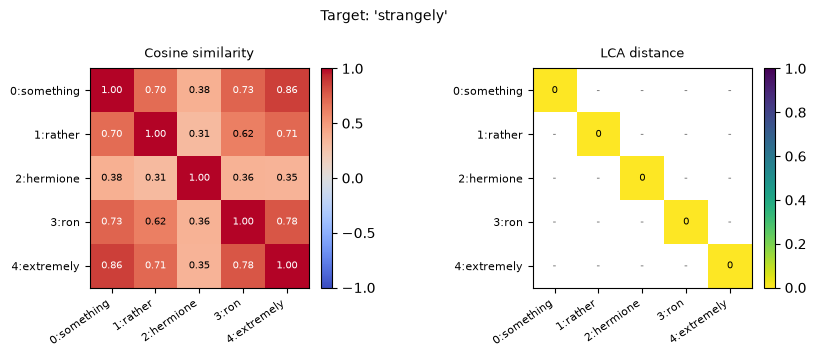


Context: 'Taking a' | Target: 'deep'
Top-5        |    0:break |     1:look |   2:closer |     3:walk |     4:step
-----------------------------------------------------------------------------
0:break      |     1.0000 |     0.7295 |     0.5241 |     0.6871 |     0.6294
1:look       |     0.7295 |     1.0000 |     0.5885 |     0.8122 |     0.6787
2:closer     |     0.5241 |     0.5885 |     1.0000 |     0.5995 |     0.6736
3:walk       |     0.6871 |     0.8122 |     0.5995 |     1.0000 |     0.7438
4:step       |     0.6294 |     0.6787 |     0.6736 |     0.7438 |     1.0000


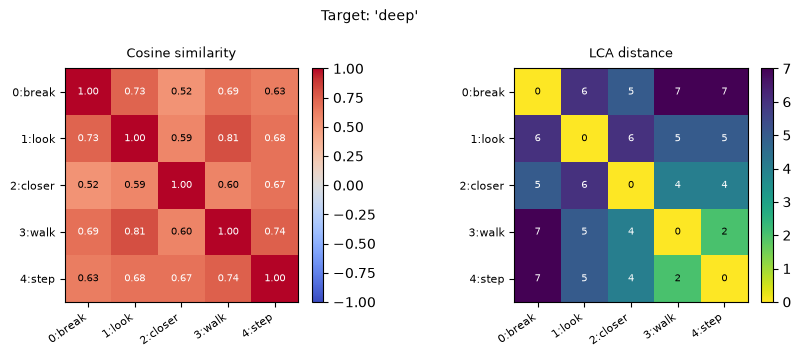


Context: 'Taking a deep' | Target: 'breath'
Top-5        |     0:breath |       1:dive |       2:look |   3:interest |    4:breathe
---------------------------------------------------------------------------------------
0:breath     |       1.0000 |       0.5949 |       0.6160 |       0.5721 |       0.7888
1:dive       |       0.5949 |       1.0000 |       0.6414 |       0.5599 |       0.6800
2:look       |       0.6160 |       0.6414 |       1.0000 |       0.6778 |       0.7187
3:interest   |       0.5721 |       0.5599 |       0.6778 |       1.0000 |       0.5629
4:breathe    |       0.7888 |       0.6800 |       0.7187 |       0.5629 |       1.0000


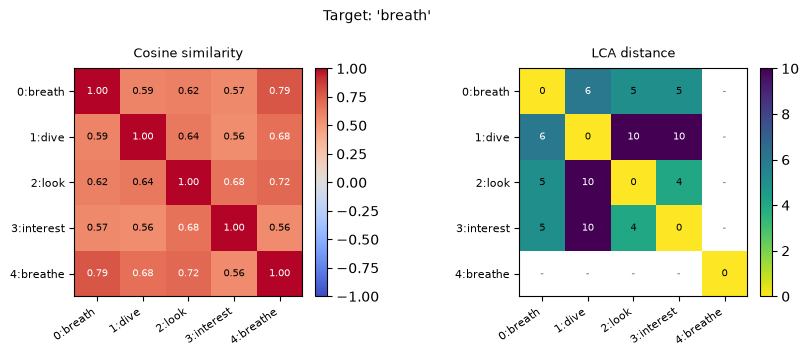


Context: 'Taking a deep breath he' | Target: 'looked'
Top-5        |    0:walked |   1:stepped |     2:began |     3:stood |    4:looked
----------------------------------------------------------------------------------
0:walked     |      1.0000 |      0.8363 |      0.7848 |      0.7593 |      0.8588
1:stepped    |      0.8363 |      1.0000 |      0.7468 |      0.7253 |      0.8234
2:began      |      0.7848 |      0.7468 |      1.0000 |      0.7010 |      0.7550
3:stood      |      0.7593 |      0.7253 |      0.7010 |      1.0000 |      0.6895
4:looked     |      0.8588 |      0.8234 |      0.7550 |      0.6895 |      1.0000


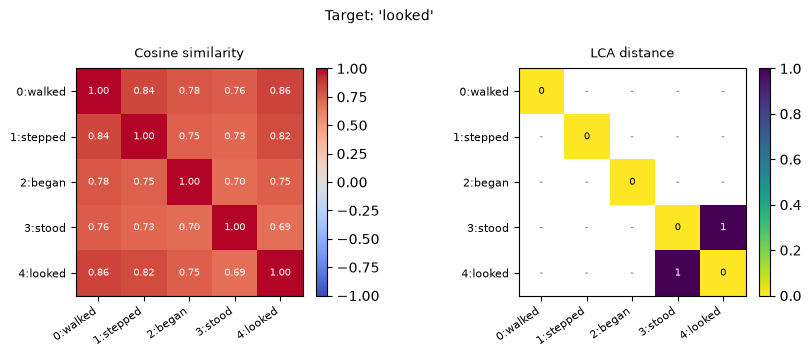


Context: 'Taking a deep breath he looked down at his' | Target: 'right'
Top-5          |        0:hands |        1:watch |         2:wife |   3:reflection |         4:feet
---------------------------------------------------------------------------------------------------
0:hands        |         1.0000 |         0.6275 |         0.7072 |         0.7152 |         0.7672
1:watch        |         0.6275 |         1.0000 |         0.6580 |         0.6876 |         0.5592
2:wife         |         0.7072 |         0.6580 |         1.0000 |         0.7710 |         0.6655
3:reflection   |         0.7152 |         0.6876 |         0.7710 |         1.0000 |         0.6766
4:feet         |         0.7672 |         0.5592 |         0.6655 |         0.6766 |         1.0000


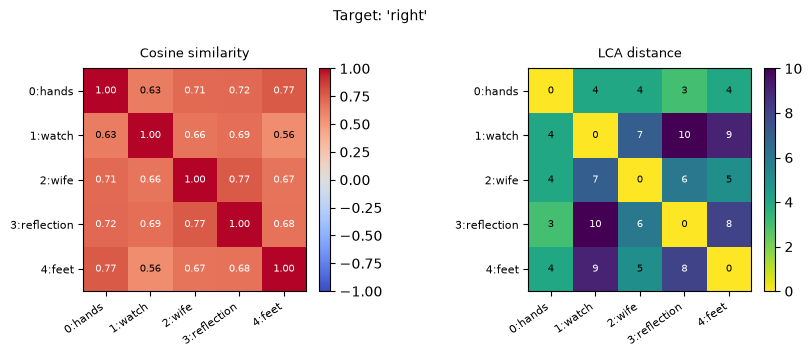


Context: 'Taking a deep breath he looked down at his right' | Target: 'side.'
Top-5        |     0:hand |      1:arm |      2:leg |    3:wrist |     4:foot
-----------------------------------------------------------------------------
0:hand       |     1.0000 |     0.7849 |     0.6902 |     0.7477 |     0.6854
1:arm        |     0.7849 |     1.0000 |     0.7126 |     0.7386 |     0.6334
2:leg        |     0.6902 |     0.7126 |     1.0000 |     0.6343 |     0.7950
3:wrist      |     0.7477 |     0.7386 |     0.6343 |     1.0000 |     0.5849
4:foot       |     0.6854 |     0.6334 |     0.7950 |     0.5849 |     1.0000


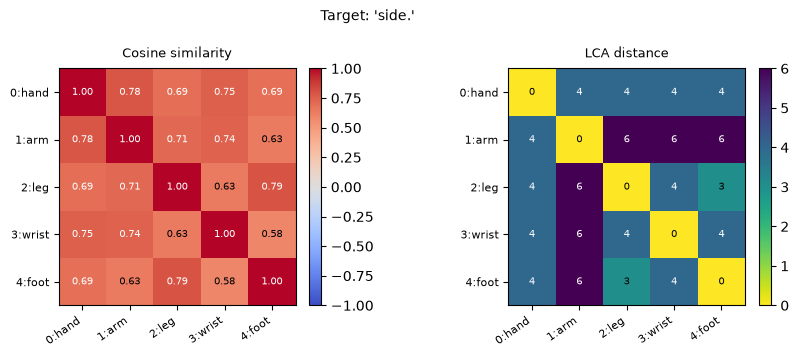


Context: 'What he' | Target: 'saw'
Top-5        |     0:really |   1:actually |      2:needs |      3:found |      4:wants
---------------------------------------------------------------------------------------
0:really     |       1.0000 |       0.8489 |       0.6329 |       0.6170 |       0.6730
1:actually   |       0.8489 |       1.0000 |       0.4959 |       0.5162 |       0.5372
2:needs      |       0.6329 |       0.4959 |       1.0000 |       0.6607 |       0.8938
3:found      |       0.6170 |       0.5162 |       0.6607 |       1.0000 |       0.6820
4:wants      |       0.6730 |       0.5372 |       0.8938 |       0.6820 |       1.0000


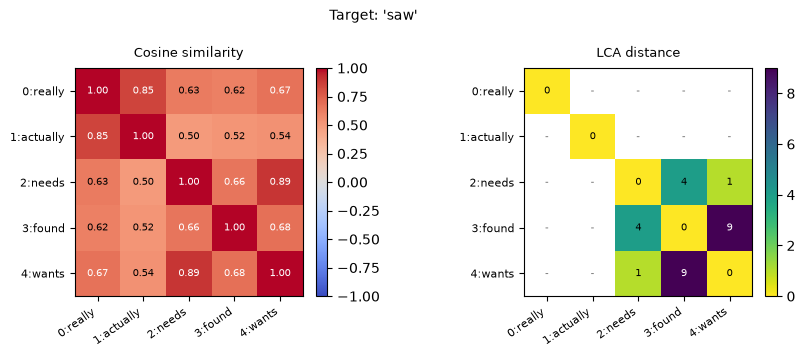


Context: 'What he saw' | Target: 'nearly'
Top-5        |   0:outside |      1:left |      2:last |    3:caused |    4:seemed
----------------------------------------------------------------------------------
0:outside    |      1.0000 |      0.4922 |      0.5597 |      0.5551 |      0.5743
1:left       |      0.4922 |      1.0000 |      0.6022 |      0.6387 |      0.5984
2:last       |      0.5597 |      0.6022 |      1.0000 |      0.6245 |      0.7279
3:caused     |      0.5551 |      0.6387 |      0.6245 |      1.0000 |      0.6909
4:seemed     |      0.5743 |      0.5984 |      0.7279 |      0.6909 |      1.0000


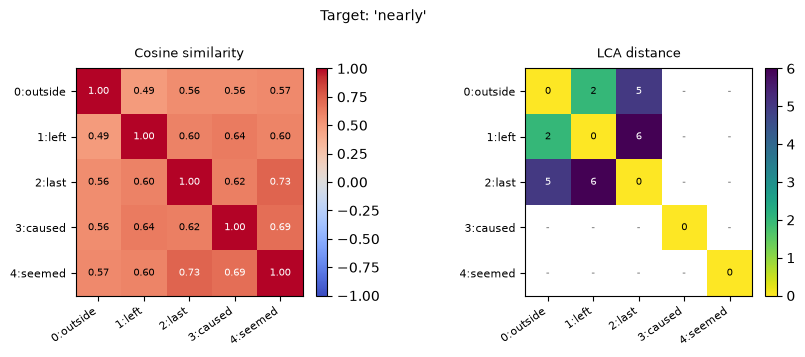


Context: 'What he saw nearly made him' | Target: 'pass'
Top-5        |    0:faint |     1:fall |     2:sick |      3:cry |     4:drop
-----------------------------------------------------------------------------
0:faint      |     1.0000 |     0.6582 |     0.7163 |     0.5926 |     0.7293
1:fall       |     0.6582 |     1.0000 |     0.5858 |     0.5942 |     0.7243
2:sick       |     0.7163 |     0.5858 |     1.0000 |     0.6218 |     0.6640
3:cry        |     0.5926 |     0.5942 |     0.6218 |     1.0000 |     0.6896
4:drop       |     0.7293 |     0.7243 |     0.6640 |     0.6896 |     1.0000


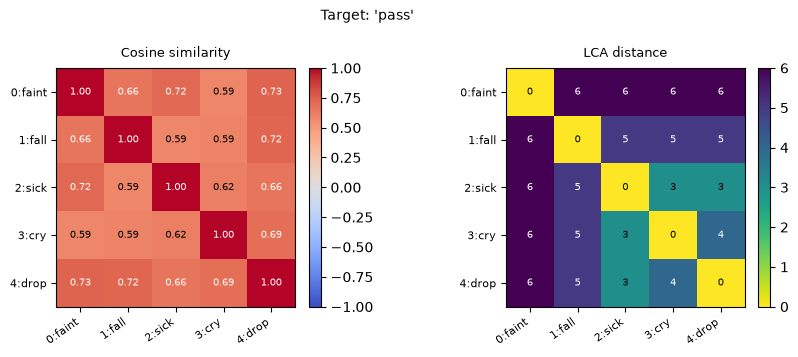


Context: 'Poking out of the' | Target: 'end'
Top-5        |   0:ground |     1:sand |     2:side |    3:earth |    4:water
-----------------------------------------------------------------------------
0:ground     |     1.0000 |     0.5451 |     0.4147 |     0.5692 |     0.5292
1:sand       |     0.5451 |     1.0000 |     0.5102 |     0.5836 |     0.7416
2:side       |     0.4147 |     0.5102 |     1.0000 |     0.5159 |     0.5659
3:earth      |     0.5692 |     0.5836 |     0.5159 |     1.0000 |     0.6686
4:water      |     0.5292 |     0.7416 |     0.5659 |     0.6686 |     1.0000


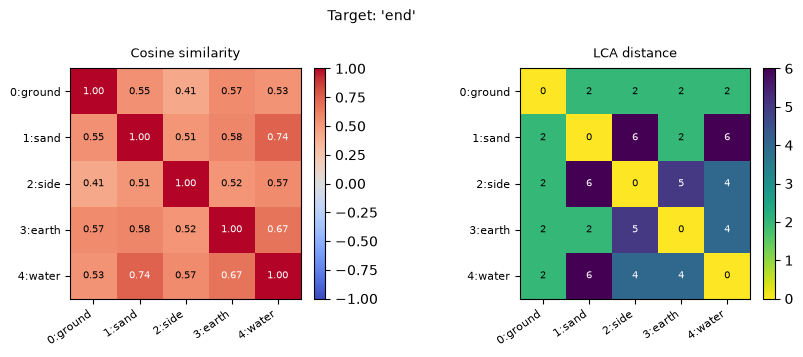


Context: 'Poking out of the end of his' | Target: 'robes'
Top-5        |     0:nose |     1:long |    2:right |      3:pen |     4:left
-----------------------------------------------------------------------------
0:nose       |     1.0000 |     0.6132 |     0.7315 |     0.7532 |     0.6807
1:long       |     0.6132 |     1.0000 |     0.5760 |     0.5916 |     0.5001
2:right      |     0.7315 |     0.5760 |     1.0000 |     0.6558 |     0.7522
3:pen        |     0.7532 |     0.5916 |     0.6558 |     1.0000 |     0.5952
4:left       |     0.6807 |     0.5001 |     0.7522 |     0.5952 |     1.0000


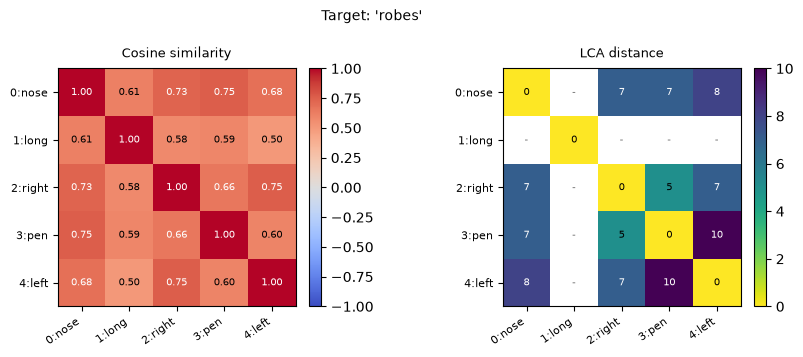


Context: 'Poking out of the end of his robes was what' | Target: 'looked'
Top-5        |     0:looked |   1:appeared |     2:seemed |   3:remained |       4:kind
---------------------------------------------------------------------------------------
0:looked     |       1.0000 |       0.7944 |       0.8034 |       0.7613 |       0.7883
1:appeared   |       0.7944 |       1.0000 |       0.7300 |       0.7349 |       0.7120
2:seemed     |       0.8034 |       0.7300 |       1.0000 |       0.8438 |       0.7970
3:remained   |       0.7613 |       0.7349 |       0.8438 |       1.0000 |       0.7820
4:kind       |       0.7883 |       0.7120 |       0.7970 |       0.7820 |       1.0000


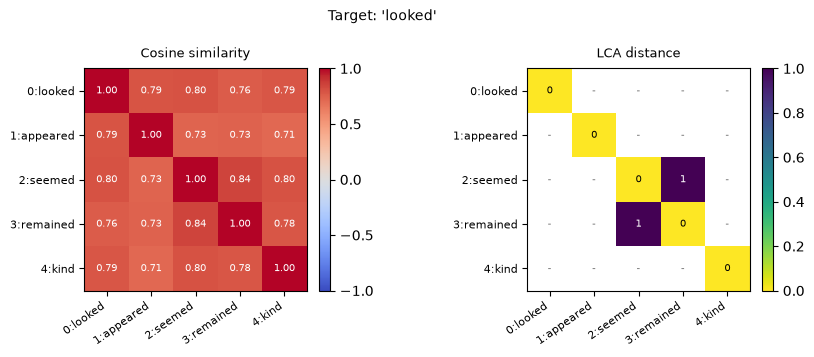


Context: 'Poking out of the end of his robes was what looked like a' | Target: 'thick,'
Top-5        |     0:long |    1:small |    2:large |     3:pair |    4:piece
-----------------------------------------------------------------------------
0:long       |     1.0000 |     0.5936 |     0.6455 |     0.4094 |     0.5983
1:small      |     0.5936 |     1.0000 |     0.8865 |     0.5373 |     0.7082
2:large      |     0.6455 |     0.8865 |     1.0000 |     0.5723 |     0.7776
3:pair       |     0.4094 |     0.5373 |     0.5723 |     1.0000 |     0.6235
4:piece      |     0.5983 |     0.7082 |     0.7776 |     0.6235 |     1.0000


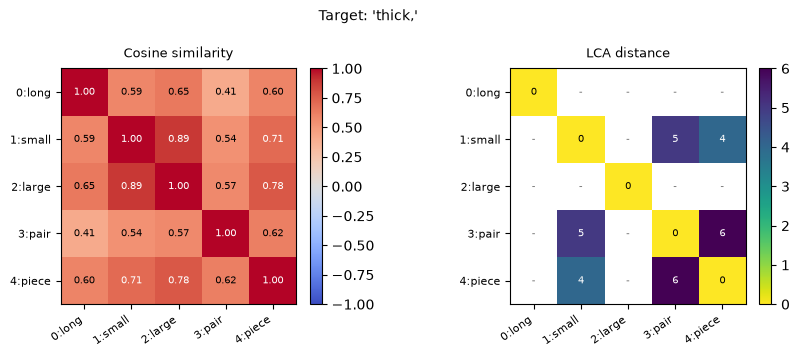


Context: 'Poking out of the end of his robes was what looked like a thick,' | Target: 'fleshcolored'
Top-5        |     0:black |   1:leather |     2:white |     3:brown |      4:dark
----------------------------------------------------------------------------------
0:black      |      1.0000 |      0.7307 |      0.8499 |      0.7317 |      0.8582
1:leather    |      0.7307 |      1.0000 |      0.6855 |      0.6552 |      0.7003
2:white      |      0.8499 |      0.6855 |      1.0000 |      0.7828 |      0.7648
3:brown      |      0.7317 |      0.6552 |      0.7828 |      1.0000 |      0.7039
4:dark       |      0.8582 |      0.7003 |      0.7648 |      0.7039 |      1.0000


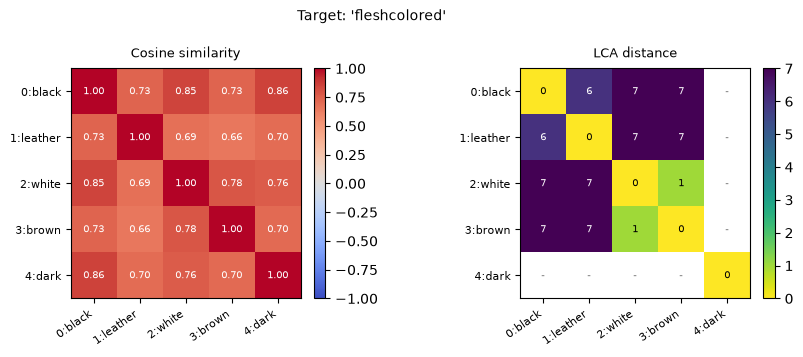


Context: 'Poking out of the end of his robes was what looked like a thick, fleshcolored' | Target: 'rubber'
Top-5        |      0:tent |      1:tube |    2:finger |       3:rod |   4:sausage
----------------------------------------------------------------------------------
0:tent       |      1.0000 |      0.6963 |      0.6848 |      0.6738 |      0.6187
1:tube       |      0.6963 |      1.0000 |      0.8054 |      0.7203 |      0.7321
2:finger     |      0.6848 |      0.8054 |      1.0000 |      0.7311 |      0.7075
3:rod        |      0.6738 |      0.7203 |      0.7311 |      1.0000 |      0.6209
4:sausage    |      0.6187 |      0.7321 |      0.7075 |      0.6209 |      1.0000


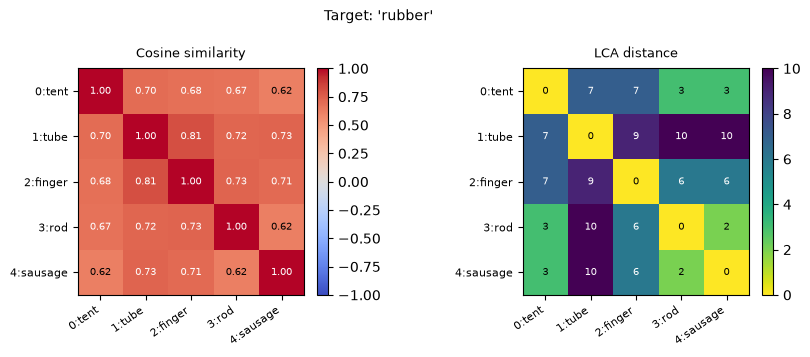


Context: 'Poking out of the end of his robes was what looked like a thick, fleshcolored rubber' | Target: 'glove.'
Top-5        |     0:hose |     1:band |     2:tube |    3:glove |   4:finger
-----------------------------------------------------------------------------
0:hose       |     1.0000 |     0.6626 |     0.8454 |     0.8383 |     0.7625
1:band       |     0.6626 |     1.0000 |     0.7135 |     0.6914 |     0.6608
2:tube       |     0.8454 |     0.7135 |     1.0000 |     0.8315 |     0.8054
3:glove      |     0.8383 |     0.6914 |     0.8315 |     1.0000 |     0.8107
4:finger     |     0.7625 |     0.6608 |     0.8054 |     0.8107 |     1.0000


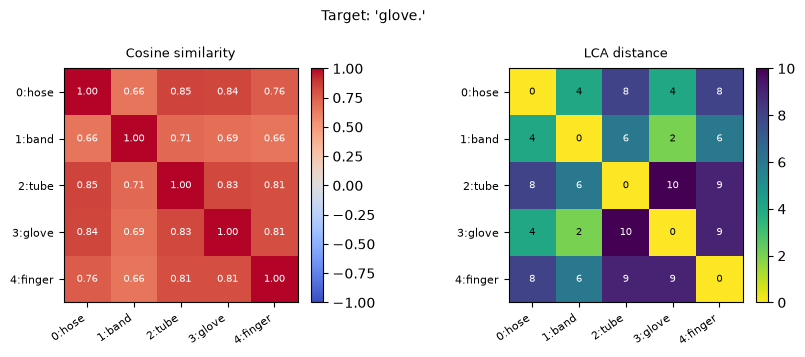


Context: 'He tried to' | Target: 'move'
Top-5        |      0:find |   1:explain |      2:keep |      3:take |      4:stop
----------------------------------------------------------------------------------
0:find       |      1.0000 |      0.7613 |      0.6883 |      0.7456 |      0.7035
1:explain    |      0.7613 |      1.0000 |      0.7848 |      0.7979 |      0.7413
2:keep       |      0.6883 |      0.7848 |      1.0000 |      0.7840 |      0.7371
3:take       |      0.7456 |      0.7979 |      0.7840 |      1.0000 |      0.7357
4:stop       |      0.7035 |      0.7413 |      0.7371 |      0.7357 |      1.0000


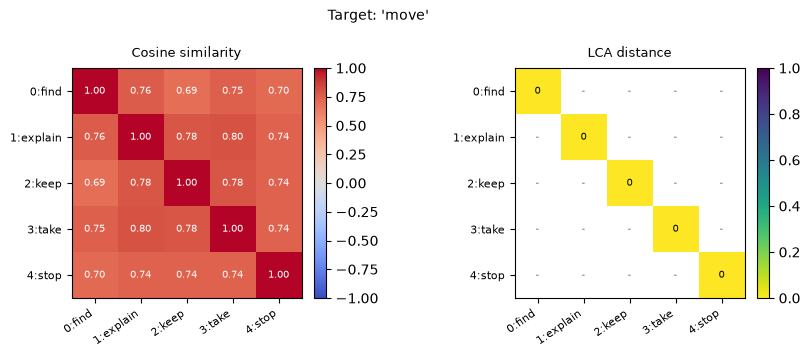


Context: 'He tried to move his' | Target: 'fingers.'
Top-5        |     0:legs |      1:leg |     2:hand |     3:body |      4:arm
-----------------------------------------------------------------------------
0:legs       |     1.0000 |     0.8392 |     0.6543 |     0.7509 |     0.7179
1:leg        |     0.8392 |     1.0000 |     0.6902 |     0.7376 |     0.7126
2:hand       |     0.6543 |     0.6902 |     1.0000 |     0.7126 |     0.7849
3:body       |     0.7509 |     0.7376 |     0.7126 |     1.0000 |     0.7037
4:arm        |     0.7179 |     0.7126 |     0.7849 |     0.7037 |     1.0000


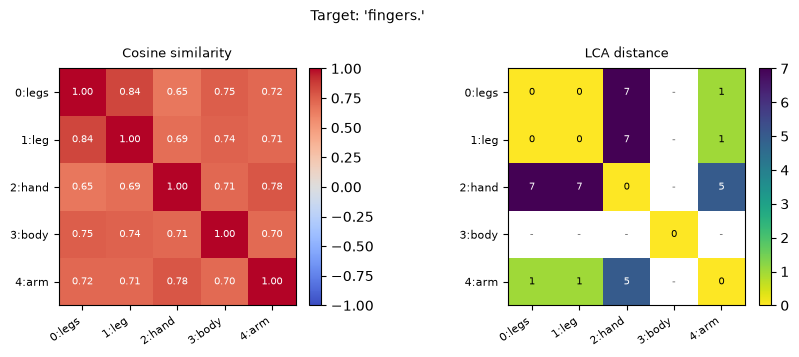


Context: 'Nothing' | Target: 'happened.'
Top-5        |      0:makes |       1:else |       2:gets |   3:happened |       4:goes
---------------------------------------------------------------------------------------
0:makes      |       1.0000 |       0.6526 |       0.8070 |       0.7726 |       0.7163
1:else       |       0.6526 |       1.0000 |       0.6447 |       0.6693 |       0.6955
2:gets       |       0.8070 |       0.6447 |       1.0000 |       0.7438 |       0.8125
3:happened   |       0.7726 |       0.6693 |       0.7438 |       1.0000 |       0.7685
4:goes       |       0.7163 |       0.6955 |       0.8125 |       0.7685 |       1.0000


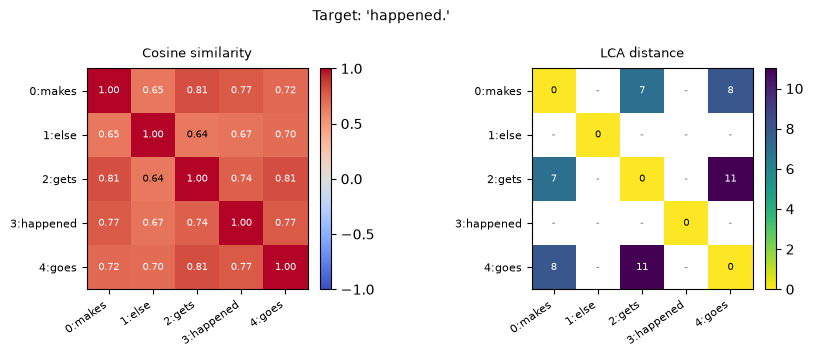


Context: 'Lockhart' | Target: 'hadn’t'
Top-5             |         0:company |     1:corporation |             2:inc |   3:manufacturing |      4:industries
---------------------------------------------------------------------------------------------------------------------
0:company         |            1.0000 |            0.7605 |            0.7692 |            0.7097 |            0.6464
1:corporation     |            0.7605 |            1.0000 |            0.7636 |            0.7542 |            0.7161
2:inc             |            0.7692 |            0.7636 |            1.0000 |            0.7119 |            0.6780
3:manufacturing   |            0.7097 |            0.7542 |            0.7119 |            1.0000 |            0.8371
4:industries      |            0.6464 |            0.7161 |            0.6780 |            0.8371 |            1.0000


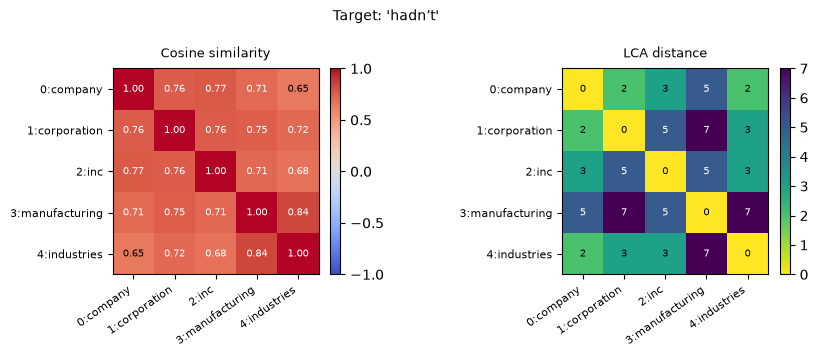


Context: 'Lockhart hadn’t' | Target: 'mended'
Top-5        |      0:seen |    1:really |   2:thought |     3:given |       4:yet
----------------------------------------------------------------------------------
0:seen       |      1.0000 |      0.6821 |      0.7386 |      0.7840 |      0.5485
1:really     |      0.6821 |      1.0000 |      0.6092 |      0.6177 |      0.5813
2:thought    |      0.7386 |      0.6092 |      1.0000 |      0.6478 |      0.4958
3:given      |      0.7840 |      0.6177 |      0.6478 |      1.0000 |      0.5435
4:yet        |      0.5485 |      0.5813 |      0.4958 |      0.5435 |      1.0000


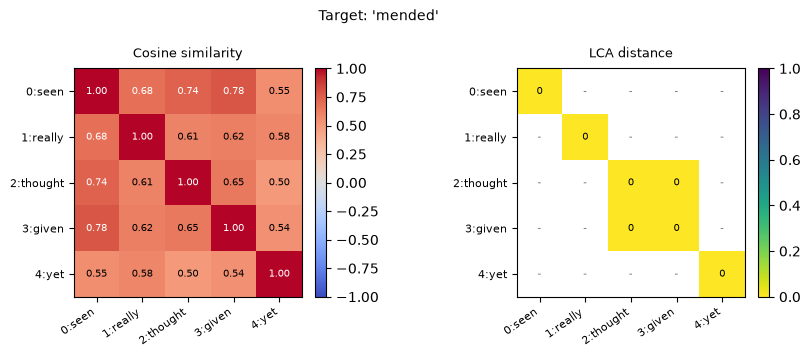


Context: 'Lockhart hadn’t mended' | Target: 'Harry’s'
Top-5          |        0:since |          1:yet |   2:completely |       3:enough |     4:anything
---------------------------------------------------------------------------------------------------
0:since        |         1.0000 |         0.5389 |         0.6374 |         0.5512 |         0.6102
1:yet          |         0.5389 |         1.0000 |         0.6539 |         0.6126 |         0.5375
2:completely   |         0.6374 |         0.6539 |         1.0000 |         0.6626 |         0.7142
3:enough       |         0.5512 |         0.6126 |         0.6626 |         1.0000 |         0.6013
4:anything     |         0.6102 |         0.5375 |         0.7142 |         0.6013 |         1.0000


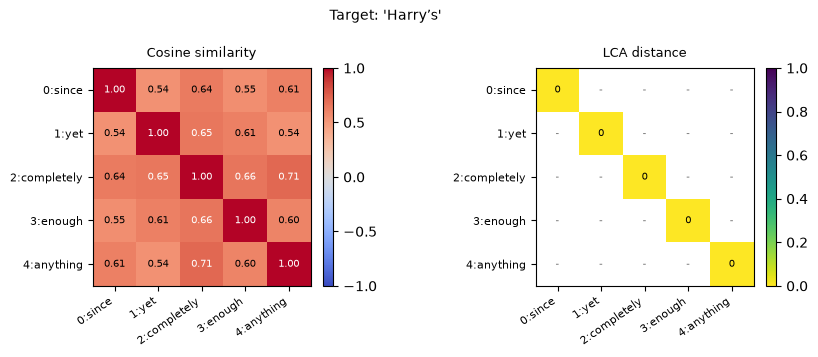


Context: 'Lockhart hadn’t mended Harry’s' | Target: 'bones.'
Top-5        |      0:arm |     1:wand |     2:scar |      3:leg |      4:bro
-----------------------------------------------------------------------------
0:arm        |     1.0000 |     0.6356 |     0.6253 |     0.7126 |     0.6208
1:wand       |     0.6356 |     1.0000 |     0.7499 |     0.6373 |     0.7930
2:scar       |     0.6253 |     0.7499 |     1.0000 |     0.6014 |     0.6906
3:leg        |     0.7126 |     0.6373 |     0.6014 |     1.0000 |     0.6530
4:bro        |     0.6208 |     0.7930 |     0.6906 |     0.6530 |     1.0000


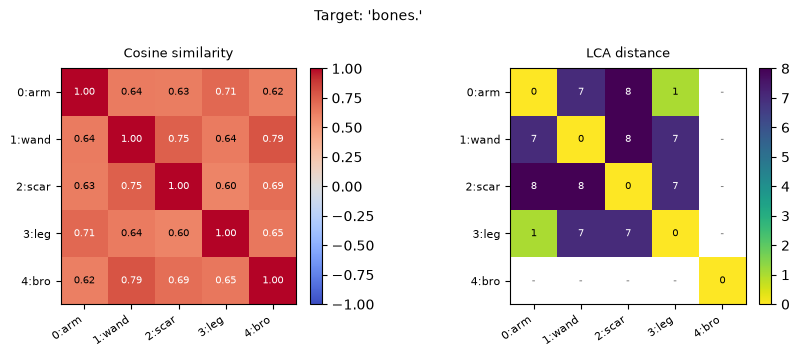


Context: 'Madam' | Target: 'Pomfrey'
Top-5         |     0:speaker |   1:president |       2:chair |   3:secretary |     4:justice
---------------------------------------------------------------------------------------------
0:speaker     |        1.0000 |        0.6683 |        0.6981 |        0.5919 |        0.5752
1:president   |        0.6683 |        1.0000 |        0.7323 |        0.7542 |        0.6381
2:chair       |        0.6981 |        0.7323 |        1.0000 |        0.6804 |        0.6410
3:secretary   |        0.5919 |        0.7542 |        0.6804 |        1.0000 |        0.6285
4:justice     |        0.5752 |        0.6381 |        0.6410 |        0.6285 |        1.0000


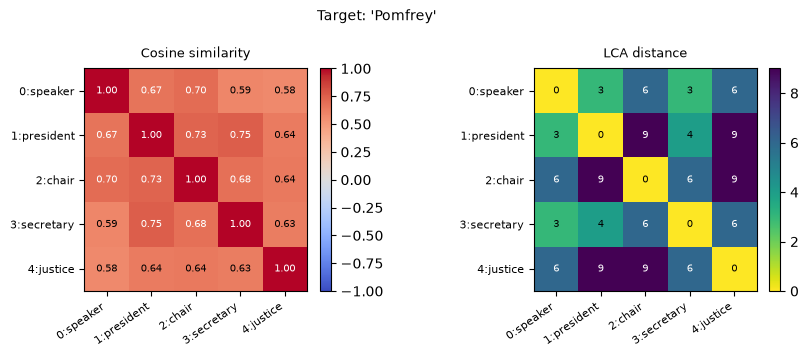


Context: 'Madam Pomfrey' | Target: 'wasn’t'
Top-5        |     0:gave |   1:always |     2:told |    3:often |     4:uses
-----------------------------------------------------------------------------
0:gave       |     1.0000 |     0.7445 |     0.8530 |     0.7048 |     0.6898
1:always     |     0.7445 |     1.0000 |     0.7817 |     0.7891 |     0.6429
2:told       |     0.8530 |     0.7817 |     1.0000 |     0.7566 |     0.6330
3:often      |     0.7048 |     0.7891 |     0.7566 |     1.0000 |     0.6764
4:uses       |     0.6898 |     0.6429 |     0.6330 |     0.6764 |     1.0000


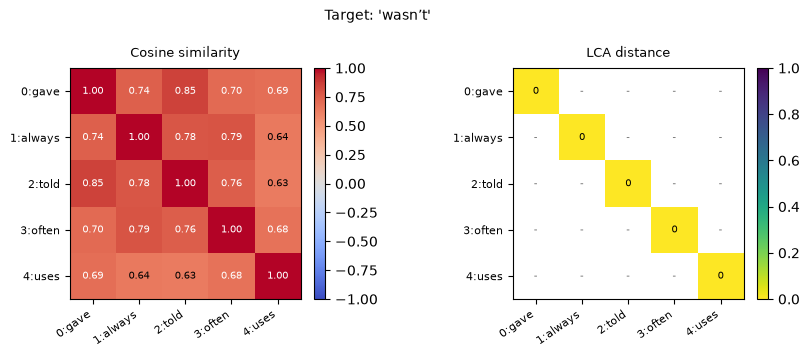


Context: '“You should have' | Target: 'come'
Top-5        |     0:seen |     1:told |     2:read |    3:asked |      4:put
-----------------------------------------------------------------------------
0:seen       |     1.0000 |     0.7765 |     0.7422 |     0.6511 |     0.7424
1:told       |     0.7765 |     1.0000 |     0.7315 |     0.7171 |     0.7953
2:read       |     0.7422 |     0.7315 |     1.0000 |     0.5943 |     0.7927
3:asked      |     0.6511 |     0.7171 |     0.5943 |     1.0000 |     0.5691
4:put        |     0.7424 |     0.7953 |     0.7927 |     0.5691 |     1.0000


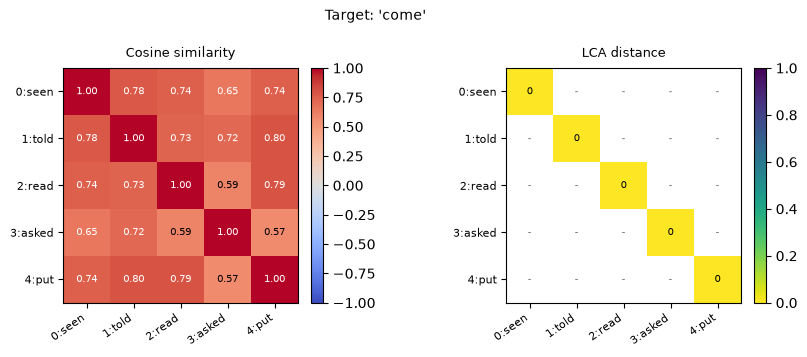


Context: '“You should have come' | Target: 'straight'
Top-5         |        0:last |       1:along |   2:yesterday |        3:back |        4:home
---------------------------------------------------------------------------------------------
0:last        |        1.0000 |        0.6982 |        0.6758 |        0.7534 |        0.4925
1:along       |        0.6982 |        1.0000 |        0.5378 |        0.7404 |        0.5074
2:yesterday   |        0.6758 |        0.5378 |        1.0000 |        0.6191 |        0.3990
3:back        |        0.7534 |        0.7404 |        0.6191 |        1.0000 |        0.5288
4:home        |        0.4925 |        0.5074 |        0.3990 |        0.5288 |        1.0000


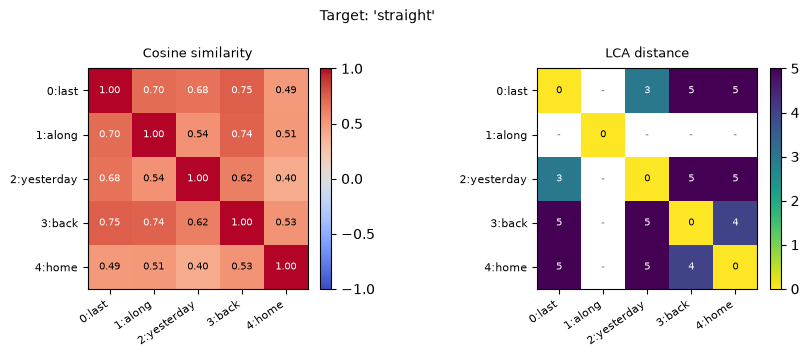


Context: '“You should have come straight to me!” she' | Target: 'raged,'
Top-5         |   0:exclaimed |        1:told |       2:cried |          3:sc |     4:snapped
---------------------------------------------------------------------------------------------
0:exclaimed   |        1.0000 |        0.4794 |        0.6990 |        0.4238 |        0.7967
1:told        |        0.4794 |        1.0000 |        0.7340 |        0.6331 |        0.5689
2:cried       |        0.6990 |        0.7340 |        1.0000 |        0.5220 |        0.7010
3:sc          |        0.4238 |        0.6331 |        0.5220 |        1.0000 |        0.4825
4:snapped     |        0.7967 |        0.5689 |        0.7010 |        0.4825 |        1.0000


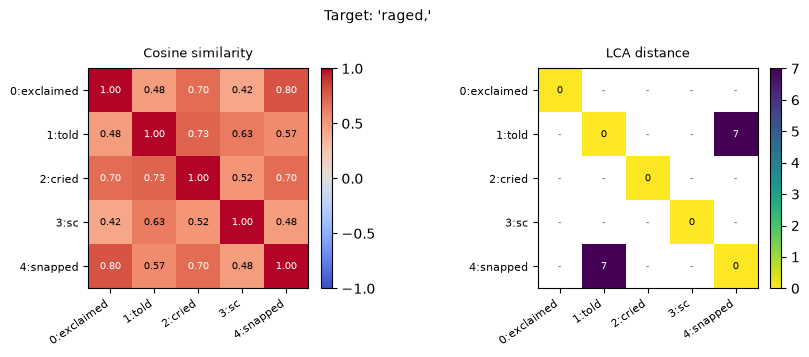


Context: '“You should have come straight to me!” she raged,' | Target: 'holding'
Top-5        |      0:tears |   1:pointing |   2:throwing |     3:waving |   4:slamming
---------------------------------------------------------------------------------------
0:tears      |       1.0000 |       0.5954 |       0.6291 |       0.6692 |       0.5891
1:pointing   |       0.5954 |       1.0000 |       0.8006 |       0.8334 |       0.7393
2:throwing   |       0.6291 |       0.8006 |       1.0000 |       0.8728 |       0.8347
3:waving     |       0.6692 |       0.8334 |       0.8728 |       1.0000 |       0.8393
4:slamming   |       0.5891 |       0.7393 |       0.8347 |       0.8393 |       1.0000


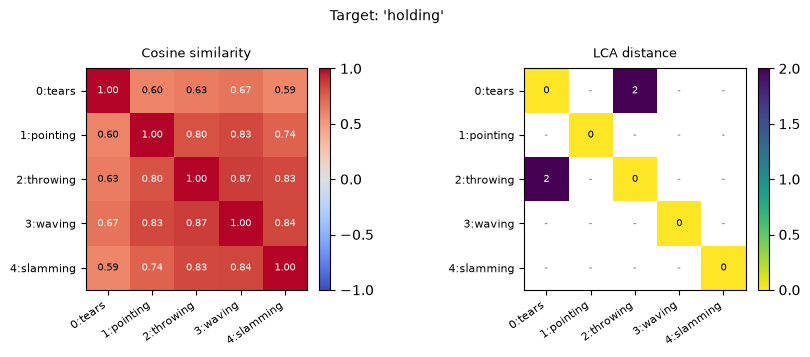


Context: '“You should have come straight to me!” she raged, holding up the sad,' | Target: 'limp'
Top-5        |    0:empty |   1:yellow |       2:cr |   3:little |     4:pale
-----------------------------------------------------------------------------
0:empty      |     1.0000 |     0.5918 |     0.5540 |     0.5527 |     0.6565
1:yellow     |     0.5918 |     1.0000 |     0.6584 |     0.5667 |     0.6868
2:cr         |     0.5540 |     0.6584 |     1.0000 |     0.5824 |     0.6526
3:little     |     0.5527 |     0.5667 |     0.5824 |     1.0000 |     0.6704
4:pale       |     0.6565 |     0.6868 |     0.6526 |     0.6704 |     1.0000


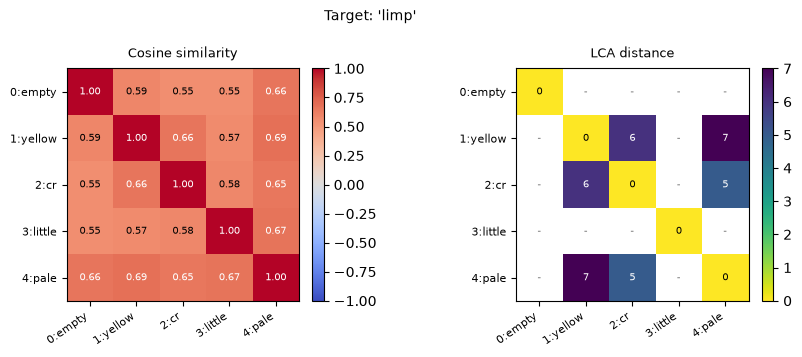


Context: '“You should have come straight to me!” she raged, holding up the sad, limp' | Target: 'remainder'
Top-5        |      0:body |     1:paper |   2:remains |    3:flower |   4:flowers
----------------------------------------------------------------------------------
0:body       |      1.0000 |      0.5358 |      0.6166 |      0.5801 |      0.5388
1:paper      |      0.5358 |      1.0000 |      0.6399 |      0.5353 |      0.5650
2:remains    |      0.6166 |      0.6399 |      1.0000 |      0.5527 |      0.5557
3:flower     |      0.5801 |      0.5353 |      0.5527 |      1.0000 |      0.8923
4:flowers    |      0.5388 |      0.5650 |      0.5557 |      0.8923 |      1.0000


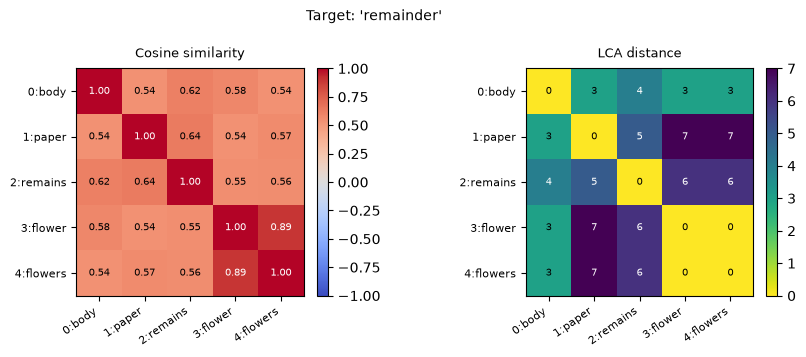


Context: '“You should have come straight to me!” she raged, holding up the sad, limp remainder of what,' | Target: 'half'
Top-5         |     0:moments |     1:minutes |        2:mere |   3:yesterday |        4:last
---------------------------------------------------------------------------------------------
0:moments     |        1.0000 |        0.8234 |        0.7069 |        0.6890 |        0.6887
1:minutes     |        0.8234 |        1.0000 |        0.5207 |        0.5566 |        0.5071
2:mere        |        0.7069 |        0.5207 |        1.0000 |        0.6761 |        0.6993
3:yesterday   |        0.6890 |        0.5566 |        0.6761 |        1.0000 |        0.6758
4:last        |        0.6887 |        0.5071 |        0.6993 |        0.6758 |        1.0000


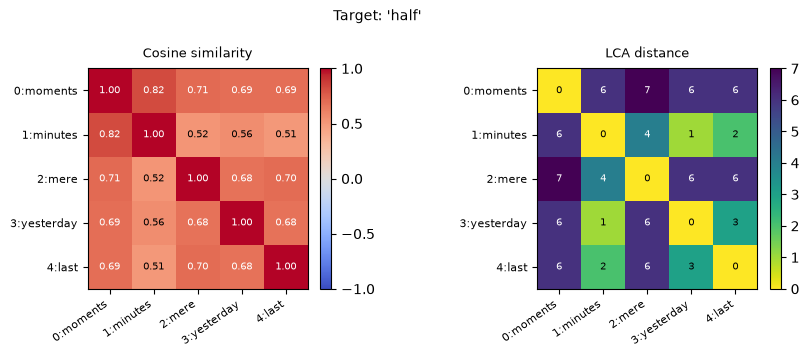


Context: '“You should have come straight to me!” she raged, holding up the sad, limp remainder of what, half an' | Target: 'hour'
Top-5        |      0:hour |   1:instant |      2:inch |   3:century |    4:minute
----------------------------------------------------------------------------------
0:hour       |      1.0000 |      0.6873 |      0.7292 |      0.6379 |      0.8564
1:instant    |      0.6873 |      1.0000 |      0.6502 |      0.5709 |      0.7340
2:inch       |      0.7292 |      0.6502 |      1.0000 |      0.5810 |      0.7424
3:century    |      0.6379 |      0.5709 |      0.5810 |      1.0000 |      0.6229
4:minute     |      0.8564 |      0.7340 |      0.7424 |      0.6229 |      1.0000


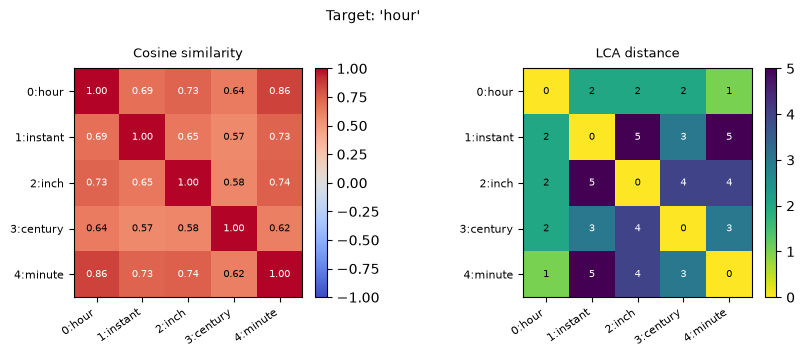


Context: '“You should have come straight to me!” she raged, holding up the sad, limp remainder of what, half an hour before, had been a' | Target: 'working'
Top-5         |   0:perfectly |        1:fine |     2:perfect |        3:full |       4:large
---------------------------------------------------------------------------------------------
0:perfectly   |        1.0000 |        0.7555 |        0.8504 |        0.7374 |        0.7811
1:fine        |        0.7555 |        1.0000 |        0.7832 |        0.5901 |        0.6641
2:perfect     |        0.8504 |        0.7832 |        1.0000 |        0.6808 |        0.6491
3:full        |        0.7374 |        0.5901 |        0.6808 |        1.0000 |        0.7434
4:large       |        0.7811 |        0.6641 |        0.6491 |        0.7434 |        1.0000


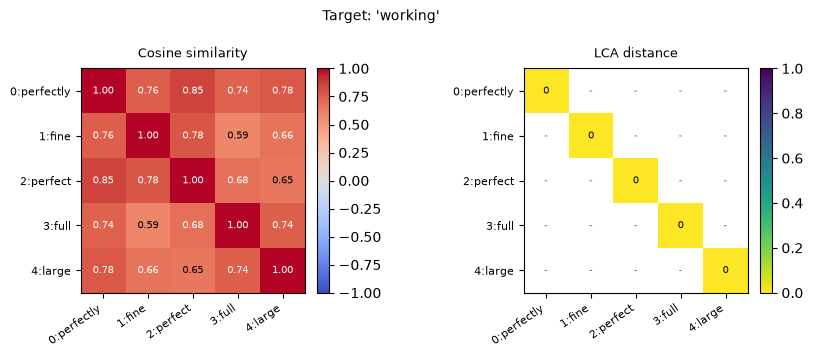


Context: '“You should have come straight to me!” she raged, holding up the sad, limp remainder of what, half an hour before, had been a working' | Target: 'arm.'
Top-5        |       0:copy |   1:document |      2:lunch |      3:model |      4:draft
---------------------------------------------------------------------------------------
0:copy       |       1.0000 |       0.6338 |       0.4220 |       0.5306 |       0.5263
1:document   |       0.6338 |       1.0000 |       0.5354 |       0.6833 |       0.6092
2:lunch      |       0.4220 |       0.5354 |       1.0000 |       0.4887 |       0.4450
3:model      |       0.5306 |       0.6833 |       0.4887 |       1.0000 |       0.5865
4:draft      |       0.5263 |       0.6092 |       0.4450 |       0.5865 |       1.0000


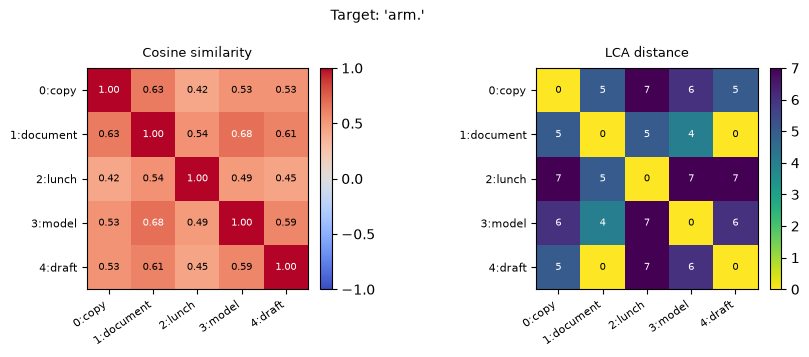


Context: '“I can' | Target: 'mend'
Top-5        |      0:see |    1:still |    2:think |   3:hardly |     4:tell
-----------------------------------------------------------------------------
0:see        |     1.0000 |     0.3647 |     0.6476 |     0.7148 |     0.6450
1:still      |     0.3647 |     1.0000 |     0.3449 |     0.4718 |     0.4279
2:think      |     0.6476 |     0.3449 |     1.0000 |     0.5847 |     0.6616
3:hardly     |     0.7148 |     0.4718 |     0.5847 |     1.0000 |     0.7100
4:tell       |     0.6450 |     0.4279 |     0.6616 |     0.7100 |     1.0000


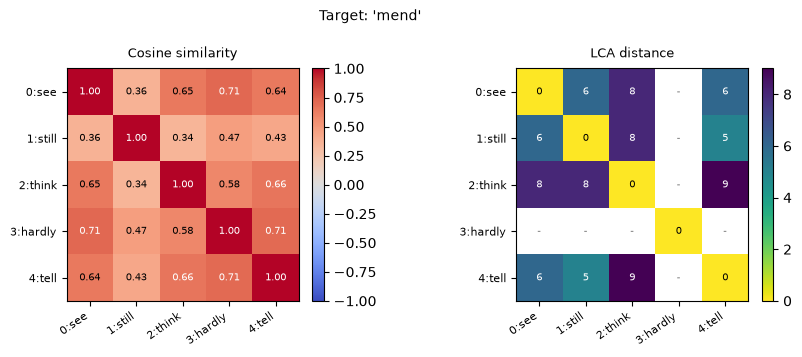


Context: '“I can mend' | Target: 'bones'
Top-5        |   0:anything |     1:fences |      2:socks |     3:things |    4:clothes
---------------------------------------------------------------------------------------
0:anything   |       1.0000 |       0.6595 |       0.6004 |       0.6958 |       0.6708
1:fences     |       0.6595 |       1.0000 |       0.7127 |       0.7239 |       0.7535
2:socks      |       0.6004 |       0.7127 |       1.0000 |       0.6687 |       0.8146
3:things     |       0.6958 |       0.7239 |       0.6687 |       1.0000 |       0.7814
4:clothes    |       0.6708 |       0.7535 |       0.8146 |       0.7814 |       1.0000


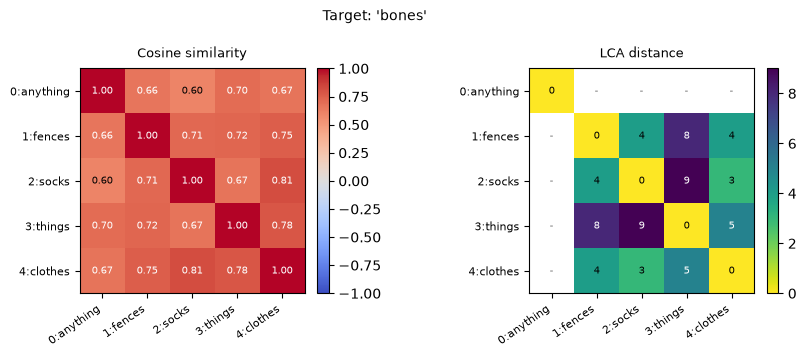


Context: '“I can mend bones in a' | Target: 'second'
Top-5        |      0:day |   1:matter |   2:minute |    3:human |     4:week
-----------------------------------------------------------------------------
0:day        |     1.0000 |     0.5716 |     0.6251 |     0.4849 |     0.6772
1:matter     |     0.5716 |     1.0000 |     0.7128 |     0.5622 |     0.5903
2:minute     |     0.6251 |     0.7128 |     1.0000 |     0.5308 |     0.6395
3:human      |     0.4849 |     0.5622 |     0.5308 |     1.0000 |     0.5187
4:week       |     0.6772 |     0.5903 |     0.6395 |     0.5187 |     1.0000


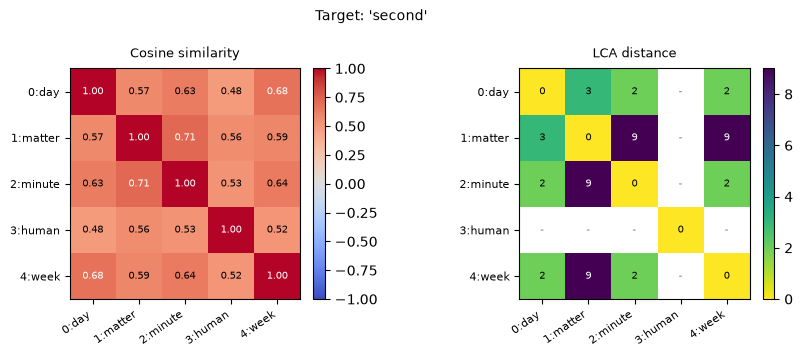


Context: '“I can mend bones in a second — but' | Target: 'growing'
Top-5         |       0:first |      1:people |   2:sometimes |        3:time |      4:hearts
---------------------------------------------------------------------------------------------
0:first       |        1.0000 |        0.5699 |        0.5919 |        0.6255 |        0.5675
1:people      |        0.5699 |        1.0000 |        0.6108 |        0.6705 |        0.7151
2:sometimes   |        0.5919 |        0.6108 |        1.0000 |        0.6945 |        0.6188
3:time        |        0.6255 |        0.6705 |        0.6945 |        1.0000 |        0.7156
4:hearts      |        0.5675 |        0.7151 |        0.6188 |        0.7156 |        1.0000


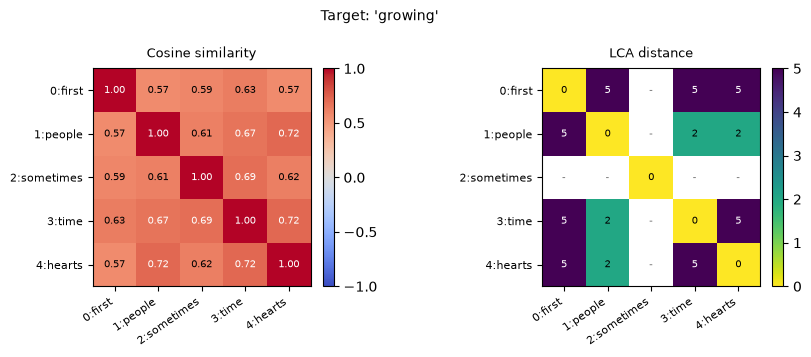


Context: '“I can mend bones in a second — but growing them' | Target: 'back'
Top-5        |      0:takes |       1:back |      2:costs |   3:properly |   4:requires
---------------------------------------------------------------------------------------
0:takes      |       1.0000 |       0.6396 |       0.6104 |       0.7367 |       0.7730
1:back       |       0.6396 |       1.0000 |       0.5521 |       0.6462 |       0.6181
2:costs      |       0.6104 |       0.5521 |       1.0000 |       0.6619 |       0.7223
3:properly   |       0.7367 |       0.6462 |       0.6619 |       1.0000 |       0.8374
4:requires   |       0.7730 |       0.6181 |       0.7223 |       0.8374 |       1.0000


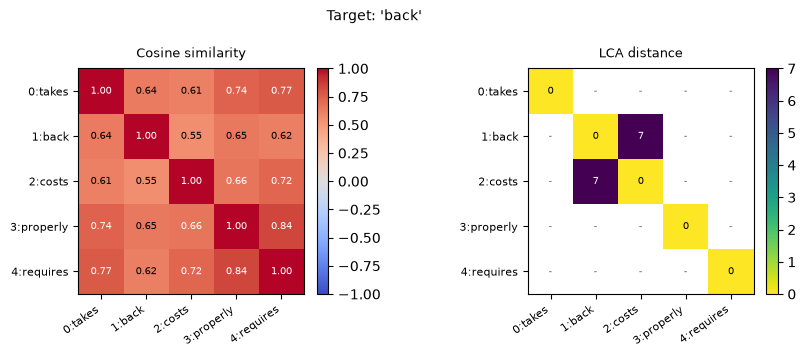


Context: '“I can mend bones in a second — but growing them back —” “You will be able to, won’t you?” said' | Target: 'Harry'
Top-5        |      0:alice |        1:san |   2:hermione |          3:g |         4:al
---------------------------------------------------------------------------------------
0:alice      |       1.0000 |       0.5896 |       0.3936 |       0.6025 |       0.6449
1:san        |       0.5896 |       1.0000 |       0.3334 |       0.5495 |       0.5737
2:hermione   |       0.3936 |       0.3334 |       1.0000 |       0.2536 |       0.2882
3:g          |       0.6025 |       0.5495 |       0.2536 |       1.0000 |       0.6909
4:al         |       0.6449 |       0.5737 |       0.2882 |       0.6909 |       1.0000


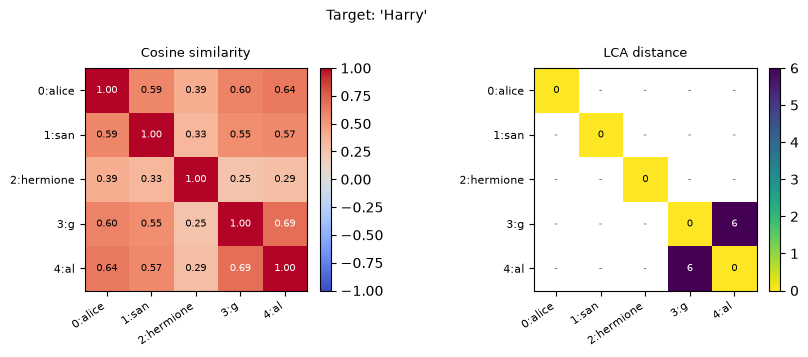


Context: '“I can mend bones in a second — but growing them back —” “You will be able to, won’t you?” said Harry' | Target: 'desperately.'
Top-5         |     0:eagerly |   1:hopefully |         2:anx |         3:cur |       4:doubt
---------------------------------------------------------------------------------------------
0:eagerly     |        1.0000 |        0.7441 |        0.4528 |        0.4754 |        0.6569
1:hopefully   |        0.7441 |        1.0000 |        0.4136 |        0.4333 |        0.6707
2:anx         |        0.4528 |        0.4136 |        1.0000 |        0.4710 |        0.4907
3:cur         |        0.4754 |        0.4333 |        0.4710 |        1.0000 |        0.4832
4:doubt       |        0.6569 |        0.6707 |        0.4907 |        0.4832 |        1.0000


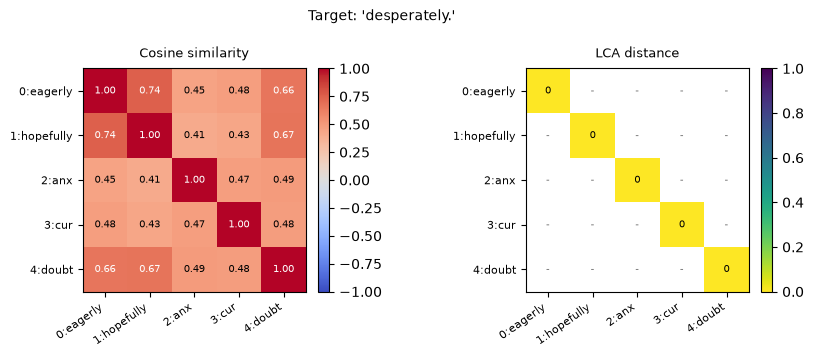


Context: '“I’ll be able to,' | Target: 'certainly,'
Top-5        |    0:thank |     1:yeah |    2:maybe |   3:though |      4:yes
-----------------------------------------------------------------------------
0:thank      |     1.0000 |     0.6341 |     0.5543 |     0.5410 |     0.6698
1:yeah       |     0.6341 |     1.0000 |     0.6598 |     0.5513 |     0.8278
2:maybe      |     0.5543 |     0.6598 |     1.0000 |     0.6096 |     0.6254
3:though     |     0.5410 |     0.5513 |     0.6096 |     1.0000 |     0.5785
4:yes        |     0.6698 |     0.8278 |     0.6254 |     0.5785 |     1.0000


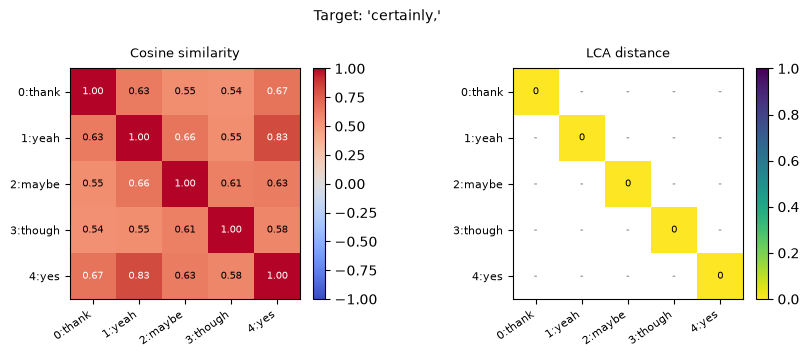


Context: '“I’ll be able to, certainly, but it will be painful,” said' | Target: 'Madam'
Top-5        |       0:mr |       1:dr |   2:former |     3:john |        4:k
-----------------------------------------------------------------------------
0:mr         |     1.0000 |     0.7659 |     0.4712 |     0.6716 |     0.6411
1:dr         |     0.7659 |     1.0000 |     0.4602 |     0.6554 |     0.6156
2:former     |     0.4712 |     0.4602 |     1.0000 |     0.4542 |     0.3767
3:john       |     0.6716 |     0.6554 |     0.4542 |     1.0000 |     0.5915
4:k          |     0.6411 |     0.6156 |     0.3767 |     0.5915 |     1.0000


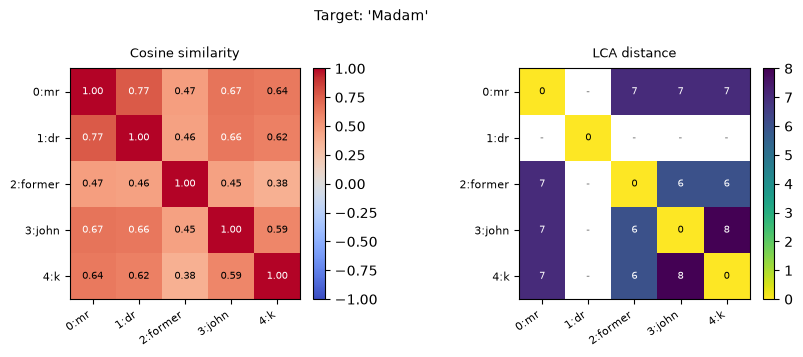


Context: '“I’ll be able to, certainly, but it will be painful,” said Madam' | Target: 'Pomfrey'
Top-5         |   0:secretary |   1:president |    2:minister |           3:c |      4:deputy
---------------------------------------------------------------------------------------------
0:secretary   |        1.0000 |        0.7542 |        0.7365 |        0.4625 |        0.7334
1:president   |        0.7542 |        1.0000 |        0.6546 |        0.5605 |        0.7118
2:minister    |        0.7365 |        0.6546 |        1.0000 |        0.4392 |        0.6663
3:c           |        0.4625 |        0.5605 |        0.4392 |        1.0000 |        0.4823
4:deputy      |        0.7334 |        0.7118 |        0.6663 |        0.4823 |        1.0000


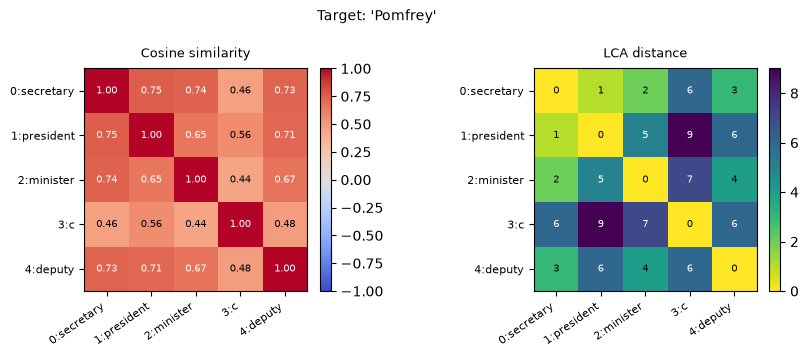


Context: '“I’ll be able to, certainly, but it will be painful,” said Madam Pomfrey' | Target: 'grimly,'
Top-5        |    0:stern |   1:firmly |   2:gently |   3:softly |    4:cheer
-----------------------------------------------------------------------------
0:stern      |     1.0000 |     0.7352 |     0.7117 |     0.6794 |     0.5022
1:firmly     |     0.7352 |     1.0000 |     0.7741 |     0.6880 |     0.5263
2:gently     |     0.7117 |     0.7741 |     1.0000 |     0.8940 |     0.4986
3:softly     |     0.6794 |     0.6880 |     0.8940 |     1.0000 |     0.4834
4:cheer      |     0.5022 |     0.5263 |     0.4986 |     0.4834 |     1.0000


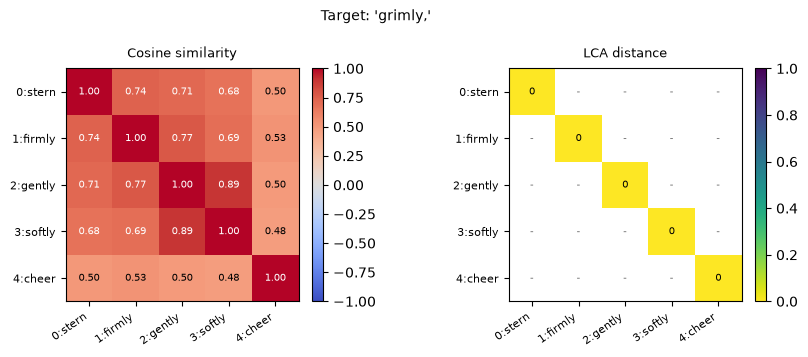


Context: '“I’ll be able to, certainly, but it will be painful,” said Madam Pomfrey grimly,' | Target: 'throwing'
Top-5        |   0:handing |    1:taking |   2:holding |   3:looking |    4:though
----------------------------------------------------------------------------------
0:handing    |      1.0000 |      0.8007 |      0.7865 |      0.7735 |      0.6356
1:taking     |      0.8007 |      1.0000 |      0.8400 |      0.7870 |      0.5747
2:holding    |      0.7865 |      0.8400 |      1.0000 |      0.7725 |      0.5778
3:looking    |      0.7735 |      0.7870 |      0.7725 |      1.0000 |      0.6221
4:though     |      0.6356 |      0.5747 |      0.5778 |      0.6221 |      1.0000


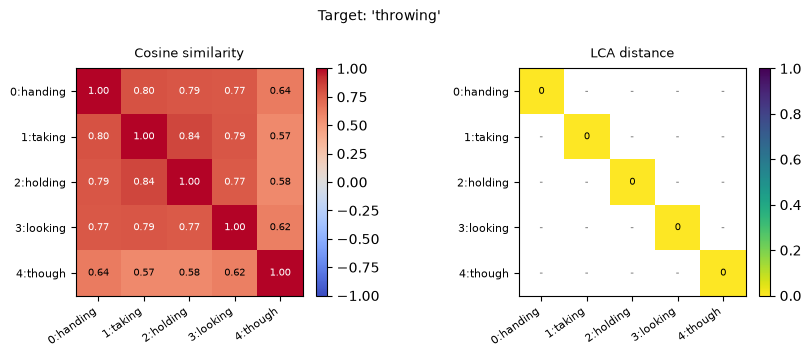


Context: '“I’ll be able to, certainly, but it will be painful,” said Madam Pomfrey grimly, throwing' | Target: 'Harry'
Top-5        |    0:harry |     1:back |     2:open |    3:james |    4:aside
-----------------------------------------------------------------------------
0:harry      |     1.0000 |     0.6842 |     0.5992 |     0.8338 |     0.6462
1:back       |     0.6842 |     1.0000 |     0.5870 |     0.6156 |     0.6310
2:open       |     0.5992 |     0.5870 |     1.0000 |     0.5505 |     0.4783
3:james      |     0.8338 |     0.6156 |     0.5505 |     1.0000 |     0.6055
4:aside      |     0.6462 |     0.6310 |     0.4783 |     0.6055 |     1.0000


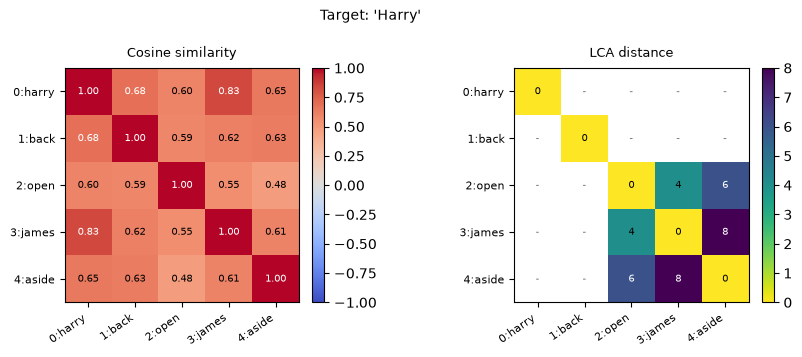


Context: '“I’ll be able to, certainly, but it will be painful,” said Madam Pomfrey grimly, throwing Harry a' | Target: 'pair'
Top-5        |      0:look |     1:stern |      2:pity |   3:warning |      4:long
----------------------------------------------------------------------------------
0:look       |      1.0000 |      0.6486 |      0.6088 |      0.6957 |      0.5109
1:stern      |      0.6486 |      1.0000 |      0.6675 |      0.7314 |      0.5994
2:pity       |      0.6088 |      0.6675 |      1.0000 |      0.6729 |      0.5835
3:warning    |      0.6957 |      0.7314 |      0.6729 |      1.0000 |      0.5477
4:long       |      0.5109 |      0.5994 |      0.5835 |      0.5477 |      1.0000


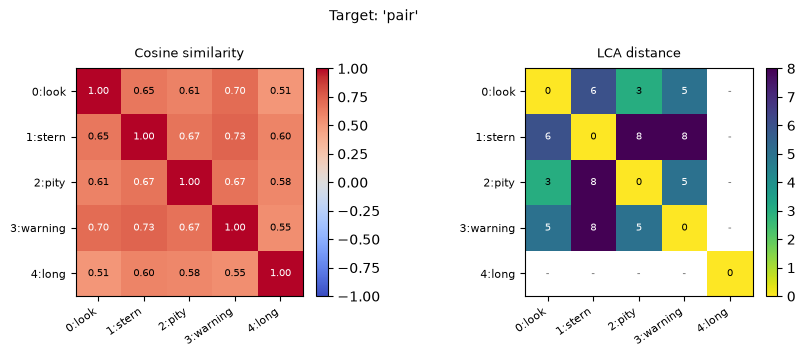


Context: '“I’ll be able to, certainly, but it will be painful,” said Madam Pomfrey grimly, throwing Harry a pair of' | Target: 'pajamas.'
Top-5        |    0:thick |    1:green |    2:heavy |    3:clean |      4:old
-----------------------------------------------------------------------------
0:thick      |     1.0000 |     0.4782 |     0.8262 |     0.7176 |     0.6323
1:green      |     0.4782 |     1.0000 |     0.4624 |     0.5546 |     0.4639
2:heavy      |     0.8262 |     0.4624 |     1.0000 |     0.6653 |     0.6148
3:clean      |     0.7176 |     0.5546 |     0.6653 |     1.0000 |     0.5575
4:old        |     0.6323 |     0.4639 |     0.6148 |     0.5575 |     1.0000


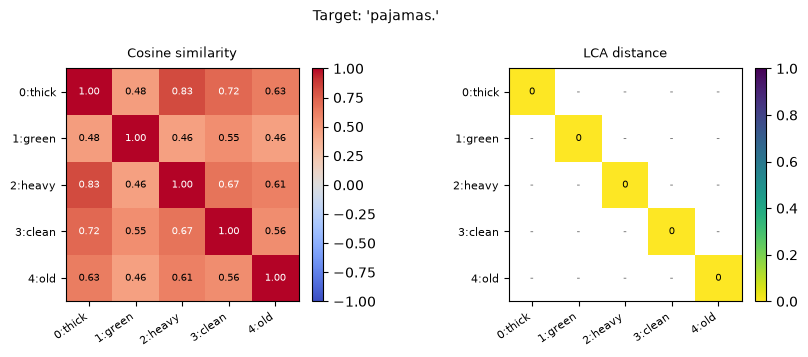


Context: '“You’ll have to' | Target: 'stay'
Top-5        |   0:forgive |    1:excuse |      2:take |      3:wait |       4:pay
----------------------------------------------------------------------------------
0:forgive    |      1.0000 |      0.7116 |      0.6858 |      0.4238 |      0.7150
1:excuse     |      0.7116 |      1.0000 |      0.6976 |      0.6011 |      0.7182
2:take       |      0.6858 |      0.6976 |      1.0000 |      0.5610 |      0.8026
3:wait       |      0.4238 |      0.6011 |      0.5610 |      1.0000 |      0.5672
4:pay        |      0.7150 |      0.7182 |      0.8026 |      0.5672 |      1.0000


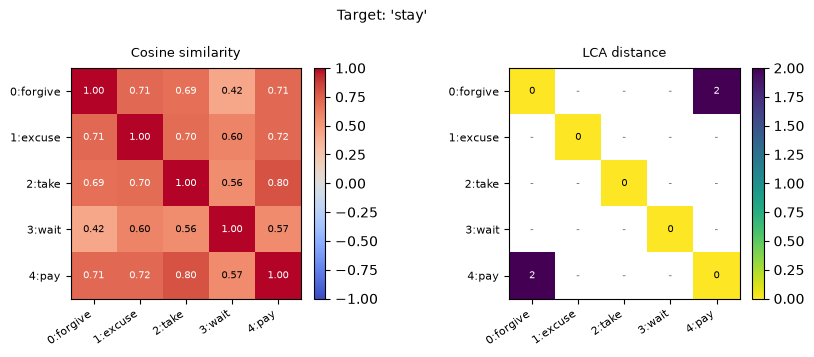


Context: '“You’ll have to stay the' | Target: 'night.'
Top-5        |    0:night |   1:course |    2:whole |    3:extra |   4:entire
-----------------------------------------------------------------------------
0:night      |     1.0000 |     0.4089 |     0.4451 |     0.3571 |     0.4412
1:course     |     0.4089 |     1.0000 |     0.6924 |     0.5172 |     0.6932
2:whole      |     0.4451 |     0.6924 |     1.0000 |     0.5374 |     0.8849
3:extra      |     0.3571 |     0.5172 |     0.5374 |     1.0000 |     0.5488
4:entire     |     0.4412 |     0.6932 |     0.8849 |     0.5488 |     1.0000


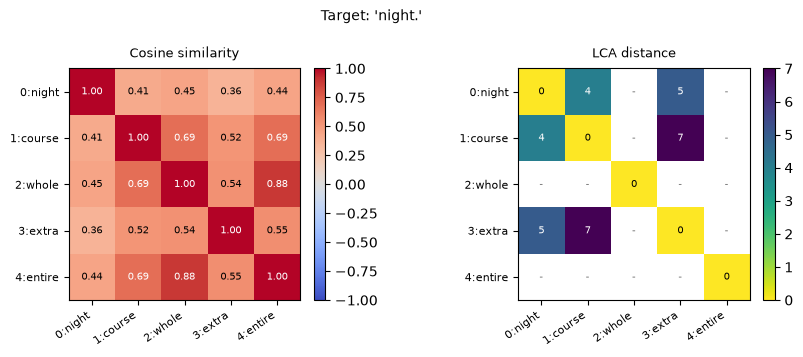


Context: '.” Hermione' | Target: 'waited'
Top-5        |   0:looked |   1:nodded |   2:smiled |   3:sighed |      4:gas
-----------------------------------------------------------------------------
0:looked     |     1.0000 |     0.6208 |     0.7191 |     0.7494 |     0.6408
1:nodded     |     0.6208 |     1.0000 |     0.7258 |     0.6463 |     0.4452
2:smiled     |     0.7191 |     0.7258 |     1.0000 |     0.7770 |     0.5826
3:sighed     |     0.7494 |     0.6463 |     0.7770 |     1.0000 |     0.6049
4:gas        |     0.6408 |     0.4452 |     0.5826 |     0.6049 |     1.0000


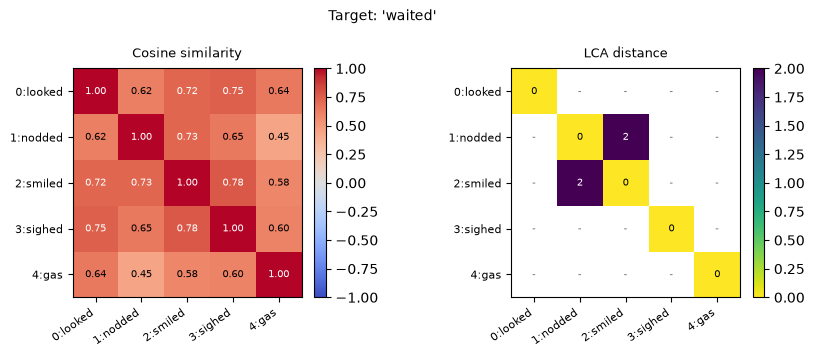


Context: '.” Hermione waited' | Target: 'outside'
Top-5         |      0:expect |   1:patiently |         2:anx |     3:eagerly |        4:till
---------------------------------------------------------------------------------------------
0:expect      |        1.0000 |        0.8285 |        0.4624 |        0.8164 |        0.6708
1:patiently   |        0.8285 |        1.0000 |        0.4496 |        0.8693 |        0.7117
2:anx         |        0.4624 |        0.4496 |        1.0000 |        0.4528 |        0.4851
3:eagerly     |        0.8164 |        0.8693 |        0.4528 |        1.0000 |        0.6929
4:till        |        0.6708 |        0.7117 |        0.4851 |        0.6929 |        1.0000


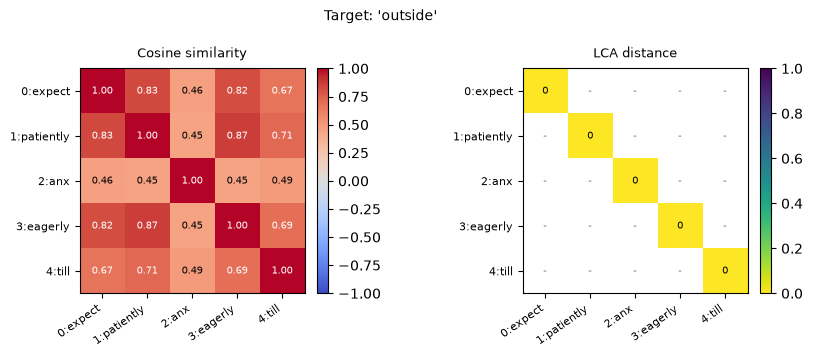


Context: '.” Hermione waited outside the' | Target: 'curtain'
Top-5         |        0:door |        1:room |   2:classroom |    3:bathroom |      4:office
---------------------------------------------------------------------------------------------
0:door        |        1.0000 |        0.7462 |        0.6831 |        0.7178 |        0.7240
1:room        |        0.7462 |        1.0000 |        0.7013 |        0.6959 |        0.7851
2:classroom   |        0.6831 |        0.7013 |        1.0000 |        0.7401 |        0.6797
3:bathroom    |        0.7178 |        0.6959 |        0.7401 |        1.0000 |        0.6384
4:office      |        0.7240 |        0.7851 |        0.6797 |        0.6384 |        1.0000


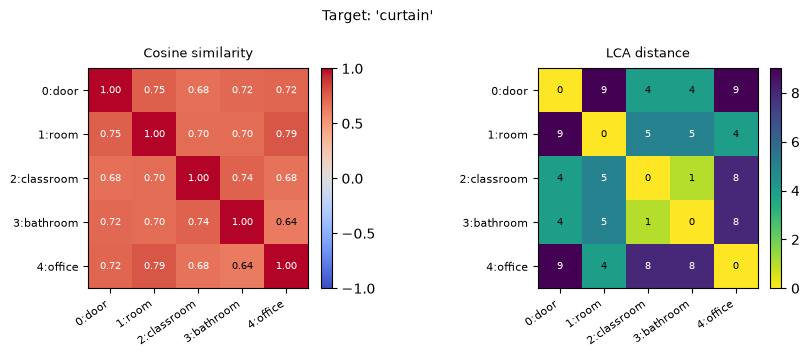


Context: '.” Hermione waited outside the curtain drawn' | Target: 'around'
Top-5        |    0:around |    1:across |     2:round |   3:tightly |      4:shut
----------------------------------------------------------------------------------
0:around     |      1.0000 |      0.7055 |      0.6794 |      0.7449 |      0.6440
1:across     |      0.7055 |      1.0000 |      0.5214 |      0.6570 |      0.5621
2:round      |      0.6794 |      0.5214 |      1.0000 |      0.6263 |      0.6323
3:tightly    |      0.7449 |      0.6570 |      0.6263 |      1.0000 |      0.7652
4:shut       |      0.6440 |      0.5621 |      0.6323 |      0.7652 |      1.0000


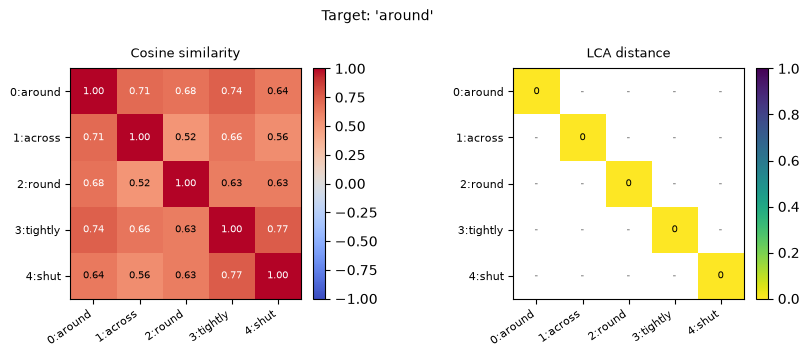


Context: '.” Hermione waited outside the curtain drawn around' | Target: 'Harry’s'
Top-5        |     0:harry |       1:ron |        2:mr |     3:draco |   4:neville
----------------------------------------------------------------------------------
0:harry      |      1.0000 |      0.8624 |      0.7838 |      0.6321 |      0.8123
1:ron        |      0.8624 |      1.0000 |      0.7408 |      0.5808 |      0.7913
2:mr         |      0.7838 |      0.7408 |      1.0000 |      0.5866 |      0.6661
3:draco      |      0.6321 |      0.5808 |      0.5866 |      1.0000 |      0.5979
4:neville    |      0.8123 |      0.7913 |      0.6661 |      0.5979 |      1.0000


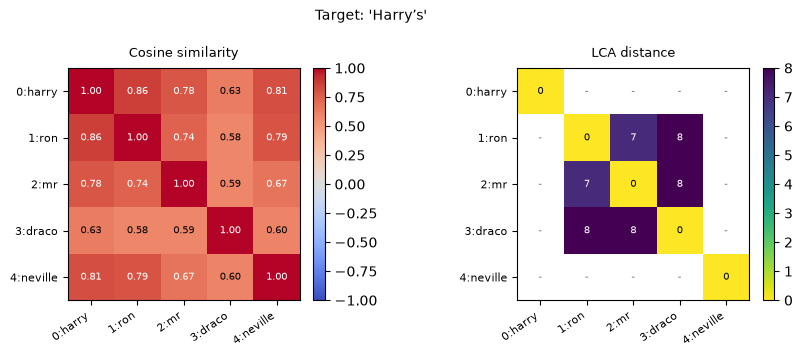


Context: '.” Hermione waited outside the curtain drawn around Harry’s' | Target: 'bed'
Top-5        |        0:bed |   1:hospital |        2:cot |       3:room |       4:four
---------------------------------------------------------------------------------------
0:bed        |       1.0000 |       0.6728 |       0.6352 |       0.7034 |       0.4559
1:hospital   |       0.6728 |       1.0000 |       0.7099 |       0.7325 |       0.4329
2:cot        |       0.6352 |       0.7099 |       1.0000 |       0.7505 |       0.4352
3:room       |       0.7034 |       0.7325 |       0.7505 |       1.0000 |       0.5611
4:four       |       0.4559 |       0.4329 |       0.4352 |       0.5611 |       1.0000


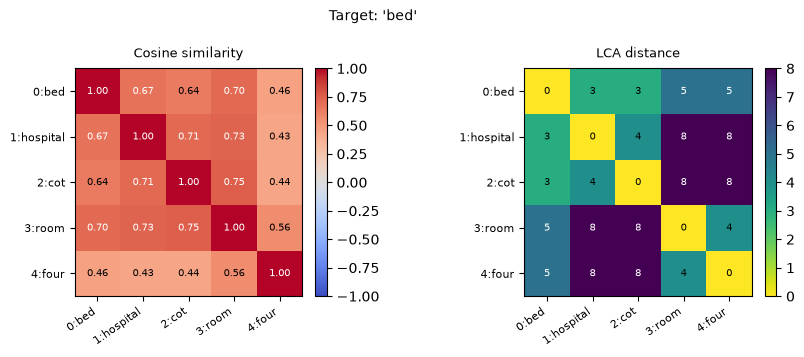


Context: '.” Hermione waited outside the curtain drawn around Harry’s bed while' | Target: 'Ron'
Top-5          |          0:ron |       1:madame |   2:dumbledore |        3:draco |          4:mrs
---------------------------------------------------------------------------------------------------
0:ron          |         1.0000 |         0.7685 |         0.3439 |         0.5808 |         0.7557
1:madame       |         0.7685 |         1.0000 |         0.3361 |         0.6051 |         0.8025
2:dumbledore   |         0.3439 |         0.3361 |         1.0000 |         0.3733 |         0.3537
3:draco        |         0.5808 |         0.6051 |         0.3733 |         1.0000 |         0.5912
4:mrs          |         0.7557 |         0.8025 |         0.3537 |         0.5912 |         1.0000


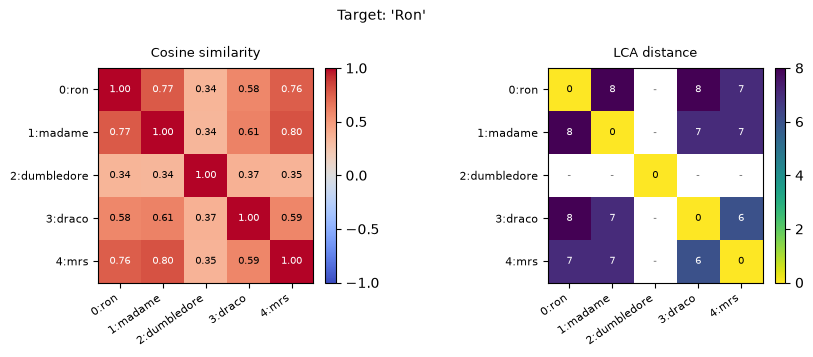


Context: '.” Hermione waited outside the curtain drawn around Harry’s bed while Ron' | Target: 'helped'
Top-5         |      0:waited |        1:came |     2:entered |   3:explained |       4:paced
---------------------------------------------------------------------------------------------
0:waited      |        1.0000 |        0.6478 |        0.5700 |        0.6520 |        0.7503
1:came        |        0.6478 |        1.0000 |        0.6663 |        0.7081 |        0.6788
2:entered     |        0.5700 |        0.6663 |        1.0000 |        0.6779 |        0.6146
3:explained   |        0.6520 |        0.7081 |        0.6779 |        1.0000 |        0.7547
4:paced       |        0.7503 |        0.6788 |        0.6146 |        0.7547 |        1.0000


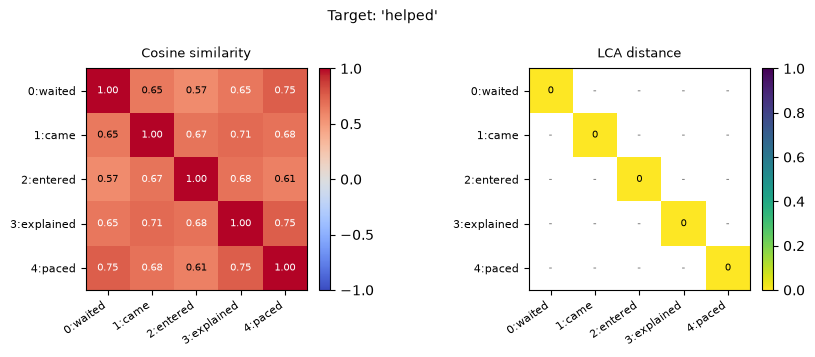


Context: '.” Hermione waited outside the curtain drawn around Harry’s bed while Ron helped him into his' | Target: 'pajamas.'
Top-5        |      0:night |        1:paj |         2:py |     3:school |   4:hospital
---------------------------------------------------------------------------------------
0:night      |       1.0000 |       0.4218 |       0.3650 |       0.4901 |       0.4439
1:paj        |       0.4218 |       1.0000 |       0.6757 |       0.5399 |       0.5092
2:py         |       0.3650 |       0.6757 |       1.0000 |       0.4990 |       0.5171
3:school     |       0.4901 |       0.5399 |       0.4990 |       1.0000 |       0.7491
4:hospital   |       0.4439 |       0.5092 |       0.5171 |       0.7491 |       1.0000


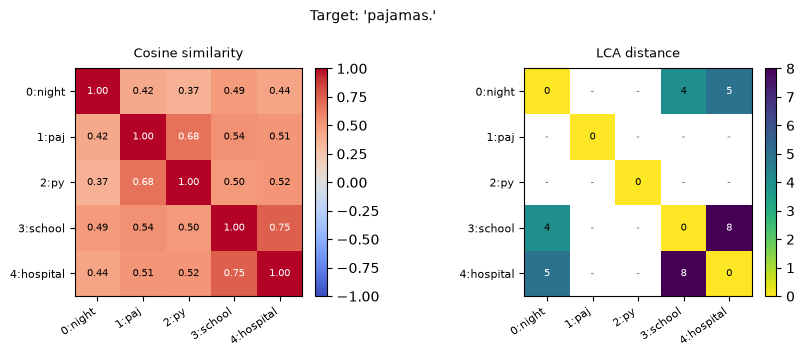


Context: 'It' | Target: 'took'
Top-5        |    0:takes |     1:took |    2:seems |    3:looks |    4:makes
-----------------------------------------------------------------------------
0:takes      |     1.0000 |     0.8302 |     0.6651 |     0.6800 |     0.8116
1:took       |     0.8302 |     1.0000 |     0.6684 |     0.7129 |     0.7483
2:seems      |     0.6651 |     0.6684 |     1.0000 |     0.8092 |     0.7510
3:looks      |     0.6800 |     0.7129 |     0.8092 |     1.0000 |     0.7770
4:makes      |     0.8116 |     0.7483 |     0.7510 |     0.7770 |     1.0000


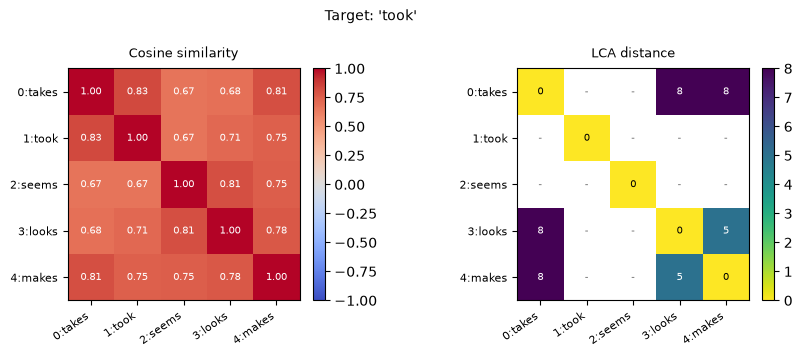


Context: 'It took a while to' | Target: 'stuff'
Top-5          |         0:find |       1:figure |      2:realize |         3:come |   4:understand
---------------------------------------------------------------------------------------------------
0:find         |         1.0000 |         0.6935 |         0.6391 |         0.6746 |         0.7201
1:figure       |         0.6935 |         1.0000 |         0.6591 |         0.6205 |         0.7898
2:realize      |         0.6391 |         0.6591 |         1.0000 |         0.6251 |         0.8004
3:come         |         0.6746 |         0.6205 |         0.6251 |         1.0000 |         0.7083
4:understand   |         0.7201 |         0.7898 |         0.8004 |         0.7083 |         1.0000


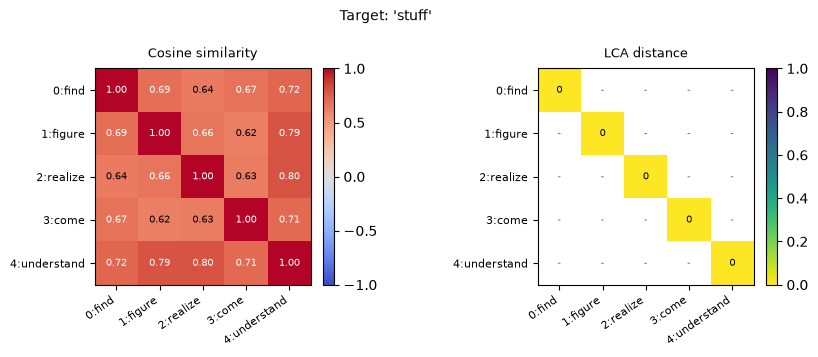


Context: 'It took a while to stuff the rubbery, boneless' | Target: 'arm'
Top-5        |   0:chicken |      1:meat |    2:pieces |    3:thighs |     4:wings
----------------------------------------------------------------------------------
0:chicken    |      1.0000 |      0.8300 |      0.7477 |      0.6281 |      0.7503
1:meat       |      0.8300 |      1.0000 |      0.7281 |      0.6230 |      0.7243
2:pieces     |      0.7477 |      0.7281 |      1.0000 |      0.5898 |      0.6974
3:thighs     |      0.6281 |      0.6230 |      0.5898 |      1.0000 |      0.6159
4:wings      |      0.7503 |      0.7243 |      0.6974 |      0.6159 |      1.0000


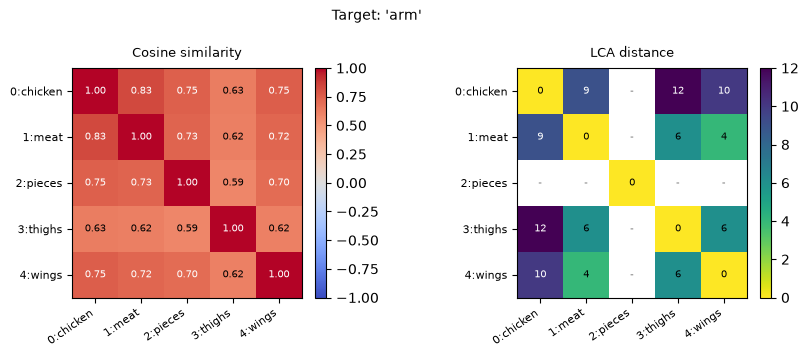


Context: 'It took a while to stuff the rubbery, boneless arm into a' | Target: 'sleeve.'
Top-5        |    0:sleeve |     1:shirt |       2:bag |   3:plastic |      4:pair
----------------------------------------------------------------------------------
0:sleeve     |      1.0000 |      0.5712 |      0.4939 |      0.6119 |      0.3796
1:shirt      |      0.5712 |      1.0000 |      0.7173 |      0.7294 |      0.5731
2:bag        |      0.4939 |      0.7173 |      1.0000 |      0.7032 |      0.5698
3:plastic    |      0.6119 |      0.7294 |      0.7032 |      1.0000 |      0.5438
4:pair       |      0.3796 |      0.5731 |      0.5698 |      0.5438 |      1.0000


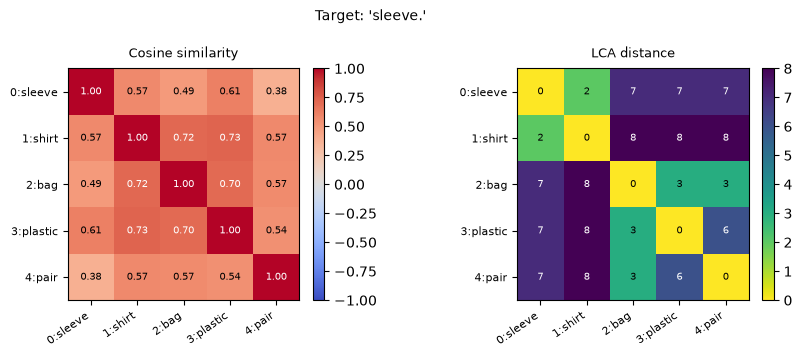


Context: '“How can you' | Target: 'stick'
Top-5        |      0:tell |       1:use |      2:help |   3:explain |   4:improve
----------------------------------------------------------------------------------
0:tell       |      1.0000 |      0.6638 |      0.7319 |      0.7784 |      0.6585
1:use        |      0.6638 |      1.0000 |      0.6707 |      0.7884 |      0.6087
2:help       |      0.7319 |      0.6707 |      1.0000 |      0.7561 |      0.6335
3:explain    |      0.7784 |      0.7884 |      0.7561 |      1.0000 |      0.6511
4:improve    |      0.6585 |      0.6087 |      0.6335 |      0.6511 |      1.0000


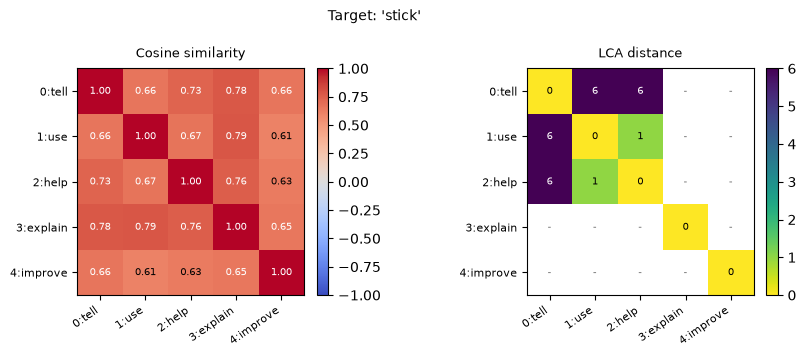


Context: '“How can you stick up for' | Target: 'Lockhart'
Top-5         |     0:someone |   1:something |      2:people |       3:human |     4:freedom
---------------------------------------------------------------------------------------------
0:someone     |        1.0000 |        0.9085 |        0.7783 |        0.6118 |        0.5911
1:something   |        0.9085 |        1.0000 |        0.7406 |        0.5914 |        0.6141
2:people      |        0.7783 |        0.7406 |        1.0000 |        0.6874 |        0.5533
3:human       |        0.6118 |        0.5914 |        0.6874 |        1.0000 |        0.4983
4:freedom     |        0.5911 |        0.6141 |        0.5533 |        0.4983 |        1.0000


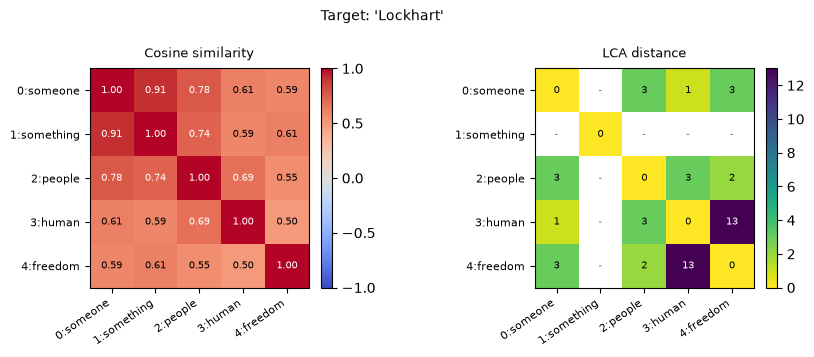


Context: '“How can you stick up for Lockhart now,' | Target: 'Hermione,'
Top-5        |      0:harry |   1:hermione |        2:ron |         3:se |      4:given
---------------------------------------------------------------------------------------
0:harry      |       1.0000 |       0.4042 |       0.8624 |       0.6943 |       0.6598
1:hermione   |       0.4042 |       1.0000 |       0.3613 |       0.2953 |       0.3317
2:ron        |       0.8624 |       0.3613 |       1.0000 |       0.6615 |       0.6383
3:se         |       0.6943 |       0.2953 |       0.6615 |       1.0000 |       0.6601
4:given      |       0.6598 |       0.3317 |       0.6383 |       0.6601 |       1.0000


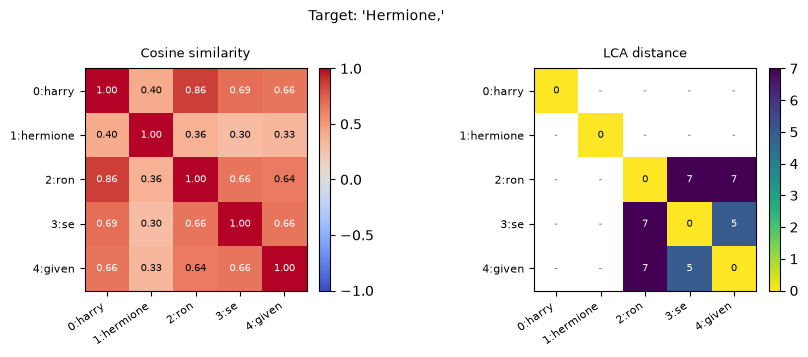


Context: '“How can you stick up for Lockhart now, Hermione,' | Target: 'eh?”'
Top-5           |         0:since |         1:given |   2:considering |    3:especially |        4:seeing
---------------------------------------------------------------------------------------------------------
0:since         |          1.0000 |          0.7002 |          0.6585 |          0.6551 |          0.6969
1:given         |          0.7002 |          1.0000 |          0.7098 |          0.6362 |          0.7560
2:considering   |          0.6585 |          0.7098 |          1.0000 |          0.7585 |          0.8428
3:especially    |          0.6551 |          0.6362 |          0.7585 |          1.0000 |          0.7921
4:seeing        |          0.6969 |          0.7560 |          0.8428 |          0.7921 |          1.0000


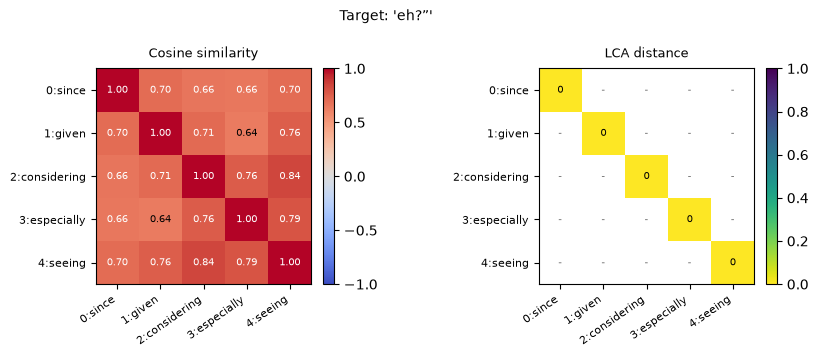


Context: '“How can you stick up for Lockhart now, Hermione, eh?”' | Target: 'Ron'
Top-5        |      0:mal |      1:ron |    2:asked |    3:harry |    4:draco
-----------------------------------------------------------------------------
0:mal        |     1.0000 |     0.8051 |     0.6092 |     0.8214 |     0.6254
1:ron        |     0.8051 |     1.0000 |     0.6249 |     0.8624 |     0.5808
2:asked      |     0.6092 |     0.6249 |     1.0000 |     0.6486 |     0.5235
3:harry      |     0.8214 |     0.8624 |     0.6486 |     1.0000 |     0.6321
4:draco      |     0.6254 |     0.5808 |     0.5235 |     0.6321 |     1.0000


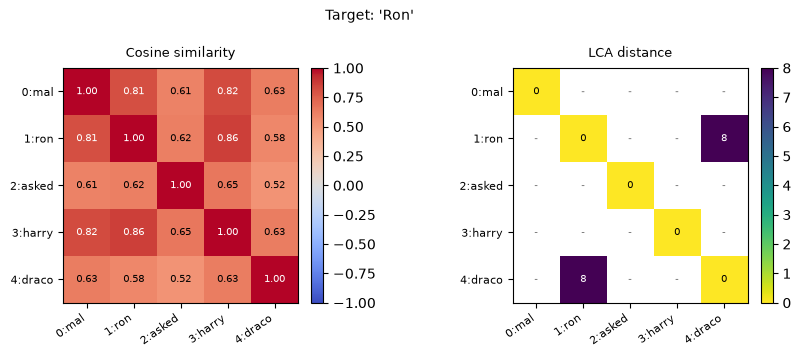


Context: '“How can you stick up for Lockhart now, Hermione, eh?” Ron' | Target: 'called'
Top-5        |     0:asked |       1:sne |        2:ta |   3:accused |        4:je
----------------------------------------------------------------------------------
0:asked      |      1.0000 |      0.4579 |      0.5395 |      0.5881 |      0.4719
1:sne        |      0.4579 |      1.0000 |      0.6203 |      0.6045 |      0.6277
2:ta         |      0.5395 |      0.6203 |      1.0000 |      0.6342 |      0.7118
3:accused    |      0.5881 |      0.6045 |      0.6342 |      1.0000 |      0.6780
4:je         |      0.4719 |      0.6277 |      0.7118 |      0.6780 |      1.0000


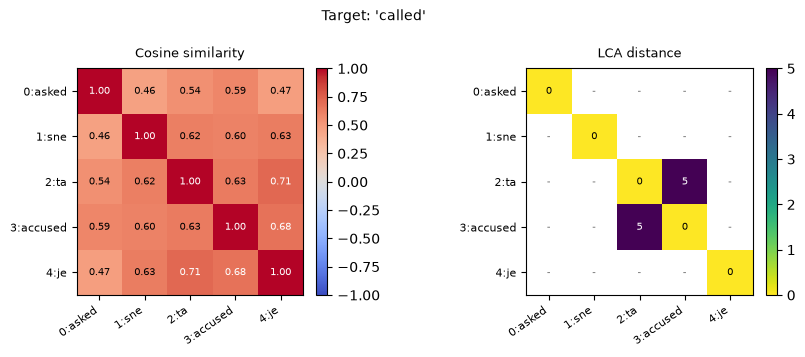


Context: '“How can you stick up for Lockhart now, Hermione, eh?” Ron called through the' | Target: 'curtain'
Top-5        |       0:door |      1:crowd |   2:portrait |     3:window |       4:open
---------------------------------------------------------------------------------------
0:door       |       1.0000 |       0.6852 |       0.6745 |       0.7870 |       0.6437
1:crowd      |       0.6852 |       1.0000 |       0.6867 |       0.7833 |       0.5827
2:portrait   |       0.6745 |       0.6867 |       1.0000 |       0.7644 |       0.5615
3:window     |       0.7870 |       0.7833 |       0.7644 |       1.0000 |       0.6507
4:open       |       0.6437 |       0.5827 |       0.5615 |       0.6507 |       1.0000


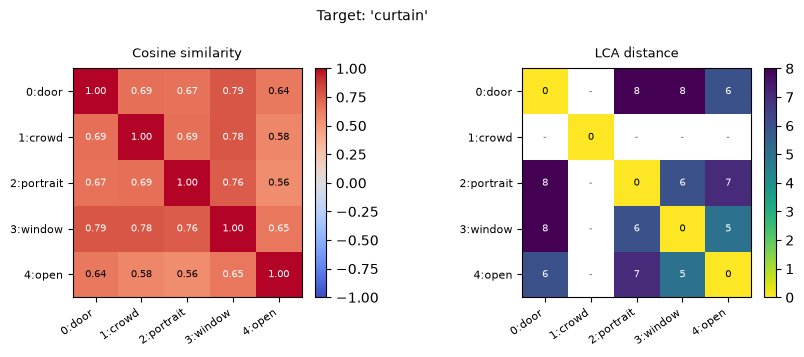


Context: '“How can you stick up for Lockhart now, Hermione, eh?” Ron called through the curtain as he' | Target: 'pulled'
Top-5        |    0:pulled |   1:emerged |      2:came |      3:left |       4:put
----------------------------------------------------------------------------------
0:pulled     |      1.0000 |      0.7876 |      0.7144 |      0.6788 |      0.7644
1:emerged    |      0.7876 |      1.0000 |      0.7880 |      0.6490 |      0.7224
2:came       |      0.7144 |      0.7880 |      1.0000 |      0.5488 |      0.6925
3:left       |      0.6788 |      0.6490 |      0.5488 |      1.0000 |      0.6382
4:put        |      0.7644 |      0.7224 |      0.6925 |      0.6382 |      1.0000


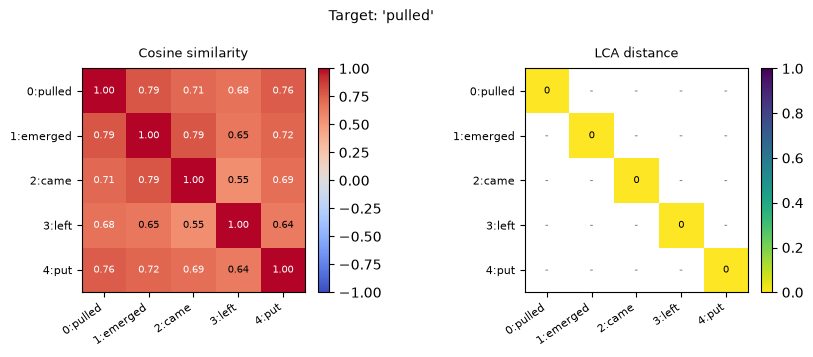


Context: '“How can you stick up for Lockhart now, Hermione, eh?” Ron called through the curtain as he pulled' | Target: 'Harry’s'
Top-5        |       0:back |      1:harry |   2:hermione |       3:open |      4:aside
---------------------------------------------------------------------------------------
0:back       |       1.0000 |       0.6842 |       0.3616 |       0.5870 |       0.6310
1:harry      |       0.6842 |       1.0000 |       0.4042 |       0.5992 |       0.6462
2:hermione   |       0.3616 |       0.4042 |       1.0000 |       0.2836 |       0.3237
3:open       |       0.5870 |       0.5992 |       0.2836 |       1.0000 |       0.4783
4:aside      |       0.6310 |       0.6462 |       0.3237 |       0.4783 |       1.0000


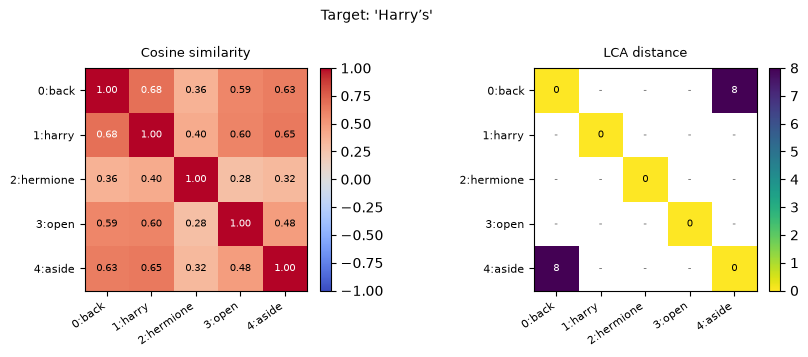


Context: '“How can you stick up for Lockhart now, Hermione, eh?” Ron called through the curtain as he pulled Harry’s' | Target: 'limp'
Top-5          |        0:trunk |        1:cloak |          2:bed |   3:belongings |      4:clothes
---------------------------------------------------------------------------------------------------
0:trunk        |         1.0000 |         0.7170 |         0.6696 |         0.7607 |         0.7240
1:cloak        |         0.7170 |         1.0000 |         0.6066 |         0.7802 |         0.6991
2:bed          |         0.6696 |         0.6066 |         1.0000 |         0.6214 |         0.7285
3:belongings   |         0.7607 |         0.7802 |         0.6214 |         1.0000 |         0.8189
4:clothes      |         0.7240 |         0.6991 |         0.7285 |         0.8189 |         1.0000


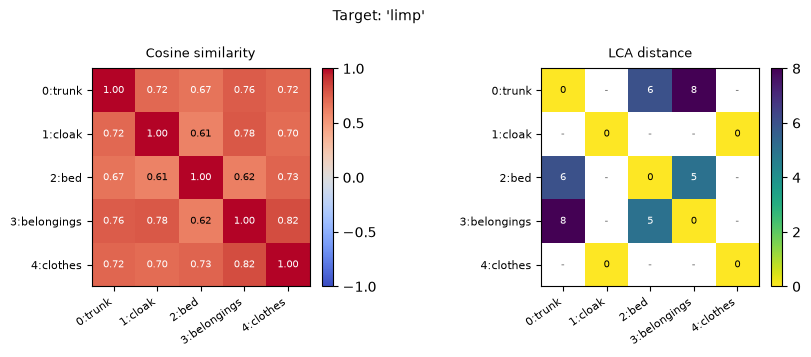


Context: '“How can you stick up for Lockhart now, Hermione, eh?” Ron called through the curtain as he pulled Harry’s limp' | Target: 'fingers'
Top-5        |     0:body |     1:form |   2:figure |    3:frame |     4:head
-----------------------------------------------------------------------------
0:body       |     1.0000 |     0.6729 |     0.6964 |     0.7198 |     0.7401
1:form       |     0.6729 |     1.0000 |     0.7572 |     0.7436 |     0.6516
2:figure     |     0.6964 |     0.7572 |     1.0000 |     0.7739 |     0.7407
3:frame      |     0.7198 |     0.7436 |     0.7739 |     1.0000 |     0.7872
4:head       |     0.7401 |     0.6516 |     0.7407 |     0.7872 |     1.0000


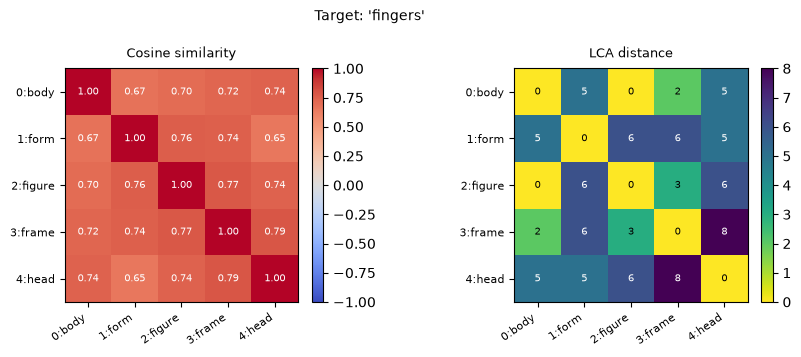


Context: '“How can you stick up for Lockhart now, Hermione, eh?” Ron called through the curtain as he pulled Harry’s limp fingers through the' | Target: 'cuff.'
Top-5        |    0:loops |     1:loop |     2:hole |    3:holes |     4:knot
-----------------------------------------------------------------------------
0:loops      |     1.0000 |     0.8410 |     0.7231 |     0.8158 |     0.7179
1:loop       |     0.8410 |     1.0000 |     0.7340 |     0.7522 |     0.7962
2:hole       |     0.7231 |     0.7340 |     1.0000 |     0.8688 |     0.7405
3:holes      |     0.8158 |     0.7522 |     0.8688 |     1.0000 |     0.7709
4:knot       |     0.7179 |     0.7962 |     0.7405 |     0.7709 |     1.0000


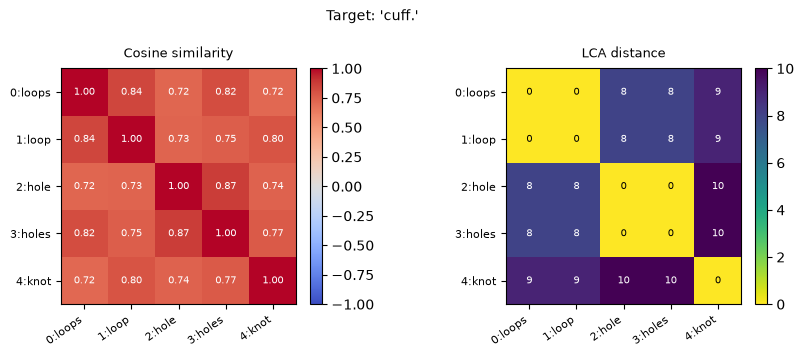


Context: '“If' | Target: 'Harry'
Top-5          |          0:god |      1:someone |       2:people |         3:john |   4:everything
---------------------------------------------------------------------------------------------------
0:god          |         1.0000 |         0.6862 |         0.5645 |         0.5664 |         0.6011
1:someone      |         0.6862 |         1.0000 |         0.7783 |         0.7182 |         0.7678
2:people       |         0.5645 |         0.7783 |         1.0000 |         0.6469 |         0.7322
3:john         |         0.5664 |         0.7182 |         0.6469 |         1.0000 |         0.6392
4:everything   |         0.6011 |         0.7678 |         0.7322 |         0.6392 |         1.0000


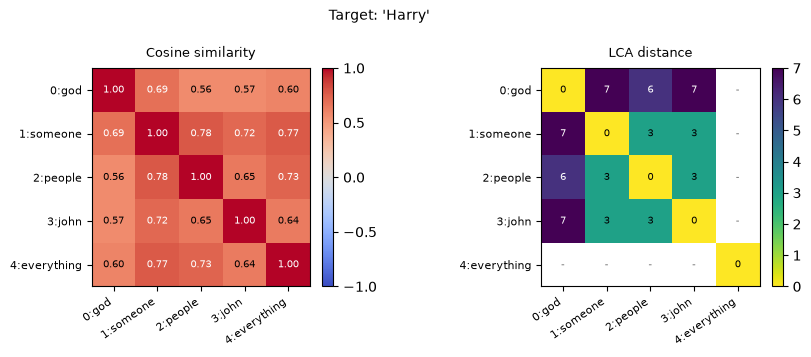


Context: '“If Harry had wanted' | Target: 'deboning'
Top-5         |       0:harry |   1:something |   2:voldemort |     3:revenge |     4:someone
---------------------------------------------------------------------------------------------
0:harry       |        1.0000 |        0.7998 |        0.2384 |        0.6805 |        0.8209
1:something   |        0.7998 |        1.0000 |        0.2547 |        0.6908 |        0.9085
2:voldemort   |        0.2384 |        0.2547 |        1.0000 |        0.2987 |        0.2628
3:revenge     |        0.6805 |        0.6908 |        0.2987 |        1.0000 |        0.6880
4:someone     |        0.8209 |        0.9085 |        0.2628 |        0.6880 |        1.0000


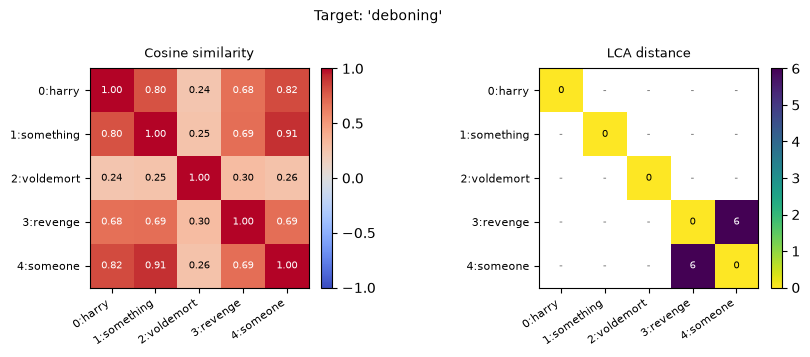


Context: '“If Harry had wanted deboning he would have' | Target: 'asked.”'
Top-5        |    0:asked |     1:come |   2:called |   3:bought |      4:deb
-----------------------------------------------------------------------------
0:asked      |     1.0000 |     0.5464 |     0.7362 |     0.6126 |     0.4680
1:come       |     0.5464 |     1.0000 |     0.5803 |     0.6549 |     0.4976
2:called     |     0.7362 |     0.5803 |     1.0000 |     0.6959 |     0.4817
3:bought     |     0.6126 |     0.6549 |     0.6959 |     1.0000 |     0.5645
4:deb        |     0.4680 |     0.4976 |     0.4817 |     0.5645 |     1.0000


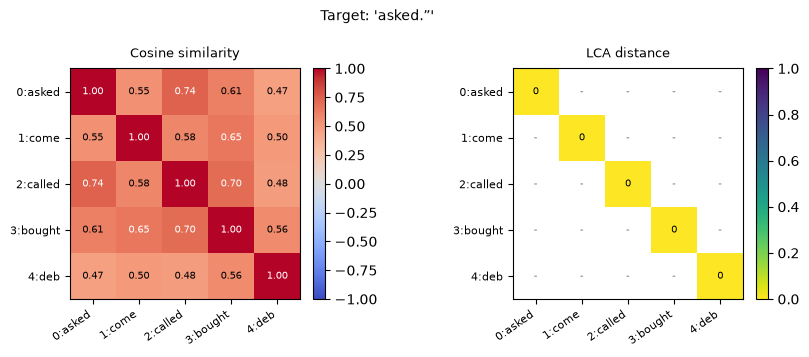


Context: '“If Harry had wanted deboning he would have asked.”' | Target: '“Anyone'
Top-5        |     0:harry |   1:explain |     2:given
------------------------------------------------------
0:harry      |      1.0000 |      0.7464 |      0.6598
1:explain    |      0.7464 |      1.0000 |      0.7859
2:given      |      0.6598 |      0.7859 |      1.0000


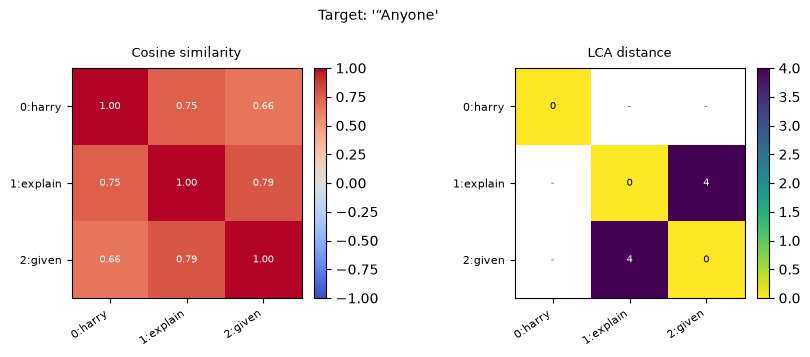


Context: '“If Harry had wanted deboning he would have asked.” “Anyone can make a' | Target: 'mistake,”'
Top-5          |   0:suggestion |      1:mistake |    2:statement |         3:meal |      4:request
---------------------------------------------------------------------------------------------------
0:suggestion   |         1.0000 |         0.8120 |         0.8271 |         0.7800 |         0.8328
1:mistake      |         0.8120 |         1.0000 |         0.8114 |         0.8077 |         0.7511
2:statement    |         0.8271 |         0.8114 |         1.0000 |         0.8002 |         0.7686
3:meal         |         0.7800 |         0.8077 |         0.8002 |         1.0000 |         0.7048
4:request      |         0.8328 |         0.7511 |         0.7686 |         0.7048 |         1.0000


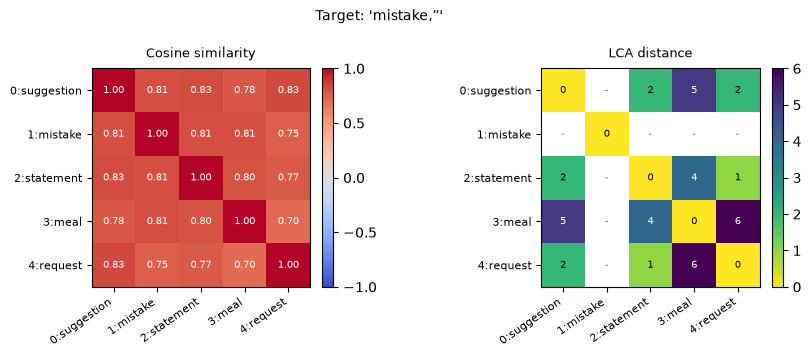


Context: '“If Harry had wanted deboning he would have asked.” “Anyone can make a mistake,” said' | Target: 'Hermione.'
Top-5          |     0:hermione |        1:sever |        2:harry |          3:ron |   4:dumbledore
---------------------------------------------------------------------------------------------------
0:hermione     |         1.0000 |         0.4279 |         0.4042 |         0.3613 |         0.3562
1:sever        |         0.4279 |         1.0000 |         0.5557 |         0.5057 |         0.4505
2:harry        |         0.4042 |         0.5557 |         1.0000 |         0.8624 |         0.3280
3:ron          |         0.3613 |         0.5057 |         0.8624 |         1.0000 |         0.3439
4:dumbledore   |         0.3562 |         0.4505 |         0.3280 |         0.3439 |         1.0000


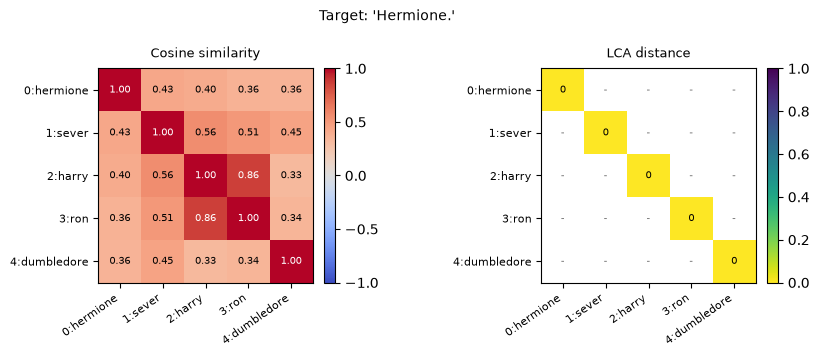


Context: '“And it' | Target: 'doesn’t'
Top-5        |       0:came |   1:happened |      2:seems |     3:seemed |     4:became
---------------------------------------------------------------------------------------
0:came       |       1.0000 |       0.7651 |       0.6936 |       0.7481 |       0.7334
1:happened   |       0.7651 |       1.0000 |       0.7630 |       0.8207 |       0.8244
2:seems      |       0.6936 |       0.7630 |       1.0000 |       0.9444 |       0.7349
3:seemed     |       0.7481 |       0.8207 |       0.9444 |       1.0000 |       0.7945
4:became     |       0.7334 |       0.8244 |       0.7349 |       0.7945 |       1.0000


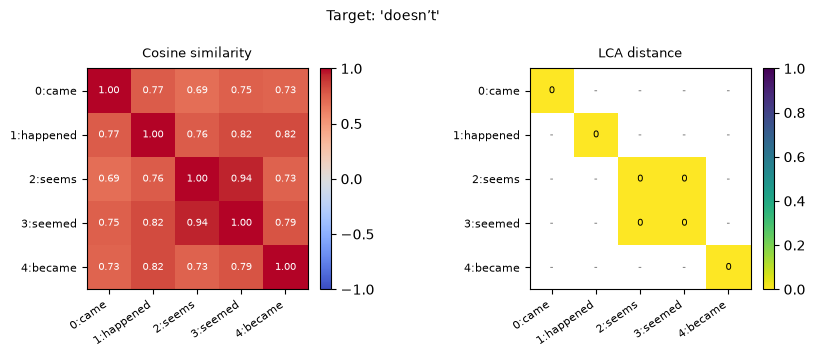


Context: '“And it doesn’t' | Target: 'hurt'
Top-5        |   0:matter |     1:take |     2:stop |     3:hurt |      4:end
-----------------------------------------------------------------------------
0:matter     |     1.0000 |     0.7037 |     0.6836 |     0.6749 |     0.4522
1:take       |     0.7037 |     1.0000 |     0.7357 |     0.6581 |     0.4404
2:stop       |     0.6836 |     0.7357 |     1.0000 |     0.6677 |     0.5049
3:hurt       |     0.6749 |     0.6581 |     0.6677 |     1.0000 |     0.5005
4:end        |     0.4522 |     0.4404 |     0.5049 |     0.5005 |     1.0000


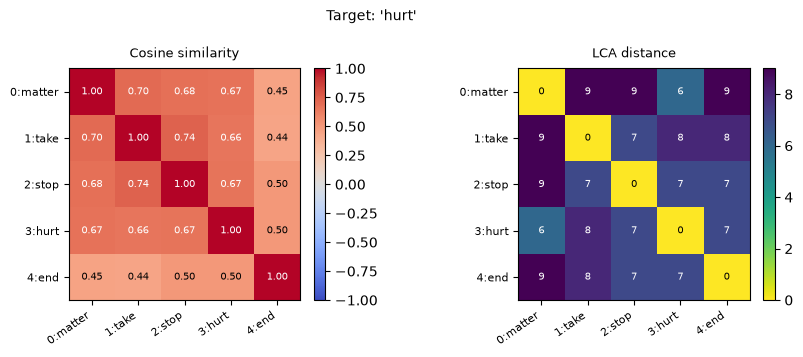


Context: '“And it doesn’t hurt' | Target: 'anymore,'
Top-5        |     0:anyone |   1:anything |     2:either |    3:anybody |   4:anywhere
---------------------------------------------------------------------------------------
0:anyone     |       1.0000 |       0.8400 |       0.4609 |       0.9046 |       0.7012
1:anything   |       0.8400 |       1.0000 |       0.5162 |       0.8174 |       0.7492
2:either     |       0.4609 |       0.5162 |       1.0000 |       0.4382 |       0.5055
3:anybody    |       0.9046 |       0.8174 |       0.4382 |       1.0000 |       0.6856
4:anywhere   |       0.7012 |       0.7492 |       0.5055 |       0.6856 |       1.0000


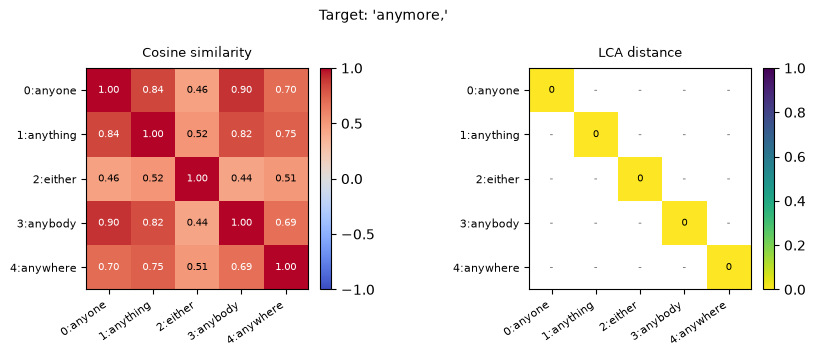


Context: '“And it doesn’t hurt anymore, does it,' | Target: 'Harry?”'
Top-5        |       0:mr |     1:dear |    2:sweet |   3:little |     4:miss
-----------------------------------------------------------------------------
0:mr         |     1.0000 |     0.6596 |     0.5422 |     0.6692 |     0.7803
1:dear       |     0.6596 |     1.0000 |     0.6419 |     0.6332 |     0.6192
2:sweet      |     0.5422 |     0.6419 |     1.0000 |     0.6395 |     0.5419
3:little     |     0.6692 |     0.6332 |     0.6395 |     1.0000 |     0.6466
4:miss       |     0.7803 |     0.6192 |     0.5419 |     0.6466 |     1.0000


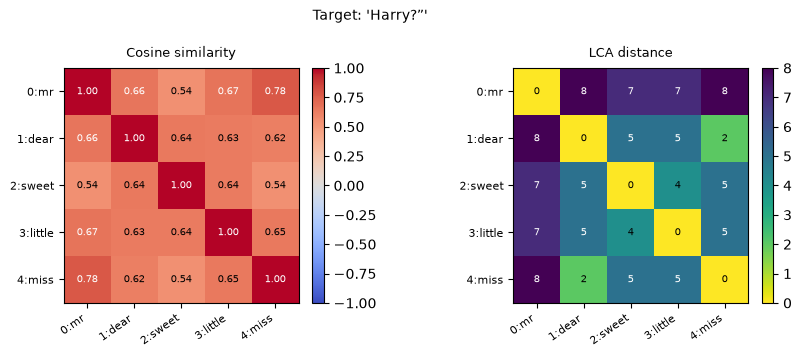


Context: '“And it doesn’t hurt anymore, does it, Harry?” “No,” said' | Target: 'Harry,'
Top-5        |      0:harry |        1:ron |      2:sever |   3:hermione |        4:tom
---------------------------------------------------------------------------------------
0:harry      |       1.0000 |       0.8624 |       0.5557 |       0.4042 |       0.8170
1:ron        |       0.8624 |       1.0000 |       0.5057 |       0.3613 |       0.7728
2:sever      |       0.5557 |       0.5057 |       1.0000 |       0.4279 |       0.4910
3:hermione   |       0.4042 |       0.3613 |       0.4279 |       1.0000 |       0.4346
4:tom        |       0.8170 |       0.7728 |       0.4910 |       0.4346 |       1.0000


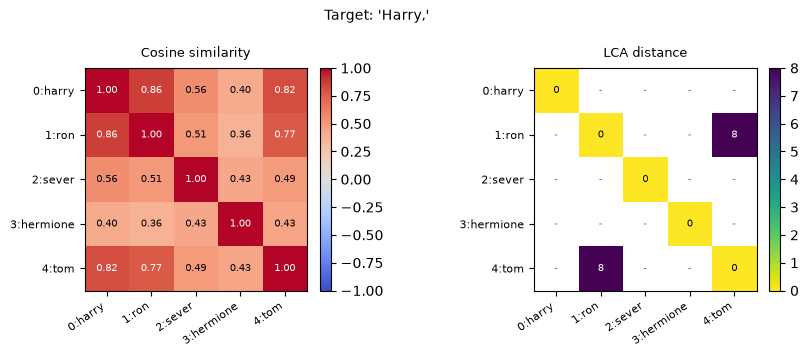


Context: '“And it doesn’t hurt anymore, does it, Harry?” “No,” said Harry,' | Target: 'getting'
Top-5        |    0:smiling |    1:feeling |    2:looking |      3:still |   4:thinking
---------------------------------------------------------------------------------------
0:smiling    |       1.0000 |       0.6609 |       0.6881 |       0.3605 |       0.7091
1:feeling    |       0.6609 |       1.0000 |       0.8725 |       0.4094 |       0.8285
2:looking    |       0.6881 |       0.8725 |       1.0000 |       0.4392 |       0.8298
3:still      |       0.3605 |       0.4094 |       0.4392 |       1.0000 |       0.4062
4:thinking   |       0.7091 |       0.8285 |       0.8298 |       0.4062 |       1.0000


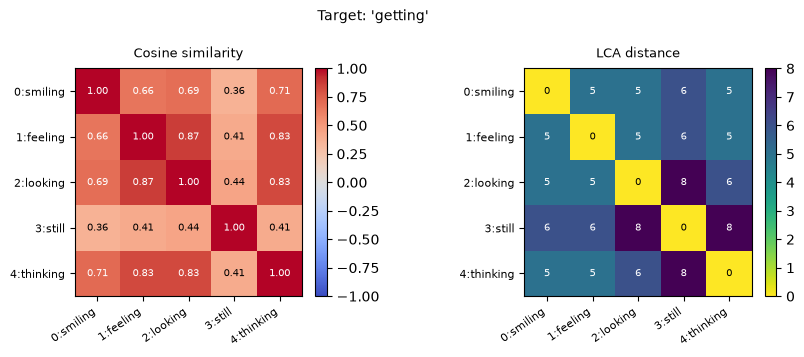


Context: '“And it doesn’t hurt anymore, does it, Harry?” “No,” said Harry, getting into' | Target: 'bed.'
Top-5        |        0:bed |   1:position |          2:h |        3:hed |        4:ron
---------------------------------------------------------------------------------------
0:bed        |       1.0000 |       0.5789 |       0.5143 |       0.4176 |       0.5831
1:position   |       0.5789 |       1.0000 |       0.6193 |       0.3926 |       0.6382
2:h          |       0.5143 |       0.6193 |       1.0000 |       0.4773 |       0.6003
3:hed        |       0.4176 |       0.3926 |       0.4773 |       1.0000 |       0.4803
4:ron        |       0.5831 |       0.6382 |       0.6003 |       0.4803 |       1.0000


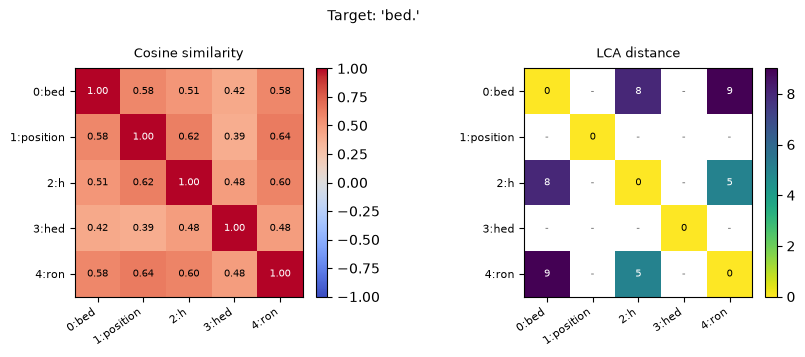


Context: '“But it' | Target: 'doesn’t'
Top-5        |    0:seems |    1:takes |     2:took |     3:gets |    4:works
-----------------------------------------------------------------------------
0:seems      |     1.0000 |     0.6651 |     0.6684 |     0.6946 |     0.5804
1:takes      |     0.6651 |     1.0000 |     0.8302 |     0.7521 |     0.5172
2:took       |     0.6684 |     0.8302 |     1.0000 |     0.7161 |     0.5088
3:gets       |     0.6946 |     0.7521 |     0.7161 |     1.0000 |     0.4965
4:works      |     0.5804 |     0.5172 |     0.5088 |     0.4965 |     1.0000


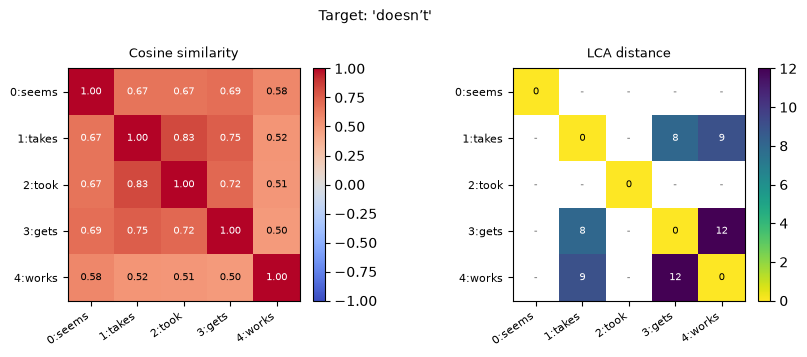


Context: '“But it doesn’t do' | Target: 'anything'
Top-5        |   0:anything |     1:anyone |    2:justice |     3:enough |       4:good
---------------------------------------------------------------------------------------
0:anything   |       1.0000 |       0.8400 |       0.5589 |       0.6013 |       0.5352
1:anyone     |       0.8400 |       1.0000 |       0.5561 |       0.5607 |       0.4866
2:justice    |       0.5589 |       0.5561 |       1.0000 |       0.4906 |       0.4907
3:enough     |       0.6013 |       0.5607 |       0.4906 |       1.0000 |       0.5518
4:good       |       0.5352 |       0.4866 |       0.4907 |       0.5518 |       1.0000


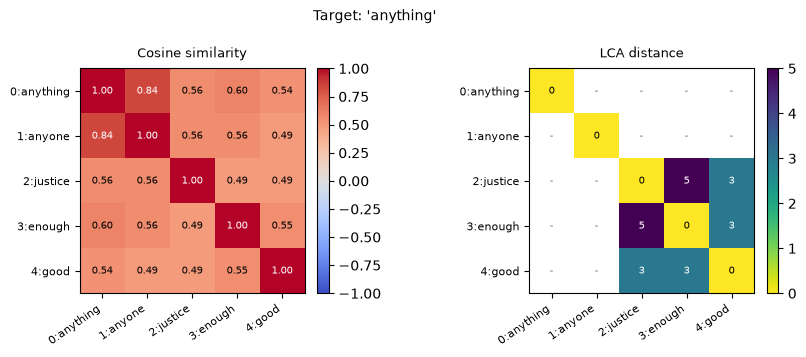


Context: '“But it doesn’t do anything' | Target: 'else'
Top-5        |   0:except |     1:good |      2:yet |     3:else |    4:right
-----------------------------------------------------------------------------
0:except     |     1.0000 |     0.5064 |     0.6613 |     0.5075 |     0.5218
1:good       |     0.5064 |     1.0000 |     0.5074 |     0.4809 |     0.6702
2:yet        |     0.6613 |     0.5074 |     1.0000 |     0.4638 |     0.5342
3:else       |     0.5075 |     0.4809 |     0.4638 |     1.0000 |     0.5486
4:right      |     0.5218 |     0.6702 |     0.5342 |     0.5486 |     1.0000


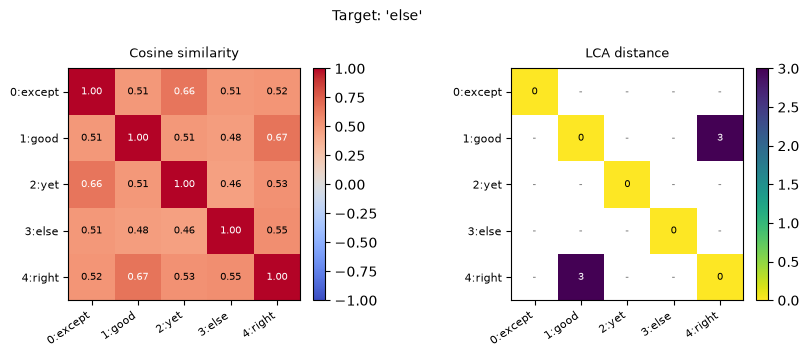


Context: '“But it doesn’t do anything else' | Target: 'either.”'
Top-5        |    0:except |   1:besides |    2:either |     3:right
--------------------------------------------------------------------
0:except     |      1.0000 |      0.6415 |      0.4331 |      0.5218
1:besides    |      0.6415 |      1.0000 |      0.3807 |      0.6846
2:either     |      0.4331 |      0.3807 |      1.0000 |      0.3945
3:right      |      0.5218 |      0.6846 |      0.3945 |      1.0000


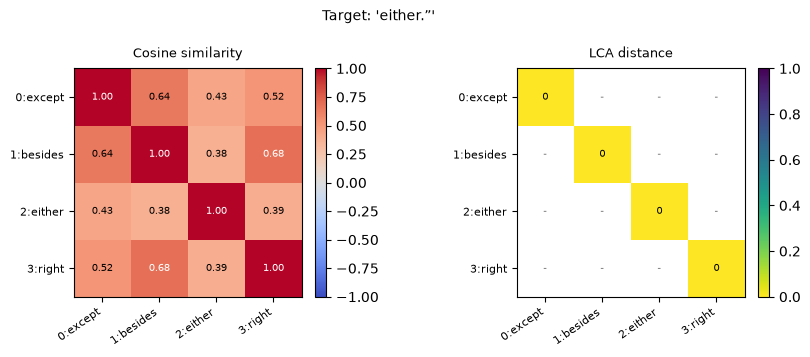


Context: '“But it doesn’t do anything else either.” As he' | Target: 'swung'
Top-5        |     0:spoke |   1:watched |    2:looked |       3:sat |       4:put
----------------------------------------------------------------------------------
0:spoke      |      1.0000 |      0.6921 |      0.8229 |      0.7227 |      0.7468
1:watched    |      0.6921 |      1.0000 |      0.7854 |      0.5986 |      0.5998
2:looked     |      0.8229 |      0.7854 |      1.0000 |      0.7153 |      0.7744
3:sat        |      0.7227 |      0.5986 |      0.7153 |      1.0000 |      0.6909
4:put        |      0.7468 |      0.5998 |      0.7744 |      0.6909 |      1.0000


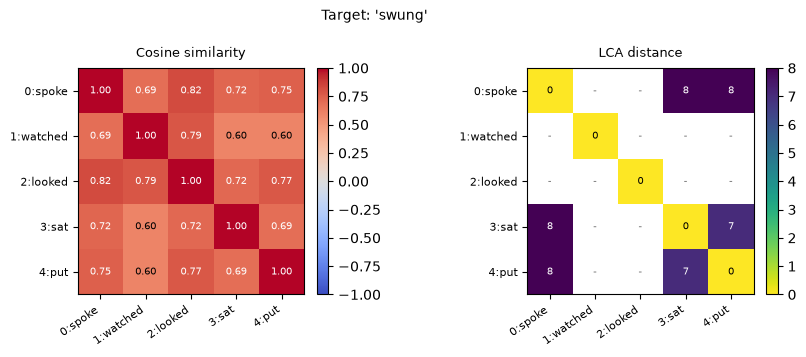


Context: '“But it doesn’t do anything else either.” As he swung himself' | Target: 'onto'
Top-5        |      0:back |      1:onto |    2:around |   3:upright |         4:n
----------------------------------------------------------------------------------
0:back       |      1.0000 |      0.7439 |      0.6622 |      0.6113 |      0.5799
1:onto       |      0.7439 |      1.0000 |      0.7528 |      0.6551 |      0.6267
2:around     |      0.6622 |      0.7528 |      1.0000 |      0.6147 |      0.6058
3:upright    |      0.6113 |      0.6551 |      0.6147 |      1.0000 |      0.5221
4:n          |      0.5799 |      0.6267 |      0.6058 |      0.5221 |      1.0000


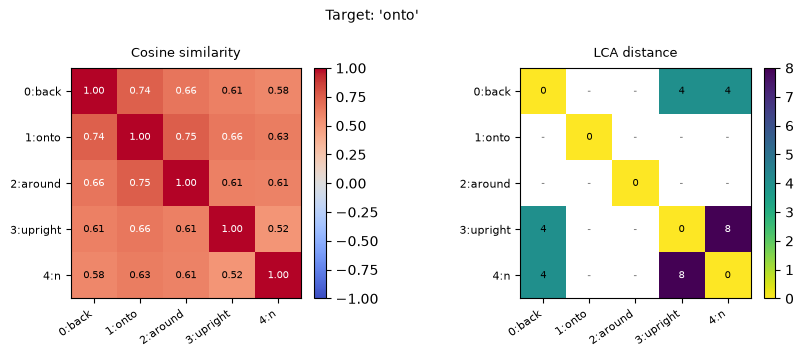


Context: '“But it doesn’t do anything else either.” As he swung himself onto the' | Target: 'bed,'
Top-5        |    0:horse |     1:back |   2:saddle |      3:bed |   4:ground
-----------------------------------------------------------------------------
0:horse      |     1.0000 |     0.6070 |     0.7788 |     0.5876 |     0.5464
1:back       |     0.6070 |     1.0000 |     0.6695 |     0.6111 |     0.4266
2:saddle     |     0.7788 |     0.6695 |     1.0000 |     0.6019 |     0.4430
3:bed        |     0.5876 |     0.6111 |     0.6019 |     1.0000 |     0.4843
4:ground     |     0.5464 |     0.4266 |     0.4430 |     0.4843 |     1.0000


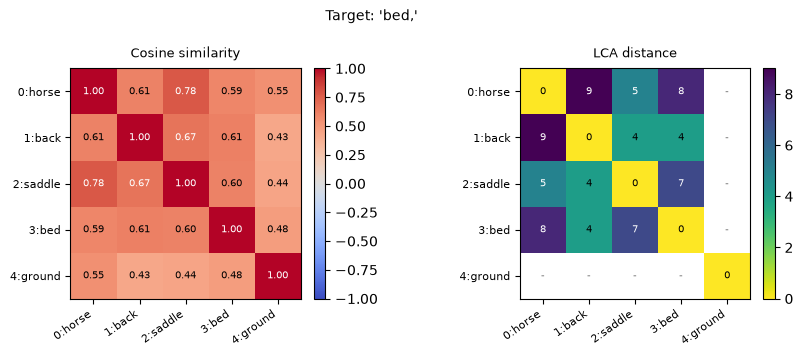


Context: '“But it doesn’t do anything else either.” As he swung himself onto the bed, his' | Target: 'arm'
Top-5        |     0:eyes |    1:voice |     2:face |     3:legs |     4:head
-----------------------------------------------------------------------------
0:eyes       |     1.0000 |     0.7843 |     0.7951 |     0.6444 |     0.7277
1:voice      |     0.7843 |     1.0000 |     0.8151 |     0.6361 |     0.7369
2:face       |     0.7951 |     0.8151 |     1.0000 |     0.6422 |     0.7801
3:legs       |     0.6444 |     0.6361 |     0.6422 |     1.0000 |     0.6998
4:head       |     0.7277 |     0.7369 |     0.7801 |     0.6998 |     1.0000


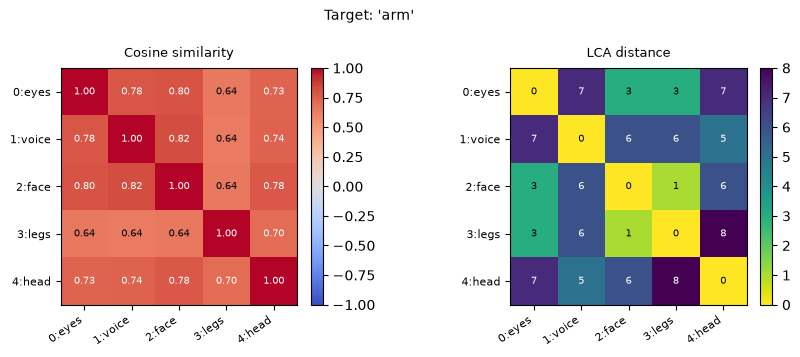


Context: '“But it doesn’t do anything else either.” As he swung himself onto the bed, his arm' | Target: 'flapped'
Top-5        |     0:came |     1:fell |    2:still |       3:fl |   4:around
-----------------------------------------------------------------------------
0:came       |     1.0000 |     0.7729 |     0.4538 |     0.5786 |     0.6156
1:fell       |     0.7729 |     1.0000 |     0.3770 |     0.6412 |     0.6660
2:still      |     0.4538 |     0.3770 |     1.0000 |     0.3891 |     0.3545
3:fl         |     0.5786 |     0.6412 |     0.3891 |     1.0000 |     0.6392
4:around     |     0.6156 |     0.6660 |     0.3545 |     0.6392 |     1.0000


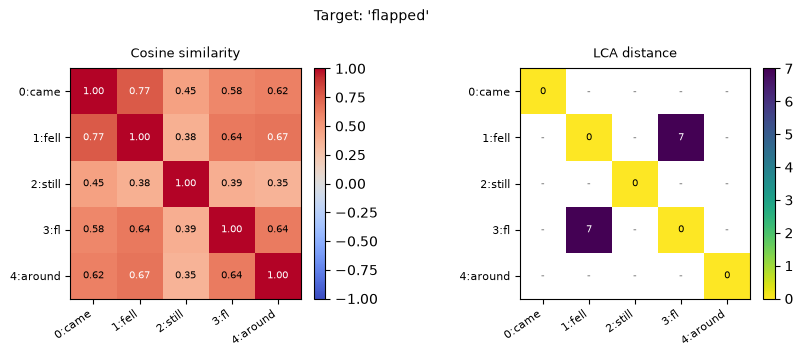


Context: '“But it doesn’t do anything else either.” As he swung himself onto the bed, his arm flapped' | Target: 'pointlessly.'
Top-5        |    0:around |      1:open |    2:across |       3:use |   4:loosely
----------------------------------------------------------------------------------
0:around     |      1.0000 |      0.5524 |      0.7055 |      0.5963 |      0.7719
1:open       |      0.5524 |      1.0000 |      0.5528 |      0.6378 |      0.6285
2:across     |      0.7055 |      0.5528 |      1.0000 |      0.5223 |      0.6548
3:use        |      0.5963 |      0.6378 |      0.5223 |      1.0000 |      0.6828
4:loosely    |      0.7719 |      0.6285 |      0.6548 |      0.6828 |      1.0000


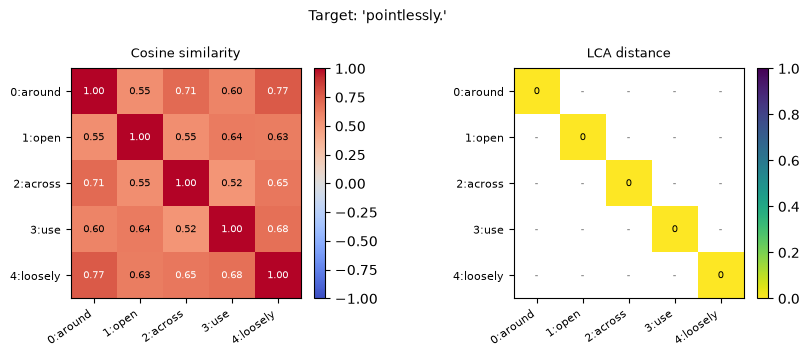


Context: 'Hermione and' | Target: 'Madam'
Top-5        |     0:luna |    1:harry |      2:tom |     3:jack |     4:fred
-----------------------------------------------------------------------------
0:luna       |     1.0000 |     0.7634 |     0.6720 |     0.6625 |     0.7164
1:harry      |     0.7634 |     1.0000 |     0.8170 |     0.7187 |     0.8744
2:tom        |     0.6720 |     0.8170 |     1.0000 |     0.7422 |     0.7629
3:jack       |     0.6625 |     0.7187 |     0.7422 |     1.0000 |     0.6874
4:fred       |     0.7164 |     0.8744 |     0.7629 |     0.6874 |     1.0000


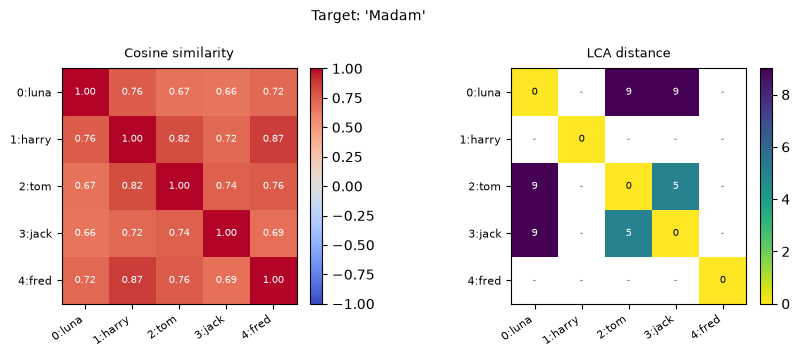


Context: 'Hermione and Madam' | Target: 'Pomfrey'
Top-5        |        0:p |      1:pom |      2:max |      3:ros |     4:malk
-----------------------------------------------------------------------------
0:p          |     1.0000 |     0.4237 |     0.4929 |     0.4675 |     0.4071
1:pom        |     0.4237 |     1.0000 |     0.4955 |     0.6144 |     0.5210
2:max        |     0.4929 |     0.4955 |     1.0000 |     0.6606 |     0.6326
3:ros        |     0.4675 |     0.6144 |     0.6606 |     1.0000 |     0.6254
4:malk       |     0.4071 |     0.5210 |     0.6326 |     0.6254 |     1.0000


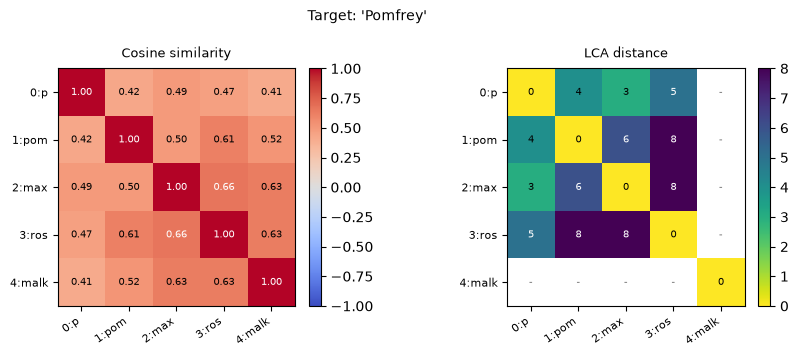


Context: 'Hermione and Madam Pomfrey' | Target: 'came'
Top-5        |   0:decide |     1:work |     2:need |   3:notice |    4:start
-----------------------------------------------------------------------------
0:decide     |     1.0000 |     0.6869 |     0.6854 |     0.6038 |     0.5132
1:work       |     0.6869 |     1.0000 |     0.6417 |     0.4990 |     0.5313
2:need       |     0.6854 |     0.6417 |     1.0000 |     0.6063 |     0.5124
3:notice     |     0.6038 |     0.4990 |     0.6063 |     1.0000 |     0.4066
4:start      |     0.5132 |     0.5313 |     0.5124 |     0.4066 |     1.0000


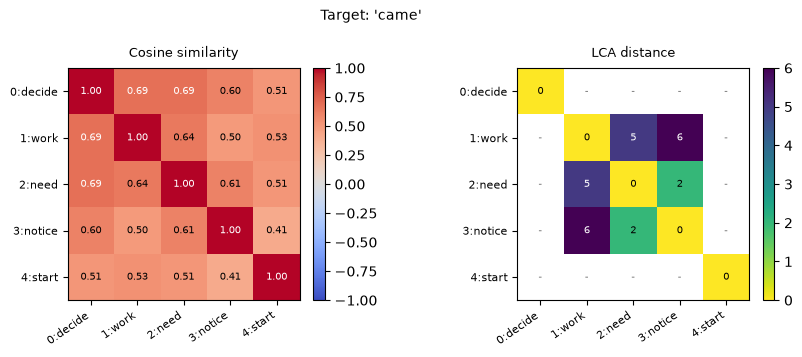


Context: 'Hermione and Madam Pomfrey came' | Target: 'around'
Top-5        |   0:across |     1:back |     2:upon |     3:home |    4:along
-----------------------------------------------------------------------------
0:across     |     1.0000 |     0.6962 |     0.5842 |     0.5079 |     0.6610
1:back       |     0.6962 |     1.0000 |     0.6651 |     0.5288 |     0.7404
2:upon       |     0.5842 |     0.6651 |     1.0000 |     0.4041 |     0.6893
3:home       |     0.5079 |     0.5288 |     0.4041 |     1.0000 |     0.5074
4:along      |     0.6610 |     0.7404 |     0.6893 |     0.5074 |     1.0000


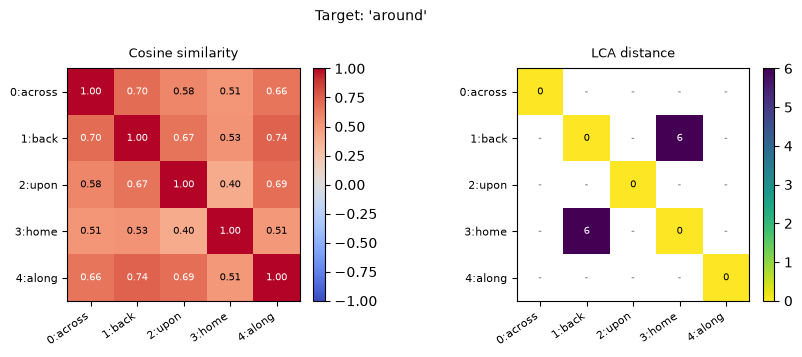


Context: 'Hermione and Madam Pomfrey came around the' | Target: 'curtain.'
Top-5        |   0:corner |     1:bend |    2:table |      3:bed |     4:last
-----------------------------------------------------------------------------
0:corner     |     1.0000 |     0.5934 |     0.4571 |     0.4940 |     0.5173
1:bend       |     0.5934 |     1.0000 |     0.4510 |     0.5021 |     0.5382
2:table      |     0.4571 |     0.4510 |     1.0000 |     0.5455 |     0.5193
3:bed        |     0.4940 |     0.5021 |     0.5455 |     1.0000 |     0.6268
4:last       |     0.5173 |     0.5382 |     0.5193 |     0.6268 |     1.0000


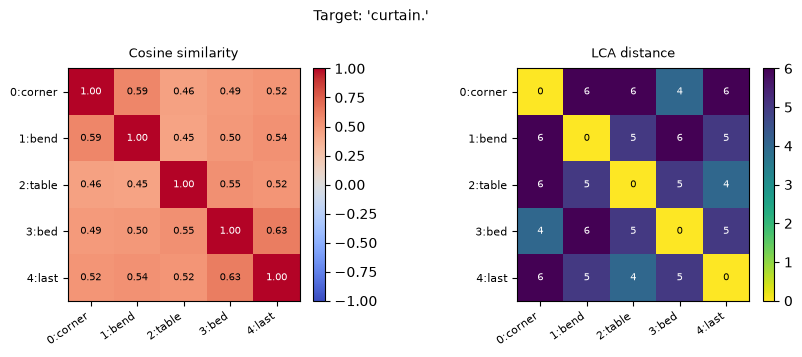


Context: 'Madam' | Target: 'Pomfrey'
Top-5         |     0:speaker |   1:president |       2:chair |   3:secretary |     4:justice
---------------------------------------------------------------------------------------------
0:speaker     |        1.0000 |        0.6683 |        0.6981 |        0.5919 |        0.5752
1:president   |        0.6683 |        1.0000 |        0.7323 |        0.7542 |        0.6381
2:chair       |        0.6981 |        0.7323 |        1.0000 |        0.6804 |        0.6410
3:secretary   |        0.5919 |        0.7542 |        0.6804 |        1.0000 |        0.6285
4:justice     |        0.5752 |        0.6381 |        0.6410 |        0.6285 |        1.0000


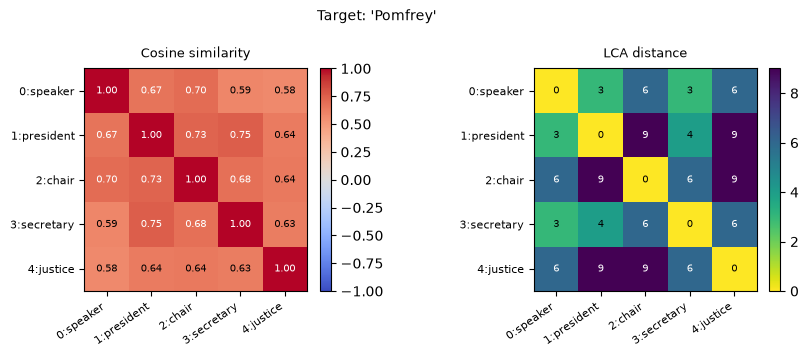


Context: 'Madam Pomfrey was' | Target: 'holding'
Top-5         |   0:preparing |     1:brewing |        2:busy |    3:checking |    4:treating
---------------------------------------------------------------------------------------------
0:preparing   |        1.0000 |        0.8545 |        0.7836 |        0.8031 |        0.7551
1:brewing     |        0.8545 |        1.0000 |        0.7278 |        0.7547 |        0.7401
2:busy        |        0.7836 |        0.7278 |        1.0000 |        0.7576 |        0.7095
3:checking    |        0.8031 |        0.7547 |        0.7576 |        1.0000 |        0.7215
4:treating    |        0.7551 |        0.7401 |        0.7095 |        0.7215 |        1.0000


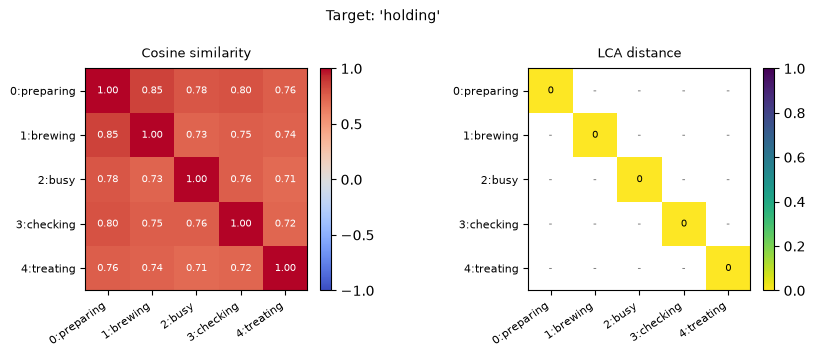


Context: 'Madam Pomfrey was holding a' | Target: 'large'
Top-5        |      0:jar |   1:bottle |      2:bag |    3:total |   4:potion
-----------------------------------------------------------------------------
0:jar        |     1.0000 |     0.8327 |     0.7617 |     0.3753 |     0.7872
1:bottle     |     0.8327 |     1.0000 |     0.8166 |     0.3993 |     0.8093
2:bag        |     0.7617 |     0.8166 |     1.0000 |     0.4142 |     0.7305
3:total      |     0.3753 |     0.3993 |     0.4142 |     1.0000 |     0.3593
4:potion     |     0.7872 |     0.8093 |     0.7305 |     0.3593 |     1.0000


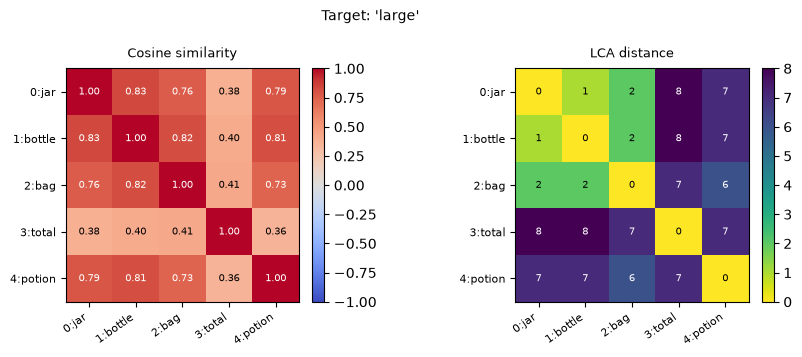


Context: 'Madam Pomfrey was holding a large' | Target: 'bottle'
Top-5        |      0:jar |      1:box |       2:ca |     3:bowl |      4:pot
-----------------------------------------------------------------------------
0:jar        |     1.0000 |     0.7829 |     0.7265 |     0.8533 |     0.7952
1:box        |     0.7829 |     1.0000 |     0.6538 |     0.8433 |     0.7865
2:ca         |     0.7265 |     0.6538 |     1.0000 |     0.6972 |     0.6696
3:bowl       |     0.8533 |     0.8433 |     0.6972 |     1.0000 |     0.8562
4:pot        |     0.7952 |     0.7865 |     0.6696 |     0.8562 |     1.0000


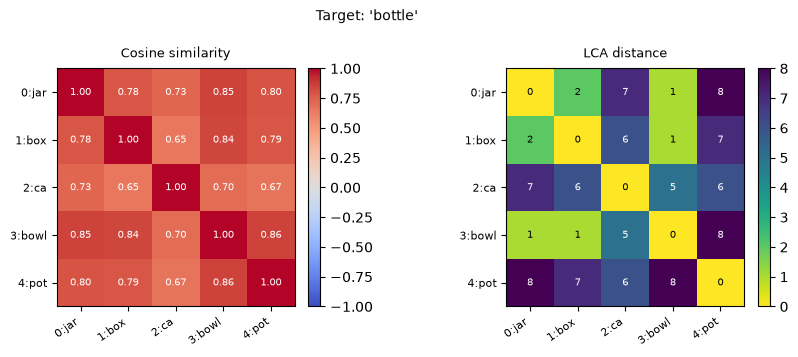


Context: 'Madam Pomfrey was holding a large bottle of' | Target: 'something'
Top-5        |     0:potion |   1:medicine |    2:potions |    3:healing |       4:wine
---------------------------------------------------------------------------------------
0:potion     |       1.0000 |       0.4525 |       0.5413 |       0.7813 |       0.7398
1:medicine   |       0.4525 |       1.0000 |       0.4922 |       0.5517 |       0.5943
2:potions    |       0.5413 |       0.4922 |       1.0000 |       0.4952 |       0.5452
3:healing    |       0.7813 |       0.5517 |       0.4952 |       1.0000 |       0.7802
4:wine       |       0.7398 |       0.5943 |       0.5452 |       0.7802 |       1.0000


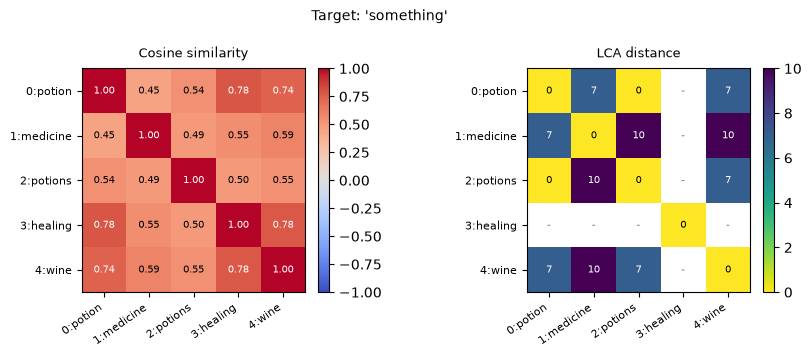


Context: 'Madam Pomfrey was holding a large bottle of something labeled' | Target: 'Skele-Gro.'
Top-5        |        0:e |        1:l |        2:f |   3:simply |      4:ver
-----------------------------------------------------------------------------
0:e          |     1.0000 |     0.7301 |     0.8095 |     0.5929 |     0.3861
1:l          |     0.7301 |     1.0000 |     0.7731 |     0.6161 |     0.4722
2:f          |     0.8095 |     0.7731 |     1.0000 |     0.5819 |     0.3981
3:simply     |     0.5929 |     0.6161 |     0.5819 |     1.0000 |     0.3971
4:ver        |     0.3861 |     0.4722 |     0.3981 |     0.3971 |     1.0000


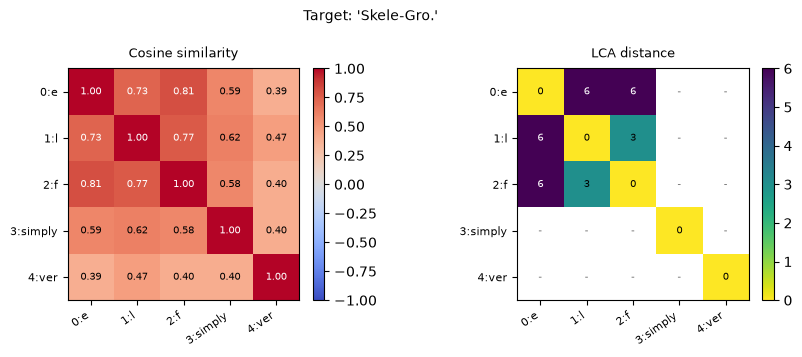


Context: '“You’re in for a' | Target: 'rough'
Top-5        |      0:treat |       1:real |   2:surprise |      3:shock |      4:great
---------------------------------------------------------------------------------------
0:treat      |       1.0000 |       0.7305 |       0.7674 |       0.7442 |       0.6561
1:real       |       0.7305 |       1.0000 |       0.6769 |       0.6635 |       0.6290
2:surprise   |       0.7674 |       0.6769 |       1.0000 |       0.8757 |       0.7093
3:shock      |       0.7442 |       0.6635 |       0.8757 |       1.0000 |       0.6792
4:great      |       0.6561 |       0.6290 |       0.7093 |       0.6792 |       1.0000


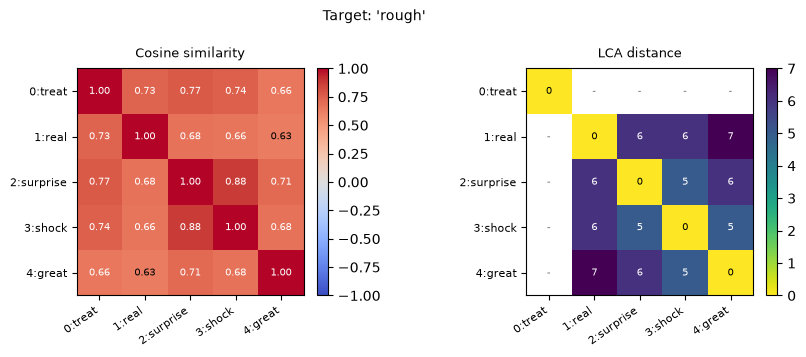


Context: '“You’re in for a rough' | Target: 'night,”'
Top-5        |     0:ride |    1:night |      2:day |     3:time |     4:week
-----------------------------------------------------------------------------
0:ride       |     1.0000 |     0.4430 |     0.5497 |     0.7158 |     0.5913
1:night      |     0.4430 |     1.0000 |     0.6644 |     0.5573 |     0.4966
2:day        |     0.5497 |     0.6644 |     1.0000 |     0.6264 |     0.6772
3:time       |     0.7158 |     0.5573 |     0.6264 |     1.0000 |     0.5969
4:week       |     0.5913 |     0.4966 |     0.6772 |     0.5969 |     1.0000


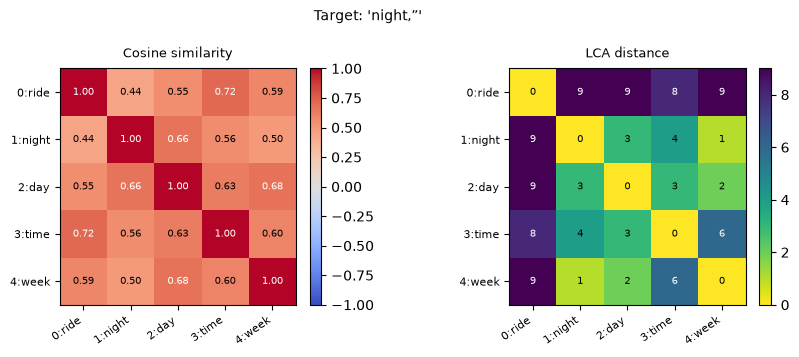


Context: '“You’re in for a rough night,” she said, pouring out a steaming' | Target: 'beakerful'
Top-5        |      0:cup |      1:mug |     2:bowl |      3:pot |    4:glass
-----------------------------------------------------------------------------
0:cup        |     1.0000 |     0.7424 |     0.7844 |     0.7619 |     0.6822
1:mug        |     0.7424 |     1.0000 |     0.8589 |     0.7753 |     0.7813
2:bowl       |     0.7844 |     0.8589 |     1.0000 |     0.8562 |     0.8324
3:pot        |     0.7619 |     0.7753 |     0.8562 |     1.0000 |     0.7243
4:glass      |     0.6822 |     0.7813 |     0.8324 |     0.7243 |     1.0000


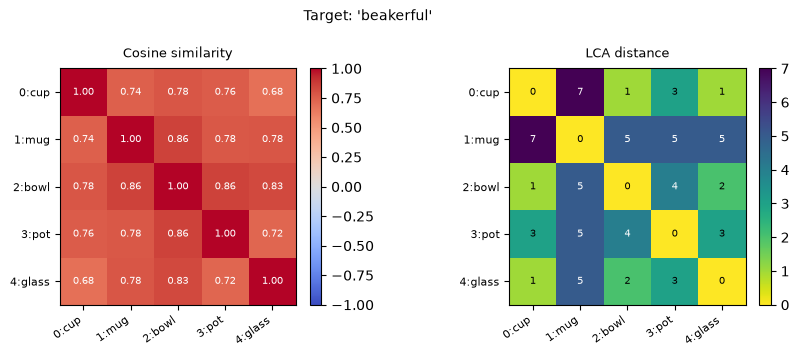


Context: '“You’re in for a rough night,” she said, pouring out a steaming beakerful and' | Target: 'handing'
Top-5        |    0:handing |    1:setting |    2:passing |    3:holding |   4:stirring
---------------------------------------------------------------------------------------
0:handing    |       1.0000 |       0.7986 |       0.8199 |       0.7865 |       0.7215
1:setting    |       0.7986 |       1.0000 |       0.7921 |       0.7476 |       0.7760
2:passing    |       0.8199 |       0.7921 |       1.0000 |       0.7563 |       0.7511
3:holding    |       0.7865 |       0.7476 |       0.7563 |       1.0000 |       0.7597
4:stirring   |       0.7215 |       0.7760 |       0.7511 |       0.7597 |       1.0000


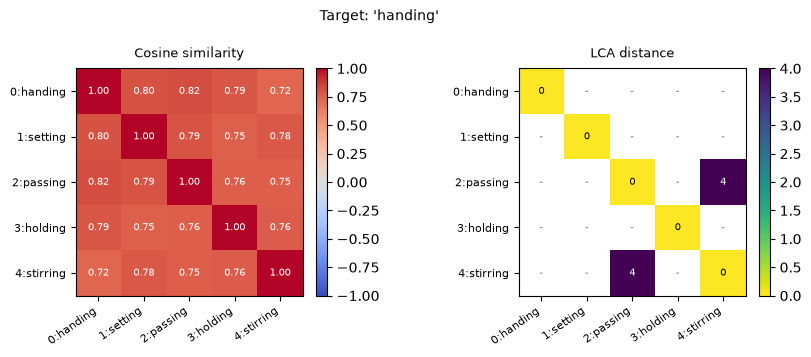


Context: '“Regrowing' | Target: 'bones'
Top-5        |     0:teeth |   1:forests |     2:limbs |      3:lost |      4:hair
----------------------------------------------------------------------------------
0:teeth      |      1.0000 |      0.5276 |      0.6329 |      0.3174 |      0.5762
1:forests    |      0.5276 |      1.0000 |      0.5890 |      0.3578 |      0.5363
2:limbs      |      0.6329 |      0.5890 |      1.0000 |      0.2377 |      0.5430
3:lost       |      0.3174 |      0.3578 |      0.2377 |      1.0000 |      0.4920
4:hair       |      0.5762 |      0.5363 |      0.5430 |      0.4920 |      1.0000


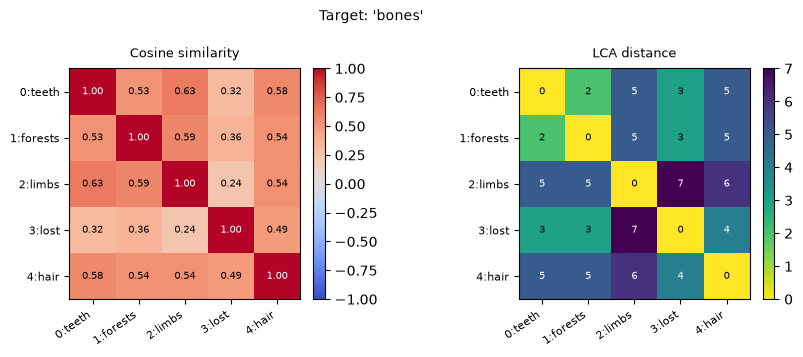


Context: '“Regrowing bones is a nasty' | Target: 'business.”'
Top-5        |   0:business |    1:process |        2:job |    3:problem |      4:thing
---------------------------------------------------------------------------------------
0:business   |       1.0000 |       0.7243 |       0.5859 |       0.6480 |       0.6751
1:process    |       0.7243 |       1.0000 |       0.6756 |       0.7536 |       0.7383
2:job        |       0.5859 |       0.6756 |       1.0000 |       0.6341 |       0.6703
3:problem    |       0.6480 |       0.7536 |       0.6341 |       1.0000 |       0.6733
4:thing      |       0.6751 |       0.7383 |       0.6703 |       0.6733 |       1.0000


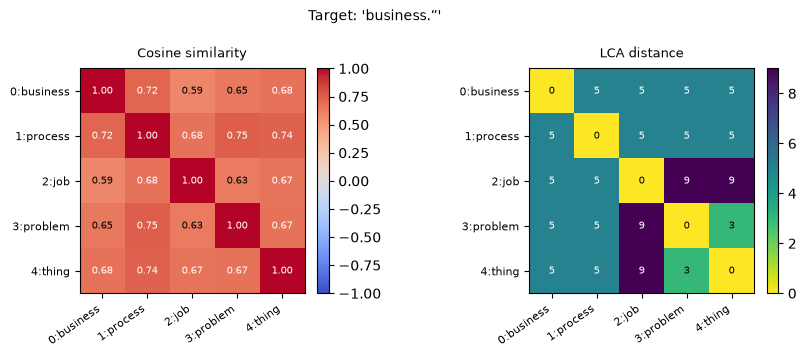


Context: '“Regrowing bones is a nasty business.” So was' | Target: 'taking'
Top-5         |          0:dr |        1:told |        2:paul |   3:explained |   4:professor
---------------------------------------------------------------------------------------------
0:dr          |        1.0000 |        0.6059 |        0.6861 |        0.6222 |        0.8401
1:told        |        0.6059 |        1.0000 |        0.7147 |        0.8541 |        0.6539
2:paul        |        0.6861 |        0.7147 |        1.0000 |        0.7118 |        0.7284
3:explained   |        0.6222 |        0.8541 |        0.7118 |        1.0000 |        0.6642
4:professor   |        0.8401 |        0.6539 |        0.7284 |        0.6642 |        1.0000


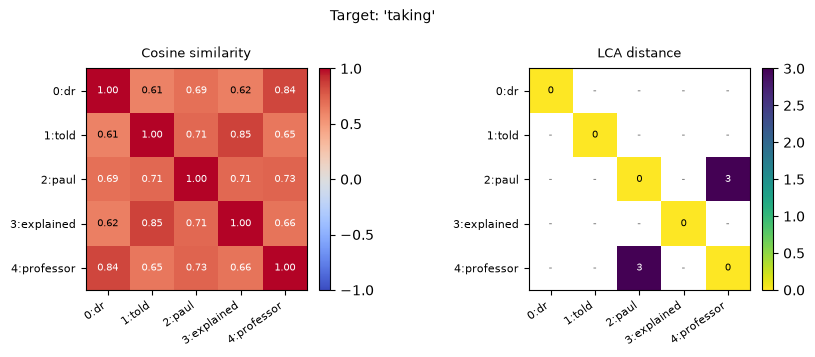


Context: '“Regrowing bones is a nasty business.” So was taking the' | Target: 'Skele-Gro.'
Top-5        |    0:first |    1:words |     2:bone |    3:bones |   4:phrase
-----------------------------------------------------------------------------
0:first      |     1.0000 |     0.5434 |     0.5837 |     0.5241 |     0.5500
1:words      |     0.5434 |     1.0000 |     0.6413 |     0.6260 |     0.7090
2:bone       |     0.5837 |     0.6413 |     1.0000 |     0.7884 |     0.6863
3:bones      |     0.5241 |     0.6260 |     0.7884 |     1.0000 |     0.5992
4:phrase     |     0.5500 |     0.7090 |     0.6863 |     0.5992 |     1.0000


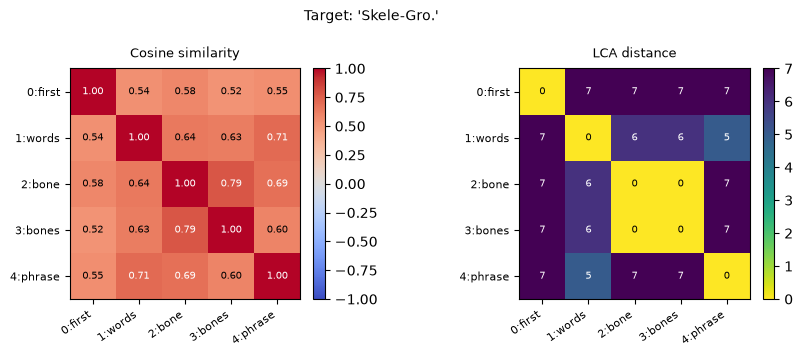


Context: 'It burned' | Target: 'Harry’s'
Top-5        |   0:brightly |     1:across |     2:slowly |   3:brighter |     4:faster
---------------------------------------------------------------------------------------
0:brightly   |       1.0000 |       0.6857 |       0.7238 |       0.8526 |       0.6370
1:across     |       0.6857 |       1.0000 |       0.6906 |       0.6462 |       0.5752
2:slowly     |       0.7238 |       0.6906 |       1.0000 |       0.7946 |       0.7598
3:brighter   |       0.8526 |       0.6462 |       0.7946 |       1.0000 |       0.7250
4:faster     |       0.6370 |       0.5752 |       0.7598 |       0.7250 |       1.0000


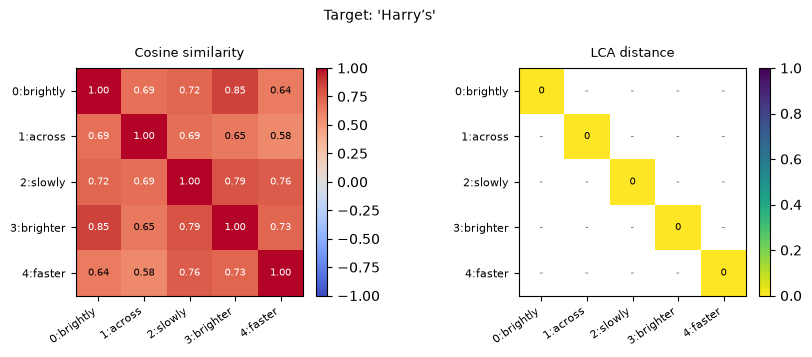


Context: 'It burned Harry’s' | Target: 'mouth'
Top-5        |     0:eyes |    1:nostr |   2:throat |   3:tongue |     4:nose
-----------------------------------------------------------------------------
0:eyes       |     1.0000 |     0.5386 |     0.7552 |     0.6829 |     0.7313
1:nostr      |     0.5386 |     1.0000 |     0.4365 |     0.3940 |     0.4798
2:throat     |     0.7552 |     0.4365 |     1.0000 |     0.7647 |     0.7383
3:tongue     |     0.6829 |     0.3940 |     0.7647 |     1.0000 |     0.6069
4:nose       |     0.7313 |     0.4798 |     0.7383 |     0.6069 |     1.0000


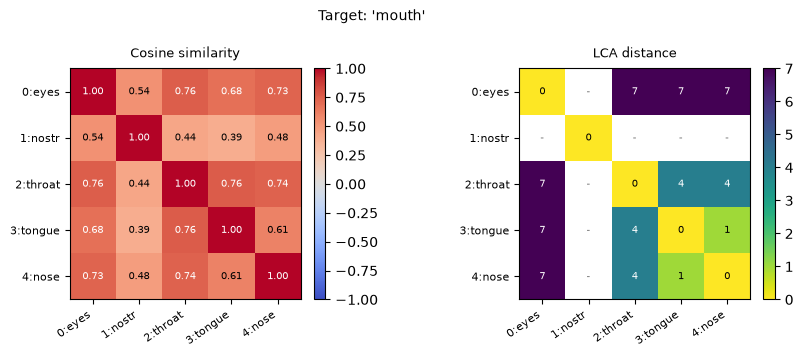


Context: 'It burned Harry’s mouth and' | Target: 'throat'
Top-5        |   0:throat |     1:eyes |   2:caused |     3:nose |   4:cheeks
-----------------------------------------------------------------------------
0:throat     |     1.0000 |     0.7552 |     0.6508 |     0.7383 |     0.7915
1:eyes       |     0.7552 |     1.0000 |     0.6828 |     0.7313 |     0.8576
2:caused     |     0.6508 |     0.6828 |     1.0000 |     0.7878 |     0.6741
3:nose       |     0.7383 |     0.7313 |     0.7878 |     1.0000 |     0.7397
4:cheeks     |     0.7915 |     0.8576 |     0.6741 |     0.7397 |     1.0000


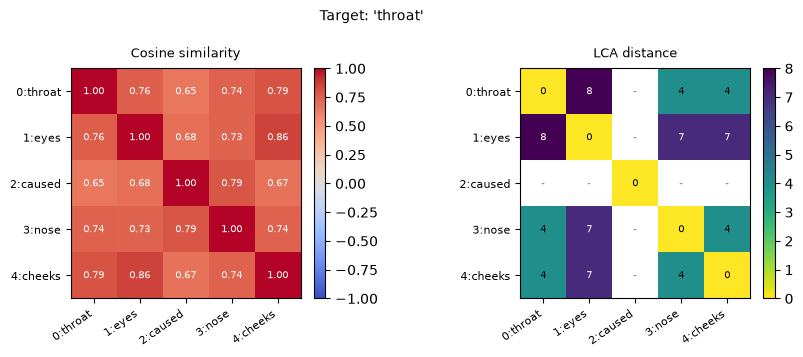


Context: 'It burned Harry’s mouth and throat as it went down,' | Target: 'making'
Top-5        |    0:making |   1:leaving |   2:causing |    3:though |       4:yet
----------------------------------------------------------------------------------
0:making     |      1.0000 |      0.8565 |      0.8977 |      0.6938 |      0.5987
1:leaving    |      0.8565 |      1.0000 |      0.8110 |      0.6769 |      0.6285
2:causing    |      0.8977 |      0.8110 |      1.0000 |      0.6335 |      0.5174
3:though     |      0.6938 |      0.6769 |      0.6335 |      1.0000 |      0.7889
4:yet        |      0.5987 |      0.6285 |      0.5174 |      0.7889 |      1.0000


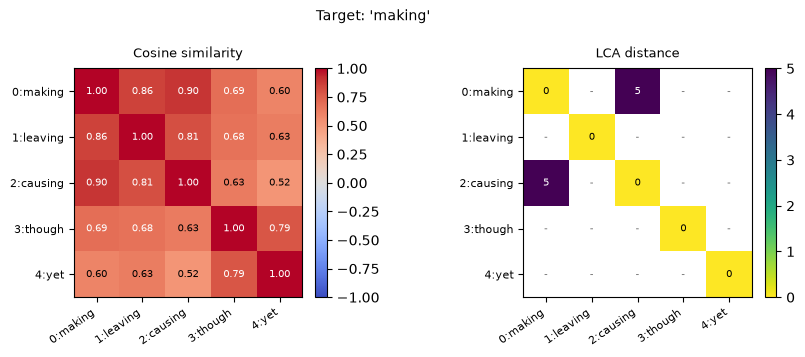


Context: 'It burned Harry’s mouth and throat as it went down, making him' | Target: 'cough'
Top-5        |    0:cough |    1:choke |      2:gag |     3:feel |        4:w
-----------------------------------------------------------------------------
0:cough      |     1.0000 |     0.7126 |     0.6845 |     0.5793 |     0.5565
1:choke      |     0.7126 |     1.0000 |     0.8119 |     0.6929 |     0.6191
2:gag        |     0.6845 |     0.8119 |     1.0000 |     0.6755 |     0.6674
3:feel       |     0.5793 |     0.6929 |     0.6755 |     1.0000 |     0.6092
4:w          |     0.5565 |     0.6191 |     0.6674 |     0.6092 |     1.0000


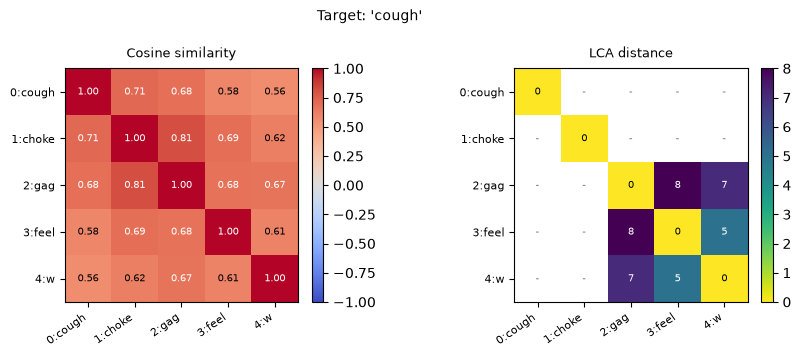


Context: 'It burned Harry’s mouth and throat as it went down, making him cough and' | Target: 'splutter.'
Top-5        |    0:choke |      1:gag |      2:spl |     3:spit |      4:gas
-----------------------------------------------------------------------------
0:choke      |     1.0000 |     0.8119 |     0.4607 |     0.6752 |     0.6699
1:gag        |     0.8119 |     1.0000 |     0.5102 |     0.6660 |     0.7237
2:spl        |     0.4607 |     0.5102 |     1.0000 |     0.4943 |     0.5113
3:spit       |     0.6752 |     0.6660 |     0.4943 |     1.0000 |     0.6419
4:gas        |     0.6699 |     0.7237 |     0.5113 |     0.6419 |     1.0000


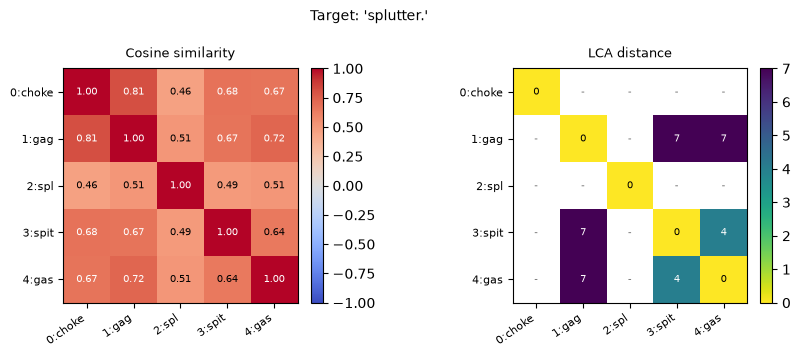


Context: 'Still' | Target: 'tut-tutting'
Top-5           |   0:celebrating |         1:using |         2:birth |       3:working |     4:celebrate
---------------------------------------------------------------------------------------------------------
0:celebrating   |          1.0000 |          0.6937 |          0.5789 |          0.8319 |          0.9362
1:using         |          0.6937 |          1.0000 |          0.5167 |          0.6767 |          0.6556
2:birth         |          0.5789 |          0.5167 |          1.0000 |          0.5890 |          0.5595
3:working       |          0.8319 |          0.6767 |          0.5890 |          1.0000 |          0.7789
4:celebrate     |          0.9362 |          0.6556 |          0.5595 |          0.7789 |          1.0000


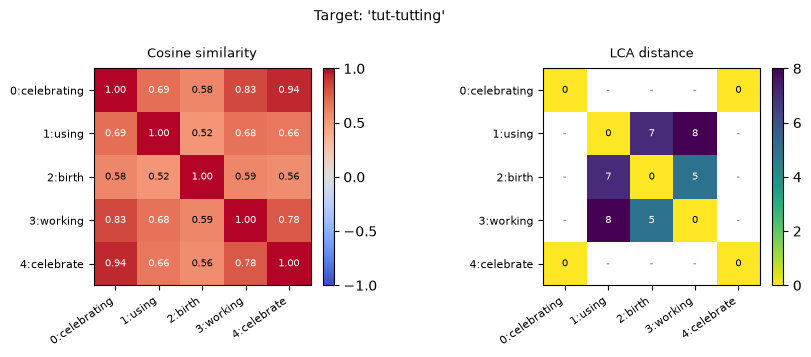


Context: 'Still tut-tutting about dangerous' | Target: 'sports'
Top-5         |      0:levels |     1:climate |   2:chemicals |       3:drugs |     4:drivers
---------------------------------------------------------------------------------------------
0:levels      |        1.0000 |        0.4279 |        0.5425 |        0.5368 |        0.3686
1:climate     |        0.4279 |        1.0000 |        0.5332 |        0.5365 |        0.3724
2:chemicals   |        0.5425 |        0.5332 |        1.0000 |        0.7267 |        0.3906
3:drugs       |        0.5368 |        0.5365 |        0.7267 |        1.0000 |        0.3949
4:drivers     |        0.3686 |        0.3724 |        0.3906 |        0.3949 |        1.0000


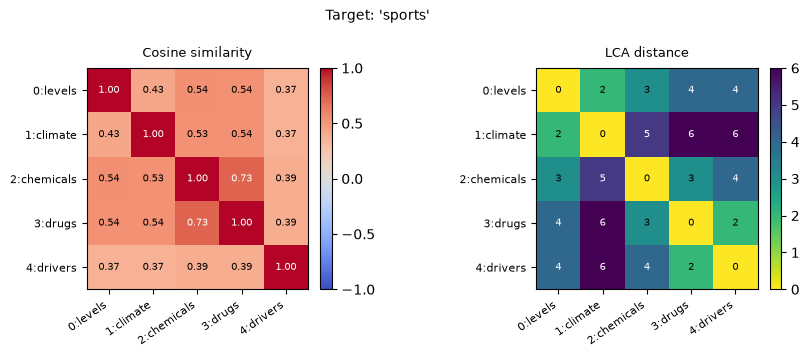


Context: 'Still tut-tutting about dangerous sports and inept' | Target: 'teachers,'
Top-5          |      0:parents |      1:coaches |    2:parenting |   3:regulation |       4:safety
---------------------------------------------------------------------------------------------------
0:parents      |         1.0000 |         0.4540 |         0.7000 |         0.6285 |         0.7131
1:coaches      |         0.4540 |         1.0000 |         0.3924 |         0.5220 |         0.4637
2:parenting    |         0.7000 |         0.3924 |         1.0000 |         0.6534 |         0.6925
3:regulation   |         0.6285 |         0.5220 |         0.6534 |         1.0000 |         0.7369
4:safety       |         0.7131 |         0.4637 |         0.6925 |         0.7369 |         1.0000


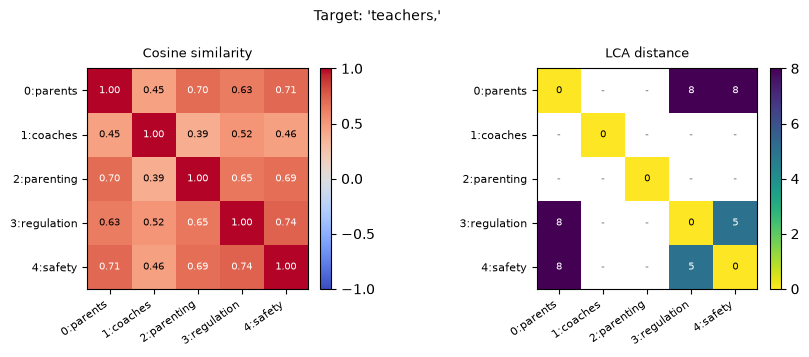


Context: 'Still tut-tutting about dangerous sports and inept teachers,' | Target: 'Madam'
Top-5         |   0:president |      1:though |      2:former |        3:bill |        4:john
---------------------------------------------------------------------------------------------
0:president   |        1.0000 |        0.4708 |        0.5447 |        0.5538 |        0.6494
1:though      |        0.4708 |        1.0000 |        0.3454 |        0.5365 |        0.5775
2:former      |        0.5447 |        0.3454 |        1.0000 |        0.4384 |        0.4542
3:bill        |        0.5538 |        0.5365 |        0.4384 |        1.0000 |        0.6065
4:john        |        0.6494 |        0.5775 |        0.4542 |        0.6065 |        1.0000


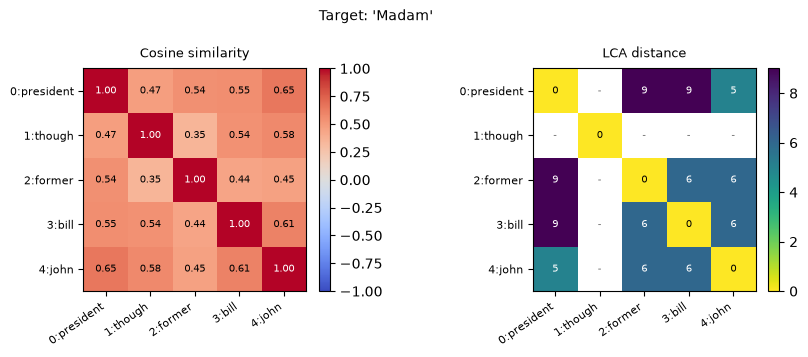


Context: 'Still tut-tutting about dangerous sports and inept teachers, Madam' | Target: 'Pomfrey'
Top-5         |   0:secretary |     1:justice |   2:president |    3:margaret |     4:speaker
---------------------------------------------------------------------------------------------
0:secretary   |        1.0000 |        0.6285 |        0.7542 |        0.5888 |        0.5919
1:justice     |        0.6285 |        1.0000 |        0.6381 |        0.5617 |        0.5752
2:president   |        0.7542 |        0.6381 |        1.0000 |        0.5768 |        0.6683
3:margaret    |        0.5888 |        0.5617 |        0.5768 |        1.0000 |        0.5256
4:speaker     |        0.5919 |        0.5752 |        0.6683 |        0.5256 |        1.0000


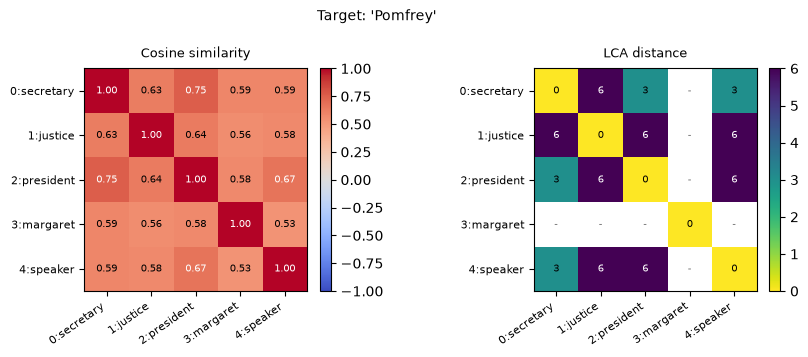


Context: 'Still tut-tutting about dangerous sports and inept teachers, Madam Pomfrey' | Target: 'retreated,'
Top-5         |       0:still |   1:continues |         2:sat |       3:looks |       4:seems
---------------------------------------------------------------------------------------------
0:still       |        1.0000 |        0.4446 |        0.3499 |        0.4540 |        0.4744
1:continues   |        0.4446 |        1.0000 |        0.5926 |        0.7091 |        0.7250
2:sat         |        0.3499 |        0.5926 |        1.0000 |        0.7069 |        0.6312
3:looks       |        0.4540 |        0.7091 |        0.7069 |        1.0000 |        0.8092
4:seems       |        0.4744 |        0.7250 |        0.6312 |        0.8092 |        1.0000


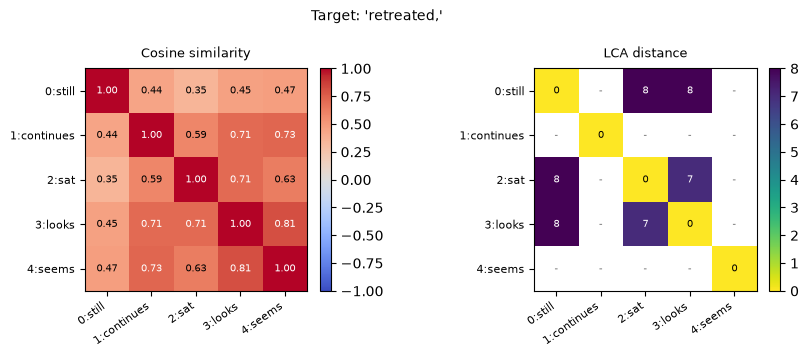


Context: 'Still tut-tutting about dangerous sports and inept teachers, Madam Pomfrey retreated,' | Target: 'leaving'
Top-5        |   0:leaving |       1:mut |   2:closing |   3:shaking |     4:still
----------------------------------------------------------------------------------
0:leaving    |      1.0000 |      0.5133 |      0.8403 |      0.8319 |      0.4634
1:mut        |      0.5133 |      1.0000 |      0.4426 |      0.5157 |      0.3502
2:closing    |      0.8403 |      0.4426 |      1.0000 |      0.7233 |      0.3933
3:shaking    |      0.8319 |      0.5157 |      0.7233 |      1.0000 |      0.4429
4:still      |      0.4634 |      0.3502 |      0.3933 |      0.4429 |      1.0000


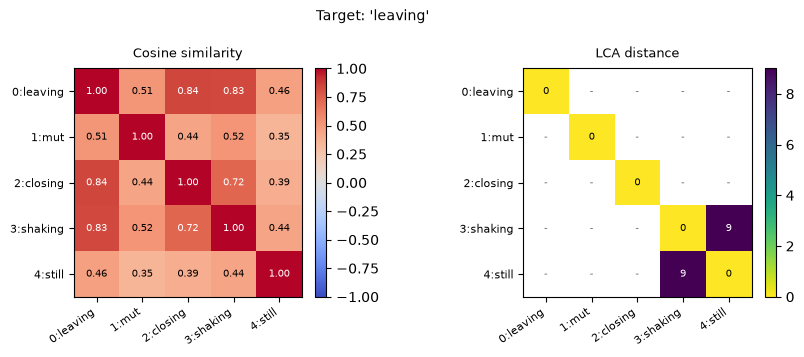


Context: 'Still tut-tutting about dangerous sports and inept teachers, Madam Pomfrey retreated, leaving' | Target: 'Ron'
Top-5          |        0:harry |     1:hermione |          2:ron |   3:dumbledore |            4:h
---------------------------------------------------------------------------------------------------
0:harry        |         1.0000 |         0.4042 |         0.8624 |         0.3280 |         0.6282
1:hermione     |         0.4042 |         1.0000 |         0.3613 |         0.3562 |         0.3197
2:ron          |         0.8624 |         0.3613 |         1.0000 |         0.3439 |         0.6003
3:dumbledore   |         0.3280 |         0.3562 |         0.3439 |         1.0000 |         0.2244
4:h            |         0.6282 |         0.3197 |         0.6003 |         0.2244 |         1.0000


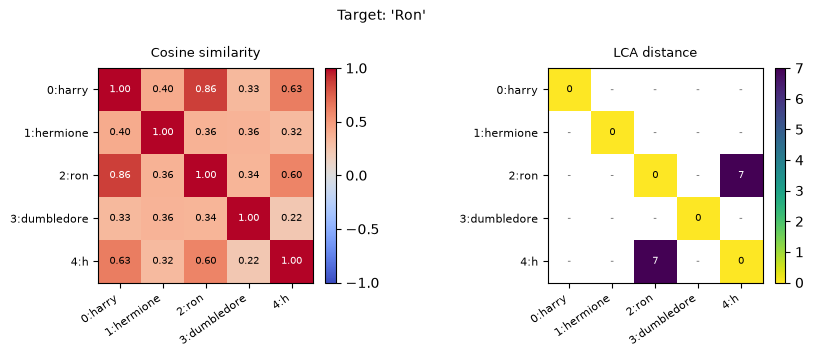


Context: 'Still tut-tutting about dangerous sports and inept teachers, Madam Pomfrey retreated, leaving Ron and' | Target: 'Hermione'
Top-5        |      0:harry |   1:hermione |    2:neville |          3:h |       4:dean
---------------------------------------------------------------------------------------
0:harry      |       1.0000 |       0.4042 |       0.8123 |       0.6282 |       0.8824
1:hermione   |       0.4042 |       1.0000 |       0.3695 |       0.3197 |       0.3700
2:neville    |       0.8123 |       0.3695 |       1.0000 |       0.5382 |       0.8017
3:h          |       0.6282 |       0.3197 |       0.5382 |       1.0000 |       0.6562
4:dean       |       0.8824 |       0.3700 |       0.8017 |       0.6562 |       1.0000


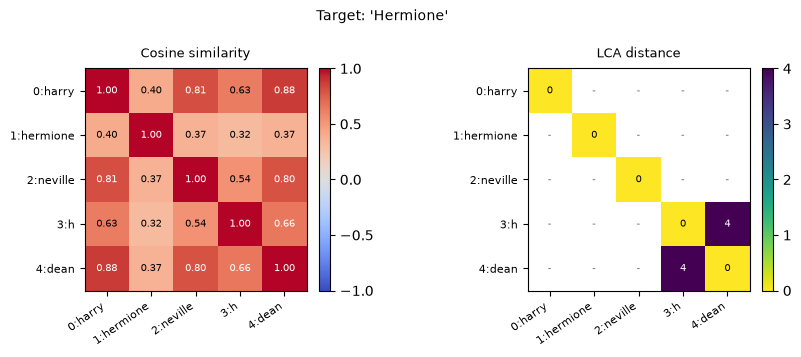


Context: 'Still tut-tutting about dangerous sports and inept teachers, Madam Pomfrey retreated, leaving Ron and Hermione to' | Target: 'help'
Top-5        |      0:stare |   1:continue |        2:sit |     3:finish |    4:discuss
---------------------------------------------------------------------------------------
0:stare      |       1.0000 |       0.6077 |       0.6737 |       0.6141 |       0.7320
1:continue   |       0.6077 |       1.0000 |       0.5949 |       0.5801 |       0.7037
2:sit        |       0.6737 |       0.5949 |       1.0000 |       0.5475 |       0.6414
3:finish     |       0.6141 |       0.5801 |       0.5475 |       1.0000 |       0.5893
4:discuss    |       0.7320 |       0.7037 |       0.6414 |       0.5893 |       1.0000


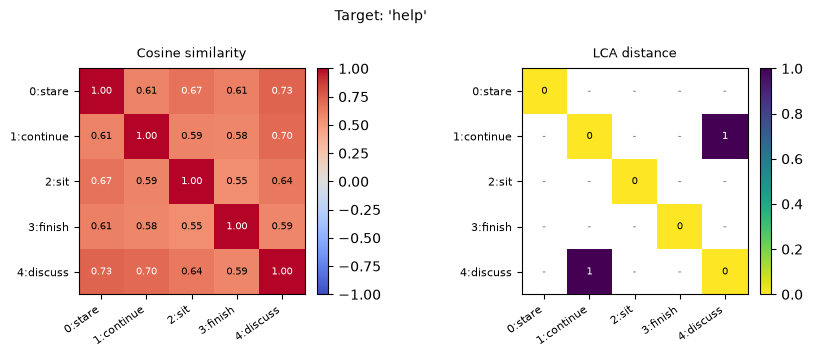


Context: 'Still tut-tutting about dangerous sports and inept teachers, Madam Pomfrey retreated, leaving Ron and Hermione to help' | Target: 'Harry'
Top-5        |     0:harry |   1:neville |    2:george |         3:h |     4:ginny
----------------------------------------------------------------------------------
0:harry      |      1.0000 |      0.8123 |      0.7878 |      0.6282 |      0.6518
1:neville    |      0.8123 |      1.0000 |      0.7711 |      0.5382 |      0.5721
2:george     |      0.7878 |      0.7711 |      1.0000 |      0.6208 |      0.5583
3:h          |      0.6282 |      0.5382 |      0.6208 |      1.0000 |      0.4498
4:ginny      |      0.6518 |      0.5721 |      0.5583 |      0.4498 |      1.0000


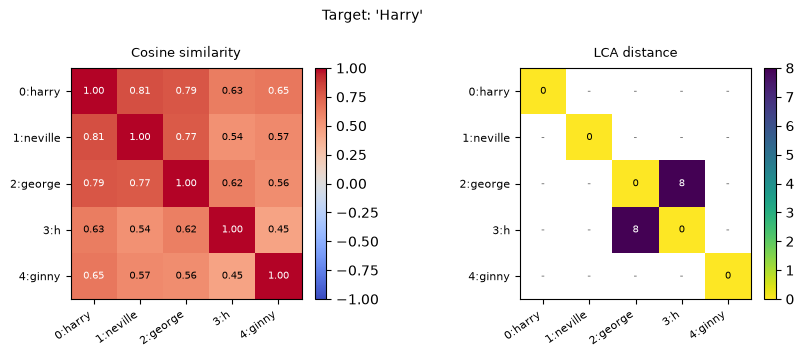


Context: 'Still tut-tutting about dangerous sports and inept teachers, Madam Pomfrey retreated, leaving Ron and Hermione to help Harry' | Target: 'gulp'
Top-5        |      0:pack |     1:clean |    2:finish |      3:back |   4:prepare
----------------------------------------------------------------------------------
0:pack       |      1.0000 |      0.6373 |      0.5537 |      0.6791 |      0.6712
1:clean      |      0.6373 |      1.0000 |      0.5794 |      0.6210 |      0.6899
2:finish     |      0.5537 |      0.5794 |      1.0000 |      0.5385 |      0.6329
3:back       |      0.6791 |      0.6210 |      0.5385 |      1.0000 |      0.6377
4:prepare    |      0.6712 |      0.6899 |      0.6329 |      0.6377 |      1.0000


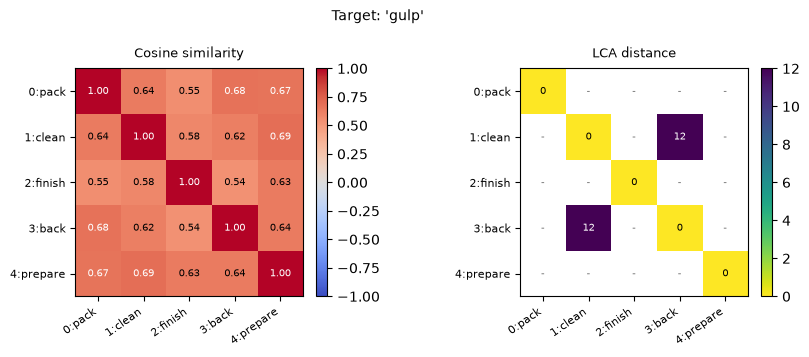


Context: 'Still tut-tutting about dangerous sports and inept teachers, Madam Pomfrey retreated, leaving Ron and Hermione to help Harry gulp down some' | Target: 'water.'
Top-5        |    0:potion |   1:potions |      2:foul |       3:ske |     4:thick
----------------------------------------------------------------------------------
0:potion     |      1.0000 |      0.5413 |      0.7164 |      0.4834 |      0.7781
1:potions    |      0.5413 |      1.0000 |      0.4380 |      0.3940 |      0.4125
2:foul       |      0.7164 |      0.4380 |      1.0000 |      0.5089 |      0.7279
3:ske        |      0.4834 |      0.3940 |      0.5089 |      1.0000 |      0.4943
4:thick      |      0.7781 |      0.4125 |      0.7279 |      0.4943 |      1.0000


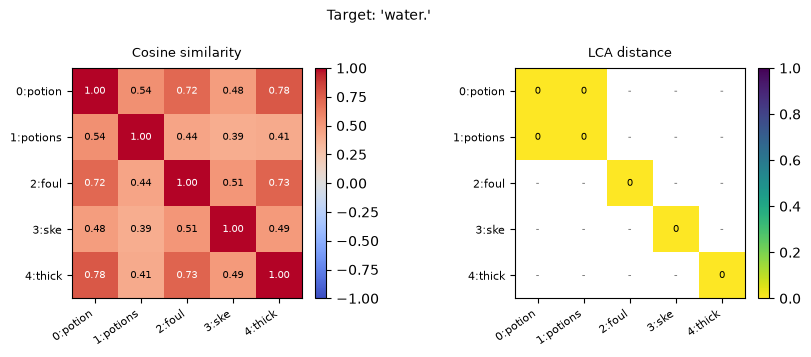


Context: '“We won,' | Target: 'though,”'
Top-5        |    0:thanks |     1:thank |       2:yes |    3:ladies |   4:despite
----------------------------------------------------------------------------------
0:thanks     |      1.0000 |      0.7948 |      0.6043 |      0.4832 |      0.5386
1:thank      |      0.7948 |      1.0000 |      0.6698 |      0.4976 |      0.6059
2:yes        |      0.6043 |      0.6698 |      1.0000 |      0.4781 |      0.6119
3:ladies     |      0.4832 |      0.4976 |      0.4781 |      1.0000 |      0.5558
4:despite    |      0.5386 |      0.6059 |      0.6119 |      0.5558 |      1.0000


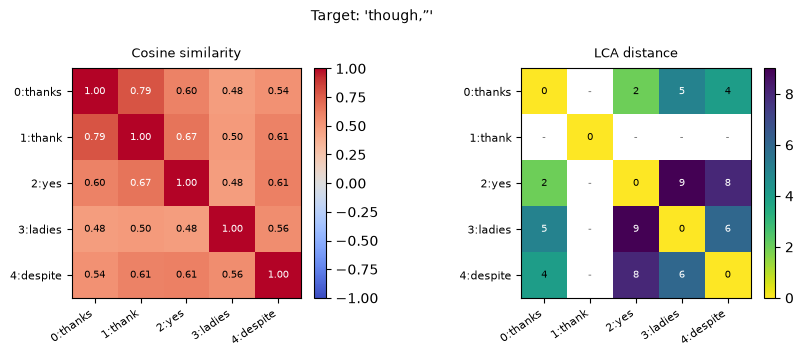


Context: '“We won, though,” said' | Target: 'Ron,'
Top-5        |        0:k |   1:senior |    2:chris |        3:g |       4:mr
-----------------------------------------------------------------------------
0:k          |     1.0000 |     0.5529 |     0.6229 |     0.7793 |     0.6411
1:senior     |     0.5529 |     1.0000 |     0.6127 |     0.6813 |     0.6749
2:chris      |     0.6229 |     0.6127 |     1.0000 |     0.6487 |     0.7599
3:g          |     0.7793 |     0.6813 |     0.6487 |     1.0000 |     0.6705
4:mr         |     0.6411 |     0.6749 |     0.7599 |     0.6705 |     1.0000


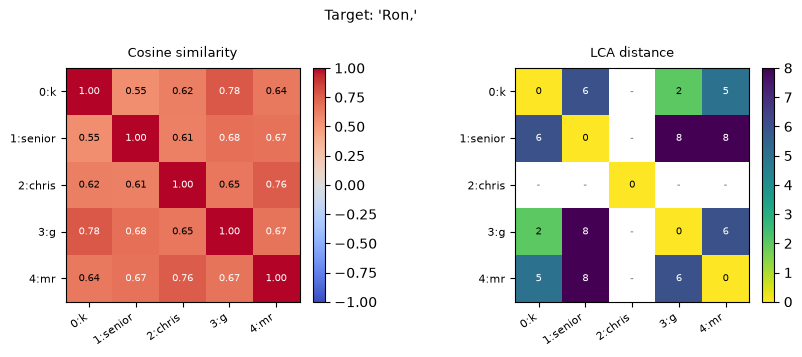


Context: '“We won, though,” said Ron, a' | Target: 'grin'
Top-5        |   0:little |   1:member |      2:bit |   3:former |   4:senior
-----------------------------------------------------------------------------
0:little     |     1.0000 |     0.5589 |     0.6506 |     0.4210 |     0.6000
1:member     |     0.5589 |     1.0000 |     0.5214 |     0.6670 |     0.6367
2:bit        |     0.6506 |     0.5214 |     1.0000 |     0.3778 |     0.5929
3:former     |     0.4210 |     0.6670 |     0.3778 |     1.0000 |     0.5187
4:senior     |     0.6000 |     0.6367 |     0.5929 |     0.5187 |     1.0000


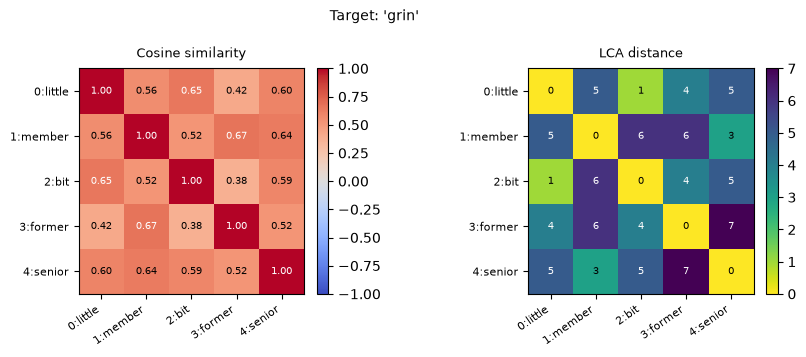


Context: '“We won, though,” said Ron, a grin' | Target: 'breaking'
Top-5          |    0:spreading |     1:breaking |     2:lighting |   3:stretching |    4:appearing
---------------------------------------------------------------------------------------------------
0:spreading    |         1.0000 |         0.8897 |         0.7722 |         0.9025 |         0.7867
1:breaking     |         0.8897 |         1.0000 |         0.7623 |         0.8301 |         0.7682
2:lighting     |         0.7722 |         0.7623 |         1.0000 |         0.7962 |         0.7315
3:stretching   |         0.9025 |         0.8301 |         0.7962 |         1.0000 |         0.7524
4:appearing    |         0.7867 |         0.7682 |         0.7315 |         0.7524 |         1.0000


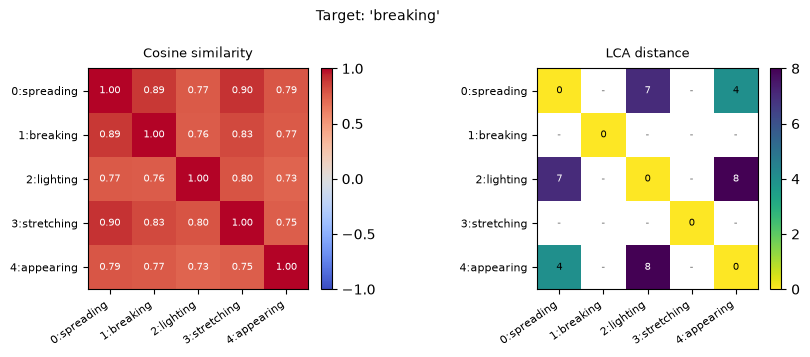


Context: '“We won, though,” said Ron, a grin breaking' | Target: 'across'
Top-5        |   0:across |     1:onto |     2:free |     3:upon |     4:open
-----------------------------------------------------------------------------
0:across     |     1.0000 |     0.6916 |     0.6082 |     0.5842 |     0.5528
1:onto       |     0.6916 |     1.0000 |     0.7263 |     0.8234 |     0.6495
2:free       |     0.6082 |     0.7263 |     1.0000 |     0.6659 |     0.6970
3:upon       |     0.5842 |     0.8234 |     0.6659 |     1.0000 |     0.5687
4:open       |     0.5528 |     0.6495 |     0.6970 |     0.5687 |     1.0000


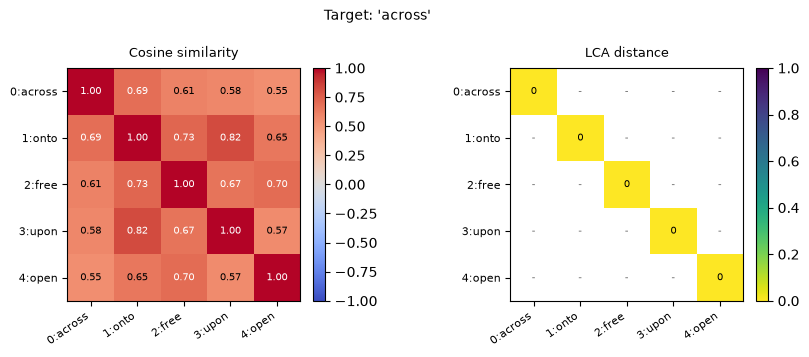


Context: '“We won, though,” said Ron, a grin breaking across his' | Target: 'face.'
Top-5        |       0:face |   1:features |    2:weather |       3:scar |    4:usually
---------------------------------------------------------------------------------------
0:face       |       1.0000 |       0.7111 |       0.6021 |       0.7390 |       0.6880
1:features   |       0.7111 |       1.0000 |       0.5929 |       0.6554 |       0.7112
2:weather    |       0.6021 |       0.5929 |       1.0000 |       0.5430 |       0.5876
3:scar       |       0.7390 |       0.6554 |       0.5430 |       1.0000 |       0.6925
4:usually    |       0.6880 |       0.7112 |       0.5876 |       0.6925 |       1.0000


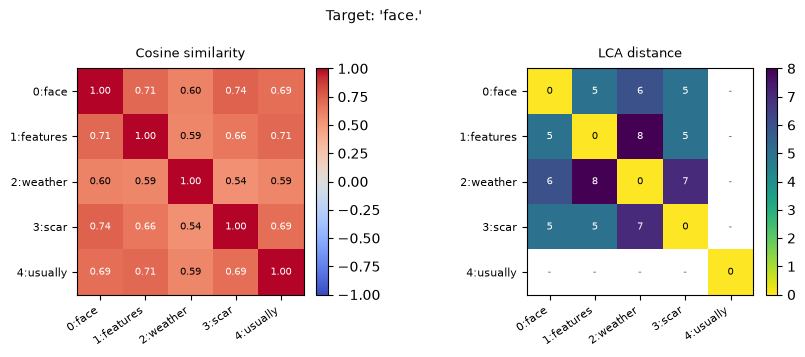


Context: '“That was some' | Target: 'catch'
Top-5        |     0:kind |     1:good |     2:time |    3:dream |    4:great
-----------------------------------------------------------------------------
0:kind       |     1.0000 |     0.5508 |     0.7338 |     0.6551 |     0.6686
1:good       |     0.5508 |     1.0000 |     0.5347 |     0.4880 |     0.7382
2:time       |     0.7338 |     0.5347 |     1.0000 |     0.6619 |     0.6451
3:dream      |     0.6551 |     0.4880 |     0.6619 |     1.0000 |     0.4888
4:great      |     0.6686 |     0.7382 |     0.6451 |     0.4888 |     1.0000


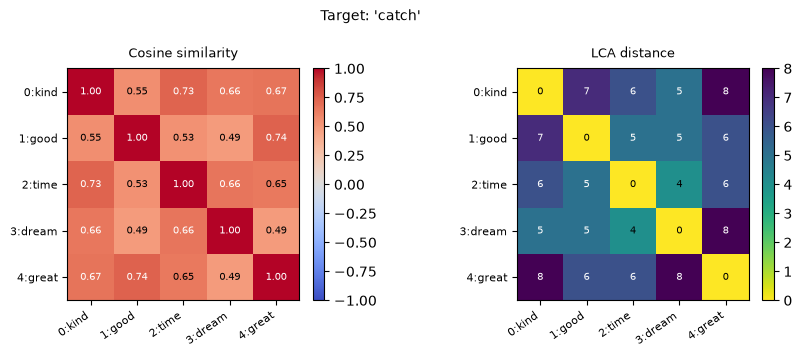


Context: 'Malfoy’s' | Target: 'face'
Top-5        |   0:father |   1:mother |   2:family |      3:son |      4:mal
-----------------------------------------------------------------------------
0:father     |     1.0000 |     0.9228 |     0.7734 |     0.8216 |     0.7640
1:mother     |     0.9228 |     1.0000 |     0.7990 |     0.7940 |     0.7444
2:family     |     0.7734 |     0.7990 |     1.0000 |     0.7748 |     0.7335
3:son        |     0.8216 |     0.7940 |     0.7748 |     1.0000 |     0.7024
4:mal        |     0.7640 |     0.7444 |     0.7335 |     0.7024 |     1.0000


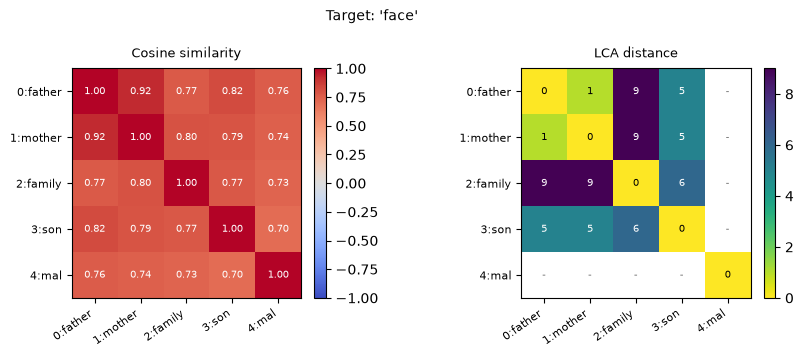


Context: 'he' | Target: 'looked'
Top-5        |         0:p |     1:first |        2:ic |   3:average |        4:al
----------------------------------------------------------------------------------
0:p          |      1.0000 |      0.3799 |      0.5552 |      0.4673 |      0.5934
1:first      |      0.3799 |      1.0000 |      0.5398 |      0.4751 |      0.5276
2:ic         |      0.5552 |      0.5398 |      1.0000 |      0.4941 |      0.8013
3:average    |      0.4673 |      0.4751 |      0.4941 |      1.0000 |      0.4462
4:al         |      0.5934 |      0.5276 |      0.8013 |      0.4462 |      1.0000


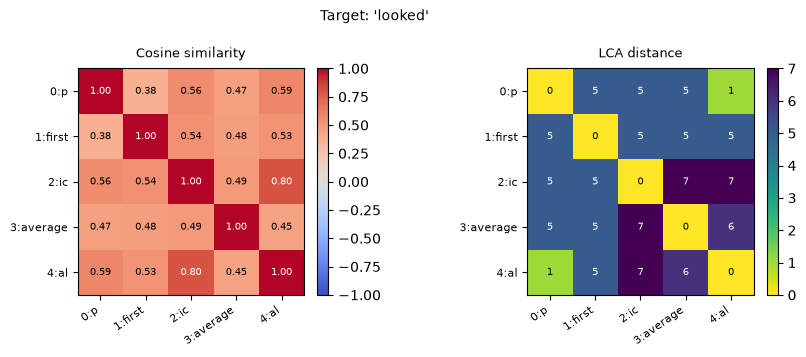


Context: 'he looked' | Target: 'ready'
Top-5        |    0:around |      1:back |   2:forward |      3:upon |    4:behind
----------------------------------------------------------------------------------
0:around     |      1.0000 |      0.6622 |      0.6491 |      0.6502 |      0.7863
1:back       |      0.6622 |      1.0000 |      0.7652 |      0.6651 |      0.6947
2:forward    |      0.6491 |      0.7652 |      1.0000 |      0.6811 |      0.6828
3:upon       |      0.6502 |      0.6651 |      0.6811 |      1.0000 |      0.6276
4:behind     |      0.7863 |      0.6947 |      0.6828 |      0.6276 |      1.0000


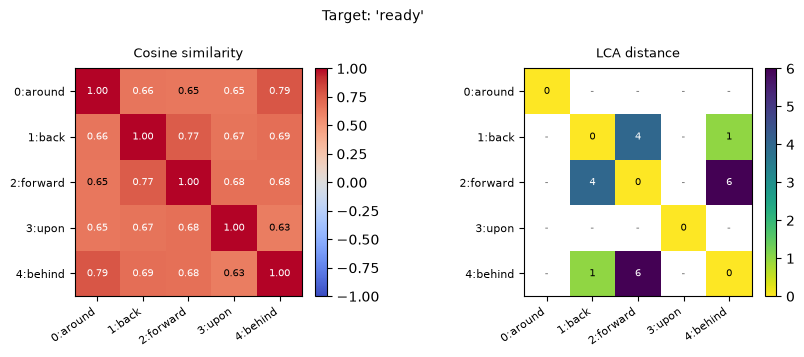


Context: 'he looked ready to' | Target: 'kill.'
Top-5        |      0:jump |     1:burst |         2:p |   3:explode |      4:take
----------------------------------------------------------------------------------
0:jump       |      1.0000 |      0.8189 |      0.3946 |      0.8080 |      0.7237
1:burst      |      0.8189 |      1.0000 |      0.4116 |      0.8543 |      0.7324
2:p          |      0.3946 |      0.4116 |      1.0000 |      0.4611 |      0.4461
3:explode    |      0.8080 |      0.8543 |      0.4611 |      1.0000 |      0.7633
4:take       |      0.7237 |      0.7324 |      0.4461 |      0.7633 |      1.0000


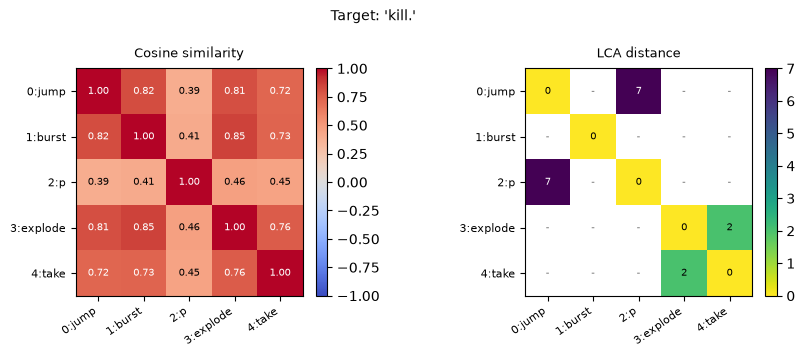


Context: '.” “I' | Target: 'want'
Top-5        |    0:think |     1:know |     2:want |    3:guess |      4:see
-----------------------------------------------------------------------------
0:think      |     1.0000 |     0.7372 |     0.7300 |     0.7172 |     0.6476
1:know       |     0.7372 |     1.0000 |     0.7659 |     0.6816 |     0.7738
2:want       |     0.7300 |     0.7659 |     1.0000 |     0.7081 |     0.6371
3:guess      |     0.7172 |     0.6816 |     0.7081 |     1.0000 |     0.6439
4:see        |     0.6476 |     0.7738 |     0.6371 |     0.6439 |     1.0000


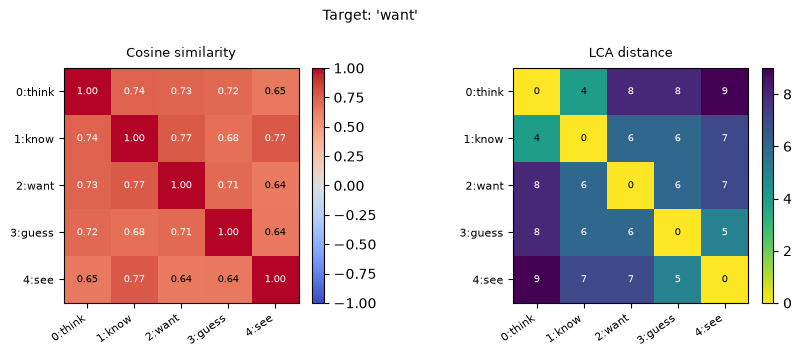


Context: '.” “I want to' | Target: 'know'
Top-5        |      0:see |     1:know |     2:help |     3:talk |     4:take
-----------------------------------------------------------------------------
0:see        |     1.0000 |     0.7738 |     0.6197 |     0.7173 |     0.6679
1:know       |     0.7738 |     1.0000 |     0.7416 |     0.7608 |     0.7842
2:help       |     0.6197 |     0.7416 |     1.0000 |     0.7445 |     0.7621
3:talk       |     0.7173 |     0.7608 |     0.7445 |     1.0000 |     0.7631
4:take       |     0.6679 |     0.7842 |     0.7621 |     0.7631 |     1.0000


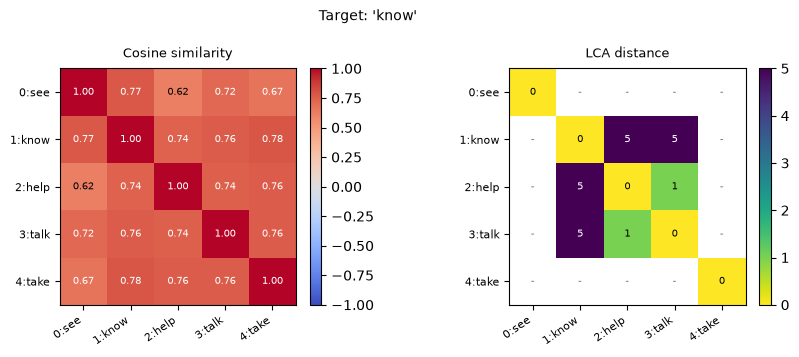


Context: '.” “I want to know how he fixed that' | Target: 'Bludger,”'
Top-5        |     0:thing |       1:old |   2:problem |       3:car |      4:hole
----------------------------------------------------------------------------------
0:thing      |      1.0000 |      0.5681 |      0.6733 |      0.5519 |      0.7161
1:old        |      0.5681 |      1.0000 |      0.4637 |      0.4638 |      0.5632
2:problem    |      0.6733 |      0.4637 |      1.0000 |      0.4941 |      0.6982
3:car        |      0.5519 |      0.4638 |      0.4941 |      1.0000 |      0.5314
4:hole       |      0.7161 |      0.5632 |      0.6982 |      0.5314 |      1.0000


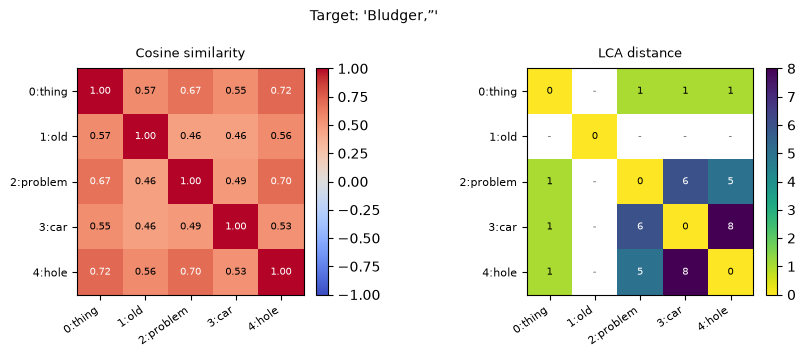


Context: '.” “I want to know how he fixed that Bludger,” said' | Target: 'Hermione'
Top-5        |     0:harry |       1:ron |      2:fred |   3:neville |      4:dean
----------------------------------------------------------------------------------
0:harry      |      1.0000 |      0.8624 |      0.8744 |      0.8123 |      0.8824
1:ron        |      0.8624 |      1.0000 |      0.8508 |      0.7913 |      0.8633
2:fred       |      0.8744 |      0.8508 |      1.0000 |      0.7759 |      0.8657
3:neville    |      0.8123 |      0.7913 |      0.7759 |      1.0000 |      0.8017
4:dean       |      0.8824 |      0.8633 |      0.8657 |      0.8017 |      1.0000


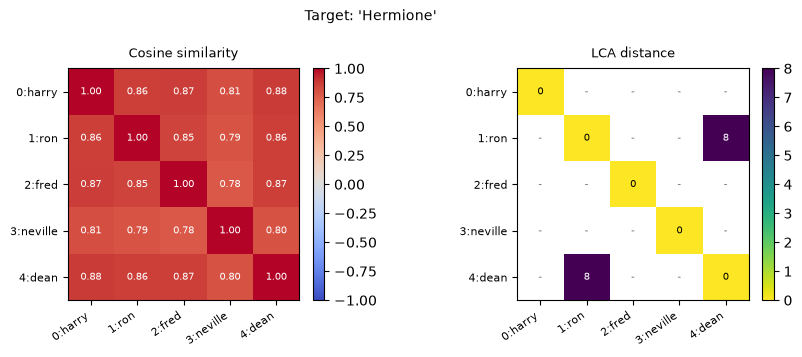


Context: '.” “I want to know how he fixed that Bludger,” said Hermione' | Target: 'darkly.'
Top-5                |            0:eagerly |   1:enthusiastically |                 2:gr |            3:quietly |               4:ferv
---------------------------------------------------------------------------------------------------------------------------------------
0:eagerly            |               1.0000 |               0.8764 |               0.7292 |               0.6976 |               0.4669
1:enthusiastically   |               0.8764 |               1.0000 |               0.6452 |               0.6817 |               0.4677
2:gr                 |               0.7292 |               0.6452 |               1.0000 |               0.6450 |               0.5315
3:quietly            |               0.6976 |               0.6817 |               0.6450 |               1.0000 |               0.4482
4:ferv               |               0.4669 |               0.4677 |               0.5315 |

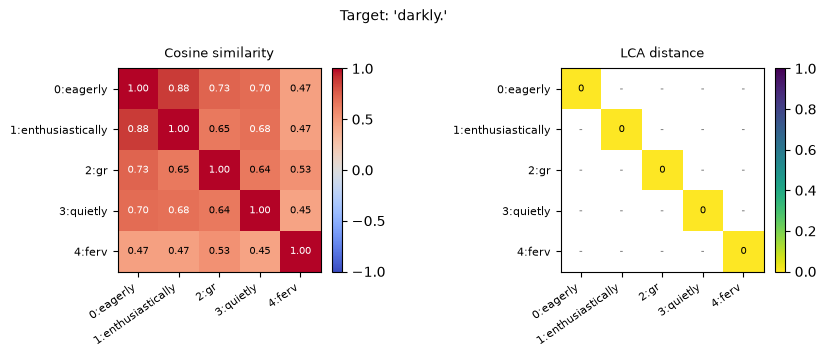


Context: '“We can' | Target: 'add'
Top-5        |    0:never |      1:see |      2:use |     3:help |    4:learn
-----------------------------------------------------------------------------
0:never      |     1.0000 |     0.6589 |     0.6122 |     0.6697 |     0.6514
1:see        |     0.6589 |     1.0000 |     0.7420 |     0.6197 |     0.7103
2:use        |     0.6122 |     0.7420 |     1.0000 |     0.6707 |     0.7717
3:help       |     0.6697 |     0.6197 |     0.6707 |     1.0000 |     0.6708
4:learn      |     0.6514 |     0.7103 |     0.7717 |     0.6708 |     1.0000


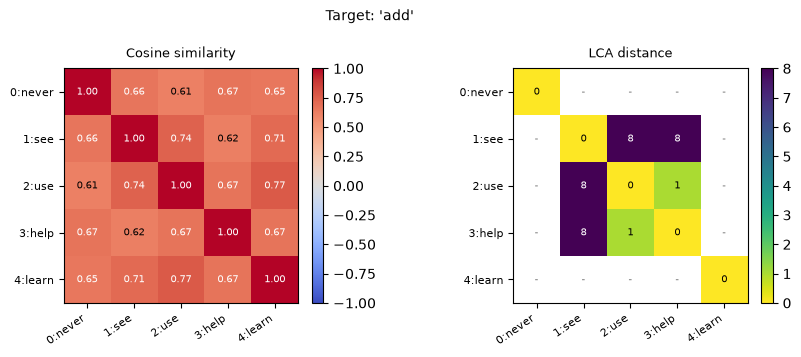


Context: '“We can add that to the' | Target: 'list'
Top-5        |      0:list |      1:long |   2:growing |      3:pile |    4:record
----------------------------------------------------------------------------------
0:list       |      1.0000 |      0.5283 |      0.6239 |      0.6727 |      0.4714
1:long       |      0.5283 |      1.0000 |      0.6488 |      0.6394 |      0.2524
2:growing    |      0.6239 |      0.6488 |      1.0000 |      0.9017 |      0.2906
3:pile       |      0.6727 |      0.6394 |      0.9017 |      1.0000 |      0.3170
4:record     |      0.4714 |      0.2524 |      0.2906 |      0.3170 |      1.0000


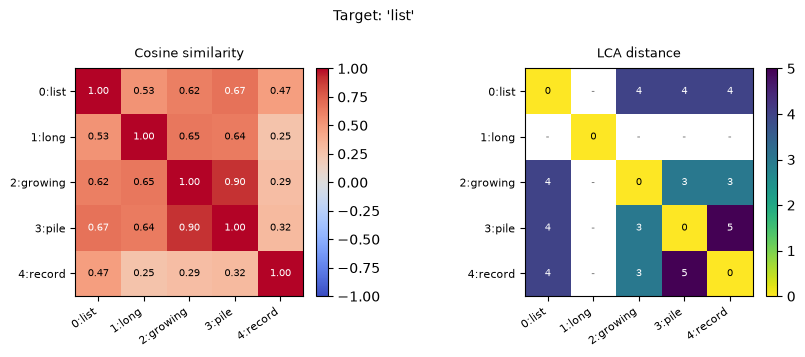


Context: '“We can add that to the list of' | Target: 'questions'
Top-5        |     0:things |    1:reasons |       2:ways |   3:problems |        4:bad
---------------------------------------------------------------------------------------
0:things     |       1.0000 |       0.6368 |       0.7080 |       0.6759 |       0.5915
1:reasons    |       0.6368 |       1.0000 |       0.6521 |       0.6349 |       0.5573
2:ways       |       0.7080 |       0.6521 |       1.0000 |       0.6806 |       0.5954
3:problems   |       0.6759 |       0.6349 |       0.6806 |       1.0000 |       0.5183
4:bad        |       0.5915 |       0.5573 |       0.5954 |       0.5183 |       1.0000


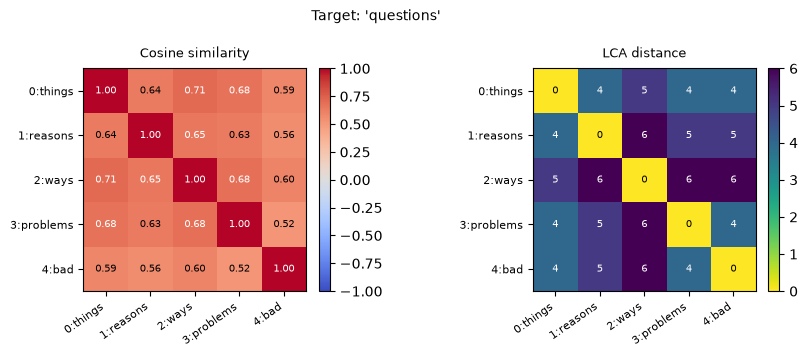


Context: '“We can add that to the list of questions we’ll' | Target: 'ask'
Top-5        |       0:need |      1:never |        2:ask |     3:answer |   4:probably
---------------------------------------------------------------------------------------
0:need       |       1.0000 |       0.7531 |       0.7500 |       0.7317 |       0.6952
1:never      |       0.7531 |       1.0000 |       0.7237 |       0.6979 |       0.7489
2:ask        |       0.7500 |       0.7237 |       1.0000 |       0.8082 |       0.6748
3:answer     |       0.7317 |       0.6979 |       0.8082 |       1.0000 |       0.6245
4:probably   |       0.6952 |       0.7489 |       0.6748 |       0.6245 |       1.0000


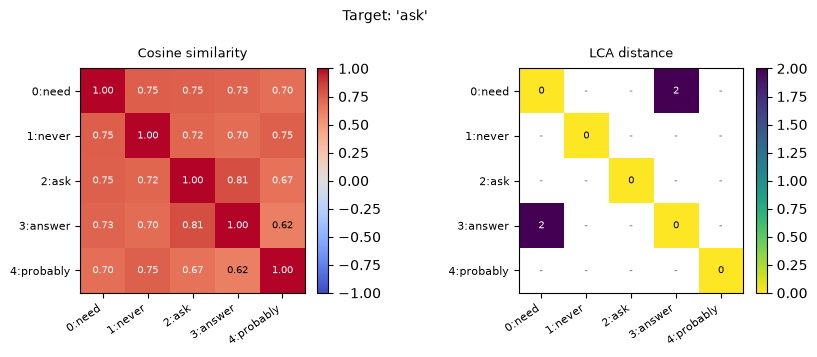


Context: '“We can add that to the list of questions we’ll ask him when' | Target: 'we’ve'
Top-5         |       0:trump |      1:donald |   2:president |         3:joe |      4:bernie
---------------------------------------------------------------------------------------------
0:trump       |        1.0000 |        0.7339 |        0.6178 |        0.5991 |        0.6947
1:donald      |        0.7339 |        1.0000 |        0.6521 |        0.6722 |        0.7467
2:president   |        0.6178 |        0.6521 |        1.0000 |        0.5885 |        0.6335
3:joe         |        0.5991 |        0.6722 |        0.5885 |        1.0000 |        0.7784
4:bernie      |        0.6947 |        0.7467 |        0.6335 |        0.7784 |        1.0000


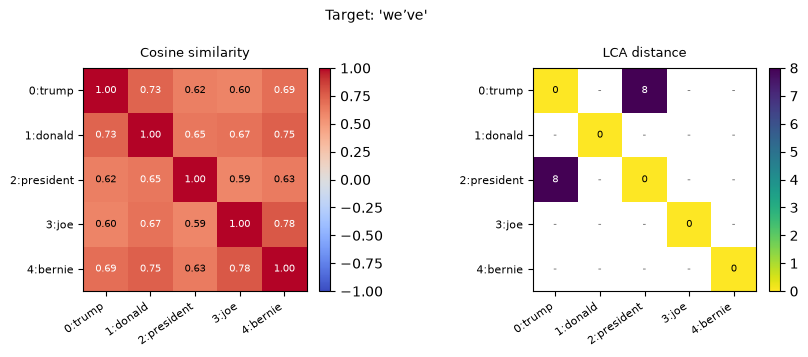


Context: '“We can add that to the list of questions we’ll ask him when we’ve taken the' | Target: 'Polyjuice'
Top-5        |    0:field |     1:time |    2:floor |     3:oath |    4:stand
-----------------------------------------------------------------------------
0:field      |     1.0000 |     0.5162 |     0.5287 |     0.4476 |     0.4381
1:time       |     0.5162 |     1.0000 |     0.6781 |     0.6386 |     0.5697
2:floor      |     0.5287 |     0.6781 |     1.0000 |     0.6343 |     0.5479
3:oath       |     0.4476 |     0.6386 |     0.6343 |     1.0000 |     0.5433
4:stand      |     0.4381 |     0.5697 |     0.5479 |     0.5433 |     1.0000


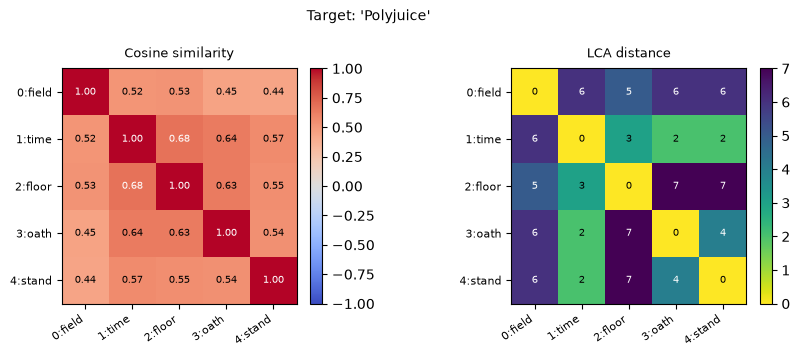


Context: '“We can add that to the list of questions we’ll ask him when we’ve taken the Polyjuice' | Target: 'Potion,”'
Top-5        |    0:potion |   1:formula |       2:pot |    3:powder |      4:back
----------------------------------------------------------------------------------
0:potion     |      1.0000 |      0.3885 |      0.8158 |      0.6469 |      0.6606
1:formula    |      0.3885 |      1.0000 |      0.4564 |      0.4127 |      0.3499
2:pot        |      0.8158 |      0.4564 |      1.0000 |      0.6374 |      0.6781
3:powder     |      0.6469 |      0.4127 |      0.6374 |      1.0000 |      0.5750
4:back       |      0.6606 |      0.3499 |      0.6781 |      0.5750 |      1.0000


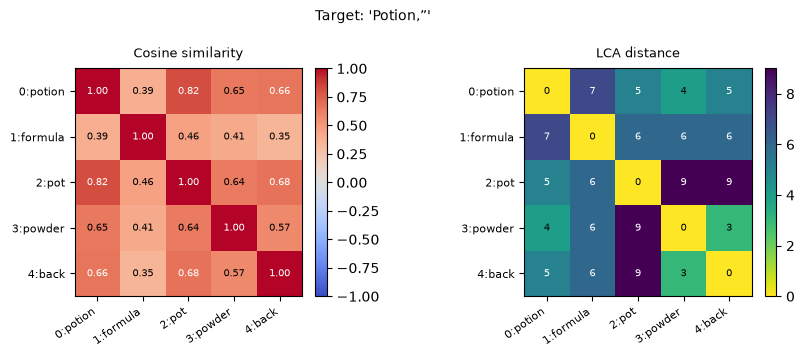


Context: '“We can add that to the list of questions we’ll ask him when we’ve taken the Polyjuice Potion,” said' | Target: 'Harry,'
Top-5        |        0:ron |      1:harry |   2:hermione |       3:fred |         4:se
---------------------------------------------------------------------------------------
0:ron        |       1.0000 |       0.8624 |       0.3613 |       0.8508 |       0.6615
1:harry      |       0.8624 |       1.0000 |       0.4042 |       0.8744 |       0.6943
2:hermione   |       0.3613 |       0.4042 |       1.0000 |       0.3707 |       0.2953
3:fred       |       0.8508 |       0.8744 |       0.3707 |       1.0000 |       0.6770
4:se         |       0.6615 |       0.6943 |       0.2953 |       0.6770 |       1.0000


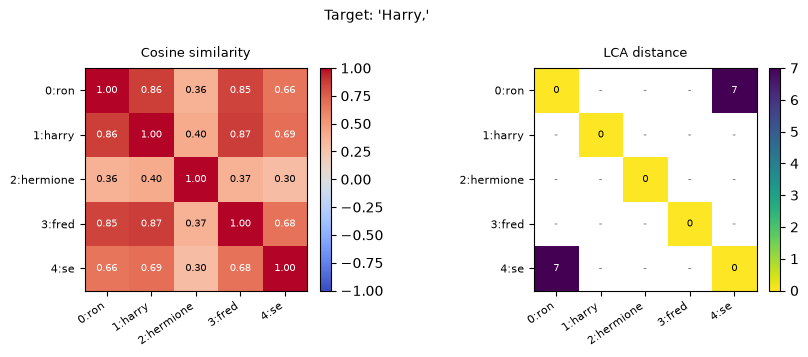


Context: '“We can add that to the list of questions we’ll ask him when we’ve taken the Polyjuice Potion,” said Harry,' | Target: 'sinking'
Top-5        |   0:feeling |        1:gr |     2:still |   3:smiling |       4:nod
----------------------------------------------------------------------------------
0:feeling    |      1.0000 |      0.6801 |      0.4094 |      0.6609 |      0.5969
1:gr         |      0.6801 |      1.0000 |      0.3354 |      0.5623 |      0.5214
2:still      |      0.4094 |      0.3354 |      1.0000 |      0.3605 |      0.3642
3:smiling    |      0.6609 |      0.5623 |      0.3605 |      1.0000 |      0.6795
4:nod        |      0.5969 |      0.5214 |      0.3642 |      0.6795 |      1.0000


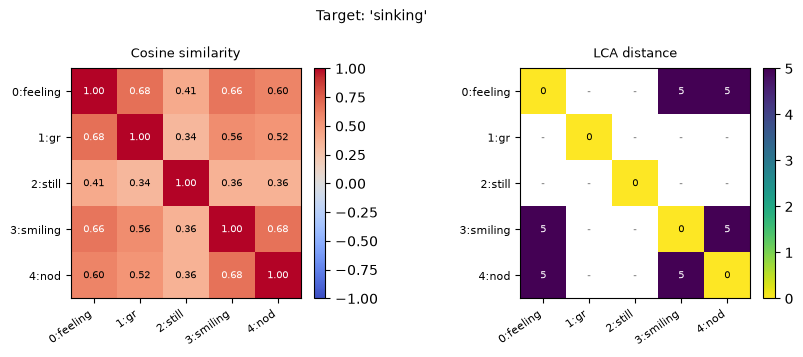


Context: '“We can add that to the list of questions we’ll ask him when we’ve taken the Polyjuice Potion,” said Harry, sinking' | Target: 'back'
Top-5        |     0:back |   1:deeper |    2:lower |     3:onto |   4:slowly
-----------------------------------------------------------------------------
0:back       |     1.0000 |     0.7330 |     0.6483 |     0.7439 |     0.7058
1:deeper     |     0.7330 |     1.0000 |     0.7772 |     0.7983 |     0.8401
2:lower      |     0.6483 |     0.7772 |     1.0000 |     0.7591 |     0.7187
3:onto       |     0.7439 |     0.7983 |     0.7591 |     1.0000 |     0.7801
4:slowly     |     0.7058 |     0.8401 |     0.7187 |     0.7801 |     1.0000


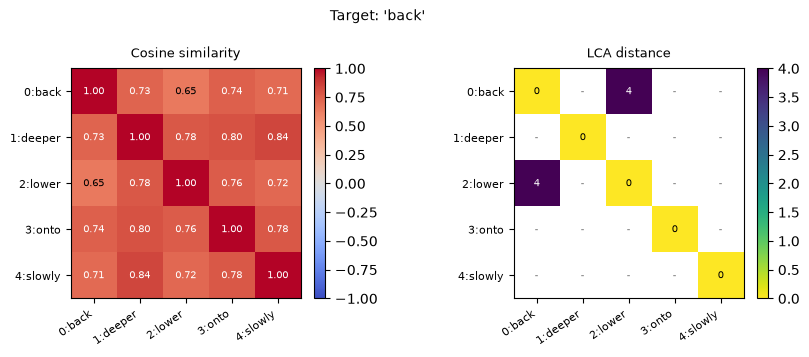


Context: '“We can add that to the list of questions we’ll ask him when we’ve taken the Polyjuice Potion,” said Harry, sinking back' | Target: 'onto'
Top-5         |        0:onto |     1:heavily |       2:grate |    3:slightly |   4:uncomfort
---------------------------------------------------------------------------------------------
0:onto        |        1.0000 |        0.8417 |        0.4065 |        0.7494 |        0.5524
1:heavily     |        0.8417 |        1.0000 |        0.4070 |        0.8385 |        0.5917
2:grate       |        0.4065 |        0.4070 |        1.0000 |        0.4829 |        0.5269
3:slightly    |        0.7494 |        0.8385 |        0.4829 |        1.0000 |        0.5539
4:uncomfort   |        0.5524 |        0.5917 |        0.5269 |        0.5539 |        1.0000


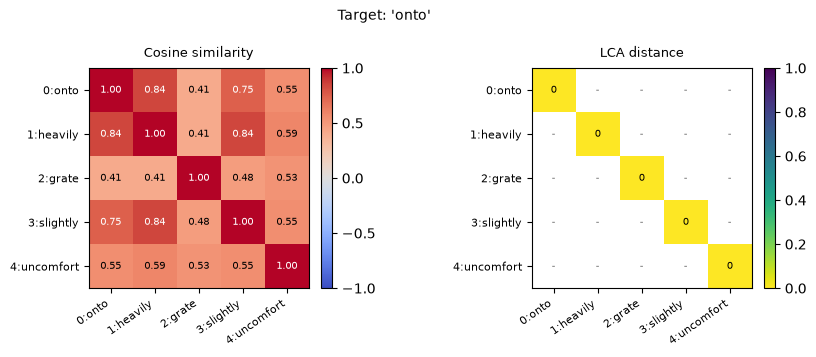


Context: '“We can add that to the list of questions we’ll ask him when we’ve taken the Polyjuice Potion,” said Harry, sinking back onto his' | Target: 'pillows.'
Top-5        |       0:bed |      1:bunk |    2:pillow |   3:pillows |     4:chair
----------------------------------------------------------------------------------
0:bed        |      1.0000 |      0.7214 |      0.7754 |      0.7340 |      0.6514
1:bunk       |      0.7214 |      1.0000 |      0.7250 |      0.6523 |      0.7015
2:pillow     |      0.7754 |      0.7250 |      1.0000 |      0.8348 |      0.6818
3:pillows    |      0.7340 |      0.6523 |      0.8348 |      1.0000 |      0.6257
4:chair      |      0.6514 |      0.7015 |      0.6818 |      0.6257 |      1.0000


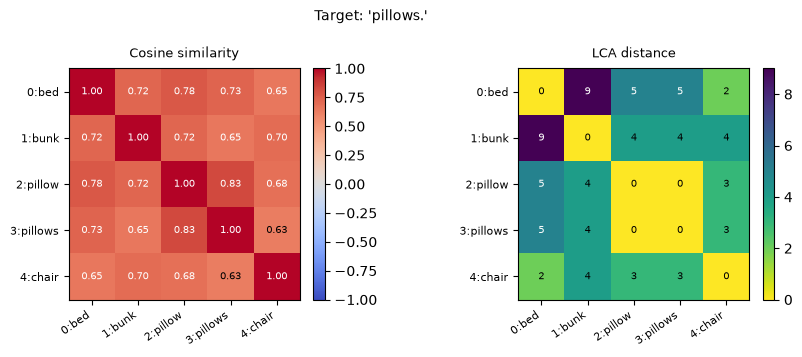


Context: '“I' | Target: 'hope'
Top-5        |     0:want |    1:think |     2:know |     3:need |    4:never
-----------------------------------------------------------------------------
0:want       |     1.0000 |     0.7300 |     0.7659 |     0.8792 |     0.7272
1:think      |     0.7300 |     1.0000 |     0.7372 |     0.6569 |     0.6155
2:know       |     0.7659 |     0.7372 |     1.0000 |     0.7421 |     0.7240
3:need       |     0.8792 |     0.6569 |     0.7421 |     1.0000 |     0.7531
4:never      |     0.7272 |     0.6155 |     0.7240 |     0.7531 |     1.0000


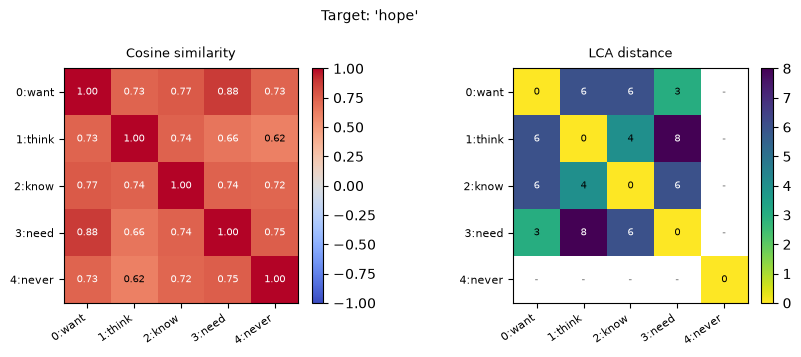


Context: '“I hope it' | Target: 'tastes'
Top-5        |    0:helps |    1:never |    2:makes |    3:works |   4:brings
-----------------------------------------------------------------------------
0:helps      |     1.0000 |     0.6697 |     0.8187 |     0.5698 |     0.7174
1:never      |     0.6697 |     1.0000 |     0.7350 |     0.5347 |     0.7446
2:makes      |     0.8187 |     0.7350 |     1.0000 |     0.5428 |     0.8100
3:works      |     0.5698 |     0.5347 |     0.5428 |     1.0000 |     0.5103
4:brings     |     0.7174 |     0.7446 |     0.8100 |     0.5103 |     1.0000


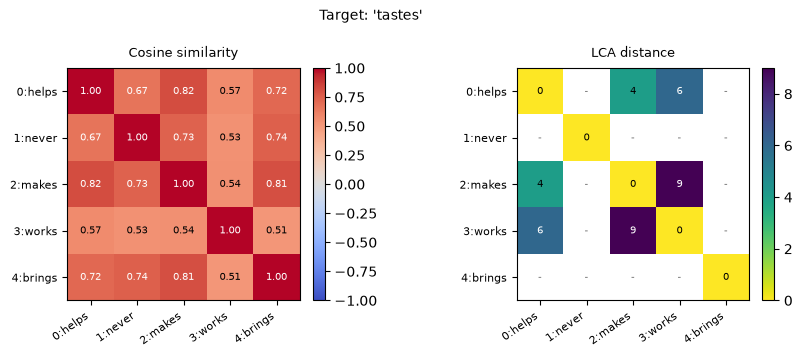


Context: '“I hope it tastes' | Target: 'better'
Top-5        |     0:good |   1:better |     2:nice |     3:okay |    4:great
-----------------------------------------------------------------------------
0:good       |     1.0000 |     0.6536 |     0.7113 |     0.6610 |     0.7382
1:better     |     0.6536 |     1.0000 |     0.6833 |     0.6082 |     0.6454
2:nice       |     0.7113 |     0.6833 |     1.0000 |     0.7474 |     0.7299
3:okay       |     0.6610 |     0.6082 |     0.7474 |     1.0000 |     0.7018
4:great      |     0.7382 |     0.6454 |     0.7299 |     0.7018 |     1.0000


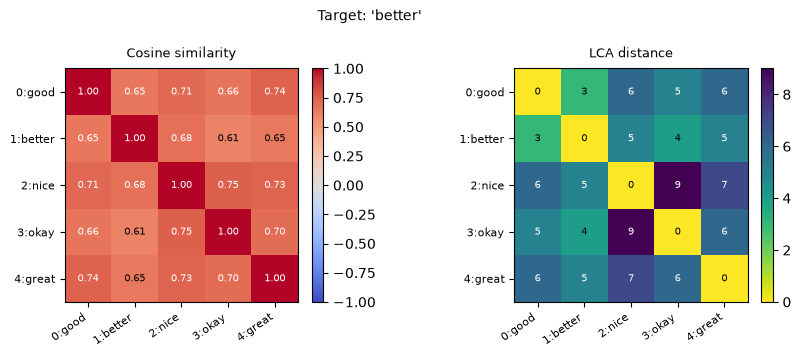


Context: '“I hope it tastes better than this' | Target: 'stuff.'
Top-5        |    0:paint |     1:year |     2:soup |    3:paper |    4:stuff
-----------------------------------------------------------------------------
0:paint      |     1.0000 |     0.3226 |     0.7991 |     0.6858 |     0.7550
1:year       |     0.3226 |     1.0000 |     0.3505 |     0.4210 |     0.3228
2:soup       |     0.7991 |     0.3505 |     1.0000 |     0.6117 |     0.7997
3:paper      |     0.6858 |     0.4210 |     0.6117 |     1.0000 |     0.6039
4:stuff      |     0.7550 |     0.3228 |     0.7997 |     0.6039 |     1.0000


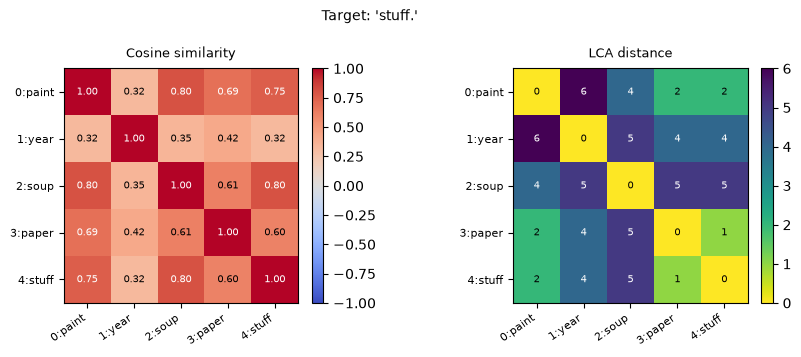


Context: '.” “If it’s got' | Target: 'bits'
Top-5         |   0:something |    1:anything |      2:wheels |     3:nothing |       4:wings
---------------------------------------------------------------------------------------------
0:something   |        1.0000 |        0.8394 |        0.8053 |        0.7638 |        0.7560
1:anything    |        0.8394 |        1.0000 |        0.6957 |        0.7771 |        0.6416
2:wheels      |        0.8053 |        0.6957 |        1.0000 |        0.6243 |        0.7835
3:nothing     |        0.7638 |        0.7771 |        0.6243 |        1.0000 |        0.6301
4:wings       |        0.7560 |        0.6416 |        0.7835 |        0.6301 |        1.0000


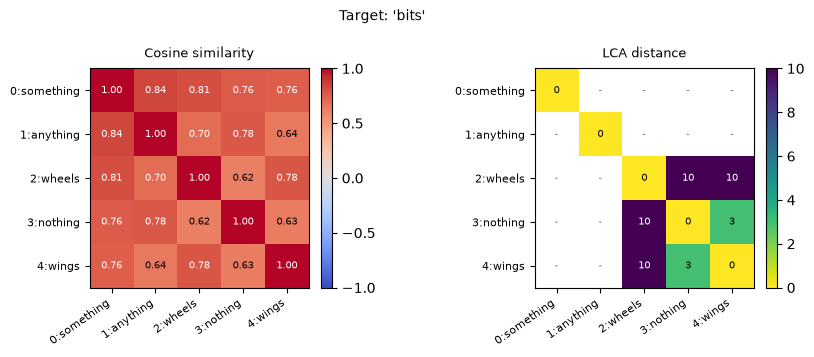


Context: '.” “If it’s got bits of' | Target: 'Slytherins'
Top-5        |    0:metal |    1:paper |     2:meat |     3:wood |    4:glass
-----------------------------------------------------------------------------
0:metal      |     1.0000 |     0.6823 |     0.7778 |     0.7869 |     0.8347
1:paper      |     0.6823 |     1.0000 |     0.6242 |     0.7337 |     0.7007
2:meat       |     0.7778 |     0.6242 |     1.0000 |     0.7708 |     0.7943
3:wood       |     0.7869 |     0.7337 |     0.7708 |     1.0000 |     0.8199
4:glass      |     0.8347 |     0.7007 |     0.7943 |     0.8199 |     1.0000


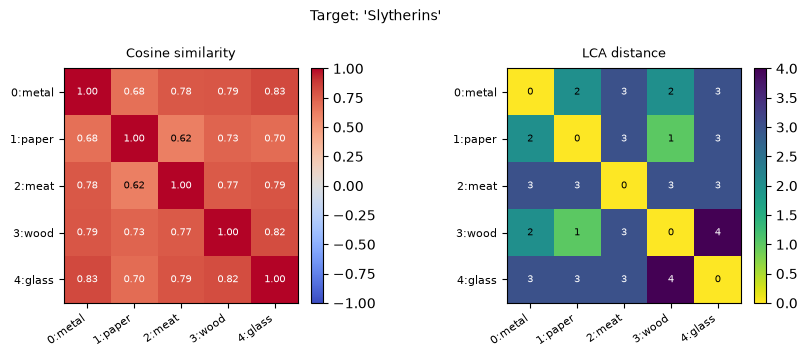


Context: 'You’ve got to be joking,” said' | Target: 'Ron.'
Top-5         |          0:dr |          1:mr |        2:john |   3:professor |         4:tom
---------------------------------------------------------------------------------------------
0:dr          |        1.0000 |        0.7659 |        0.6554 |        0.8401 |        0.6630
1:mr          |        0.7659 |        1.0000 |        0.6716 |        0.7426 |        0.7463
2:john        |        0.6554 |        0.6716 |        1.0000 |        0.7179 |        0.6802
3:professor   |        0.8401 |        0.7426 |        0.7179 |        1.0000 |        0.6348
4:tom         |        0.6630 |        0.7463 |        0.6802 |        0.6348 |        1.0000


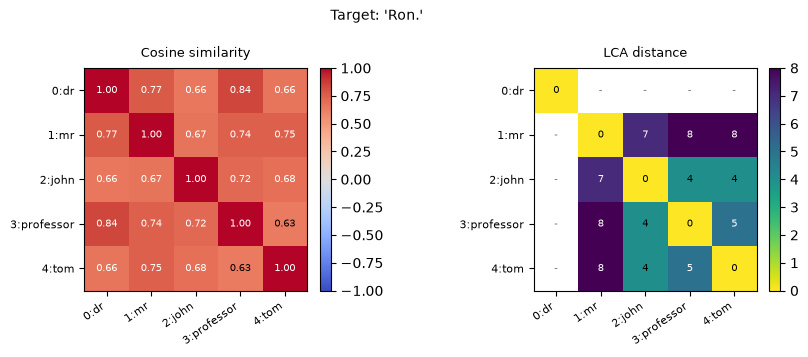


Context: 'The' | Target: 'door'
Top-5         |   0:following |         1:sum |      2:purple |    3:function |      4:number
---------------------------------------------------------------------------------------------
0:following   |        1.0000 |        0.5209 |        0.5680 |        0.4828 |        0.5987
1:sum         |        0.5209 |        1.0000 |        0.5980 |        0.6384 |        0.6528
2:purple      |        0.5680 |        0.5980 |        1.0000 |        0.5516 |        0.7352
3:function    |        0.4828 |        0.6384 |        0.5516 |        1.0000 |        0.6338
4:number      |        0.5987 |        0.6528 |        0.7352 |        0.6338 |        1.0000


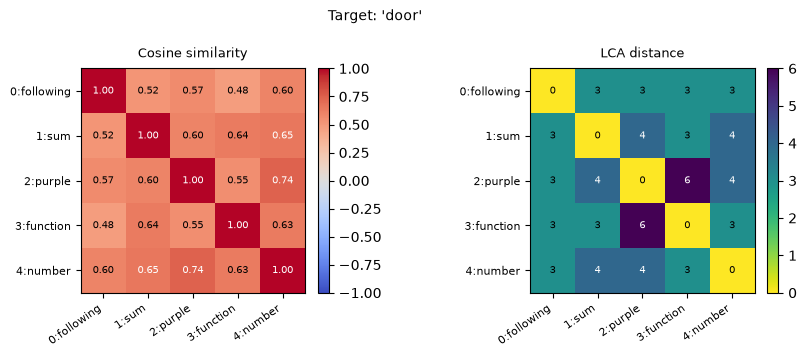


Context: 'The door of the' | Target: 'hospital'
Top-5            |   0:distribution |           1:fire |    2:transformer |           3:high |        4:battery
---------------------------------------------------------------------------------------------------------------
0:distribution   |           1.0000 |           0.5007 |           0.5069 |           0.4443 |           0.6232
1:fire           |           0.5007 |           1.0000 |           0.4915 |           0.5428 |           0.6021
2:transformer    |           0.5069 |           0.4915 |           1.0000 |           0.3465 |           0.5645
3:high           |           0.4443 |           0.5428 |           0.3465 |           1.0000 |           0.4408
4:battery        |           0.6232 |           0.6021 |           0.5645 |           0.4408 |           1.0000


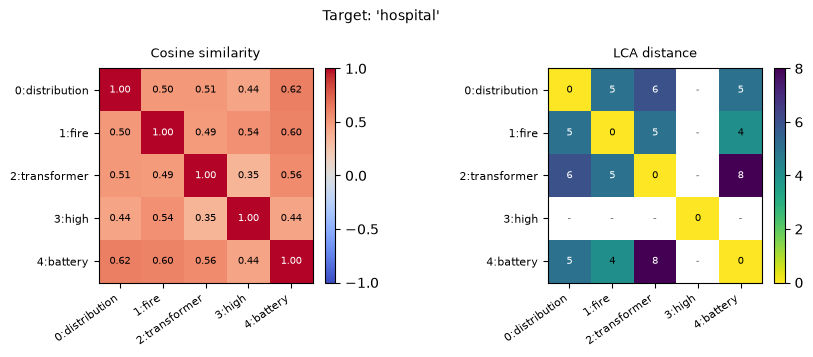


Context: 'The door of the hospital' | Target: 'wing'
Top-5         |        0:room |        1:ward |   2:emergency |   3:isolation |    4:building
---------------------------------------------------------------------------------------------
0:room        |        1.0000 |        0.6393 |        0.6746 |        0.7307 |        0.6905
1:ward        |        0.6393 |        1.0000 |        0.5569 |        0.6415 |        0.6792
2:emergency   |        0.6746 |        0.5569 |        1.0000 |        0.6767 |        0.5497
3:isolation   |        0.7307 |        0.6415 |        0.6767 |        1.0000 |        0.6432
4:building    |        0.6905 |        0.6792 |        0.5497 |        0.6432 |        1.0000


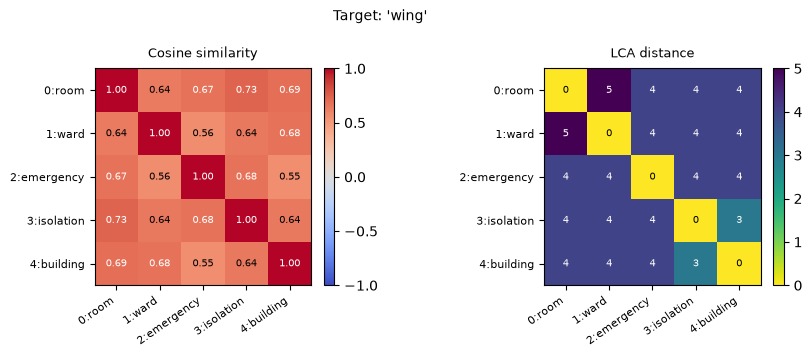


Context: 'The door of the hospital wing' | Target: 'burst'
Top-5        |    0:swung |        1:c |     2:slid |   3:slowly |     4:flew
-----------------------------------------------------------------------------
0:swung      |     1.0000 |     0.5367 |     0.8285 |     0.7460 |     0.8152
1:c          |     0.5367 |     1.0000 |     0.6112 |     0.5532 |     0.5168
2:slid       |     0.8285 |     0.6112 |     1.0000 |     0.8194 |     0.8319
3:slowly     |     0.7460 |     0.5532 |     0.8194 |     1.0000 |     0.7262
4:flew       |     0.8152 |     0.5168 |     0.8319 |     0.7262 |     1.0000


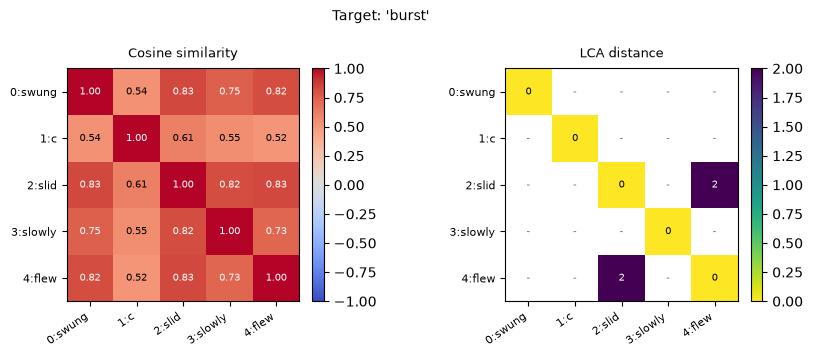


Context: 'The door of the hospital wing burst' | Target: 'open'
Top-5        |       0:open |         1:ed |      2:right |   3:suddenly |       4:back
---------------------------------------------------------------------------------------
0:open       |       1.0000 |       0.4468 |       0.5676 |       0.4488 |       0.5870
1:ed         |       0.4468 |       1.0000 |       0.4639 |       0.4241 |       0.5127
2:right      |       0.5676 |       0.4639 |       1.0000 |       0.5156 |       0.7323
3:suddenly   |       0.4488 |       0.4241 |       0.5156 |       1.0000 |       0.4991
4:back       |       0.5870 |       0.5127 |       0.7323 |       0.4991 |       1.0000


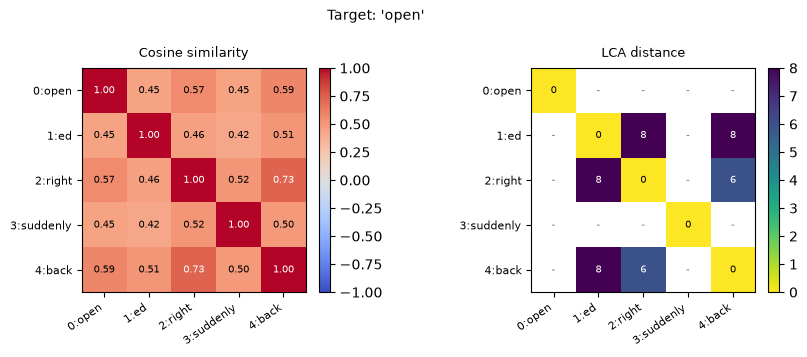


Context: 'The door of the hospital wing burst open at that' | Target: 'moment.'
Top-5        |    0:moment |      1:time |   2:instant |     3:exact |     4:point
----------------------------------------------------------------------------------
0:moment     |      1.0000 |      0.8118 |      0.7430 |      0.7588 |      0.4750
1:time       |      0.8118 |      1.0000 |      0.6946 |      0.7244 |      0.4798
2:instant    |      0.7430 |      0.6946 |      1.0000 |      0.6802 |      0.3723
3:exact      |      0.7588 |      0.7244 |      0.6802 |      1.0000 |      0.4649
4:point      |      0.4750 |      0.4798 |      0.3723 |      0.4649 |      1.0000


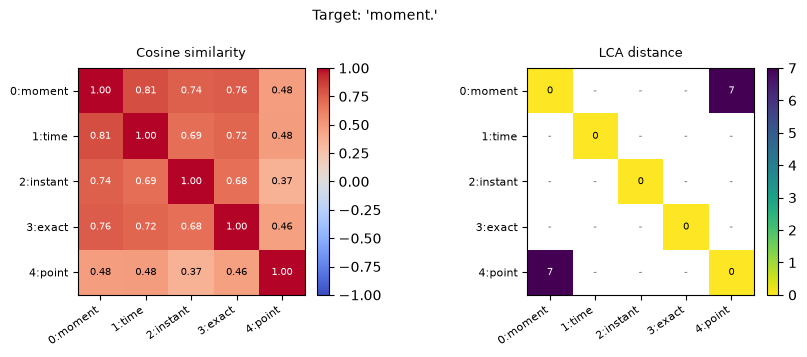


Context: 'Filthy and' | Target: 'soaking'
Top-5        |        0:f |       1:un |     2:foul |    3:dirty |       4:sm
-----------------------------------------------------------------------------
0:f          |     1.0000 |     0.6785 |     0.5714 |     0.6171 |     0.7538
1:un         |     0.6785 |     1.0000 |     0.6491 |     0.7335 |     0.7300
2:foul       |     0.5714 |     0.6491 |     1.0000 |     0.8112 |     0.6496
3:dirty      |     0.6171 |     0.7335 |     0.8112 |     1.0000 |     0.7133
4:sm         |     0.7538 |     0.7300 |     0.6496 |     0.7133 |     1.0000


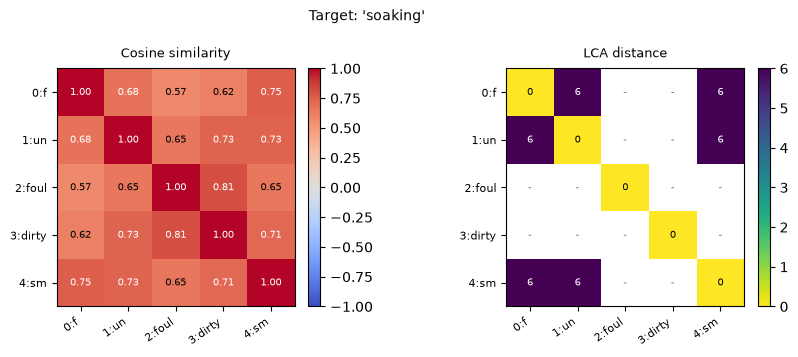


Context: 'Filthy and soaking' | Target: 'wet,'
Top-5        |      0:wet |     1:cold |        2:w |    3:water |     4:rain
-----------------------------------------------------------------------------
0:wet        |     1.0000 |     0.7410 |     0.5617 |     0.7840 |     0.6409
1:cold       |     0.7410 |     1.0000 |     0.5277 |     0.7258 |     0.5609
2:w          |     0.5617 |     0.5277 |     1.0000 |     0.5993 |     0.4481
3:water      |     0.7840 |     0.7258 |     0.5993 |     1.0000 |     0.6880
4:rain       |     0.6409 |     0.5609 |     0.4481 |     0.6880 |     1.0000


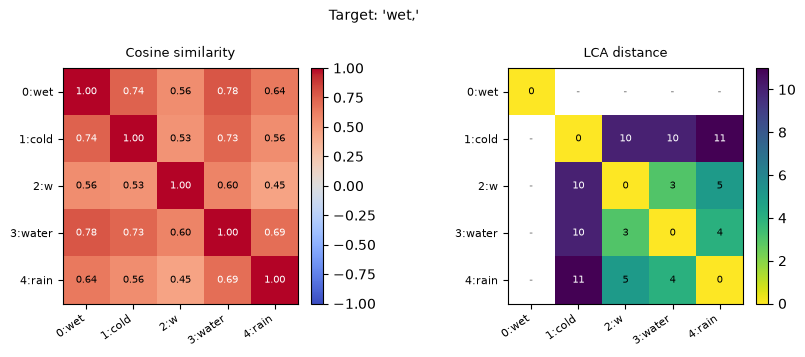


Context: 'Filthy and soaking wet, the' | Target: 'rest'
Top-5        |      0:man |    1:young |   2:little |      3:boy |    4:three
-----------------------------------------------------------------------------
0:man        |     1.0000 |     0.5938 |     0.6172 |     0.7447 |     0.6394
1:young      |     0.5938 |     1.0000 |     0.6469 |     0.6526 |     0.4669
2:little     |     0.6172 |     0.6469 |     1.0000 |     0.7542 |     0.5880
3:boy        |     0.7447 |     0.6526 |     0.7542 |     1.0000 |     0.5961
4:three      |     0.6394 |     0.4669 |     0.5880 |     0.5961 |     1.0000


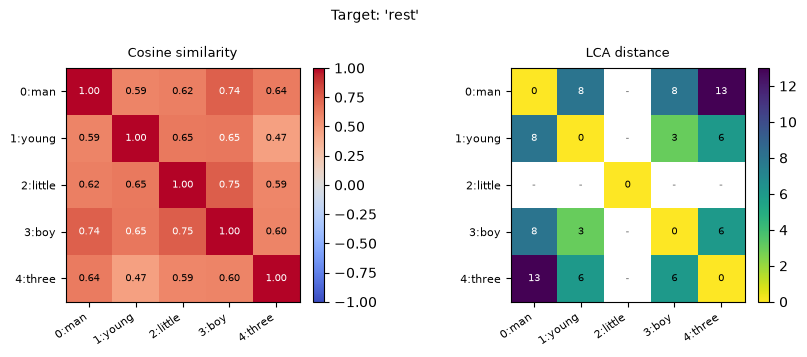


Context: 'Filthy and soaking wet, the rest of the' | Target: 'Gryffindor'
Top-5        |    0:group |    1:world |     2:crew |     3:team |     4:gang
-----------------------------------------------------------------------------
0:group      |     1.0000 |     0.6421 |     0.5391 |     0.7293 |     0.7176
1:world      |     0.6421 |     1.0000 |     0.5327 |     0.5581 |     0.7092
2:crew       |     0.5391 |     0.5327 |     1.0000 |     0.5716 |     0.5969
3:team       |     0.7293 |     0.5581 |     0.5716 |     1.0000 |     0.6326
4:gang       |     0.7176 |     0.7092 |     0.5969 |     0.6326 |     1.0000


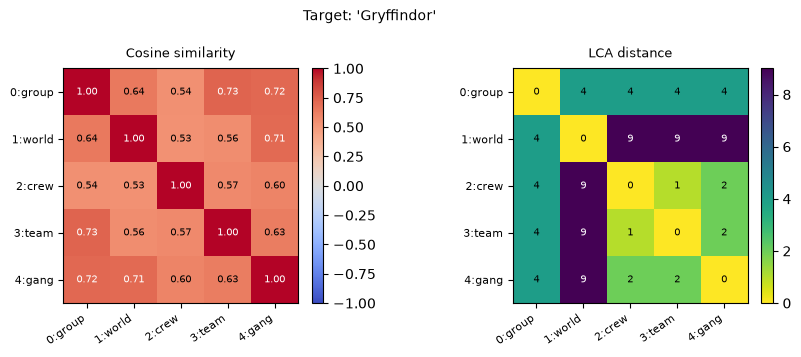


Context: 'Filthy and soaking wet, the rest of the Gryffindor' | Target: 'team'
Top-5        |      0:team |        1:qu |     2:first |   3:seventh |     4:group
----------------------------------------------------------------------------------
0:team       |      1.0000 |      0.5157 |      0.5446 |      0.5368 |      0.7293
1:qu         |      0.5157 |      1.0000 |      0.4531 |      0.4918 |      0.5395
2:first      |      0.5446 |      0.4531 |      1.0000 |      0.5969 |      0.6221
3:seventh    |      0.5368 |      0.4918 |      0.5969 |      1.0000 |      0.5474
4:group      |      0.7293 |      0.5395 |      0.6221 |      0.5474 |      1.0000


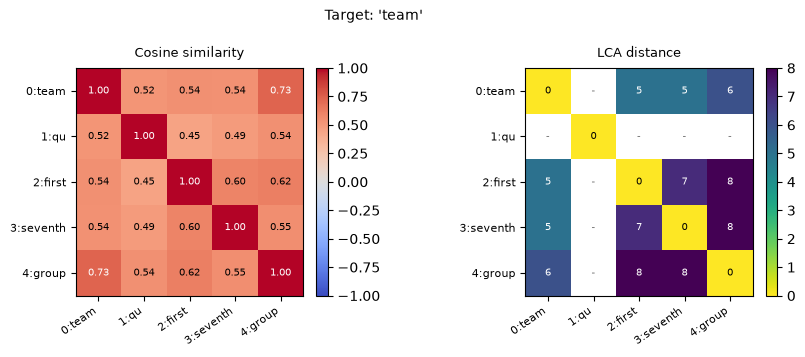


Context: 'Filthy and soaking wet, the rest of the Gryffindor team had' | Target: 'arrived'
Top-5        |         0:tr |       1:left |          2:h |   3:returned |    4:already
---------------------------------------------------------------------------------------
0:tr         |       1.0000 |       0.5130 |       0.5465 |       0.5377 |       0.4403
1:left       |       0.5130 |       1.0000 |       0.5688 |       0.6307 |       0.4552
2:h          |       0.5465 |       0.5688 |       1.0000 |       0.6249 |       0.4247
3:returned   |       0.5377 |       0.6307 |       0.6249 |       1.0000 |       0.5374
4:already    |       0.4403 |       0.4552 |       0.4247 |       0.5374 |       1.0000


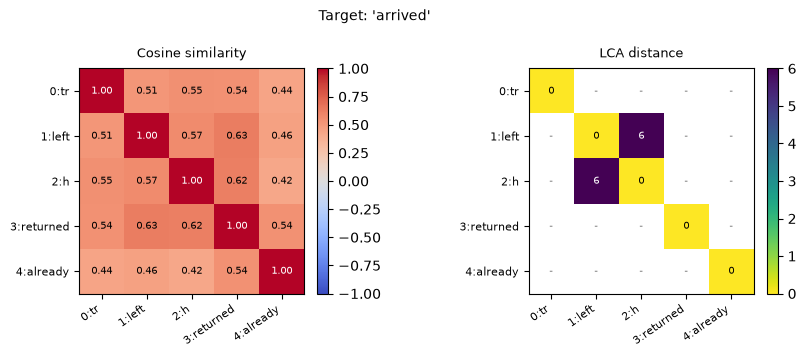


Context: 'Filthy and soaking wet, the rest of the Gryffindor team had arrived to' | Target: 'see'
Top-5        |     0:find |      1:see |     2:pick |    3:greet |     4:meet
-----------------------------------------------------------------------------
0:find       |     1.0000 |     0.6650 |     0.7751 |     0.7189 |     0.7130
1:see        |     0.6650 |     1.0000 |     0.6834 |     0.7202 |     0.6759
2:pick       |     0.7751 |     0.6834 |     1.0000 |     0.7432 |     0.6965
3:greet      |     0.7189 |     0.7202 |     0.7432 |     1.0000 |     0.8452
4:meet       |     0.7130 |     0.6759 |     0.6965 |     0.8452 |     1.0000


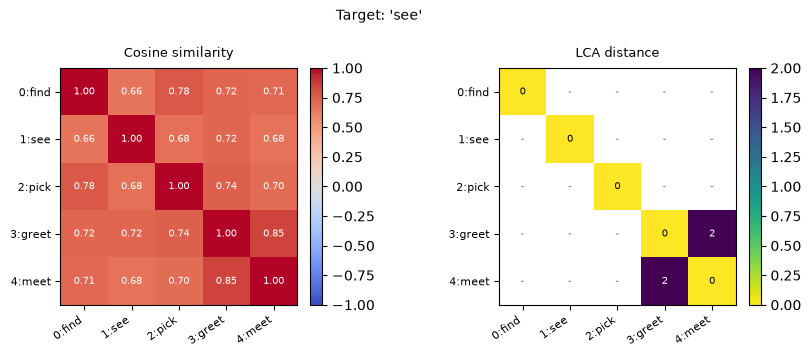


Context: 'Filthy and soaking wet, the rest of the Gryffindor team had arrived to see' | Target: 'Harry.'
Top-5        |      0:harry |        1:ron |   2:hermione |    3:neville |       4:fred
---------------------------------------------------------------------------------------
0:harry      |       1.0000 |       0.8624 |       0.4042 |       0.8123 |       0.8744
1:ron        |       0.8624 |       1.0000 |       0.3613 |       0.7913 |       0.8508
2:hermione   |       0.4042 |       0.3613 |       1.0000 |       0.3695 |       0.3707
3:neville    |       0.8123 |       0.7913 |       0.3695 |       1.0000 |       0.7759
4:fred       |       0.8744 |       0.8508 |       0.3707 |       0.7759 |       1.0000


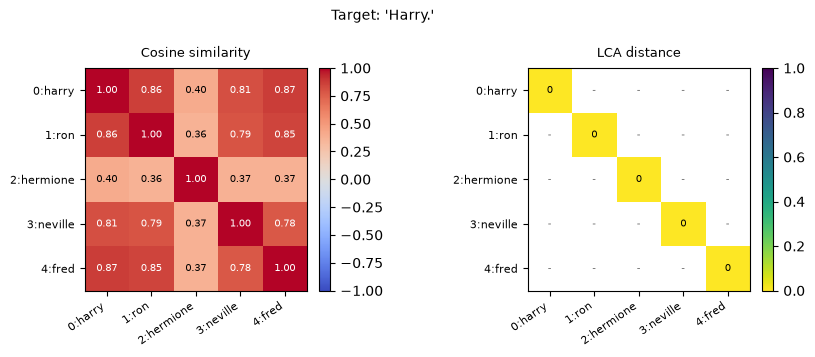


Context: '“Unbelievable' | Target: 'flying,'
Top-5          |        0:story |   1:experience |         2:news |        3:grace |       4:beauty
---------------------------------------------------------------------------------------------------
0:story        |         1.0000 |         0.6412 |         0.7825 |         0.7119 |         0.5879
1:experience   |         0.6412 |         1.0000 |         0.5986 |         0.5834 |         0.6292
2:news         |         0.7825 |         0.5986 |         1.0000 |         0.6501 |         0.5995
3:grace        |         0.7119 |         0.5834 |         0.6501 |         1.0000 |         0.6426
4:beauty       |         0.5879 |         0.6292 |         0.5995 |         0.6426 |         1.0000


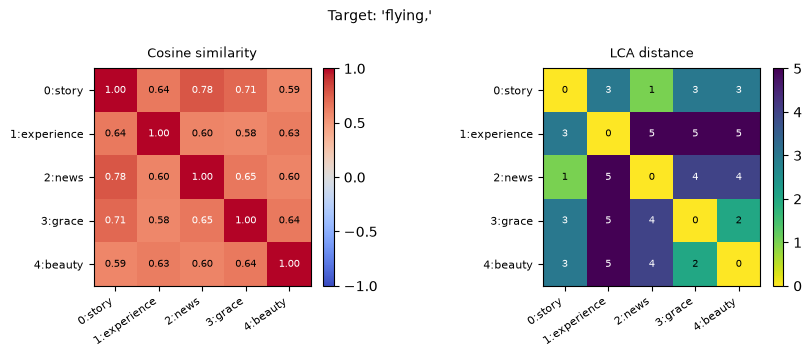


Context: '“Unbelievable flying,' | Target: 'Harry,”'
Top-5          |        0:great |       1:diving |   2:impossible |       3:flying |      4:unbelie
---------------------------------------------------------------------------------------------------
0:great        |         1.0000 |         0.3229 |         0.6669 |         0.6257 |         0.2842
1:diving       |         0.3229 |         1.0000 |         0.3978 |         0.4845 |         0.2602
2:impossible   |         0.6669 |         0.3978 |         1.0000 |         0.7079 |         0.3675
3:flying       |         0.6257 |         0.4845 |         0.7079 |         1.0000 |         0.2752
4:unbelie      |         0.2842 |         0.2602 |         0.3675 |         0.2752 |         1.0000


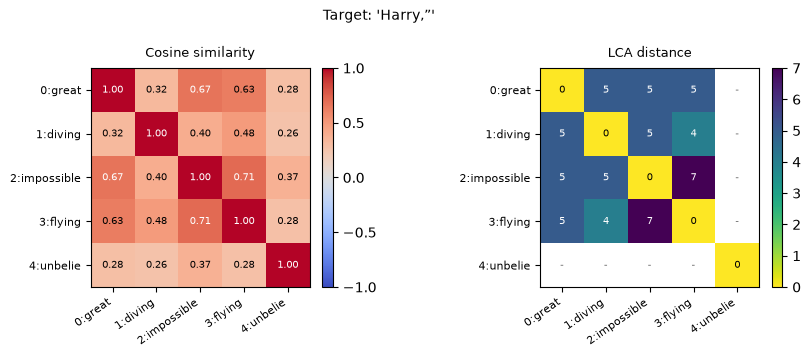


Context: '“Unbelievable flying, Harry,” said' | Target: 'George.'
Top-5        |        0:ron |   1:hermione |          2:h |    3:neville |       4:dean
---------------------------------------------------------------------------------------
0:ron        |       1.0000 |       0.3613 |       0.6003 |       0.7913 |       0.8633
1:hermione   |       0.3613 |       1.0000 |       0.3197 |       0.3695 |       0.3700
2:h          |       0.6003 |       0.3197 |       1.0000 |       0.5382 |       0.6562
3:neville    |       0.7913 |       0.3695 |       0.5382 |       1.0000 |       0.8017
4:dean       |       0.8633 |       0.3700 |       0.6562 |       0.8017 |       1.0000


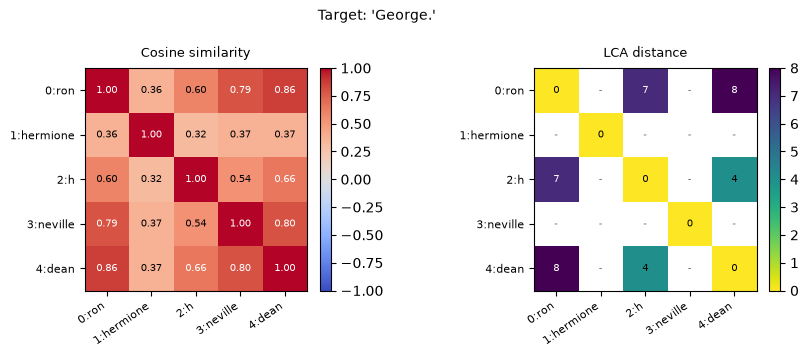


Context: '“I’ve just' | Target: 'seen'
Top-5        |   0:started |      1:read |      2:come |     3:found |      4:seen
----------------------------------------------------------------------------------
0:started    |      1.0000 |      0.6742 |      0.6049 |      0.6773 |      0.7595
1:read       |      0.6742 |      1.0000 |      0.6939 |      0.6510 |      0.7422
2:come       |      0.6049 |      0.6939 |      1.0000 |      0.6046 |      0.6922
3:found      |      0.6773 |      0.6510 |      0.6046 |      1.0000 |      0.7612
4:seen       |      0.7595 |      0.7422 |      0.6922 |      0.7612 |      1.0000


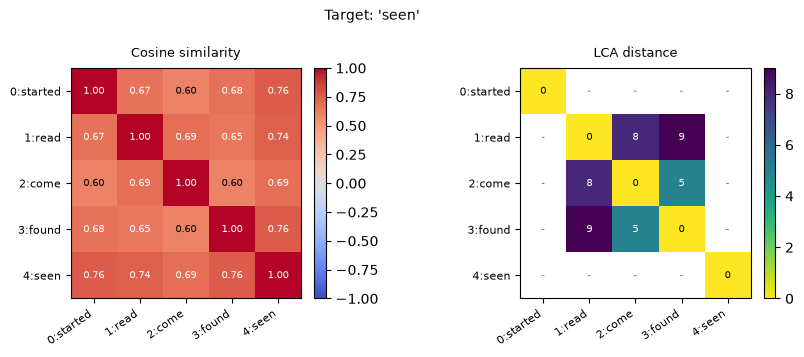


Context: '“I’ve just seen' | Target: 'Marcus'
Top-5         |   0:something |     1:someone |       2:three |    3:somebody |      4:people
---------------------------------------------------------------------------------------------
0:something   |        1.0000 |        0.9085 |        0.5988 |        0.8953 |        0.7406
1:someone     |        0.9085 |        1.0000 |        0.6005 |        0.9411 |        0.7783
2:three       |        0.5988 |        0.6005 |        1.0000 |        0.5971 |        0.5240
3:somebody    |        0.8953 |        0.9411 |        0.5971 |        1.0000 |        0.7606
4:people      |        0.7406 |        0.7783 |        0.5240 |        0.7606 |        1.0000


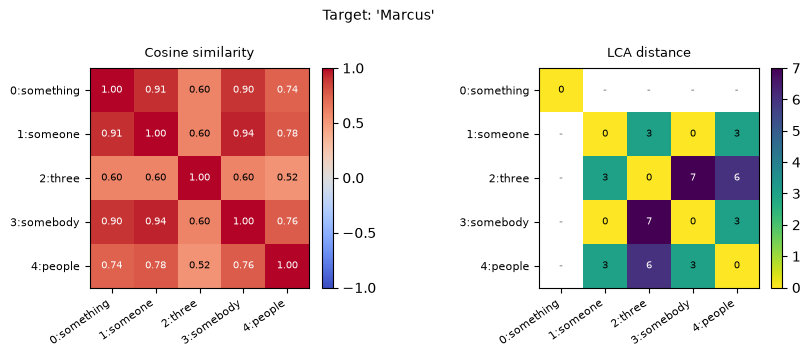


Context: '“I’ve just seen Marcus' | Target: 'Flint'
Top-5        |      0:aure |       1:win |      2:take |   3:running |     4:going
----------------------------------------------------------------------------------
0:aure       |      1.0000 |      0.3262 |      0.4546 |      0.3991 |      0.4035
1:win        |      0.3262 |      1.0000 |      0.4791 |      0.4735 |      0.4144
2:take       |      0.4546 |      0.4791 |      1.0000 |      0.6436 |      0.7512
3:running    |      0.3991 |      0.4735 |      0.6436 |      1.0000 |      0.6839
4:going      |      0.4035 |      0.4144 |      0.7512 |      0.6839 |      1.0000


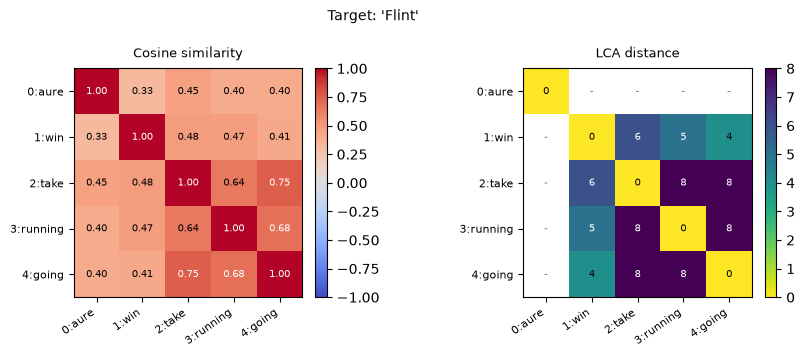


Context: '“I’ve just seen Marcus Flint' | Target: 'yelling'
Top-5        |     0:score |   1:scoring |      2:play |   3:playing |   4:getting
----------------------------------------------------------------------------------
0:score      |      1.0000 |      0.7408 |      0.6530 |      0.6373 |      0.5633
1:scoring    |      0.7408 |      1.0000 |      0.5237 |      0.5988 |      0.4608
2:play       |      0.6530 |      0.5237 |      1.0000 |      0.7612 |      0.5978
3:playing    |      0.6373 |      0.5988 |      0.7612 |      1.0000 |      0.7888
4:getting    |      0.5633 |      0.4608 |      0.5978 |      0.7888 |      1.0000


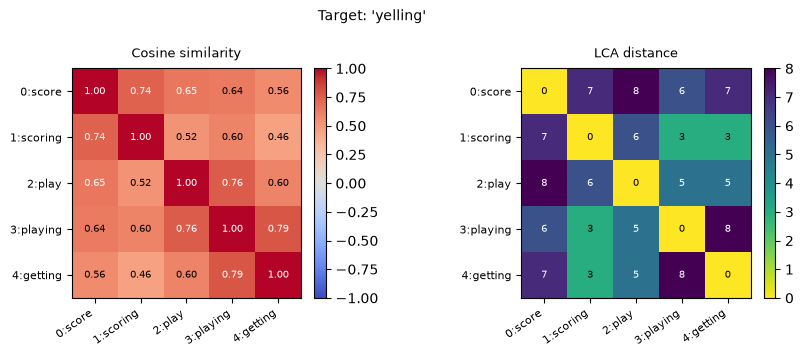


Context: '“I’ve just seen Marcus Flint yelling at' | Target: 'Malfoy.'
Top-5        |      0:gary |     1:harry |      2:ryan |   3:someone |   4:neville
----------------------------------------------------------------------------------
0:gary       |      1.0000 |      0.8790 |      0.8287 |      0.7614 |      0.8012
1:harry      |      0.8790 |      1.0000 |      0.7837 |      0.8209 |      0.8123
2:ryan       |      0.8287 |      0.7837 |      1.0000 |      0.6924 |      0.7286
3:someone    |      0.7614 |      0.8209 |      0.6924 |      1.0000 |      0.7075
4:neville    |      0.8012 |      0.8123 |      0.7286 |      0.7075 |      1.0000


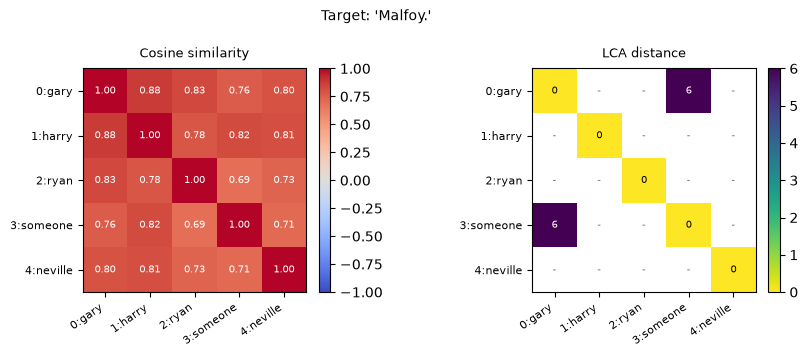


Context: 'Something about having the' | Target: 'Snitch'
Top-5           |         0:right |       1:ability |          2:kids |   3:opportunity |           4:sun
---------------------------------------------------------------------------------------------------------
0:right         |          1.0000 |          0.7353 |          0.5869 |          0.6479 |          0.6103
1:ability       |          0.7353 |          1.0000 |          0.6407 |          0.8065 |          0.6636
2:kids          |          0.5869 |          0.6407 |          1.0000 |          0.6376 |          0.6393
3:opportunity   |          0.6479 |          0.8065 |          0.6376 |          1.0000 |          0.6818
4:sun           |          0.6103 |          0.6636 |          0.6393 |          0.6818 |          1.0000


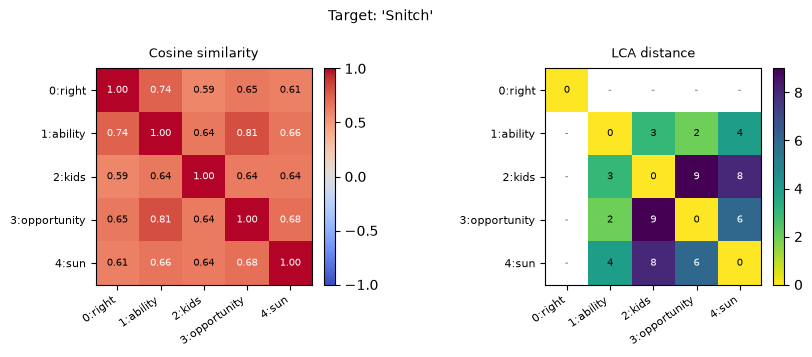


Context: 'Something about having the Snitch on' | Target: 'top'
Top-5        |      0:hand |     1:board |   2:display |      3:side |     4:harry
----------------------------------------------------------------------------------
0:hand       |      1.0000 |      0.5857 |      0.6274 |      0.6880 |      0.6794
1:board      |      0.5857 |      1.0000 |      0.5645 |      0.5434 |      0.6565
2:display    |      0.6274 |      0.5645 |      1.0000 |      0.5483 |      0.6588
3:side       |      0.6880 |      0.5434 |      0.5483 |      1.0000 |      0.5954
4:harry      |      0.6794 |      0.6565 |      0.6588 |      0.5954 |      1.0000


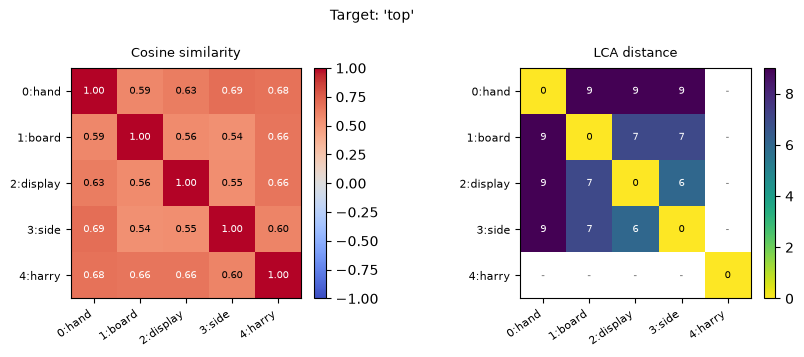


Context: 'Something about having the Snitch on top of his' | Target: 'head'
Top-5        |       0:head |       1:hand |   2:shoulder |        3:bro |      4:chest
---------------------------------------------------------------------------------------
0:head       |       1.0000 |       0.6788 |       0.5492 |       0.6951 |       0.6944
1:hand       |       0.6788 |       1.0000 |       0.7013 |       0.6707 |       0.7485
2:shoulder   |       0.5492 |       0.7013 |       1.0000 |       0.5158 |       0.7431
3:bro        |       0.6951 |       0.6707 |       0.5158 |       1.0000 |       0.6903
4:chest      |       0.6944 |       0.7485 |       0.7431 |       0.6903 |       1.0000


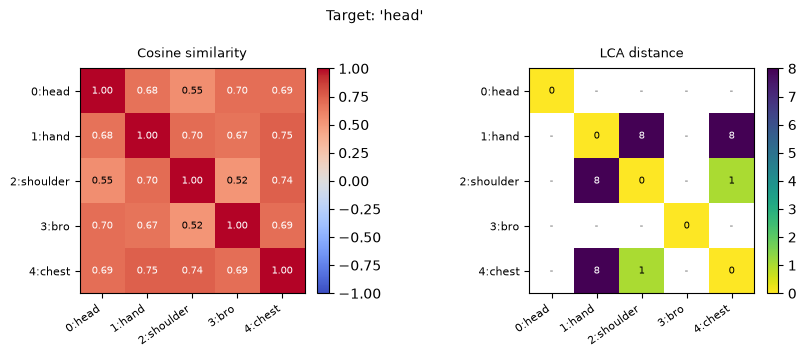


Context: 'Something about having the Snitch on top of his head and not' | Target: 'noticing.'
Top-5         |     0:knowing |    1:catching |    2:actually |     3:letting |   4:realizing
---------------------------------------------------------------------------------------------
0:knowing     |        1.0000 |        0.7486 |        0.5925 |        0.7006 |        0.8755
1:catching    |        0.7486 |        1.0000 |        0.5764 |        0.8197 |        0.8068
2:actually    |        0.5925 |        0.5764 |        1.0000 |        0.4992 |        0.6417
3:letting     |        0.7006 |        0.8197 |        0.4992 |        1.0000 |        0.6779
4:realizing   |        0.8755 |        0.8068 |        0.6417 |        0.6779 |        1.0000


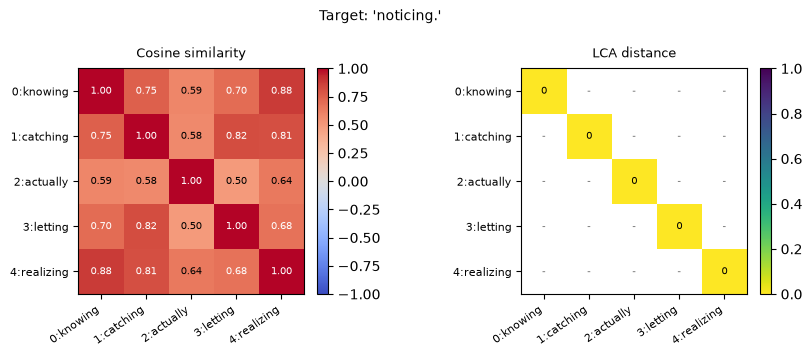


Context: 'Malfoy' | Target: 'didn’t'
Top-5           |   0:corporation |    1:industries |       2:company |         3:manor |        4:looked
---------------------------------------------------------------------------------------------------------
0:corporation   |          1.0000 |          0.7161 |          0.7605 |          0.6840 |          0.6558
1:industries    |          0.7161 |          1.0000 |          0.6464 |          0.6459 |          0.5539
2:company       |          0.7605 |          0.6464 |          1.0000 |          0.6506 |          0.6888
3:manor         |          0.6840 |          0.6459 |          0.6506 |          1.0000 |          0.5659
4:looked        |          0.6558 |          0.5539 |          0.6888 |          0.5659 |          1.0000


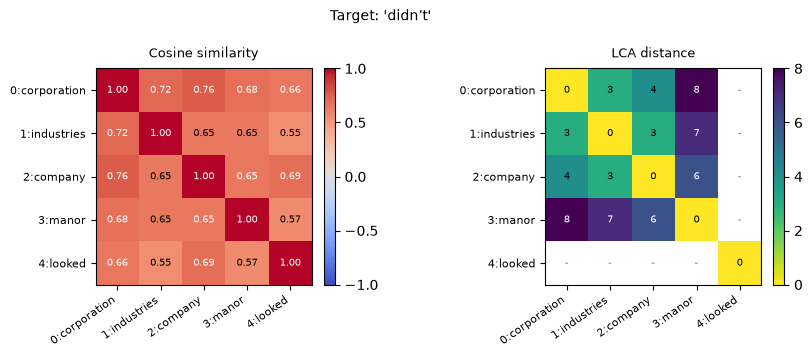


Context: 'Malfoy didn’t' | Target: 'seem'
Top-5        |     0:know |     1:want |     2:seem |     3:look |   4:answer
-----------------------------------------------------------------------------
0:know       |     1.0000 |     0.7659 |     0.8126 |     0.7639 |     0.7659
1:want       |     0.7659 |     1.0000 |     0.7511 |     0.7474 |     0.7510
2:seem       |     0.8126 |     0.7511 |     1.0000 |     0.7701 |     0.7437
3:look       |     0.7639 |     0.7474 |     0.7701 |     1.0000 |     0.7652
4:answer     |     0.7659 |     0.7510 |     0.7437 |     0.7652 |     1.0000


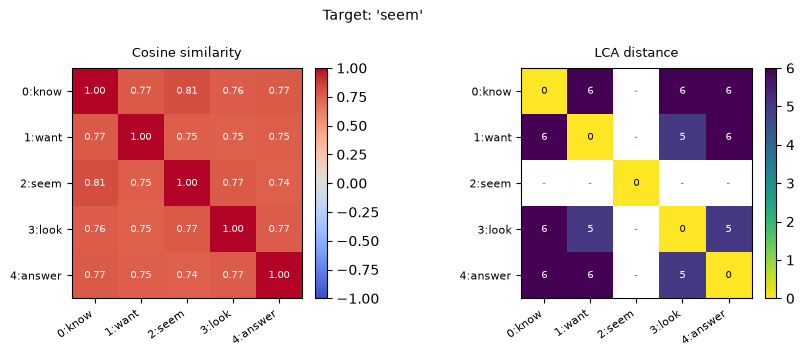


Context: 'Malfoy didn’t seem too happy.” They had' | Target: 'brought'
Top-5        |   0:reached |      1:come |   2:arrived |    3:walked |      4:left
----------------------------------------------------------------------------------
0:reached    |      1.0000 |      0.7041 |      0.8308 |      0.8429 |      0.6796
1:come       |      0.7041 |      1.0000 |      0.6599 |      0.6853 |      0.5558
2:arrived    |      0.8308 |      0.6599 |      1.0000 |      0.7764 |      0.6386
3:walked     |      0.8429 |      0.6853 |      0.7764 |      1.0000 |      0.6766
4:left       |      0.6796 |      0.5558 |      0.6386 |      0.6766 |      1.0000


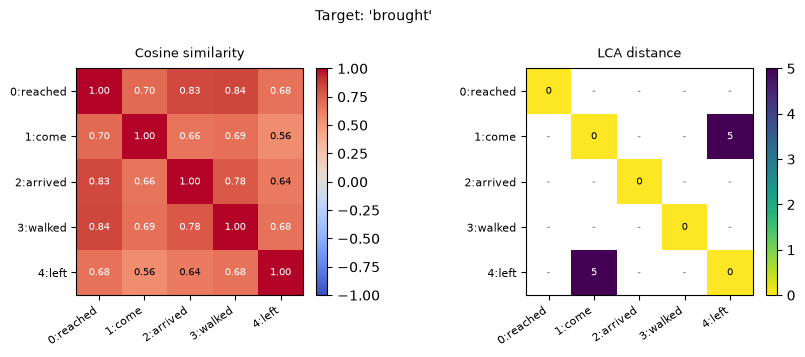


Context: 'Malfoy didn’t seem too happy.” They had brought' | Target: 'cakes,'
Top-5        |      0:mal |    1:harry |    2:along |    3:draco |     4:back
-----------------------------------------------------------------------------
0:mal        |     1.0000 |     0.8214 |     0.6175 |     0.6254 |     0.6779
1:harry      |     0.8214 |     1.0000 |     0.6582 |     0.6321 |     0.6842
2:along      |     0.6175 |     0.6582 |     1.0000 |     0.4833 |     0.7404
3:draco      |     0.6254 |     0.6321 |     0.4833 |     1.0000 |     0.5301
4:back       |     0.6779 |     0.6842 |     0.7404 |     0.5301 |     1.0000


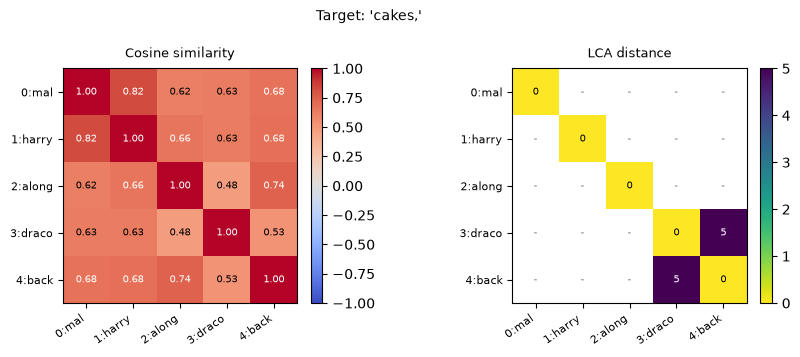


Context: 'Malfoy didn’t seem too happy.” They had brought cakes,' | Target: 'sweets,'
Top-5         |   0:chocolate |     1:flowers |      2:sweets |    3:biscuits |     4:cookies
---------------------------------------------------------------------------------------------
0:chocolate   |        1.0000 |        0.6312 |        0.8637 |        0.7644 |        0.8819
1:flowers     |        0.6312 |        1.0000 |        0.6068 |        0.6275 |        0.6817
2:sweets      |        0.8637 |        0.6068 |        1.0000 |        0.7138 |        0.7771
3:biscuits    |        0.7644 |        0.6275 |        0.7138 |        1.0000 |        0.8397
4:cookies     |        0.8819 |        0.6817 |        0.7771 |        0.8397 |        1.0000


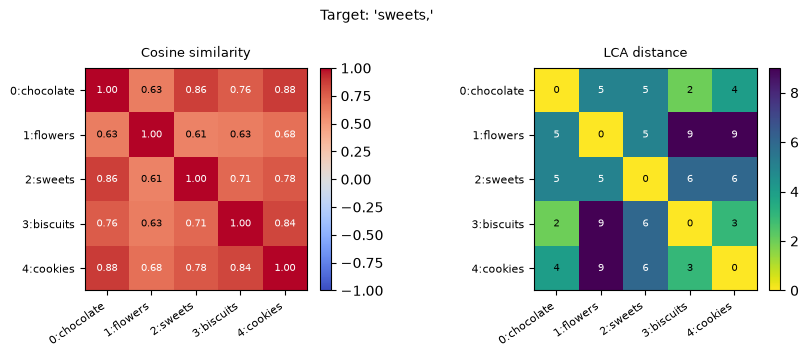


Context: 'Malfoy didn’t seem too happy.” They had brought cakes, sweets, and' | Target: 'bottles'
Top-5         |      0:drinks |      1:treats |   2:chocolate |        3:toys |    4:biscuits
---------------------------------------------------------------------------------------------
0:drinks      |        1.0000 |        0.8295 |        0.7754 |        0.7604 |        0.7497
1:treats      |        0.8295 |        1.0000 |        0.7951 |        0.7709 |        0.7643
2:chocolate   |        0.7754 |        0.7951 |        1.0000 |        0.7183 |        0.7644
3:toys        |        0.7604 |        0.7709 |        0.7183 |        1.0000 |        0.7429
4:biscuits    |        0.7497 |        0.7643 |        0.7644 |        0.7429 |        1.0000


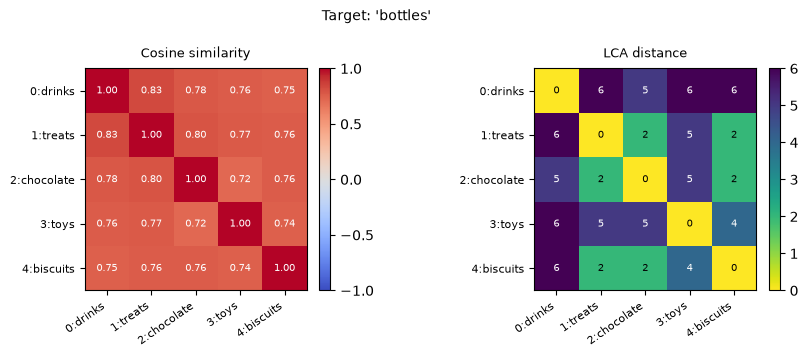


Context: 'Malfoy didn’t seem too happy.” They had brought cakes, sweets, and bottles of' | Target: 'pumpkin'
Top-5         |      0:butter |        1:fire |        2:wine |     3:pumpkin |   4:champagne
---------------------------------------------------------------------------------------------
0:butter      |        1.0000 |        0.6690 |        0.7744 |        0.8612 |        0.8480
1:fire        |        0.6690 |        1.0000 |        0.7617 |        0.6982 |        0.6528
2:wine        |        0.7744 |        0.7617 |        1.0000 |        0.7748 |        0.8280
3:pumpkin     |        0.8612 |        0.6982 |        0.7748 |        1.0000 |        0.7884
4:champagne   |        0.8480 |        0.6528 |        0.8280 |        0.7884 |        1.0000


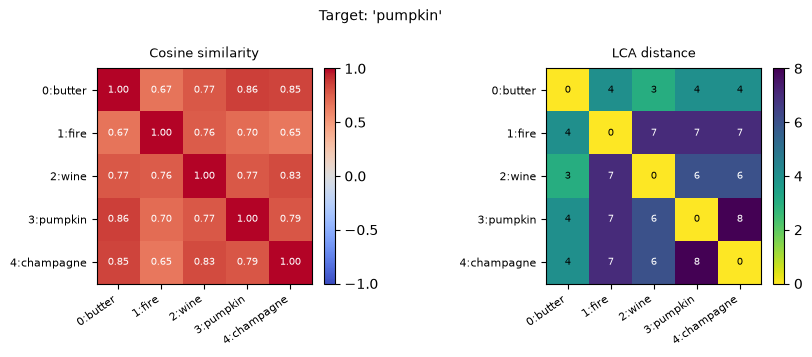


Context: 'Malfoy didn’t seem too happy.” They had brought cakes, sweets, and bottles of pumpkin' | Target: 'juice;'
Top-5        |    0:juice |     1:past |     2:beer |   3:butter |       4:ju
-----------------------------------------------------------------------------
0:juice      |     1.0000 |     0.5521 |     0.8077 |     0.8495 |     0.7039
1:past       |     0.5521 |     1.0000 |     0.5199 |     0.5266 |     0.4453
2:beer       |     0.8077 |     0.5199 |     1.0000 |     0.7983 |     0.6466
3:butter     |     0.8495 |     0.5266 |     0.7983 |     1.0000 |     0.7104
4:ju         |     0.7039 |     0.4453 |     0.6466 |     0.7104 |     1.0000


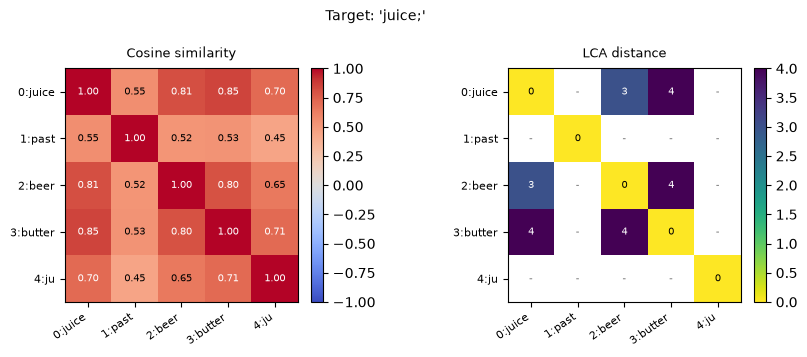


Context: 'Malfoy didn’t seem too happy.” They had brought cakes, sweets, and bottles of pumpkin juice; they gathered' | Target: 'around'
Top-5        |    0:around |     1:round |   2:outside |      3:near |     4:close
----------------------------------------------------------------------------------
0:around     |      1.0000 |      0.6794 |      0.6521 |      0.7478 |      0.6798
1:round      |      0.6794 |      1.0000 |      0.5058 |      0.6168 |      0.6407
2:outside    |      0.6521 |      0.5058 |      1.0000 |      0.6295 |      0.6095
3:near       |      0.7478 |      0.6168 |      0.6295 |      1.0000 |      0.8300
4:close      |      0.6798 |      0.6407 |      0.6095 |      0.8300 |      1.0000


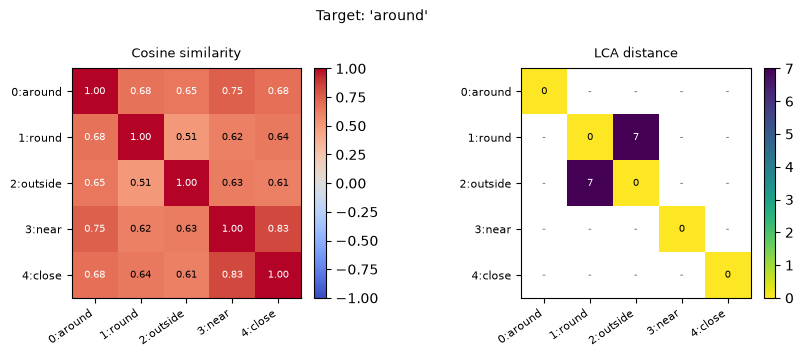


Context: 'Malfoy didn’t seem too happy.” They had brought cakes, sweets, and bottles of pumpkin juice; they gathered around' | Target: 'Harry’s'
Top-5        |      0:harry |   1:hermione |        2:mal |        3:ron |      4:draco
---------------------------------------------------------------------------------------
0:harry      |       1.0000 |       0.4042 |       0.8214 |       0.8624 |       0.6321
1:hermione   |       0.4042 |       1.0000 |       0.3802 |       0.3613 |       0.5872
2:mal        |       0.8214 |       0.3802 |       1.0000 |       0.8051 |       0.6254
3:ron        |       0.8624 |       0.3613 |       0.8051 |       1.0000 |       0.5808
4:draco      |       0.6321 |       0.5872 |       0.6254 |       0.5808 |       1.0000


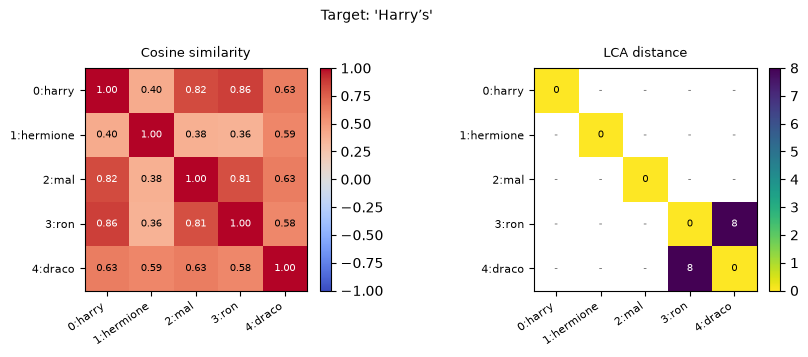


Context: 'Malfoy didn’t seem too happy.” They had brought cakes, sweets, and bottles of pumpkin juice; they gathered around Harry’s' | Target: 'bed'
Top-5        |       0:bed |     1:table |   2:bedside |     3:small |      4:tree
----------------------------------------------------------------------------------
0:bed        |      1.0000 |      0.5455 |      0.7111 |      0.6003 |      0.6224
1:table      |      0.5455 |      1.0000 |      0.5119 |      0.4418 |      0.5892
2:bedside    |      0.7111 |      0.5119 |      1.0000 |      0.7038 |      0.6649
3:small      |      0.6003 |      0.4418 |      0.7038 |      1.0000 |      0.6418
4:tree       |      0.6224 |      0.5892 |      0.6649 |      0.6418 |      1.0000


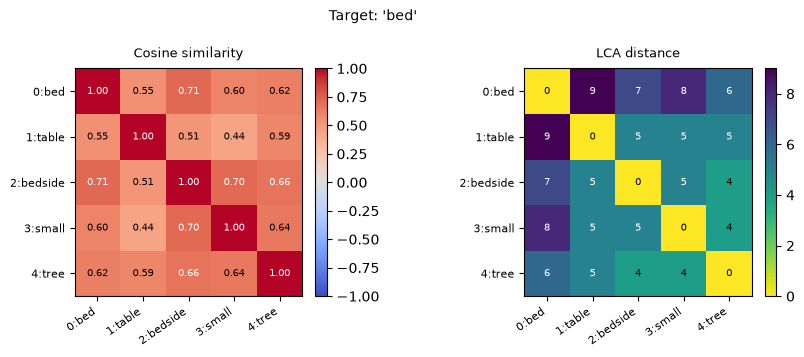


Context: 'Malfoy didn’t seem too happy.” They had brought cakes, sweets, and bottles of pumpkin juice; they gathered around Harry’s bed and were just' | Target: 'getting'
Top-5         |    0:starting |   1:beginning |   2:finishing |     3:sitting |     4:getting
---------------------------------------------------------------------------------------------
0:starting    |        1.0000 |        0.8639 |        0.7101 |        0.8011 |        0.8109
1:beginning   |        0.8639 |        1.0000 |        0.6650 |        0.7698 |        0.8144
2:finishing   |        0.7101 |        0.6650 |        1.0000 |        0.6671 |        0.6730
3:sitting     |        0.8011 |        0.7698 |        0.6671 |        1.0000 |        0.8335
4:getting     |        0.8109 |        0.8144 |        0.6730 |        0.8335 |        1.0000


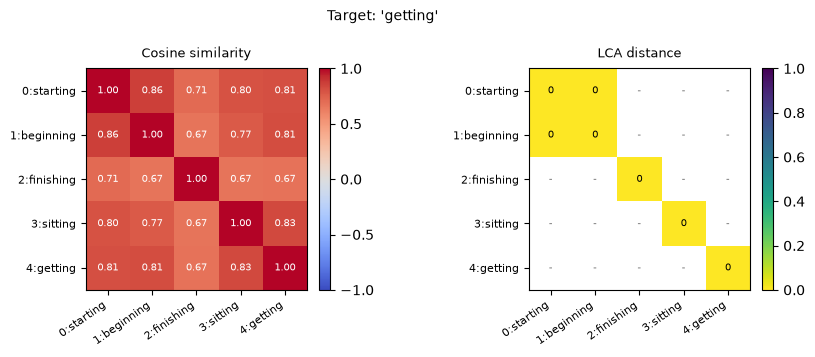


Context: 'Malfoy didn’t seem too happy.” They had brought cakes, sweets, and bottles of pumpkin juice; they gathered around Harry’s bed and were just getting' | Target: 'started'
Top-5        |     0:ready |   1:started |     2:round |    3:around |      4:back
----------------------------------------------------------------------------------
0:ready      |      1.0000 |      0.6883 |      0.5904 |      0.7358 |      0.6796
1:started    |      0.6883 |      1.0000 |      0.5946 |      0.6576 |      0.6866
2:round      |      0.5904 |      0.5946 |      1.0000 |      0.6794 |      0.5655
3:around     |      0.7358 |      0.6576 |      0.6794 |      1.0000 |      0.6622
4:back       |      0.6796 |      0.6866 |      0.5655 |      0.6622 |      1.0000


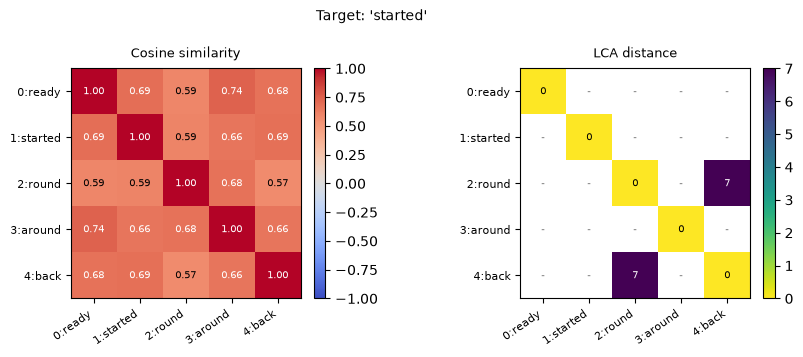


Context: 'Malfoy didn’t seem too happy.” They had brought cakes, sweets, and bottles of pumpkin juice; they gathered around Harry’s bed and were just getting started on what' | Target: 'promised'
Top-5        |     0:looked |     1:seemed |   2:promised |   3:appeared |    4:sounded
---------------------------------------------------------------------------------------
0:looked     |       1.0000 |       0.8034 |       0.6988 |       0.7944 |       0.8952
1:seemed     |       0.8034 |       1.0000 |       0.8043 |       0.7300 |       0.8541
2:promised   |       0.6988 |       0.8043 |       1.0000 |       0.6574 |       0.7524
3:appeared   |       0.7944 |       0.7300 |       0.6574 |       1.0000 |       0.7568
4:sounded    |       0.8952 |       0.8541 |       0.7524 |       0.7568 |       1.0000


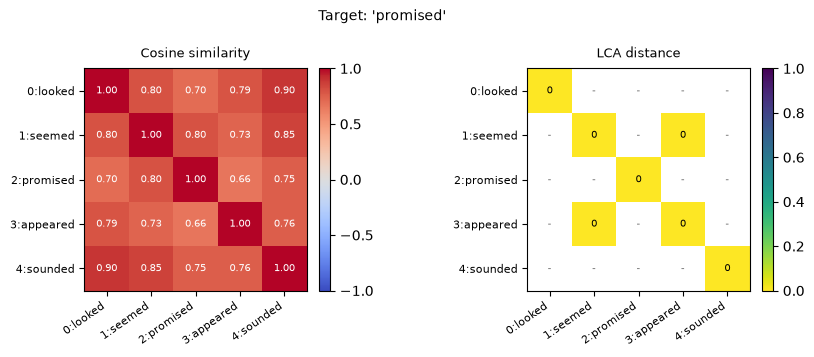


Context: 'Malfoy didn’t seem too happy.” They had brought cakes, sweets, and bottles of pumpkin juice; they gathered around Harry’s bed and were just getting started on what promised to be a' | Target: 'good'
Top-5        |     0:long |   1:rather |     2:good |     3:nice |      4:fun
-----------------------------------------------------------------------------
0:long       |     1.0000 |     0.5696 |     0.5176 |     0.6120 |     0.5292
1:rather     |     0.5696 |     1.0000 |     0.4693 |     0.5833 |     0.5341
2:good       |     0.5176 |     0.4693 |     1.0000 |     0.7113 |     0.5680
3:nice       |     0.6120 |     0.5833 |     0.7113 |     1.0000 |     0.7300
4:fun        |     0.5292 |     0.5341 |     0.5680 |     0.7300 |     1.0000


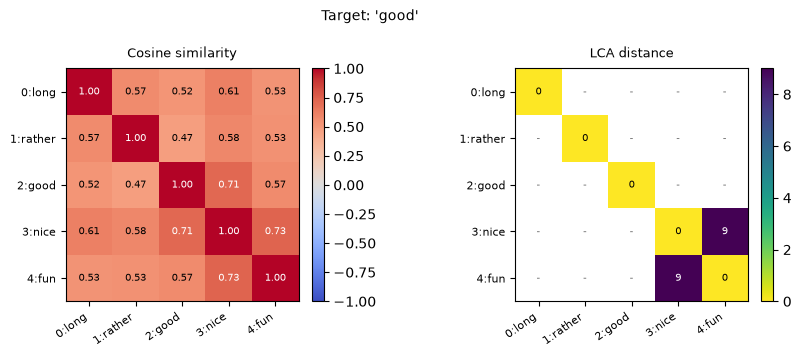


Context: 'Malfoy didn’t seem too happy.” They had brought cakes, sweets, and bottles of pumpkin juice; they gathered around Harry’s bed and were just getting started on what promised to be a good' | Target: 'party'
Top-5           |         0:party |          1:time |         2:night |   3:celebration |       4:evening
---------------------------------------------------------------------------------------------------------
0:party         |          1.0000 |          0.4388 |          0.3684 |          0.4710 |          0.4455
1:time          |          0.4388 |          1.0000 |          0.5573 |          0.7770 |          0.6321
2:night         |          0.3684 |          0.5573 |          1.0000 |          0.4914 |          0.6973
3:celebration   |          0.4710 |          0.7770 |          0.4914 |          1.0000 |          0.6940
4:evening       |          0.4455 |          0.6321 |          0.6973 |          0.6940 |          1.0000


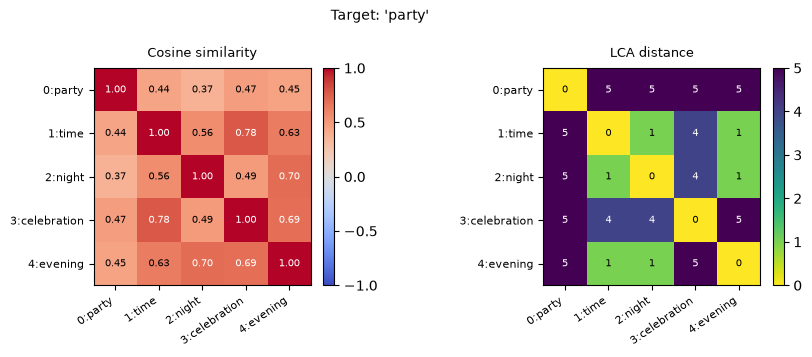


Context: 'Malfoy didn’t seem too happy.” They had brought cakes, sweets, and bottles of pumpkin juice; they gathered around Harry’s bed and were just getting started on what promised to be a good party when' | Target: 'Madam'
Top-5        |      0:mal |    1:draco |      2:ron |     3:fred |       4:mr
-----------------------------------------------------------------------------
0:mal        |     1.0000 |     0.6254 |     0.8051 |     0.7965 |     0.7609
1:draco      |     0.6254 |     1.0000 |     0.5808 |     0.6202 |     0.5866
2:ron        |     0.8051 |     0.5808 |     1.0000 |     0.8508 |     0.7408
3:fred       |     0.7965 |     0.6202 |     0.8508 |     1.0000 |     0.7667
4:mr         |     0.7609 |     0.5866 |     0.7408 |     0.7667 |     1.0000


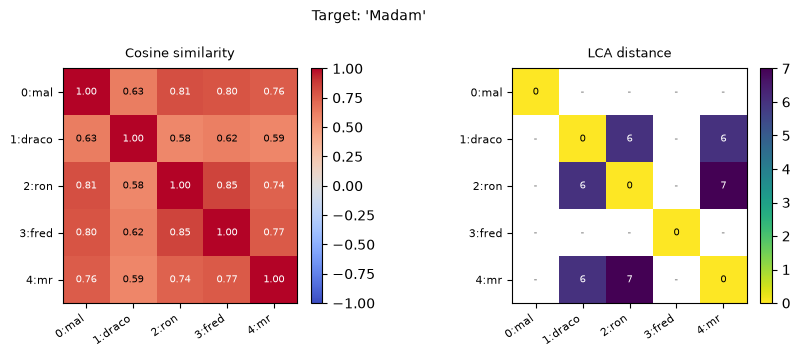


Context: 'Malfoy didn’t seem too happy.” They had brought cakes, sweets, and bottles of pumpkin juice; they gathered around Harry’s bed and were just getting started on what promised to be a good party when Madam' | Target: 'Pomfrey'
Top-5        |      0:pom |     1:prom |        2:p |    3:bones |     4:malk
-----------------------------------------------------------------------------
0:pom        |     1.0000 |     0.5328 |     0.4237 |     0.3763 |     0.5210
1:prom       |     0.5328 |     1.0000 |     0.4516 |     0.5826 |     0.5610
2:p          |     0.4237 |     0.4516 |     1.0000 |     0.3800 |     0.4071
3:bones      |     0.3763 |     0.5826 |     0.3800 |     1.0000 |     0.5154
4:malk       |     0.5210 |     0.5610 |     0.4071 |     0.5154 |     1.0000


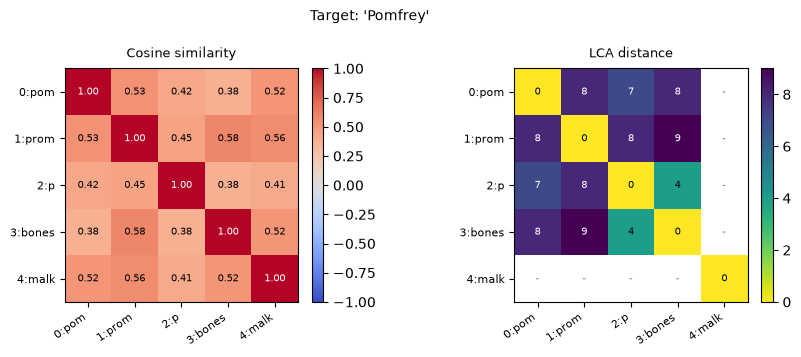


Context: 'Malfoy didn’t seem too happy.” They had brought cakes, sweets, and bottles of pumpkin juice; they gathered around Harry’s bed and were just getting started on what promised to be a good party when Madam Pomfrey' | Target: 'came'
Top-5        |      0:came |      1:bust |   2:arrived |     3:burst |    4:caught
----------------------------------------------------------------------------------
0:came       |      1.0000 |      0.6151 |      0.7885 |      0.6693 |      0.6788
1:bust       |      0.6151 |      1.0000 |      0.7202 |      0.8551 |      0.7727
2:arrived    |      0.7885 |      0.7202 |      1.0000 |      0.7610 |      0.7444
3:burst      |      0.6693 |      0.8551 |      0.7610 |      1.0000 |      0.7748
4:caught     |      0.6788 |      0.7727 |      0.7444 |      0.7748 |      1.0000


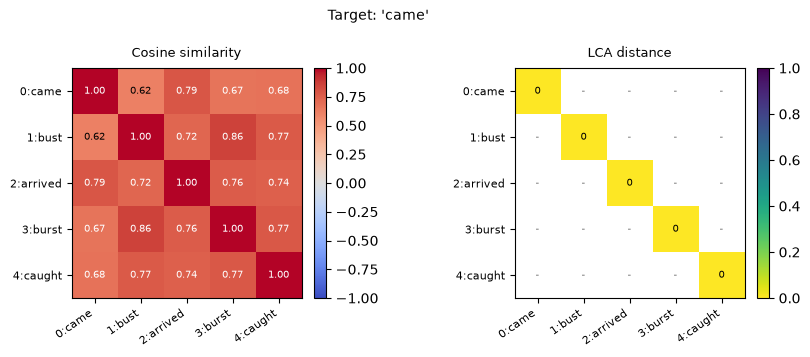


Context: 'Malfoy didn’t seem too happy.” They had brought cakes, sweets, and bottles of pumpkin juice; they gathered around Harry’s bed and were just getting started on what promised to be a good party when Madam Pomfrey came' | Target: 'storming'
Top-5        |       0:back |   1:bursting |    2:rushing |      3:storm |     4:around
---------------------------------------------------------------------------------------
0:back       |       1.0000 |       0.7198 |       0.7471 |       0.7287 |       0.6622
1:bursting   |       0.7198 |       1.0000 |       0.8916 |       0.8218 |       0.7097
2:rushing    |       0.7471 |       0.8916 |       1.0000 |       0.8506 |       0.7100
3:storm      |       0.7287 |       0.8218 |       0.8506 |       1.0000 |       0.7132
4:around     |       0.6622 |       0.7097 |       0.7100 |       0.7132 |       1.0000


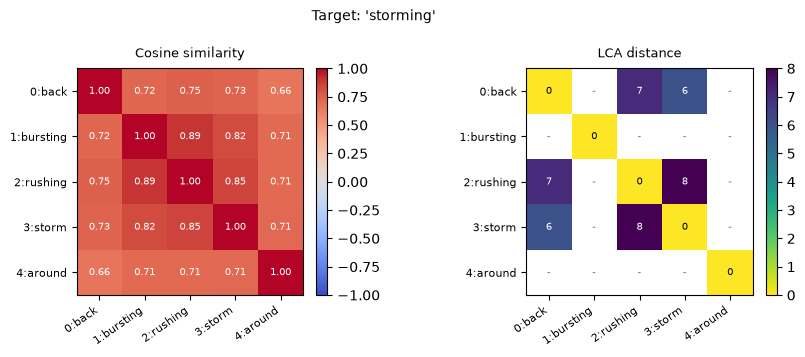


Context: 'Malfoy didn’t seem too happy.” They had brought cakes, sweets, and bottles of pumpkin juice; they gathered around Harry’s bed and were just getting started on what promised to be a good party when Madam Pomfrey came storming over,' | Target: 'shouting,'
Top-5        |   0:looking |    1:saying |    2:waving |        3:sc |       4:red
----------------------------------------------------------------------------------
0:looking    |      1.0000 |      0.8202 |      0.8158 |      0.6269 |      0.6949
1:saying     |      0.8202 |      1.0000 |      0.8199 |      0.6830 |      0.6993
2:waving     |      0.8158 |      0.8199 |      1.0000 |      0.6543 |      0.7125
3:sc         |      0.6269 |      0.6830 |      0.6543 |      1.0000 |      0.6459
4:red        |      0.6949 |      0.6993 |      0.7125 |      0.6459 |      1.0000


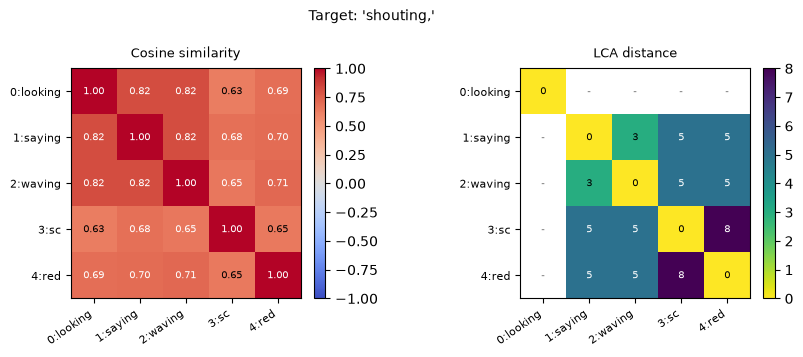


Context: 'Malfoy didn’t seem too happy.” They had brought cakes, sweets, and bottles of pumpkin juice; they gathered around Harry’s bed and were just getting started on what promised to be a good party when Madam Pomfrey came storming over, shouting, “This' | Target: 'boy'
Top-5        |      0:bed |    1:party |      2:boy |      3:way |      4:lot
-----------------------------------------------------------------------------
0:bed        |     1.0000 |     0.4093 |     0.6315 |     0.5329 |     0.6557
1:party      |     0.4093 |     1.0000 |     0.4141 |     0.3199 |     0.3947
2:boy        |     0.6315 |     0.4141 |     1.0000 |     0.5860 |     0.7194
3:way        |     0.5329 |     0.3199 |     0.5860 |     1.0000 |     0.7224
4:lot        |     0.6557 |     0.3947 |     0.7194 |     0.7224 |     1.0000


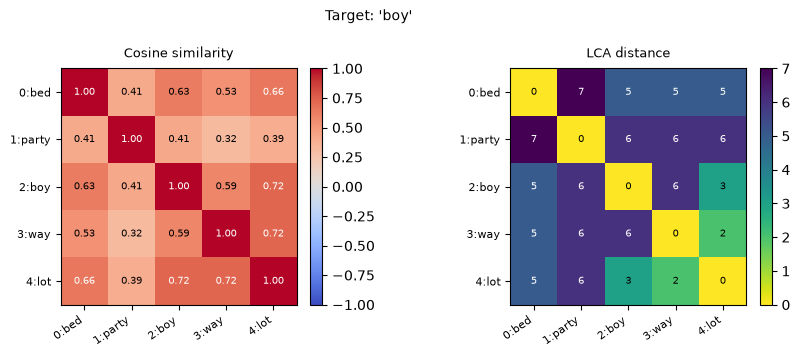


Context: 'Malfoy didn’t seem too happy.” They had brought cakes, sweets, and bottles of pumpkin juice; they gathered around Harry’s bed and were just getting started on what promised to be a good party when Madam Pomfrey came storming over, shouting, “This boy' | Target: 'needs'
Top-5          |        0:needs |   1:absolutely |       2:cannot |         3:eats |       4:simply
---------------------------------------------------------------------------------------------------
0:needs        |         1.0000 |         0.6328 |         0.7827 |         0.7894 |         0.6793
1:absolutely   |         0.6328 |         1.0000 |         0.6410 |         0.6939 |         0.7106
2:cannot       |         0.7827 |         0.6410 |         1.0000 |         0.7873 |         0.7366
3:eats         |         0.7894 |         0.6939 |         0.7873 |         1.0000 |         0.7035
4:simply       |         0.6793 |         0.7106 |         0.7366 |         0.7035 |         1.0000


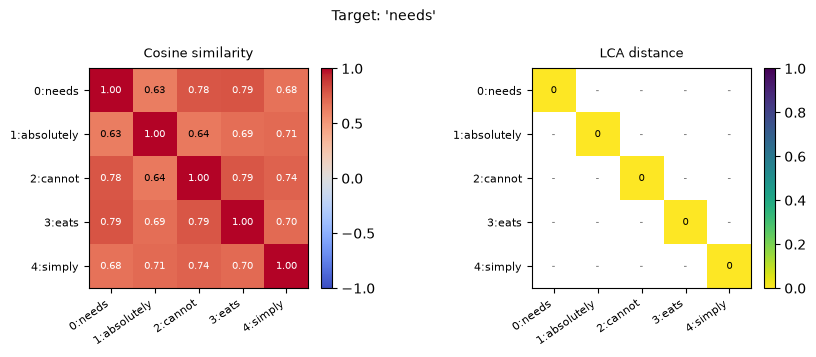


Context: 'Malfoy didn’t seem too happy.” They had brought cakes, sweets, and bottles of pumpkin juice; they gathered around Harry’s bed and were just getting started on what promised to be a good party when Madam Pomfrey came storming over, shouting, “This boy needs' | Target: 'rest,'
Top-5        |       0:rest |      1:sleep |   2:complete |   3:absolute |     4:plenty
---------------------------------------------------------------------------------------
0:rest       |       1.0000 |       0.5946 |       0.6100 |       0.6065 |       0.5777
1:sleep      |       0.5946 |       1.0000 |       0.4519 |       0.5313 |       0.4631
2:complete   |       0.6100 |       0.4519 |       1.0000 |       0.6929 |       0.5520
3:absolute   |       0.6065 |       0.5313 |       0.6929 |       1.0000 |       0.7777
4:plenty     |       0.5777 |       0.4631 |       0.5520 |       0.7777 |       1.0000


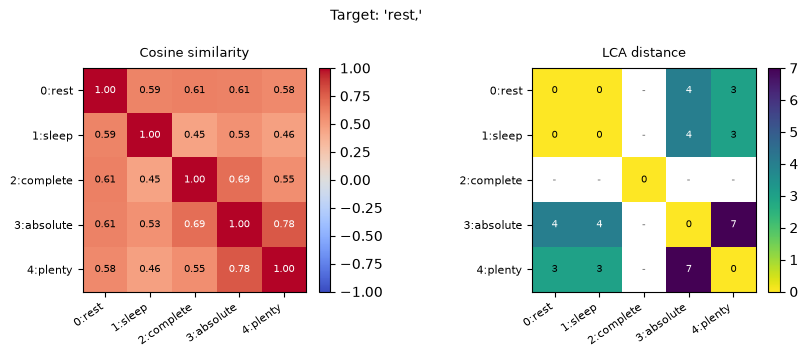


Context: 'Malfoy didn’t seem too happy.” They had brought cakes, sweets, and bottles of pumpkin juice; they gathered around Harry’s bed and were just getting started on what promised to be a good party when Madam Pomfrey came storming over, shouting, “This boy needs rest,' | Target: 'he’s'
Top-5          |         0:none |      1:nothing |        2:leave |   3:especially |          4:let
---------------------------------------------------------------------------------------------------
0:none         |         1.0000 |         0.6926 |         0.6289 |         0.6806 |         0.5733
1:nothing      |         0.6926 |         1.0000 |         0.5907 |         0.6501 |         0.5018
2:leave        |         0.6289 |         0.5907 |         1.0000 |         0.6754 |         0.6407
3:especially   |         0.6806 |         0.6501 |         0.6754 |         1.0000 |         0.5994
4:let          |         0.5733 |         0.5018 |         0.6407 |         0.5994 |         1.0000


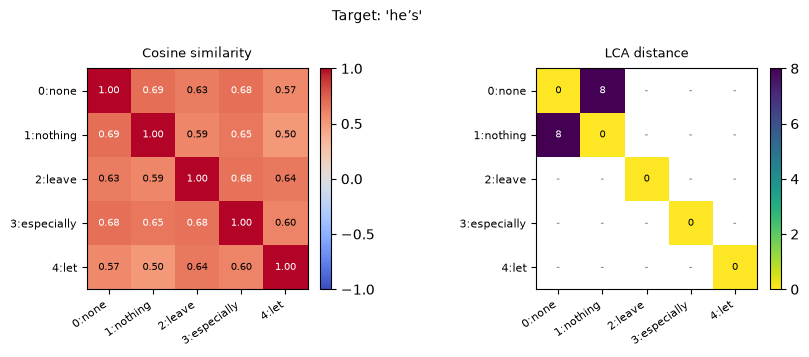


Context: 'Malfoy didn’t seem too happy.” They had brought cakes, sweets, and bottles of pumpkin juice; they gathered around Harry’s bed and were just getting started on what promised to be a good party when Madam Pomfrey came storming over, shouting, “This boy needs rest, he’s got' | Target: 'thirty-three'
Top-5        |     0:enough |   1:injuries |     2:school |       3:work |    4:nothing
---------------------------------------------------------------------------------------
0:enough     |       1.0000 |       0.4976 |       0.5080 |       0.5752 |       0.6068
1:injuries   |       0.4976 |       1.0000 |       0.5843 |       0.5484 |       0.5553
2:school     |       0.5080 |       0.5843 |       1.0000 |       0.5996 |       0.5519
3:work       |       0.5752 |       0.5484 |       0.5996 |       1.0000 |       0.6353
4:nothing    |       0.6068 |       0.5553 |       0.5519 |       0.6353 |       1.0000


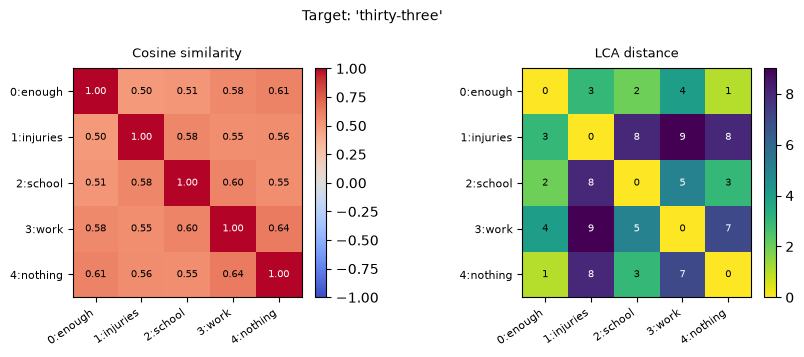


Context: 'Malfoy didn’t seem too happy.” They had brought cakes, sweets, and bottles of pumpkin juice; they gathered around Harry’s bed and were just getting started on what promised to be a good party when Madam Pomfrey came storming over, shouting, “This boy needs rest, he’s got thirty-three' | Target: 'bones'
Top-5         |        0:cuts |    1:stitches |     2:healing |   3:fractures |       4:bones
---------------------------------------------------------------------------------------------
0:cuts        |        1.0000 |        0.7928 |        0.7979 |        0.7939 |        0.6819
1:stitches    |        0.7928 |        1.0000 |        0.7891 |        0.7917 |        0.6182
2:healing     |        0.7979 |        0.7891 |        1.0000 |        0.8006 |        0.7124
3:fractures   |        0.7939 |        0.7917 |        0.8006 |        1.0000 |        0.6535
4:bones       |        0.6819 |        0.6182 |        0.7124 |        0.6535 |        1.0000


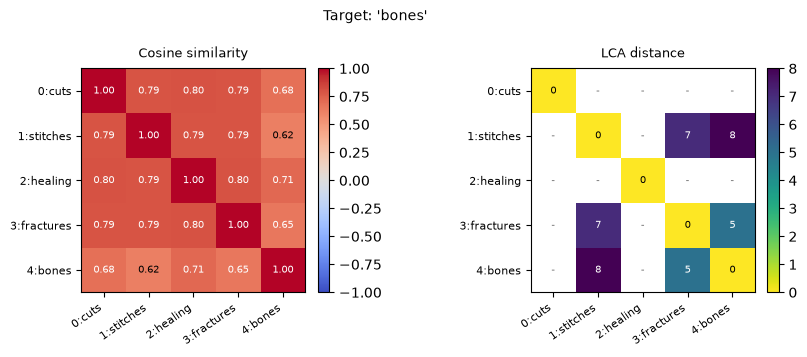


Context: 'Malfoy didn’t seem too happy.” They had brought cakes, sweets, and bottles of pumpkin juice; they gathered around Harry’s bed and were just getting started on what promised to be a good party when Madam Pomfrey came storming over, shouting, “This boy needs rest, he’s got thirty-three bones to' | Target: 'regrow!'
Top-5        |     0:mend |     1:heal |   2:repair |      3:fix |     4:knit
-----------------------------------------------------------------------------
0:mend       |     1.0000 |     0.6145 |     0.6662 |     0.5917 |     0.6159
1:heal       |     0.6145 |     1.0000 |     0.7326 |     0.8351 |     0.7744
2:repair     |     0.6662 |     0.7326 |     1.0000 |     0.7106 |     0.7180
3:fix        |     0.5917 |     0.8351 |     0.7106 |     1.0000 |     0.7286
4:knit       |     0.6159 |     0.7744 |     0.7180 |     0.7286 |     1.0000


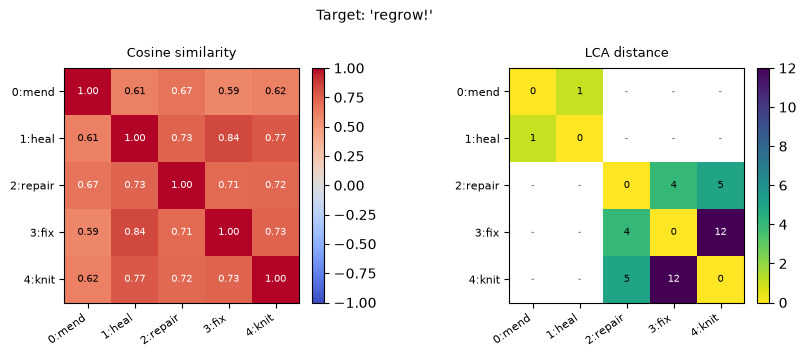


Context: 'OUT!” And' | Target: 'Harry'
Top-5        |        0:yet |   1:everyone |   2:suddenly |     3:indeed
------------------------------------------------------------------------
0:yet        |       1.0000 |       0.5921 |       0.5400 |       0.7033
1:everyone   |       0.5921 |       1.0000 |       0.5645 |       0.4465
2:suddenly   |       0.5400 |       0.5645 |       1.0000 |       0.4428
3:indeed     |       0.7033 |       0.4465 |       0.4428 |       1.0000


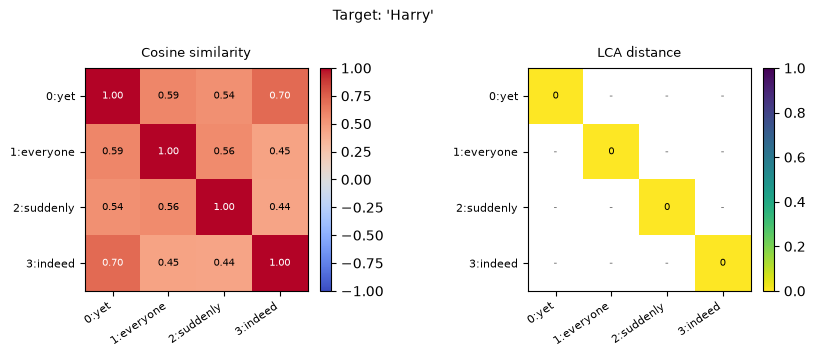


Context: 'OUT!” And Harry was' | Target: 'left'
Top-5        |      0:right |    1:running |   2:suddenly |       3:left |       4:glad
---------------------------------------------------------------------------------------
0:right      |       1.0000 |       0.5958 |       0.5156 |       0.7522 |       0.6721
1:running    |       0.5958 |       1.0000 |       0.5578 |       0.5701 |       0.6433
2:suddenly   |       0.5156 |       0.5578 |       1.0000 |       0.4390 |       0.5367
3:left       |       0.7522 |       0.5701 |       0.4390 |       1.0000 |       0.5437
4:glad       |       0.6721 |       0.6433 |       0.5367 |       0.5437 |       1.0000


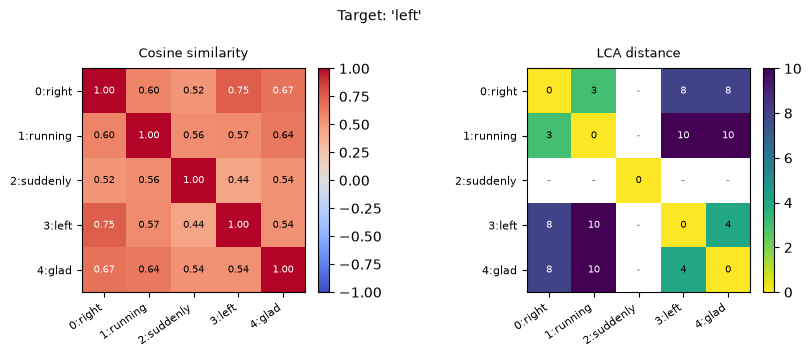


Context: 'OUT!” And Harry was left alone, with' | Target: 'nothing'
Top-5        |   0:nothing |    1:dudley |       2:ron |       3:mrs |     4:tears
----------------------------------------------------------------------------------
0:nothing    |      1.0000 |      0.4734 |      0.6107 |      0.5944 |      0.6103
1:dudley     |      0.4734 |      1.0000 |      0.5209 |      0.5055 |      0.4293
2:ron        |      0.6107 |      0.5209 |      1.0000 |      0.7557 |      0.5526
3:mrs        |      0.5944 |      0.5055 |      0.7557 |      1.0000 |      0.5696
4:tears      |      0.6103 |      0.4293 |      0.5526 |      0.5696 |      1.0000


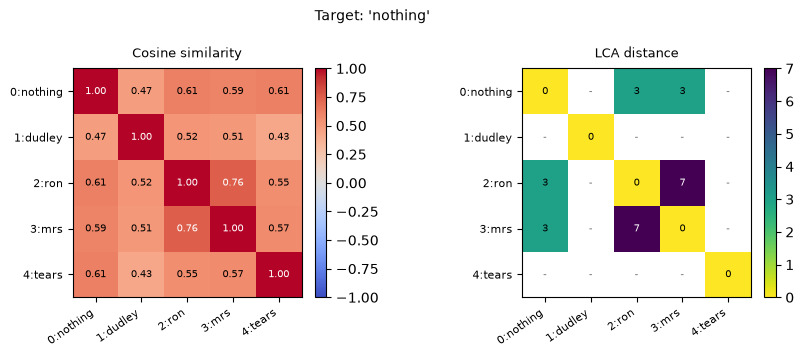


Context: 'OUT!” And Harry was left alone, with nothing to' | Target: 'distract'
Top-5        |       0:look |       1:show |      2:think |        3:eat |   4:distract
---------------------------------------------------------------------------------------
0:look       |       1.0000 |       0.6171 |       0.7606 |       0.7476 |       0.7336
1:show       |       0.6171 |       1.0000 |       0.5688 |       0.5837 |       0.6102
2:think      |       0.7606 |       0.5688 |       1.0000 |       0.7753 |       0.7005
3:eat        |       0.7476 |       0.5837 |       0.7753 |       1.0000 |       0.7934
4:distract   |       0.7336 |       0.6102 |       0.7005 |       0.7934 |       1.0000


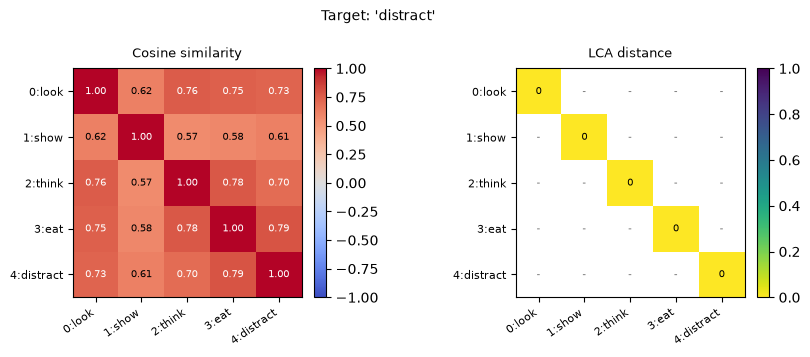


Context: 'OUT!” And Harry was left alone, with nothing to distract him from the stabbing' | Target: 'pains'
Top-5         |        0:pain |   1:sensation |       2:pains |     3:feeling |       4:agony
---------------------------------------------------------------------------------------------
0:pain        |        1.0000 |        0.7293 |        0.5768 |        0.6682 |        0.7665
1:sensation   |        0.7293 |        1.0000 |        0.6654 |        0.8502 |        0.7980
2:pains       |        0.5768 |        0.6654 |        1.0000 |        0.7793 |        0.7390
3:feeling     |        0.6682 |        0.8502 |        0.7793 |        1.0000 |        0.8047
4:agony       |        0.7665 |        0.7980 |        0.7390 |        0.8047 |        1.0000


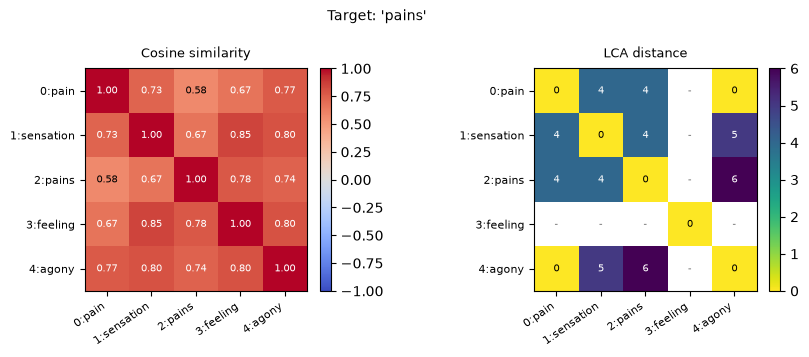


Context: 'OUT!” And Harry was left alone, with nothing to distract him from the stabbing pains in his' | Target: 'limp'
Top-5        |     0:head |      1:arm |     2:scar |    3:chest |     4:arms
-----------------------------------------------------------------------------
0:head       |     1.0000 |     0.6429 |     0.6654 |     0.6944 |     0.6781
1:arm        |     0.6429 |     1.0000 |     0.6253 |     0.6855 |     0.8214
2:scar       |     0.6654 |     0.6253 |     1.0000 |     0.6768 |     0.7032
3:chest      |     0.6944 |     0.6855 |     0.6768 |     1.0000 |     0.7721
4:arms       |     0.6781 |     0.8214 |     0.7032 |     0.7721 |     1.0000


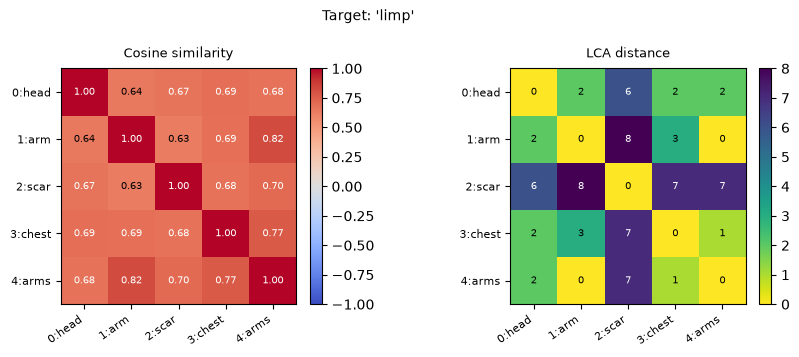


Context: 'OUT!” And Harry was left alone, with nothing to distract him from the stabbing pains in his limp' | Target: 'arm.'
Top-5        |      0:leg |      1:arm |    2:right |     3:left |     4:knee
-----------------------------------------------------------------------------
0:leg        |     1.0000 |     0.7126 |     0.5895 |     0.5887 |     0.8174
1:arm        |     0.7126 |     1.0000 |     0.5462 |     0.5374 |     0.7035
2:right      |     0.5895 |     0.5462 |     1.0000 |     0.7522 |     0.6692
3:left       |     0.5887 |     0.5374 |     0.7522 |     1.0000 |     0.6477
4:knee       |     0.8174 |     0.7035 |     0.6692 |     0.6477 |     1.0000


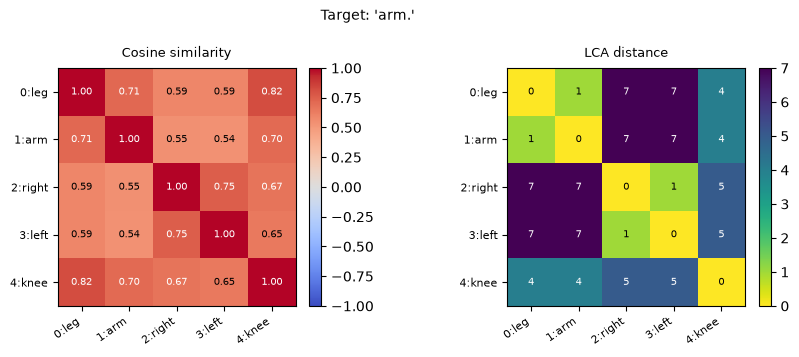


Context: 'Hours and' | Target: 'hours'
Top-5          |     0:location |         1:time |   2:directions |         3:days |         4:fees
---------------------------------------------------------------------------------------------------
0:location     |         1.0000 |         0.6338 |         0.6988 |         0.4080 |         0.5146
1:time         |         0.6338 |         1.0000 |         0.7378 |         0.5780 |         0.4379
2:directions   |         0.6988 |         0.7378 |         1.0000 |         0.5229 |         0.5754
3:days         |         0.4080 |         0.5780 |         0.5229 |         1.0000 |         0.4676
4:fees         |         0.5146 |         0.4379 |         0.5754 |         0.4676 |         1.0000


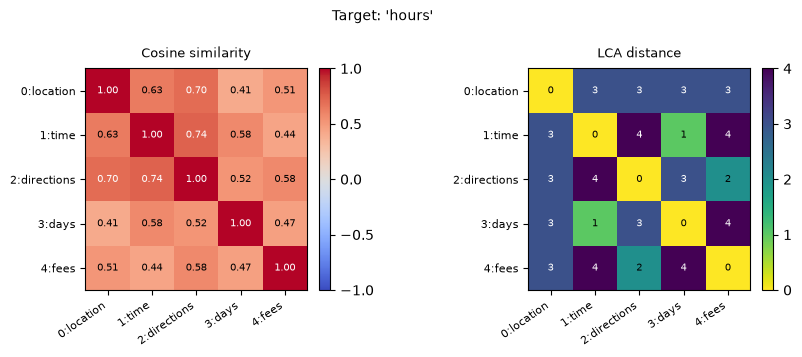


Context: 'Hours and hours later,' | Target: 'Harry'
Top-5        |     0:still |    1:though |      2:john |   3:nothing |         4:k
----------------------------------------------------------------------------------
0:still      |      1.0000 |      0.5155 |      0.3039 |      0.5099 |      0.3486
1:though     |      0.5155 |      1.0000 |      0.5775 |      0.5793 |      0.4922
2:john       |      0.3039 |      0.5775 |      1.0000 |      0.6091 |      0.5915
3:nothing    |      0.5099 |      0.5793 |      0.6091 |      1.0000 |      0.5213
4:k          |      0.3486 |      0.4922 |      0.5915 |      0.5213 |      1.0000


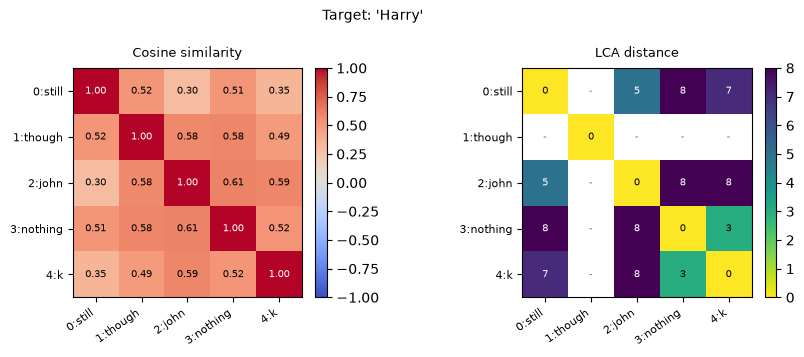


Context: 'Hours and hours later, Harry' | Target: 'woke'
Top-5        |   0:finally |     1:still |    2:potter |     3:found |      4:felt
----------------------------------------------------------------------------------
0:finally    |      1.0000 |      0.5073 |      0.4775 |      0.5084 |      0.4808
1:still      |      0.5073 |      1.0000 |      0.3246 |      0.3618 |      0.4073
2:potter     |      0.4775 |      0.3246 |      1.0000 |      0.5962 |      0.5742
3:found      |      0.5084 |      0.3618 |      0.5962 |      1.0000 |      0.6992
4:felt       |      0.4808 |      0.4073 |      0.5742 |      0.6992 |      1.0000


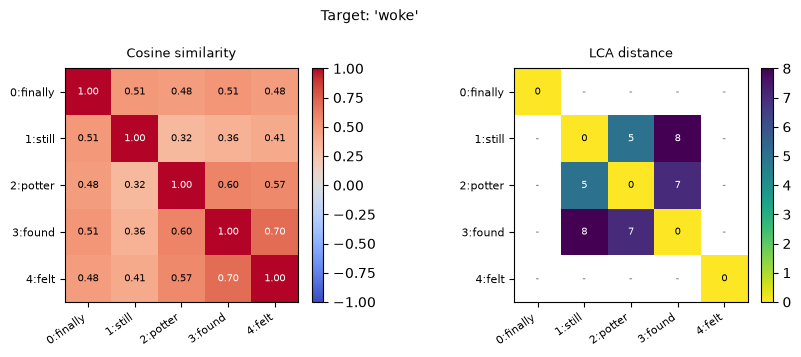


Context: 'Hours and hours later, Harry woke quite' | Target: 'suddenly'
Top-5         |    0:suddenly |    1:abruptly |       2:stiff |         3:dis |   4:naturally
---------------------------------------------------------------------------------------------
0:suddenly    |        1.0000 |        0.8100 |        0.5399 |        0.4855 |        0.6145
1:abruptly    |        0.8100 |        1.0000 |        0.6147 |        0.5288 |        0.6867
2:stiff       |        0.5399 |        0.6147 |        1.0000 |        0.5918 |        0.7512
3:dis         |        0.4855 |        0.5288 |        0.5918 |        1.0000 |        0.6059
4:naturally   |        0.6145 |        0.6867 |        0.7512 |        0.6059 |        1.0000


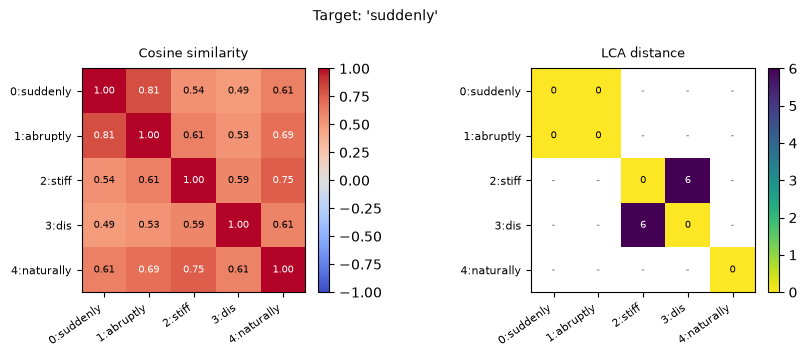


Context: 'Hours and hours later, Harry woke quite suddenly in the' | Target: 'pitch'
Top-5        |     0:middle |       1:dark |   2:darkness |      3:pitch |       4:dead
---------------------------------------------------------------------------------------
0:middle     |       1.0000 |       0.7376 |       0.7073 |       0.6815 |       0.5579
1:dark       |       0.7376 |       1.0000 |       0.8804 |       0.6524 |       0.6189
2:darkness   |       0.7073 |       0.8804 |       1.0000 |       0.6600 |       0.5908
3:pitch      |       0.6815 |       0.6524 |       0.6600 |       1.0000 |       0.5265
4:dead       |       0.5579 |       0.6189 |       0.5908 |       0.5265 |       1.0000


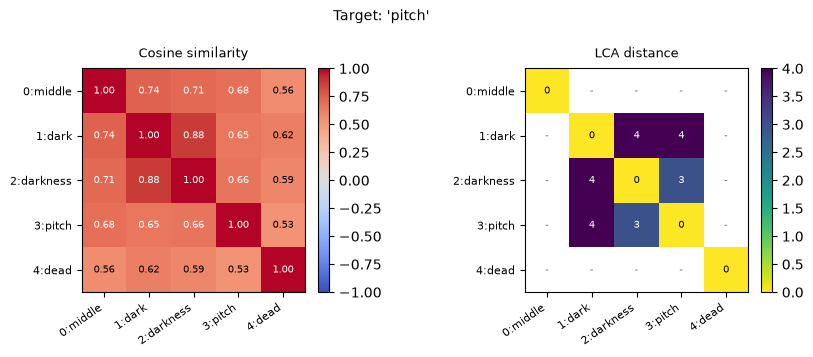


Context: 'Hours and hours later, Harry woke quite suddenly in the pitch' | Target: 'blackness'
Top-5        |       0:dark |      1:black |   2:darkness |         3:黑夜 |         4:黑暗
---------------------------------------------------------------------------------------
0:dark       |       1.0000 |       0.8582 |       0.8804 |       0.5809 |       0.5809
1:black      |       0.8582 |       1.0000 |       0.7786 |       0.5352 |       0.5352
2:darkness   |       0.8804 |       0.7786 |       1.0000 |       0.5921 |       0.5921
3:黑夜         |       0.5809 |       0.5352 |       0.5921 |       1.0000 |       1.0000
4:黑暗         |       0.5809 |       0.5352 |       0.5921 |       1.0000 |       1.0000


/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 40657 (\N{CJK UNIFIED IDEOGRAPH-9ED1}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 22812 (\N{CJK UNIFIED IDEOGRAPH-591C}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 26263 (\N{CJK UNIFIED IDEOGRAPH-6697}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 40657 (\N{CJK UNIFIED IDEOGRAPH-9ED1}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 22812 (\N{CJK UNIFIED IDEOGRAPH-591C}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 26263 (\N{CJK UNIFIED IDEOGRAPH-6697}) missing 

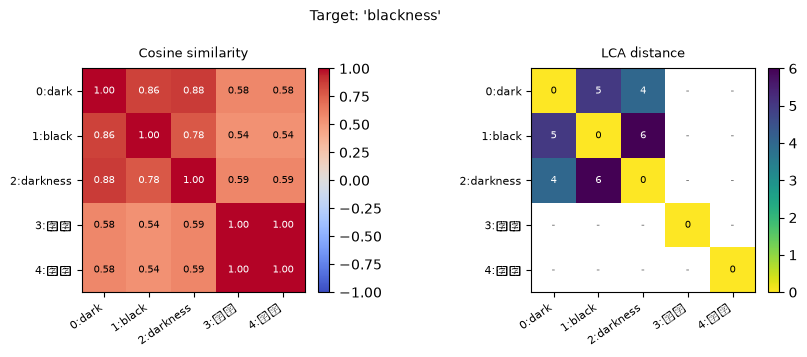


Context: 'Hours and hours later, Harry woke quite suddenly in the pitch blackness and' | Target: 'gave'
Top-5        |        0:lay |   1:listened |     2:stared |      3:found |      4:began
---------------------------------------------------------------------------------------
0:lay        |       1.0000 |       0.5015 |       0.6573 |       0.6299 |       0.6635
1:listened   |       0.5015 |       1.0000 |       0.8069 |       0.5877 |       0.6371
2:stared     |       0.6573 |       0.8069 |       1.0000 |       0.6713 |       0.7349
3:found      |       0.6299 |       0.5877 |       0.6713 |       1.0000 |       0.6664
4:began      |       0.6635 |       0.6371 |       0.7349 |       0.6664 |       1.0000


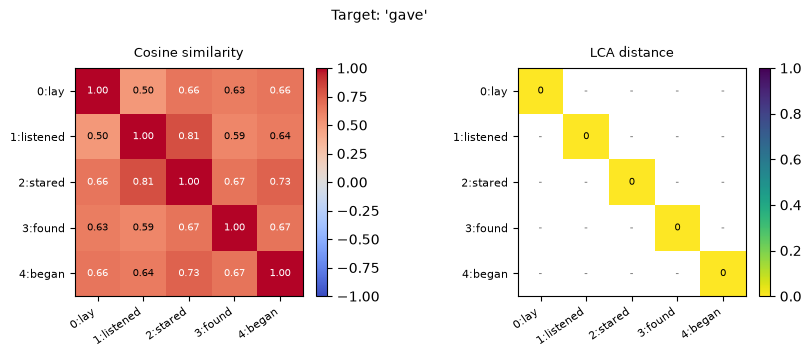


Context: 'Hours and hours later, Harry woke quite suddenly in the pitch blackness and gave a' | Target: 'small'
Top-5        |    0:great |    1:start |   2:little |      3:low |     4:long
-----------------------------------------------------------------------------
0:great      |     1.0000 |     0.3624 |     0.6254 |     0.6377 |     0.6000
1:start      |     0.3624 |     1.0000 |     0.4443 |     0.4867 |     0.3640
2:little     |     0.6254 |     0.4443 |     1.0000 |     0.6877 |     0.5995
3:low        |     0.6377 |     0.4867 |     0.6877 |     1.0000 |     0.5870
4:long       |     0.6000 |     0.3640 |     0.5995 |     0.5870 |     1.0000


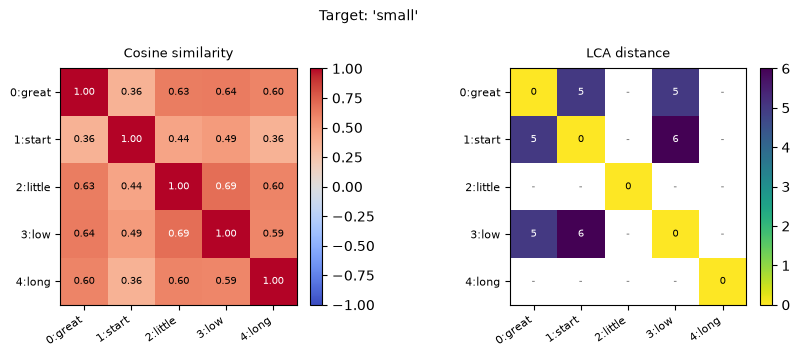


Context: 'Hours and hours later, Harry woke quite suddenly in the pitch blackness and gave a small' | Target: 'yelp'
Top-5        |      0:cry |    1:start |      2:gas |      3:gro |     4:sigh
-----------------------------------------------------------------------------
0:cry        |     1.0000 |     0.4635 |     0.5374 |     0.4948 |     0.5569
1:start      |     0.4635 |     1.0000 |     0.4050 |     0.3597 |     0.3563
2:gas        |     0.5374 |     0.4050 |     1.0000 |     0.5231 |     0.4644
3:gro        |     0.4948 |     0.3597 |     0.5231 |     1.0000 |     0.4556
4:sigh       |     0.5569 |     0.3563 |     0.4644 |     0.4556 |     1.0000


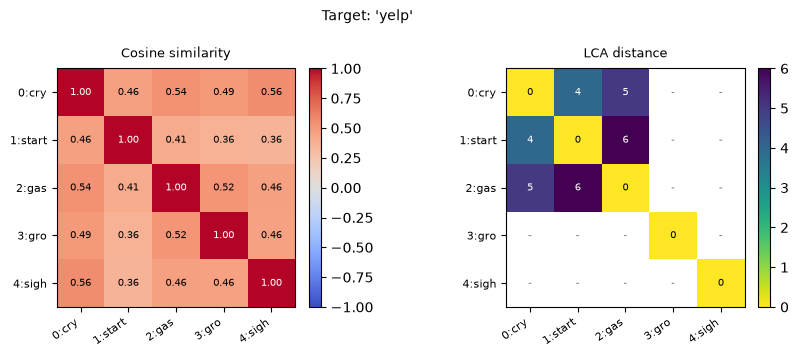


Context: 'Hours and hours later, Harry woke quite suddenly in the pitch blackness and gave a small yelp of' | Target: 'pain:'
Top-5        |     0:fright |      1:alarm |   2:surprise |       3:pain |       4:fear
---------------------------------------------------------------------------------------
0:fright     |       1.0000 |       0.7999 |       0.8235 |       0.6186 |       0.6823
1:alarm      |       0.7999 |       1.0000 |       0.8414 |       0.6855 |       0.7401
2:surprise   |       0.8235 |       0.8414 |       1.0000 |       0.6642 |       0.7264
3:pain       |       0.6186 |       0.6855 |       0.6642 |       1.0000 |       0.7551
4:fear       |       0.6823 |       0.7401 |       0.7264 |       0.7551 |       1.0000


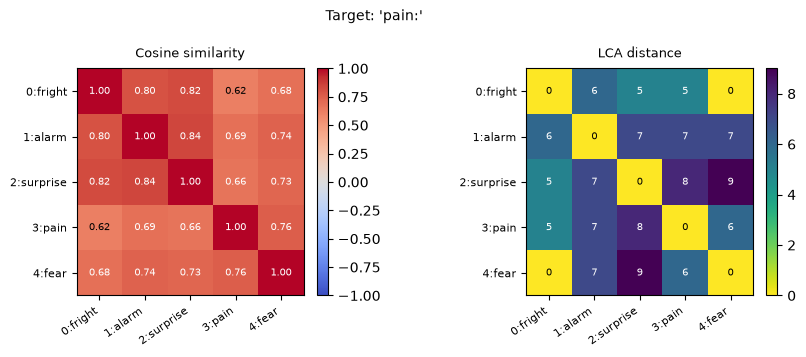


Context: 'Hours and hours later, Harry woke quite suddenly in the pitch blackness and gave a small yelp of pain: His' | Target: 'arm'
Top-5        |    0:ankle |      1:arm |      2:leg |    3:right |     4:left
-----------------------------------------------------------------------------
0:ankle      |     1.0000 |     0.7132 |     0.7337 |     0.6262 |     0.5784
1:arm        |     0.7132 |     1.0000 |     0.7126 |     0.5462 |     0.5374
2:leg        |     0.7337 |     0.7126 |     1.0000 |     0.5895 |     0.5887
3:right      |     0.6262 |     0.5462 |     0.5895 |     1.0000 |     0.7522
4:left       |     0.5784 |     0.5374 |     0.5887 |     0.7522 |     1.0000


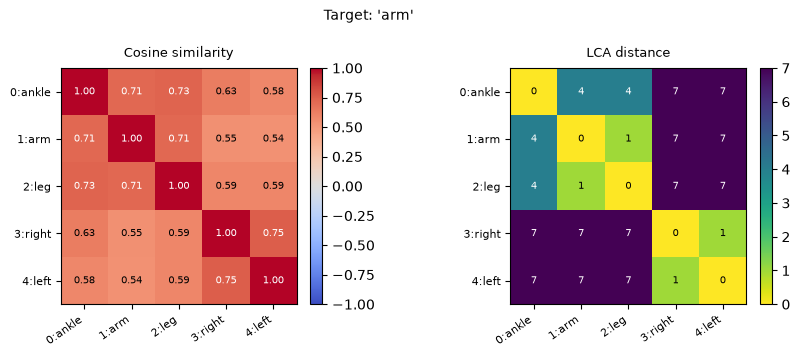


Context: 'Hours and hours later, Harry woke quite suddenly in the pitch blackness and gave a small yelp of pain: His arm now' | Target: 'felt'
Top-5        |     0:felt |     1:hurt |   2:seemed |       3:th |     4:hung
-----------------------------------------------------------------------------
0:felt       |     1.0000 |     0.7186 |     0.7200 |     0.5761 |     0.6178
1:hurt       |     0.7186 |     1.0000 |     0.7038 |     0.6348 |     0.6332
2:seemed     |     0.7200 |     0.7038 |     1.0000 |     0.6838 |     0.7307
3:th         |     0.5761 |     0.6348 |     0.6838 |     1.0000 |     0.6865
4:hung       |     0.6178 |     0.6332 |     0.7307 |     0.6865 |     1.0000


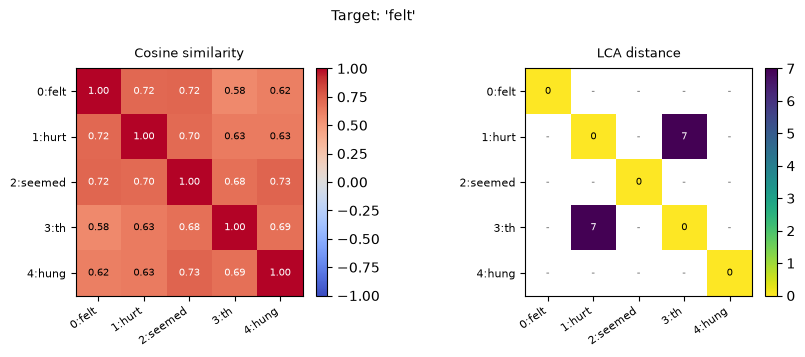


Context: 'Hours and hours later, Harry woke quite suddenly in the pitch blackness and gave a small yelp of pain: His arm now felt' | Target: 'full'
Top-5        |      0:heavy |      1:stiff |      2:twice |    3:nothing |   4:horribly
---------------------------------------------------------------------------------------
0:heavy      |       1.0000 |       0.7837 |       0.5313 |       0.6447 |       0.7159
1:stiff      |       0.7837 |       1.0000 |       0.4910 |       0.6410 |       0.7581
2:twice      |       0.5313 |       0.4910 |       1.0000 |       0.5363 |       0.5206
3:nothing    |       0.6447 |       0.6410 |       0.5363 |       1.0000 |       0.6645
4:horribly   |       0.7159 |       0.7581 |       0.5206 |       0.6645 |       1.0000


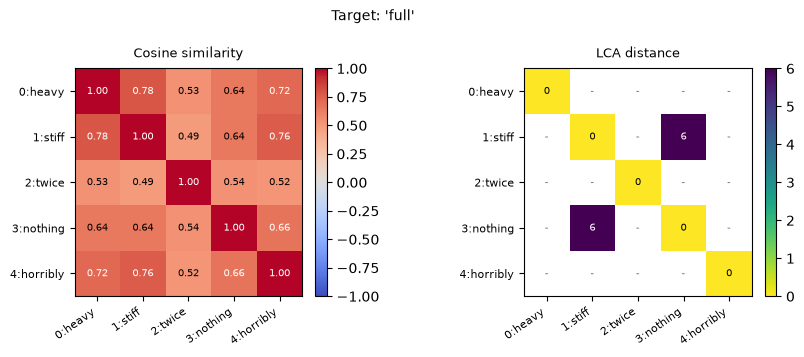


Context: 'Hours and hours later, Harry woke quite suddenly in the pitch blackness and gave a small yelp of pain: His arm now felt full of' | Target: 'large'
Top-5        |   0:needles |     1:sharp |      2:pins |        3:st |    4:snakes
----------------------------------------------------------------------------------
0:needles    |      1.0000 |      0.6506 |      0.6184 |      0.6044 |      0.5080
1:sharp      |      0.6506 |      1.0000 |      0.5084 |      0.5076 |      0.4556
2:pins       |      0.6184 |      0.5084 |      1.0000 |      0.4664 |      0.5344
3:st         |      0.6044 |      0.5076 |      0.4664 |      1.0000 |      0.3346
4:snakes     |      0.5080 |      0.4556 |      0.5344 |      0.3346 |      1.0000


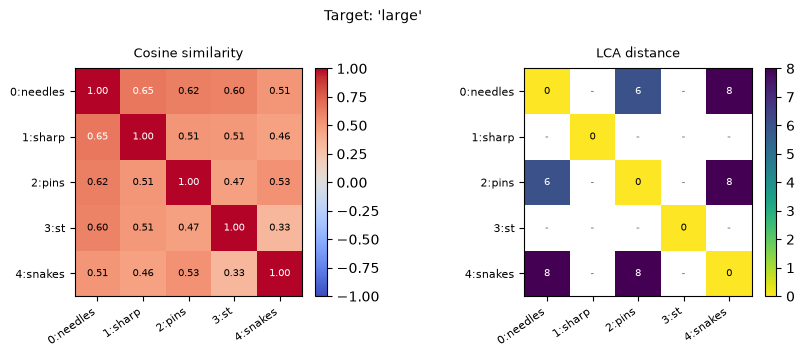


Context: 'Hours and hours later, Harry woke quite suddenly in the pitch blackness and gave a small yelp of pain: His arm now felt full of large' | Target: 'splinters.'
Top-5        |   0:needles |      1:pins |   2:insects |     3:sharp |    4:needle
----------------------------------------------------------------------------------
0:needles    |      1.0000 |      0.6184 |      0.5575 |      0.6506 |      0.8184
1:pins       |      0.6184 |      1.0000 |      0.5517 |      0.5084 |      0.5434
2:insects    |      0.5575 |      0.5517 |      1.0000 |      0.4777 |      0.5308
3:sharp      |      0.6506 |      0.5084 |      0.4777 |      1.0000 |      0.5815
4:needle     |      0.8184 |      0.5434 |      0.5308 |      0.5815 |      1.0000


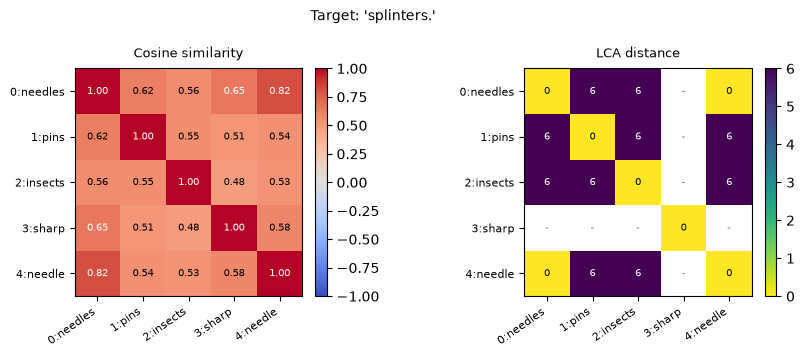

{'block1': [8, None, 8], 'block2': [None, 7, 6, 6], 'block3': [None, 9, 6, 6, 9, 6, 7, None, None, 7, 7, 6, 8], 'block4': [9, 9, 7, 3, 6, 5, 9], 'block5': [8], 'block7': [7, 9], 'block8': [6, 6, 6], 'block9': [8, 5, 9], 'block10': [6, 6, 9, 9, 9, 9, 6, 9, 7, 6], 'block11': [None, 9, 7, 8, 9, None, 9, None, None], 'block12': [7, 10, 1, 10, 6], 'block13': [9, 6, 6], 'block14': [6, 10, 1, 6, 7, 10, 10], 'block15': [None, 7], 'block16': [11], 'block17': [7, None, None, 8], 'block19': [9, None], 'block20': [None, 5, 7, 2, 7, 7, 7, 5, None, 7], 'block21': [9, 9, 9, 5, 7, 6, None], 'block22': [None, 8, 9, None, None, 8, 8, None], 'block23': [2, 7], 'block26': [2, None, 9, None, 8, 8, 8, None, 8], 'block27': [8, None, 12, 8], 'block28': [6, 13, 7, None, 8, 5, 8, None, 8, 8, 8, 10], 'block29': [7, 6, None, 4, 6, None], 'block30': [None, 9, None, 8, 8, 8, 9], 'block31': [12, 5, 3, None, 8, 8, 9, 8, 7, None], 'block32': [9, 8, 6, 6, 6], 'block33': [9, None, 8, 8, 10, 6], 'block34': [7, 9, 7, 4], 

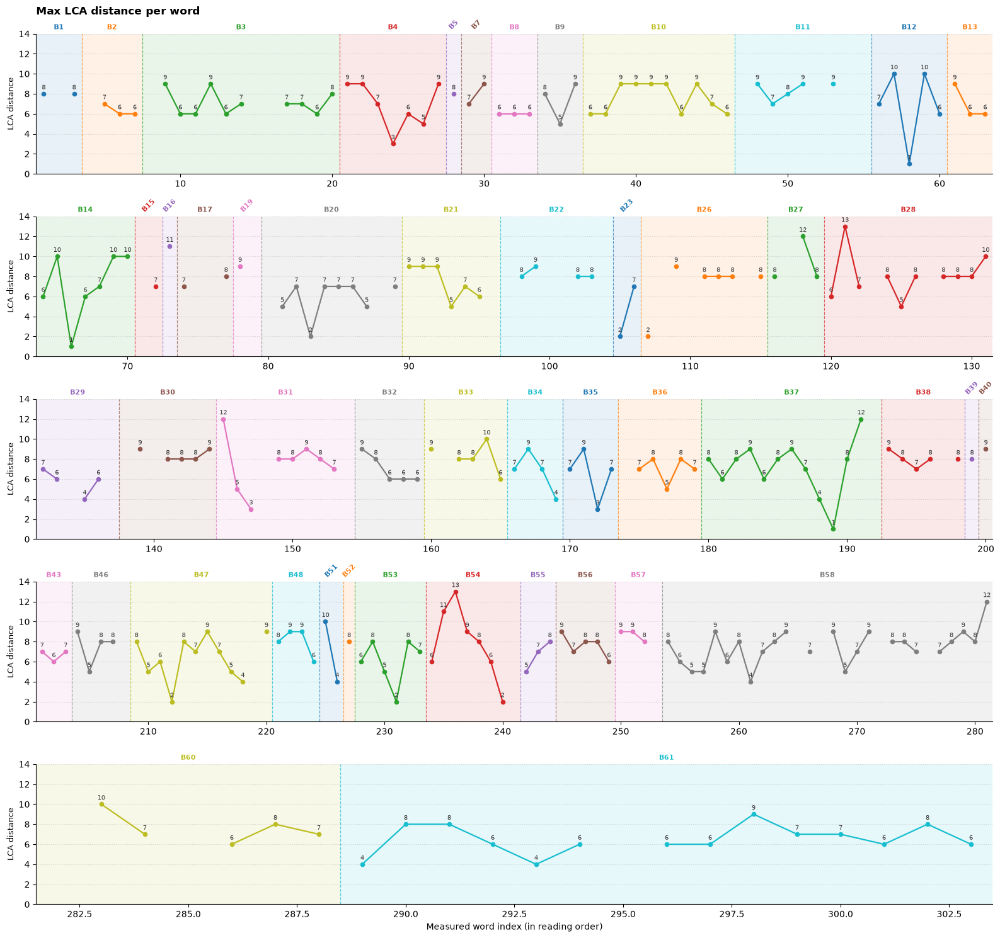

In [31]:
with open('./texts_data/creative_hp2.txt', 'r') as file:
    content = file.read()
    # print(content)
    print("\n")
    context_blocks, blocks_max_distances = analyze_semantic_with_context_segments(
        content,
        tokenizer = tokenizer_7b,
        model = model_7b,
        with_bert=True,
        bert_tokenizer=bert_tokenizer_7b,
        bert_model=bert_model_7b,
        print_results=False)

print(blocks_max_distances)
fig = plot_lca_curve(blocks_max_distances, title="Max LCA distance per word", blocks_per_row=12, show_values=True)
fig.tight_layout()
plt.show()
plt.close(fig)




Context: 'A' | Target: 'vaccine'
Top-5        |       0:high |   1:sequence |      2:group |   3:triangle |        4:man
---------------------------------------------------------------------------------------
0:high       |       1.0000 |       0.5138 |       0.4826 |       0.4378 |       0.4835
1:sequence   |       0.5138 |       1.0000 |       0.7093 |       0.6349 |       0.6489
2:group      |       0.4826 |       0.7093 |       1.0000 |       0.5834 |       0.6452
3:triangle   |       0.4378 |       0.6349 |       0.5834 |       1.0000 |       0.4581
4:man        |       0.4835 |       0.6489 |       0.6452 |       0.4581 |       1.0000


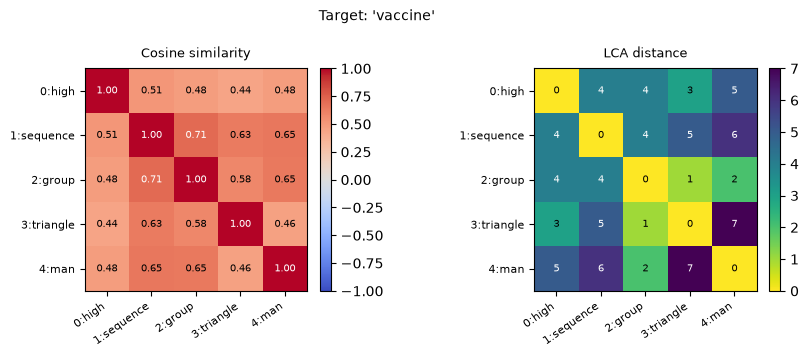


Context: 'A vaccine is a biological' | Target: 'preparation'
Top-5           |   0:preparation |       1:product |         2:agent |     3:substance |      4:medicine
---------------------------------------------------------------------------------------------------------
0:preparation   |          1.0000 |          0.7360 |          0.6463 |          0.7550 |          0.6350
1:product       |          0.7360 |          1.0000 |          0.6972 |          0.7931 |          0.5323
2:agent         |          0.6463 |          0.6972 |          1.0000 |          0.8124 |          0.4325
3:substance     |          0.7550 |          0.7931 |          0.8124 |          1.0000 |          0.5174
4:medicine      |          0.6350 |          0.5323 |          0.4325 |          0.5174 |          1.0000


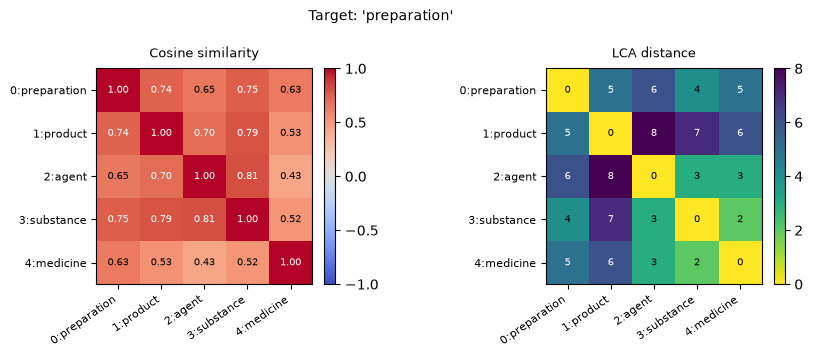


Context: 'A vaccine is a biological preparation that' | Target: 'provides'
Top-5        |   0:provides |   1:improves |      2:helps |   3:protects |   4:produces
---------------------------------------------------------------------------------------
0:provides   |       1.0000 |       0.6625 |       0.7127 |       0.7093 |       0.6813
1:improves   |       0.6625 |       1.0000 |       0.7303 |       0.7629 |       0.6217
2:helps      |       0.7127 |       0.7303 |       1.0000 |       0.7944 |       0.6231
3:protects   |       0.7093 |       0.7629 |       0.7944 |       1.0000 |       0.6222
4:produces   |       0.6813 |       0.6217 |       0.6231 |       0.6222 |       1.0000


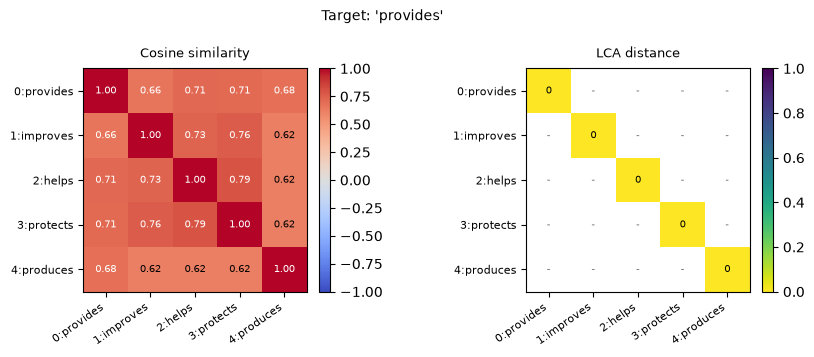


Context: 'A vaccine is a biological preparation that provides' | Target: 'active'
Top-5            |         0:active |       1:immunity |   2:specifically |     3:protection |         4:immune
---------------------------------------------------------------------------------------------------------------
0:active         |           1.0000 |           0.5606 |           0.6850 |           0.7053 |           0.8228
1:immunity       |           0.5606 |           1.0000 |           0.4753 |           0.5404 |           0.6441
2:specifically   |           0.6850 |           0.4753 |           1.0000 |           0.7431 |           0.7556
3:protection     |           0.7053 |           0.5404 |           0.7431 |           1.0000 |           0.7591
4:immune         |           0.8228 |           0.6441 |           0.7556 |           0.7591 |           1.0000


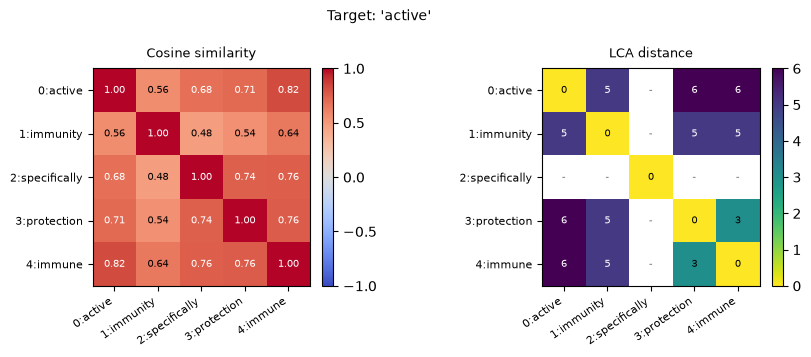


Context: 'A vaccine is a biological preparation that provides active acquired' | Target: 'immunity'
Top-5        |   0:immunity |      1:immun |     2:immune |        3:imm |         4:免疫
---------------------------------------------------------------------------------------
0:immunity   |       1.0000 |       0.4228 |       0.6441 |       0.4300 |       0.4219
1:immun      |       0.4228 |       1.0000 |       0.4759 |       0.5711 |       0.3154
2:immune     |       0.6441 |       0.4759 |       1.0000 |       0.6201 |       0.5480
3:imm        |       0.4300 |       0.5711 |       0.6201 |       1.0000 |       0.4972
4:免疫         |       0.4219 |       0.3154 |       0.5480 |       0.4972 |       1.0000


/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 20813 (\N{CJK UNIFIED IDEOGRAPH-514D}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 30123 (\N{CJK UNIFIED IDEOGRAPH-75AB}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 20813 (\N{CJK UNIFIED IDEOGRAPH-514D}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 30123 (\N{CJK UNIFIED IDEOGRAPH-75AB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


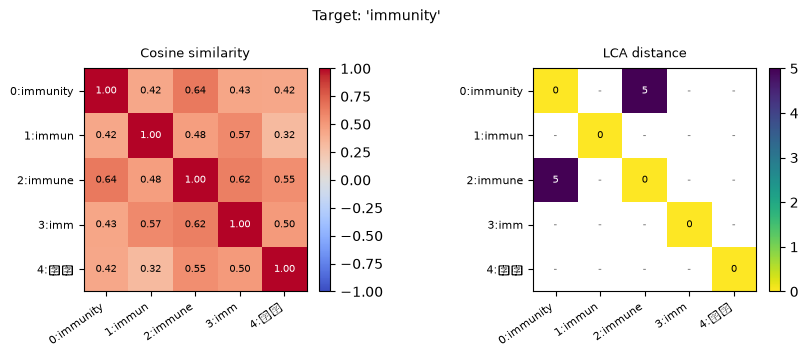


Context: 'A vaccine is a biological preparation that provides active acquired immunity to a' | Target: 'particular'
Top-5          |   0:particular |     1:specific |      2:disease |          3:传染病 |      4:variety
---------------------------------------------------------------------------------------------------
0:particular   |         1.0000 |         0.9118 |         0.6773 |         0.4318 |         0.7081
1:specific     |         0.9118 |         1.0000 |         0.7528 |         0.4334 |         0.7324
2:disease      |         0.6773 |         0.7528 |         1.0000 |         0.4422 |         0.6428
3:传染病          |         0.4318 |         0.4334 |         0.4422 |         1.0000 |         0.3943
4:variety      |         0.7081 |         0.7324 |         0.6428 |         0.3943 |         1.0000


/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 20256 (\N{CJK UNIFIED IDEOGRAPH-4F20}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 26579 (\N{CJK UNIFIED IDEOGRAPH-67D3}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 30149 (\N{CJK UNIFIED IDEOGRAPH-75C5}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 20256 (\N{CJK UNIFIED IDEOGRAPH-4F20}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 26579 (\N{CJK UNIFIED IDEOGRAPH-67D3}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 30149 (\N{CJK UNIFIED IDEOGRAPH-75C5}) missing 

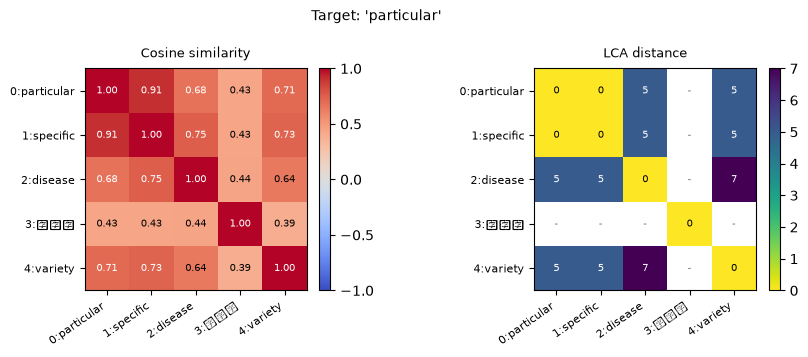


Context: 'A vaccine is a biological preparation that provides active acquired immunity to a particular infectious or malignant' | Target: 'disease.'
Top-5         |     0:disease |       1:agent |        2:path |   3:condition |    4:diseases
---------------------------------------------------------------------------------------------
0:disease     |        1.0000 |        0.6213 |        0.5924 |        0.6910 |        0.9017
1:agent       |        0.6213 |        1.0000 |        0.6837 |        0.6378 |        0.4984
2:path        |        0.5924 |        0.6837 |        1.0000 |        0.6179 |        0.5121
3:condition   |        0.6910 |        0.6378 |        0.6179 |        1.0000 |        0.5981
4:diseases    |        0.9017 |        0.4984 |        0.5121 |        0.5981 |        1.0000


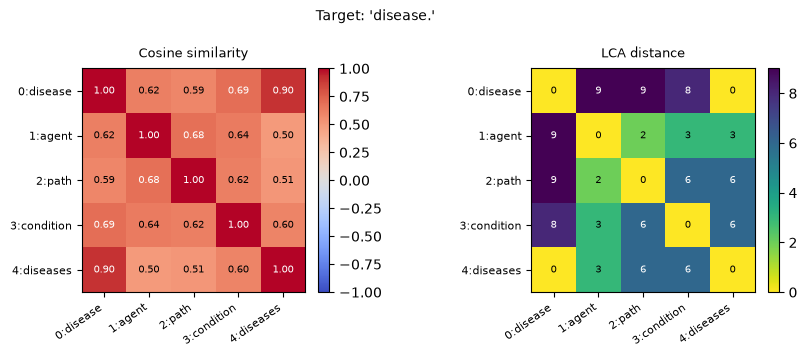


Context: 'The' | Target: 'safety'
Top-5         |   0:following |         1:sum |      2:purple |    3:function |      4:number
---------------------------------------------------------------------------------------------
0:following   |        1.0000 |        0.5209 |        0.5680 |        0.4828 |        0.5987
1:sum         |        0.5209 |        1.0000 |        0.5980 |        0.6384 |        0.6528
2:purple      |        0.5680 |        0.5980 |        1.0000 |        0.5516 |        0.7352
3:function    |        0.4828 |        0.6384 |        0.5516 |        1.0000 |        0.6338
4:number      |        0.5987 |        0.6528 |        0.7352 |        0.6338 |        1.0000


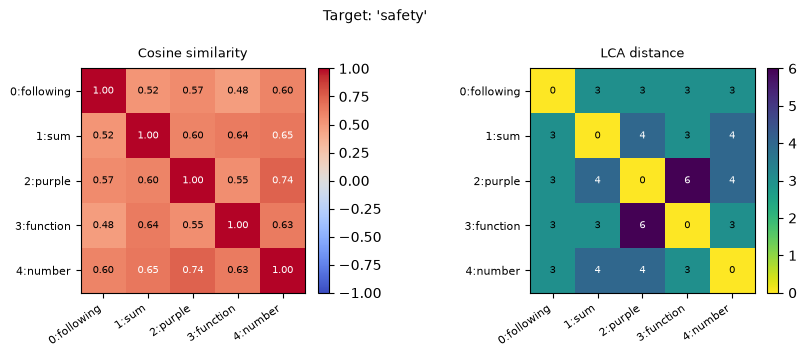


Context: 'The safety and' | Target: 'effectiveness'
Top-5             |          0:health |     1:reliability |        2:efficacy |       3:technical |   4:effectiveness
---------------------------------------------------------------------------------------------------------------------
0:health          |            1.0000 |            0.5890 |            0.5644 |            0.4860 |            0.5892
1:reliability     |            0.5890 |            1.0000 |            0.7800 |            0.6111 |            0.8226
2:efficacy        |            0.5644 |            0.7800 |            1.0000 |            0.4514 |            0.9310
3:technical       |            0.4860 |            0.6111 |            0.4514 |            1.0000 |            0.4934
4:effectiveness   |            0.5892 |            0.8226 |            0.9310 |            0.4934 |            1.0000


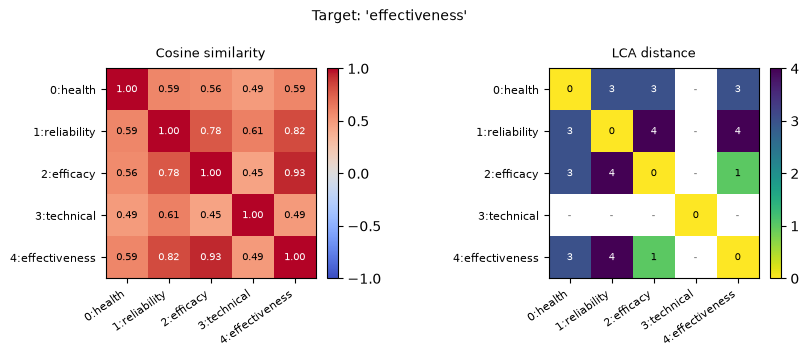


Context: 'The safety and effectiveness of' | Target: 'vaccines'
Top-5        |      0:using |      1:drugs |    2:medical |   3:vaccines |       4:intr
---------------------------------------------------------------------------------------
0:using      |       1.0000 |       0.4993 |       0.5636 |       0.6471 |       0.4692
1:drugs      |       0.4993 |       1.0000 |       0.6750 |       0.6561 |       0.3230
2:medical    |       0.5636 |       0.6750 |       1.0000 |       0.7779 |       0.4397
3:vaccines   |       0.6471 |       0.6561 |       0.7779 |       1.0000 |       0.4457
4:intr       |       0.4692 |       0.3230 |       0.4397 |       0.4457 |       1.0000


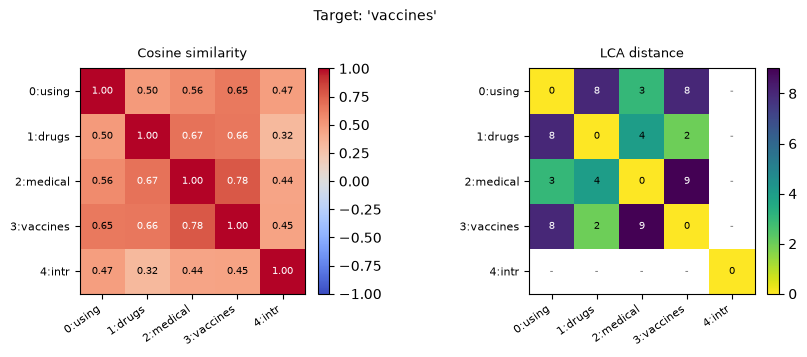


Context: 'The safety and effectiveness of vaccines has been' | Target: 'widely'
Top-5           |        0:called |    1:questioned |   2:extensively |        3:widely |    4:repeatedly
---------------------------------------------------------------------------------------------------------
0:called        |          1.0000 |          0.6900 |          0.6483 |          0.6316 |          0.6577
1:questioned    |          0.6900 |          1.0000 |          0.8558 |          0.7868 |          0.7418
2:extensively   |          0.6483 |          0.8558 |          1.0000 |          0.9089 |          0.8155
3:widely        |          0.6316 |          0.7868 |          0.9089 |          1.0000 |          0.8074
4:repeatedly    |          0.6577 |          0.7418 |          0.8155 |          0.8074 |          1.0000


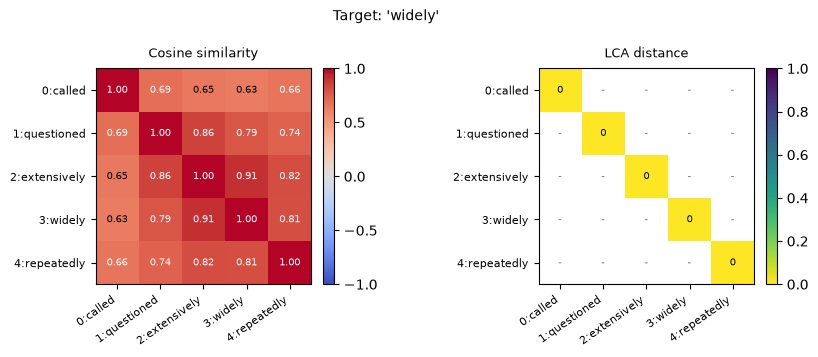


Context: 'A' | Target: 'vaccine'
Top-5        |       0:high |   1:sequence |      2:group |   3:triangle |        4:man
---------------------------------------------------------------------------------------
0:high       |       1.0000 |       0.5138 |       0.4826 |       0.4378 |       0.4835
1:sequence   |       0.5138 |       1.0000 |       0.7093 |       0.6349 |       0.6489
2:group      |       0.4826 |       0.7093 |       1.0000 |       0.5834 |       0.6452
3:triangle   |       0.4378 |       0.6349 |       0.5834 |       1.0000 |       0.4581
4:man        |       0.4835 |       0.6489 |       0.6452 |       0.4581 |       1.0000


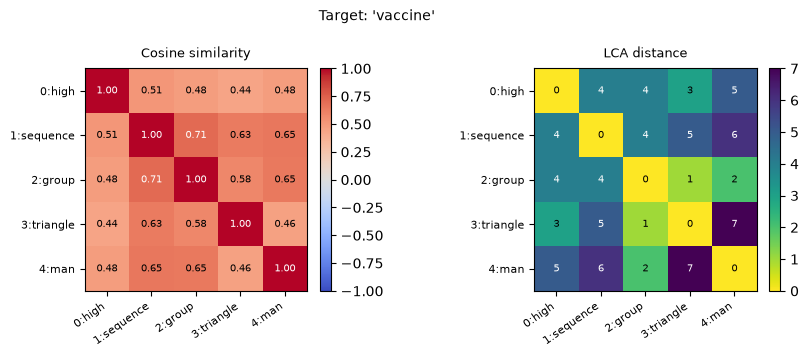


Context: 'A vaccine' | Target: 'typically'
Top-5            |          0:trial |     1:containing |       2:produced |            3:pre |   4:administered
---------------------------------------------------------------------------------------------------------------
0:trial          |           1.0000 |           0.7296 |           0.5127 |           0.7694 |           0.7851
1:containing     |           0.7296 |           1.0000 |           0.5695 |           0.6986 |           0.7865
2:produced       |           0.5127 |           0.5695 |           1.0000 |           0.5697 |           0.6225
3:pre            |           0.7694 |           0.6986 |           0.5697 |           1.0000 |           0.7823
4:administered   |           0.7851 |           0.7865 |           0.6225 |           0.7823 |           1.0000


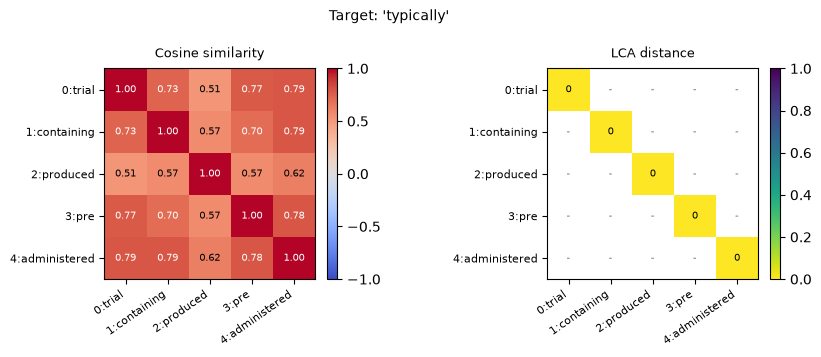


Context: 'A vaccine typically' | Target: 'contains'
Top-5        |   0:contains |   1:consists |     2:refers |   3:requires |   4:includes
---------------------------------------------------------------------------------------
0:contains   |       1.0000 |       0.7422 |       0.6261 |       0.7035 |       0.7823
1:consists   |       0.7422 |       1.0000 |       0.6624 |       0.6572 |       0.8059
2:refers     |       0.6261 |       0.6624 |       1.0000 |       0.6043 |       0.7466
3:requires   |       0.7035 |       0.6572 |       0.6043 |       1.0000 |       0.6612
4:includes   |       0.7823 |       0.8059 |       0.7466 |       0.6612 |       1.0000


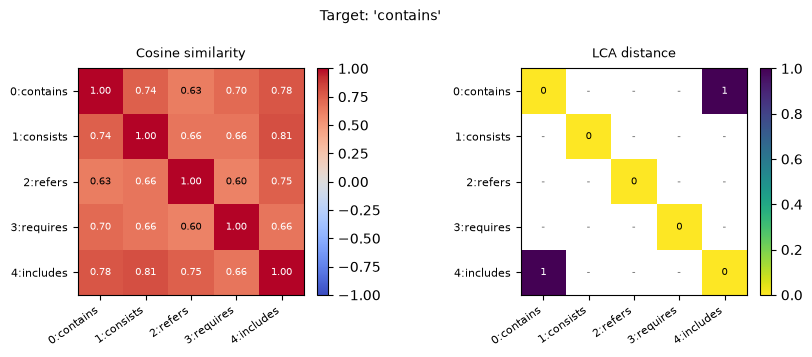


Context: 'A vaccine typically contains an' | Target: 'agent'
Top-5        |   0:antigen |    1:attenu |     2:immun |        3:ad |     4:agent
----------------------------------------------------------------------------------
0:antigen    |      1.0000 |      0.3716 |      0.5374 |      0.6344 |      0.7386
1:attenu     |      0.3716 |      1.0000 |      0.3036 |      0.4284 |      0.3950
2:immun      |      0.5374 |      0.3036 |      1.0000 |      0.3948 |      0.4053
3:ad         |      0.6344 |      0.4284 |      0.3948 |      1.0000 |      0.6732
4:agent      |      0.7386 |      0.3950 |      0.4053 |      0.6732 |      1.0000


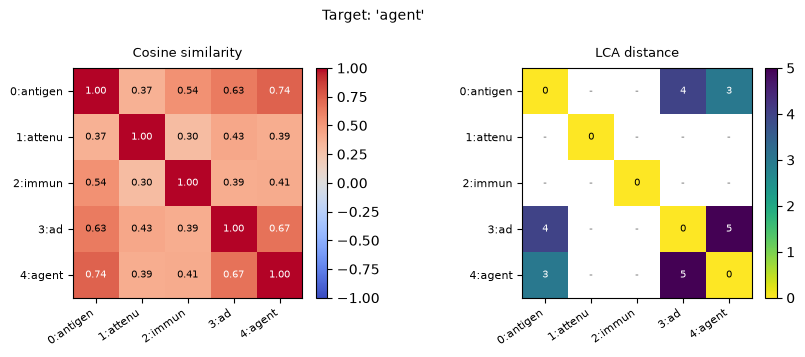


Context: 'A vaccine typically contains an agent that' | Target: 'resembles'
Top-5          |    0:resembles |      1:closely |          2:mim |   3:stimulates |       4:either
---------------------------------------------------------------------------------------------------
0:resembles    |         1.0000 |         0.8938 |         0.4232 |         0.5939 |         0.3887
1:closely      |         0.8938 |         1.0000 |         0.4613 |         0.5409 |         0.3907
2:mim          |         0.4232 |         0.4613 |         1.0000 |         0.3860 |         0.3579
3:stimulates   |         0.5939 |         0.5409 |         0.3860 |         1.0000 |         0.3337
4:either       |         0.3887 |         0.3907 |         0.3579 |         0.3337 |         1.0000


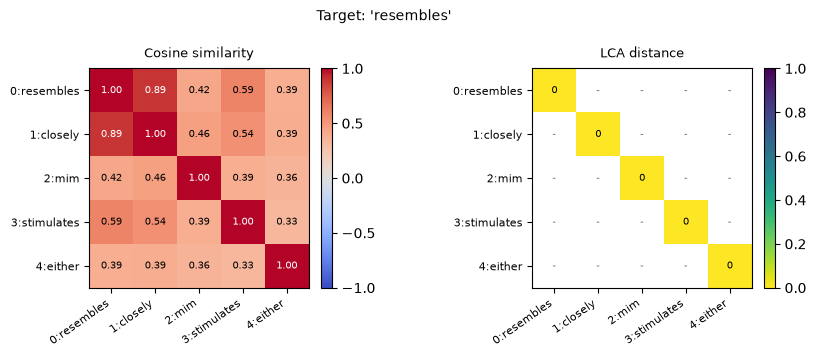


Context: 'A vaccine typically contains an agent that resembles a' | Target: 'disease-causing'
Top-5          |      0:disease |         1:path |        2:virus |   3:particular |         4:dise
---------------------------------------------------------------------------------------------------
0:disease      |         1.0000 |         0.5924 |         0.8103 |         0.6773 |         0.5975
1:path         |         0.5924 |         1.0000 |         0.6523 |         0.7301 |         0.6433
2:virus        |         0.8103 |         0.6523 |         1.0000 |         0.7331 |         0.6514
3:particular   |         0.6773 |         0.7301 |         0.7331 |         1.0000 |         0.6412
4:dise         |         0.5975 |         0.6433 |         0.6514 |         0.6412 |         1.0000


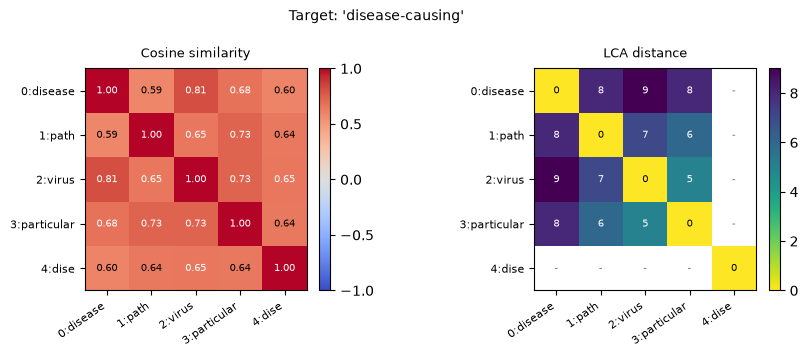


Context: 'A vaccine typically contains an agent that resembles a disease-causing' | Target: 'microorganism'
Top-5        |   0:organism |      1:agent |       2:path |      3:virus |       4:germ
---------------------------------------------------------------------------------------
0:organism   |       1.0000 |       0.8005 |       0.6907 |       0.7867 |       0.5303
1:agent      |       0.8005 |       1.0000 |       0.6837 |       0.7276 |       0.4501
2:path       |       0.6907 |       0.6837 |       1.0000 |       0.6523 |       0.4682
3:virus      |       0.7867 |       0.7276 |       0.6523 |       1.0000 |       0.5790
4:germ       |       0.5303 |       0.4501 |       0.4682 |       0.5790 |       1.0000


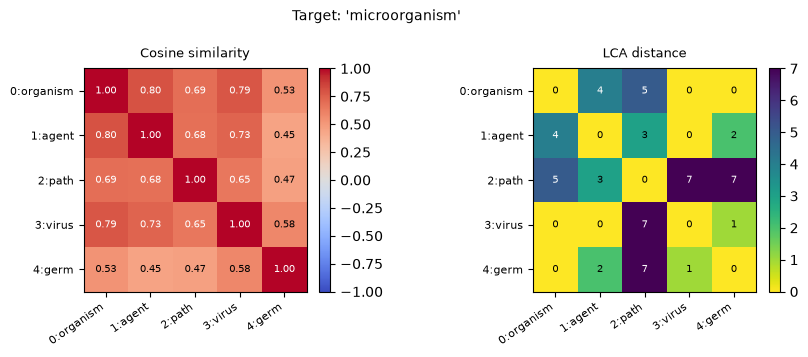


Context: 'A vaccine typically contains an agent that resembles a disease-causing microorganism and is' | Target: 'often'
Top-5         |       0:often |     1:usually |        2:inoc |   3:generally |      4:called
---------------------------------------------------------------------------------------------
0:often       |        1.0000 |        0.8782 |        0.5600 |        0.8079 |        0.6387
1:usually     |        0.8782 |        1.0000 |        0.5179 |        0.8288 |        0.6643
2:inoc        |        0.5600 |        0.5179 |        1.0000 |        0.5229 |        0.4919
3:generally   |        0.8079 |        0.8288 |        0.5229 |        1.0000 |        0.5705
4:called      |        0.6387 |        0.6643 |        0.4919 |        0.5705 |        1.0000


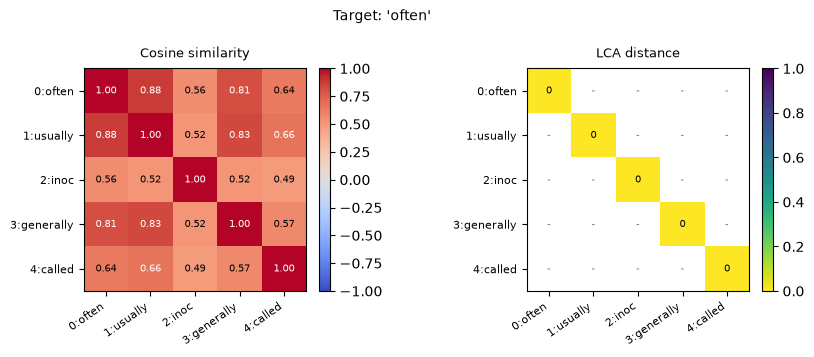


Context: 'A vaccine typically contains an agent that resembles a disease-causing microorganism and is often made from weakened or' | Target: 'killed'
Top-5        |    0:killed |      1:dead |        2:杀死 |   3:killing |     4:kills
----------------------------------------------------------------------------------
0:killed     |      1.0000 |      0.7301 |      0.5227 |      0.7424 |      0.7941
1:dead       |      0.7301 |      1.0000 |      0.4524 |      0.6254 |      0.6478
2:杀死         |      0.5227 |      0.4524 |      1.0000 |      0.5878 |      0.5177
3:killing    |      0.7424 |      0.6254 |      0.5878 |      1.0000 |      0.7835
4:kills      |      0.7941 |      0.6478 |      0.5177 |      0.7835 |      1.0000


/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 26432 (\N{CJK UNIFIED IDEOGRAPH-6740}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 27515 (\N{CJK UNIFIED IDEOGRAPH-6B7B}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 26432 (\N{CJK UNIFIED IDEOGRAPH-6740}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 27515 (\N{CJK UNIFIED IDEOGRAPH-6B7B}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


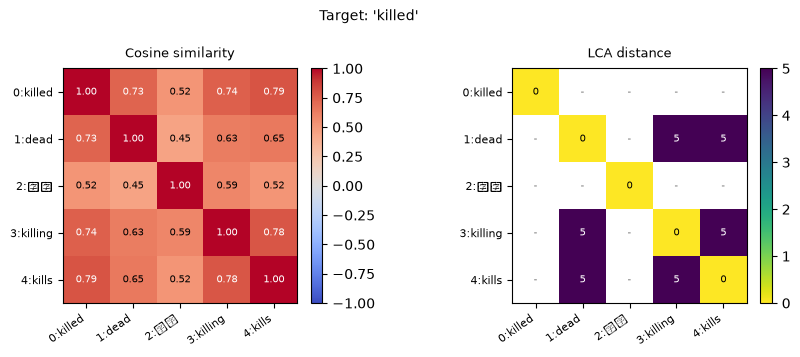


Context: 'A vaccine typically contains an agent that resembles a disease-causing microorganism and is often made from weakened or killed' | Target: 'forms'
Top-5         |       0:forms |        1:form |   2:pathogens |    3:versions |    4:microbes
---------------------------------------------------------------------------------------------
0:forms       |        1.0000 |        0.8676 |        0.3527 |        0.6396 |        0.3169
1:form        |        0.8676 |        1.0000 |        0.3185 |        0.5648 |        0.2519
2:pathogens   |        0.3527 |        0.3185 |        1.0000 |        0.4171 |        0.6286
3:versions    |        0.6396 |        0.5648 |        0.4171 |        1.0000 |        0.2650
4:microbes    |        0.3169 |        0.2519 |        0.6286 |        0.2650 |        1.0000


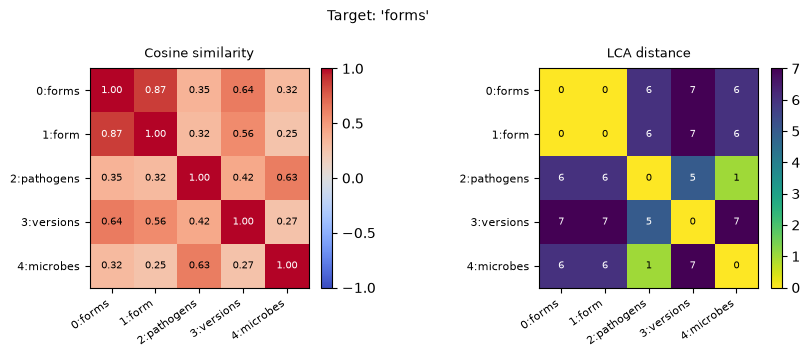


Context: 'A vaccine typically contains an agent that resembles a disease-causing microorganism and is often made from weakened or killed forms of the' | Target: 'microbe,'
Top-5        |     0:virus |      1:path |      2:germ |   3:disease |     4:agent
----------------------------------------------------------------------------------
0:virus      |      1.0000 |      0.6523 |      0.5790 |      0.8103 |      0.7276
1:path       |      0.6523 |      1.0000 |      0.4682 |      0.5924 |      0.6837
2:germ       |      0.5790 |      0.4682 |      1.0000 |      0.5877 |      0.4501
3:disease    |      0.8103 |      0.5924 |      0.5877 |      1.0000 |      0.6213
4:agent      |      0.7276 |      0.6837 |      0.4501 |      0.6213 |      1.0000


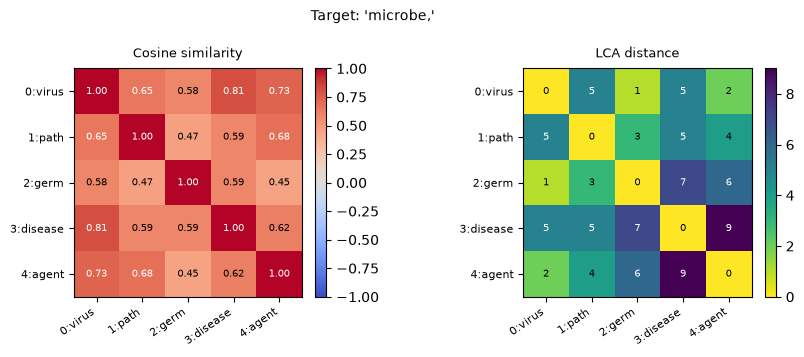


Context: 'A vaccine typically contains an agent that resembles a disease-causing microorganism and is often made from weakened or killed forms of the microbe, its' | Target: 'toxins,'
Top-5          |       0:toxins |     1:proteins |           2:毒素 |        3:toxin |   4:components
---------------------------------------------------------------------------------------------------
0:toxins       |         1.0000 |         0.5973 |         0.3419 |         0.5980 |         0.5709
1:proteins     |         0.5973 |         1.0000 |         0.4786 |         0.7432 |         0.6785
2:毒素           |         0.3419 |         0.4786 |         1.0000 |         0.5299 |         0.4151
3:toxin        |         0.5980 |         0.7432 |         0.5299 |         1.0000 |         0.6622
4:components   |         0.5709 |         0.6785 |         0.4151 |         0.6622 |         1.0000


/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 27602 (\N{CJK UNIFIED IDEOGRAPH-6BD2}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 32032 (\N{CJK UNIFIED IDEOGRAPH-7D20}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 27602 (\N{CJK UNIFIED IDEOGRAPH-6BD2}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 32032 (\N{CJK UNIFIED IDEOGRAPH-7D20}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


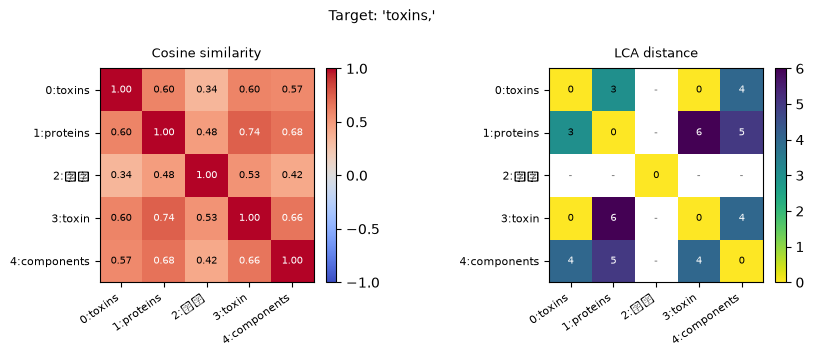


Context: 'A vaccine typically contains an agent that resembles a disease-causing microorganism and is often made from weakened or killed forms of the microbe, its toxins, or one of its' | Target: 'surface'
Top-5          |      0:surface |     1:surfaces |   2:components |     3:proteins |           4:表面
---------------------------------------------------------------------------------------------------
0:surface      |         1.0000 |         0.5972 |         0.5764 |         0.5572 |         0.5150
1:surfaces     |         0.5972 |         1.0000 |         0.5620 |         0.4937 |         0.3518
2:components   |         0.5764 |         0.5620 |         1.0000 |         0.6785 |         0.4792
3:proteins     |         0.5572 |         0.4937 |         0.6785 |         1.0000 |         0.5185
4:表面           |         0.5150 |         0.3518 |         0.4792 |         0.5185 |         1.0000


/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 34920 (\N{CJK UNIFIED IDEOGRAPH-8868}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 38754 (\N{CJK UNIFIED IDEOGRAPH-9762}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 34920 (\N{CJK UNIFIED IDEOGRAPH-8868}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 38754 (\N{CJK UNIFIED IDEOGRAPH-9762}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


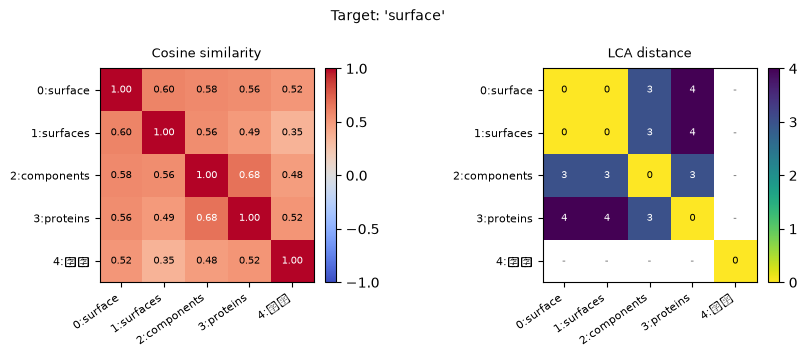


Context: 'A vaccine typically contains an agent that resembles a disease-causing microorganism and is often made from weakened or killed forms of the microbe, its toxins, or one of its surface' | Target: 'proteins.'
Top-5               |          0:proteins |        1:components |        2:properties |          3:elements |   4:characteristics
---------------------------------------------------------------------------------------------------------------------------------
0:proteins          |              1.0000 |              0.6785 |              0.7135 |              0.6587 |              0.6245
1:components        |              0.6785 |              1.0000 |              0.7916 |              0.7639 |              0.7365
2:properties        |              0.7135 |              0.7916 |              1.0000 |              0.7856 |              0.7219
3:elements          |              0.6587 |              0.7639 |              0.7856 |              1.0000 |              0.6140
4:c

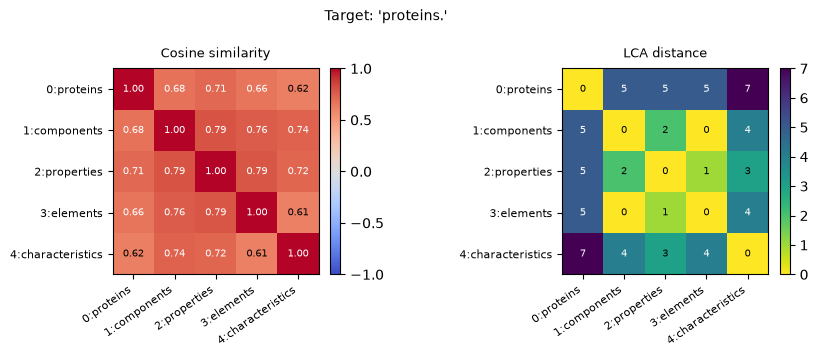


Context: 'The' | Target: 'agent'
Top-5         |   0:following |         1:sum |      2:purple |    3:function |      4:number
---------------------------------------------------------------------------------------------
0:following   |        1.0000 |        0.5209 |        0.5680 |        0.4828 |        0.5987
1:sum         |        0.5209 |        1.0000 |        0.5980 |        0.6384 |        0.6528
2:purple      |        0.5680 |        0.5980 |        1.0000 |        0.5516 |        0.7352
3:function    |        0.4828 |        0.6384 |        0.5516 |        1.0000 |        0.6338
4:number      |        0.5987 |        0.6528 |        0.7352 |        0.6338 |        1.0000


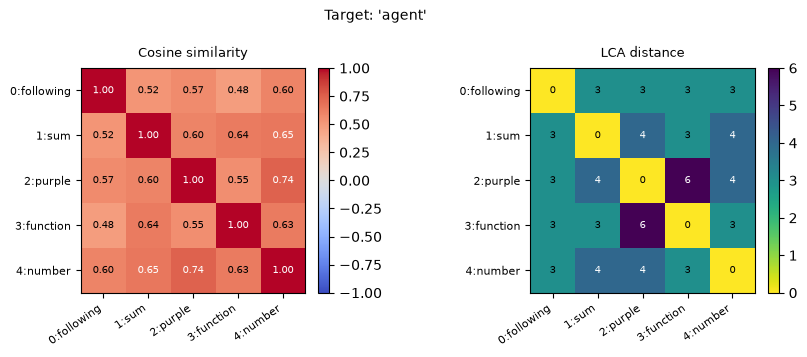


Context: 'The agent' | Target: 'stimulates'
Top-5        |    0:whose |    1:works |    2:needs |    3:wants |    4:takes
-----------------------------------------------------------------------------
0:whose      |     1.0000 |     0.5000 |     0.7208 |     0.7592 |     0.6489
1:works      |     0.5000 |     1.0000 |     0.5613 |     0.5548 |     0.5172
2:needs      |     0.7208 |     0.5613 |     1.0000 |     0.8938 |     0.6800
3:wants      |     0.7592 |     0.5548 |     0.8938 |     1.0000 |     0.6845
4:takes      |     0.6489 |     0.5172 |     0.6800 |     0.6845 |     1.0000


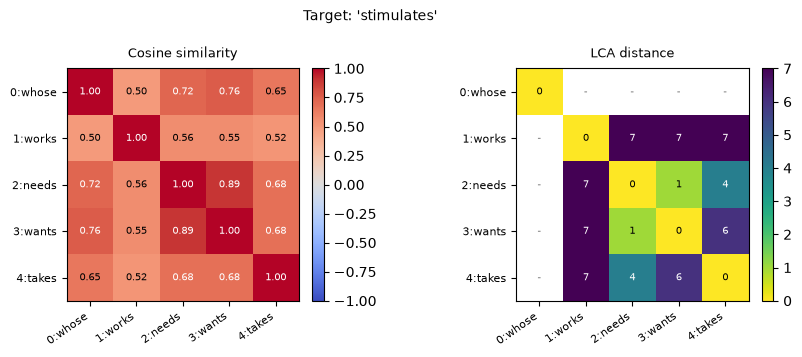


Context: 'The agent stimulates the' | Target: 'immune'
Top-5          |   0:production |      1:release |    2:secretion |         3:body |       4:immune
---------------------------------------------------------------------------------------------------
0:production   |         1.0000 |         0.5588 |         0.4742 |         0.4985 |         0.4852
1:release      |         0.5588 |         1.0000 |         0.4873 |         0.6084 |         0.6841
2:secretion    |         0.4742 |         0.4873 |         1.0000 |         0.5667 |         0.5329
3:body         |         0.4985 |         0.6084 |         0.5667 |         1.0000 |         0.7067
4:immune       |         0.4852 |         0.6841 |         0.5329 |         0.7067 |         1.0000


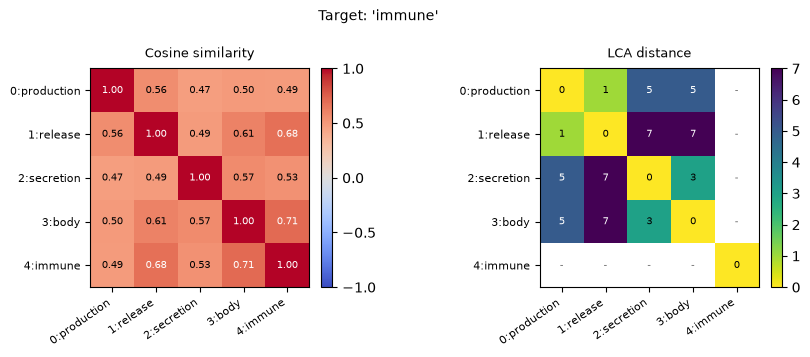


Context: 'The agent stimulates the immune' | Target: 'system'
Top-5        |     0:system |   1:response |      2:cells |    3:defense |   4:function
---------------------------------------------------------------------------------------
0:system     |       1.0000 |       0.7347 |       0.6488 |       0.6273 |       0.5824
1:response   |       0.7347 |       1.0000 |       0.6669 |       0.6830 |       0.6206
2:cells      |       0.6488 |       0.6669 |       1.0000 |       0.5166 |       0.6042
3:defense    |       0.6273 |       0.6830 |       0.5166 |       1.0000 |       0.4642
4:function   |       0.5824 |       0.6206 |       0.6042 |       0.4642 |       1.0000


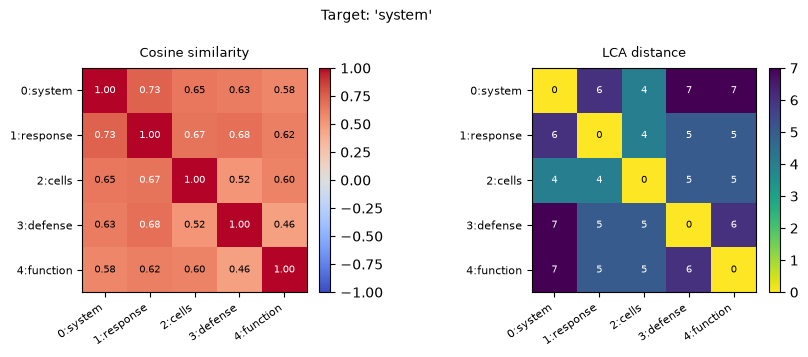


Context: 'The agent stimulates the immune system to' | Target: 'recognize'
Top-5        |   0:produce |     1:fight |      2:help |    3:attack |   4:protect
----------------------------------------------------------------------------------
0:produce    |      1.0000 |      0.6380 |      0.6546 |      0.7076 |      0.6679
1:fight      |      0.6380 |      1.0000 |      0.6754 |      0.7396 |      0.6510
2:help       |      0.6546 |      0.6754 |      1.0000 |      0.7634 |      0.8043
3:attack     |      0.7076 |      0.7396 |      0.7634 |      1.0000 |      0.7415
4:protect    |      0.6679 |      0.6510 |      0.8043 |      0.7415 |      1.0000


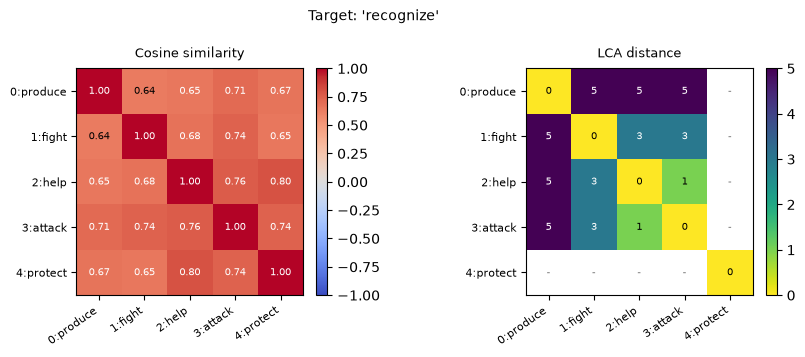


Context: 'The agent stimulates the immune system to recognize the' | Target: 'agent'
Top-5        |     0:cancer |      1:virus |      2:tumor |    3:antigen |   4:bacteria
---------------------------------------------------------------------------------------
0:cancer     |       1.0000 |       0.5495 |       0.5151 |       0.4409 |       0.5854
1:virus      |       0.5495 |       1.0000 |       0.7966 |       0.7971 |       0.7673
2:tumor      |       0.5151 |       0.7966 |       1.0000 |       0.8030 |       0.7292
3:antigen    |       0.4409 |       0.7971 |       0.8030 |       1.0000 |       0.7128
4:bacteria   |       0.5854 |       0.7673 |       0.7292 |       0.7128 |       1.0000


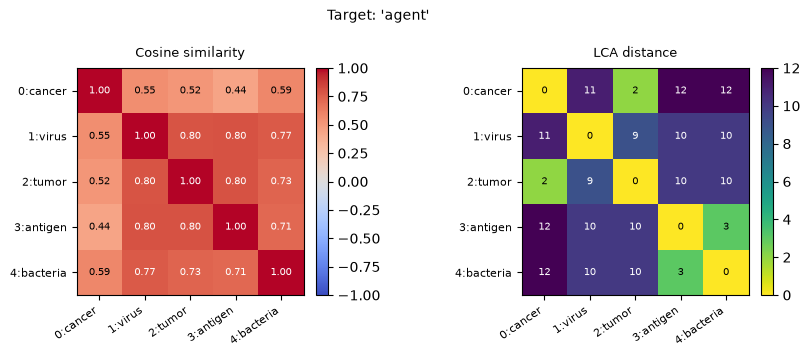


Context: 'The agent stimulates the immune system to recognize the agent as a' | Target: 'threat,'
Top-5        |     0:path |   1:threat |      2:non |   3:target |    4:virus
-----------------------------------------------------------------------------
0:path       |     1.0000 |     0.7391 |     0.6173 |     0.5846 |     0.6523
1:threat     |     0.7391 |     1.0000 |     0.6467 |     0.6743 |     0.7738
2:non        |     0.6173 |     0.6467 |     1.0000 |     0.6289 |     0.6863
3:target     |     0.5846 |     0.6743 |     0.6289 |     1.0000 |     0.6518
4:virus      |     0.6523 |     0.7738 |     0.6863 |     0.6518 |     1.0000


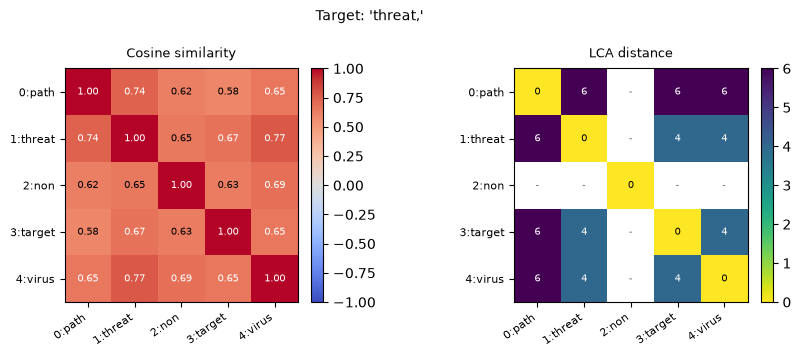


Context: 'The agent stimulates the immune system to recognize the agent as a threat,' | Target: 'destroy'
Top-5         |   0:producing |     1:leading |   2:resulting |    3:creating |     4:thereby
---------------------------------------------------------------------------------------------
0:producing   |        1.0000 |        0.7918 |        0.6756 |        0.8307 |        0.4842
1:leading     |        0.7918 |        1.0000 |        0.6779 |        0.7585 |        0.4847
2:resulting   |        0.6756 |        0.6779 |        1.0000 |        0.6597 |        0.6056
3:creating    |        0.8307 |        0.7585 |        0.6597 |        1.0000 |        0.4908
4:thereby     |        0.4842 |        0.4847 |        0.6056 |        0.4908 |        1.0000


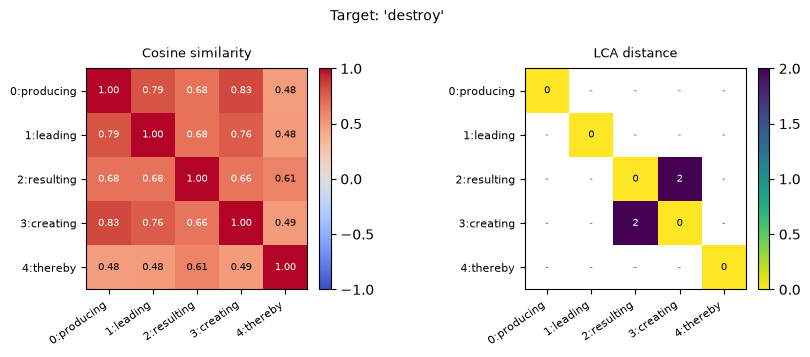


Context: 'The agent stimulates the immune system to recognize the agent as a threat, destroy it, and' | Target: 'recognize'
Top-5        |   0:remember |       1:save |    2:prevent |      3:store |     4:create
---------------------------------------------------------------------------------------
0:remember   |       1.0000 |       0.5661 |       0.6145 |       0.5523 |       0.5509
1:save       |       0.5661 |       1.0000 |       0.7912 |       0.7848 |       0.7632
2:prevent    |       0.6145 |       0.7912 |       1.0000 |       0.8008 |       0.7113
3:store      |       0.5523 |       0.7848 |       0.8008 |       1.0000 |       0.6905
4:create     |       0.5509 |       0.7632 |       0.7113 |       0.6905 |       1.0000


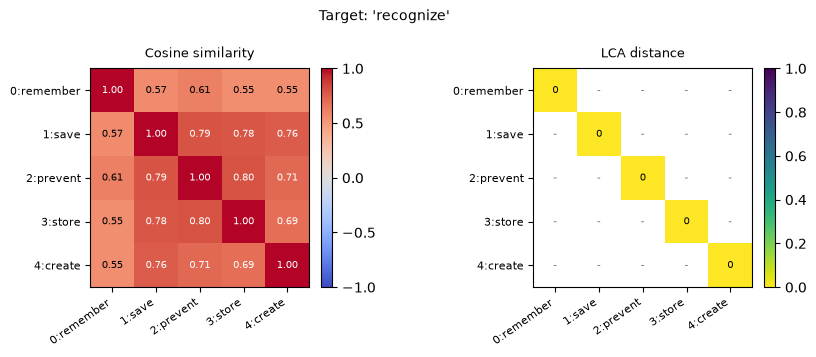


Context: 'The agent stimulates the immune system to recognize the agent as a threat, destroy it, and recognize further and' | Target: 'destroy'
Top-5        |     0:faster |     1:better |     2:future |    3:prevent |   4:specific
---------------------------------------------------------------------------------------
0:faster     |       1.0000 |       0.6432 |       0.5508 |       0.6782 |       0.5941
1:better     |       0.6432 |       1.0000 |       0.5105 |       0.6007 |       0.6174
2:future     |       0.5508 |       0.5105 |       1.0000 |       0.5805 |       0.6098
3:prevent    |       0.6782 |       0.6007 |       0.5805 |       1.0000 |       0.8144
4:specific   |       0.5941 |       0.6174 |       0.6098 |       0.8144 |       1.0000


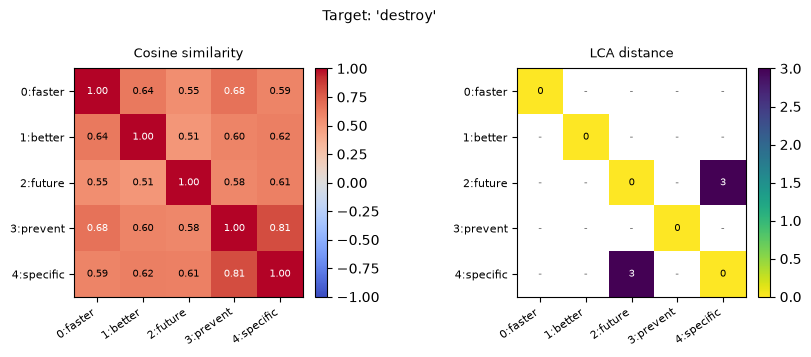


Context: 'The agent stimulates the immune system to recognize the agent as a threat, destroy it, and recognize further and destroy any of the' | Target: 'microorganisms'
Top-5          |        0:agent |       1:agents |         2:body |   3:associated |     4:organism
---------------------------------------------------------------------------------------------------
0:agent        |         1.0000 |         0.9455 |         0.7095 |         0.6855 |         0.8005
1:agents       |         0.9455 |         1.0000 |         0.7234 |         0.7225 |         0.8240
2:body         |         0.7095 |         0.7234 |         1.0000 |         0.5969 |         0.6868
3:associated   |         0.6855 |         0.7225 |         0.5969 |         1.0000 |         0.8211
4:organism     |         0.8005 |         0.8240 |         0.6868 |         0.8211 |         1.0000


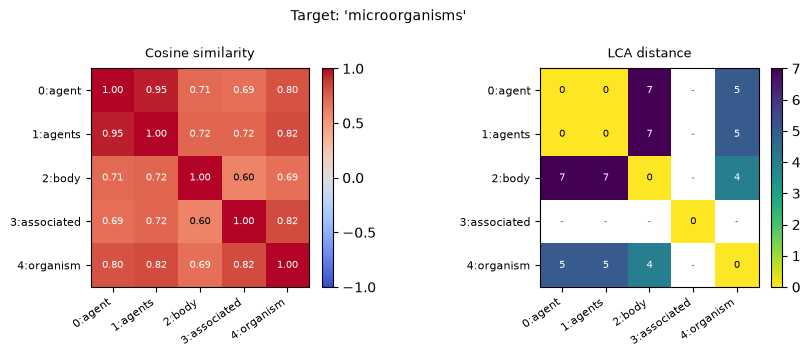


Context: 'The agent stimulates the immune system to recognize the agent as a threat, destroy it, and recognize further and destroy any of the microorganisms' | Target: 'associated'
Top-5          |   0:associated |        1:using |   2:containing |    3:utilizing |      4:present
---------------------------------------------------------------------------------------------------
0:associated   |         1.0000 |         0.6157 |         0.7542 |         0.7490 |         0.4606
1:using        |         0.6157 |         1.0000 |         0.7339 |         0.8079 |         0.4042
2:containing   |         0.7542 |         0.7339 |         1.0000 |         0.8158 |         0.4202
3:utilizing    |         0.7490 |         0.8079 |         0.8158 |         1.0000 |         0.4437
4:present      |         0.4606 |         0.4042 |         0.4202 |         0.4437 |         1.0000


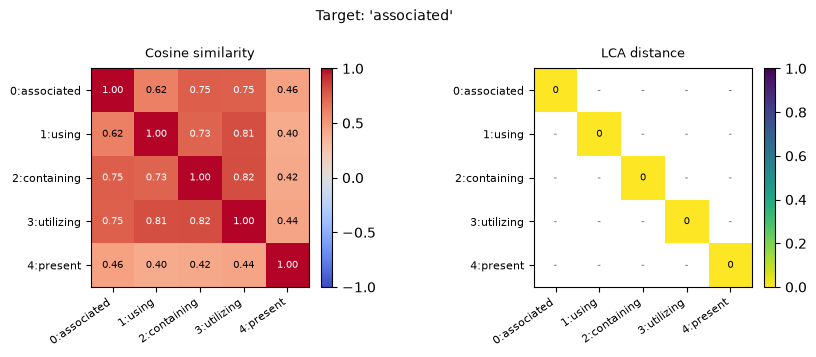


Context: 'The agent stimulates the immune system to recognize the agent as a threat, destroy it, and recognize further and destroy any of the microorganisms associated with that' | Target: 'agent'
Top-5          |        0:agent |     1:specific |   2:particular |      3:antigen |      4:disease
---------------------------------------------------------------------------------------------------
0:agent        |         1.0000 |         0.7699 |         0.7967 |         0.7386 |         0.6213
1:specific     |         0.7699 |         1.0000 |         0.9118 |         0.7783 |         0.7528
2:particular   |         0.7967 |         0.9118 |         1.0000 |         0.7140 |         0.6773
3:antigen      |         0.7386 |         0.7783 |         0.7140 |         1.0000 |         0.7615
4:disease      |         0.6213 |         0.7528 |         0.6773 |         0.7615 |         1.0000


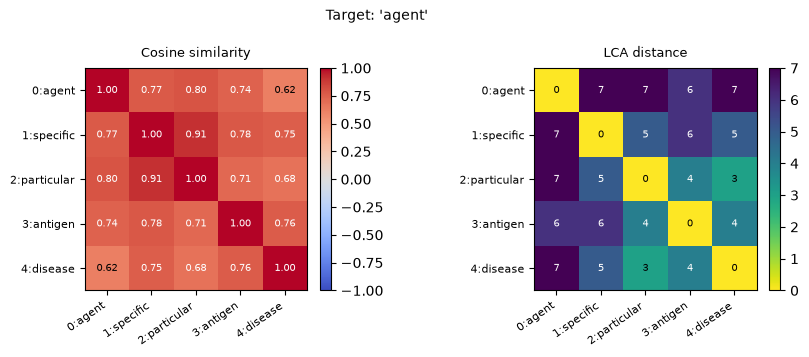


Context: 'The agent stimulates the immune system to recognize the agent as a threat, destroy it, and recognize further and destroy any of the microorganisms associated with that agent that it may' | Target: 'encounter'
Top-5         |   0:encounter |        1:come |        2:meet |        3:find |         4:see
---------------------------------------------------------------------------------------------
0:encounter   |        1.0000 |        0.5887 |        0.7174 |        0.6271 |        0.6041
1:come        |        0.5887 |        1.0000 |        0.7232 |        0.6746 |        0.6302
2:meet        |        0.7174 |        0.7232 |        1.0000 |        0.7130 |        0.6759
3:find        |        0.6271 |        0.6746 |        0.7130 |        1.0000 |        0.6650
4:see         |        0.6041 |        0.6302 |        0.6759 |        0.6650 |        1.0000


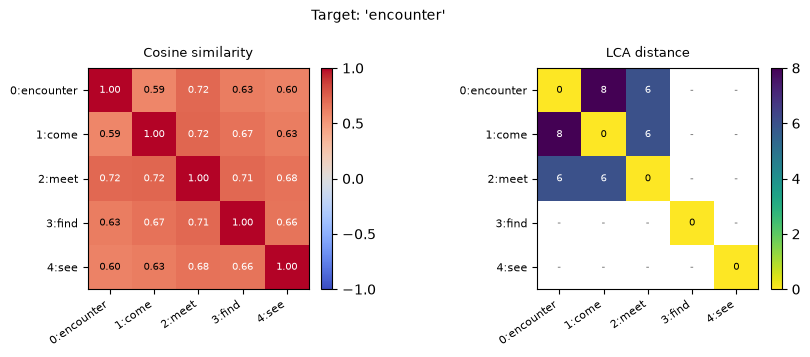


Context: 'The agent stimulates the immune system to recognize the agent as a threat, destroy it, and recognize further and destroy any of the microorganisms associated with that agent that it may encounter in the' | Target: 'future.'
Top-5        |   0:future |     1:body |     2:near |       3:今后 |   4:coming
-----------------------------------------------------------------------------
0:future     |     1.0000 |     0.5699 |     0.6598 |     0.4452 |     0.6210
1:body       |     0.5699 |     1.0000 |     0.6197 |     0.4997 |     0.6458
2:near       |     0.6598 |     0.6197 |     1.0000 |     0.5413 |     0.7042
3:今后         |     0.4452 |     0.4997 |     0.5413 |     1.0000 |     0.5541
4:coming     |     0.6210 |     0.6458 |     0.7042 |     0.5541 |     1.0000


/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 20170 (\N{CJK UNIFIED IDEOGRAPH-4ECA}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 21518 (\N{CJK UNIFIED IDEOGRAPH-540E}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 20170 (\N{CJK UNIFIED IDEOGRAPH-4ECA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 21518 (\N{CJK UNIFIED IDEOGRAPH-540E}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


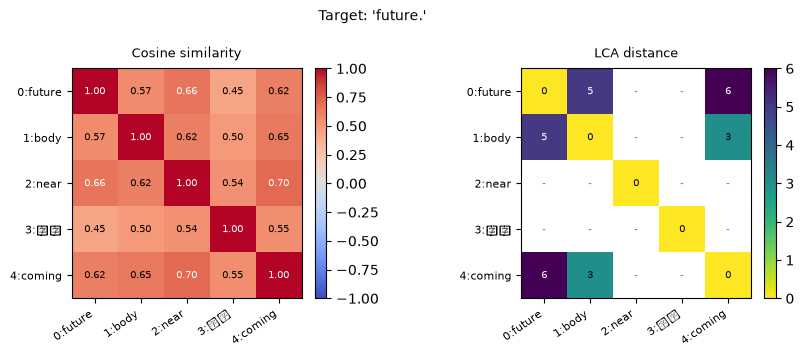


Context: 'Vaccines can be' | Target: 'prophylactic'
Top-5            |   0:administered |     1:classified |         2:stored |       3:produced |        4:broadly
---------------------------------------------------------------------------------------------------------------
0:administered   |           1.0000 |           0.7597 |           0.7637 |           0.6225 |           0.8199
1:classified     |           0.7597 |           1.0000 |           0.6925 |           0.5287 |           0.7147
2:stored         |           0.7637 |           0.6925 |           1.0000 |           0.6436 |           0.6989
3:produced       |           0.6225 |           0.5287 |           0.6436 |           1.0000 |           0.5232
4:broadly        |           0.8199 |           0.7147 |           0.6989 |           0.5232 |           1.0000


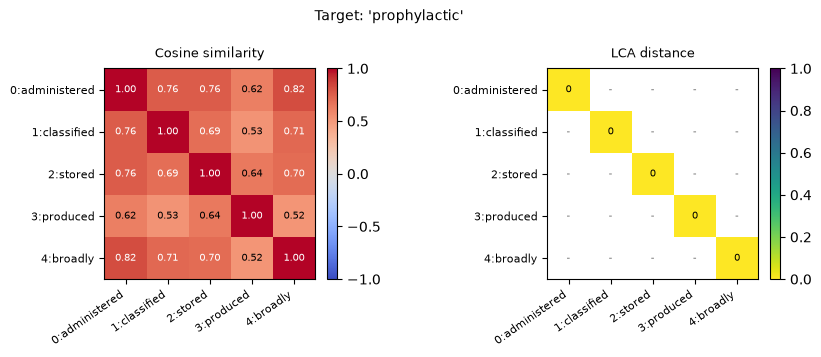


Context: 'Vaccines can be prophylactic (to' | Target: 'prevent'
Top-5        |   0:prevent |   1:protect |      2:stop |      3:help |     4:avoid
----------------------------------------------------------------------------------
0:prevent    |      1.0000 |      0.7785 |      0.7712 |      0.7570 |      0.9111
1:protect    |      0.7785 |      1.0000 |      0.7541 |      0.8043 |      0.7892
2:stop       |      0.7712 |      0.7541 |      1.0000 |      0.7805 |      0.7661
3:help       |      0.7570 |      0.8043 |      0.7805 |      1.0000 |      0.7817
4:avoid      |      0.9111 |      0.7892 |      0.7661 |      0.7817 |      1.0000


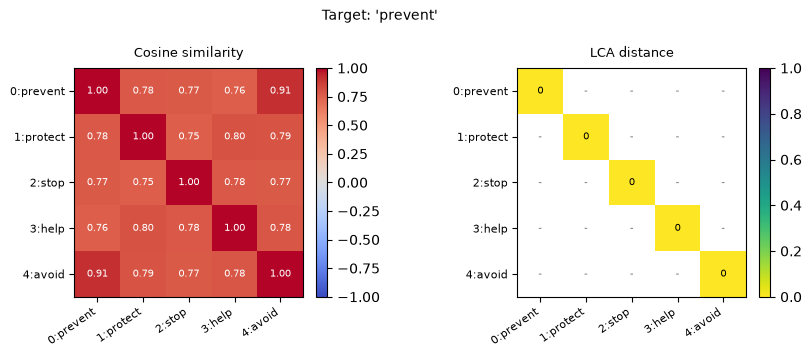


Context: 'Vaccines can be prophylactic (to prevent or' | Target: 'alleviate'
Top-5          |       0:resist |      1:protect |       2:combat |   3:anticipate |        4:immun
---------------------------------------------------------------------------------------------------
0:resist       |         1.0000 |         0.7744 |         0.7405 |         0.4022 |         0.4052
1:protect      |         0.7744 |         1.0000 |         0.6379 |         0.4138 |         0.4698
2:combat       |         0.7405 |         0.6379 |         1.0000 |         0.3571 |         0.4490
3:anticipate   |         0.4022 |         0.4138 |         0.3571 |         1.0000 |         0.3255
4:immun        |         0.4052 |         0.4698 |         0.4490 |         0.3255 |         1.0000


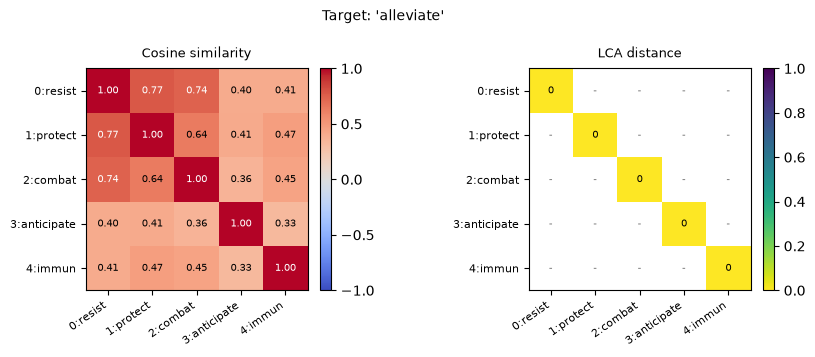


Context: 'Vaccines can be prophylactic (to prevent or alleviate the' | Target: 'effects'
Top-5            |        0:effects |         1:effect |       2:outcomes |   3:consequences |        4:results
---------------------------------------------------------------------------------------------------------------
0:effects        |           1.0000 |           0.7175 |           0.7051 |           0.7183 |           0.3572
1:effect         |           0.7175 |           1.0000 |           0.6045 |           0.7516 |           0.2778
2:outcomes       |           0.7051 |           0.6045 |           1.0000 |           0.7408 |           0.3427
3:consequences   |           0.7183 |           0.7516 |           0.7408 |           1.0000 |           0.3313
4:results        |           0.3572 |           0.2778 |           0.3427 |           0.3313 |           1.0000


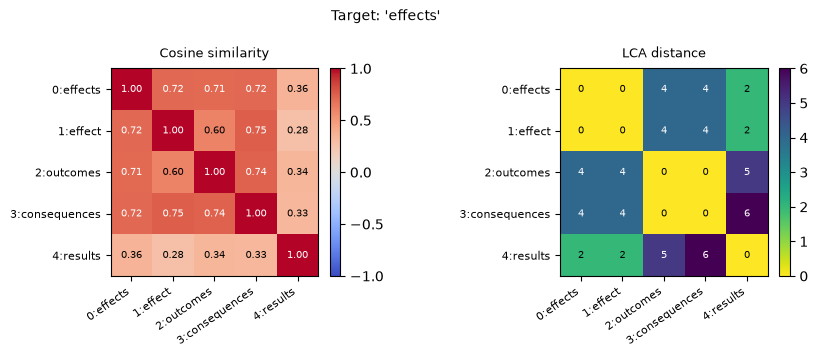


Context: 'Vaccines can be prophylactic (to prevent or alleviate the effects of a' | Target: 'future'
Top-5         |      0:future |     1:disease |   2:potential |        3:path |   4:condition
---------------------------------------------------------------------------------------------
0:future      |        1.0000 |        0.5895 |        0.5244 |        0.5590 |        0.5387
1:disease     |        0.5895 |        1.0000 |        0.4976 |        0.5924 |        0.6910
2:potential   |        0.5244 |        0.4976 |        1.0000 |        0.4220 |        0.4842
3:path        |        0.5590 |        0.5924 |        0.4220 |        1.0000 |        0.6179
4:condition   |        0.5387 |        0.6910 |        0.4842 |        0.6179 |        1.0000


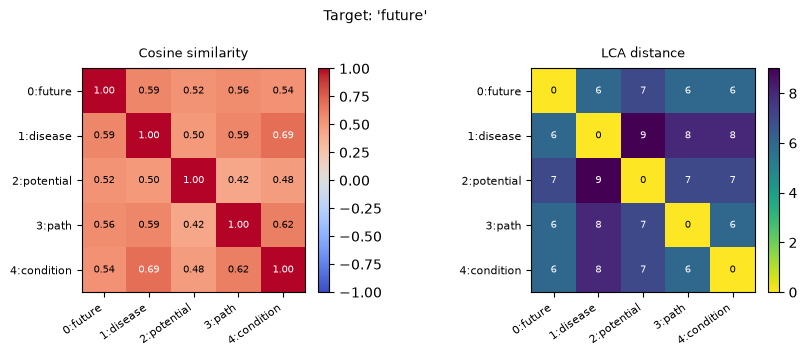


Context: 'Vaccines can be prophylactic (to prevent or alleviate the effects of a future' | Target: 'infection'
Top-5         |     0:illness |   1:infection |   2:potential |        3:path |     4:disease
---------------------------------------------------------------------------------------------
0:illness     |        1.0000 |        0.7795 |        0.4646 |        0.5756 |        0.8748
1:infection   |        0.7795 |        1.0000 |        0.5077 |        0.6306 |        0.8783
2:potential   |        0.4646 |        0.5077 |        1.0000 |        0.4220 |        0.4976
3:path        |        0.5756 |        0.6306 |        0.4220 |        1.0000 |        0.5924
4:disease     |        0.8748 |        0.8783 |        0.4976 |        0.5924 |        1.0000


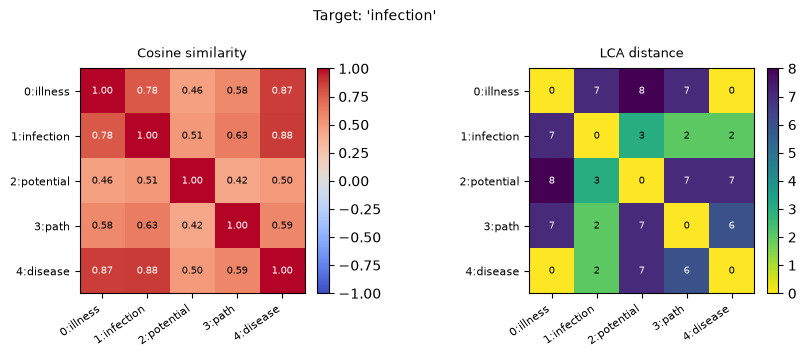


Context: 'Vaccines can be prophylactic (to prevent or alleviate the effects of a future infection by a' | Target: 'natural'
Top-5         |        0:path |     1:natural |   2:naturally |       3:virus |   4:pathogens
---------------------------------------------------------------------------------------------
0:path        |        1.0000 |        0.6624 |        0.7027 |        0.6523 |        0.3445
1:natural     |        0.6624 |        1.0000 |        0.7969 |        0.7019 |        0.4011
2:naturally   |        0.7027 |        0.7969 |        1.0000 |        0.7476 |        0.3540
3:virus       |        0.6523 |        0.7019 |        0.7476 |        1.0000 |        0.5092
4:pathogens   |        0.3445 |        0.4011 |        0.3540 |        0.5092 |        1.0000


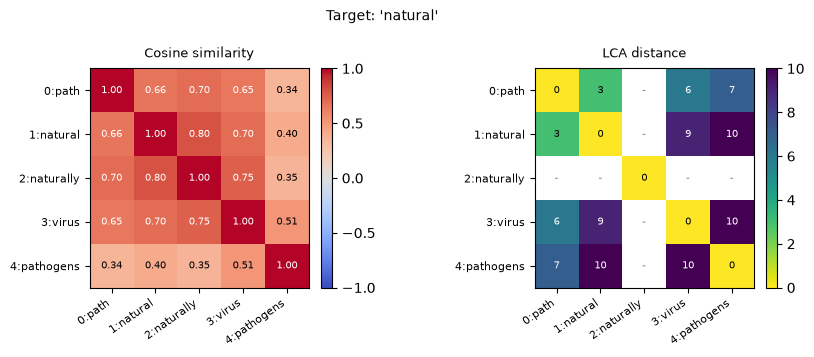


Context: 'Vaccines can be prophylactic (to prevent or alleviate the effects of a future infection by a natural or' | Target: '"wild"'
Top-5        |      0:wild |         1:病 |      2:path |   3:disease |      4:live
----------------------------------------------------------------------------------
0:wild       |      1.0000 |      0.6057 |      0.6129 |      0.6490 |      0.6381
1:病          |      0.6057 |      1.0000 |      0.5542 |      0.5497 |      0.5025
2:path       |      0.6129 |      0.5542 |      1.0000 |      0.5924 |      0.5079
3:disease    |      0.6490 |      0.5497 |      0.5924 |      1.0000 |      0.5671
4:live       |      0.6381 |      0.5025 |      0.5079 |      0.5671 |      1.0000


/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 30149 (\N{CJK UNIFIED IDEOGRAPH-75C5}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 30149 (\N{CJK UNIFIED IDEOGRAPH-75C5}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


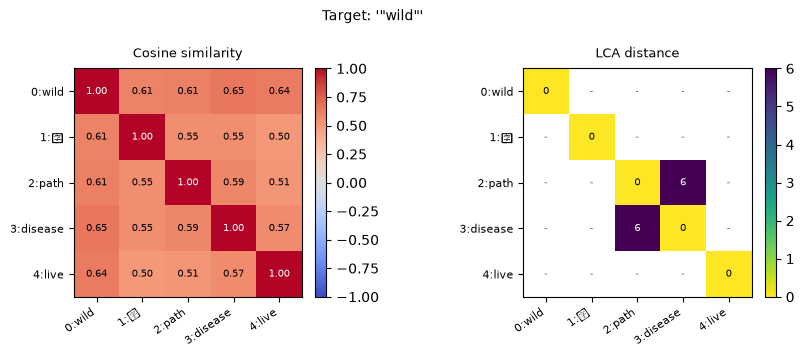


Context: 'Vaccines can be prophylactic (to prevent or alleviate the effects of a future infection by a natural or "wild"' | Target: 'pathogen),'
Top-5         |        0:path |       1:virus |   2:pathogens |    3:organism |      4:strain
---------------------------------------------------------------------------------------------
0:path        |        1.0000 |        0.6523 |        0.3445 |        0.6907 |        0.6431
1:virus       |        0.6523 |        1.0000 |        0.5092 |        0.7867 |        0.7407
2:pathogens   |        0.3445 |        0.5092 |        1.0000 |        0.3834 |        0.3878
3:organism    |        0.6907 |        0.7867 |        0.3834 |        1.0000 |        0.8222
4:strain      |        0.6431 |        0.7407 |        0.3878 |        0.8222 |        1.0000


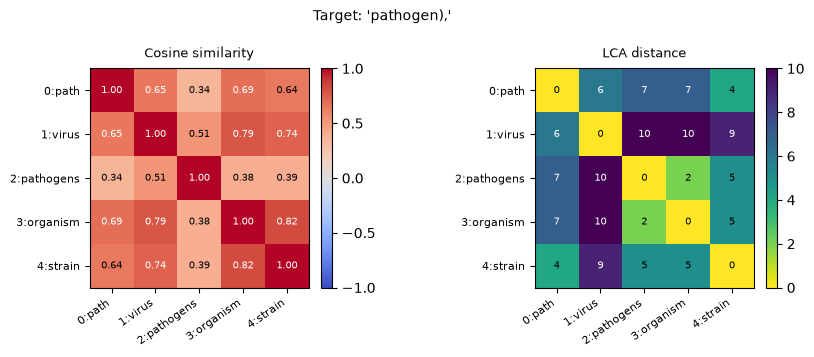


Context: 'Vaccines can be prophylactic (to prevent or alleviate the effects of a future infection by a natural or "wild" pathogen), or' | Target: 'therapeutic'
Top-5           |   0:therapeutic |          1:ther |       2:therapy |         3:proph |     4:treatment
---------------------------------------------------------------------------------------------------------
0:therapeutic   |          1.0000 |          0.6118 |          0.8194 |          0.4759 |          0.7557
1:ther          |          0.6118 |          1.0000 |          0.5634 |          0.5678 |          0.5168
2:therapy       |          0.8194 |          0.5634 |          1.0000 |          0.4621 |          0.7369
3:proph         |          0.4759 |          0.5678 |          0.4621 |          1.0000 |          0.4245
4:treatment     |          0.7557 |          0.5168 |          0.7369 |          0.4245 |          1.0000


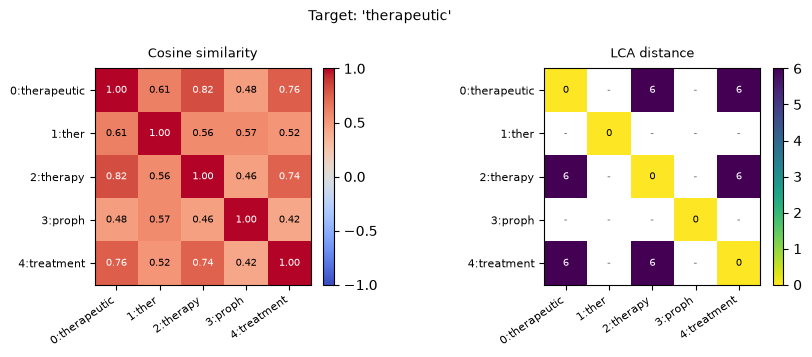


Context: 'Vaccines can be prophylactic (to prevent or alleviate the effects of a future infection by a natural or "wild" pathogen), or therapeutic (to' | Target: 'fight'
Top-5        |    0:treat |     1:cure |   2:combat |    3:fight |     4:kill
-----------------------------------------------------------------------------
0:treat      |     1.0000 |     0.8451 |     0.6810 |     0.7368 |     0.8077
1:cure       |     0.8451 |     1.0000 |     0.8004 |     0.7192 |     0.7344
2:combat     |     0.6810 |     0.8004 |     1.0000 |     0.6914 |     0.6436
3:fight      |     0.7368 |     0.7192 |     0.6914 |     1.0000 |     0.7571
4:kill       |     0.8077 |     0.7344 |     0.6436 |     0.7571 |     1.0000


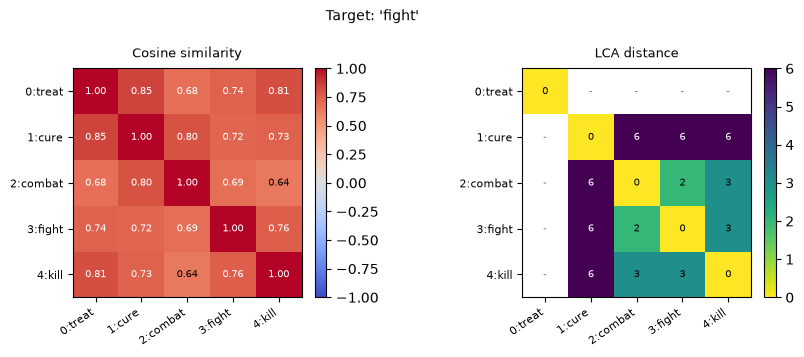


Context: 'Vaccines can be prophylactic (to prevent or alleviate the effects of a future infection by a natural or "wild" pathogen), or therapeutic (to fight a' | Target: 'disease'
Top-5          |      0:disease |    1:infection |         2:path |           3:感染 |   4:infections
---------------------------------------------------------------------------------------------------
0:disease      |         1.0000 |         0.8783 |         0.5924 |         0.4856 |         0.8622
1:infection    |         0.8783 |         1.0000 |         0.6306 |         0.5234 |         0.9555
2:path         |         0.5924 |         0.6306 |         1.0000 |         0.5194 |         0.6542
3:感染           |         0.4856 |         0.5234 |         0.5194 |         1.0000 |         0.4937
4:infections   |         0.8622 |         0.9555 |         0.6542 |         0.4937 |         1.0000


/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 24863 (\N{CJK UNIFIED IDEOGRAPH-611F}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 26579 (\N{CJK UNIFIED IDEOGRAPH-67D3}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 24863 (\N{CJK UNIFIED IDEOGRAPH-611F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 26579 (\N{CJK UNIFIED IDEOGRAPH-67D3}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


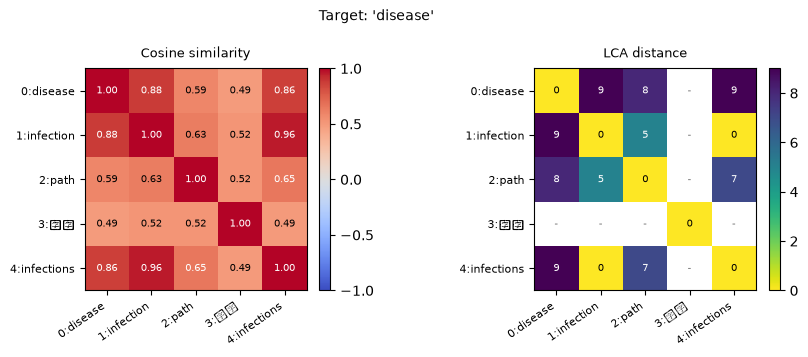


Context: 'Vaccines can be prophylactic (to prevent or alleviate the effects of a future infection by a natural or "wild" pathogen), or therapeutic (to fight a disease that has' | Target: 'already'
Top-5        |    0:already |   1:recently |       2:已经成为 |     3:become |         4:已经
---------------------------------------------------------------------------------------
0:already    |       1.0000 |       0.5958 |       0.3644 |       0.5461 |       0.5121
1:recently   |       0.5958 |       1.0000 |       0.3521 |       0.6008 |       0.4852
2:已经成为       |       0.3644 |       0.3521 |       1.0000 |       0.4208 |       0.7968
3:become     |       0.5461 |       0.6008 |       0.4208 |       1.0000 |       0.5657
4:已经         |       0.5121 |       0.4852 |       0.7968 |       0.5657 |       1.0000


/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 24050 (\N{CJK UNIFIED IDEOGRAPH-5DF2}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 32463 (\N{CJK UNIFIED IDEOGRAPH-7ECF}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 25104 (\N{CJK UNIFIED IDEOGRAPH-6210}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 20026 (\N{CJK UNIFIED IDEOGRAPH-4E3A}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 24050 (\N{CJK UNIFIED IDEOGRAPH-5DF2}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 32463 (\N{CJK UNIFIED IDEOGRAPH-7ECF}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(byte

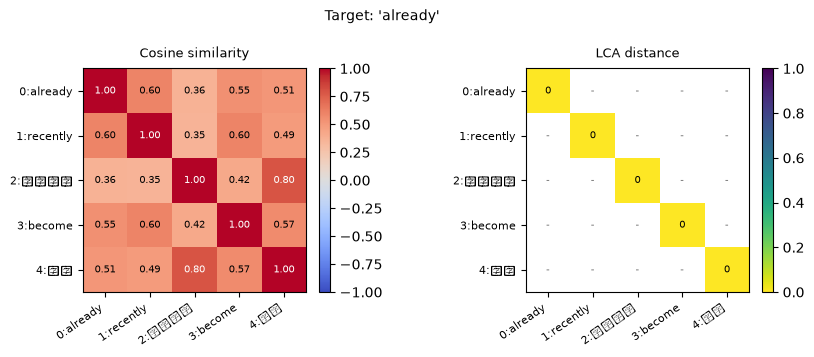


Context: 'Vaccines can be prophylactic (to prevent or alleviate the effects of a future infection by a natural or "wild" pathogen), or therapeutic (to fight a disease that has already' | Target: 'occurred,'
Top-5         |    0:occurred |    1:appeared |   2:presented |     3:started |       4:begun
---------------------------------------------------------------------------------------------
0:occurred    |        1.0000 |        0.7984 |        0.6582 |        0.7199 |        0.7315
1:appeared    |        0.7984 |        1.0000 |        0.6948 |        0.7051 |        0.7005
2:presented   |        0.6582 |        0.6948 |        1.0000 |        0.6392 |        0.6992
3:started     |        0.7199 |        0.7051 |        0.6392 |        1.0000 |        0.8740
4:begun       |        0.7315 |        0.7005 |        0.6992 |        0.8740 |        1.0000


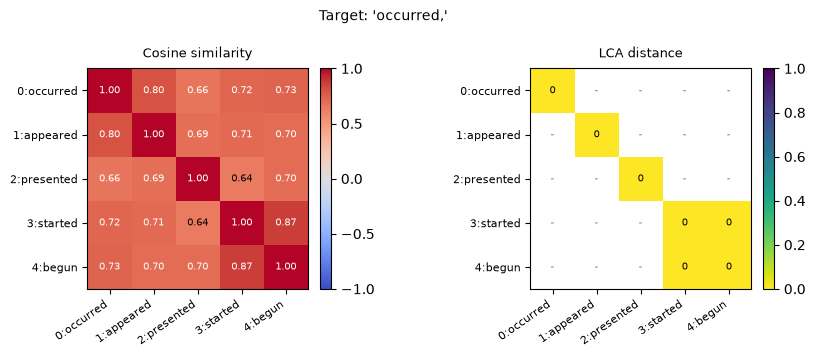


Context: 'Vaccines can be prophylactic (to prevent or alleviate the effects of a future infection by a natural or "wild" pathogen), or therapeutic (to fight a disease that has already occurred, such as' | Target: 'cancer).'
Top-5        |      0:ant |   1:cancer |      2:onc |    3:tumor |      4:rab
-----------------------------------------------------------------------------
0:ant        |     1.0000 |     0.3656 |     0.5127 |     0.8162 |     0.5933
1:cancer     |     0.3656 |     1.0000 |     0.4583 |     0.5151 |     0.4468
2:onc        |     0.5127 |     0.4583 |     1.0000 |     0.4895 |     0.5015
3:tumor      |     0.8162 |     0.5151 |     0.4895 |     1.0000 |     0.6013
4:rab        |     0.5933 |     0.4468 |     0.5015 |     0.6013 |     1.0000


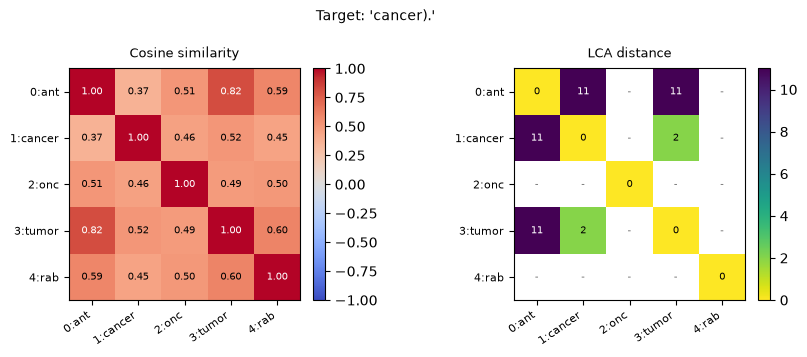


Context: 'Some' | Target: 'vaccines'
Top-5          |       0:people |     1:students |         2:time |        3:years |   4:properties
---------------------------------------------------------------------------------------------------
0:people       |         1.0000 |         0.7192 |         0.6705 |         0.5650 |         0.7096
1:students     |         0.7192 |         1.0000 |         0.5262 |         0.5322 |         0.6206
2:time         |         0.6705 |         0.5262 |         1.0000 |         0.6223 |         0.6594
3:years        |         0.5650 |         0.5322 |         0.6223 |         1.0000 |         0.4957
4:properties   |         0.7096 |         0.6206 |         0.6594 |         0.4957 |         1.0000


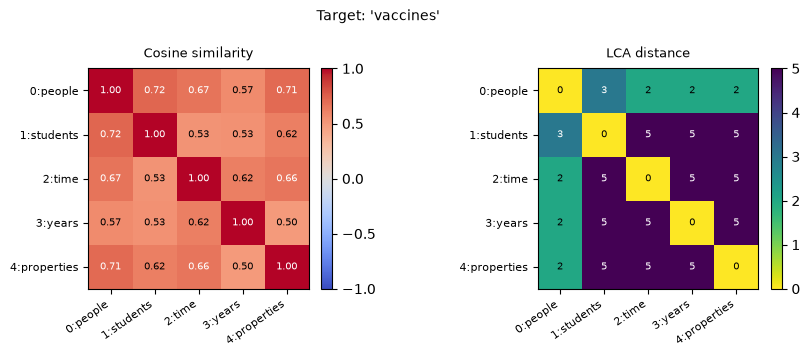


Context: 'Some vaccines' | Target: 'offer'
Top-5        |   0:require |   1:contain |      2:need |      3:work |     4:cause
----------------------------------------------------------------------------------
0:require    |      1.0000 |      0.8717 |      0.6901 |      0.6368 |      0.7708
1:contain    |      0.8717 |      1.0000 |      0.6835 |      0.6463 |      0.7921
2:need       |      0.6901 |      0.6835 |      1.0000 |      0.6417 |      0.7070
3:work       |      0.6368 |      0.6463 |      0.6417 |      1.0000 |      0.6448
4:cause      |      0.7708 |      0.7921 |      0.7070 |      0.6448 |      1.0000


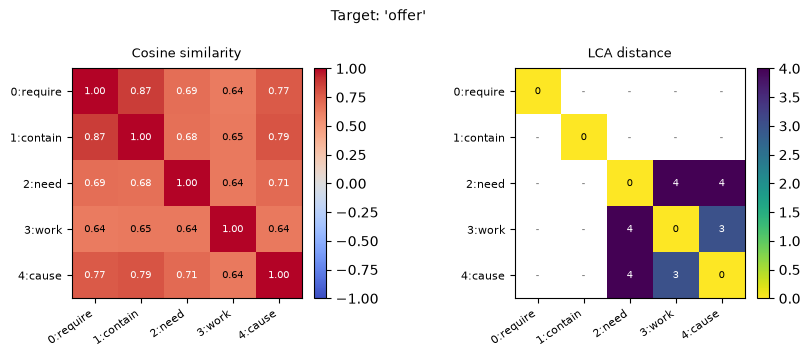


Context: 'Some vaccines offer' | Target: 'full'
Top-5          |   0:protection |       1:better |         2:long |      3:partial |     4:immunity
---------------------------------------------------------------------------------------------------
0:protection   |         1.0000 |         0.6014 |         0.6134 |         0.6092 |         0.5404
1:better       |         0.6014 |         1.0000 |         0.5637 |         0.5797 |         0.4002
2:long         |         0.6134 |         0.5637 |         1.0000 |         0.5006 |         0.3212
3:partial      |         0.6092 |         0.5797 |         0.5006 |         1.0000 |         0.4646
4:immunity     |         0.5404 |         0.4002 |         0.3212 |         0.4646 |         1.0000


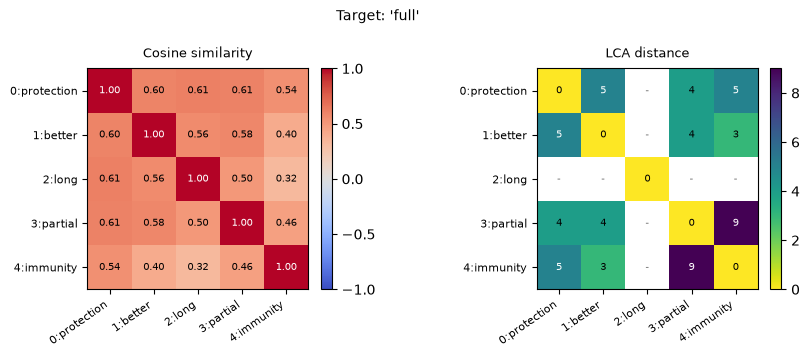


Context: 'Some vaccines offer full' | Target: 'sterilizing'
Top-5          |   0:protection |     1:immunity |     2:coverage |       3:immune |        4:immun
---------------------------------------------------------------------------------------------------
0:protection   |         1.0000 |         0.5404 |         0.7802 |         0.7591 |         0.4544
1:immunity     |         0.5404 |         1.0000 |         0.5246 |         0.6441 |         0.4228
2:coverage     |         0.7802 |         0.5246 |         1.0000 |         0.7676 |         0.4108
3:immune       |         0.7591 |         0.6441 |         0.7676 |         1.0000 |         0.4759
4:immun        |         0.4544 |         0.4228 |         0.4108 |         0.4759 |         1.0000


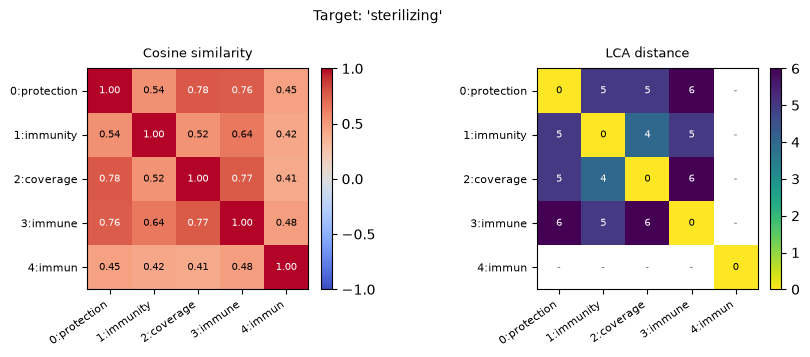


Context: 'Some vaccines offer full sterilizing' | Target: 'immunity,'
Top-5          |     0:immunity |   1:protection |     2:efficacy |        3:proph |       4:immune
---------------------------------------------------------------------------------------------------
0:immunity     |         1.0000 |         0.5404 |         0.5419 |         0.4427 |         0.6441
1:protection   |         0.5404 |         1.0000 |         0.7021 |         0.4642 |         0.7591
2:efficacy     |         0.5419 |         0.7021 |         1.0000 |         0.4951 |         0.7895
3:proph        |         0.4427 |         0.4642 |         0.4951 |         1.0000 |         0.4896
4:immune       |         0.6441 |         0.7591 |         0.7895 |         0.4896 |         1.0000


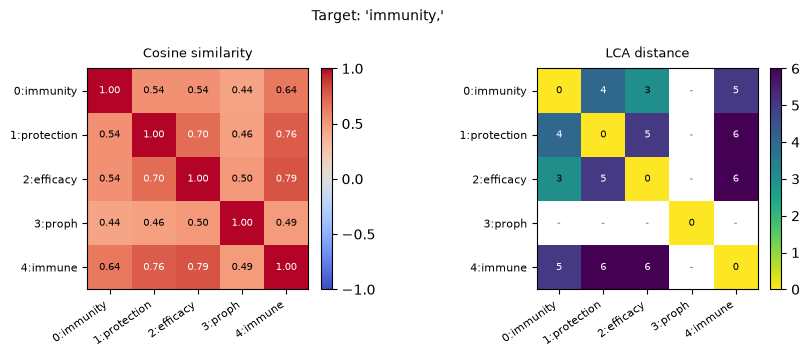


Context: 'Some vaccines offer full sterilizing immunity, in which' | Target: 'infection'
Top-5           |          0:case |   1:individuals |   2:vaccination |     3:infection |          4:inoc
---------------------------------------------------------------------------------------------------------
0:case          |          1.0000 |          0.6538 |          0.3197 |          0.7737 |          0.5669
1:individuals   |          0.6538 |          1.0000 |          0.3189 |          0.6799 |          0.5341
2:vaccination   |          0.3197 |          0.3189 |          1.0000 |          0.4901 |          0.3868
3:infection     |          0.7737 |          0.6799 |          0.4901 |          1.0000 |          0.6054
4:inoc          |          0.5669 |          0.5341 |          0.3868 |          0.6054 |          1.0000


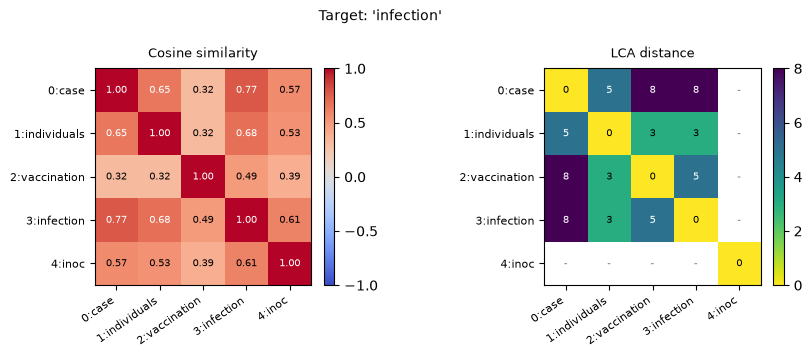


Context: 'Some vaccines offer full sterilizing immunity, in which infection is' | Target: 'prevented.'
Top-5          |    0:prevented |   1:completely |   2:impossible |      3:totally |     4:entirely
---------------------------------------------------------------------------------------------------
0:prevented    |         1.0000 |         0.6851 |         0.7080 |         0.6073 |         0.6606
1:completely   |         0.6851 |         1.0000 |         0.8094 |         0.8088 |         0.8465
2:impossible   |         0.7080 |         0.8094 |         1.0000 |         0.7406 |         0.7275
3:totally      |         0.6073 |         0.8088 |         0.7406 |         1.0000 |         0.6461
4:entirely     |         0.6606 |         0.8465 |         0.7275 |         0.6461 |         1.0000


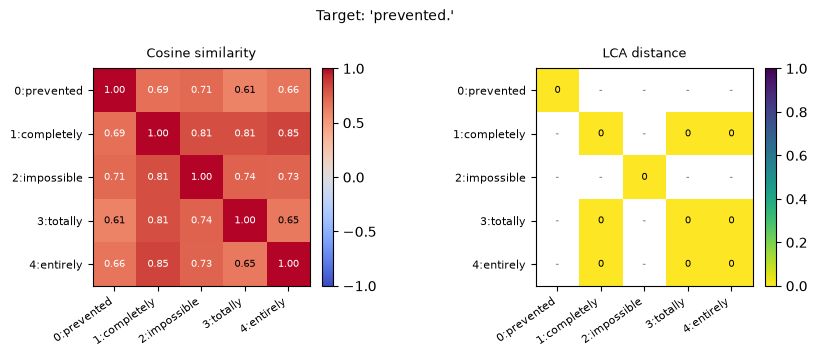


Context: 'The' | Target: 'administration'
Top-5         |   0:following |         1:sum |      2:purple |    3:function |      4:number
---------------------------------------------------------------------------------------------
0:following   |        1.0000 |        0.5209 |        0.5680 |        0.4828 |        0.5987
1:sum         |        0.5209 |        1.0000 |        0.5980 |        0.6384 |        0.6528
2:purple      |        0.5680 |        0.5980 |        1.0000 |        0.5516 |        0.7352
3:function    |        0.4828 |        0.6384 |        0.5516 |        1.0000 |        0.6338
4:number      |        0.5987 |        0.6528 |        0.7352 |        0.6338 |        1.0000


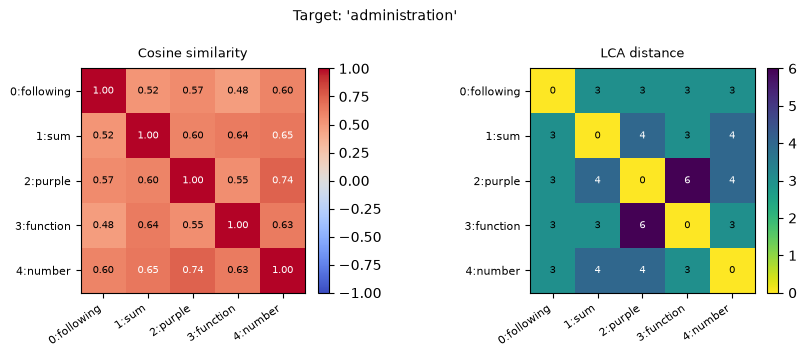


Context: 'The administration of' | Target: 'vaccines'
Top-5          |    0:president |         1:intr |        2:drugs |      3:justice |   4:medication
---------------------------------------------------------------------------------------------------
0:president    |         1.0000 |         0.4557 |         0.5084 |         0.6381 |         0.5015
1:intr         |         0.4557 |         1.0000 |         0.3230 |         0.4054 |         0.2953
2:drugs        |         0.5084 |         0.3230 |         1.0000 |         0.6122 |         0.6898
3:justice      |         0.6381 |         0.4054 |         0.6122 |         1.0000 |         0.5373
4:medication   |         0.5015 |         0.2953 |         0.6898 |         0.5373 |         1.0000


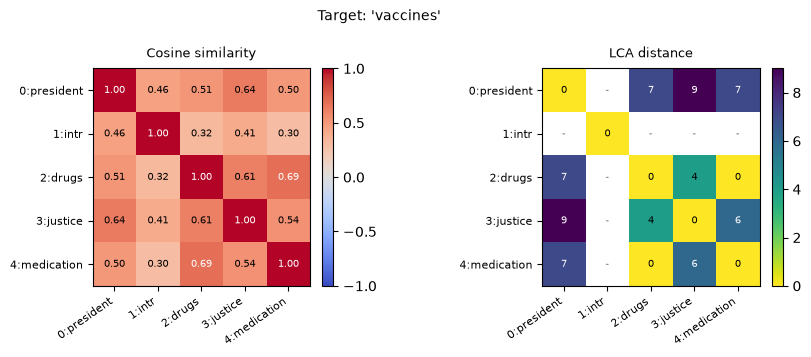


Context: 'The administration of vaccines is' | Target: 'called'
Top-5          |        0:among |         1:part |   2:associated |      3:usually |    4:generally
---------------------------------------------------------------------------------------------------
0:among        |         1.0000 |         0.4020 |         0.6689 |         0.6795 |         0.7022
1:part         |         0.4020 |         1.0000 |         0.4435 |         0.4499 |         0.4319
2:associated   |         0.6689 |         0.4435 |         1.0000 |         0.7002 |         0.7115
3:usually      |         0.6795 |         0.4499 |         0.7002 |         1.0000 |         0.8288
4:generally    |         0.7022 |         0.4319 |         0.7115 |         0.8288 |         1.0000


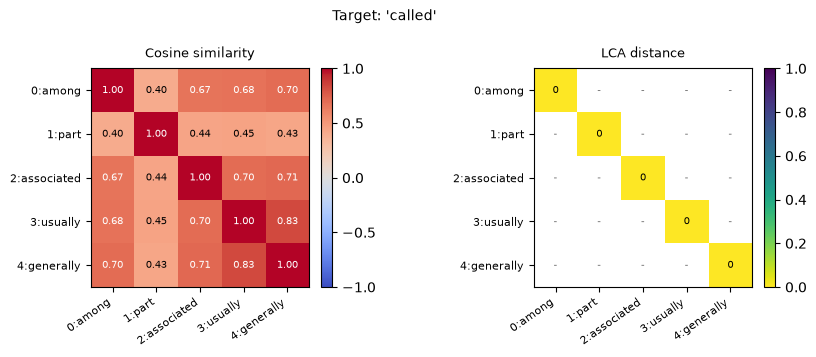


Context: 'The administration of vaccines is called' | Target: 'vaccination.'
Top-5           |         0:immun |   1:vaccination |          2:inoc |          3:vacc |            4:接种
---------------------------------------------------------------------------------------------------------
0:immun         |          1.0000 |          0.5666 |          0.5164 |          0.4447 |          0.3154
1:vaccination   |          0.5666 |          1.0000 |          0.3868 |          0.3517 |          0.3715
2:inoc          |          0.5164 |          0.3868 |          1.0000 |          0.5848 |          0.4497
3:vacc          |          0.4447 |          0.3517 |          0.5848 |          1.0000 |          0.3602
4:接种            |          0.3154 |          0.3715 |          0.4497 |          0.3602 |          1.0000


/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 25509 (\N{CJK UNIFIED IDEOGRAPH-63A5}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 31181 (\N{CJK UNIFIED IDEOGRAPH-79CD}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 25509 (\N{CJK UNIFIED IDEOGRAPH-63A5}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 31181 (\N{CJK UNIFIED IDEOGRAPH-79CD}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


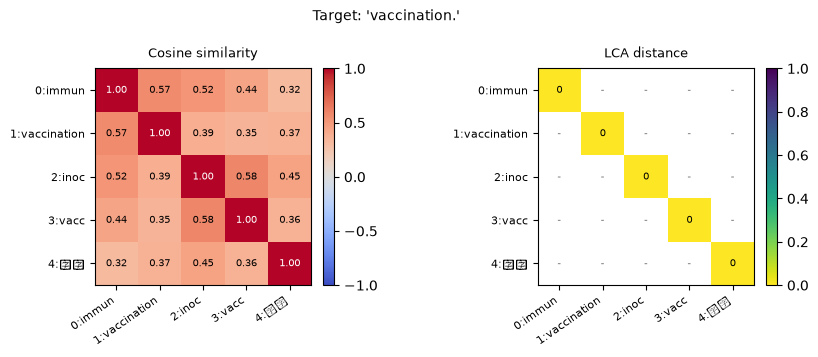


Context: 'Vaccination is the most effective' | Target: 'method'
Top-5          |          0:way |       1:method |      2:measure |        3:means |   4:preventive
---------------------------------------------------------------------------------------------------
0:way          |         1.0000 |         0.5608 |         0.4701 |         0.5255 |         0.3106
1:method       |         0.5608 |         1.0000 |         0.7101 |         0.5842 |         0.4419
2:measure      |         0.4701 |         0.7101 |         1.0000 |         0.5600 |         0.4668
3:means        |         0.5255 |         0.5842 |         0.5600 |         1.0000 |         0.3281
4:preventive   |         0.3106 |         0.4419 |         0.4668 |         0.3281 |         1.0000


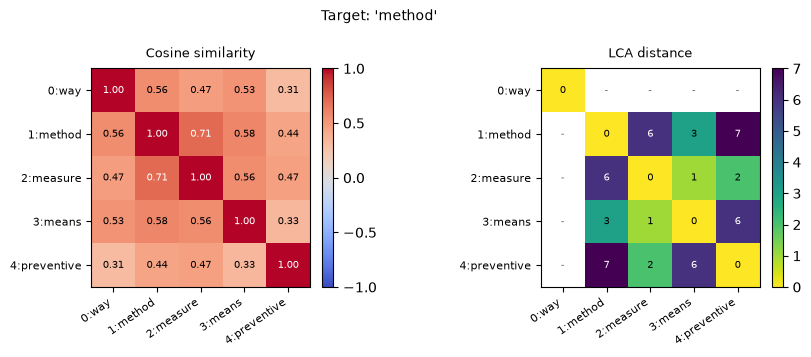


Context: 'Vaccination is the most effective method of' | Target: 'preventing'
Top-5          |   0:preventing |      1:disease |   2:prevention |   3:protection |     4:reducing
---------------------------------------------------------------------------------------------------
0:preventing   |         1.0000 |         0.7695 |         0.8479 |         0.7836 |         0.8662
1:disease      |         0.7695 |         1.0000 |         0.7673 |         0.6977 |         0.7275
2:prevention   |         0.8479 |         0.7673 |         1.0000 |         0.7739 |         0.8312
3:protection   |         0.7836 |         0.6977 |         0.7739 |         1.0000 |         0.7475
4:reducing     |         0.8662 |         0.7275 |         0.8312 |         0.7475 |         1.0000


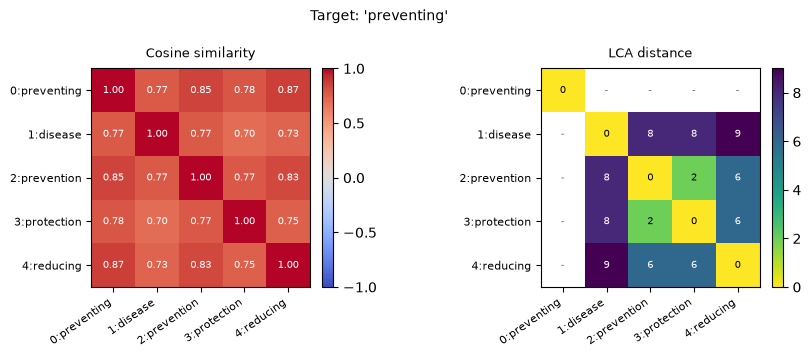


Context: 'Vaccination is the most effective method of preventing infectious' | Target: 'diseases;'
Top-5         |    0:diseases |     1:disease |      2:animal |           3:z |   4:illnesses
---------------------------------------------------------------------------------------------
0:diseases    |        1.0000 |        0.9017 |        0.6159 |        0.4713 |        0.7094
1:disease     |        0.9017 |        1.0000 |        0.6455 |        0.5374 |        0.7877
2:animal      |        0.6159 |        0.6455 |        1.0000 |        0.4644 |        0.6087
3:z           |        0.4713 |        0.5374 |        0.4644 |        1.0000 |        0.6555
4:illnesses   |        0.7094 |        0.7877 |        0.6087 |        0.6555 |        1.0000


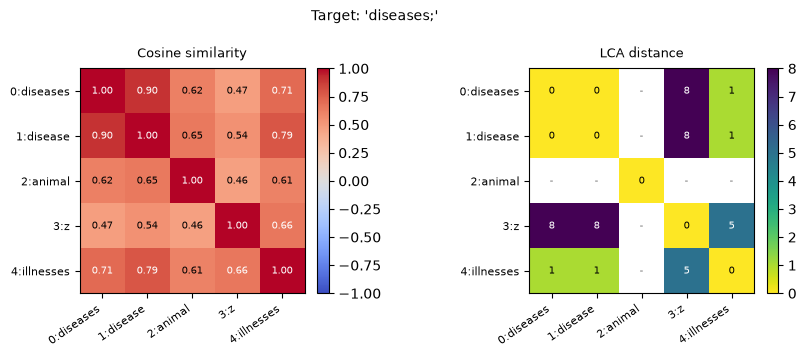


Context: 'Vaccination is the most effective method of preventing infectious diseases; widespread' | Target: 'immunity'
Top-5           |      0:immunity |         1:immun |   2:vaccination |     3:voluntary |           4:use
---------------------------------------------------------------------------------------------------------
0:immunity      |          1.0000 |          0.4228 |          0.4113 |          0.5862 |          0.4742
1:immun         |          0.4228 |          1.0000 |          0.5666 |          0.3702 |          0.3485
2:vaccination   |          0.4113 |          0.5666 |          1.0000 |          0.3261 |          0.2902
3:voluntary     |          0.5862 |          0.3702 |          0.3261 |          1.0000 |          0.6316
4:use           |          0.4742 |          0.3485 |          0.2902 |          0.6316 |          1.0000


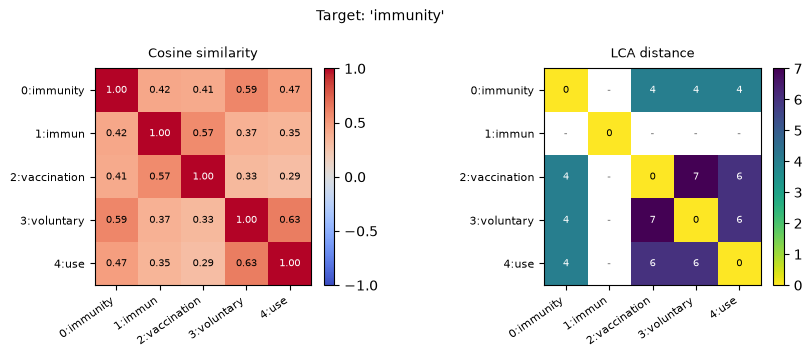


Context: 'Vaccination is the most effective method of preventing infectious diseases; widespread immunity' | Target: 'due'
Top-5             |             0:due |   1:significantly |       2:resulting |        3:provided |          4:thanks
---------------------------------------------------------------------------------------------------------------------
0:due             |            1.0000 |            0.8616 |            0.7092 |            0.5229 |            0.5258
1:significantly   |            0.8616 |            1.0000 |            0.7249 |            0.5633 |            0.5441
2:resulting       |            0.7092 |            0.7249 |            1.0000 |            0.5653 |            0.4744
3:provided        |            0.5229 |            0.5633 |            0.5653 |            1.0000 |            0.4392
4:thanks          |            0.5258 |            0.5441 |            0.4744 |            0.4392 |            1.0000


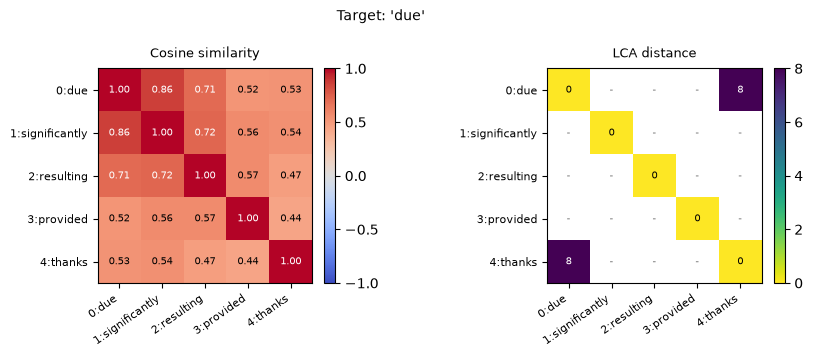


Context: 'Vaccination is the most effective method of preventing infectious diseases; widespread immunity due to' | Target: 'vaccination'
Top-5            |    0:vaccination |         1:either |           2:vacc |        3:vaccine |   4:vaccinations
---------------------------------------------------------------------------------------------------------------
0:vaccination    |           1.0000 |           0.2035 |           0.3517 |           0.4347 |           0.8644
1:either         |           0.2035 |           1.0000 |           0.3688 |           0.3869 |           0.2532
2:vacc           |           0.3517 |           0.3688 |           1.0000 |           0.5615 |           0.3824
3:vaccine        |           0.4347 |           0.3869 |           0.5615 |           1.0000 |           0.3805
4:vaccinations   |           0.8644 |           0.2532 |           0.3824 |           0.3805 |           1.0000


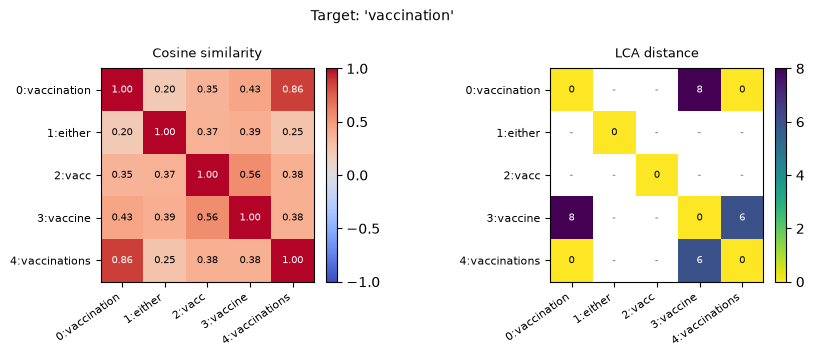


Context: 'Vaccination is the most effective method of preventing infectious diseases; widespread immunity due to vaccination is' | Target: 'largely'
Top-5         |     0:largely |   1:necessary |      2:mainly |   3:primarily |      4:mostly
---------------------------------------------------------------------------------------------
0:largely     |        1.0000 |        0.6647 |        0.8245 |        0.9393 |        0.8173
1:necessary   |        0.6647 |        1.0000 |        0.5864 |        0.6927 |        0.5600
2:mainly      |        0.8245 |        0.5864 |        1.0000 |        0.8682 |        0.8227
3:primarily   |        0.9393 |        0.6927 |        0.8682 |        1.0000 |        0.8349
4:mostly      |        0.8173 |        0.5600 |        0.8227 |        0.8349 |        1.0000


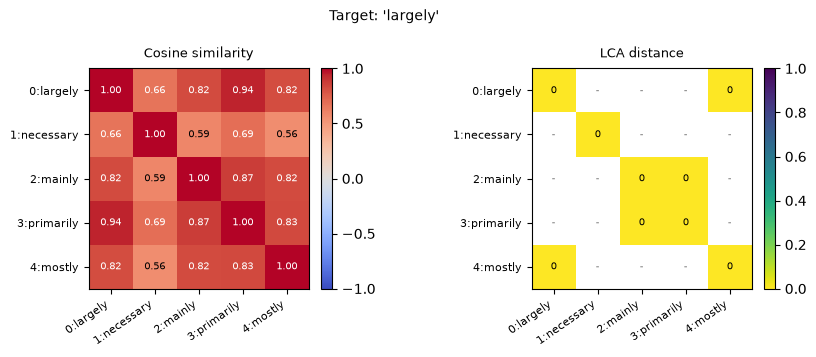


Context: 'Vaccination is the most effective method of preventing infectious diseases; widespread immunity due to vaccination is largely responsible for the worldwide' | Target: 'eradication'
Top-5           |          0:erad |            1:er |   2:elimination |       3:decline |     4:abolition
---------------------------------------------------------------------------------------------------------
0:erad          |          1.0000 |          0.2630 |          0.4623 |          0.3334 |          0.3612
1:er            |          0.2630 |          1.0000 |          0.4073 |          0.4843 |          0.4388
2:elimination   |          0.4623 |          0.4073 |          1.0000 |          0.6065 |          0.6243
3:decline       |          0.3334 |          0.4843 |          0.6065 |          1.0000 |          0.6564
4:abolition     |          0.3612 |          0.4388 |          0.6243 |          0.6564 |          1.0000


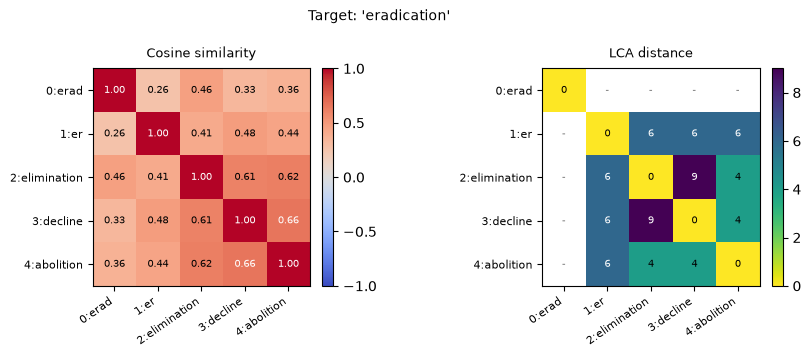


Context: 'Vaccination is the most effective method of preventing infectious diseases; widespread immunity due to vaccination is largely responsible for the worldwide eradication of' | Target: 'smallpox'
Top-5        |      0:small |   1:diseases |        2:pol |         3:天花 |   4:formerly
---------------------------------------------------------------------------------------
0:small      |       1.0000 |       0.5202 |       0.6594 |       0.5190 |       0.4444
1:diseases   |       0.5202 |       1.0000 |       0.5399 |       0.4014 |       0.5106
2:pol        |       0.6594 |       0.5399 |       1.0000 |       0.4649 |       0.5001
3:天花         |       0.5190 |       0.4014 |       0.4649 |       1.0000 |       0.3514
4:formerly   |       0.4444 |       0.5106 |       0.5001 |       0.3514 |       1.0000


/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 22825 (\N{CJK UNIFIED IDEOGRAPH-5929}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 33457 (\N{CJK UNIFIED IDEOGRAPH-82B1}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 22825 (\N{CJK UNIFIED IDEOGRAPH-5929}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 33457 (\N{CJK UNIFIED IDEOGRAPH-82B1}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


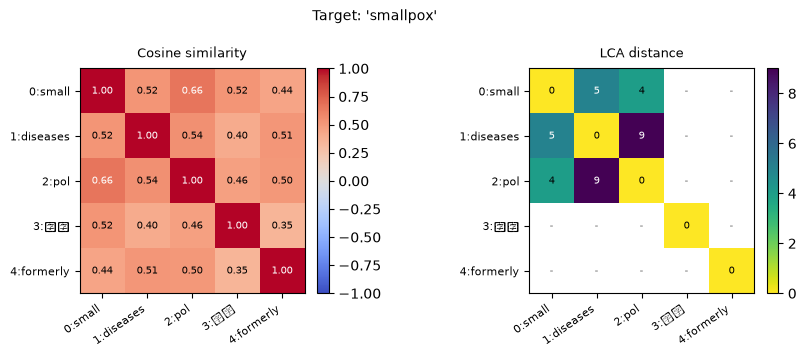


Context: 'Vaccination is the most effective method of preventing infectious diseases; widespread immunity due to vaccination is largely responsible for the worldwide eradication of smallpox and the' | Target: 'restriction'
Top-5            |    0:restriction |     1:limitation |           2:near |       3:restrict |   4:restrictions
---------------------------------------------------------------------------------------------------------------
0:restriction    |           1.0000 |           0.9307 |           0.7392 |           0.9208 |           0.7996
1:limitation     |           0.9307 |           1.0000 |           0.7329 |           0.9306 |           0.8001
2:near           |           0.7392 |           0.7329 |           1.0000 |           0.7387 |           0.6287
3:restrict       |           0.9208 |           0.9306 |           0.7387 |           1.0000 |           0.7823
4:restrictions   |           0.7996 |           0.8001 |           0.6287 |           0.7823 |          

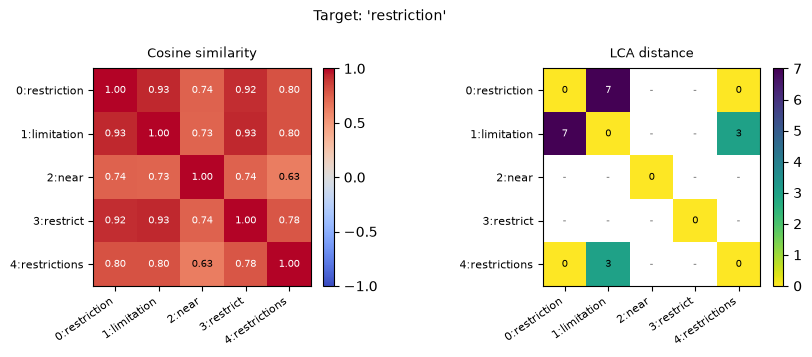


Context: 'Vaccination is the most effective method of preventing infectious diseases; widespread immunity due to vaccination is largely responsible for the worldwide eradication of smallpox and the restriction of' | Target: 'diseases'
Top-5          |     0:diseases |          1:pol |   2:conditions |    3:illnesses |      4:measles
---------------------------------------------------------------------------------------------------
0:diseases     |         1.0000 |         0.5399 |         0.6695 |         0.7094 |         0.4085
1:pol          |         0.5399 |         1.0000 |         0.5414 |         0.7550 |         0.1485
2:conditions   |         0.6695 |         0.5414 |         1.0000 |         0.6796 |         0.2080
3:illnesses    |         0.7094 |         0.7550 |         0.6796 |         1.0000 |         0.1867
4:measles      |         0.4085 |         0.1485 |         0.2080 |         0.1867 |         1.0000


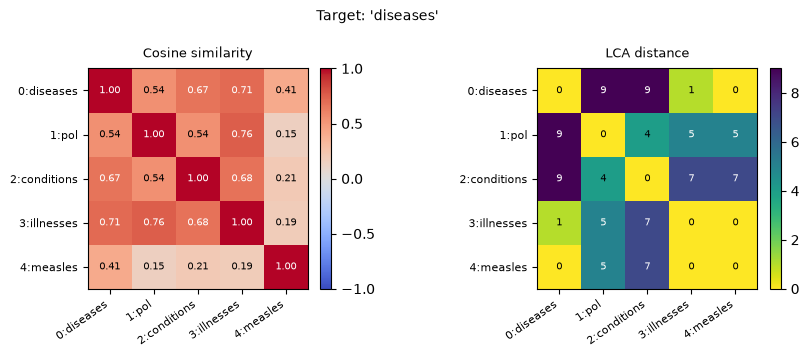


Context: 'Vaccination is the most effective method of preventing infectious diseases; widespread immunity due to vaccination is largely responsible for the worldwide eradication of smallpox and the restriction of diseases such as' | Target: 'polio,'
Top-5         |         0:pol |          1:ha |     2:measles |   3:hepatitis |     4:endemic
---------------------------------------------------------------------------------------------
0:pol         |        1.0000 |        0.5907 |        0.1485 |        0.7039 |        0.5939
1:ha          |        0.5907 |        1.0000 |        0.1827 |        0.4974 |        0.4409
2:measles     |        0.1485 |        0.1827 |        1.0000 |        0.3463 |        0.2835
3:hepatitis   |        0.7039 |        0.4974 |        0.3463 |        1.0000 |        0.6283
4:endemic     |        0.5939 |        0.4409 |        0.2835 |        0.6283 |        1.0000


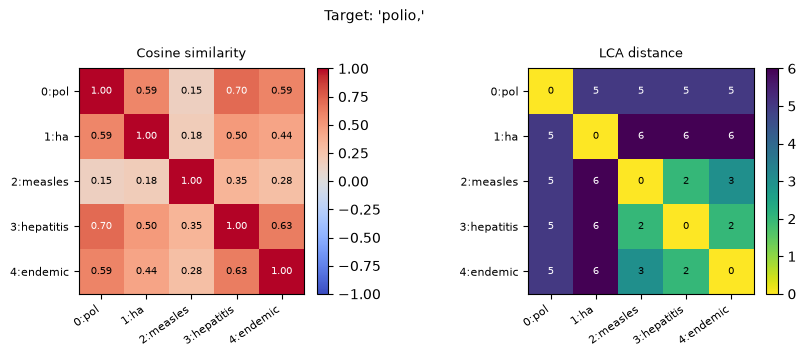


Context: 'Vaccination is the most effective method of preventing infectious diseases; widespread immunity due to vaccination is largely responsible for the worldwide eradication of smallpox and the restriction of diseases such as polio,' | Target: 'measles,'
Top-5            |        0:measles |            1:tet |   2:tuberculosis |           3:neon |            4:tul
---------------------------------------------------------------------------------------------------------------
0:measles        |           1.0000 |           0.2671 |           0.1641 |           0.1751 |           0.2554
1:tet            |           0.2671 |           1.0000 |           0.2784 |           0.3158 |           0.4664
2:tuberculosis   |           0.1641 |           0.2784 |           1.0000 |           0.7760 |           0.4849
3:neon           |           0.1751 |           0.3158 |           0.7760 |           1.0000 |           0.6080
4:tul            |           0.2554 |           0.4664 |           0

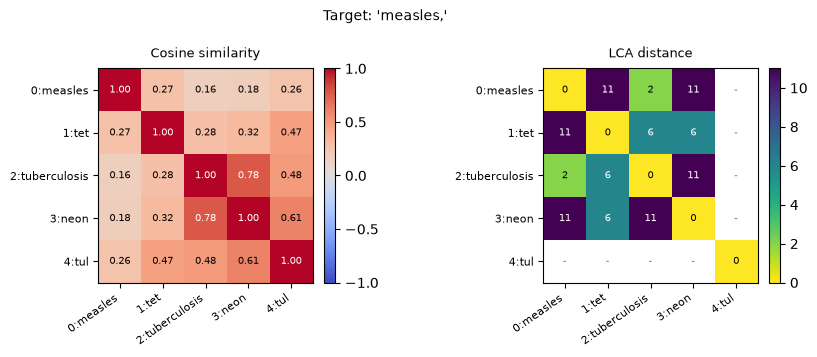


Context: 'Vaccination is the most effective method of preventing infectious diseases; widespread immunity due to vaccination is largely responsible for the worldwide eradication of smallpox and the restriction of diseases such as polio, measles, and' | Target: 'tetanus'
Top-5        |        0:tet |        1:rub |   2:diarrhea |    3:chicken |      4:diarr
---------------------------------------------------------------------------------------
0:tet        |       1.0000 |       0.2910 |       0.2809 |       0.3126 |       0.3292
1:rub        |       0.2910 |       1.0000 |       0.1836 |       0.7249 |       0.5880
2:diarrhea   |       0.2809 |       0.1836 |       1.0000 |       0.2573 |       0.4321
3:chicken    |       0.3126 |       0.7249 |       0.2573 |       1.0000 |       0.5272
4:diarr      |       0.3292 |       0.5880 |       0.4321 |       0.5272 |       1.0000


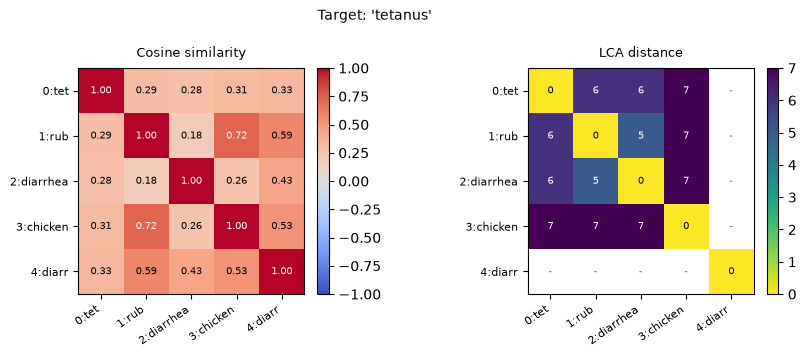


Context: 'Vaccination is the most effective method of preventing infectious diseases; widespread immunity due to vaccination is largely responsible for the worldwide eradication of smallpox and the restriction of diseases such as polio, measles, and tetanus from much of the' | Target: 'world.'
Top-5        |    0:world |       1:世界 |    2:globe |      3:的世界 |      4:世界的
-----------------------------------------------------------------------------
0:world      |     1.0000 |     0.3929 |     0.6540 |     0.2540 |     0.3380
1:世界         |     0.3929 |     1.0000 |     0.4354 |     0.9071 |     0.9514
2:globe      |     0.6540 |     0.4354 |     1.0000 |     0.2820 |     0.3660
3:的世界        |     0.2540 |     0.9071 |     0.2820 |     1.0000 |     0.9455
4:世界的        |     0.3380 |     0.9514 |     0.3660 |     0.9455 |     1.0000


/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 19990 (\N{CJK UNIFIED IDEOGRAPH-4E16}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 30028 (\N{CJK UNIFIED IDEOGRAPH-754C}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 30340 (\N{CJK UNIFIED IDEOGRAPH-7684}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 19990 (\N{CJK UNIFIED IDEOGRAPH-4E16}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 30028 (\N{CJK UNIFIED IDEOGRAPH-754C}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 30340 (\N{CJK UNIFIED IDEOGRAPH-7684}) missing 

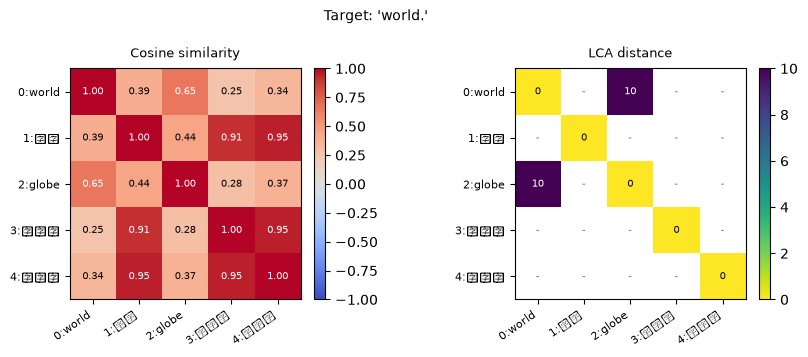


Context: 'The' | Target: 'World'
Top-5         |   0:following |         1:sum |      2:purple |    3:function |      4:number
---------------------------------------------------------------------------------------------
0:following   |        1.0000 |        0.5209 |        0.5680 |        0.4828 |        0.5987
1:sum         |        0.5209 |        1.0000 |        0.5980 |        0.6384 |        0.6528
2:purple      |        0.5680 |        0.5980 |        1.0000 |        0.5516 |        0.7352
3:function    |        0.4828 |        0.6384 |        0.5516 |        1.0000 |        0.6338
4:number      |        0.5987 |        0.6528 |        0.7352 |        0.6338 |        1.0000


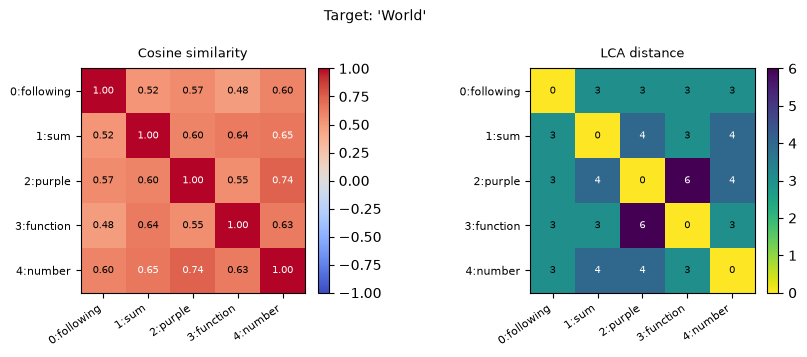


Context: 'The World' | Target: 'Health'
Top-5        |   0:health |      1:cup |   2:series |    3:trade |     4:bank
-----------------------------------------------------------------------------
0:health     |     1.0000 |     0.4926 |     0.3783 |     0.6081 |     0.5461
1:cup        |     0.4926 |     1.0000 |     0.4508 |     0.5548 |     0.7080
2:series     |     0.3783 |     0.4508 |     1.0000 |     0.3635 |     0.3687
3:trade      |     0.6081 |     0.5548 |     0.3635 |     1.0000 |     0.6111
4:bank       |     0.5461 |     0.7080 |     0.3687 |     0.6111 |     1.0000


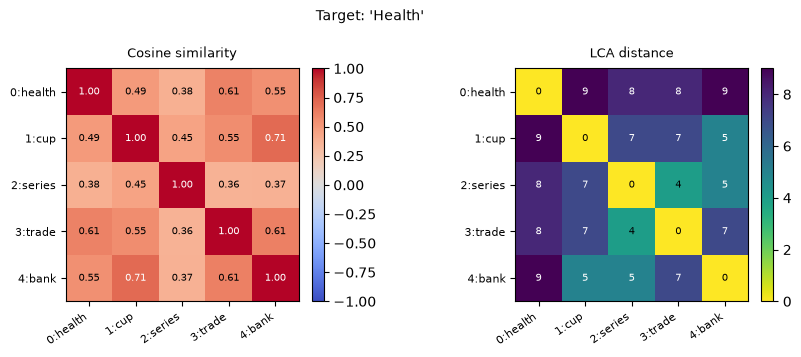


Context: 'The World Health' | Target: 'Organization'
Top-5            |   0:organization |   1:organisation |       2:assembly |            3:day |         4:report
---------------------------------------------------------------------------------------------------------------
0:organization   |           1.0000 |           0.8857 |           0.7567 |           0.5559 |           0.7273
1:organisation   |           0.8857 |           1.0000 |           0.6297 |           0.5213 |           0.6320
2:assembly       |           0.7567 |           0.6297 |           1.0000 |           0.5032 |           0.6978
3:day            |           0.5559 |           0.5213 |           0.5032 |           1.0000 |           0.5757
4:report         |           0.7273 |           0.6320 |           0.6978 |           0.5757 |           1.0000


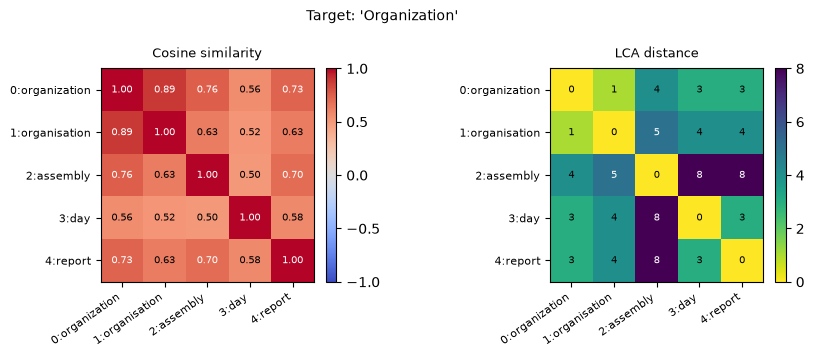


Context: 'The World Health Organization (WHO)' | Target: 'reports'
Top-5          |      0:defines |   1:recommends |    2:estimates |     3:recently |      4:reports
---------------------------------------------------------------------------------------------------
0:defines      |         1.0000 |         0.6682 |         0.6439 |         0.5624 |         0.6293
1:recommends   |         0.6682 |         1.0000 |         0.7227 |         0.6246 |         0.7317
2:estimates    |         0.6439 |         0.7227 |         1.0000 |         0.5956 |         0.7981
3:recently     |         0.5624 |         0.6246 |         0.5956 |         1.0000 |         0.6214
4:reports      |         0.6293 |         0.7317 |         0.7981 |         0.6214 |         1.0000


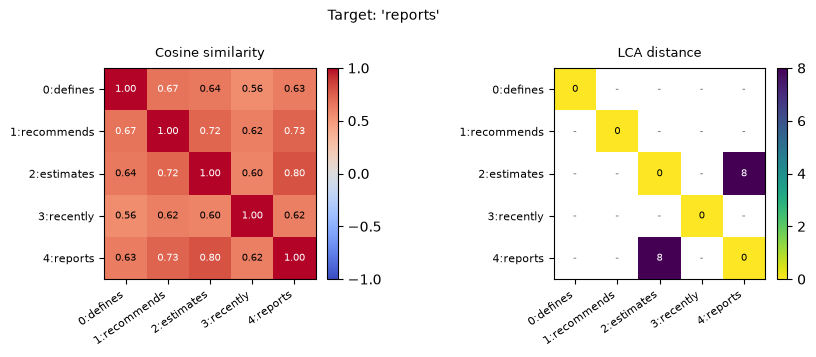


Context: 'The World Health Organization (WHO) reports that licensed' | Target: 'vaccines'
Top-5         |    0:vaccines |   1:influenza |         2:ant |     3:malaria |       4:drugs
---------------------------------------------------------------------------------------------
0:vaccines    |        1.0000 |        0.8116 |        0.7184 |        0.4119 |        0.6561
1:influenza   |        0.8116 |        1.0000 |        0.6715 |        0.5497 |        0.5748
2:ant         |        0.7184 |        0.6715 |        1.0000 |        0.2502 |        0.5253
3:malaria     |        0.4119 |        0.5497 |        0.2502 |        1.0000 |        0.4726
4:drugs       |        0.6561 |        0.5748 |        0.5253 |        0.4726 |        1.0000


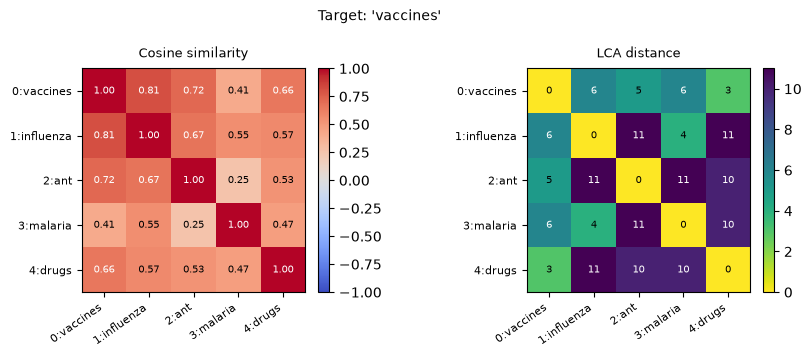


Context: 'The World Health Organization (WHO) reports that licensed vaccines are available for' | Target: 'twenty-five'
Top-5          |   0:prevention |         1:nine |        2:eight |   3:preventing |        4:seven
---------------------------------------------------------------------------------------------------
0:prevention   |         1.0000 |         0.4801 |         0.4585 |         0.8479 |         0.5151
1:nine         |         0.4801 |         1.0000 |         0.9025 |         0.4923 |         0.9199
2:eight        |         0.4585 |         0.9025 |         1.0000 |         0.4763 |         0.9062
3:preventing   |         0.8479 |         0.4923 |         0.4763 |         1.0000 |         0.5312
4:seven        |         0.5151 |         0.9199 |         0.9062 |         0.5312 |         1.0000


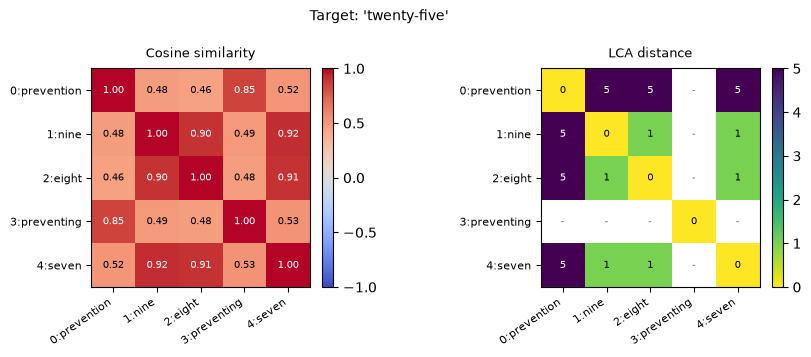


Context: 'The World Health Organization (WHO) reports that licensed vaccines are available for twenty-five different preventable' | Target: 'infections.'
Top-5          |     0:diseases |   1:infections |    2:childhood |        3:human |    4:illnesses
---------------------------------------------------------------------------------------------------
0:diseases     |         1.0000 |         0.7605 |         0.6160 |         0.5324 |         0.7094
1:infections   |         0.7605 |         1.0000 |         0.6312 |         0.5865 |         0.8449
2:childhood    |         0.6160 |         0.6312 |         1.0000 |         0.5689 |         0.6249
3:human        |         0.5324 |         0.5865 |         0.5689 |         1.0000 |         0.5992
4:illnesses    |         0.7094 |         0.8449 |         0.6249 |         0.5992 |         1.0000


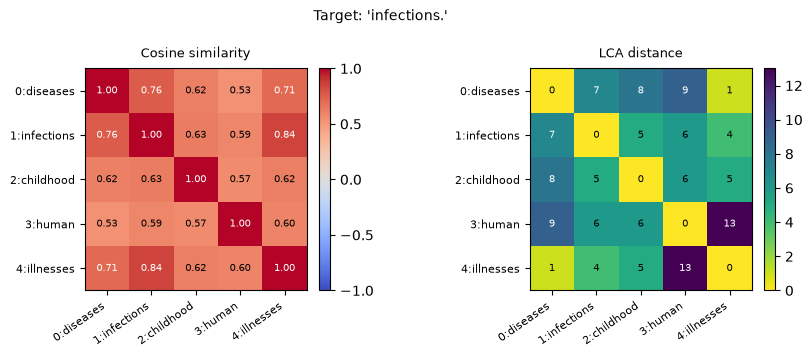


Context: 'The' | Target: 'first'
Top-5         |   0:following |         1:sum |      2:purple |    3:function |      4:number
---------------------------------------------------------------------------------------------
0:following   |        1.0000 |        0.5209 |        0.5680 |        0.4828 |        0.5987
1:sum         |        0.5209 |        1.0000 |        0.5980 |        0.6384 |        0.6528
2:purple      |        0.5680 |        0.5980 |        1.0000 |        0.5516 |        0.7352
3:function    |        0.4828 |        0.6384 |        0.5516 |        1.0000 |        0.6338
4:number      |        0.5987 |        0.6528 |        0.7352 |        0.6338 |        1.0000


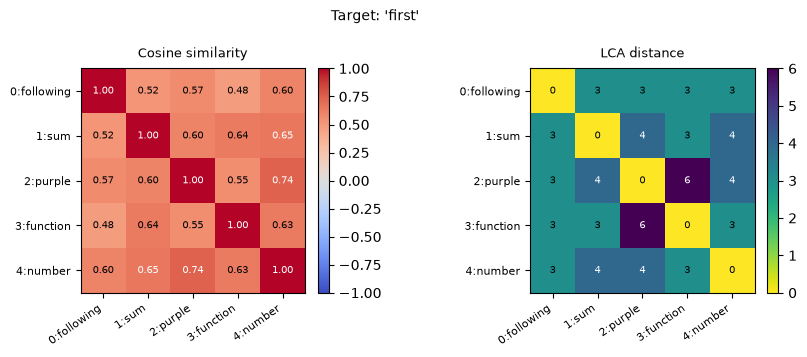


Context: 'The first recorded' | Target: 'use'
Top-5        |        0:use |       1:case |    2:history |   3:sighting |    4:mention
---------------------------------------------------------------------------------------
0:use        |       1.0000 |       0.6545 |       0.4364 |       0.6565 |       0.6778
1:case       |       0.6545 |       1.0000 |       0.4630 |       0.7957 |       0.7480
2:history    |       0.4364 |       0.4630 |       1.0000 |       0.3987 |       0.4632
3:sighting   |       0.6565 |       0.7957 |       0.3987 |       1.0000 |       0.7723
4:mention    |       0.6778 |       0.7480 |       0.4632 |       0.7723 |       1.0000


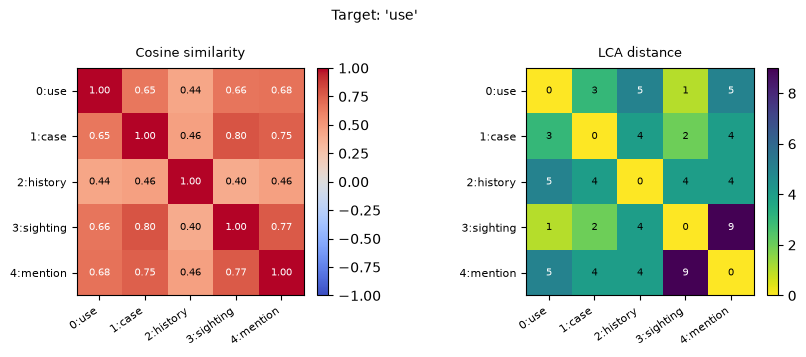


Context: 'The first recorded use of' | Target: 'inoculation'
Top-5        |      0:gun |     1:coal |     2:fire |     3:iron |    4:steam
-----------------------------------------------------------------------------
0:gun        |     1.0000 |     0.6104 |     0.7071 |     0.7110 |     0.5660
1:coal       |     0.6104 |     1.0000 |     0.5807 |     0.7602 |     0.7606
2:fire       |     0.7071 |     0.5807 |     1.0000 |     0.6578 |     0.5372
3:iron       |     0.7110 |     0.7602 |     0.6578 |     1.0000 |     0.6866
4:steam      |     0.5660 |     0.7606 |     0.5372 |     0.6866 |     1.0000


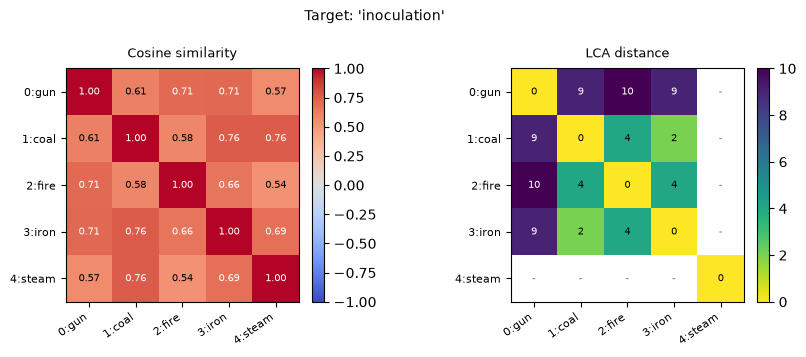


Context: 'The first recorded use of inoculation to' | Target: 'prevent'
Top-5            |        0:prevent |        1:protect |        2:produce |   3:deliberately |         4:confer
---------------------------------------------------------------------------------------------------------------
0:prevent        |           1.0000 |           0.7785 |           0.7750 |           0.7670 |           0.5542
1:protect        |           0.7785 |           1.0000 |           0.6679 |           0.6795 |           0.5074
2:produce        |           0.7750 |           0.6679 |           1.0000 |           0.6239 |           0.5786
3:deliberately   |           0.7670 |           0.6795 |           0.6239 |           1.0000 |           0.4770
4:confer         |           0.5542 |           0.5074 |           0.5786 |           0.4770 |           1.0000


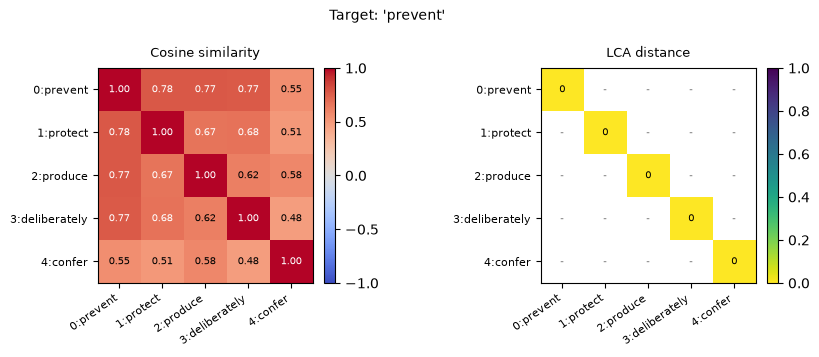


Context: 'The first recorded use of inoculation to prevent' | Target: 'smallpox'
Top-5         |       0:small |     1:disease |   2:infection |     3:illness |    4:diseases
---------------------------------------------------------------------------------------------
0:small       |        1.0000 |        0.6132 |        0.6512 |        0.5730 |        0.5202
1:disease     |        0.6132 |        1.0000 |        0.8783 |        0.8748 |        0.9017
2:infection   |        0.6512 |        0.8783 |        1.0000 |        0.7795 |        0.7438
3:illness     |        0.5730 |        0.8748 |        0.7795 |        1.0000 |        0.8255
4:diseases    |        0.5202 |        0.9017 |        0.7438 |        0.8255 |        1.0000


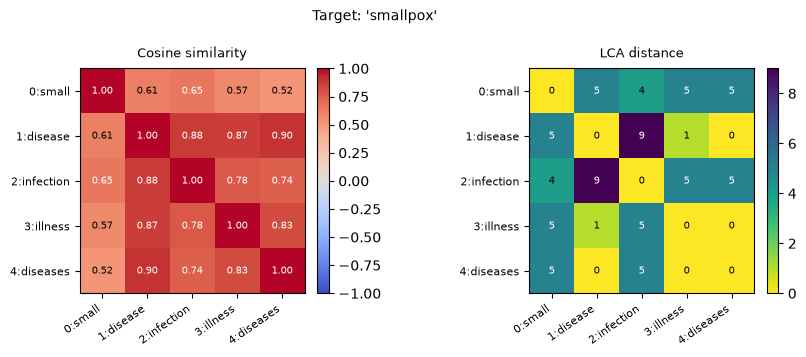


Context: 'The first recorded use of inoculation to prevent smallpox' | Target: '(see'
Top-5        |   0:occurred |      1:dates |       2:took |    3:disease |       4:came
---------------------------------------------------------------------------------------
0:occurred   |       1.0000 |       0.4523 |       0.7674 |       0.5969 |       0.7200
1:dates      |       0.4523 |       1.0000 |       0.3559 |       0.4967 |       0.3640
2:took       |       0.7674 |       0.3559 |       1.0000 |       0.5401 |       0.7612
3:disease    |       0.5969 |       0.4967 |       0.5401 |       1.0000 |       0.5162
4:came       |       0.7200 |       0.3640 |       0.7612 |       0.5162 |       1.0000


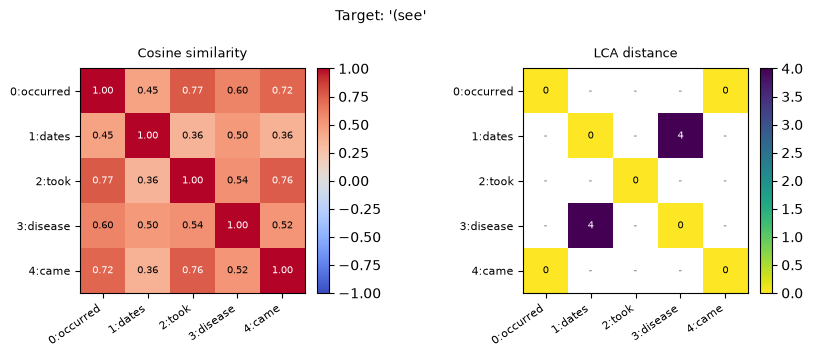


Context: 'The first recorded use of inoculation to prevent smallpox (see' | Target: 'variolation)'
Top-5        |     0:vari |    1:small |      2:cow |        3:p |   4:figure
-----------------------------------------------------------------------------
0:vari       |     1.0000 |     0.5025 |     0.4630 |     0.3454 |     0.5238
1:small      |     0.5025 |     1.0000 |     0.6791 |     0.4108 |     0.7056
2:cow        |     0.4630 |     0.6791 |     1.0000 |     0.4676 |     0.7796
3:p          |     0.3454 |     0.4108 |     0.4676 |     1.0000 |     0.4680
4:figure     |     0.5238 |     0.7056 |     0.7796 |     0.4680 |     1.0000


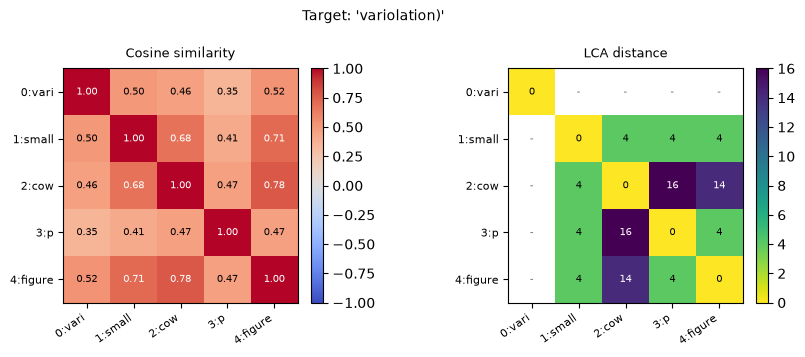


Context: 'The first recorded use of inoculation to prevent smallpox (see variolation)' | Target: 'occurred'
Top-5        |   0:occurred |      1:dates |       2:came |    3:appears |       4:took
---------------------------------------------------------------------------------------
0:occurred   |       1.0000 |       0.4523 |       0.7200 |       0.7344 |       0.7674
1:dates      |       0.4523 |       1.0000 |       0.3640 |       0.4963 |       0.3559
2:came       |       0.7200 |       0.3640 |       1.0000 |       0.6283 |       0.7612
3:appears    |       0.7344 |       0.4963 |       0.6283 |       1.0000 |       0.6361
4:took       |       0.7674 |       0.3559 |       0.7612 |       0.6361 |       1.0000


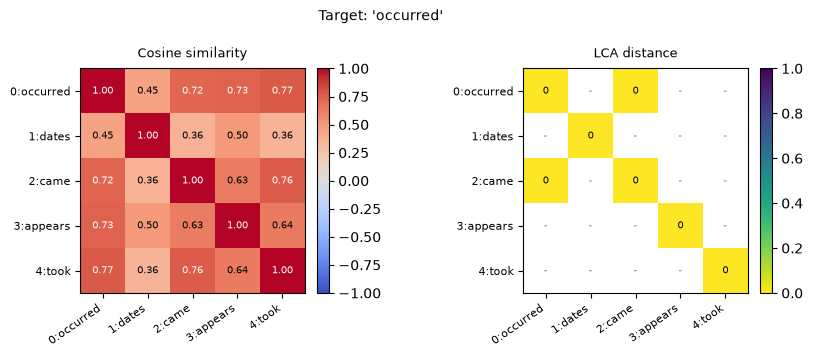


Context: 'The first recorded use of inoculation to prevent smallpox (see variolation) occurred in the' | Target: '16th'
Top-5        |    0:chinese |      1:court |     2:empire |   3:imperial |     4:courts
---------------------------------------------------------------------------------------
0:chinese    |       1.0000 |       0.5037 |       0.5611 |       0.6078 |       0.5465
1:court      |       0.5037 |       1.0000 |       0.6542 |       0.6812 |       0.8732
2:empire     |       0.5611 |       0.6542 |       1.0000 |       0.7414 |       0.6937
3:imperial   |       0.6078 |       0.6812 |       0.7414 |       1.0000 |       0.7026
4:courts     |       0.5465 |       0.8732 |       0.6937 |       0.7026 |       1.0000


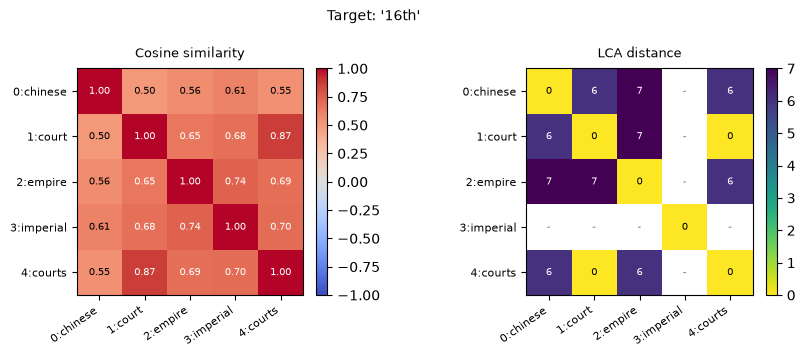


Context: 'The first recorded use of inoculation to prevent smallpox (see variolation) occurred in the 16th' | Target: 'century'
Top-5         |     0:century |        1:cent |           2:c |     3:dynasty |   4:centuries
---------------------------------------------------------------------------------------------
0:century     |        1.0000 |        0.6438 |        0.4873 |        0.7143 |        0.6410
1:cent        |        0.6438 |        1.0000 |        0.6077 |        0.7012 |        0.5056
2:c           |        0.4873 |        0.6077 |        1.0000 |        0.5786 |        0.3686
3:dynasty     |        0.7143 |        0.7012 |        0.5786 |        1.0000 |        0.5317
4:centuries   |        0.6410 |        0.5056 |        0.3686 |        0.5317 |        1.0000


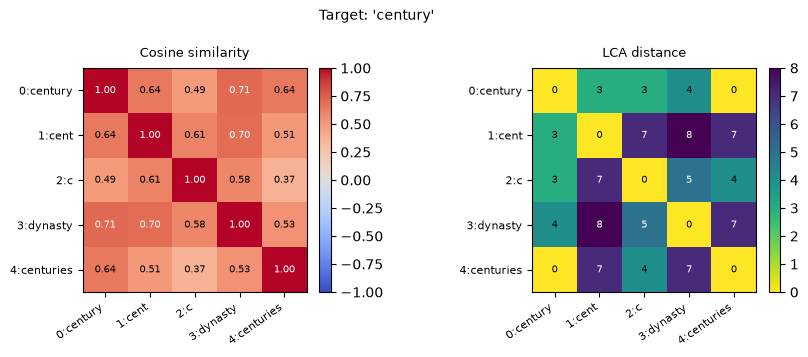


Context: 'The first recorded use of inoculation to prevent smallpox (see variolation) occurred in the 16th century in' | Target: 'China,'
Top-5        |      0:china |      1:india |     2:turkey |    3:chinese |   4:imperial
---------------------------------------------------------------------------------------
0:china      |       1.0000 |       0.7542 |       0.7632 |       0.8546 |       0.5996
1:india      |       0.7542 |       1.0000 |       0.6876 |       0.6667 |       0.5728
2:turkey     |       0.7632 |       0.6876 |       1.0000 |       0.6738 |       0.5304
3:chinese    |       0.8546 |       0.6667 |       0.6738 |       1.0000 |       0.6078
4:imperial   |       0.5996 |       0.5728 |       0.5304 |       0.6078 |       1.0000


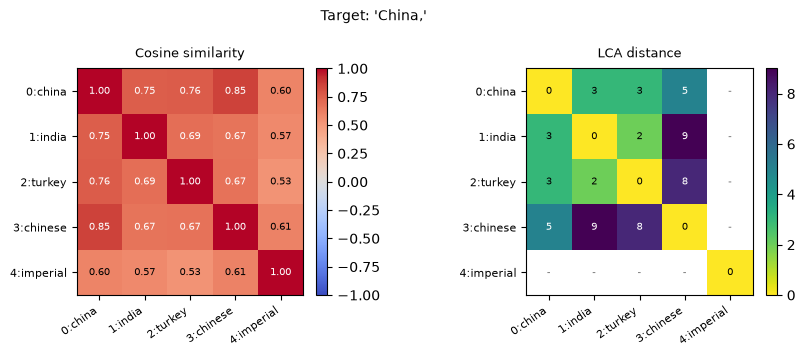


Context: 'The first recorded use of inoculation to prevent smallpox (see variolation) occurred in the 16th century in China, with the earliest' | Target: 'hints'
Top-5          |      0:mention |      1:chinese |     2:mentions |   3:references |      4:medical
---------------------------------------------------------------------------------------------------
0:mention      |         1.0000 |         0.5650 |         0.8365 |         0.5071 |         0.7036
1:chinese      |         0.5650 |         1.0000 |         0.5963 |         0.4792 |         0.5973
2:mentions     |         0.8365 |         0.5963 |         1.0000 |         0.6068 |         0.7019
3:references   |         0.5071 |         0.4792 |         0.6068 |         1.0000 |         0.4597
4:medical      |         0.7036 |         0.5973 |         0.7019 |         0.4597 |         1.0000


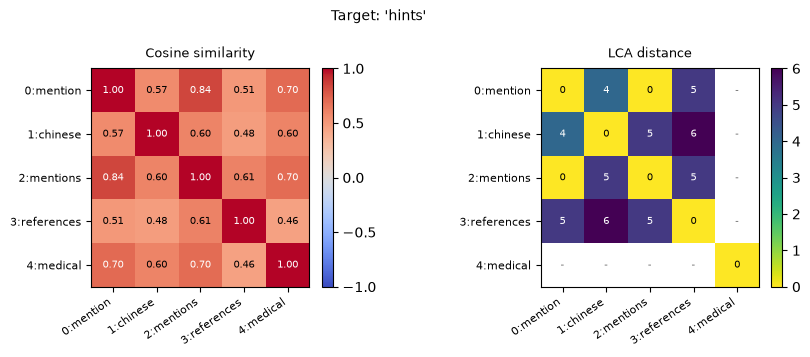


Context: 'The first recorded use of inoculation to prevent smallpox (see variolation) occurred in the 16th century in China, with the earliest hints of the' | Target: 'practice'
Top-5         |    0:practice |         1:use |   2:existence |   3:technique |   4:procedure
---------------------------------------------------------------------------------------------
0:practice    |        1.0000 |        0.7506 |        0.7540 |        0.7797 |        0.8071
1:use         |        0.7506 |        1.0000 |        0.6494 |        0.6695 |        0.7420
2:existence   |        0.7540 |        0.6494 |        1.0000 |        0.6521 |        0.7137
3:technique   |        0.7797 |        0.6695 |        0.6521 |        1.0000 |        0.7602
4:procedure   |        0.8071 |        0.7420 |        0.7137 |        0.7602 |        1.0000


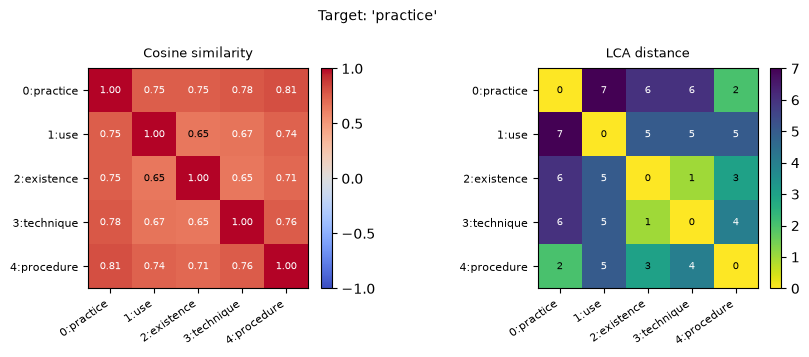


Context: 'The first recorded use of inoculation to prevent smallpox (see variolation) occurred in the 16th century in China, with the earliest hints of the practice in' | Target: 'China'
Top-5             |           0:china |           1:india |           2:japan |         3:chinese |   4:approximately
---------------------------------------------------------------------------------------------------------------------
0:china           |            1.0000 |            0.7542 |            0.7455 |            0.8546 |            0.4862
1:india           |            0.7542 |            1.0000 |            0.7370 |            0.6667 |            0.4449
2:japan           |            0.7455 |            0.7370 |            1.0000 |            0.6743 |            0.3877
3:chinese         |            0.8546 |            0.6667 |            0.6743 |            1.0000 |            0.4836
4:approximately   |            0.4862 |            0.4449 |            0.3877 |            0.4836 |     

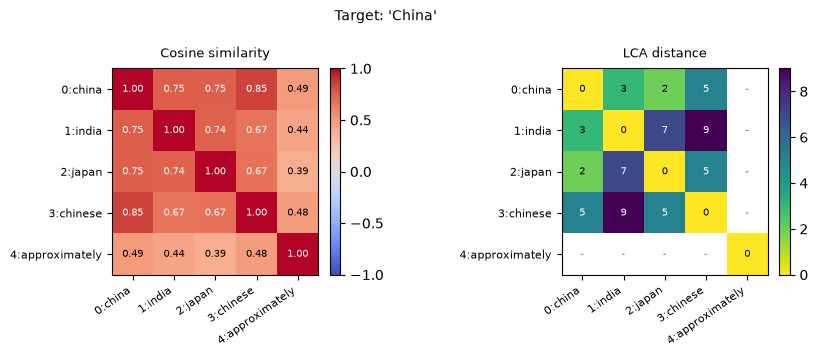


Context: 'The first recorded use of inoculation to prevent smallpox (see variolation) occurred in the 16th century in China, with the earliest hints of the practice in China' | Target: 'coming'
Top-5         |      0:dating |   1:appearing |       2:going |      3:around |       4:found
---------------------------------------------------------------------------------------------
0:dating      |        1.0000 |        0.7843 |        0.7750 |        0.7446 |        0.6630
1:appearing   |        0.7843 |        1.0000 |        0.7376 |        0.7294 |        0.7270
2:going       |        0.7750 |        0.7376 |        1.0000 |        0.6615 |        0.6966
3:around      |        0.7446 |        0.7294 |        0.6615 |        1.0000 |        0.6472
4:found       |        0.6630 |        0.7270 |        0.6966 |        0.6472 |        1.0000


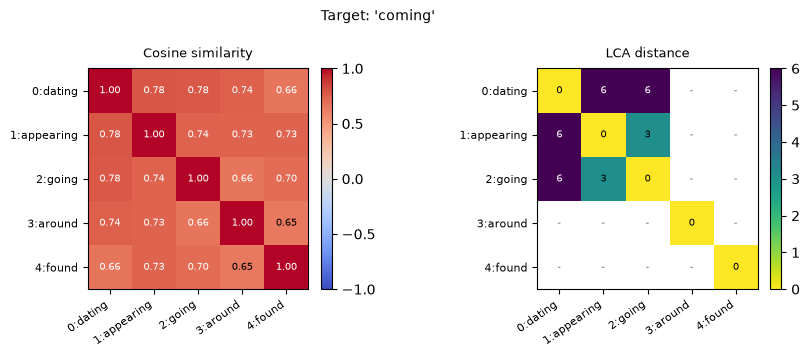


Context: 'The first recorded use of inoculation to prevent smallpox (see variolation) occurred in the 16th century in China, with the earliest hints of the practice in China coming during the' | Target: '10th'
Top-5        |     0:ming |    1:reign |     2:tang |      3:jin |      4:han
-----------------------------------------------------------------------------
0:ming       |     1.0000 |     0.5495 |     0.8010 |     0.8038 |     0.7719
1:reign      |     0.5495 |     1.0000 |     0.4778 |     0.5273 |     0.5600
2:tang       |     0.8010 |     0.4778 |     1.0000 |     0.7142 |     0.7050
3:jin        |     0.8038 |     0.5273 |     0.7142 |     1.0000 |     0.8127
4:han        |     0.7719 |     0.5600 |     0.7050 |     0.8127 |     1.0000


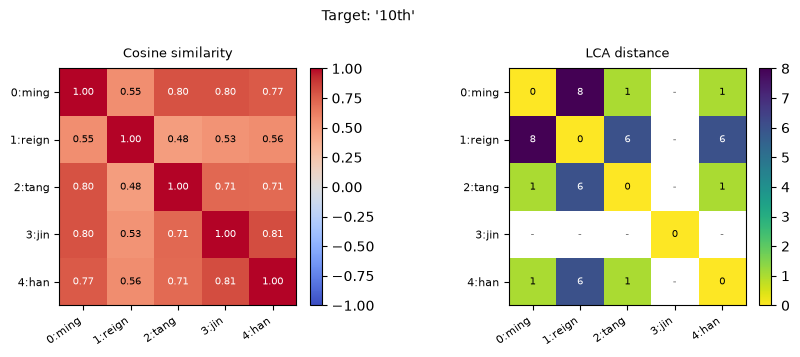


Context: 'The first recorded use of inoculation to prevent smallpox (see variolation) occurred in the 16th century in China, with the earliest hints of the practice in China coming during the 10th' | Target: 'century.'
Top-5         |     0:century |     1:dynasty |   2:centuries |         3:dyn |        4:cent
---------------------------------------------------------------------------------------------
0:century     |        1.0000 |        0.7143 |        0.6410 |        0.4612 |        0.6438
1:dynasty     |        0.7143 |        1.0000 |        0.5317 |        0.4764 |        0.7012
2:centuries   |        0.6410 |        0.5317 |        1.0000 |        0.4014 |        0.5056
3:dyn         |        0.4612 |        0.4764 |        0.4014 |        1.0000 |        0.4657
4:cent        |        0.6438 |        0.7012 |        0.5056 |        0.4657 |        1.0000


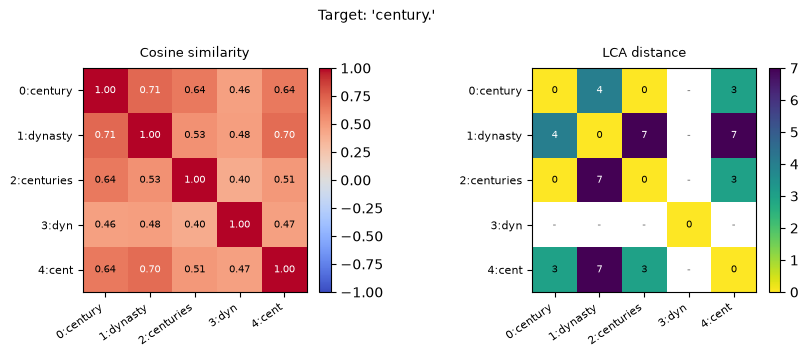


Context: 'It was also the' | Target: 'first'
Top-5        |    0:first |     1:year |     2:site |     3:case |     4:last
-----------------------------------------------------------------------------
0:first      |     1.0000 |     0.3854 |     0.4625 |     0.6006 |     0.7096
1:year       |     0.3854 |     1.0000 |     0.3570 |     0.3314 |     0.4455
2:site       |     0.4625 |     0.3570 |     1.0000 |     0.4838 |     0.5411
3:case       |     0.6006 |     0.3314 |     0.4838 |     1.0000 |     0.6734
4:last       |     0.7096 |     0.4455 |     0.5411 |     0.6734 |     1.0000


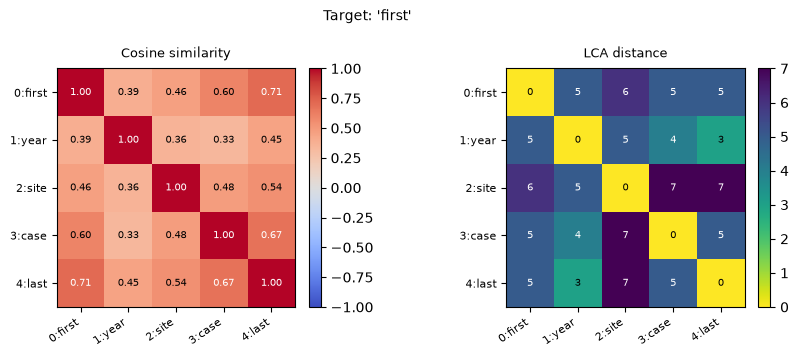


Context: 'It was also the first' | Target: 'disease'
Top-5        |     0:time |     1:year |      2:day |    3:major |     4:game
-----------------------------------------------------------------------------
0:time       |     1.0000 |     0.3898 |     0.6264 |     0.6128 |     0.6603
1:year       |     0.3898 |     1.0000 |     0.4697 |     0.3100 |     0.4000
2:day        |     0.6264 |     0.4697 |     1.0000 |     0.4726 |     0.5286
3:major      |     0.6128 |     0.3100 |     0.4726 |     1.0000 |     0.5613
4:game       |     0.6603 |     0.4000 |     0.5286 |     0.5613 |     1.0000


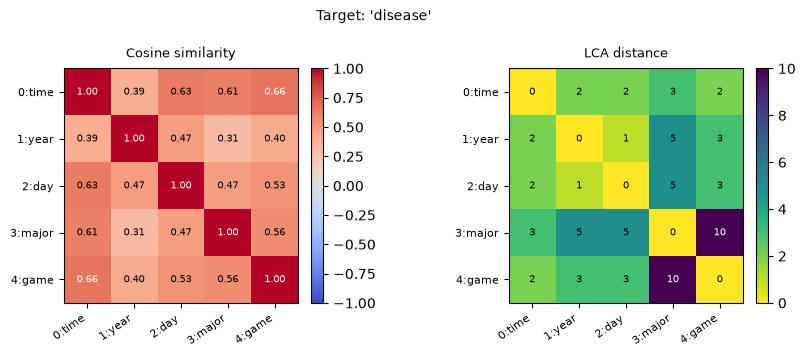


Context: 'It was also the first disease for which a' | Target: 'vaccine'
Top-5        |    0:vaccine |   1:specific |       2:drug |       3:cure |      4:virus
---------------------------------------------------------------------------------------
0:vaccine    |       1.0000 |       0.8715 |       0.7635 |       0.8782 |       0.8539
1:specific   |       0.8715 |       1.0000 |       0.7687 |       0.8394 |       0.7581
2:drug       |       0.7635 |       0.7687 |       1.0000 |       0.7710 |       0.7502
3:cure       |       0.8782 |       0.8394 |       0.7710 |       1.0000 |       0.8093
4:virus      |       0.8539 |       0.7581 |       0.7502 |       0.8093 |       1.0000


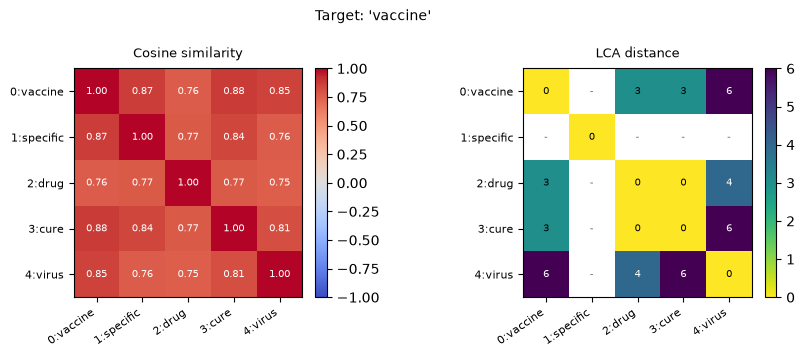


Context: 'It was also the first disease for which a vaccine was' | Target: 'produced.'
Top-5            |   0:successfully |        1:created |       2:produced |           3:ever |          4:found
---------------------------------------------------------------------------------------------------------------
0:successfully   |           1.0000 |           0.7066 |           0.5760 |           0.5326 |           0.6772
1:created        |           0.7066 |           1.0000 |           0.7402 |           0.5338 |           0.7007
2:produced       |           0.5760 |           0.7402 |           1.0000 |           0.4110 |           0.5957
3:ever           |           0.5326 |           0.5338 |           0.4110 |           1.0000 |           0.4996
4:found          |           0.6772 |           0.7007 |           0.5957 |           0.4996 |           1.0000


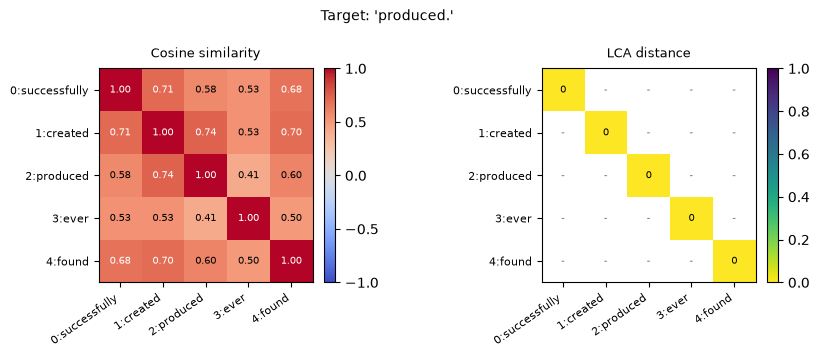


Context: 'The' | Target: 'folk'
Top-5         |   0:following |         1:sum |      2:purple |    3:function |      4:number
---------------------------------------------------------------------------------------------
0:following   |        1.0000 |        0.5209 |        0.5680 |        0.4828 |        0.5987
1:sum         |        0.5209 |        1.0000 |        0.5980 |        0.6384 |        0.6528
2:purple      |        0.5680 |        0.5980 |        1.0000 |        0.5516 |        0.7352
3:function    |        0.4828 |        0.6384 |        0.5516 |        1.0000 |        0.6338
4:number      |        0.5987 |        0.6528 |        0.7352 |        0.6338 |        1.0000


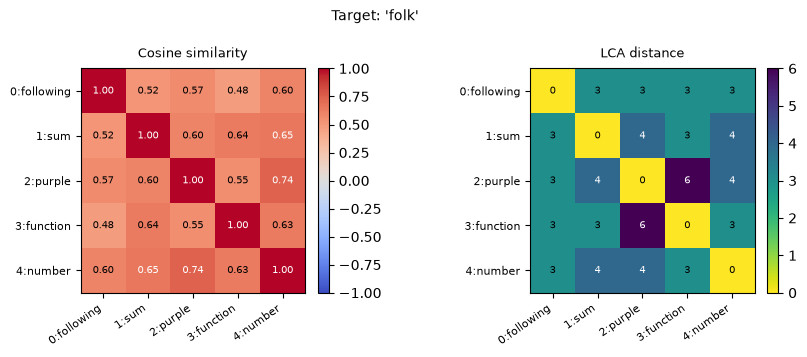


Context: 'The folk' | Target: 'practice'
Top-5        |     0:songs |      1:song |     2:music |   3:stories |       4:art
----------------------------------------------------------------------------------
0:songs      |      1.0000 |      0.7526 |      0.6976 |      0.5761 |      0.5331
1:song       |      0.7526 |      1.0000 |      0.7009 |      0.6464 |      0.6266
2:music      |      0.6976 |      0.7009 |      1.0000 |      0.5612 |      0.6518
3:stories    |      0.5761 |      0.6464 |      0.5612 |      1.0000 |      0.6022
4:art        |      0.5331 |      0.6266 |      0.6518 |      0.6022 |      1.0000


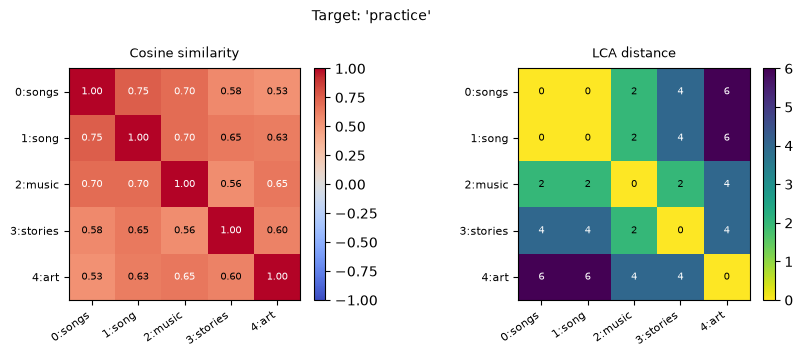


Context: 'The folk practice of' | Target: 'inoculation'
Top-5        |    0:making |   1:wearing |   2:burning |     3:using |    4:eating
----------------------------------------------------------------------------------
0:making     |      1.0000 |      0.8639 |      0.8202 |      0.7321 |      0.8468
1:wearing    |      0.8639 |      1.0000 |      0.7998 |      0.6899 |      0.8374
2:burning    |      0.8202 |      0.7998 |      1.0000 |      0.6237 |      0.8523
3:using      |      0.7321 |      0.6899 |      0.6237 |      1.0000 |      0.6599
4:eating     |      0.8468 |      0.8374 |      0.8523 |      0.6599 |      1.0000


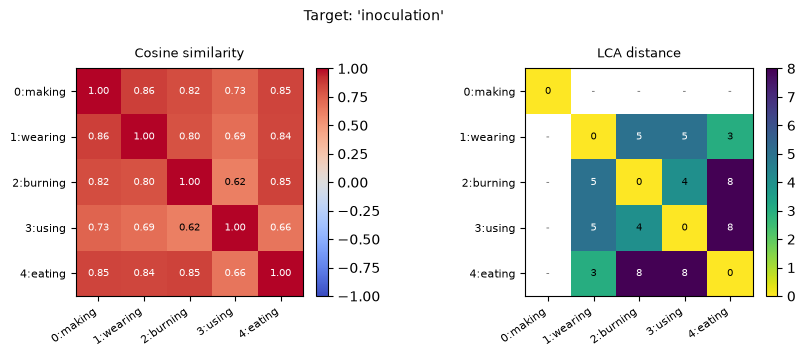


Context: 'The folk practice of inoculation against' | Target: 'smallpox'
Top-5        |      0:small |    1:disease |   2:diseases |    3:illness |    4:measles
---------------------------------------------------------------------------------------
0:small      |       1.0000 |       0.6132 |       0.5202 |       0.5730 |       0.1741
1:disease    |       0.6132 |       1.0000 |       0.9017 |       0.8748 |       0.3404
2:diseases   |       0.5202 |       0.9017 |       1.0000 |       0.8255 |       0.4085
3:illness    |       0.5730 |       0.8748 |       0.8255 |       1.0000 |       0.3798
4:measles    |       0.1741 |       0.3404 |       0.4085 |       0.3798 |       1.0000


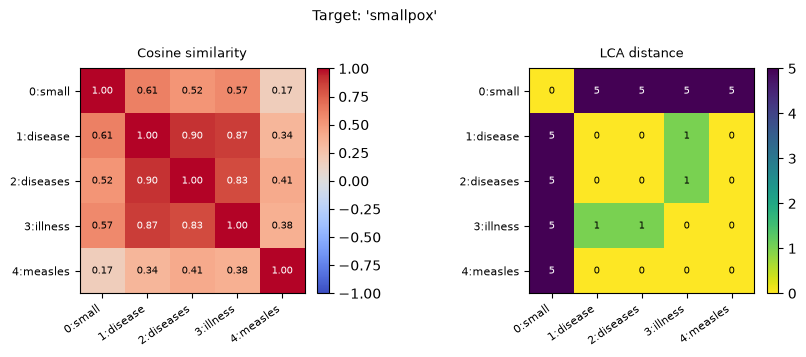


Context: 'The folk practice of inoculation against smallpox was' | Target: 'brought'
Top-5          |   0:introduced |        1:first |      2:brought |       3:widely |       4:common
---------------------------------------------------------------------------------------------------
0:introduced   |         1.0000 |         0.5698 |         0.6979 |         0.7257 |         0.7194
1:first        |         0.5698 |         1.0000 |         0.6250 |         0.5721 |         0.5763
2:brought      |         0.6979 |         0.6250 |         1.0000 |         0.6806 |         0.6494
3:widely       |         0.7257 |         0.5721 |         0.6806 |         1.0000 |         0.7987
4:common       |         0.7194 |         0.5763 |         0.6494 |         0.7987 |         1.0000


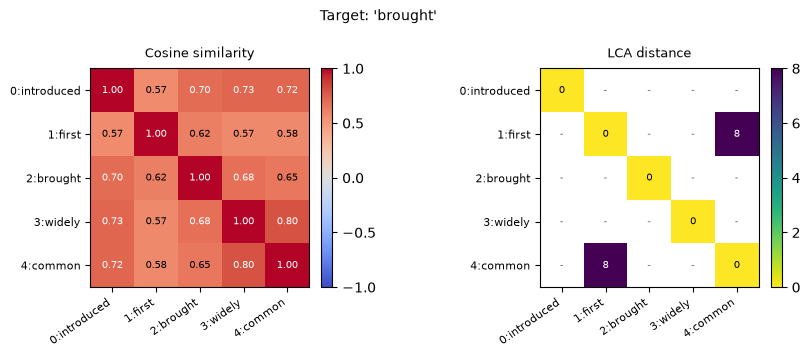


Context: 'The folk practice of inoculation against smallpox was brought from' | Target: 'Turkey'
Top-5          |        0:china |        1:india |       2:turkey |         3:asia |   4:constantin
---------------------------------------------------------------------------------------------------
0:china        |         1.0000 |         0.7542 |         0.7632 |         0.7798 |         0.6125
1:india        |         0.7542 |         1.0000 |         0.6876 |         0.7633 |         0.5898
2:turkey       |         0.7632 |         0.6876 |         1.0000 |         0.6913 |         0.5820
3:asia         |         0.7798 |         0.7633 |         0.6913 |         1.0000 |         0.6098
4:constantin   |         0.6125 |         0.5898 |         0.5820 |         0.6098 |         1.0000


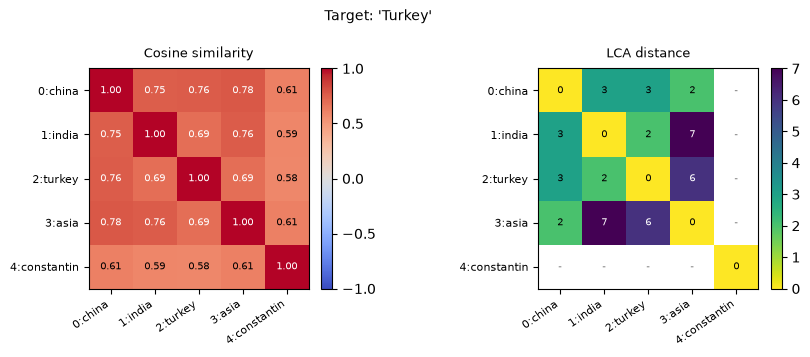


Context: 'The folk practice of inoculation against smallpox was brought from Turkey to' | Target: 'Britain'
Top-5        |    0:europe |   1:england |   2:britain |    3:london |     4:china
----------------------------------------------------------------------------------
0:europe     |      1.0000 |      0.5793 |      0.5851 |      0.5739 |      0.5657
1:england    |      0.5793 |      1.0000 |      0.6237 |      0.5799 |      0.5575
2:britain    |      0.5851 |      0.6237 |      1.0000 |      0.5688 |      0.4042
3:london     |      0.5739 |      0.5799 |      0.5688 |      1.0000 |      0.6033
4:china      |      0.5657 |      0.5575 |      0.4042 |      0.6033 |      1.0000


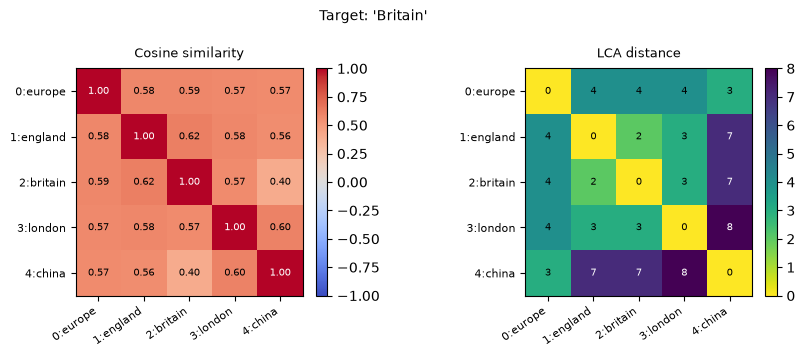


Context: 'The folk practice of inoculation against smallpox was brought from Turkey to Britain in 1721 by' | Target: 'Lady'
Top-5        |     0:lady |       1:dr |      2:mrs |     3:mary |   4:edward
-----------------------------------------------------------------------------
0:lady       |     1.0000 |     0.6262 |     0.7566 |     0.7681 |     0.6869
1:dr         |     0.6262 |     1.0000 |     0.8018 |     0.6798 |     0.6552
2:mrs        |     0.7566 |     0.8018 |     1.0000 |     0.8020 |     0.7190
3:mary       |     0.7681 |     0.6798 |     0.8020 |     1.0000 |     0.7623
4:edward     |     0.6869 |     0.6552 |     0.7190 |     0.7623 |     1.0000


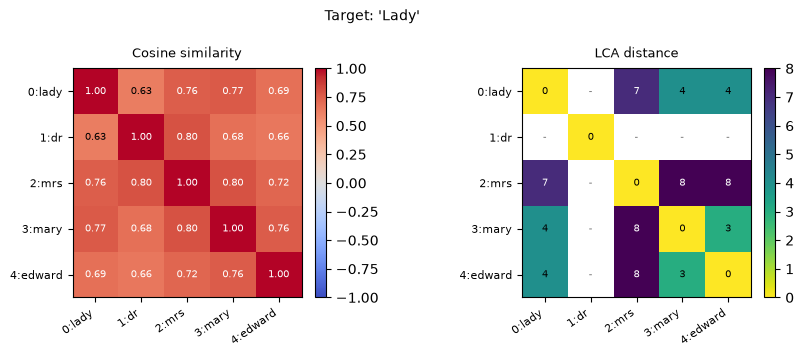


Context: 'The folk practice of inoculation against smallpox was brought from Turkey to Britain in 1721 by Lady' | Target: 'Mary'
Top-5        |     0:mary |     1:mont |        2:j |     3:wort |     4:anne
-----------------------------------------------------------------------------
0:mary       |     1.0000 |     0.7610 |     0.6225 |     0.4204 |     0.8286
1:mont       |     0.7610 |     1.0000 |     0.6812 |     0.3675 |     0.7615
2:j          |     0.6225 |     0.6812 |     1.0000 |     0.2788 |     0.6631
3:wort       |     0.4204 |     0.3675 |     0.2788 |     1.0000 |     0.3889
4:anne       |     0.8286 |     0.7615 |     0.6631 |     0.3889 |     1.0000


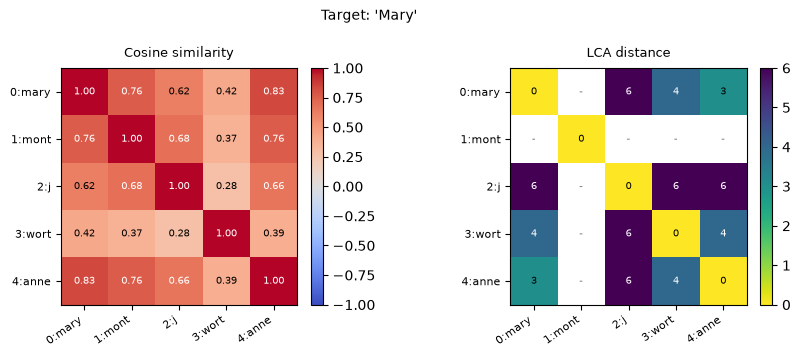


Context: 'The folk practice of inoculation against smallpox was brought from Turkey to Britain in 1721 by Lady Mary' | Target: 'Wortley'
Top-5        |     0:wort |     1:mont |        2:w |      3:cav |      4:sav
-----------------------------------------------------------------------------
0:wort       |     1.0000 |     0.3675 |     0.3829 |     0.4089 |     0.4560
1:mont       |     0.3675 |     1.0000 |     0.6408 |     0.5495 |     0.5442
2:w          |     0.3829 |     0.6408 |     1.0000 |     0.5210 |     0.4884
3:cav        |     0.4089 |     0.5495 |     0.5210 |     1.0000 |     0.7377
4:sav        |     0.4560 |     0.5442 |     0.4884 |     0.7377 |     1.0000


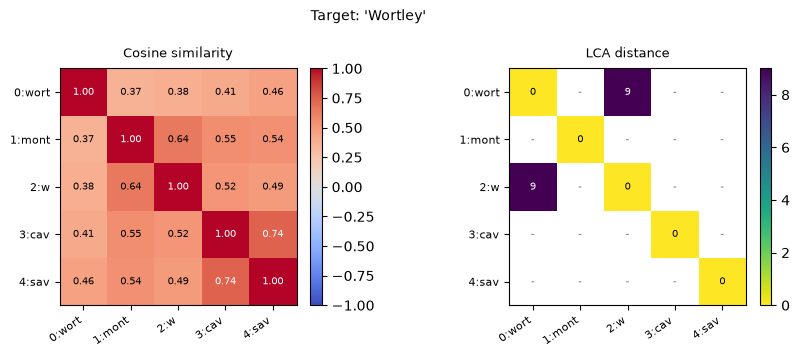


Context: 'The folk practice of inoculation against smallpox was brought from Turkey to Britain in 1721 by Lady Mary Wortley' | Target: 'Montagu.'
Top-5        |     0:mont |      1:mon |      2:pon |    3:monte |   4:morton
-----------------------------------------------------------------------------
0:mont       |     1.0000 |     0.7681 |     0.5787 |     0.7705 |     0.7768
1:mon        |     0.7681 |     1.0000 |     0.5519 |     0.6554 |     0.7328
2:pon        |     0.5787 |     0.5519 |     1.0000 |     0.5946 |     0.5566
3:monte      |     0.7705 |     0.6554 |     0.5946 |     1.0000 |     0.6636
4:morton     |     0.7768 |     0.7328 |     0.5566 |     0.6636 |     1.0000


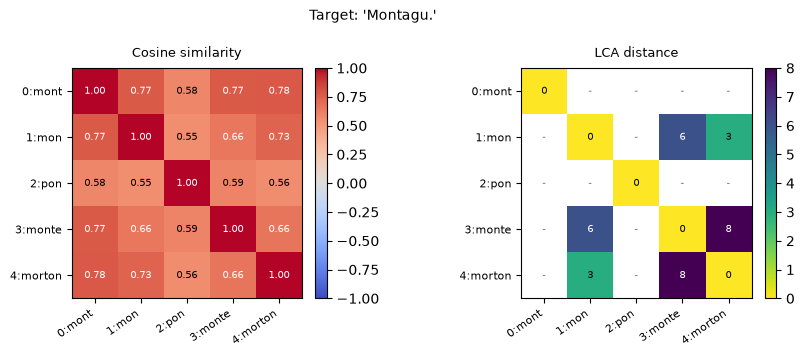


Context: 'The' | Target: 'terms'
Top-5         |   0:following |         1:sum |      2:purple |    3:function |      4:number
---------------------------------------------------------------------------------------------
0:following   |        1.0000 |        0.5209 |        0.5680 |        0.4828 |        0.5987
1:sum         |        0.5209 |        1.0000 |        0.5980 |        0.6384 |        0.6528
2:purple      |        0.5680 |        0.5980 |        1.0000 |        0.5516 |        0.7352
3:function    |        0.4828 |        0.6384 |        0.5516 |        1.0000 |        0.6338
4:number      |        0.5987 |        0.6528 |        0.7352 |        0.6338 |        1.0000


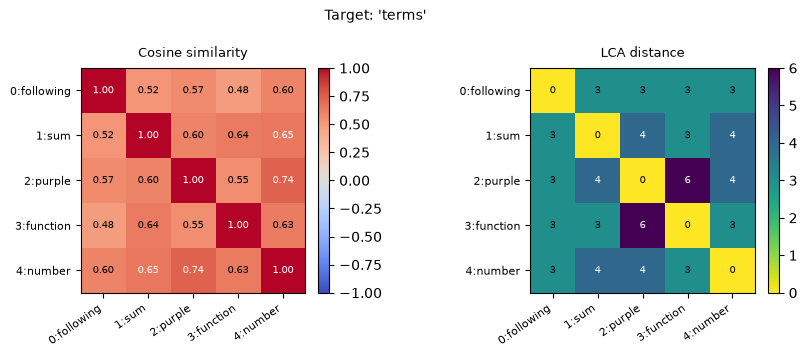


Context: 'The terms' | Target: 'vaccine'
Top-5        |        0:b |        1:c |        2:e |        3:p |      4:sum
-----------------------------------------------------------------------------
0:b          |     1.0000 |     0.7311 |     0.7545 |     0.4080 |     0.5244
1:c          |     0.7311 |     1.0000 |     0.7764 |     0.4837 |     0.5352
2:e          |     0.7545 |     0.7764 |     1.0000 |     0.4713 |     0.5618
3:p          |     0.4080 |     0.4837 |     0.4713 |     1.0000 |     0.4345
4:sum        |     0.5244 |     0.5352 |     0.5618 |     0.4345 |     1.0000


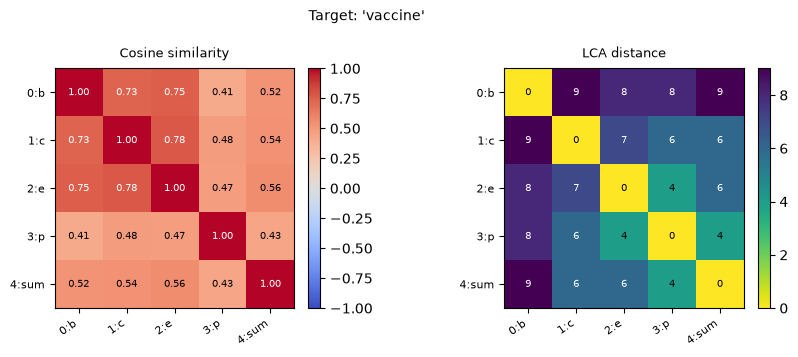


Context: 'The terms vaccine and' | Target: 'vaccination'
Top-5           |          0:inoc |   1:vaccination |         2:immun |      3:immunity |       4:vaccine
---------------------------------------------------------------------------------------------------------
0:inoc          |          1.0000 |          0.3868 |          0.5164 |          0.4507 |          0.6044
1:vaccination   |          0.3868 |          1.0000 |          0.5666 |          0.4113 |          0.4347
2:immun         |          0.5164 |          0.5666 |          1.0000 |          0.4228 |          0.4980
3:immunity      |          0.4507 |          0.4113 |          0.4228 |          1.0000 |          0.5608
4:vaccine       |          0.6044 |          0.4347 |          0.4980 |          0.5608 |          1.0000


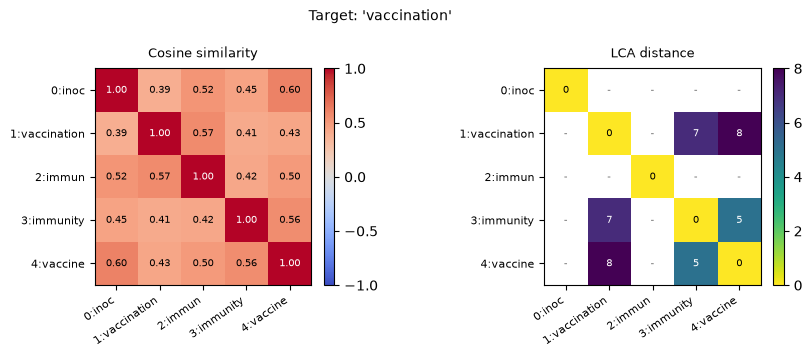


Context: 'The terms vaccine and vaccination are derived from' | Target: 'Variolae'
Top-5        |     0:vari |     1:vacc |    2:small |    3:latin |    4:louis
-----------------------------------------------------------------------------
0:vari       |     1.0000 |     0.5520 |     0.5025 |     0.5005 |     0.4580
1:vacc       |     0.5520 |     1.0000 |     0.4522 |     0.4919 |     0.5068
2:small      |     0.5025 |     0.4522 |     1.0000 |     0.5967 |     0.6481
3:latin      |     0.5005 |     0.4919 |     0.5967 |     1.0000 |     0.5994
4:louis      |     0.4580 |     0.5068 |     0.6481 |     0.5994 |     1.0000


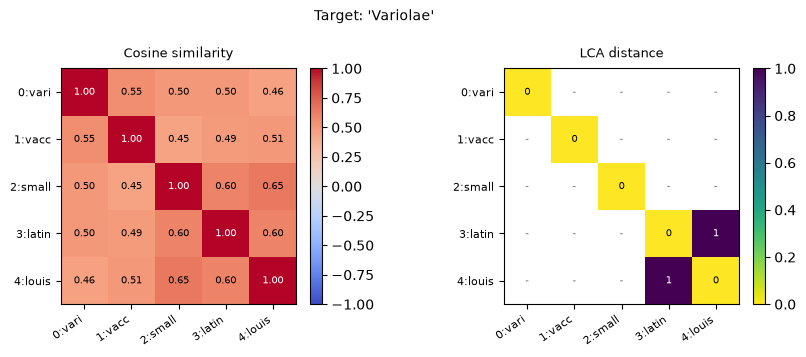


Context: 'The terms vaccine and vaccination are derived from Variolae' | Target: 'vaccinae'
Top-5           |          0:vacc |       1:vaccine |            2:疫苗 |   3:vaccination |           4:vac
---------------------------------------------------------------------------------------------------------
0:vacc          |          1.0000 |          0.5615 |          0.3602 |          0.3517 |          0.8458
1:vaccine       |          0.5615 |          1.0000 |          0.5414 |          0.4347 |          0.5307
2:疫苗            |          0.3602 |          0.5414 |          1.0000 |          0.3715 |          0.3059
3:vaccination   |          0.3517 |          0.4347 |          0.3715 |          1.0000 |          0.3002
4:vac           |          0.8458 |          0.5307 |          0.3059 |          0.3002 |          1.0000


/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 30123 (\N{CJK UNIFIED IDEOGRAPH-75AB}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 33495 (\N{CJK UNIFIED IDEOGRAPH-82D7}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 30123 (\N{CJK UNIFIED IDEOGRAPH-75AB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 33495 (\N{CJK UNIFIED IDEOGRAPH-82D7}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


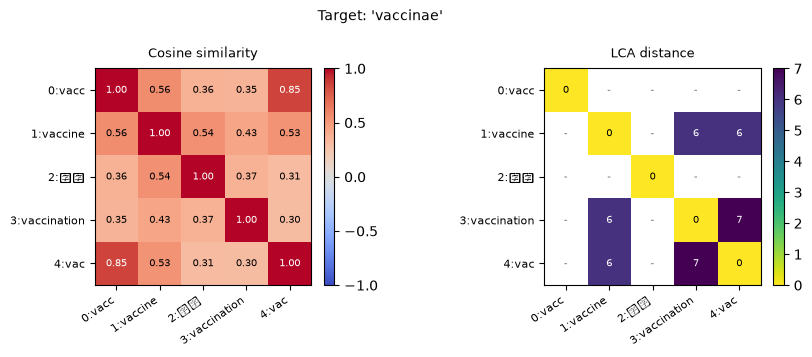


Context: 'The terms vaccine and vaccination are derived from Variolae vaccinae' | Target: '(smallpox'
Top-5        |     0:latin |   1:meaning |         2:l |        3:拉丁 |       4:lat
----------------------------------------------------------------------------------
0:latin      |      1.0000 |      0.5726 |      0.5933 |      0.5019 |      0.4808
1:meaning    |      0.5726 |      1.0000 |      0.7155 |      0.5559 |      0.4710
2:l          |      0.5933 |      0.7155 |      1.0000 |      0.5362 |      0.5443
3:拉丁         |      0.5019 |      0.5559 |      0.5362 |      1.0000 |      0.3906
4:lat        |      0.4808 |      0.4710 |      0.5443 |      0.3906 |      1.0000


/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 25289 (\N{CJK UNIFIED IDEOGRAPH-62C9}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 19969 (\N{CJK UNIFIED IDEOGRAPH-4E01}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 25289 (\N{CJK UNIFIED IDEOGRAPH-62C9}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 19969 (\N{CJK UNIFIED IDEOGRAPH-4E01}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


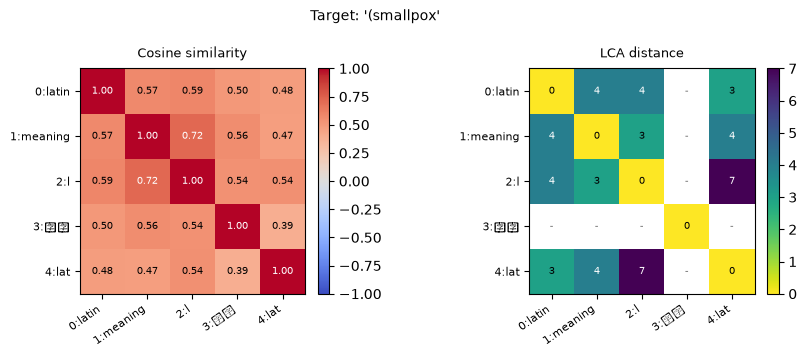


Context: 'The terms vaccine and vaccination are derived from Variolae vaccinae (smallpox of the' | Target: 'cow),'
Top-5        |      0:cow |     1:cows |   2:cattle |        3:牛 |    4:sheep
-----------------------------------------------------------------------------
0:cow        |     1.0000 |     0.6790 |     0.6035 |     0.6816 |     0.6626
1:cows       |     0.6790 |     1.0000 |     0.8846 |     0.5794 |     0.8654
2:cattle     |     0.6035 |     0.8846 |     1.0000 |     0.4880 |     0.8653
3:牛          |     0.6816 |     0.5794 |     0.4880 |     1.0000 |     0.5624
4:sheep      |     0.6626 |     0.8654 |     0.8653 |     0.5624 |     1.0000


/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 29275 (\N{CJK UNIFIED IDEOGRAPH-725B}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 29275 (\N{CJK UNIFIED IDEOGRAPH-725B}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


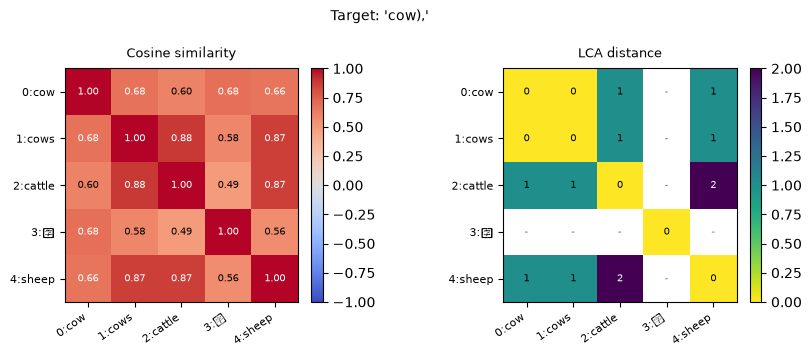


Context: 'The terms vaccine and vaccination are derived from Variolae vaccinae (smallpox of the cow), the' | Target: 'term'
Top-5         |        0:term |   1:induction |     2:disease |    3:inducing |         4:cow
---------------------------------------------------------------------------------------------
0:term        |        1.0000 |        0.6755 |        0.6056 |        0.6362 |        0.6518
1:induction   |        0.6755 |        1.0000 |        0.6783 |        0.7215 |        0.7144
2:disease     |        0.6056 |        0.6783 |        1.0000 |        0.6436 |        0.6514
3:inducing    |        0.6362 |        0.7215 |        0.6436 |        1.0000 |        0.7766
4:cow         |        0.6518 |        0.7144 |        0.6514 |        0.7766 |        1.0000


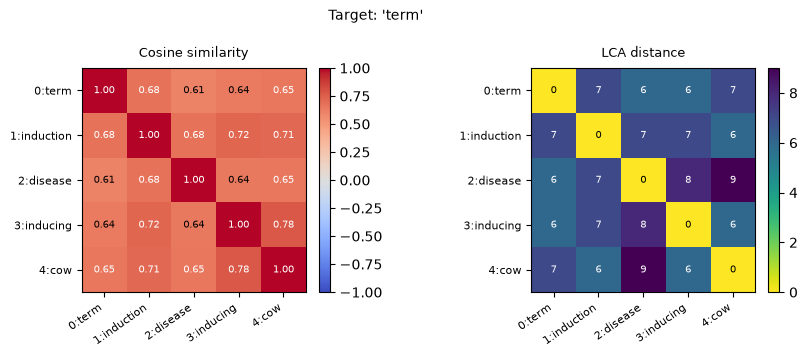


Context: 'The terms vaccine and vaccination are derived from Variolae vaccinae (smallpox of the cow), the term' | Target: 'devised'
Top-5          |      0:devised |        1:first |      2:created |   3:originally |        4:given
---------------------------------------------------------------------------------------------------
0:devised      |         1.0000 |         0.5562 |         0.8020 |         0.7358 |         0.7822
1:first        |         0.5562 |         1.0000 |         0.5336 |         0.6275 |         0.5947
2:created      |         0.8020 |         0.5336 |         1.0000 |         0.7592 |         0.7118
3:originally   |         0.7358 |         0.6275 |         0.7592 |         1.0000 |         0.7008
4:given        |         0.7822 |         0.5947 |         0.7118 |         0.7008 |         1.0000


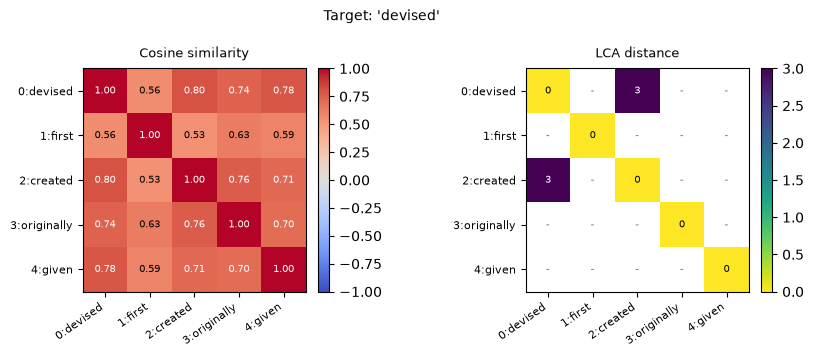


Context: 'The terms vaccine and vaccination are derived from Variolae vaccinae (smallpox of the cow), the term devised by' | Target: 'Edward'
Top-5        |     0:edward |    1:english |     2:jenner |    3:british |   4:scottish
---------------------------------------------------------------------------------------
0:edward     |       1.0000 |       0.5767 |       0.5123 |       0.3414 |       0.5169
1:english    |       0.5767 |       1.0000 |       0.4012 |       0.4762 |       0.6035
2:jenner     |       0.5123 |       0.4012 |       1.0000 |       0.2639 |       0.3707
3:british    |       0.3414 |       0.4762 |       0.2639 |       1.0000 |       0.4293
4:scottish   |       0.5169 |       0.6035 |       0.3707 |       0.4293 |       1.0000


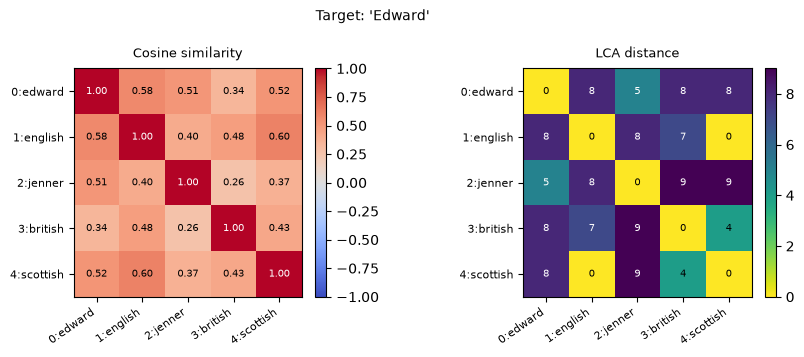


Context: 'The terms vaccine and vaccination are derived from Variolae vaccinae (smallpox of the cow), the term devised by Edward' | Target: 'Jenner'
Top-5        |   0:jenner |     1:jenn |        2:j |        3:詹 |        4:琴
-----------------------------------------------------------------------------
0:jenner     |     1.0000 |     0.7052 |     0.4244 |     0.3613 |     0.3613
1:jenn       |     0.7052 |     1.0000 |     0.4552 |     0.4122 |     0.4122
2:j          |     0.4244 |     0.4552 |     1.0000 |     0.6305 |     0.6305
3:詹          |     0.3613 |     0.4122 |     0.6305 |     1.0000 |     1.0000
4:琴          |     0.3613 |     0.4122 |     0.6305 |     1.0000 |     1.0000


/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 35449 (\N{CJK UNIFIED IDEOGRAPH-8A79}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 29748 (\N{CJK UNIFIED IDEOGRAPH-7434}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 35449 (\N{CJK UNIFIED IDEOGRAPH-8A79}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 29748 (\N{CJK UNIFIED IDEOGRAPH-7434}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


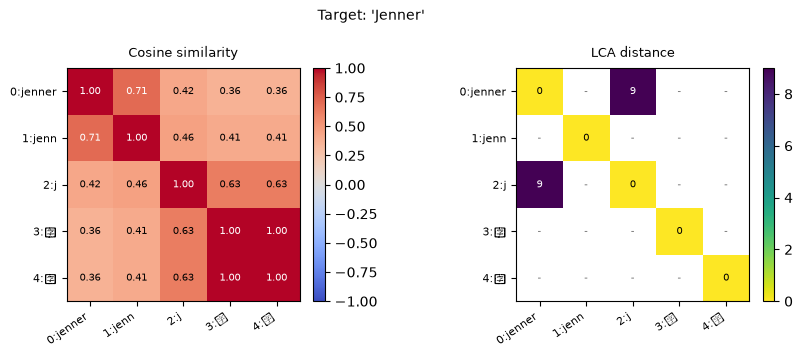


Context: 'The terms vaccine and vaccination are derived from Variolae vaccinae (smallpox of the cow), the term devised by Edward Jenner (who both developed the' | Target: 'concept'
Top-5        |     0:small |     1:first |   2:vaccine |      3:term |       4:cow
----------------------------------------------------------------------------------
0:small      |      1.0000 |      0.5890 |      0.6812 |      0.6077 |      0.6791
1:first      |      0.5890 |      1.0000 |      0.5626 |      0.5372 |      0.5751
2:vaccine    |      0.6812 |      0.5626 |      1.0000 |      0.6721 |      0.8295
3:term       |      0.6077 |      0.5372 |      0.6721 |      1.0000 |      0.6518
4:cow        |      0.6791 |      0.5751 |      0.8295 |      0.6518 |      1.0000


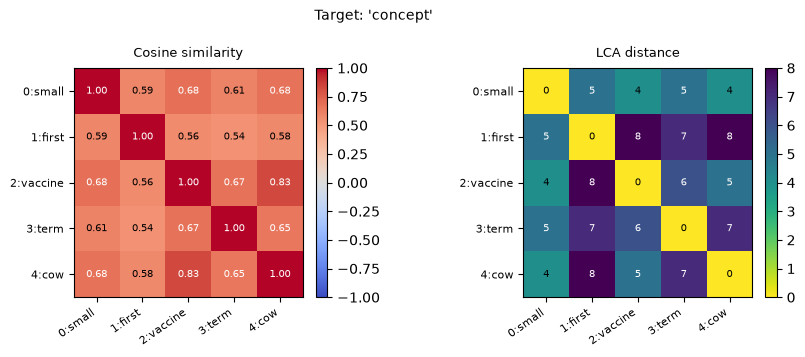


Context: 'The terms vaccine and vaccination are derived from Variolae vaccinae (smallpox of the cow), the term devised by Edward Jenner (who both developed the concept of' | Target: 'vaccines'
Top-5           |   0:vaccination |           1:cow |         2:using |       3:vaccine |          4:vacc
---------------------------------------------------------------------------------------------------------
0:vaccination   |          1.0000 |          0.2613 |          0.2884 |          0.4347 |          0.3517
1:cow           |          0.2613 |          1.0000 |          0.6976 |          0.8295 |          0.5120
2:using         |          0.2884 |          0.6976 |          1.0000 |          0.7091 |          0.4756
3:vaccine       |          0.4347 |          0.8295 |          0.7091 |          1.0000 |          0.5615
4:vacc          |          0.3517 |          0.5120 |          0.4756 |          0.5615 |          1.0000


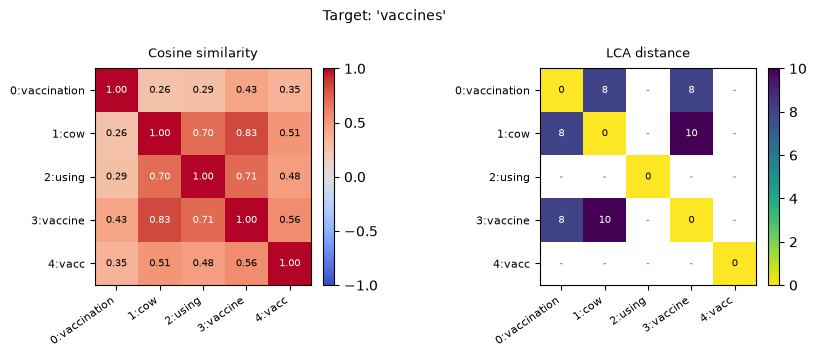


Context: 'The terms vaccine and vaccination are derived from Variolae vaccinae (smallpox of the cow), the term devised by Edward Jenner (who both developed the concept of vaccines and' | Target: 'created'
Top-5          |       0:coined |   1:introduced |    2:pioneered |      3:created |     4:invented
---------------------------------------------------------------------------------------------------
0:coined       |         1.0000 |         0.7598 |         0.8360 |         0.8245 |         0.8607
1:introduced   |         0.7598 |         1.0000 |         0.7616 |         0.7860 |         0.8472
2:pioneered    |         0.8360 |         0.7616 |         1.0000 |         0.7627 |         0.8577
3:created      |         0.8245 |         0.7860 |         0.7627 |         1.0000 |         0.8532
4:invented     |         0.8607 |         0.8472 |         0.8577 |         0.8532 |         1.0000


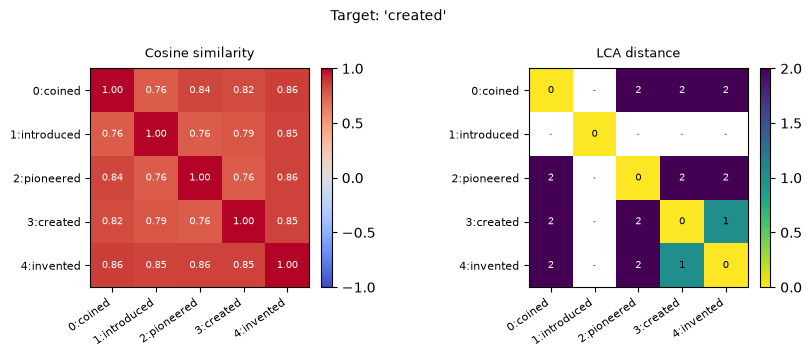


Context: 'The terms vaccine and vaccination are derived from Variolae vaccinae (smallpox of the cow), the term devised by Edward Jenner (who both developed the concept of vaccines and created the' | Target: 'first'
Top-5        |     0:first |   1:vaccine |     2:world |    3:worlds |      4:term
----------------------------------------------------------------------------------
0:first      |      1.0000 |      0.5626 |      0.5761 |      0.5772 |      0.5372
1:vaccine    |      0.5626 |      1.0000 |      0.6348 |      0.6325 |      0.6721
2:world      |      0.5761 |      0.6348 |      1.0000 |      0.7666 |      0.6188
3:worlds     |      0.5772 |      0.6325 |      0.7666 |      1.0000 |      0.5674
4:term       |      0.5372 |      0.6721 |      0.6188 |      0.5674 |      1.0000


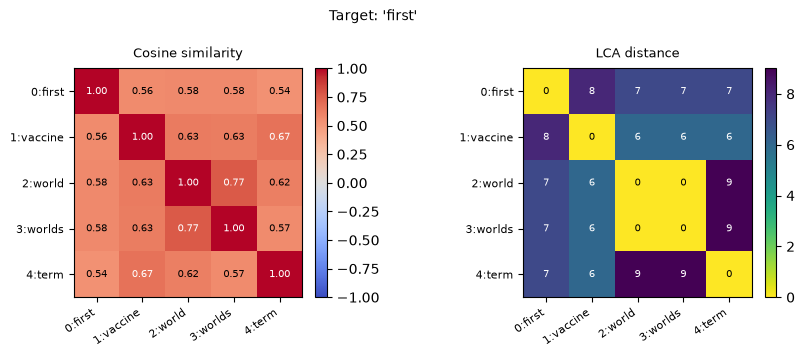


Context: 'The terms vaccine and vaccination are derived from Variolae vaccinae (smallpox of the cow), the term devised by Edward Jenner (who both developed the concept of vaccines and created the first' | Target: 'vaccine)'
Top-5           |       0:vaccine |         1:small |          2:true |   3:vaccination |           4:cow
---------------------------------------------------------------------------------------------------------
0:vaccine       |          1.0000 |          0.6812 |          0.5486 |          0.4347 |          0.8295
1:small         |          0.6812 |          1.0000 |          0.5518 |          0.3550 |          0.6791
2:true          |          0.5486 |          0.5518 |          1.0000 |          0.2939 |          0.5845
3:vaccination   |          0.4347 |          0.3550 |          0.2939 |          1.0000 |          0.2613
4:cow           |          0.8295 |          0.6791 |          0.5845 |          0.2613 |          1.0000


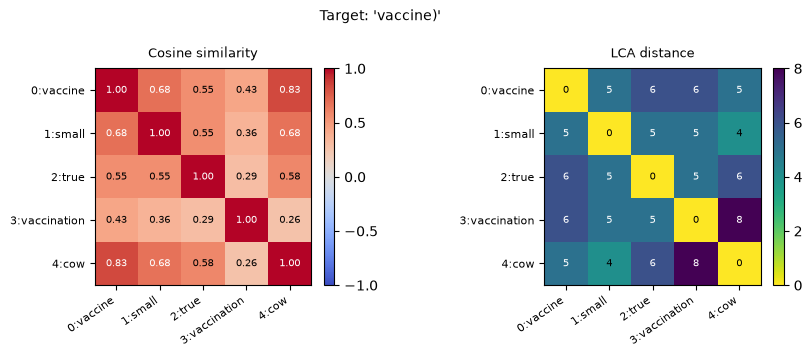


Context: 'The terms vaccine and vaccination are derived from Variolae vaccinae (smallpox of the cow), the term devised by Edward Jenner (who both developed the concept of vaccines and created the first vaccine) to' | Target: 'denote'
Top-5             |     0:distinguish |          1:denote |        2:describe |   3:differentiate |       4:designate
---------------------------------------------------------------------------------------------------------------------
0:distinguish     |            1.0000 |            0.6768 |            0.8309 |            0.9368 |            0.7046
1:denote          |            0.6768 |            1.0000 |            0.7371 |            0.7230 |            0.6829
2:describe        |            0.8309 |            0.7371 |            1.0000 |            0.8151 |            0.7216
3:differentiate   |            0.9368 |            0.7230 |            0.8151 |            1.0000 |            0.7473
4:designate       |            0.7046 |            0.6829

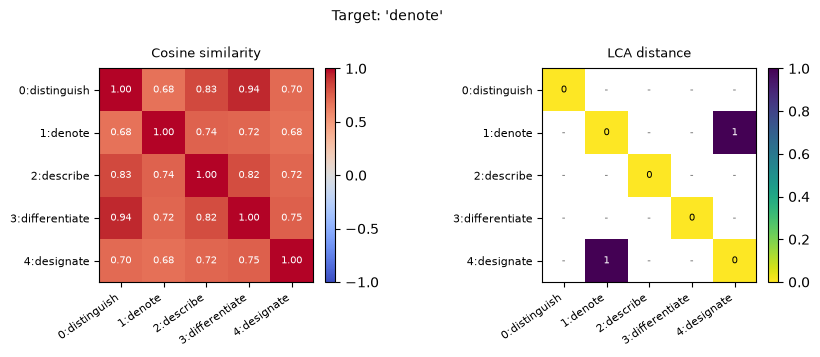


Context: 'The terms vaccine and vaccination are derived from Variolae vaccinae (smallpox of the cow), the term devised by Edward Jenner (who both developed the concept of vaccines and created the first vaccine) to denote' | Target: 'cowpox.'
Top-5         |         0:cow |    1:material |   2:infection |       3:small |     4:lesions
---------------------------------------------------------------------------------------------
0:cow         |        1.0000 |        0.5406 |        0.7557 |        0.6791 |        0.7949
1:material    |        0.5406 |        1.0000 |        0.5689 |        0.5127 |        0.5703
2:infection   |        0.7557 |        0.5689 |        1.0000 |        0.6512 |        0.8789
3:small       |        0.6791 |        0.5127 |        0.6512 |        1.0000 |        0.6962
4:lesions     |        0.7949 |        0.5703 |        0.8789 |        0.6962 |        1.0000


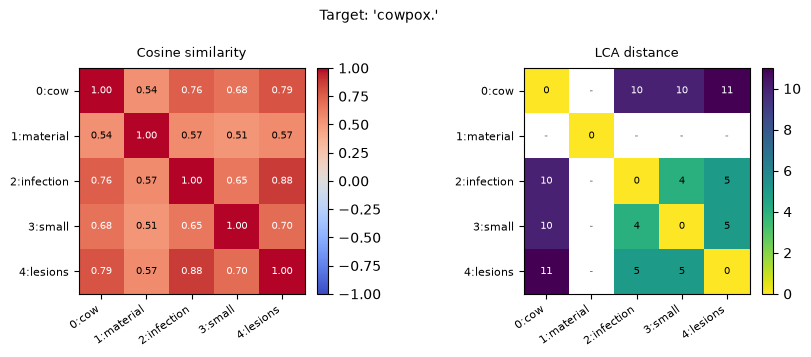


Context: 'He used the' | Target: 'phrase'
Top-5        |      0:money |   1:bathroom |   2:internet |       3:term |   4:computer
---------------------------------------------------------------------------------------
0:money      |       1.0000 |       0.6662 |       0.4225 |       0.6587 |       0.6729
1:bathroom   |       0.6662 |       1.0000 |       0.4852 |       0.6014 |       0.7056
2:internet   |       0.4225 |       0.4852 |       1.0000 |       0.3625 |       0.5341
3:term       |       0.6587 |       0.6014 |       0.3625 |       1.0000 |       0.5587
4:computer   |       0.6729 |       0.7056 |       0.5341 |       0.5587 |       1.0000


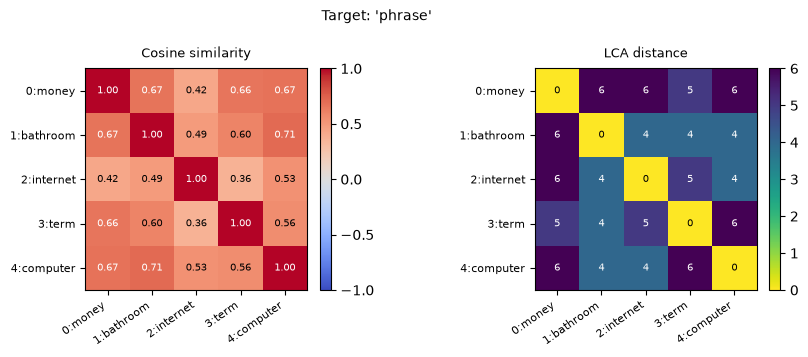


Context: 'He used the phrase in 1798 for the' | Target: 'long'
Top-5           |         0:first |         1:title |        2:french |          3:book |   4:publication
---------------------------------------------------------------------------------------------------------
0:first         |          1.0000 |          0.4539 |          0.4567 |          0.5025 |          0.4226
1:title         |          0.4539 |          1.0000 |          0.4041 |          0.5247 |          0.3735
2:french        |          0.4567 |          0.4041 |          1.0000 |          0.4150 |          0.2745
3:book          |          0.5025 |          0.5247 |          0.4150 |          1.0000 |          0.4343
4:publication   |          0.4226 |          0.3735 |          0.2745 |          0.4343 |          1.0000


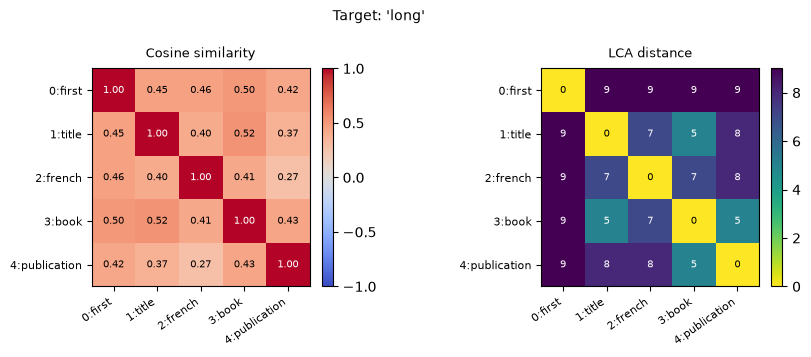


Context: 'He used the phrase in 1798 for the long' | Target: 'title'
Top-5        |      0:term |      1:poem |     2:title |       3:run |   4:version
----------------------------------------------------------------------------------
0:term       |      1.0000 |      0.6227 |      0.5741 |      0.5346 |      0.5981
1:poem       |      0.6227 |      1.0000 |      0.5003 |      0.4662 |      0.5791
2:title      |      0.5741 |      0.5003 |      1.0000 |      0.4261 |      0.4563
3:run        |      0.5346 |      0.4662 |      0.4261 |      1.0000 |      0.5183
4:version    |      0.5981 |      0.5791 |      0.4563 |      0.5183 |      1.0000


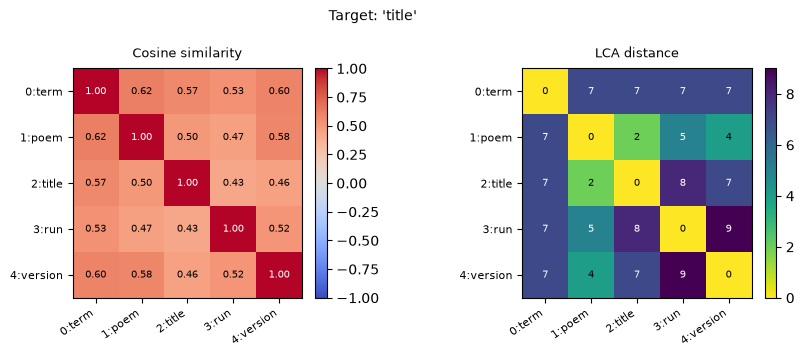


Context: 'He used the phrase in 1798 for the long title of his' | Target: 'Inquiry'
Top-5        |     0:book |     1:work |    2:essay |    3:pamph |       4:ut
-----------------------------------------------------------------------------
0:book       |     1.0000 |     0.5732 |     0.6108 |     0.4686 |     0.4061
1:work       |     0.5732 |     1.0000 |     0.5357 |     0.4886 |     0.4992
2:essay      |     0.6108 |     0.5357 |     1.0000 |     0.4633 |     0.4975
3:pamph      |     0.4686 |     0.4886 |     0.4633 |     1.0000 |     0.4791
4:ut         |     0.4061 |     0.4992 |     0.4975 |     0.4791 |     1.0000


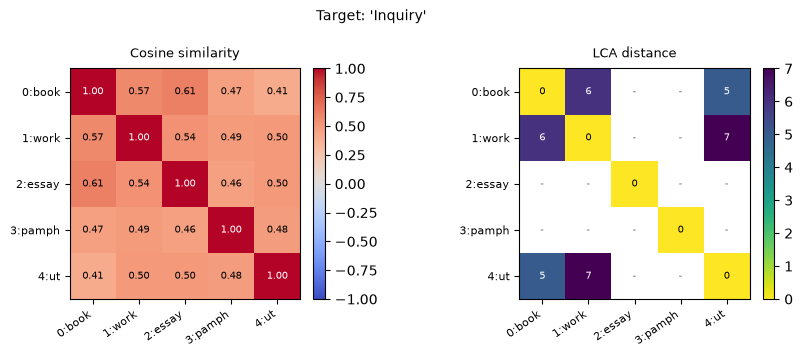


Context: 'He used the phrase in 1798 for the long title of his Inquiry into the' | Target: 'Variolae'
Top-5          |       0:nature |   1:principles |        2:cause |       3:origin |       4:causes
---------------------------------------------------------------------------------------------------
0:nature       |         1.0000 |         0.5559 |         0.5388 |         0.5936 |         0.5565
1:principles   |         0.5559 |         1.0000 |         0.6777 |         0.7059 |         0.6663
2:cause        |         0.5388 |         0.6777 |         1.0000 |         0.7519 |         0.8864
3:origin       |         0.5936 |         0.7059 |         0.7519 |         1.0000 |         0.7183
4:causes       |         0.5565 |         0.6663 |         0.8864 |         0.7183 |         1.0000


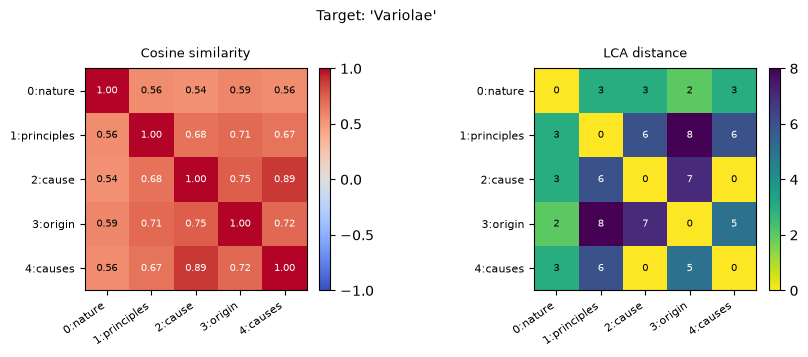


Context: 'He used the phrase in 1798 for the long title of his Inquiry into the Variolae' | Target: 'vaccinae'
Top-5        |      0:vacc |       1:ver |   2:vaccine |         3:v |       4:vel
----------------------------------------------------------------------------------
0:vacc       |      1.0000 |      0.4419 |      0.5615 |      0.4609 |      0.5753
1:ver        |      0.4419 |      1.0000 |      0.4524 |      0.4396 |      0.5770
2:vaccine    |      0.5615 |      0.4524 |      1.0000 |      0.6565 |      0.5550
3:v          |      0.4609 |      0.4396 |      0.6565 |      1.0000 |      0.5877
4:vel        |      0.5753 |      0.5770 |      0.5550 |      0.5877 |      1.0000


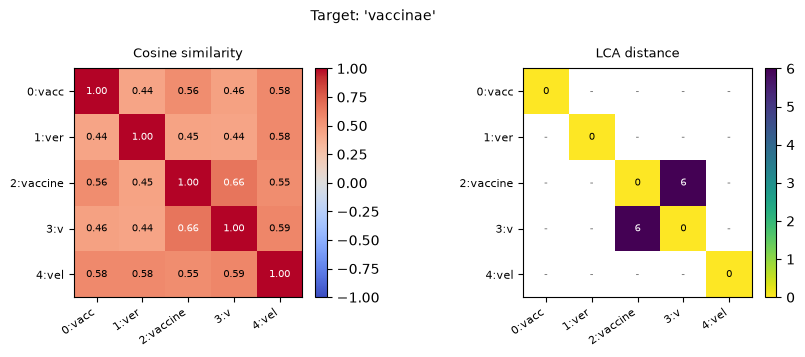


Context: 'He used the phrase in 1798 for the long title of his Inquiry into the Variolae vaccinae Known as the' | Target: 'Cow'
Top-5        |       0:cow |         1:牛 |      2:vacc |   3:vaccine |      4:goat
----------------------------------------------------------------------------------
0:cow        |      1.0000 |      0.6816 |      0.5120 |      0.8295 |      0.6515
1:牛          |      0.6816 |      1.0000 |      0.3626 |      0.6352 |      0.5465
2:vacc       |      0.5120 |      0.3626 |      1.0000 |      0.5615 |      0.4564
3:vaccine    |      0.8295 |      0.6352 |      0.5615 |      1.0000 |      0.6651
4:goat       |      0.6515 |      0.5465 |      0.4564 |      0.6651 |      1.0000


/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 29275 (\N{CJK UNIFIED IDEOGRAPH-725B}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 29275 (\N{CJK UNIFIED IDEOGRAPH-725B}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


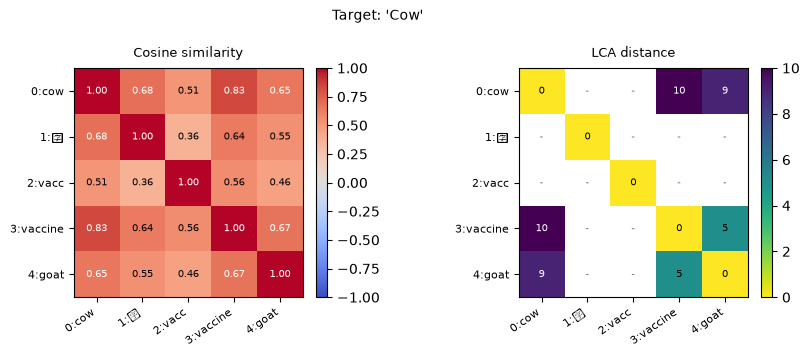


Context: 'He used the phrase in 1798 for the long title of his Inquiry into the Variolae vaccinae Known as the Cow' | Target: 'Pox,'
Top-5        |        0:p |     1:pest |       2:po |       3:pl |     4:pale
-----------------------------------------------------------------------------
0:p          |     1.0000 |     0.4874 |     0.4812 |     0.5862 |     0.5277
1:pest       |     0.4874 |     1.0000 |     0.6664 |     0.7070 |     0.7309
2:po         |     0.4812 |     0.6664 |     1.0000 |     0.7142 |     0.7021
3:pl         |     0.5862 |     0.7070 |     0.7142 |     1.0000 |     0.6806
4:pale       |     0.5277 |     0.7309 |     0.7021 |     0.6806 |     1.0000


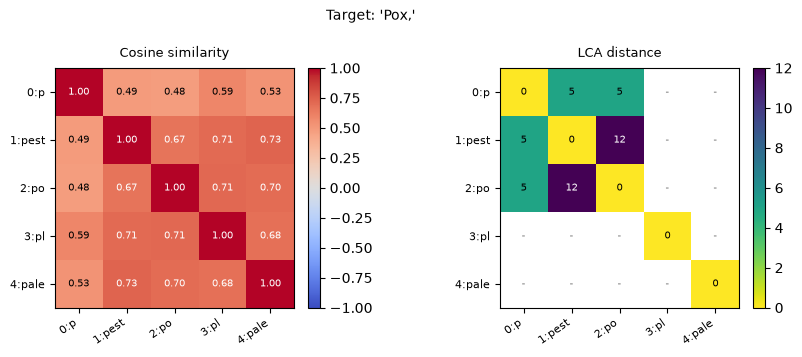


Context: 'He used the phrase in 1798 for the long title of his Inquiry into the Variolae vaccinae Known as the Cow Pox, in which he described the protective' | Target: 'effect'
Top-5        |     0:effect |   1:property |     2:nature |    3:effects |   4:immunity
---------------------------------------------------------------------------------------
0:effect     |       1.0000 |       0.6068 |       0.5269 |       0.7175 |       0.5293
1:property   |       0.6068 |       1.0000 |       0.5695 |       0.5344 |       0.4839
2:nature     |       0.5269 |       0.5695 |       1.0000 |       0.3852 |       0.4982
3:effects    |       0.7175 |       0.5344 |       0.3852 |       1.0000 |       0.3862
4:immunity   |       0.5293 |       0.4839 |       0.4982 |       0.3862 |       1.0000


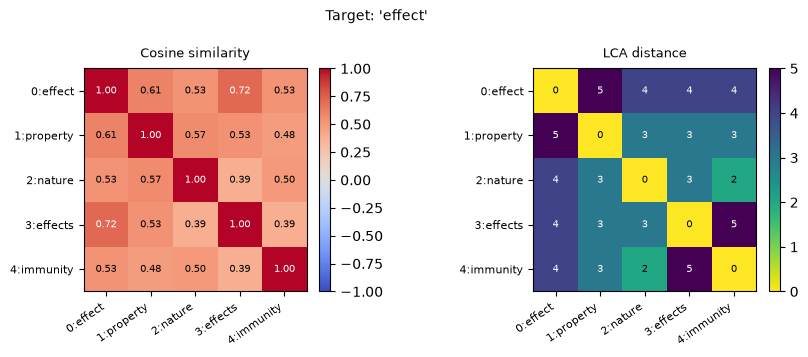


Context: 'He used the phrase in 1798 for the long title of his Inquiry into the Variolae vaccinae Known as the Cow Pox, in which he described the protective effect of' | Target: 'cowpox'
Top-5           |           0:cow |   1:vaccination |     2:infection |          3:vacc |          4:vari
---------------------------------------------------------------------------------------------------------
0:cow           |          1.0000 |          0.2613 |          0.7557 |          0.5120 |          0.4630
1:vaccination   |          0.2613 |          1.0000 |          0.4901 |          0.3517 |          0.4330
2:infection     |          0.7557 |          0.4901 |          1.0000 |          0.4889 |          0.4949
3:vacc          |          0.5120 |          0.3517 |          0.4889 |          1.0000 |          0.5520
4:vari          |          0.4630 |          0.4330 |          0.4949 |          0.5520 |          1.0000


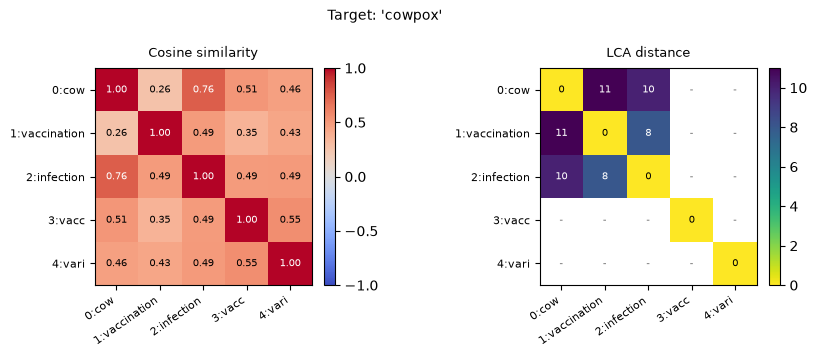


Context: 'He used the phrase in 1798 for the long title of his Inquiry into the Variolae vaccinae Known as the Cow Pox, in which he described the protective effect of cowpox against' | Target: 'smallpox.'
Top-5         |       0:small |       1:human |        2:vari |   3:infection |          4:天花
---------------------------------------------------------------------------------------------
0:small       |        1.0000 |        0.6403 |        0.5025 |        0.6512 |        0.5190
1:human       |        0.6403 |        1.0000 |        0.5088 |        0.6018 |        0.4417
2:vari        |        0.5025 |        0.5088 |        1.0000 |        0.4949 |        0.3244
3:infection   |        0.6512 |        0.6018 |        0.4949 |        1.0000 |        0.4706
4:天花          |        0.5190 |        0.4417 |        0.3244 |        0.4706 |        1.0000


/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 22825 (\N{CJK UNIFIED IDEOGRAPH-5929}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 33457 (\N{CJK UNIFIED IDEOGRAPH-82B1}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 22825 (\N{CJK UNIFIED IDEOGRAPH-5929}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 33457 (\N{CJK UNIFIED IDEOGRAPH-82B1}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


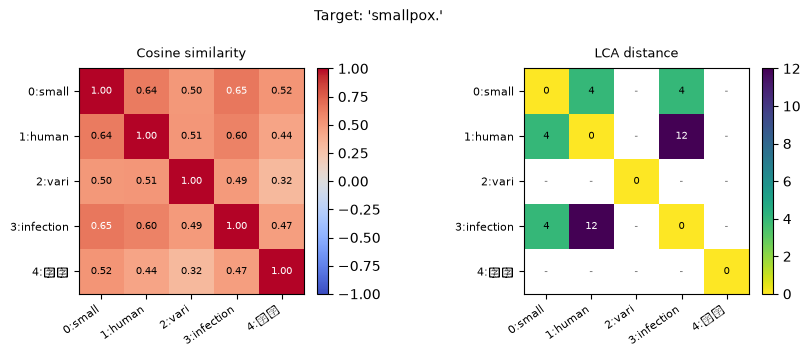


Context: 'In 1881, to' | Target: 'honor'
Top-5           |   0:commemorate |     1:celebrate |       2:address |         3:solve |       4:promote
---------------------------------------------------------------------------------------------------------
0:commemorate   |          1.0000 |          0.7983 |          0.7354 |          0.5881 |          0.7939
1:celebrate     |          0.7983 |          1.0000 |          0.7569 |          0.6117 |          0.7998
2:address       |          0.7354 |          0.7569 |          1.0000 |          0.6489 |          0.7567
3:solve         |          0.5881 |          0.6117 |          0.6489 |          1.0000 |          0.6451
4:promote       |          0.7939 |          0.7998 |          0.7567 |          0.6451 |          1.0000


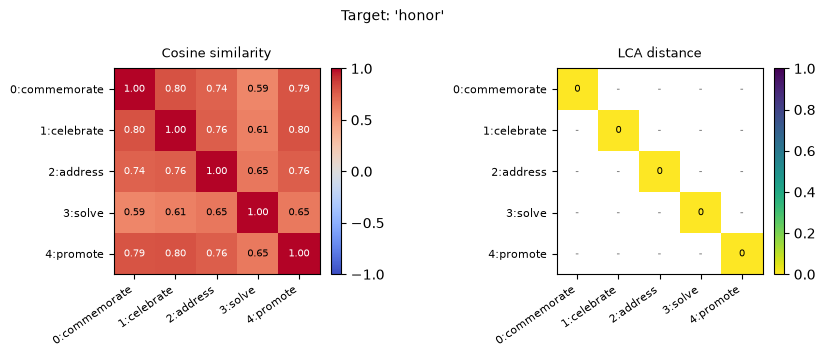


Context: 'In 1881, to honor' | Target: 'Jenner,'
Top-5        |   0:emperor |    1:george |     2:queen |   3:general |    4:prince
----------------------------------------------------------------------------------
0:emperor    |      1.0000 |      0.6310 |      0.7206 |      0.5455 |      0.7268
1:george     |      0.6310 |      1.0000 |      0.6667 |      0.5861 |      0.7063
2:queen      |      0.7206 |      0.6667 |      1.0000 |      0.5731 |      0.8337
3:general    |      0.5455 |      0.5861 |      0.5731 |      1.0000 |      0.6556
4:prince     |      0.7268 |      0.7063 |      0.8337 |      0.6556 |      1.0000


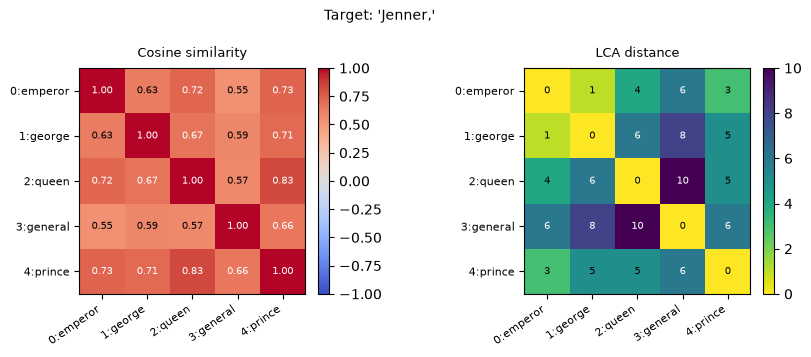


Context: 'In 1881, to honor Jenner,' | Target: 'Louis'
Top-5          |        0:paste |      1:british |         2:koch |   3:scientists |       4:people
---------------------------------------------------------------------------------------------------
0:paste        |         1.0000 |         0.2953 |         0.7472 |         0.6680 |         0.6742
1:british      |         0.2953 |         1.0000 |         0.3518 |         0.3083 |         0.3359
2:koch         |         0.7472 |         0.3518 |         1.0000 |         0.6676 |         0.6417
3:scientists   |         0.6680 |         0.3083 |         0.6676 |         1.0000 |         0.8011
4:people       |         0.6742 |         0.3359 |         0.6417 |         0.8011 |         1.0000


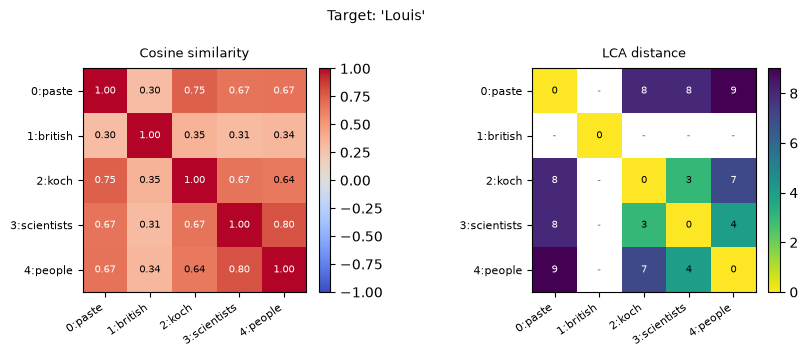


Context: 'In 1881, to honor Jenner, Louis' | Target: 'Pasteur'
Top-5        |    0:paste |     1:past |        2:r |        3:j |        4:p
-----------------------------------------------------------------------------
0:paste      |     1.0000 |     0.4787 |     0.5679 |     0.6705 |     0.5096
1:past       |     0.4787 |     1.0000 |     0.4685 |     0.3994 |     0.3210
2:r          |     0.5679 |     0.4685 |     1.0000 |     0.6258 |     0.4757
3:j          |     0.6705 |     0.3994 |     0.6258 |     1.0000 |     0.5180
4:p          |     0.5096 |     0.3210 |     0.4757 |     0.5180 |     1.0000


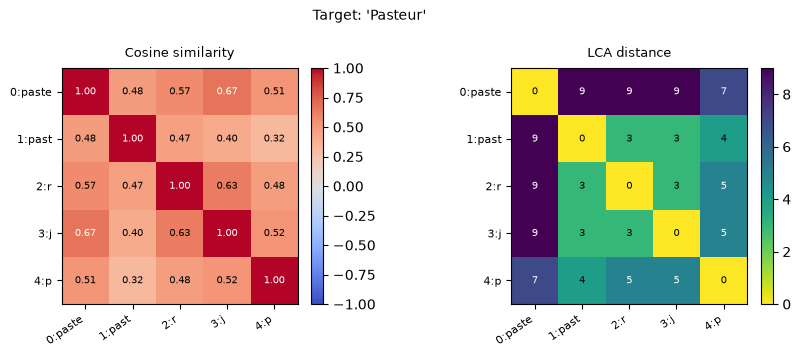


Context: 'In 1881, to honor Jenner, Louis Pasteur' | Target: 'proposed'
Top-5        |      0:named |   1:proposed |    2:renamed |      3:chose |    4:created
---------------------------------------------------------------------------------------
0:named      |       1.0000 |       0.6587 |       0.7526 |       0.7560 |       0.8046
1:proposed   |       0.6587 |       1.0000 |       0.6732 |       0.4962 |       0.6284
2:renamed    |       0.7526 |       0.6732 |       1.0000 |       0.5727 |       0.7214
3:chose      |       0.7560 |       0.4962 |       0.5727 |       1.0000 |       0.7327
4:created    |       0.8046 |       0.6284 |       0.7214 |       0.7327 |       1.0000


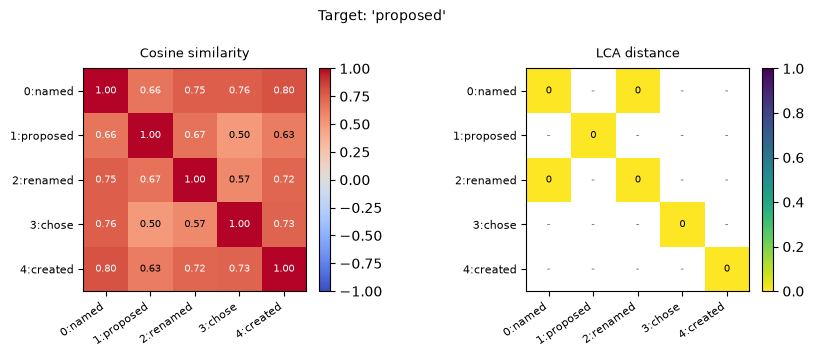


Context: 'In 1881, to honor Jenner, Louis Pasteur proposed that the' | Target: 'terms'
Top-5        |   0:vaccine |      1:term |     2:first |    3:immune |     4:immun
----------------------------------------------------------------------------------
0:vaccine    |      1.0000 |      0.6721 |      0.5626 |      0.8626 |      0.4980
1:term       |      0.6721 |      1.0000 |      0.5372 |      0.6719 |      0.3989
2:first      |      0.5626 |      0.5372 |      1.0000 |      0.5846 |      0.3280
3:immune     |      0.8626 |      0.6719 |      0.5846 |      1.0000 |      0.4759
4:immun      |      0.4980 |      0.3989 |      0.3280 |      0.4759 |      1.0000


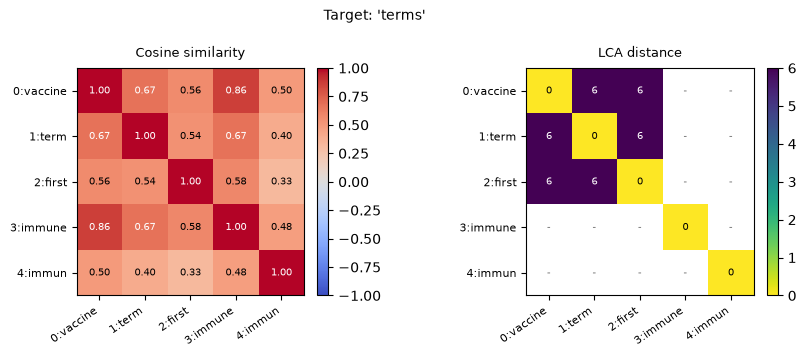


Context: 'In 1881, to honor Jenner, Louis Pasteur proposed that the terms should be extended to' | Target: 'cover'
Top-5        |    0:include |      1:cover |   2:diseases |       3:mean |    4:animals
---------------------------------------------------------------------------------------
0:include    |       1.0000 |       0.7154 |       0.5415 |       0.7360 |       0.4731
1:cover      |       0.7154 |       1.0000 |       0.5323 |       0.6893 |       0.4942
2:diseases   |       0.5415 |       0.5323 |       1.0000 |       0.4929 |       0.6826
3:mean       |       0.7360 |       0.6893 |       0.4929 |       1.0000 |       0.3921
4:animals    |       0.4731 |       0.4942 |       0.6826 |       0.3921 |       1.0000


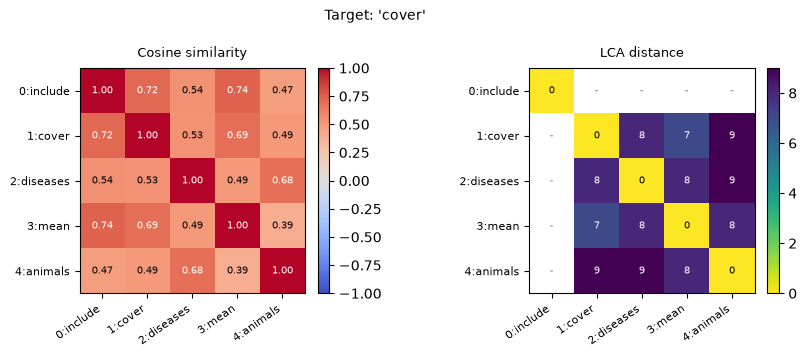


Context: 'In 1881, to honor Jenner, Louis Pasteur proposed that the terms should be extended to cover the new protective' | Target: 'inoculations'
Top-5         |        0:inoc |    1:measures |   2:substance |       3:immun |     4:methods
---------------------------------------------------------------------------------------------
0:inoc        |        1.0000 |        0.4494 |        0.5601 |        0.5164 |        0.5012
1:measures    |        0.4494 |        1.0000 |        0.6963 |        0.3258 |        0.7815
2:substance   |        0.5601 |        0.6963 |        1.0000 |        0.4159 |        0.6609
3:immun       |        0.5164 |        0.3258 |        0.4159 |        1.0000 |        0.3589
4:methods     |        0.5012 |        0.7815 |        0.6609 |        0.3589 |        1.0000


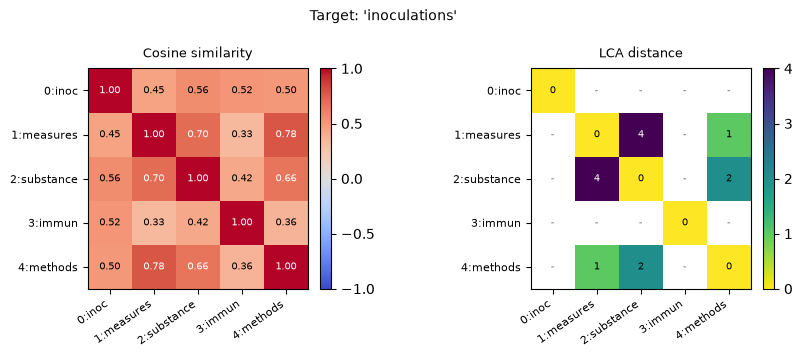


Context: 'The' | Target: 'science'
Top-5         |   0:following |         1:sum |      2:purple |    3:function |      4:number
---------------------------------------------------------------------------------------------
0:following   |        1.0000 |        0.5209 |        0.5680 |        0.4828 |        0.5987
1:sum         |        0.5209 |        1.0000 |        0.5980 |        0.6384 |        0.6528
2:purple      |        0.5680 |        0.5980 |        1.0000 |        0.5516 |        0.7352
3:function    |        0.4828 |        0.6384 |        0.5516 |        1.0000 |        0.6338
4:number      |        0.5987 |        0.6528 |        0.7352 |        0.6338 |        1.0000


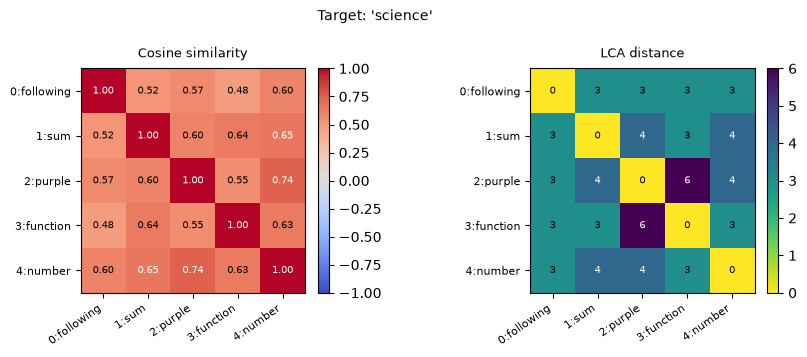


Context: 'The science of' | Target: 'vaccine'
Top-5          |     0:learning |      1:climate |        2:sleep |    3:nutrition |   4:psychology
---------------------------------------------------------------------------------------------------
0:learning     |         1.0000 |         0.5762 |         0.5048 |         0.6574 |         0.5207
1:climate      |         0.5762 |         1.0000 |         0.4525 |         0.6193 |         0.5222
2:sleep        |         0.5048 |         0.4525 |         1.0000 |         0.4719 |         0.4244
3:nutrition    |         0.6574 |         0.6193 |         0.4719 |         1.0000 |         0.6960
4:psychology   |         0.5207 |         0.5222 |         0.4244 |         0.6960 |         1.0000


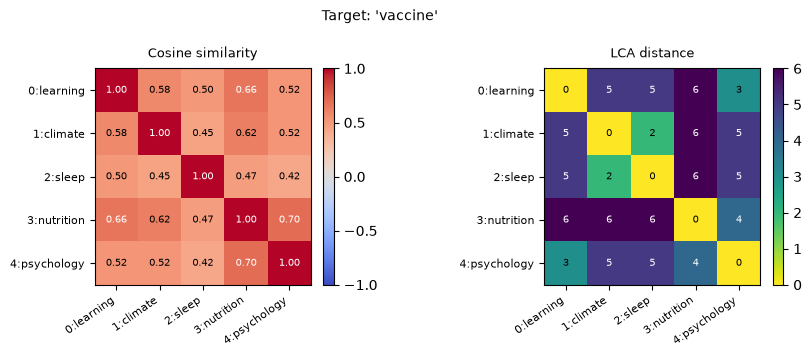


Context: 'The science of vaccine' | Target: 'development'
Top-5             |     0:development |          1:safety |        2:research |        3:efficacy |   4:effectiveness
---------------------------------------------------------------------------------------------------------------------
0:development     |            1.0000 |            0.6689 |            0.7769 |            0.6219 |            0.6615
1:safety          |            0.6689 |            1.0000 |            0.6640 |            0.7287 |            0.7589
2:research        |            0.7769 |            0.6640 |            1.0000 |            0.6108 |            0.6492
3:efficacy        |            0.6219 |            0.7287 |            0.6108 |            1.0000 |            0.9310
4:effectiveness   |            0.6615 |            0.7589 |            0.6492 |            0.9310 |            1.0000


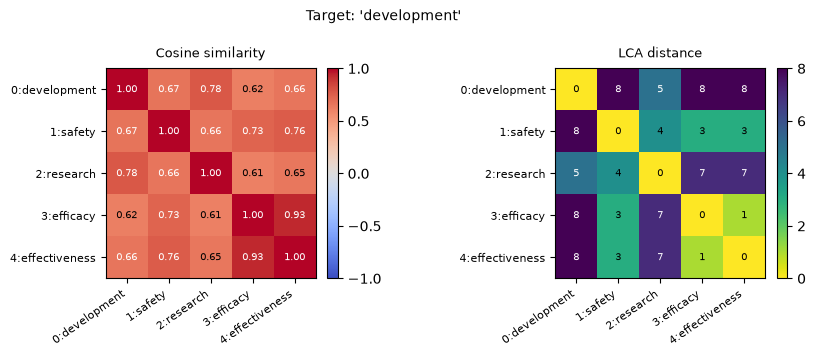


Context: 'The science of vaccine development and' | Target: 'production'
Top-5             |      0:production |        1:delivery |         2:testing |    3:distribution |   4:manufacturing
---------------------------------------------------------------------------------------------------------------------
0:production      |            1.0000 |            0.5351 |            0.5894 |            0.5512 |            0.6925
1:delivery        |            0.5351 |            1.0000 |            0.8180 |            0.7271 |            0.7387
2:testing         |            0.5894 |            0.8180 |            1.0000 |            0.7186 |            0.8556
3:distribution    |            0.5512 |            0.7271 |            0.7186 |            1.0000 |            0.6662
4:manufacturing   |            0.6925 |            0.7387 |            0.8556 |            0.6662 |            1.0000


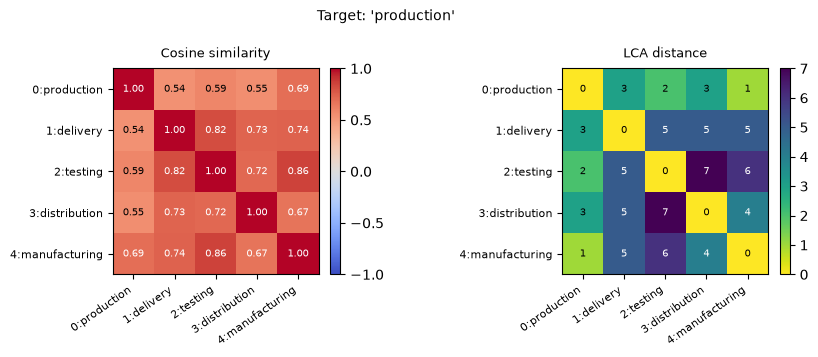


Context: 'The science of vaccine development and production is' | Target: 'termed'
Top-5          |      0:complex |       1:highly |   2:constantly |   3:incredibly |    4:extremely
---------------------------------------------------------------------------------------------------
0:complex      |         1.0000 |         0.6523 |         0.6125 |         0.6204 |         0.6492
1:highly       |         0.6523 |         1.0000 |         0.8062 |         0.8084 |         0.9305
2:constantly   |         0.6125 |         0.8062 |         1.0000 |         0.8112 |         0.8711
3:incredibly   |         0.6204 |         0.8084 |         0.8112 |         1.0000 |         0.9118
4:extremely    |         0.6492 |         0.9305 |         0.8711 |         0.9118 |         1.0000


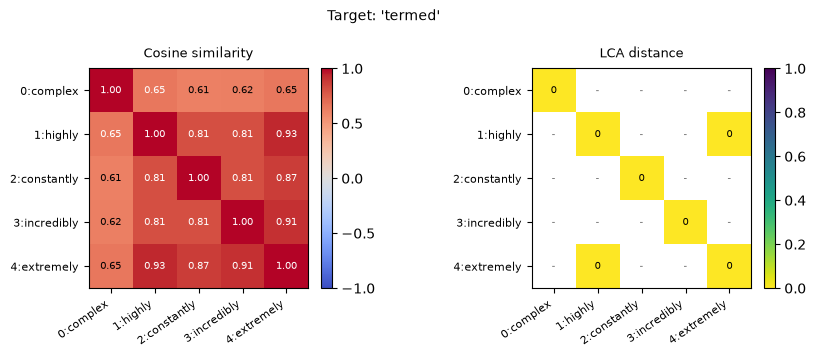


Context: 'The science of vaccine development and production is termed' | Target: 'vaccinology.'
Top-5        |      0:vacc |   1:vaccine |        2:vi |     3:immun |        4:bi
----------------------------------------------------------------------------------
0:vacc       |      1.0000 |      0.5615 |      0.4445 |      0.4447 |      0.5594
1:vaccine    |      0.5615 |      1.0000 |      0.6006 |      0.4980 |      0.7276
2:vi         |      0.4445 |      0.6006 |      1.0000 |      0.2973 |      0.5726
3:immun      |      0.4447 |      0.4980 |      0.2973 |      1.0000 |      0.4117
4:bi         |      0.5594 |      0.7276 |      0.5726 |      0.4117 |      1.0000


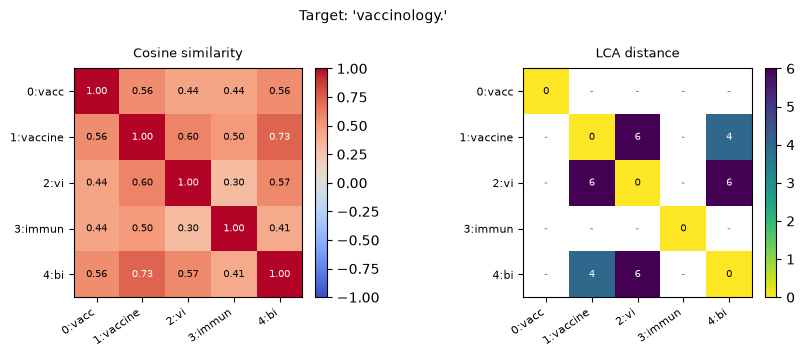


Context: 'There is overwhelming scientific' | Target: 'consensus'
Top-5         |    0:evidence |   1:consensus |   2:agreement |     3:support |       4:proof
---------------------------------------------------------------------------------------------
0:evidence    |        1.0000 |        0.4455 |        0.6748 |        0.6993 |        0.6216
1:consensus   |        0.4455 |        1.0000 |        0.5259 |        0.4417 |        0.3781
2:agreement   |        0.6748 |        0.5259 |        1.0000 |        0.7243 |        0.5624
3:support     |        0.6993 |        0.4417 |        0.7243 |        1.0000 |        0.5933
4:proof       |        0.6216 |        0.3781 |        0.5624 |        0.5933 |        1.0000


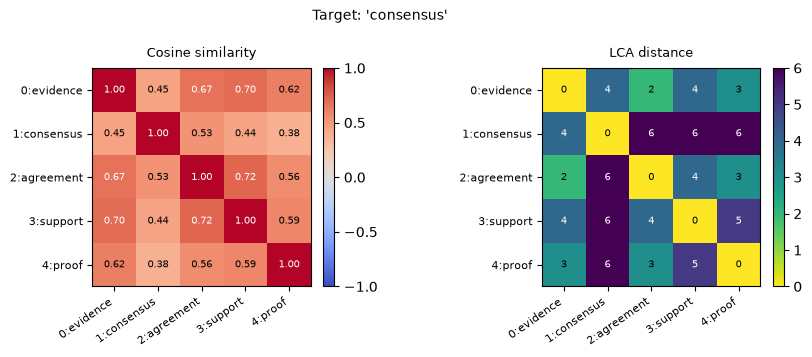


Context: 'There is overwhelming scientific consensus that' | Target: 'vaccines'
Top-5        |   0:climate |     1:human |    2:humans |   3:anthrop |    4:carbon
----------------------------------------------------------------------------------
0:climate    |      1.0000 |      0.5479 |      0.5611 |      0.4391 |      0.6631
1:human      |      0.5479 |      1.0000 |      0.8275 |      0.4202 |      0.5593
2:humans     |      0.5611 |      0.8275 |      1.0000 |      0.4583 |      0.5942
3:anthrop    |      0.4391 |      0.4202 |      0.4583 |      1.0000 |      0.4598
4:carbon     |      0.6631 |      0.5593 |      0.5942 |      0.4598 |      1.0000


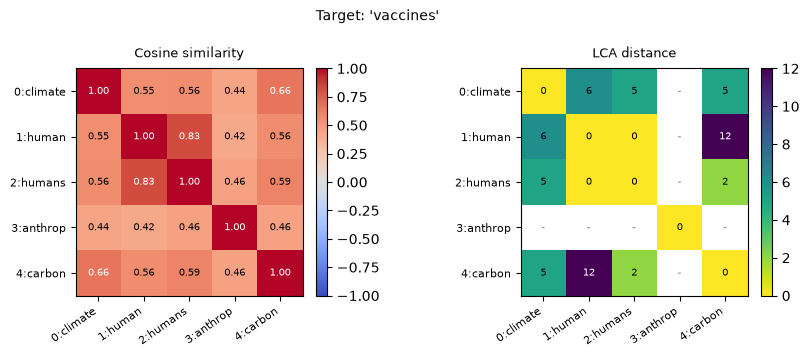


Context: 'There is overwhelming scientific consensus that vaccines are a very' | Target: 'safe'
Top-5        |       0:safe |       1:good |   2:valuable |      3:small |        4:low
---------------------------------------------------------------------------------------
0:safe       |       1.0000 |       0.6048 |       0.6935 |       0.6723 |       0.6977
1:good       |       0.6048 |       1.0000 |       0.5345 |       0.5737 |       0.6122
2:valuable   |       0.6935 |       0.5345 |       1.0000 |       0.7130 |       0.6993
3:small      |       0.6723 |       0.5737 |       0.7130 |       1.0000 |       0.7259
4:low        |       0.6977 |       0.6122 |       0.6993 |       0.7259 |       1.0000


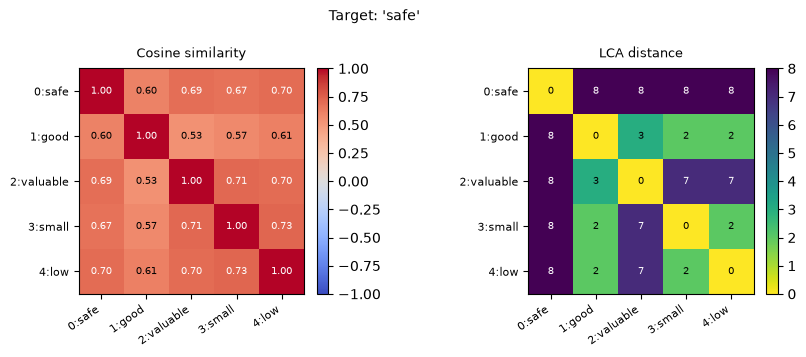


Context: 'There is overwhelming scientific consensus that vaccines are a very safe and effective' | Target: 'way'
Top-5        |      0:way |    1:means |   2:method |   3:public |     4:tool
-----------------------------------------------------------------------------
0:way        |     1.0000 |     0.5255 |     0.5608 |     0.4695 |     0.5445
1:means      |     0.5255 |     1.0000 |     0.5842 |     0.4611 |     0.5292
2:method     |     0.5608 |     0.5842 |     1.0000 |     0.6378 |     0.7249
3:public     |     0.4695 |     0.4611 |     0.6378 |     1.0000 |     0.6416
4:tool       |     0.5445 |     0.5292 |     0.7249 |     0.6416 |     1.0000


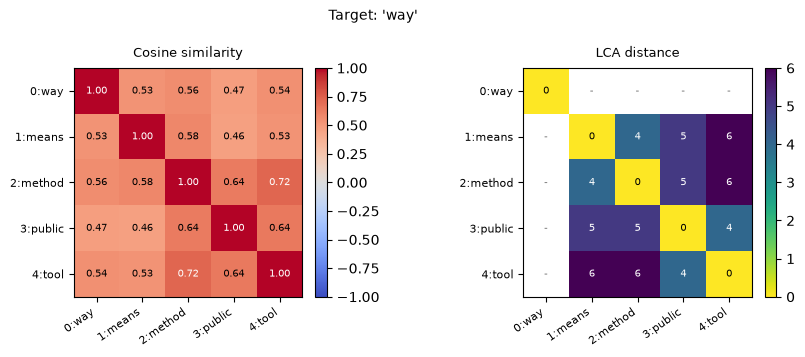


Context: 'There is overwhelming scientific consensus that vaccines are a very safe and effective way to' | Target: 'fight'
Top-5        |   0:prevent |   1:protect |      2:help |    3:combat |   4:provide
----------------------------------------------------------------------------------
0:prevent    |      1.0000 |      0.7785 |      0.7570 |      0.7831 |      0.7765
1:protect    |      0.7785 |      1.0000 |      0.8043 |      0.6379 |      0.7110
2:help       |      0.7570 |      0.8043 |      1.0000 |      0.6357 |      0.7271
3:combat     |      0.7831 |      0.6379 |      0.6357 |      1.0000 |      0.6439
4:provide    |      0.7765 |      0.7110 |      0.7271 |      0.6439 |      1.0000


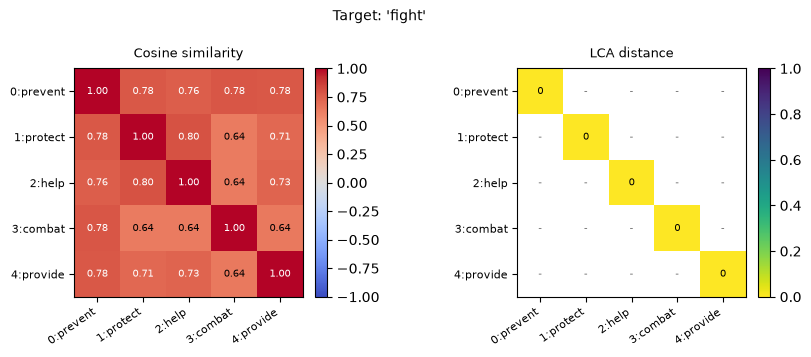


Context: 'There is overwhelming scientific consensus that vaccines are a very safe and effective way to fight and' | Target: 'eradicate'
Top-5         |     0:prevent |     1:control |   2:eliminate |     3:protect |   4:eradicate
---------------------------------------------------------------------------------------------
0:prevent     |        1.0000 |        0.8453 |        0.8284 |        0.7785 |        0.5269
1:control     |        0.8453 |        1.0000 |        0.7653 |        0.8044 |        0.5317
2:eliminate   |        0.8284 |        0.7653 |        1.0000 |        0.6873 |        0.5309
3:protect     |        0.7785 |        0.8044 |        0.6873 |        1.0000 |        0.5256
4:eradicate   |        0.5269 |        0.5317 |        0.5309 |        0.5256 |        1.0000


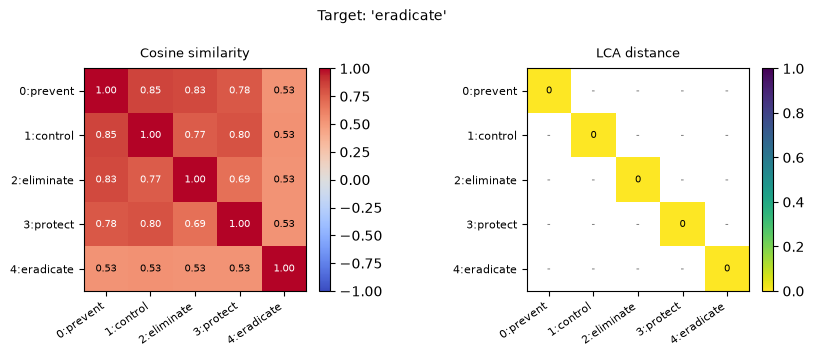


Context: 'There is overwhelming scientific consensus that vaccines are a very safe and effective way to fight and eradicate infectious' | Target: 'diseases.'
Top-5         |    0:diseases |     1:disease |   2:illnesses |      3:agents |     4:illness
---------------------------------------------------------------------------------------------
0:diseases    |        1.0000 |        0.9017 |        0.7094 |        0.5635 |        0.8255
1:disease     |        0.9017 |        1.0000 |        0.7877 |        0.6566 |        0.8748
2:illnesses   |        0.7094 |        0.7877 |        1.0000 |        0.8167 |        0.7442
3:agents      |        0.5635 |        0.6566 |        0.8167 |        1.0000 |        0.6005
4:illness     |        0.8255 |        0.8748 |        0.7442 |        0.6005 |        1.0000


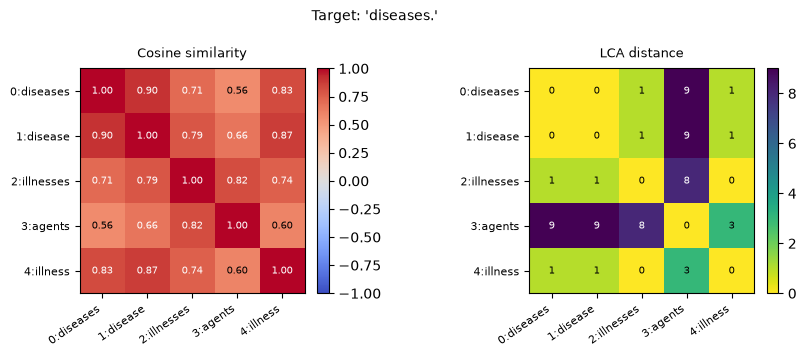


Context: 'The' | Target: 'immune'
Top-5         |   0:following |         1:sum |      2:purple |    3:function |      4:number
---------------------------------------------------------------------------------------------
0:following   |        1.0000 |        0.5209 |        0.5680 |        0.4828 |        0.5987
1:sum         |        0.5209 |        1.0000 |        0.5980 |        0.6384 |        0.6528
2:purple      |        0.5680 |        0.5980 |        1.0000 |        0.5516 |        0.7352
3:function    |        0.4828 |        0.6384 |        0.5516 |        1.0000 |        0.6338
4:number      |        0.5987 |        0.6528 |        0.7352 |        0.6338 |        1.0000


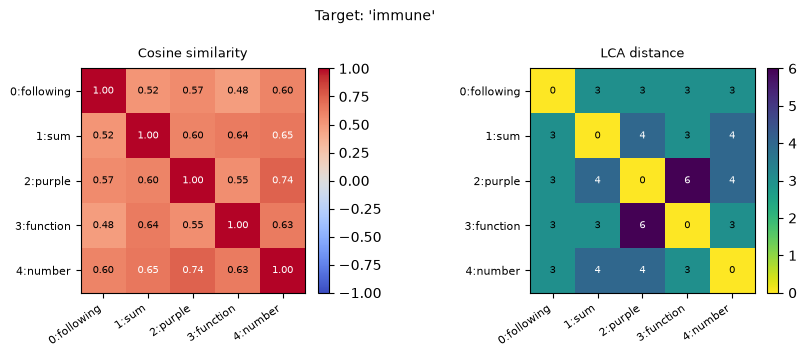


Context: 'The immune' | Target: 'system'
Top-5         |      0:system |    1:response |    2:function |     3:control |   4:mechanism
---------------------------------------------------------------------------------------------
0:system      |        1.0000 |        0.7347 |        0.5824 |        0.6887 |        0.7576
1:response    |        0.7347 |        1.0000 |        0.6206 |        0.7105 |        0.8034
2:function    |        0.5824 |        0.6206 |        1.0000 |        0.5792 |        0.5936
3:control     |        0.6887 |        0.7105 |        0.5792 |        1.0000 |        0.7963
4:mechanism   |        0.7576 |        0.8034 |        0.5936 |        0.7963 |        1.0000


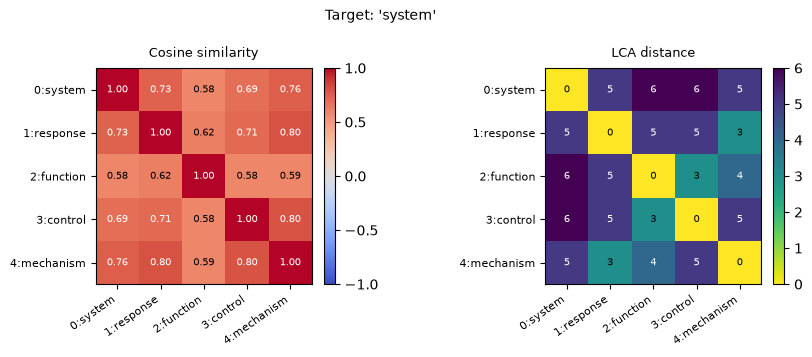


Context: 'The immune system' | Target: 'recognizes'
Top-5        |      0:plays |   1:protects |   2:consists |   3:includes |      4:works
---------------------------------------------------------------------------------------
0:plays      |       1.0000 |       0.5929 |       0.5397 |       0.5742 |       0.5969
1:protects   |       0.5929 |       1.0000 |       0.6006 |       0.5996 |       0.4806
2:consists   |       0.5397 |       0.6006 |       1.0000 |       0.8059 |       0.5829
3:includes   |       0.5742 |       0.5996 |       0.8059 |       1.0000 |       0.6298
4:works      |       0.5969 |       0.4806 |       0.5829 |       0.6298 |       1.0000


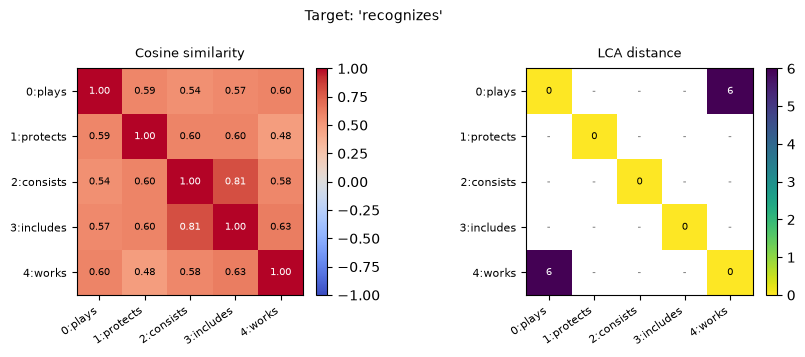


Context: 'The immune system recognizes' | Target: 'vaccine'
Top-5         |        0:self |   1:pathogens |      2:cancer |         3:non |       4:antig
---------------------------------------------------------------------------------------------
0:self        |        1.0000 |        0.3411 |        0.3579 |        0.7321 |        0.5692
1:pathogens   |        0.3411 |        1.0000 |        0.6003 |        0.3536 |        0.4169
2:cancer      |        0.3579 |        0.6003 |        1.0000 |        0.3579 |        0.4765
3:non         |        0.7321 |        0.3536 |        0.3579 |        1.0000 |        0.6361
4:antig       |        0.5692 |        0.4169 |        0.4765 |        0.6361 |        1.0000


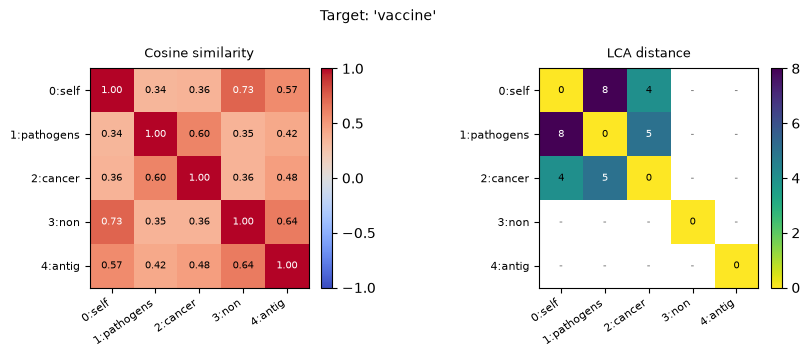


Context: 'The immune system recognizes vaccine' | Target: 'agents'
Top-5          |        0:antig |   1:components |     2:proteins |      3:antigen |      4:viruses
---------------------------------------------------------------------------------------------------
0:antig        |         1.0000 |         0.5968 |         0.5680 |         0.6512 |         0.5741
1:components   |         0.5968 |         1.0000 |         0.6785 |         0.6110 |         0.6333
2:proteins     |         0.5680 |         0.6785 |         1.0000 |         0.7446 |         0.7367
3:antigen      |         0.6512 |         0.6110 |         0.7446 |         1.0000 |         0.6817
4:viruses      |         0.5741 |         0.6333 |         0.7367 |         0.6817 |         1.0000


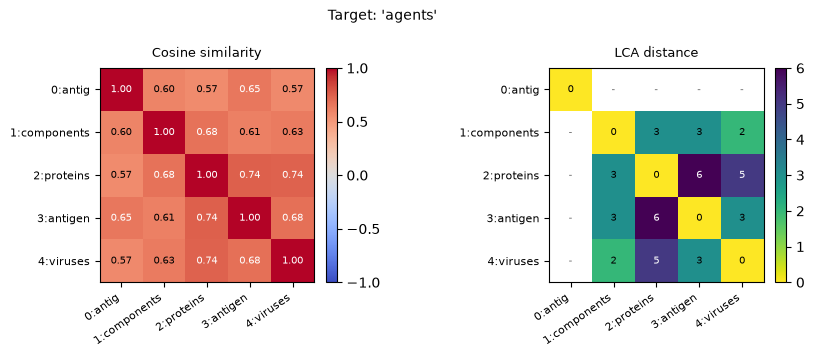


Context: 'The immune system recognizes vaccine agents as foreign,' | Target: 'destroys'
Top-5          |   0:initiating |   1:triggering |   2:activating |        3:initi |      4:thereby
---------------------------------------------------------------------------------------------------
0:initiating   |         1.0000 |         0.8789 |         0.5458 |         0.6419 |         0.4855
1:triggering   |         0.8789 |         1.0000 |         0.5013 |         0.6722 |         0.5132
2:activating   |         0.5458 |         0.5013 |         1.0000 |         0.4575 |         0.4356
3:initi        |         0.6419 |         0.6722 |         0.4575 |         1.0000 |         0.4924
4:thereby      |         0.4855 |         0.5132 |         0.4356 |         0.4924 |         1.0000


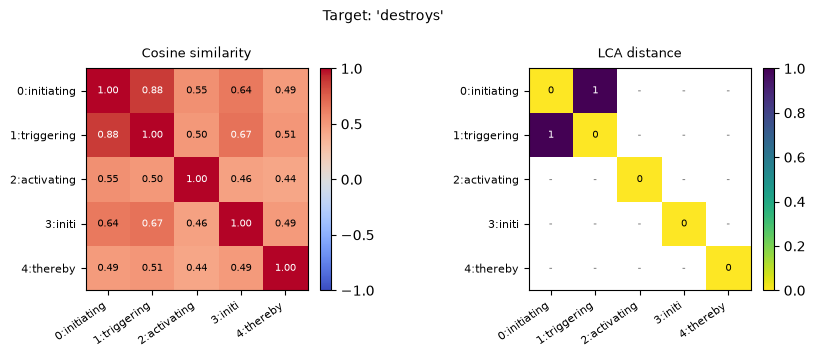


Context: 'The immune system recognizes vaccine agents as foreign, destroys them, and' | Target: '"remembers"'
Top-5         |   0:remembers |     1:creates |    2:develops |     3:retains |       4:makes
---------------------------------------------------------------------------------------------
0:remembers   |        1.0000 |        0.6481 |        0.6010 |        0.5603 |        0.6206
1:creates     |        0.6481 |        1.0000 |        0.8031 |        0.7974 |        0.8343
2:develops    |        0.6010 |        0.8031 |        1.0000 |        0.8268 |        0.8143
3:retains     |        0.5603 |        0.7974 |        0.8268 |        1.0000 |        0.8229
4:makes       |        0.6206 |        0.8343 |        0.8143 |        0.8229 |        1.0000


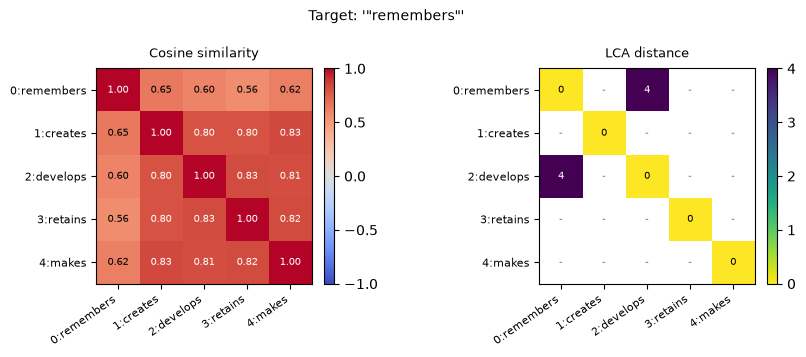


Context: 'When the virulent' | Target: 'version'
Top-5        |     0:strain |     1:bacter |     2:factor |   3:bacteria |    4:strains
---------------------------------------------------------------------------------------
0:strain     |       1.0000 |       0.4352 |       0.6998 |       0.6928 |       0.8411
1:bacter     |       0.4352 |       1.0000 |       0.4374 |       0.5333 |       0.3078
2:factor     |       0.6998 |       0.4374 |       1.0000 |       0.6691 |       0.6252
3:bacteria   |       0.6928 |       0.5333 |       0.6691 |       1.0000 |       0.6292
4:strains    |       0.8411 |       0.3078 |       0.6252 |       0.6292 |       1.0000


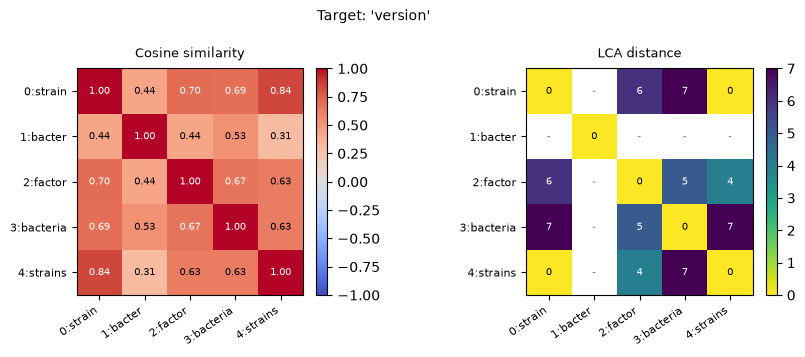


Context: 'When the virulent version of an' | Target: 'agent'
Top-5         |   0:influenza |          1:av |         2:rna |    3:organism |         4:old
---------------------------------------------------------------------------------------------
0:influenza   |        1.0000 |        0.6435 |        0.5451 |        0.7072 |        0.4554
1:av          |        0.6435 |        1.0000 |        0.4954 |        0.7769 |        0.4951
2:rna         |        0.5451 |        0.4954 |        1.0000 |        0.4849 |        0.3946
3:organism    |        0.7072 |        0.7769 |        0.4849 |        1.0000 |        0.5115
4:old         |        0.4554 |        0.4951 |        0.3946 |        0.5115 |        1.0000


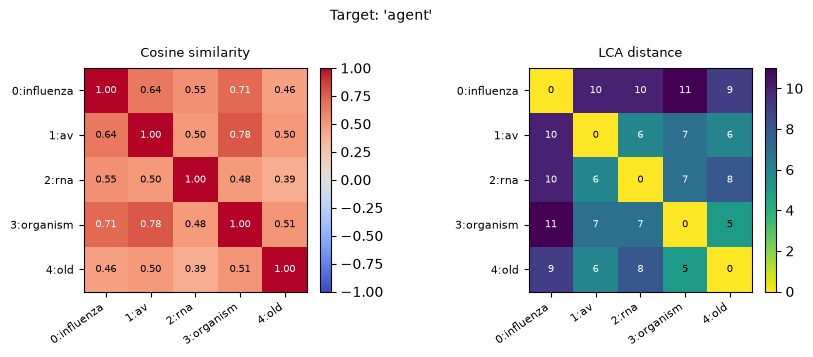


Context: 'When the virulent version of an agent is' | Target: 'encountered,'
Top-5          |     0:released |   1:introduced |      2:present |   3:eliminated |         4:erad
---------------------------------------------------------------------------------------------------
0:released     |         1.0000 |         0.6035 |         0.3630 |         0.5450 |         0.3889
1:introduced   |         0.6035 |         1.0000 |         0.5484 |         0.5949 |         0.3777
2:present      |         0.3630 |         0.5484 |         1.0000 |         0.4220 |         0.3521
3:eliminated   |         0.5450 |         0.5949 |         0.4220 |         1.0000 |         0.5245
4:erad         |         0.3889 |         0.3777 |         0.3521 |         0.5245 |         1.0000


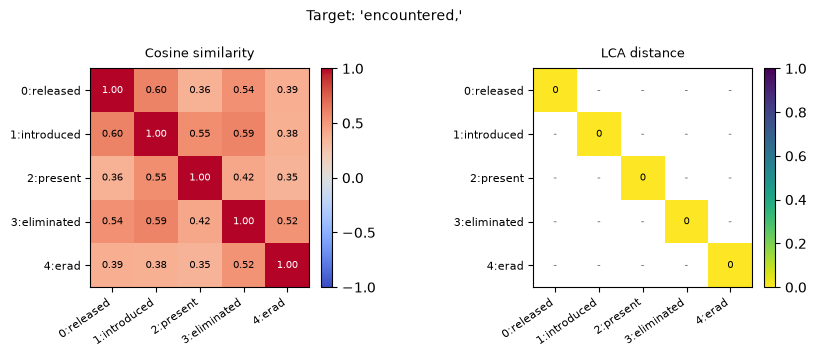


Context: 'When the virulent version of an agent is encountered, the' | Target: 'body'
Top-5        |     0:host |   1:immune |    2:agent |     3:body |   4:system
-----------------------------------------------------------------------------
0:host       |     1.0000 |     0.4992 |     0.4290 |     0.4545 |     0.4883
1:immune     |     0.4992 |     1.0000 |     0.8160 |     0.7067 |     0.7080
2:agent      |     0.4290 |     0.8160 |     1.0000 |     0.7095 |     0.6864
3:body       |     0.4545 |     0.7067 |     0.7095 |     1.0000 |     0.6851
4:system     |     0.4883 |     0.7080 |     0.6864 |     0.6851 |     1.0000


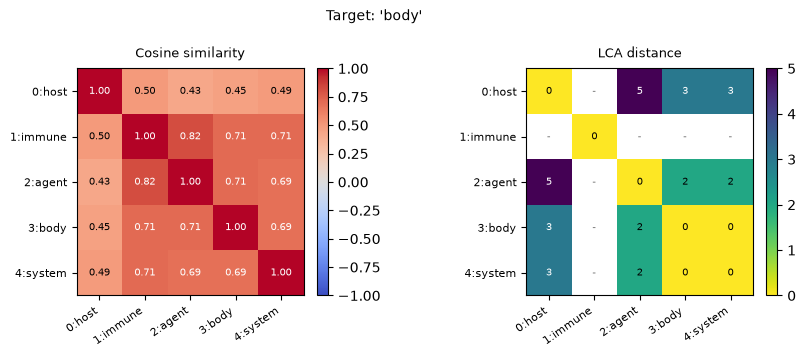


Context: 'When the virulent version of an agent is encountered, the body' | Target: 'recognizes'
Top-5           |        0:mounts |      1:produces |      2:responds |        3:reacts |   4:immediately
---------------------------------------------------------------------------------------------------------
0:mounts        |          1.0000 |          0.6161 |          0.7226 |          0.8002 |          0.6000
1:produces      |          0.6161 |          1.0000 |          0.5909 |          0.6102 |          0.5003
2:responds      |          0.7226 |          0.5909 |          1.0000 |          0.8660 |          0.5763
3:reacts        |          0.8002 |          0.6102 |          0.8660 |          1.0000 |          0.6540
4:immediately   |          0.6000 |          0.5003 |          0.5763 |          0.6540 |          1.0000


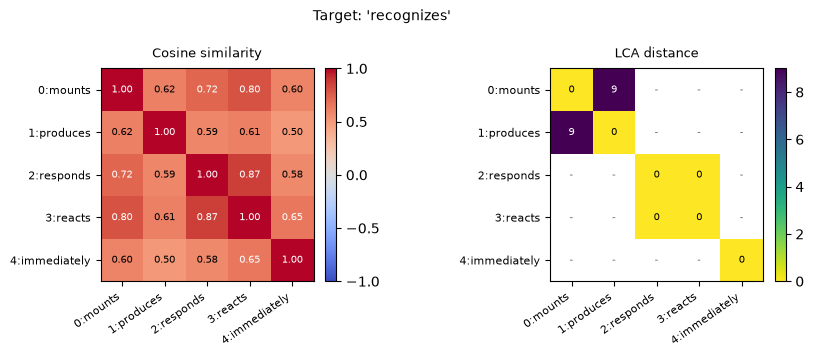


Context: 'When the virulent version of an agent is encountered, the body recognizes the' | Target: 'protein'
Top-5        |      0:agent |   1:presence |      2:antig |        3:inv |       4:path
---------------------------------------------------------------------------------------
0:agent      |       1.0000 |       0.7959 |       0.6520 |       0.5603 |       0.6837
1:presence   |       0.7959 |       1.0000 |       0.6093 |       0.5454 |       0.7029
2:antig      |       0.6520 |       0.6093 |       1.0000 |       0.6847 |       0.6487
3:inv        |       0.5603 |       0.5454 |       0.6847 |       1.0000 |       0.4992
4:path       |       0.6837 |       0.7029 |       0.6487 |       0.4992 |       1.0000


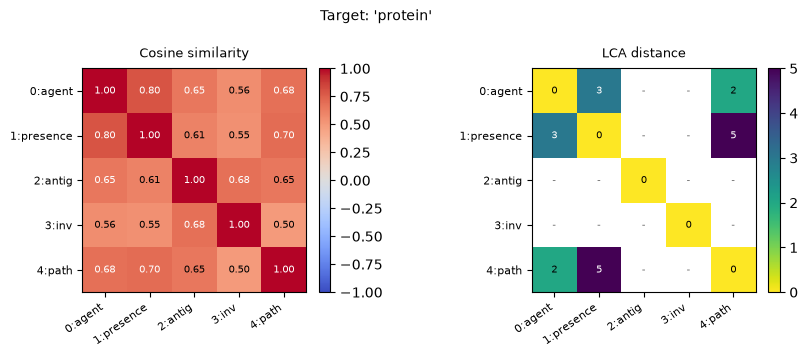


Context: 'When the virulent version of an agent is encountered, the body recognizes the protein' | Target: 'coat'
Top-5          |         0:coat |        1:antig |   2:structures |    3:fragments |    4:structure
---------------------------------------------------------------------------------------------------
0:coat         |         1.0000 |         0.6563 |         0.7295 |         0.6761 |         0.7406
1:antig        |         0.6563 |         1.0000 |         0.6539 |         0.6599 |         0.6598
2:structures   |         0.7295 |         0.6539 |         1.0000 |         0.8003 |         0.9215
3:fragments    |         0.6761 |         0.6599 |         0.8003 |         1.0000 |         0.7311
4:structure    |         0.7406 |         0.6598 |         0.9215 |         0.7311 |         1.0000


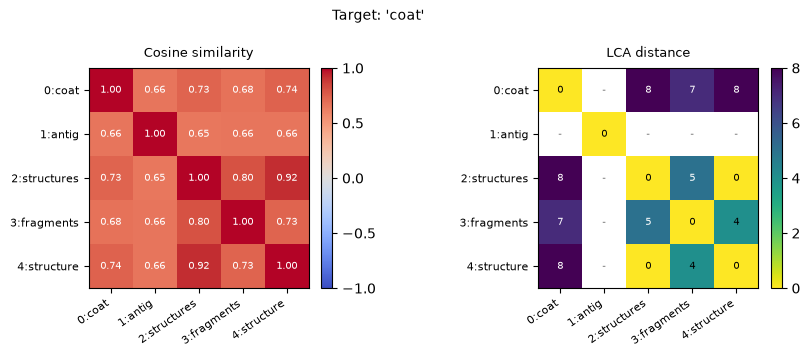


Context: 'When the virulent version of an agent is encountered, the body recognizes the protein coat on the' | Target: 'agent,'
Top-5        |   0:surface |   1:outside |     2:virus |     3:agent |       4:vir
----------------------------------------------------------------------------------
0:surface    |      1.0000 |      0.5855 |      0.5938 |      0.5636 |      0.4828
1:outside    |      0.5855 |      1.0000 |      0.6056 |      0.5624 |      0.5147
2:virus      |      0.5938 |      0.6056 |      1.0000 |      0.7276 |      0.5784
3:agent      |      0.5636 |      0.5624 |      0.7276 |      1.0000 |      0.5050
4:vir        |      0.4828 |      0.5147 |      0.5784 |      0.5050 |      1.0000


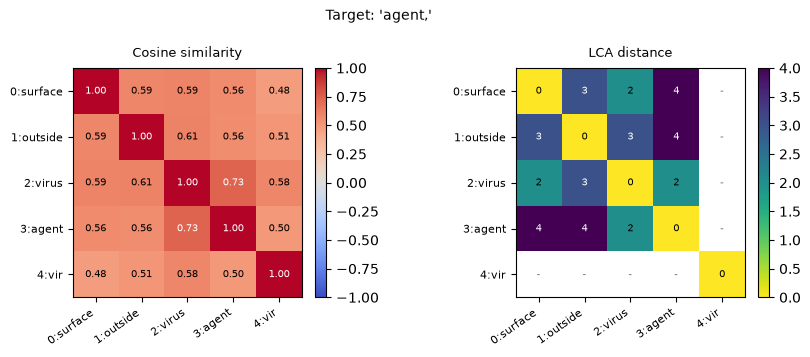


Context: 'When the virulent version of an agent is encountered, the body recognizes the protein coat on the agent, and thus is prepared to' | Target: 'respond,'
Top-5        |     0:fight |    1:attack |   2:produce |   3:respond |     4:mount
----------------------------------------------------------------------------------
0:fight      |      1.0000 |      0.7396 |      0.6380 |      0.6600 |      0.6167
1:attack     |      0.7396 |      1.0000 |      0.7076 |      0.8512 |      0.7288
2:produce    |      0.6380 |      0.7076 |      1.0000 |      0.6842 |      0.6485
3:respond    |      0.6600 |      0.8512 |      0.6842 |      1.0000 |      0.7242
4:mount      |      0.6167 |      0.7288 |      0.6485 |      0.7242 |      1.0000


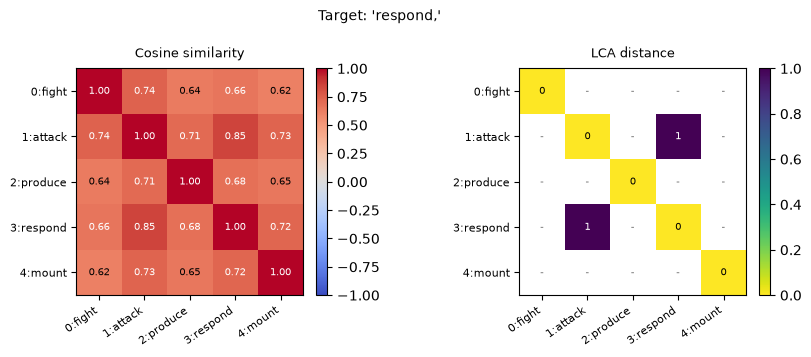


Context: 'When the virulent version of an agent is encountered, the body recognizes the protein coat on the agent, and thus is prepared to respond, by' | Target: 'first'
Top-5          |    0:producing |       1:making |   2:activating |       3:either |     4:mounting
---------------------------------------------------------------------------------------------------
0:producing    |         1.0000 |         0.8232 |         0.5141 |         0.3969 |         0.8007
1:making       |         0.8232 |         1.0000 |         0.5000 |         0.4496 |         0.8593
2:activating   |         0.5141 |         0.5000 |         1.0000 |         0.3328 |         0.4756
3:either       |         0.3969 |         0.4496 |         0.3328 |         1.0000 |         0.4161
4:mounting     |         0.8007 |         0.8593 |         0.4756 |         0.4161 |         1.0000


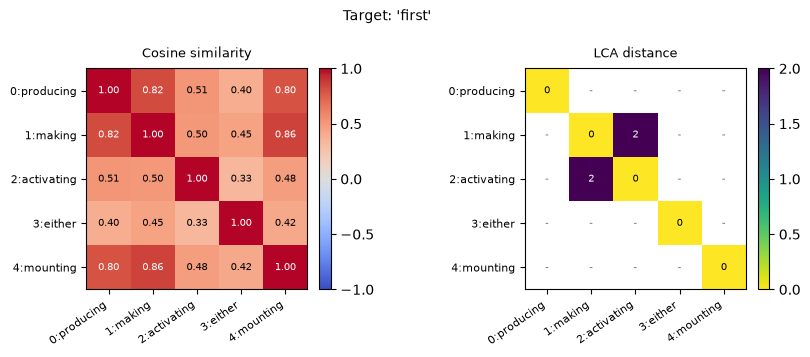


Context: 'When the virulent version of an agent is encountered, the body recognizes the protein coat on the agent, and thus is prepared to respond, by first' | Target: 'neutralizing'
Top-5           |     0:producing |        1:making |    2:activating |      3:creating |   4:identifying
---------------------------------------------------------------------------------------------------------
0:producing     |          1.0000 |          0.8232 |          0.5141 |          0.8307 |          0.8380
1:making        |          0.8232 |          1.0000 |          0.5000 |          0.8591 |          0.8662
2:activating    |          0.5141 |          0.5000 |          1.0000 |          0.5652 |          0.6018
3:creating      |          0.8307 |          0.8591 |          0.5652 |          1.0000 |          0.8579
4:identifying   |          0.8380 |          0.8662 |          0.6018 |          0.8579 |          1.0000


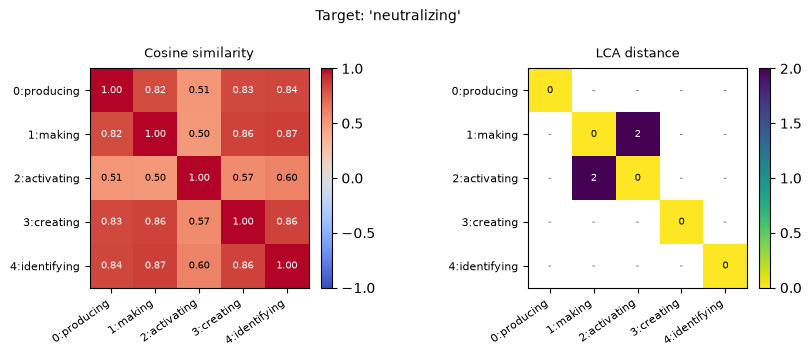


Context: 'When the virulent version of an agent is encountered, the body recognizes the protein coat on the agent, and thus is prepared to respond, by first neutralizing the' | Target: 'target'
Top-5        |     0:agent |   1:protein |       2:vir |     3:virus |      4:path
----------------------------------------------------------------------------------
0:agent      |      1.0000 |      0.6371 |      0.5050 |      0.7276 |      0.6837
1:protein    |      0.6371 |      1.0000 |      0.5307 |      0.7500 |      0.5919
2:vir        |      0.5050 |      0.5307 |      1.0000 |      0.5784 |      0.5226
3:virus      |      0.7276 |      0.7500 |      0.5784 |      1.0000 |      0.6523
4:path       |      0.6837 |      0.5919 |      0.5226 |      0.6523 |      1.0000


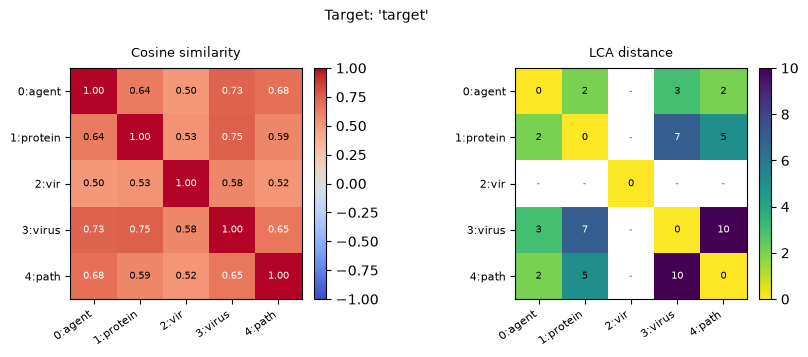


Context: 'When the virulent version of an agent is encountered, the body recognizes the protein coat on the agent, and thus is prepared to respond, by first neutralizing the target' | Target: 'agent'
Top-5        |     0:agent |   1:protein |      2:path |     3:cells |     4:virus
----------------------------------------------------------------------------------
0:agent      |      1.0000 |      0.6371 |      0.6837 |      0.6212 |      0.7276
1:protein    |      0.6371 |      1.0000 |      0.5919 |      0.7742 |      0.7500
2:path       |      0.6837 |      0.5919 |      1.0000 |      0.6311 |      0.6523
3:cells      |      0.6212 |      0.7742 |      0.6311 |      1.0000 |      0.7090
4:virus      |      0.7276 |      0.7500 |      0.6523 |      0.7090 |      1.0000


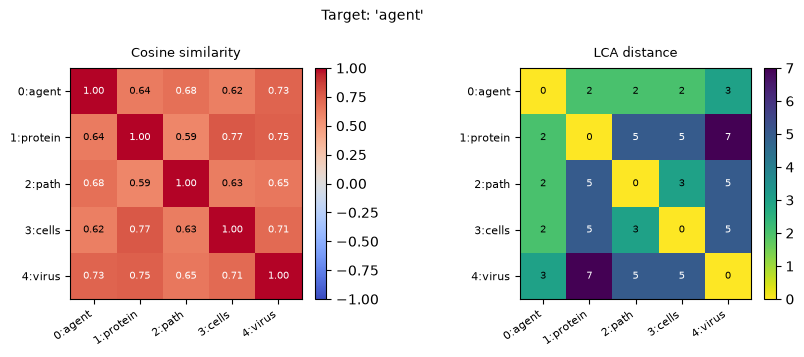


Context: 'When the virulent version of an agent is encountered, the body recognizes the protein coat on the agent, and thus is prepared to respond, by first neutralizing the target agent before it can' | Target: 'enter'
Top-5         |       0:enter |      1:infect |       2:cause |   3:replicate |   4:reproduce
---------------------------------------------------------------------------------------------
0:enter       |        1.0000 |        0.4841 |        0.5701 |        0.5614 |        0.5604
1:infect      |        0.4841 |        1.0000 |        0.5969 |        0.6125 |        0.6342
2:cause       |        0.5701 |        0.5969 |        1.0000 |        0.7533 |        0.7109
3:replicate   |        0.5614 |        0.6125 |        0.7533 |        1.0000 |        0.8175
4:reproduce   |        0.5604 |        0.6342 |        0.7109 |        0.8175 |        1.0000


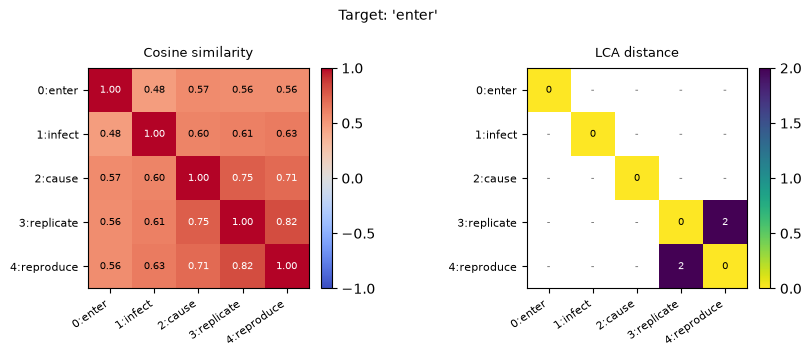


Context: 'When the virulent version of an agent is encountered, the body recognizes the protein coat on the agent, and thus is prepared to respond, by first neutralizing the target agent before it can enter' | Target: 'cells,'
Top-5        |    0:cells |     1:host |    2:human |     3:body |   4:target
-----------------------------------------------------------------------------
0:cells      |     1.0000 |     0.4122 |     0.6144 |     0.6341 |     0.5443
1:host       |     0.4122 |     1.0000 |     0.5302 |     0.4545 |     0.5276
2:human      |     0.6144 |     0.5302 |     1.0000 |     0.6553 |     0.5648
3:body       |     0.6341 |     0.4545 |     0.6553 |     1.0000 |     0.5778
4:target     |     0.5443 |     0.5276 |     0.5648 |     0.5778 |     1.0000


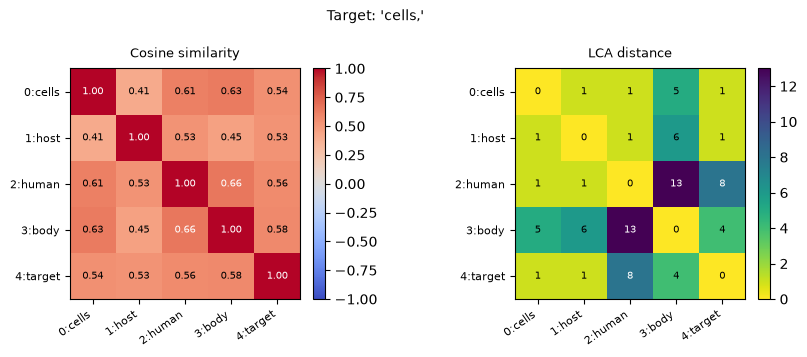


Context: 'When the virulent version of an agent is encountered, the body recognizes the protein coat on the agent, and thus is prepared to respond, by first neutralizing the target agent before it can enter cells, and' | Target: 'secondly'
Top-5            |         0:second |   1:subsequently |      2:producing |     3:destroying |        4:thereby
---------------------------------------------------------------------------------------------------------------
0:second         |           1.0000 |           0.4741 |           0.5134 |           0.5438 |           0.3560
1:subsequently   |           0.4741 |           1.0000 |           0.6461 |           0.6609 |           0.6010
2:producing      |           0.5134 |           0.6461 |           1.0000 |           0.7895 |           0.4842
3:destroying     |           0.5438 |           0.6609 |           0.7895 |           1.0000 |           0.4743
4:thereby        |           0.3560 |           0.6010 |           0.4842 |           0

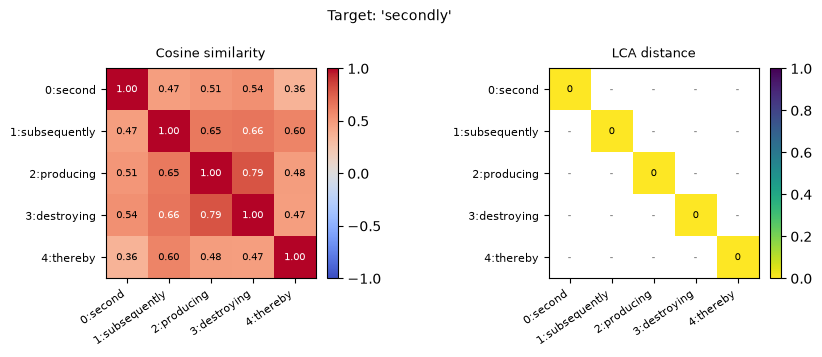


Context: 'When the virulent version of an agent is encountered, the body recognizes the protein coat on the agent, and thus is prepared to respond, by first neutralizing the target agent before it can enter cells, and secondly by' | Target: 'recognizing'
Top-5          |    0:producing |     1:mounting |   2:destroying |     3:creating |       4:making
---------------------------------------------------------------------------------------------------
0:producing    |         1.0000 |         0.8007 |         0.7895 |         0.8307 |         0.8232
1:mounting     |         0.8007 |         1.0000 |         0.7985 |         0.7881 |         0.8593
2:destroying   |         0.7895 |         0.7985 |         1.0000 |         0.8728 |         0.8635
3:creating     |         0.8307 |         0.7881 |         0.8728 |         1.0000 |         0.8591
4:making       |         0.8232 |         0.8593 |         0.8635 |         0.8591 |         1.0000


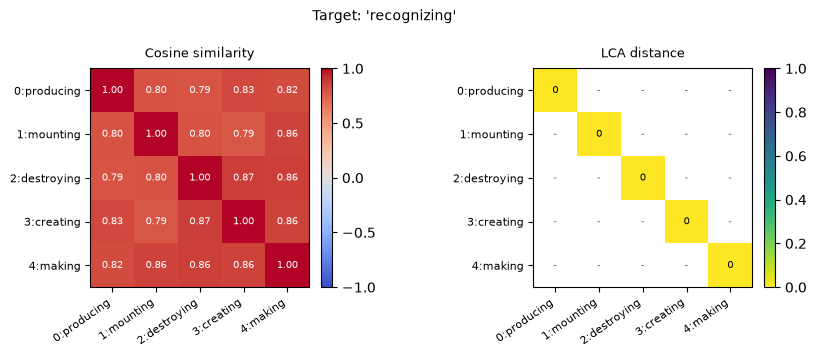


Context: 'When the virulent version of an agent is encountered, the body recognizes the protein coat on the agent, and thus is prepared to respond, by first neutralizing the target agent before it can enter cells, and secondly by recognizing and' | Target: 'destroying'
Top-5           |    0:destroying |   1:eliminating |       2:killing |      3:removing |       4:neutral
---------------------------------------------------------------------------------------------------------
0:destroying    |          1.0000 |          0.8408 |          0.9042 |          0.9020 |          0.7911
1:eliminating   |          0.8408 |          1.0000 |          0.7885 |          0.8136 |          0.8031
2:killing       |          0.9042 |          0.7885 |          1.0000 |          0.8320 |          0.7538
3:removing      |          0.9020 |          0.8136 |          0.8320 |          1.0000 |          0.7486
4:neutral       |          0.7911 |          0.8031 |          0.7538 |          0.7486 |    

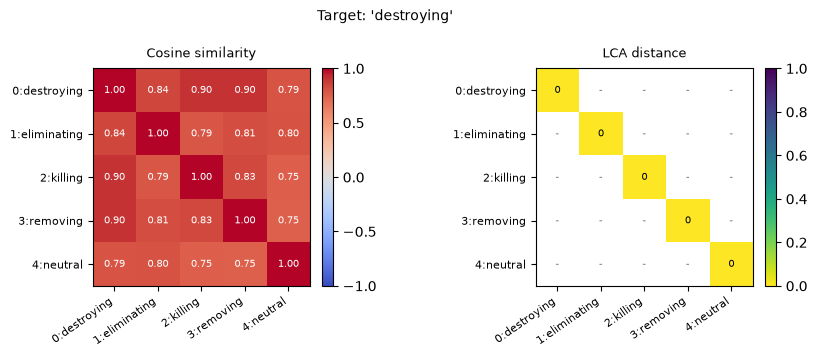


Context: 'When the virulent version of an agent is encountered, the body recognizes the protein coat on the agent, and thus is prepared to respond, by first neutralizing the target agent before it can enter cells, and secondly by recognizing and destroying infected' | Target: 'cells'
Top-5        |    0:cells |     1:host |   2:target |     3:body |     4:cell
-----------------------------------------------------------------------------
0:cells      |     1.0000 |     0.4122 |     0.5443 |     0.6341 |     0.8177
1:host       |     0.4122 |     1.0000 |     0.5276 |     0.4545 |     0.4264
2:target     |     0.5443 |     0.5276 |     1.0000 |     0.5778 |     0.5419
3:body       |     0.6341 |     0.4545 |     0.5778 |     1.0000 |     0.6717
4:cell       |     0.8177 |     0.4264 |     0.5419 |     0.6717 |     1.0000


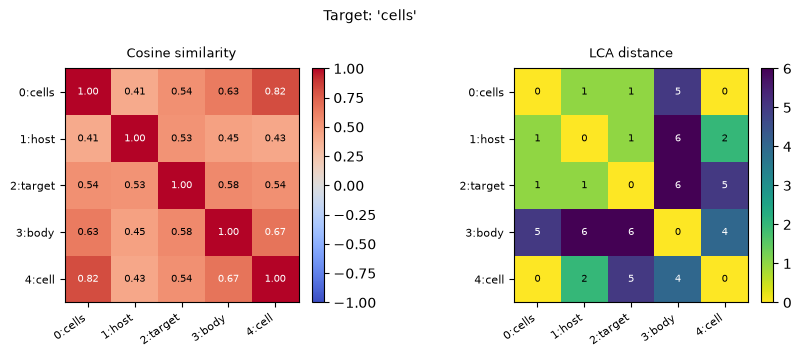


Context: 'When the virulent version of an agent is encountered, the body recognizes the protein coat on the agent, and thus is prepared to respond, by first neutralizing the target agent before it can enter cells, and secondly by recognizing and destroying infected cells before that' | Target: 'agent'
Top-5         |       0:agent |        1:cell |      2:target |   3:infection |         4:vir
---------------------------------------------------------------------------------------------
0:agent       |        1.0000 |        0.7024 |        0.6239 |        0.7187 |        0.5050
1:cell        |        0.7024 |        1.0000 |        0.5419 |        0.7160 |        0.5474
2:target      |        0.6239 |        0.5419 |        1.0000 |        0.6834 |        0.4478
3:infection   |        0.7187 |        0.7160 |        0.6834 |        1.0000 |        0.5791
4:vir         |        0.5050 |        0.5474 |        0.4478 |        0.5791 |        1.0000


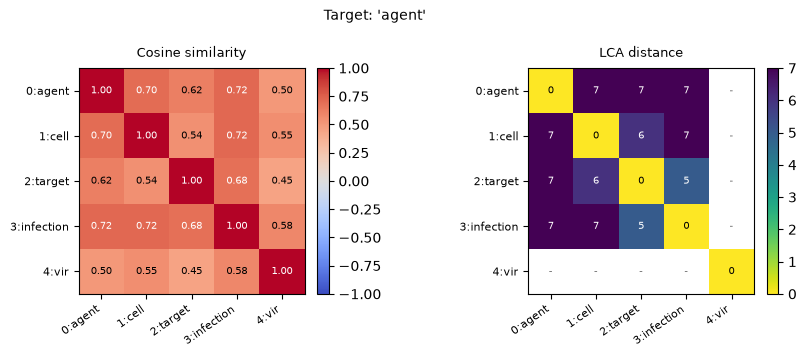


Context: 'When the virulent version of an agent is encountered, the body recognizes the protein coat on the agent, and thus is prepared to respond, by first neutralizing the target agent before it can enter cells, and secondly by recognizing and destroying infected cells before that agent can' | Target: 'multiply'
Top-5         |   0:replicate |    1:multiply |   2:reproduce |      3:spread |     4:produce
---------------------------------------------------------------------------------------------
0:replicate   |        1.0000 |        0.4002 |        0.8175 |        0.8182 |        0.7115
1:multiply    |        0.4002 |        1.0000 |        0.4472 |        0.4210 |        0.4921
2:reproduce   |        0.8175 |        0.4472 |        1.0000 |        0.7552 |        0.7993
3:spread      |        0.8182 |        0.4210 |        0.7552 |        1.0000 |        0.7396
4:produce     |        0.7115 |        0.4921 |        0.7993 |        0.7396 |        1.0000


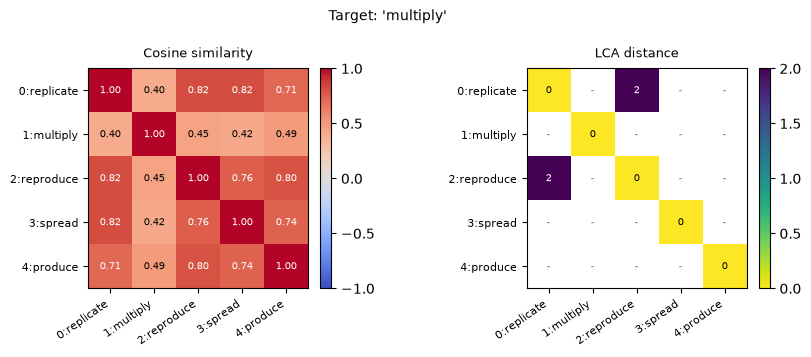


Context: 'When the virulent version of an agent is encountered, the body recognizes the protein coat on the agent, and thus is prepared to respond, by first neutralizing the target agent before it can enter cells, and secondly by recognizing and destroying infected cells before that agent can multiply to vast' | Target: 'numbers.'
Top-5           |       0:numbers |    1:quantities |        2:levels |   3:populations |        4:number
---------------------------------------------------------------------------------------------------------
0:numbers       |          1.0000 |          0.7495 |          0.5642 |          0.5242 |          0.7970
1:quantities    |          0.7495 |          1.0000 |          0.5907 |          0.5499 |          0.7057
2:levels        |          0.5642 |          0.5907 |          1.0000 |          0.5170 |          0.5645
3:populations   |          0.5242 |          0.5499 |          0.5170 |          1.0000 |          0.4990
4:number        |          0.7

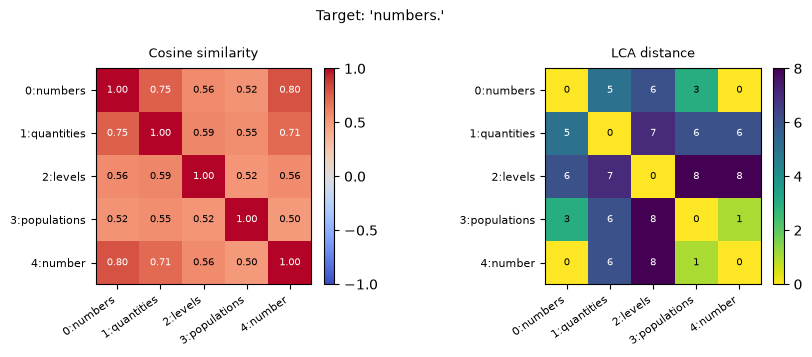


Context: 'In 1958, there were 763,094' | Target: 'cases'
Top-5        |     0:farms |     1:cases |   2:arrests |      3:high |    4:deaths
----------------------------------------------------------------------------------
0:farms      |      1.0000 |      0.6401 |      0.6248 |      0.4569 |      0.6613
1:cases      |      0.6401 |      1.0000 |      0.7461 |      0.5104 |      0.7334
2:arrests    |      0.6248 |      0.7461 |      1.0000 |      0.4837 |      0.7407
3:high       |      0.4569 |      0.5104 |      0.4837 |      1.0000 |      0.4809
4:deaths     |      0.6613 |      0.7334 |      0.7407 |      0.4809 |      1.0000


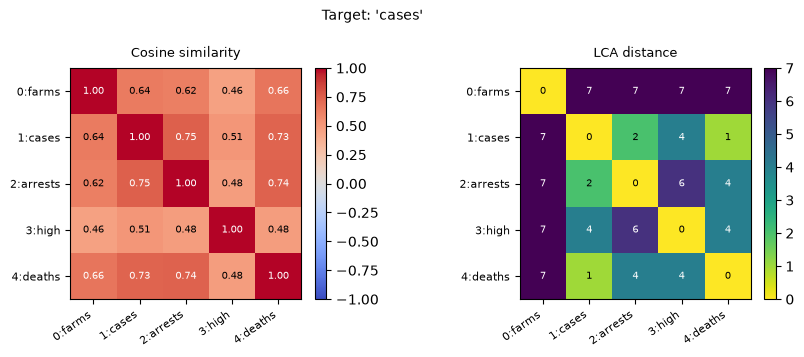


Context: 'In 1958, there were 763,094 cases of' | Target: 'measles'
Top-5        |   0:measles |   1:disease |   2:malaria |   3:illness |       4:gon
----------------------------------------------------------------------------------
0:measles    |      1.0000 |      0.3404 |      0.5237 |      0.3798 |      0.1961
1:disease    |      0.3404 |      1.0000 |      0.5477 |      0.8748 |      0.4857
2:malaria    |      0.5237 |      0.5477 |      1.0000 |      0.5612 |      0.2100
3:illness    |      0.3798 |      0.8748 |      0.5612 |      1.0000 |      0.4150
4:gon        |      0.1961 |      0.4857 |      0.2100 |      0.4150 |      1.0000


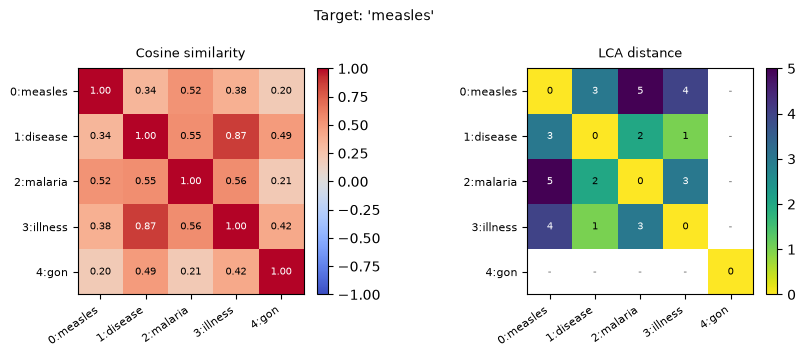


Context: 'In 1958, there were 763,094 cases of measles in the United' | Target: 'States;'
Top-5        |    0:states |         1:n |     2:state |   3:kingdom |        4:st
----------------------------------------------------------------------------------
0:states     |      1.0000 |      0.3750 |      0.6807 |      0.5261 |      0.3265
1:n          |      0.3750 |      1.0000 |      0.4750 |      0.5696 |      0.6046
2:state      |      0.6807 |      0.4750 |      1.0000 |      0.5287 |      0.4127
3:kingdom    |      0.5261 |      0.5696 |      0.5287 |      1.0000 |      0.5671
4:st         |      0.3265 |      0.6046 |      0.4127 |      0.5671 |      1.0000


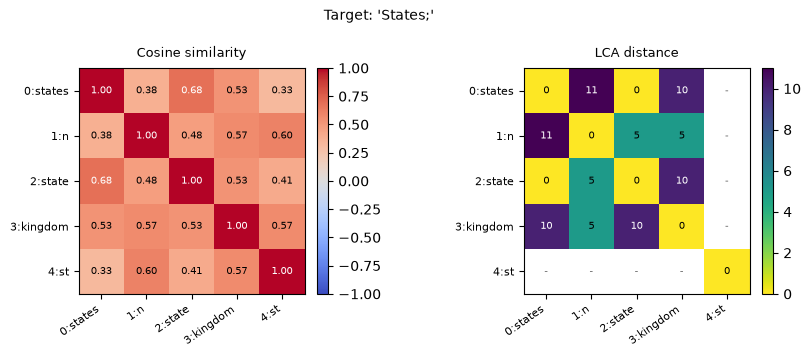


Context: 'In 1958, there were 763,094 cases of measles in the United States; 552' | Target: 'deaths'
Top-5        |   0:people |   1:deaths |    2:cases |    3:three |     4:died
-----------------------------------------------------------------------------
0:people     |     1.0000 |     0.7441 |     0.6962 |     0.5240 |     0.6149
1:deaths     |     0.7441 |     1.0000 |     0.7334 |     0.5357 |     0.6689
2:cases      |     0.6962 |     0.7334 |     1.0000 |     0.5269 |     0.5492
3:three      |     0.5240 |     0.5357 |     0.5269 |     1.0000 |     0.4200
4:died       |     0.6149 |     0.6689 |     0.5492 |     0.4200 |     1.0000


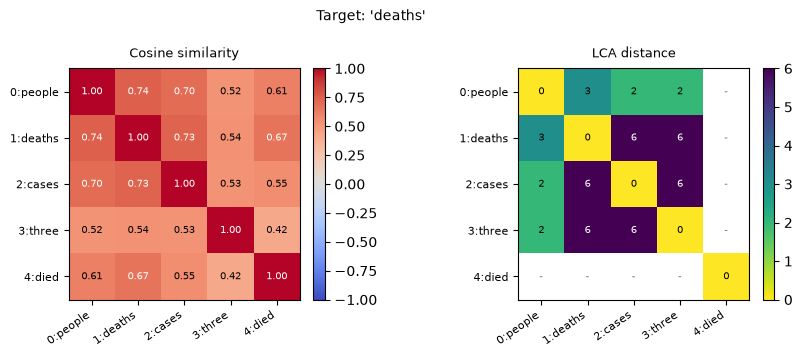


Context: 'In 1958, there were 763,094 cases of measles in the United States; 552 deaths' | Target: 'resulted.'
Top-5         |    0:resulted |    1:occurred |   2:resulting |         3:due |      4:ensued
---------------------------------------------------------------------------------------------
0:resulted    |        1.0000 |        0.7528 |        0.7867 |        0.8028 |        0.8725
1:occurred    |        0.7528 |        1.0000 |        0.6364 |        0.6861 |        0.8000
2:resulting   |        0.7867 |        0.6364 |        1.0000 |        0.7092 |        0.7169
3:due         |        0.8028 |        0.6861 |        0.7092 |        1.0000 |        0.7662
4:ensued      |        0.8725 |        0.8000 |        0.7169 |        0.7662 |        1.0000


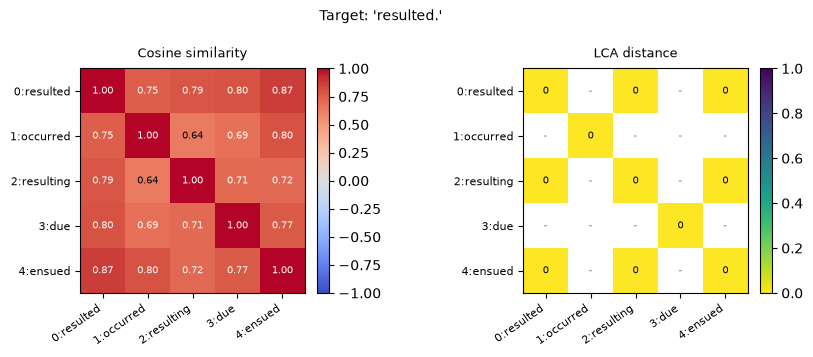


Context: 'After the' | Target: 'introduction'
Top-5            |     0:completion |       1:founding |          2:first |           3:work |   4:installation
---------------------------------------------------------------------------------------------------------------
0:completion     |           1.0000 |           0.6134 |           0.5089 |           0.5193 |           0.6557
1:founding       |           0.6134 |           1.0000 |           0.5530 |           0.5271 |           0.7093
2:first          |           0.5089 |           0.5530 |           1.0000 |           0.5576 |           0.5156
3:work           |           0.5193 |           0.5271 |           0.5576 |           1.0000 |           0.5929
4:installation   |           0.6557 |           0.7093 |           0.5156 |           0.5929 |           1.0000


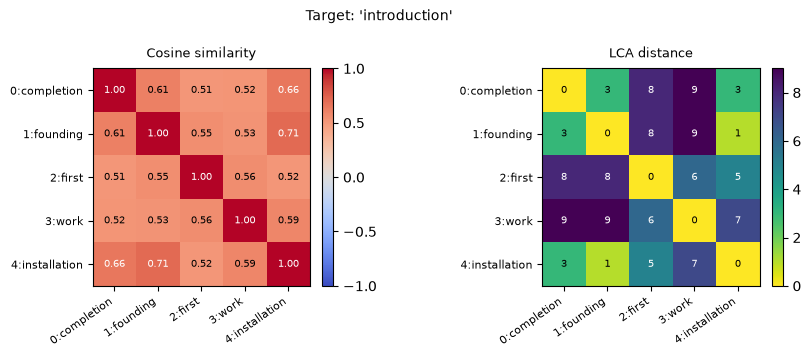


Context: 'After the introduction of new' | Target: 'vaccines,'
Top-5            |     0:technology |   1:technologies |    2:regulations |      3:equipment |      4:processes
---------------------------------------------------------------------------------------------------------------
0:technology     |           1.0000 |           0.8196 |           0.5106 |           0.6447 |           0.5993
1:technologies   |           0.8196 |           1.0000 |           0.5353 |           0.5951 |           0.7243
2:regulations    |           0.5106 |           0.5353 |           1.0000 |           0.4859 |           0.5870
3:equipment      |           0.6447 |           0.5951 |           0.4859 |           1.0000 |           0.5072
4:processes      |           0.5993 |           0.7243 |           0.5870 |           0.5072 |           1.0000


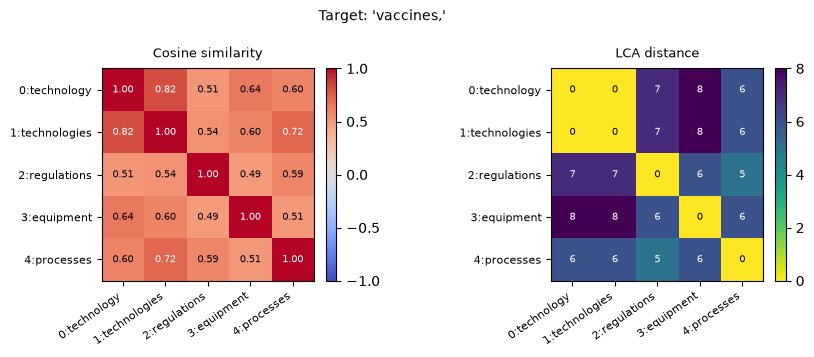


Context: 'After the introduction of new vaccines, the' | Target: 'number'
Top-5          |    0:incidence |       1:number |   2:proportion |   3:prevalence |         4:rate
---------------------------------------------------------------------------------------------------
0:incidence    |         1.0000 |         0.6104 |         0.7384 |         0.8526 |         0.6368
1:number       |         0.6104 |         1.0000 |         0.6999 |         0.7228 |         0.7135
2:proportion   |         0.7384 |         0.6999 |         1.0000 |         0.7635 |         0.6896
3:prevalence   |         0.8526 |         0.7228 |         0.7635 |         1.0000 |         0.7449
4:rate         |         0.6368 |         0.7135 |         0.6896 |         0.7449 |         1.0000


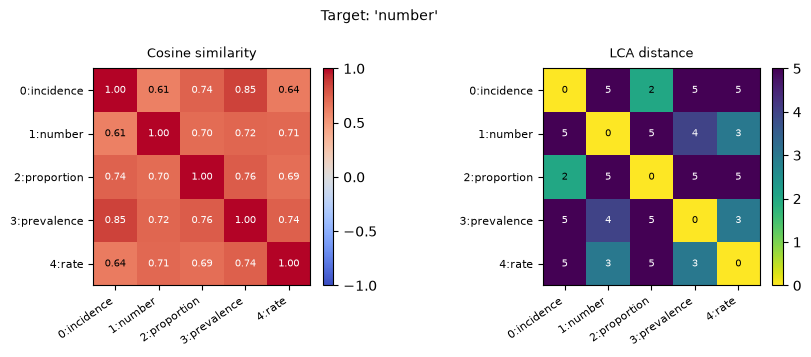


Context: 'After the introduction of new vaccines, the number of' | Target: 'cases'
Top-5        |      0:cases |     1:people |   2:children |    3:measles |     4:deaths
---------------------------------------------------------------------------------------
0:cases      |       1.0000 |       0.6962 |       0.5217 |       0.2077 |       0.7334
1:people     |       0.6962 |       1.0000 |       0.6592 |       0.2054 |       0.7441
2:children   |       0.5217 |       0.6592 |       1.0000 |       0.2567 |       0.6045
3:measles    |       0.2077 |       0.2054 |       0.2567 |       1.0000 |       0.2919
4:deaths     |       0.7334 |       0.7441 |       0.6045 |       0.2919 |       1.0000


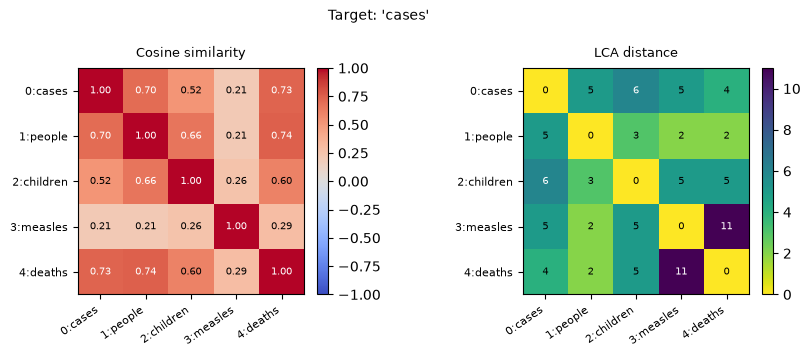


Context: 'After the introduction of new vaccines, the number of cases' | Target: 'dropped'
Top-5         |         0:per |     1:dropped |      2:caused |   3:involving |       4:among
---------------------------------------------------------------------------------------------
0:per         |        1.0000 |        0.6160 |        0.6488 |        0.6642 |        0.5874
1:dropped     |        0.6160 |        1.0000 |        0.7415 |        0.8113 |        0.6451
2:caused      |        0.6488 |        0.7415 |        1.0000 |        0.8172 |        0.6278
3:involving   |        0.6642 |        0.8113 |        0.8172 |        1.0000 |        0.6836
4:among       |        0.5874 |        0.6451 |        0.6278 |        0.6836 |        1.0000


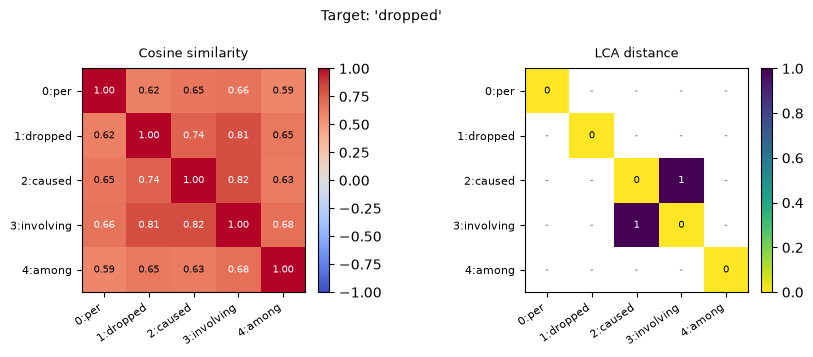


Context: 'After the introduction of new vaccines, the number of cases dropped to fewer than 150' | Target: 'per'
Top-5        |        0:per |      1:cases |   2:annually |   3:thousand |     4:yearly
---------------------------------------------------------------------------------------
0:per        |       1.0000 |       0.5881 |       0.4889 |       0.5482 |       0.5613
1:cases      |       0.5881 |       1.0000 |       0.5056 |       0.6458 |       0.6059
2:annually   |       0.4889 |       0.5056 |       1.0000 |       0.5110 |       0.8887
3:thousand   |       0.5482 |       0.6458 |       0.5110 |       1.0000 |       0.5888
4:yearly     |       0.5613 |       0.6059 |       0.8887 |       0.5888 |       1.0000


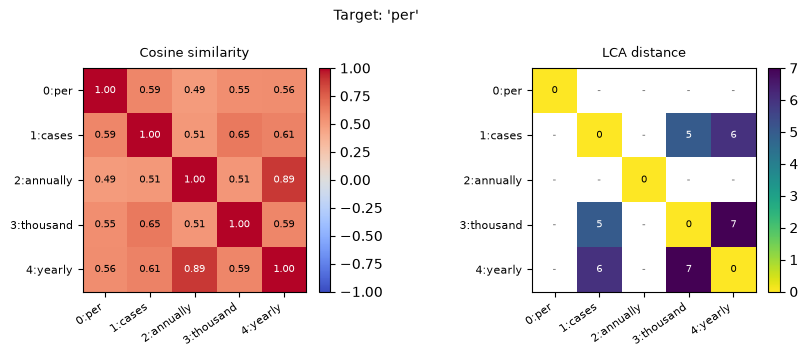


Context: 'After the introduction of new vaccines, the number of cases dropped to fewer than 150 per' | Target: 'year'
Top-5        |     0:year |     1:week |    2:month |      3:day |    4:annum
-----------------------------------------------------------------------------
0:year       |     1.0000 |     0.4826 |     0.5603 |     0.4697 |     0.3338
1:week       |     0.4826 |     1.0000 |     0.7832 |     0.6772 |     0.4860
2:month      |     0.5603 |     0.7832 |     1.0000 |     0.6649 |     0.5631
3:day        |     0.4697 |     0.6772 |     0.6649 |     1.0000 |     0.4361
4:annum      |     0.3338 |     0.4860 |     0.5631 |     0.4361 |     1.0000


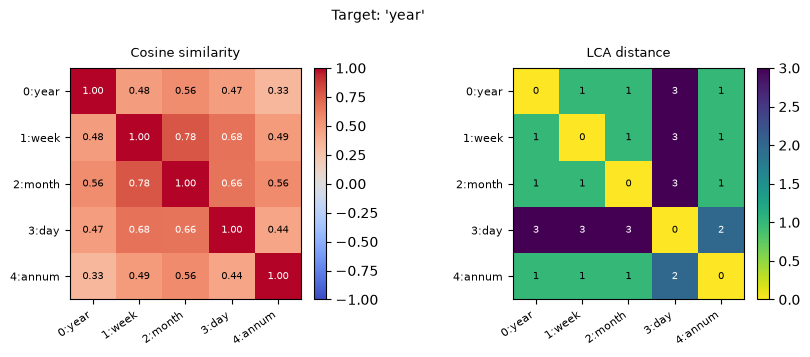


Context: 'After the introduction of new vaccines, the number of cases dropped to fewer than 150 per year' | Target: '(median'
Top-5        |   0:globally |     1:around |     2:across |          3:n |      4:since
---------------------------------------------------------------------------------------
0:globally   |       1.0000 |       0.7371 |       0.6873 |       0.5845 |       0.6546
1:around     |       0.7371 |       1.0000 |       0.7055 |       0.6058 |       0.6619
2:across     |       0.6873 |       0.7055 |       1.0000 |       0.5127 |       0.5967
3:n          |       0.5845 |       0.6058 |       0.5127 |       1.0000 |       0.5726
4:since      |       0.6546 |       0.6619 |       0.5967 |       0.5726 |       1.0000


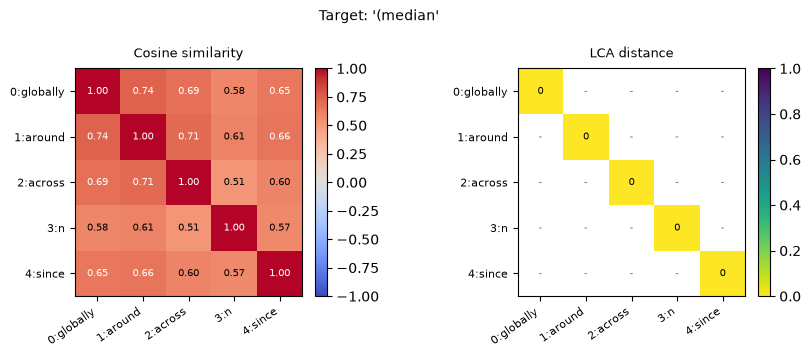


Context: 'In early 2008, there were 64 suspected' | Target: 'cases'
Top-5        |    0:cases |       1:sw |    2:ebola |        3:h |     4:chol
-----------------------------------------------------------------------------
0:cases      |     1.0000 |     0.6786 |     0.5071 |     0.6084 |     0.4904
1:sw         |     0.6786 |     1.0000 |     0.5040 |     0.6348 |     0.5263
2:ebola      |     0.5071 |     0.5040 |     1.0000 |     0.4770 |     0.4703
3:h          |     0.6084 |     0.6348 |     0.4770 |     1.0000 |     0.4714
4:chol       |     0.4904 |     0.5263 |     0.4703 |     0.4714 |     1.0000


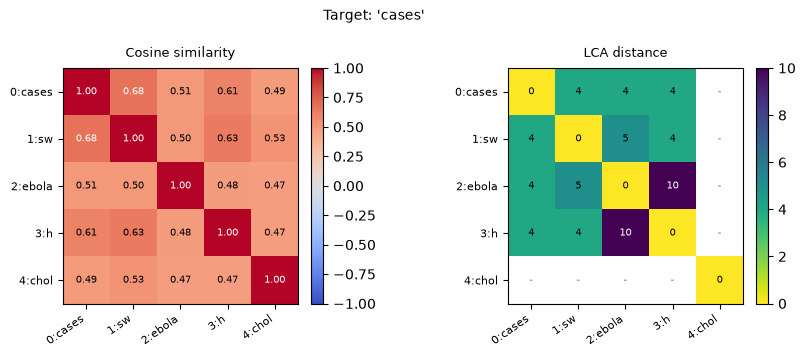


Context: 'In early 2008, there were 64 suspected cases of' | Target: 'measles.'
Top-5        |       0:sw |     1:hand |       2:av |        3:h |     4:bird
-----------------------------------------------------------------------------
0:sw         |     1.0000 |     0.6156 |     0.7335 |     0.6348 |     0.6709
1:hand       |     0.6156 |     1.0000 |     0.5699 |     0.5342 |     0.6687
2:av         |     0.7335 |     0.5699 |     1.0000 |     0.5886 |     0.6060
3:h          |     0.6348 |     0.5342 |     0.5886 |     1.0000 |     0.5626
4:bird       |     0.6709 |     0.6687 |     0.6060 |     0.5626 |     1.0000


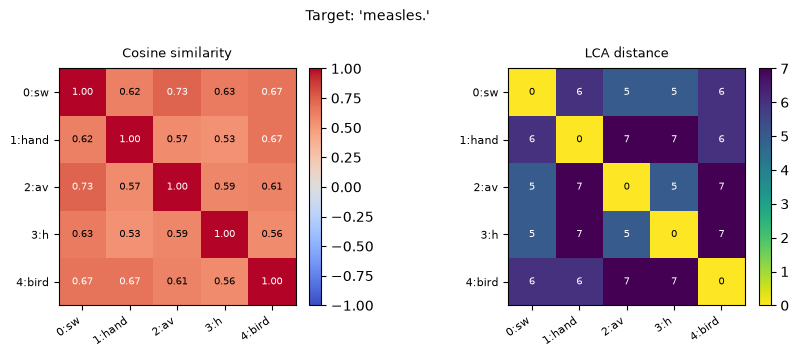


Context: 'Fifty-four of those' | Target: 'infections'
Top-5        |     0:killed |     1:people |   2:arrested |     3:deaths |      4:cases
---------------------------------------------------------------------------------------
0:killed     |       1.0000 |       0.6847 |       0.8043 |       0.7701 |       0.6106
1:people     |       0.6847 |       1.0000 |       0.6860 |       0.7441 |       0.6962
2:arrested   |       0.8043 |       0.6860 |       1.0000 |       0.7177 |       0.7153
3:deaths     |       0.7701 |       0.7441 |       0.7177 |       1.0000 |       0.7334
4:cases      |       0.6106 |       0.6962 |       0.7153 |       0.7334 |       1.0000


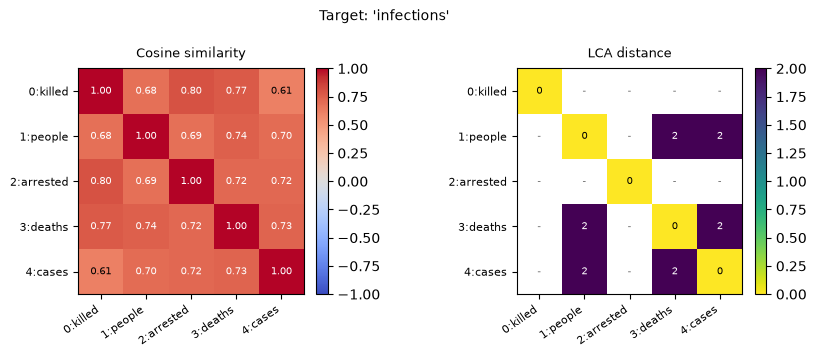


Context: 'Fifty-four of those infections were' | Target: 'associated'
Top-5          |        0:among |        1:found |   2:associated |       3:caused |    4:diagnosed
---------------------------------------------------------------------------------------------------
0:among        |         1.0000 |         0.5934 |         0.6689 |         0.6278 |         0.6765
1:found        |         0.5934 |         1.0000 |         0.6508 |         0.7094 |         0.7520
2:associated   |         0.6689 |         0.6508 |         1.0000 |         0.8516 |         0.7998
3:caused       |         0.6278 |         0.7094 |         0.8516 |         1.0000 |         0.8486
4:diagnosed    |         0.6765 |         0.7520 |         0.7998 |         0.8486 |         1.0000


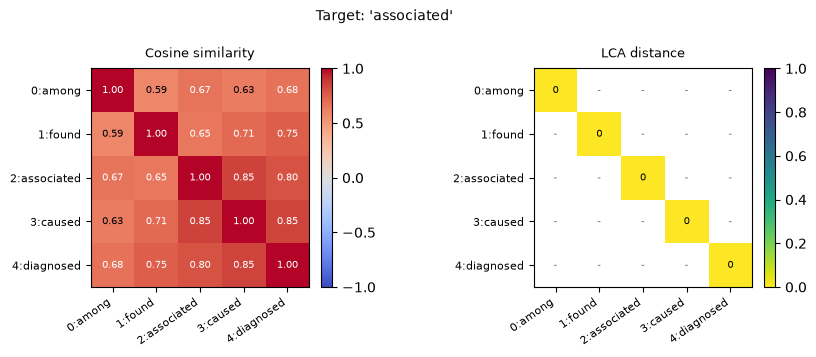


Context: 'Fifty-four of those infections were associated with' | Target: 'importation'
Top-5         |   0:outbreaks |      1:travel |      2:eating |    3:exposure |        4:food
---------------------------------------------------------------------------------------------
0:outbreaks   |        1.0000 |        0.4286 |        0.3689 |        0.5463 |        0.3977
1:travel      |        0.4286 |        1.0000 |        0.5438 |        0.5697 |        0.5473
2:eating      |        0.3689 |        0.5438 |        1.0000 |        0.6892 |        0.8181
3:exposure    |        0.5463 |        0.5697 |        0.6892 |        1.0000 |        0.6544
4:food        |        0.3977 |        0.5473 |        0.8181 |        0.6544 |        1.0000


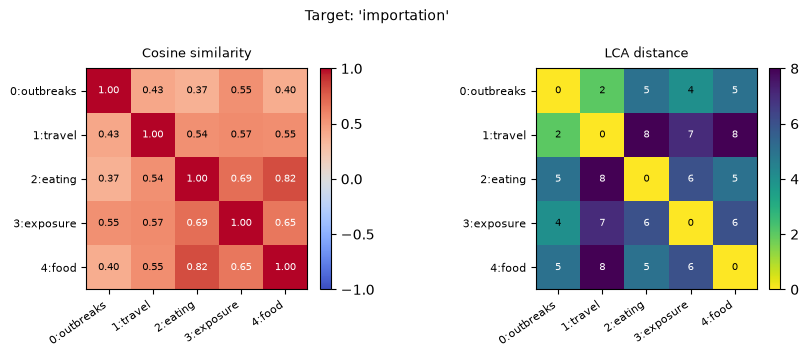


Context: 'Fifty-four of those infections were associated with importation from another' | Target: 'country,'
Top-5        |   0:country |     1:state |      2:area |    3:county |    4:region
----------------------------------------------------------------------------------
0:country    |      1.0000 |      0.5623 |      0.3826 |      0.4504 |      0.5743
1:state      |      0.5623 |      1.0000 |      0.5299 |      0.6864 |      0.5536
2:area       |      0.3826 |      0.5299 |      1.0000 |      0.6319 |      0.4318
3:county     |      0.4504 |      0.6864 |      0.6319 |      1.0000 |      0.4024
4:region     |      0.5743 |      0.5536 |      0.4318 |      0.4024 |      1.0000


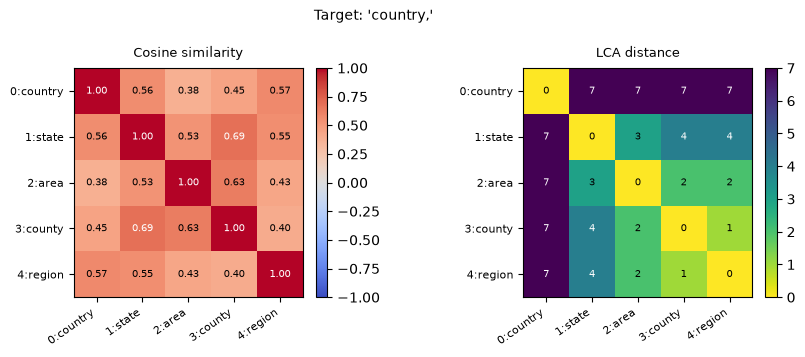


Context: 'Fifty-four of those infections were associated with importation from another country,' | Target: 'although'
Top-5         |   0:including |         1:cdc |      2:mostly |   3:primarily |     4:usually
---------------------------------------------------------------------------------------------
0:including   |        1.0000 |        0.5203 |        0.6628 |        0.8000 |        0.6974
1:cdc         |        0.5203 |        1.0000 |        0.5244 |        0.6132 |        0.5696
2:mostly      |        0.6628 |        0.5244 |        1.0000 |        0.8349 |        0.8667
3:primarily   |        0.8000 |        0.6132 |        0.8349 |        1.0000 |        0.8399
4:usually     |        0.6974 |        0.5696 |        0.8667 |        0.8399 |        1.0000


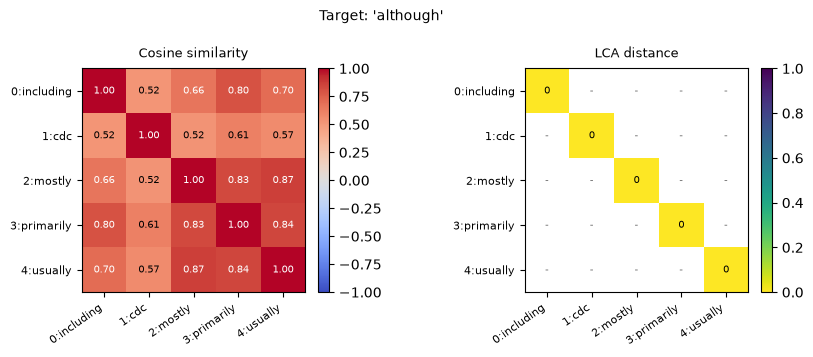


Context: 'Fifty-four of those infections were associated with importation from another country, although only' | Target: 'thirteen'
Top-5        |    0:three |     1:four |     2:five |      3:six |    4:eight
-----------------------------------------------------------------------------
0:three      |     1.0000 |     0.8457 |     0.8208 |     0.7322 |     0.7132
1:four       |     0.8457 |     1.0000 |     0.8584 |     0.8026 |     0.8148
2:five       |     0.8208 |     0.8584 |     1.0000 |     0.8797 |     0.8350
3:six        |     0.7322 |     0.8026 |     0.8797 |     1.0000 |     0.8794
4:eight      |     0.7132 |     0.8148 |     0.8350 |     0.8794 |     1.0000


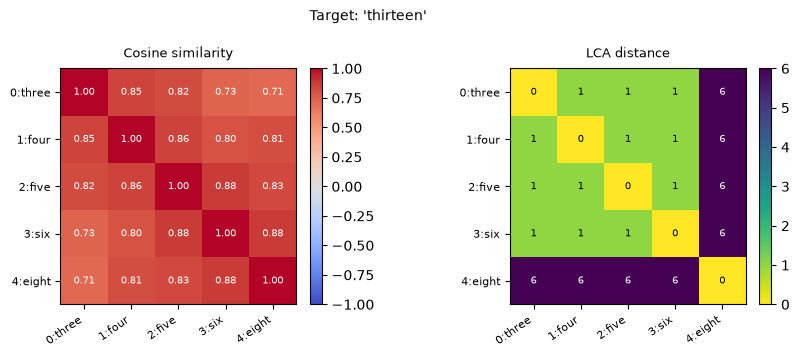


Context: 'Fifty-four of those infections were associated with importation from another country, although only thirteen' | Target: 'percent'
Top-5        |      0:cases |    1:percent |   2:patients |     3:people |   4:occurred
---------------------------------------------------------------------------------------
0:cases      |       1.0000 |       0.6853 |       0.6698 |       0.6962 |       0.6841
1:percent    |       0.6853 |       1.0000 |       0.4991 |       0.6084 |       0.6642
2:patients   |       0.6698 |       0.4991 |       1.0000 |       0.6521 |       0.4649
3:people     |       0.6962 |       0.6084 |       0.6521 |       1.0000 |       0.5879
4:occurred   |       0.6841 |       0.6642 |       0.4649 |       0.5879 |       1.0000


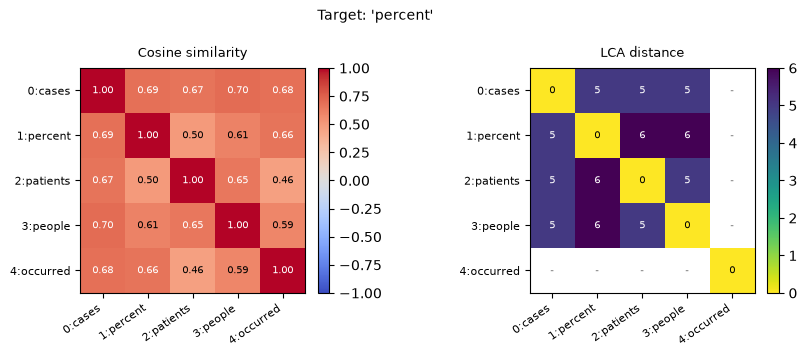


Context: 'Fifty-four of those infections were associated with importation from another country, although only thirteen percent were' | Target: 'actually'
Top-5          |        0:sympt |     1:actually |   2:associated |      3:thought |     4:directly
---------------------------------------------------------------------------------------------------
0:sympt        |         1.0000 |         0.4847 |         0.5737 |         0.5603 |         0.5721
1:actually     |         0.4847 |         1.0000 |         0.4954 |         0.5231 |         0.6066
2:associated   |         0.5737 |         0.4954 |         1.0000 |         0.6185 |         0.7535
3:thought      |         0.5603 |         0.5231 |         0.6185 |         1.0000 |         0.6484
4:directly     |         0.5721 |         0.6066 |         0.7535 |         0.6484 |         1.0000


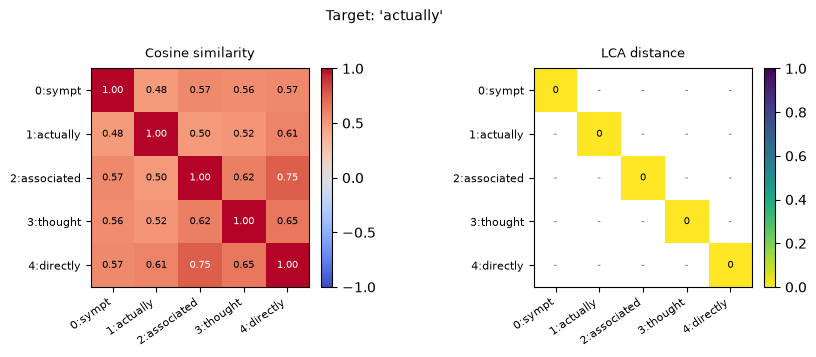


Context: 'Fifty-four of those infections were associated with importation from another country, although only thirteen percent were actually acquired' | Target: 'outside'
Top-5               |           0:outside |            1:within |           2:locally |         3:elsewhere |   4:internationally
---------------------------------------------------------------------------------------------------------------------------------
0:outside           |              1.0000 |              0.6208 |              0.6603 |              0.6394 |              0.6391
1:within            |              0.6208 |              1.0000 |              0.7669 |              0.8526 |              0.7183
2:locally           |              0.6603 |              0.7669 |              1.0000 |              0.8030 |              0.7633
3:elsewhere         |              0.6394 |              0.8526 |              0.8030 |              1.0000 |              0.7565
4:internationally   |              0.6391 |     

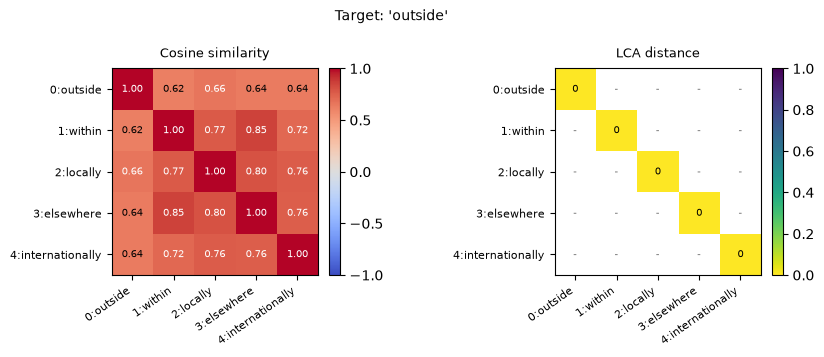


Context: 'Fifty-four of those infections were associated with importation from another country, although only thirteen percent were actually acquired outside the United' | Target: 'States;'
Top-5        |    0:states |   1:kingdom |     2:state |        3:st |      4:arab
----------------------------------------------------------------------------------
0:states     |      1.0000 |      0.5261 |      0.6807 |      0.3265 |      0.4322
1:kingdom    |      0.5261 |      1.0000 |      0.5287 |      0.5671 |      0.6991
2:state      |      0.6807 |      0.5287 |      1.0000 |      0.4127 |      0.4839
3:st         |      0.3265 |      0.5671 |      0.4127 |      1.0000 |      0.6214
4:arab       |      0.4322 |      0.6991 |      0.4839 |      0.6214 |      1.0000


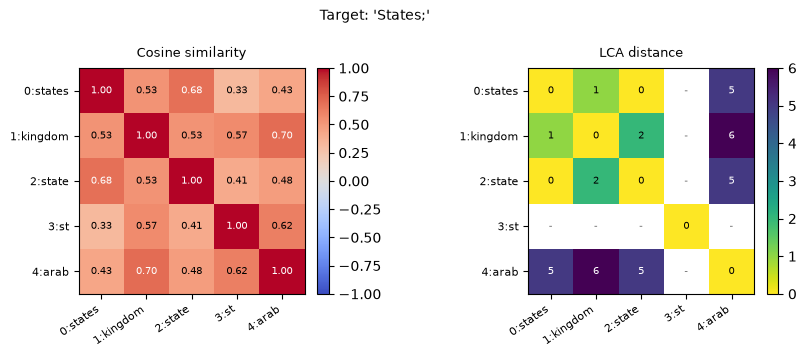


Context: 'Fifty-four of those infections were associated with importation from another country, although only thirteen percent were actually acquired outside the United States; 63 of the 64' | Target: 'individuals'
Top-5          |        0:cases |   1:infections |            2:u |     3:hospital |       4:deaths
---------------------------------------------------------------------------------------------------
0:cases        |         1.0000 |         0.7628 |         0.5343 |         0.6841 |         0.7334
1:infections   |         0.7628 |         1.0000 |         0.6008 |         0.7529 |         0.7274
2:u            |         0.5343 |         0.6008 |         1.0000 |         0.6190 |         0.5226
3:hospital     |         0.6841 |         0.7529 |         0.6190 |         1.0000 |         0.6984
4:deaths       |         0.7334 |         0.7274 |         0.5226 |         0.6984 |         1.0000


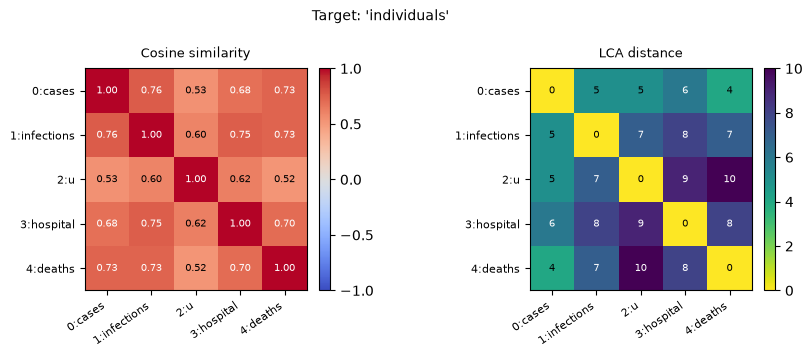


Context: 'Fifty-four of those infections were associated with importation from another country, although only thirteen percent were actually acquired outside the United States; 63 of the 64 individuals' | Target: 'either'
Top-5            |      0:diagnosed |     1:associated |         2:became |   3:hospitalized |          4:lived
---------------------------------------------------------------------------------------------------------------
0:diagnosed      |           1.0000 |           0.7998 |           0.7978 |           0.8870 |           0.7074
1:associated     |           0.7998 |           1.0000 |           0.6976 |           0.7303 |           0.6188
2:became         |           0.7978 |           0.6976 |           1.0000 |           0.7219 |           0.7349
3:hospitalized   |           0.8870 |           0.7303 |           0.7219 |           1.0000 |           0.6717
4:lived          |           0.7074 |           0.6188 |           0.7349 |           0.6717 |           

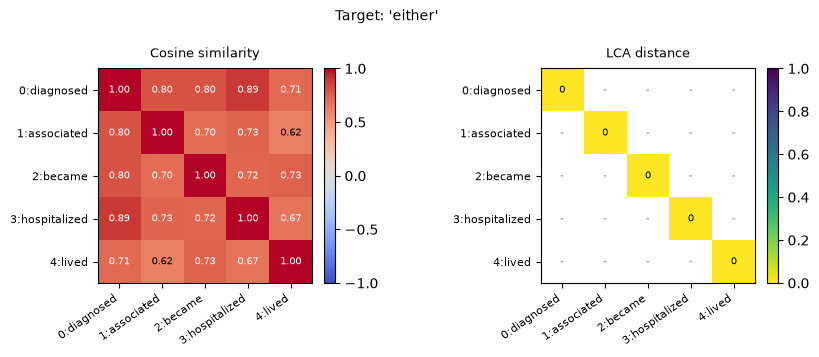


Context: 'Fifty-four of those infections were associated with importation from another country, although only thirteen percent were actually acquired outside the United States; 63 of the 64 individuals either had' | Target: 'never'
Top-5        |     0:recent |   1:recently |     2:direct |     3:travel |    4:visited
---------------------------------------------------------------------------------------
0:recent     |       1.0000 |       0.8548 |       0.6421 |       0.5669 |       0.6726
1:recently   |       0.8548 |       1.0000 |       0.5970 |       0.5335 |       0.6561
2:direct     |       0.6421 |       0.5970 |       1.0000 |       0.5273 |       0.5587
3:travel     |       0.5669 |       0.5335 |       0.5273 |       1.0000 |       0.6471
4:visited    |       0.6726 |       0.6561 |       0.5587 |       0.6471 |       1.0000


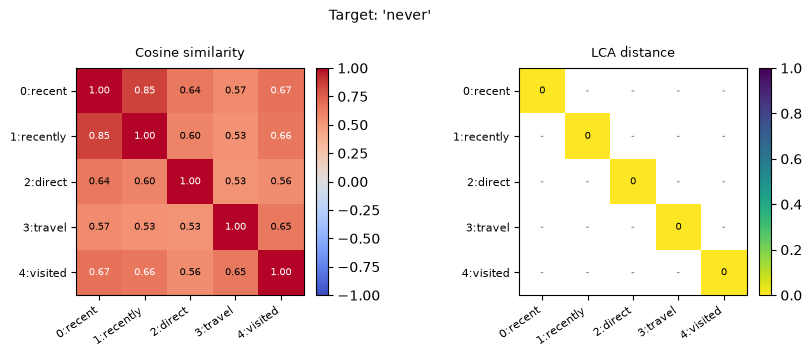


Context: 'Fifty-four of those infections were associated with importation from another country, although only thirteen percent were actually acquired outside the United States; 63 of the 64 individuals either had never been vaccinated against' | Target: 'measles'
Top-5         |     0:measles |         1:pol |   2:influenza |      3:mening |   4:hepatitis
---------------------------------------------------------------------------------------------
0:measles     |        1.0000 |        0.1485 |        0.4024 |        0.2745 |        0.3463
1:pol         |        0.1485 |        1.0000 |        0.6984 |        0.5603 |        0.7039
2:influenza   |        0.4024 |        0.6984 |        1.0000 |        0.5716 |        0.8750
3:mening      |        0.2745 |        0.5603 |        0.5716 |        1.0000 |        0.5855
4:hepatitis   |        0.3463 |        0.7039 |        0.8750 |        0.5855 |        1.0000


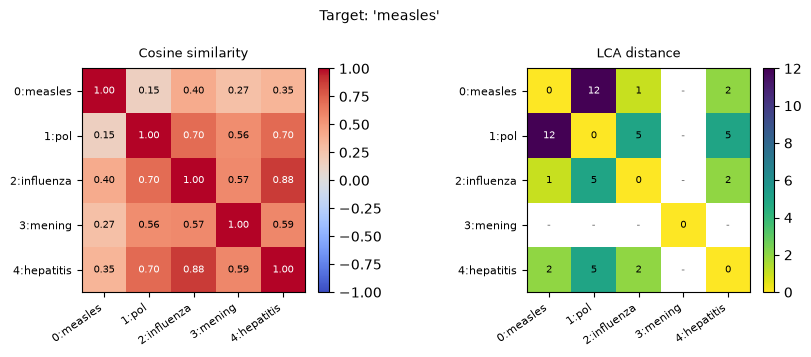


Context: 'Fifty-four of those infections were associated with importation from another country, although only thirteen percent were actually acquired outside the United States; 63 of the 64 individuals either had never been vaccinated against measles or were uncertain' | Target: 'whether'
Top-5          |      0:whether |    1:regarding |   2:concerning |          3:due |      4:vaccine
---------------------------------------------------------------------------------------------------
0:whether      |         1.0000 |         0.6199 |         0.6893 |         0.5849 |         0.6265
1:regarding    |         0.6199 |         1.0000 |         0.9066 |         0.8164 |         0.8056
2:concerning   |         0.6893 |         0.9066 |         1.0000 |         0.7657 |         0.7926
3:due          |         0.5849 |         0.8164 |         0.7657 |         1.0000 |         0.8137
4:vaccine      |         0.6265 |         0.8056 |         0.7926 |         0.8137 |         1.0000


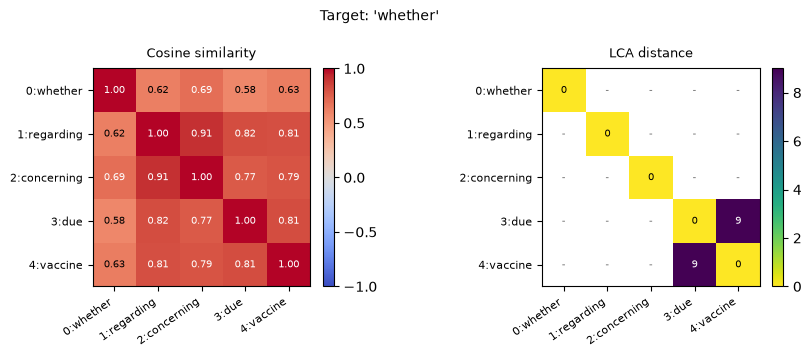


Context: 'The' | Target: 'measles'
Top-5         |   0:following |         1:sum |      2:purple |    3:function |      4:number
---------------------------------------------------------------------------------------------
0:following   |        1.0000 |        0.5209 |        0.5680 |        0.4828 |        0.5987
1:sum         |        0.5209 |        1.0000 |        0.5980 |        0.6384 |        0.6528
2:purple      |        0.5680 |        0.5980 |        1.0000 |        0.5516 |        0.7352
3:function    |        0.4828 |        0.6384 |        0.5516 |        1.0000 |        0.6338
4:number      |        0.5987 |        0.6528 |        0.7352 |        0.6338 |        1.0000


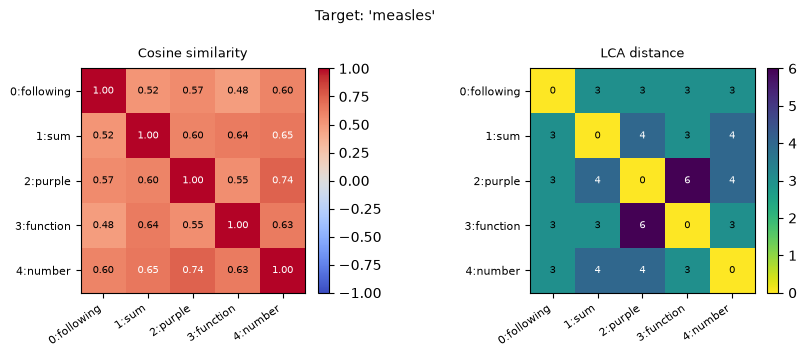


Context: 'The measles' | Target: 'vaccine'
Top-5          |     0:epidemic |      1:control |   2:population |         3:test |      4:vaccine
---------------------------------------------------------------------------------------------------
0:epidemic     |         1.0000 |         0.7411 |         0.5562 |         0.6678 |         0.8877
1:control      |         0.7411 |         1.0000 |         0.5187 |         0.6948 |         0.7594
2:population   |         0.5562 |         0.5187 |         1.0000 |         0.5615 |         0.5599
3:test         |         0.6678 |         0.6948 |         0.5615 |         1.0000 |         0.7079
4:vaccine      |         0.8877 |         0.7594 |         0.5599 |         0.7079 |         1.0000


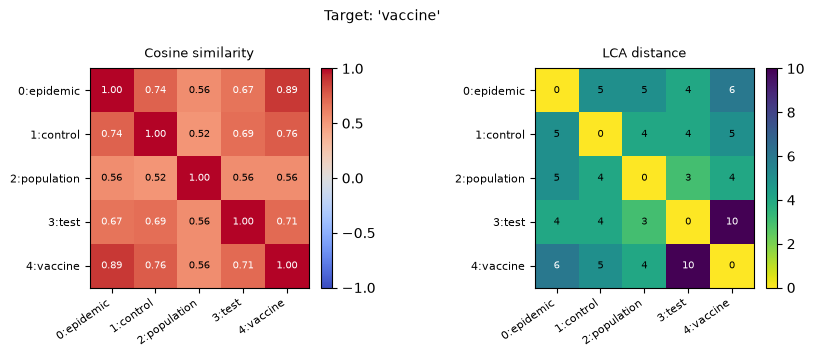


Context: 'The measles vaccine is' | Target: 'estimated'
Top-5            |           0:part |         1:highly |          2:given |   3:administered |        4:usually
---------------------------------------------------------------------------------------------------------------
0:part           |           1.0000 |           0.4432 |           0.4123 |           0.4570 |           0.4499
1:highly         |           0.4432 |           1.0000 |           0.7586 |           0.7976 |           0.7311
2:given          |           0.4123 |           0.7586 |           1.0000 |           0.7932 |           0.6632
3:administered   |           0.4570 |           0.7976 |           0.7932 |           1.0000 |           0.6957
4:usually        |           0.4499 |           0.7311 |           0.6632 |           0.6957 |           1.0000


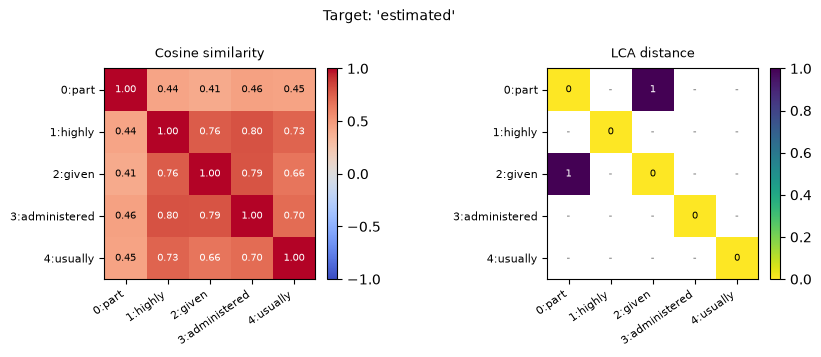


Context: 'The measles vaccine is estimated to' | Target: 'prevent'
Top-5        |   0:prevent |      1:save |      2:cost |    3:reduce |   4:protect
----------------------------------------------------------------------------------
0:prevent    |      1.0000 |      0.7912 |      0.6827 |      0.8595 |      0.7785
1:save       |      0.7912 |      1.0000 |      0.6172 |      0.7243 |      0.8117
2:cost       |      0.6827 |      0.6172 |      1.0000 |      0.7279 |      0.5640
3:reduce     |      0.8595 |      0.7243 |      0.7279 |      1.0000 |      0.7179
4:protect    |      0.7785 |      0.8117 |      0.5640 |      0.7179 |      1.0000


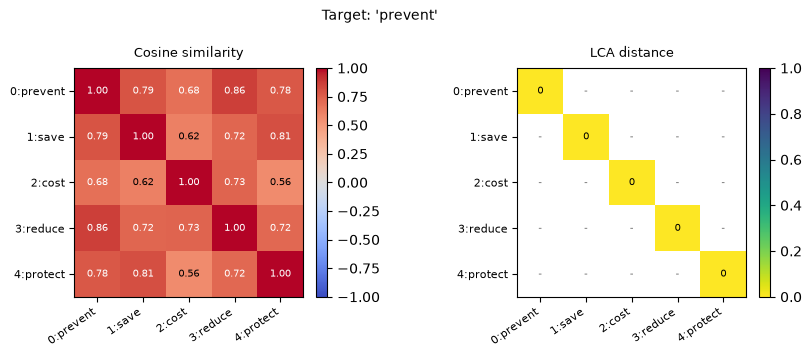


Context: 'The measles vaccine is estimated to prevent a' | Target: 'million'
Top-5        |     0:total |     1:large |     2:child |   3:million |     4:range
----------------------------------------------------------------------------------
0:total      |      1.0000 |      0.3489 |      0.4668 |      0.3702 |      0.4511
1:large      |      0.3489 |      1.0000 |      0.5289 |      0.7522 |      0.6068
2:child      |      0.4668 |      0.5289 |      1.0000 |      0.5076 |      0.5017
3:million    |      0.3702 |      0.7522 |      0.5076 |      1.0000 |      0.5932
4:range      |      0.4511 |      0.6068 |      0.5017 |      0.5932 |      1.0000


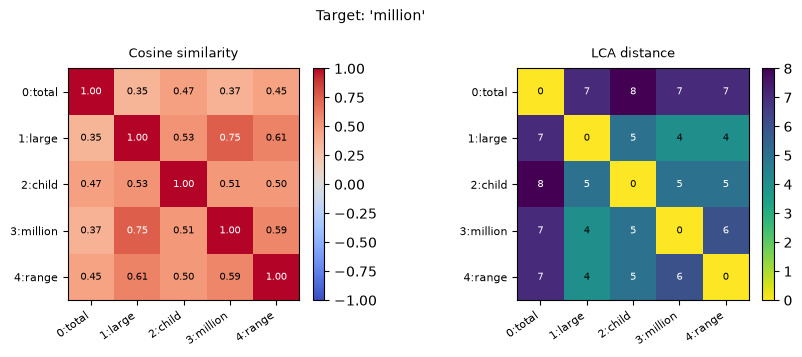


Context: 'The measles vaccine is estimated to prevent a million' | Target: 'deaths'
Top-5         |      0:deaths |   1:childhood |     2:measles |    3:children |       4:child
---------------------------------------------------------------------------------------------
0:deaths      |        1.0000 |        0.6400 |        0.2919 |        0.6045 |        0.5412
1:childhood   |        0.6400 |        1.0000 |        0.2349 |        0.6996 |        0.7301
2:measles     |        0.2919 |        0.2349 |        1.0000 |        0.2567 |        0.2214
3:children    |        0.6045 |        0.6996 |        0.2567 |        1.0000 |        0.8145
4:child       |        0.5412 |        0.7301 |        0.2214 |        0.8145 |        1.0000


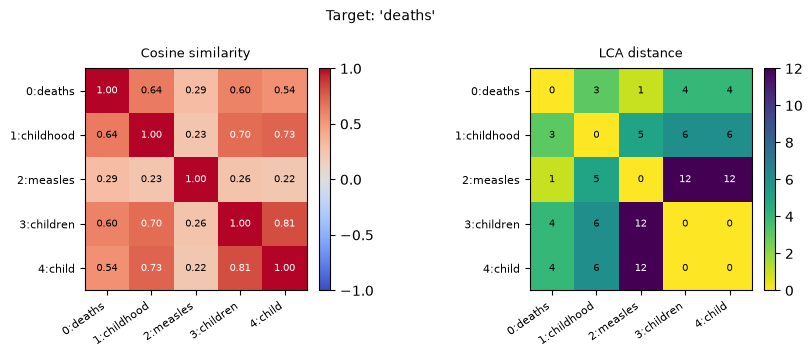


Context: 'The measles vaccine is estimated to prevent a million deaths every' | Target: 'year.'
Top-5        |     0:year |   1:single |     2:four |     3:five |    4:three
-----------------------------------------------------------------------------
0:year       |     1.0000 |     0.3990 |     0.2987 |     0.3025 |     0.3443
1:single     |     0.3990 |     1.0000 |     0.2184 |     0.2496 |     0.2901
2:four       |     0.2987 |     0.2184 |     1.0000 |     0.8584 |     0.8457
3:five       |     0.3025 |     0.2496 |     0.8584 |     1.0000 |     0.8208
4:three      |     0.3443 |     0.2901 |     0.8457 |     0.8208 |     1.0000


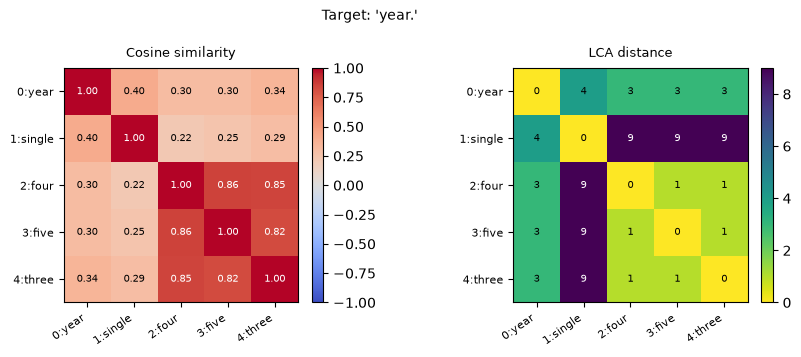


Context: 'Vaccines' | Target: 'led'
Top-5        |      0:work |      1:play |      2:help |   3:protect |      4:save
----------------------------------------------------------------------------------
0:work       |      1.0000 |      0.7024 |      0.6929 |      0.6517 |      0.7107
1:play       |      0.7024 |      1.0000 |      0.5585 |      0.5475 |      0.6146
2:help       |      0.6929 |      0.5585 |      1.0000 |      0.8043 |      0.8595
3:protect    |      0.6517 |      0.5475 |      0.8043 |      1.0000 |      0.8117
4:save       |      0.7107 |      0.6146 |      0.8595 |      0.8117 |      1.0000


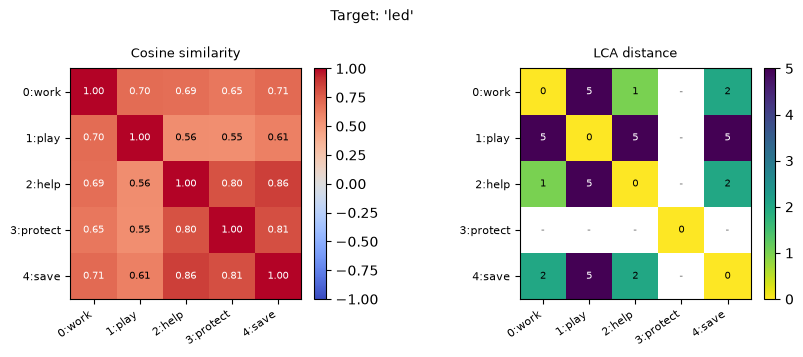


Context: 'Vaccines led to the' | Target: 'eradication'
Top-5           |          0:erad |          1:near |   2:elimination |           3:end |        4:almost
---------------------------------------------------------------------------------------------------------
0:erad          |          1.0000 |          0.3333 |          0.4623 |          0.4562 |          0.3004
1:near          |          0.3333 |          1.0000 |          0.5429 |          0.4688 |          0.7962
2:elimination   |          0.4623 |          0.5429 |          1.0000 |          0.4869 |          0.5317
3:end           |          0.4562 |          0.4688 |          0.4869 |          1.0000 |          0.4251
4:almost        |          0.3004 |          0.7962 |          0.5317 |          0.4251 |          1.0000


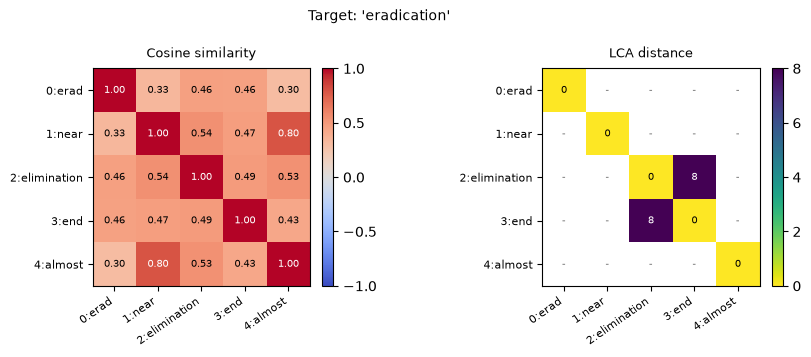


Context: 'Vaccines led to the eradication of' | Target: 'smallpox,'
Top-5        |      0:small |        1:pol |      2:three |       3:wild |   4:diseases
---------------------------------------------------------------------------------------
0:small      |       1.0000 |       0.6594 |       0.5775 |       0.6346 |       0.5202
1:pol        |       0.6594 |       1.0000 |       0.4834 |       0.6789 |       0.5399
2:three      |       0.5775 |       0.4834 |       1.0000 |       0.5254 |       0.4062
3:wild       |       0.6346 |       0.6789 |       0.5254 |       1.0000 |       0.5629
4:diseases   |       0.5202 |       0.5399 |       0.4062 |       0.5629 |       1.0000


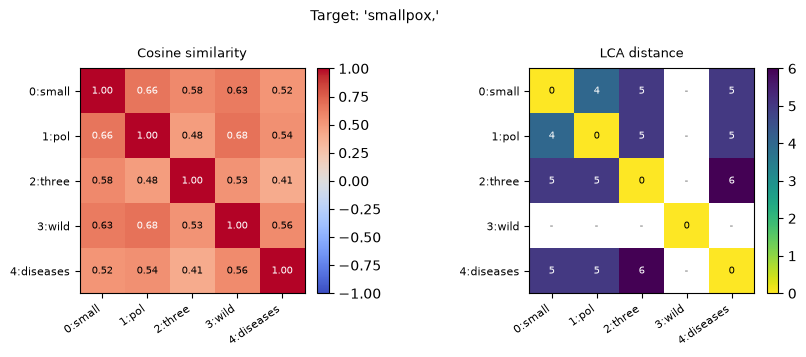


Context: 'Vaccines led to the eradication of smallpox, one of the most contagious and deadly' | Target: 'diseases'
Top-5          |     0:diseases |      1:viruses |        2:human |   3:infections |    4:illnesses
---------------------------------------------------------------------------------------------------
0:diseases     |         1.0000 |         0.8176 |         0.5324 |         0.7605 |         0.7094
1:viruses      |         0.8176 |         1.0000 |         0.5646 |         0.7423 |         0.6449
2:human        |         0.5324 |         0.5646 |         1.0000 |         0.5865 |         0.5992
3:infections   |         0.7605 |         0.7423 |         0.5865 |         1.0000 |         0.8449
4:illnesses    |         0.7094 |         0.6449 |         0.5992 |         0.8449 |         1.0000


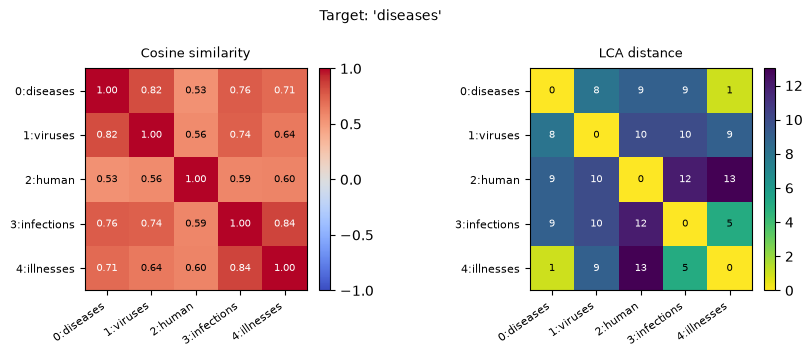


Context: 'Vaccines led to the eradication of smallpox, one of the most contagious and deadly diseases in' | Target: 'humans.'
Top-5        |     0:human |   1:history |    2:modern |     3:world |    4:humans
----------------------------------------------------------------------------------
0:human      |      1.0000 |      0.4650 |      0.5116 |      0.6194 |      0.8275
1:history    |      0.4650 |      1.0000 |      0.5738 |      0.5173 |      0.5239
2:modern     |      0.5116 |      0.5738 |      1.0000 |      0.5850 |      0.5329
3:world      |      0.6194 |      0.5173 |      0.5850 |      1.0000 |      0.6299
4:humans     |      0.8275 |      0.5239 |      0.5329 |      0.6299 |      1.0000


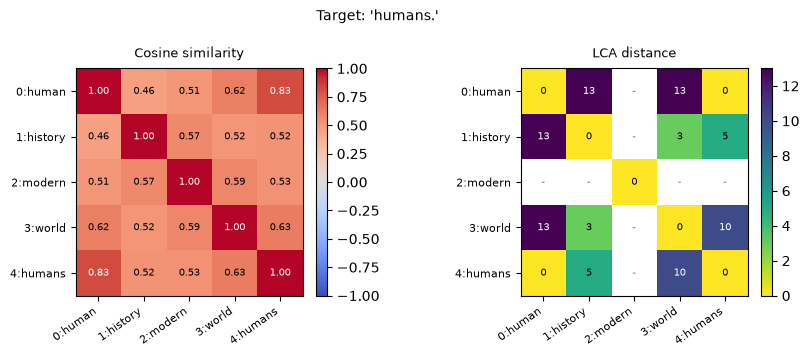


Context: 'Other' | Target: 'diseases'
Top-5        |     0:tags |   1:slides |    2:names |        3:c |    4:items
-----------------------------------------------------------------------------
0:tags       |     1.0000 |     0.8085 |     0.7878 |     0.5990 |     0.7077
1:slides     |     0.8085 |     1.0000 |     0.7117 |     0.5815 |     0.6653
2:names      |     0.7878 |     0.7117 |     1.0000 |     0.5660 |     0.7435
3:c          |     0.5990 |     0.5815 |     0.5660 |     1.0000 |     0.4437
4:items      |     0.7077 |     0.6653 |     0.7435 |     0.4437 |     1.0000


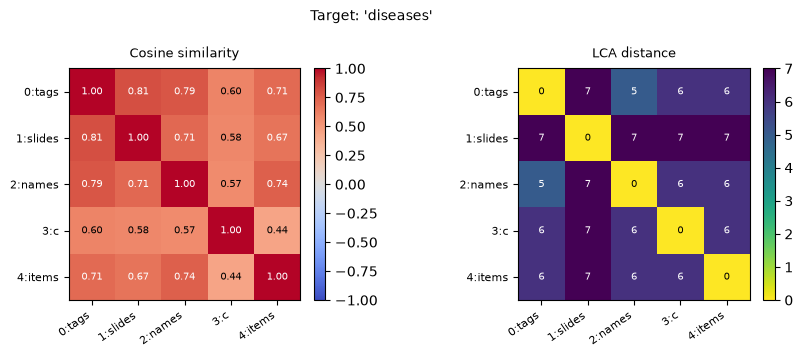


Context: 'Other diseases such as' | Target: 'rubella,'
Top-5            |       0:diabetes |         1:cancer |      2:hepatitis |   3:tuberculosis |        4:malaria
---------------------------------------------------------------------------------------------------------------
0:diabetes       |           1.0000 |           0.5943 |           0.8225 |           0.8134 |           0.4439
1:cancer         |           0.5943 |           1.0000 |           0.5811 |           0.5000 |           0.5070
2:hepatitis      |           0.8225 |           0.5811 |           1.0000 |           0.7981 |           0.5202
3:tuberculosis   |           0.8134 |           0.5000 |           0.7981 |           1.0000 |           0.3618
4:malaria        |           0.4439 |           0.5070 |           0.5202 |           0.3618 |           1.0000


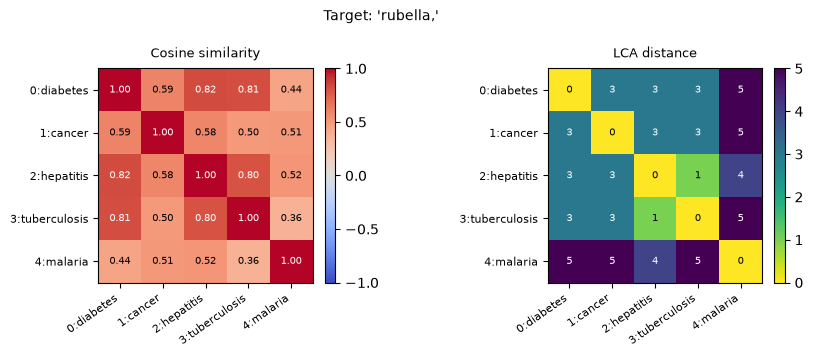


Context: 'Other diseases such as rubella,' | Target: 'polio,'
Top-5         |     0:measles |     1:chicken |   2:influenza |         3:var |   4:hepatitis
---------------------------------------------------------------------------------------------
0:measles     |        1.0000 |        0.2079 |        0.4024 |        0.2678 |        0.3463
1:chicken     |        0.2079 |        1.0000 |        0.6979 |        0.5733 |        0.7409
2:influenza   |        0.4024 |        0.6979 |        1.0000 |        0.5887 |        0.8750
3:var         |        0.2678 |        0.5733 |        0.5887 |        1.0000 |        0.5763
4:hepatitis   |        0.3463 |        0.7409 |        0.8750 |        0.5763 |        1.0000


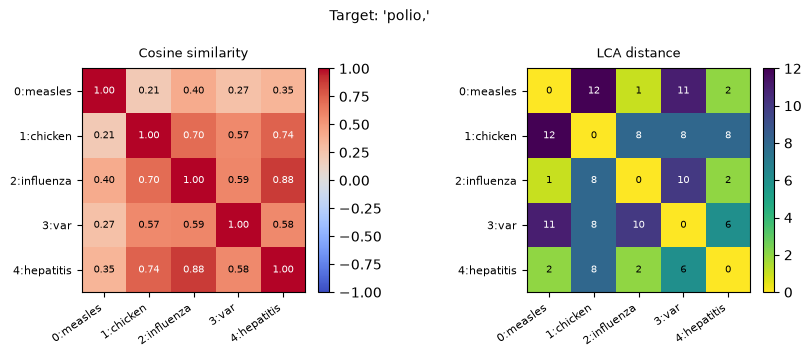


Context: 'Other diseases such as rubella, polio,' | Target: 'measles,'
Top-5         |     0:measles |   1:hepatitis |     2:chicken |       3:small |          4:ty
---------------------------------------------------------------------------------------------
0:measles     |        1.0000 |        0.3463 |        0.2079 |        0.1741 |        0.1996
1:hepatitis   |        0.3463 |        1.0000 |        0.7409 |        0.6235 |        0.4229
2:chicken     |        0.2079 |        0.7409 |        1.0000 |        0.7041 |        0.5273
3:small       |        0.1741 |        0.6235 |        0.7041 |        1.0000 |        0.4437
4:ty          |        0.1996 |        0.4229 |        0.5273 |        0.4437 |        1.0000


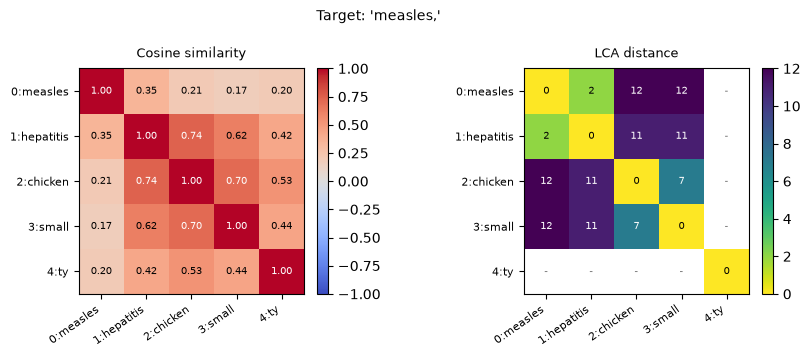


Context: 'Other diseases such as rubella, polio, measles,' | Target: 'mumps,'
Top-5         |     0:chicken |   1:influenza |   2:hepatitis |         3:etc |      4:mening
---------------------------------------------------------------------------------------------
0:chicken     |        1.0000 |        0.6979 |        0.7409 |        0.7817 |        0.5862
1:influenza   |        0.6979 |        1.0000 |        0.8750 |        0.6753 |        0.5716
2:hepatitis   |        0.7409 |        0.8750 |        1.0000 |        0.7181 |        0.5855
3:etc         |        0.7817 |        0.6753 |        0.7181 |        1.0000 |        0.5641
4:mening      |        0.5862 |        0.5716 |        0.5855 |        0.5641 |        1.0000


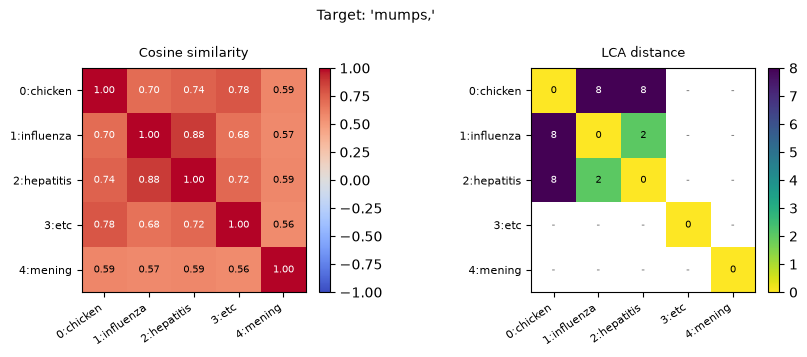


Context: 'Other diseases such as rubella, polio, measles, mumps,' | Target: 'chickenpox,'
Top-5         |     0:chicken |   1:hepatitis |   2:influenza |         3:etc |      4:mening
---------------------------------------------------------------------------------------------
0:chicken     |        1.0000 |        0.7409 |        0.6979 |        0.7817 |        0.5862
1:hepatitis   |        0.7409 |        1.0000 |        0.8750 |        0.7181 |        0.5855
2:influenza   |        0.6979 |        0.8750 |        1.0000 |        0.6753 |        0.5716
3:etc         |        0.7817 |        0.7181 |        0.6753 |        1.0000 |        0.5641
4:mening      |        0.5862 |        0.5855 |        0.5716 |        0.5641 |        1.0000


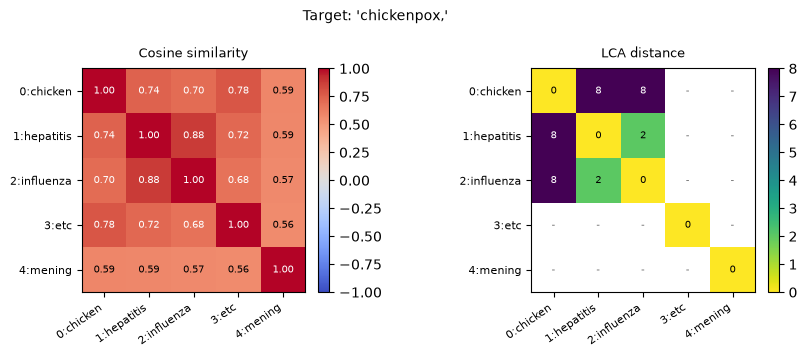


Context: 'Other diseases such as rubella, polio, measles, mumps, chickenpox, and' | Target: 'typhoid'
Top-5         |   0:hepatitis |   1:influenza |          2:sh |          3:ty |      4:others
---------------------------------------------------------------------------------------------
0:hepatitis   |        1.0000 |        0.8750 |        0.5926 |        0.4229 |        0.6838
1:influenza   |        0.8750 |        1.0000 |        0.5788 |        0.4463 |        0.6226
2:sh          |        0.5926 |        0.5788 |        1.0000 |        0.4604 |        0.5739
3:ty          |        0.4229 |        0.4463 |        0.4604 |        1.0000 |        0.4373
4:others      |        0.6838 |        0.6226 |        0.5739 |        0.4373 |        1.0000


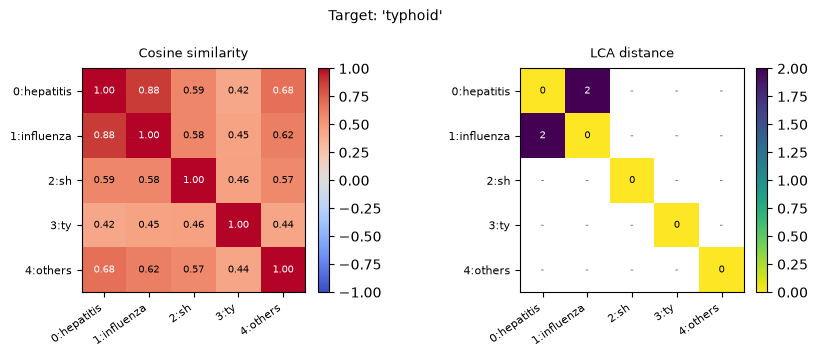


Context: 'Other diseases such as rubella, polio, measles, mumps, chickenpox, and typhoid are' | Target: 'nowhere'
Top-5         |      0:spread |      1:caused |   2:prevented |     3:usually |       4:often
---------------------------------------------------------------------------------------------
0:spread      |        1.0000 |        0.7727 |        0.7878 |        0.7081 |        0.7514
1:caused      |        0.7727 |        1.0000 |        0.8728 |        0.6733 |        0.7595
2:prevented   |        0.7878 |        0.8728 |        1.0000 |        0.6626 |        0.7482
3:usually     |        0.7081 |        0.6733 |        0.6626 |        1.0000 |        0.8782
4:often       |        0.7514 |        0.7595 |        0.7482 |        0.8782 |        1.0000


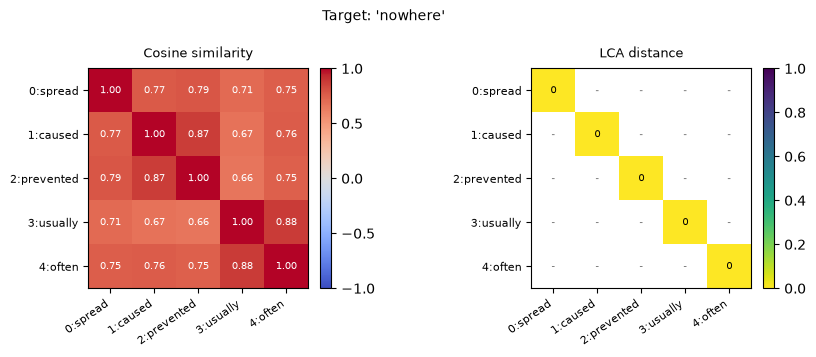


Context: 'Other diseases such as rubella, polio, measles, mumps, chickenpox, and typhoid are nowhere' | Target: 'near'
Top-5        |     0:near |   1:nearly |    2:close |   3:common |     4:seen
-----------------------------------------------------------------------------
0:near       |     1.0000 |     0.8224 |     0.8300 |     0.7564 |     0.7592
1:nearly     |     0.8224 |     1.0000 |     0.7462 |     0.7214 |     0.7203
2:close      |     0.8300 |     0.7462 |     1.0000 |     0.7078 |     0.6536
3:common     |     0.7564 |     0.7214 |     0.7078 |     1.0000 |     0.7570
4:seen       |     0.7592 |     0.7203 |     0.6536 |     0.7570 |     1.0000


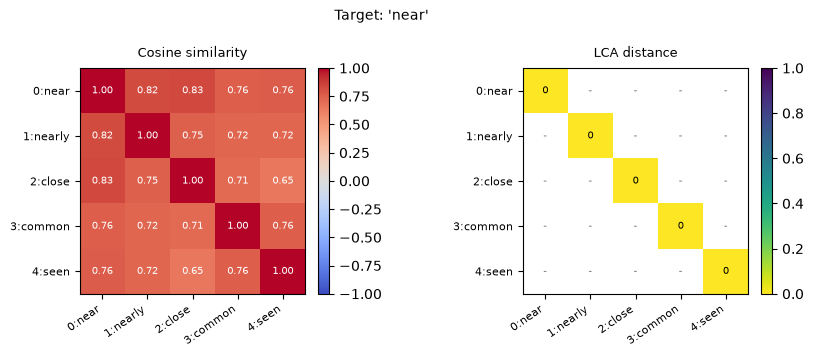


Context: 'Other diseases such as rubella, polio, measles, mumps, chickenpox, and typhoid are nowhere near as' | Target: 'common'
Top-5        |   0:common |      1:bad |      2:vir |     3:life |   4:easily
-----------------------------------------------------------------------------
0:common     |     1.0000 |     0.6207 |     0.5307 |     0.5636 |     0.7467
1:bad        |     0.6207 |     1.0000 |     0.4389 |     0.5608 |     0.5394
2:vir        |     0.5307 |     0.4389 |     1.0000 |     0.4787 |     0.5376
3:life       |     0.5636 |     0.5608 |     0.4787 |     1.0000 |     0.5629
4:easily     |     0.7467 |     0.5394 |     0.5376 |     0.5629 |     1.0000


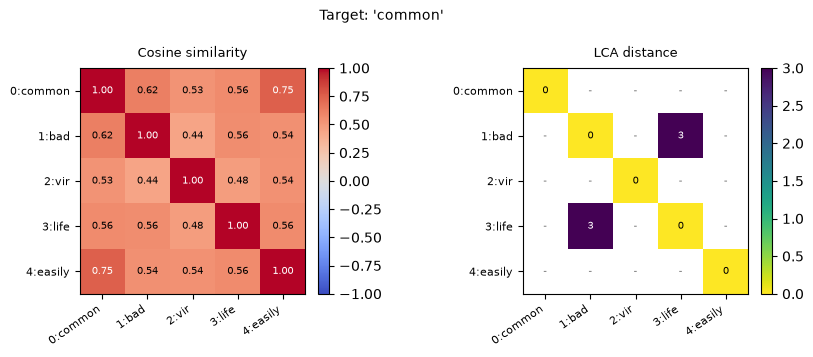


Context: 'Other diseases such as rubella, polio, measles, mumps, chickenpox, and typhoid are nowhere near as common as they were a' | Target: 'hundred'
Top-5          |   0:generation |      1:century |       2:decade |      3:hundred |         4:half
---------------------------------------------------------------------------------------------------
0:generation   |         1.0000 |         0.7198 |         0.7952 |         0.6952 |         0.7341
1:century      |         0.7198 |         1.0000 |         0.7889 |         0.5887 |         0.6147
2:decade       |         0.7952 |         0.7889 |         1.0000 |         0.6849 |         0.7081
3:hundred      |         0.6952 |         0.5887 |         0.6849 |         1.0000 |         0.7368
4:half         |         0.7341 |         0.6147 |         0.7081 |         0.7368 |         1.0000


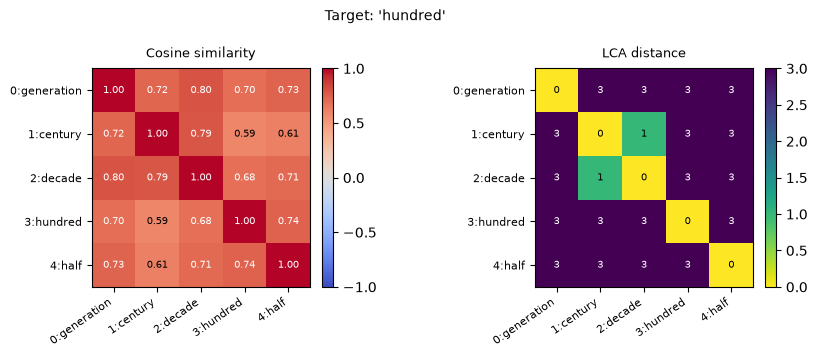


Context: 'Other diseases such as rubella, polio, measles, mumps, chickenpox, and typhoid are nowhere near as common as they were a hundred' | Target: 'years'
Top-5        |     0:years |      1:year |      2:plus |        3:ye |   4:decades
----------------------------------------------------------------------------------
0:years      |      1.0000 |      0.5480 |      0.5215 |      0.3974 |      0.8197
1:year       |      0.5480 |      1.0000 |      0.3489 |      0.2833 |      0.3715
2:plus       |      0.5215 |      0.3489 |      1.0000 |      0.5117 |      0.5758
3:ye         |      0.3974 |      0.2833 |      0.5117 |      1.0000 |      0.4138
4:decades    |      0.8197 |      0.3715 |      0.5758 |      0.4138 |      1.0000


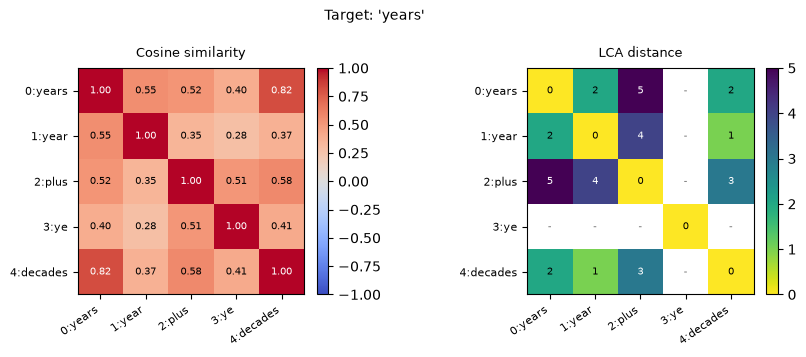


Context: 'Other diseases such as rubella, polio, measles, mumps, chickenpox, and typhoid are nowhere near as common as they were a hundred years ago' | Target: 'thanks'
Top-5        |    0:thanks |       1:due |     2:since |   3:largely |    4:mainly
----------------------------------------------------------------------------------
0:thanks     |      1.0000 |      0.5258 |      0.5352 |      0.5430 |      0.5202
1:due        |      0.5258 |      1.0000 |      0.7102 |      0.7900 |      0.6866
2:since      |      0.5352 |      0.7102 |      1.0000 |      0.6400 |      0.6489
3:largely    |      0.5430 |      0.7900 |      0.6400 |      1.0000 |      0.8245
4:mainly     |      0.5202 |      0.6866 |      0.6489 |      0.8245 |      1.0000


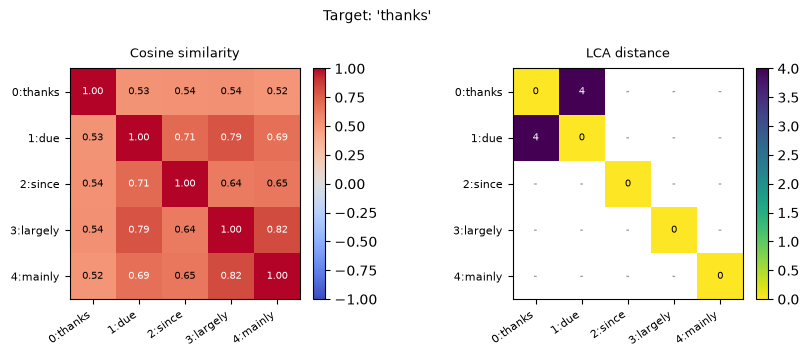


Context: 'Other diseases such as rubella, polio, measles, mumps, chickenpox, and typhoid are nowhere near as common as they were a hundred years ago thanks to widespread' | Target: 'vaccination'
Top-5            |    0:vaccination |          1:immun |   2:vaccinations |            3:use |           4:inoc
---------------------------------------------------------------------------------------------------------------
0:vaccination    |           1.0000 |           0.5666 |           0.8644 |           0.2902 |           0.3868
1:immun          |           0.5666 |           1.0000 |           0.5929 |           0.3485 |           0.5164
2:vaccinations   |           0.8644 |           0.5929 |           1.0000 |           0.2694 |           0.3610
3:use            |           0.2902 |           0.3485 |           0.2694 |           1.0000 |           0.5530
4:inoc           |           0.3868 |           0.5164 |           0.3610 |           0.5530 |           1.0000


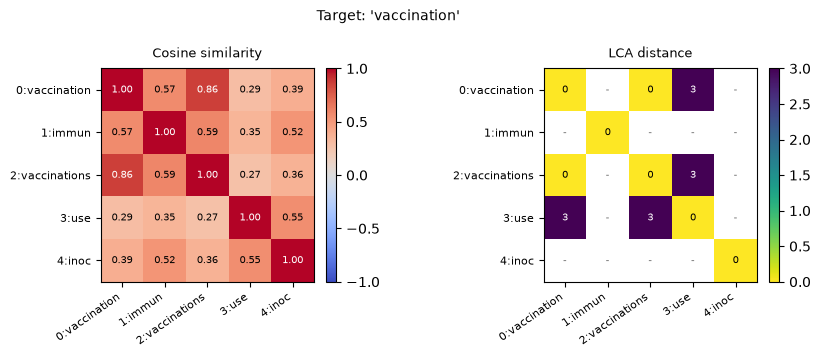


Context: 'Other diseases such as rubella, polio, measles, mumps, chickenpox, and typhoid are nowhere near as common as they were a hundred years ago thanks to widespread vaccination' | Target: 'programs.'
Top-5          |     0:programs |    1:campaigns |   2:programmes |      3:efforts |    4:practices
---------------------------------------------------------------------------------------------------
0:programs     |         1.0000 |         0.6595 |         0.9054 |         0.7145 |         0.7008
1:campaigns    |         0.6595 |         1.0000 |         0.6674 |         0.6574 |         0.6352
2:programmes   |         0.9054 |         0.6674 |         1.0000 |         0.6961 |         0.6971
3:efforts      |         0.7145 |         0.6574 |         0.6961 |         1.0000 |         0.8131
4:practices    |         0.7008 |         0.6352 |         0.6971 |         0.8131 |         1.0000


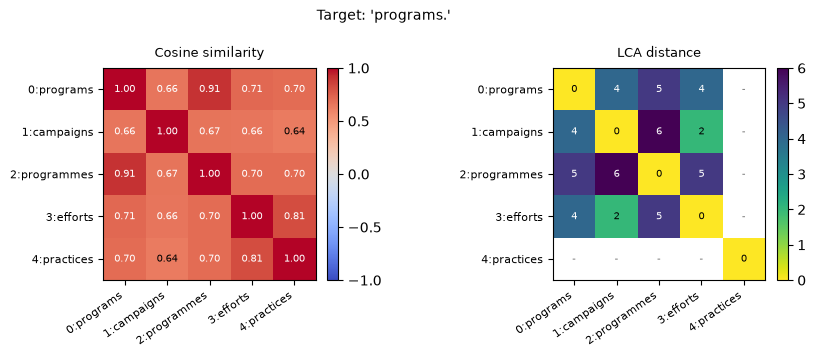


Context: 'As' | Target: 'long'
Top-5         |       0:shown |        1:part |     2:someone |   3:mentioned |         4:per
---------------------------------------------------------------------------------------------
0:shown       |        1.0000 |        0.3446 |        0.5641 |        0.7014 |        0.5990
1:part        |        0.3446 |        1.0000 |        0.4298 |        0.4561 |        0.5706
2:someone     |        0.5641 |        0.4298 |        1.0000 |        0.7504 |        0.5610
3:mentioned   |        0.7014 |        0.4561 |        0.7504 |        1.0000 |        0.6280
4:per         |        0.5990 |        0.5706 |        0.5610 |        0.6280 |        1.0000


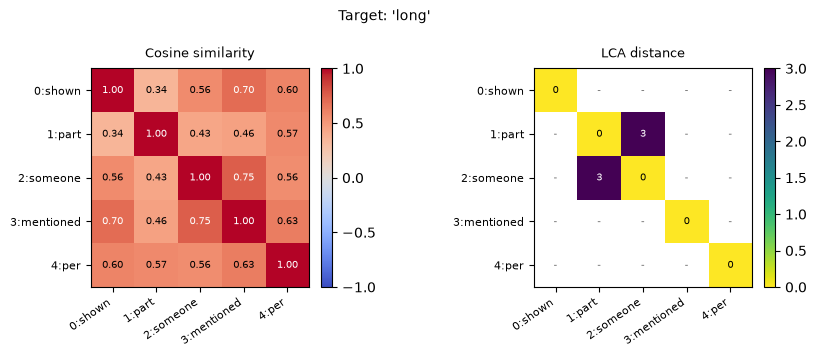


Context: 'As long as the vast' | Target: 'majority'
Top-5        |   0:majority |     1:number |     2:amount |       3:body |       4:land
---------------------------------------------------------------------------------------
0:majority   |       1.0000 |       0.5714 |       0.6046 |       0.5141 |       0.4297
1:number     |       0.5714 |       1.0000 |       0.8199 |       0.6521 |       0.4481
2:amount     |       0.6046 |       0.8199 |       1.0000 |       0.6974 |       0.4445
3:body       |       0.5141 |       0.6521 |       0.6974 |       1.0000 |       0.4673
4:land       |       0.4297 |       0.4481 |       0.4445 |       0.4673 |       1.0000


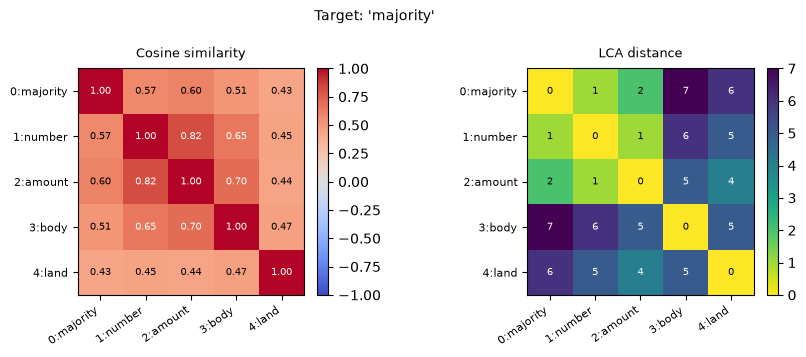


Context: 'As long as the vast majority of' | Target: 'people'
Top-5         |      0:people |       1:party |   2:countries |     3:farmers |     4:members
---------------------------------------------------------------------------------------------
0:people      |        1.0000 |        0.4928 |        0.4956 |        0.6194 |        0.7359
1:party       |        0.4928 |        1.0000 |        0.3985 |        0.4528 |        0.5285
2:countries   |        0.4956 |        0.3985 |        1.0000 |        0.3929 |        0.4452
3:farmers     |        0.6194 |        0.4528 |        0.3929 |        1.0000 |        0.5896
4:members     |        0.7359 |        0.5285 |        0.4452 |        0.5896 |        1.0000


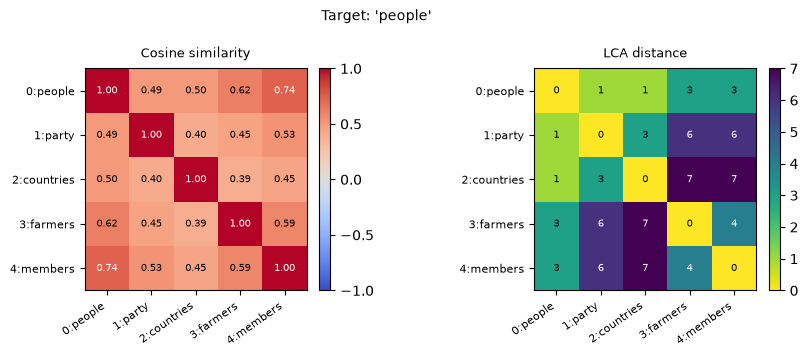


Context: 'As long as the vast majority of people are vaccinated, it is much more difficult for an' | Target: 'outbreak'
Top-5          |           0:un |     1:outbreak |     2:epidemic |    3:infection |   4:individual
---------------------------------------------------------------------------------------------------
0:un           |         1.0000 |         0.7291 |         0.7310 |         0.6907 |         0.4777
1:outbreak     |         0.7291 |         1.0000 |         0.9266 |         0.8669 |         0.4570
2:epidemic     |         0.7310 |         0.9266 |         1.0000 |         0.8868 |         0.4682
3:infection    |         0.6907 |         0.8669 |         0.8868 |         1.0000 |         0.4501
4:individual   |         0.4777 |         0.4570 |         0.4682 |         0.4501 |         1.0000


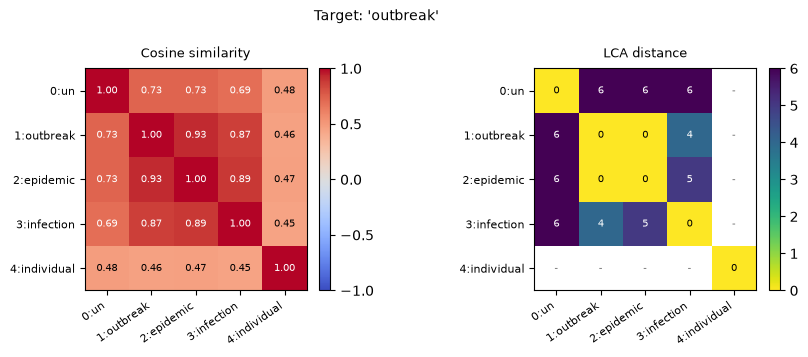


Context: 'As long as the vast majority of people are vaccinated, it is much more difficult for an outbreak of' | Target: 'disease'
Top-5           |       0:disease |       1:measles |     2:influenza |         3:covid |   4:coronavirus
---------------------------------------------------------------------------------------------------------
0:disease       |          1.0000 |          0.3404 |          0.8056 |          0.5229 |          0.5095
1:measles       |          0.3404 |          1.0000 |          0.4024 |          0.3221 |          0.5033
2:influenza     |          0.8056 |          0.4024 |          1.0000 |          0.5564 |          0.5239
3:covid         |          0.5229 |          0.3221 |          0.5564 |          1.0000 |          0.5006
4:coronavirus   |          0.5095 |          0.5033 |          0.5239 |          0.5006 |          1.0000


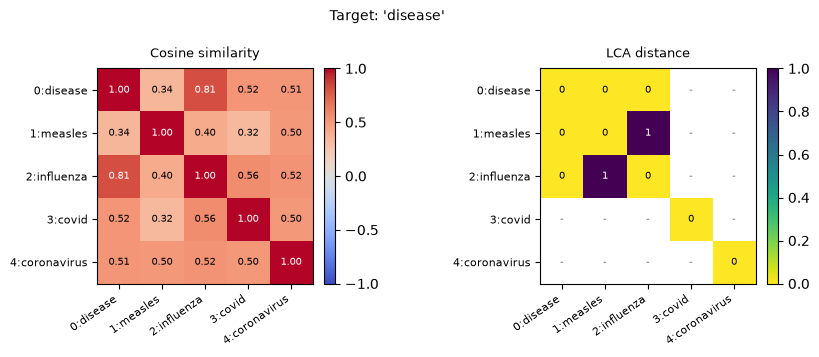


Context: 'As long as the vast majority of people are vaccinated, it is much more difficult for an outbreak of disease to' | Target: 'occur,'
Top-5        |    0:occur |     1:take |   2:spread |   3:happen |    4:start
-----------------------------------------------------------------------------
0:occur      |     1.0000 |     0.6960 |     0.7289 |     0.7961 |     0.4536
1:take       |     0.6960 |     1.0000 |     0.7955 |     0.7618 |     0.5291
2:spread     |     0.7289 |     0.7955 |     1.0000 |     0.8121 |     0.4863
3:happen     |     0.7961 |     0.7618 |     0.8121 |     1.0000 |     0.4905
4:start      |     0.4536 |     0.5291 |     0.4863 |     0.4905 |     1.0000


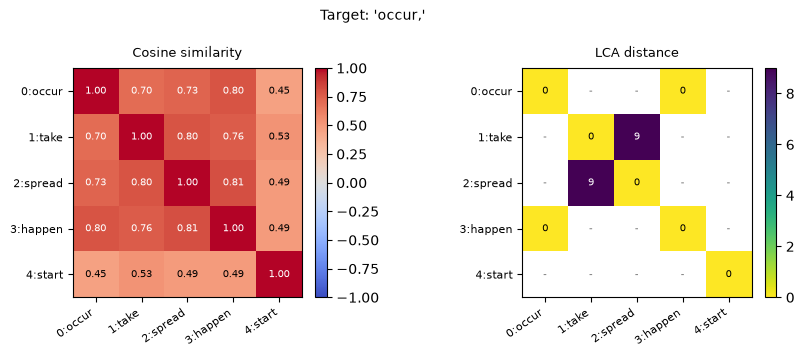


Context: 'As long as the vast majority of people are vaccinated, it is much more difficult for an outbreak of disease to occur,' | Target: 'let'
Top-5          |        0:since |   1:especially |       2:making |      3:experts |       4:spread
---------------------------------------------------------------------------------------------------
0:since        |         1.0000 |         0.6551 |         0.6991 |         0.6287 |         0.6663
1:especially   |         0.6551 |         1.0000 |         0.7634 |         0.6762 |         0.7450
2:making       |         0.6991 |         0.7634 |         1.0000 |         0.7312 |         0.8556
3:experts      |         0.6287 |         0.6762 |         0.7312 |         1.0000 |         0.6937
4:spread       |         0.6663 |         0.7450 |         0.8556 |         0.6937 |         1.0000


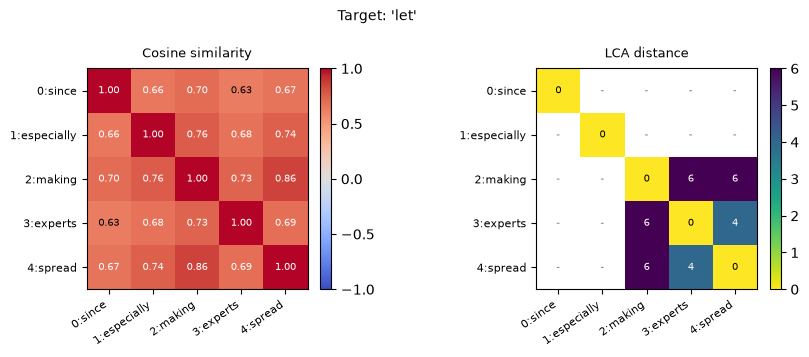


Context: 'As long as the vast majority of people are vaccinated, it is much more difficult for an outbreak of disease to occur, let alone' | Target: 'spread.'
Top-5        |   0:spread |   1:become |    2:cause |     3:take |     4:lead
-----------------------------------------------------------------------------
0:spread     |     1.0000 |     0.7742 |     0.7926 |     0.7955 |     0.6467
1:become     |     0.7742 |     1.0000 |     0.7508 |     0.7929 |     0.5942
2:cause      |     0.7926 |     0.7508 |     1.0000 |     0.7120 |     0.6050
3:take       |     0.7955 |     0.7929 |     0.7120 |     1.0000 |     0.6419
4:lead       |     0.6467 |     0.5942 |     0.6050 |     0.6419 |     1.0000


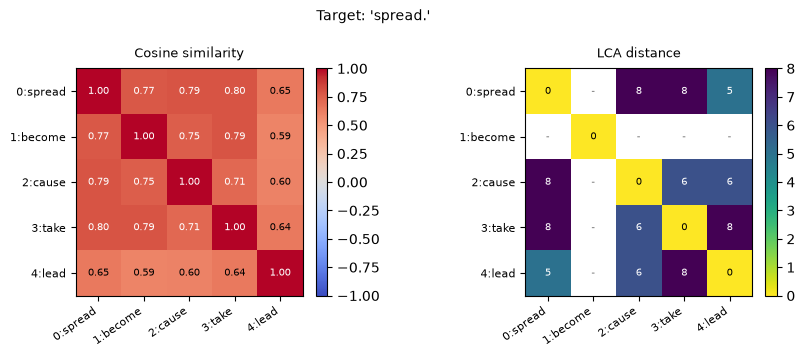


Context: 'This' | Target: 'effect'
Top-5        |      0:site |   1:article |     2:paper |    3:number |      4:year
----------------------------------------------------------------------------------
0:site       |      1.0000 |      0.6634 |      0.5645 |      0.5710 |      0.3570
1:article    |      0.6634 |      1.0000 |      0.5895 |      0.6240 |      0.4082
2:paper      |      0.5645 |      0.5895 |      1.0000 |      0.5904 |      0.4210
3:number     |      0.5710 |      0.6240 |      0.5904 |      1.0000 |      0.4334
4:year       |      0.3570 |      0.4082 |      0.4210 |      0.4334 |      1.0000


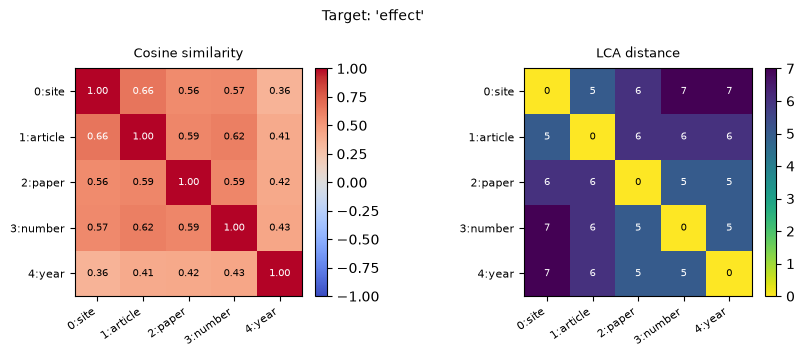


Context: 'This effect is' | Target: 'called'
Top-5            |         0:called |            1:due |         2:caused |   3:particularly |          4:often
---------------------------------------------------------------------------------------------------------------
0:called         |           1.0000 |           0.6404 |           0.6371 |           0.6428 |           0.6387
1:due            |           0.6404 |           1.0000 |           0.7872 |           0.8070 |           0.7867
2:caused         |           0.6371 |           0.7872 |           1.0000 |           0.7273 |           0.7595
3:particularly   |           0.6428 |           0.8070 |           0.7273 |           1.0000 |           0.8275
4:often          |           0.6387 |           0.7867 |           0.7595 |           0.8275 |           1.0000


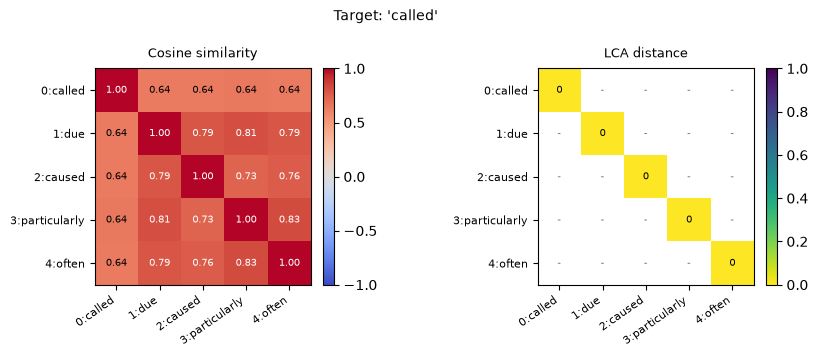


Context: 'This effect is called' | Target: 'herd'
Top-5         |       0:super |   1:resonance |     2:thermal |         3:ref |       4:photo
---------------------------------------------------------------------------------------------
0:super       |        1.0000 |        0.7697 |        0.7282 |        0.5733 |        0.7047
1:resonance   |        0.7697 |        1.0000 |        0.7625 |        0.5617 |        0.7051
2:thermal     |        0.7282 |        0.7625 |        1.0000 |        0.5506 |        0.7132
3:ref         |        0.5733 |        0.5617 |        0.5506 |        1.0000 |        0.5286
4:photo       |        0.7047 |        0.7051 |        0.7132 |        0.5286 |        1.0000


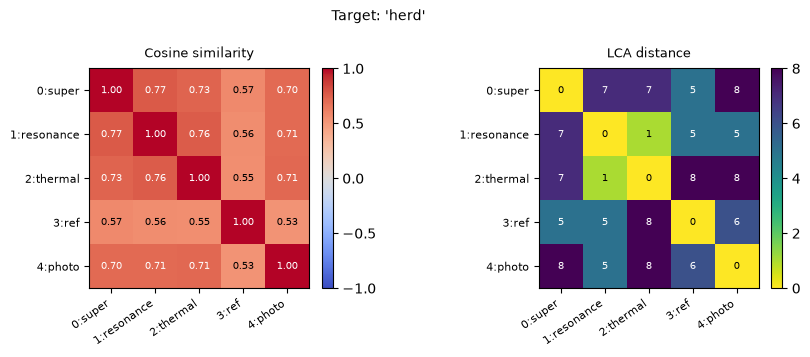


Context: 'This effect is called herd' | Target: 'immunity.'
Top-5          |     0:immunity |   1:protection |       2:effect |     3:behavior |        4:immun
---------------------------------------------------------------------------------------------------
0:immunity     |         1.0000 |         0.5404 |         0.5293 |         0.5357 |         0.4228
1:protection   |         0.5404 |         1.0000 |         0.6740 |         0.7689 |         0.4544
2:effect       |         0.5293 |         0.6740 |         1.0000 |         0.6957 |         0.4430
3:behavior     |         0.5357 |         0.7689 |         0.6957 |         1.0000 |         0.4268
4:immun        |         0.4228 |         0.4544 |         0.4430 |         0.4268 |         1.0000


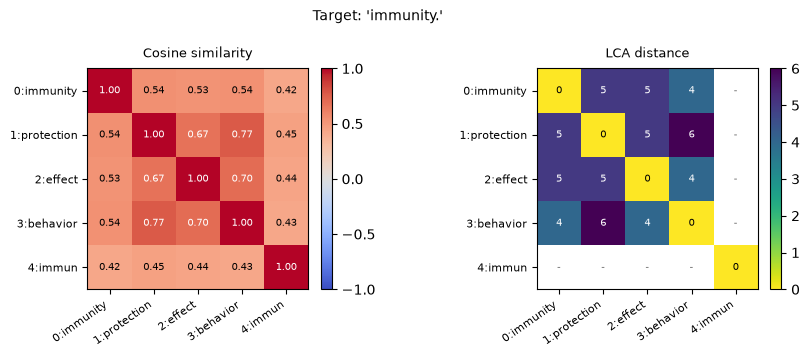


Context: 'Polio, which is transmitted only' | Target: 'among'
Top-5        |      0:via |    1:among |    2:human |   3:person |   4:though
-----------------------------------------------------------------------------
0:via        |     1.0000 |     0.4776 |     0.4450 |     0.5017 |     0.4060
1:among      |     0.4776 |     1.0000 |     0.4614 |     0.6038 |     0.6200
2:human      |     0.4450 |     0.4614 |     1.0000 |     0.7019 |     0.4529
3:person     |     0.5017 |     0.6038 |     0.7019 |     1.0000 |     0.5337
4:though     |     0.4060 |     0.6200 |     0.4529 |     0.5337 |     1.0000


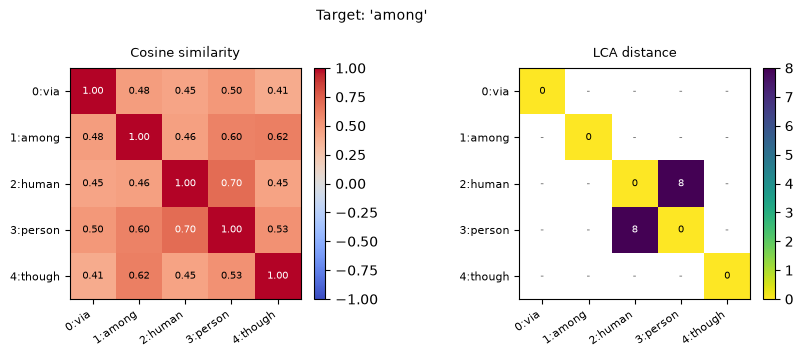


Context: 'Polio, which is transmitted only among' | Target: 'humans,'
Top-5        |     0:humans |     1:people |      2:human |   3:children |       4:prim
---------------------------------------------------------------------------------------
0:humans     |       1.0000 |       0.7721 |       0.8275 |       0.6615 |       0.3911
1:people     |       0.7721 |       1.0000 |       0.6874 |       0.6592 |       0.4134
2:human      |       0.8275 |       0.6874 |       1.0000 |       0.5354 |       0.4708
3:children   |       0.6615 |       0.6592 |       0.5354 |       1.0000 |       0.3524
4:prim       |       0.3911 |       0.4134 |       0.4708 |       0.3524 |       1.0000


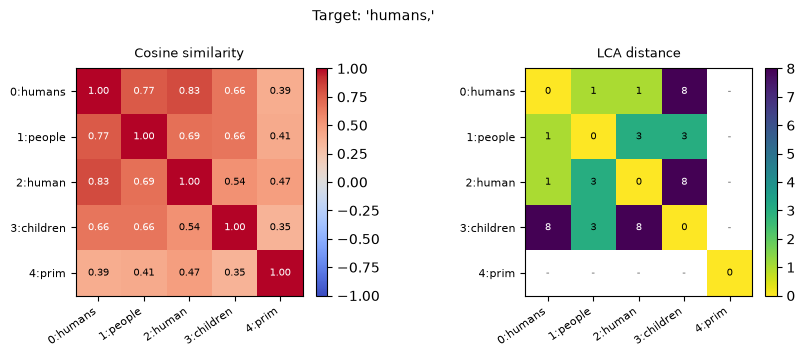


Context: 'Polio, which is transmitted only among humans, is' | Target: 'targeted'
Top-5        |    0:caused |   1:endemic |    2:almost |     3:close |    4:making
----------------------------------------------------------------------------------
0:caused     |      1.0000 |      0.6141 |      0.6556 |      0.6329 |      0.7856
1:endemic    |      0.6141 |      1.0000 |      0.5266 |      0.5696 |      0.5557
2:almost     |      0.6556 |      0.5266 |      1.0000 |      0.7182 |      0.7650
3:close      |      0.6329 |      0.5696 |      0.7182 |      1.0000 |      0.6993
4:making     |      0.7856 |      0.5557 |      0.7650 |      0.6993 |      1.0000


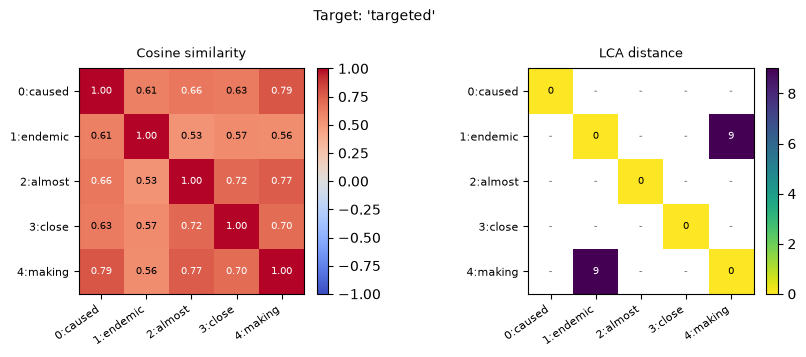


Context: 'Polio, which is transmitted only among humans, is targeted by an extensive' | Target: 'eradication'
Top-5             |     0:vaccination |           1:immun |   2:international |            3:erad |         4:vaccine
---------------------------------------------------------------------------------------------------------------------
0:vaccination     |            1.0000 |            0.5666 |            0.3687 |            0.3556 |            0.4347
1:immun           |            0.5666 |            1.0000 |            0.4746 |            0.4133 |            0.4980
2:international   |            0.3687 |            0.4746 |            1.0000 |            0.3010 |            0.6317
3:erad            |            0.3556 |            0.4133 |            0.3010 |            1.0000 |            0.3087
4:vaccine         |            0.4347 |            0.4980 |            0.6317 |            0.3087 |            1.0000


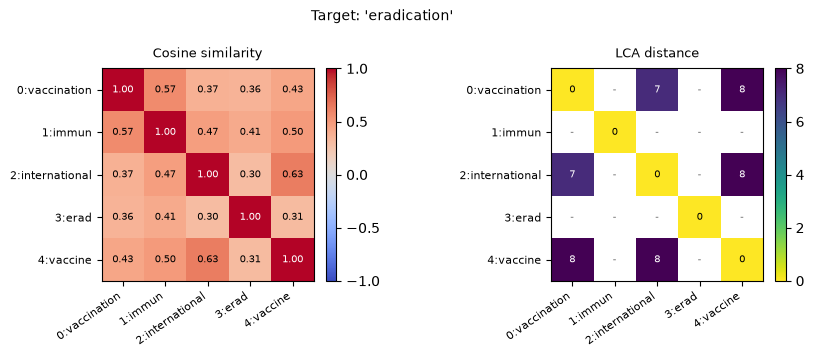


Context: 'Polio, which is transmitted only among humans, is targeted by an extensive eradication' | Target: 'campaign'
Top-5          |     0:campaign |       1:effort |      2:program |    3:programme |   4:initiative
---------------------------------------------------------------------------------------------------
0:campaign     |         1.0000 |         0.4570 |         0.5770 |         0.5320 |         0.5543
1:effort       |         0.4570 |         1.0000 |         0.6443 |         0.5327 |         0.5856
2:program      |         0.5770 |         0.6443 |         1.0000 |         0.8799 |         0.7947
3:programme    |         0.5320 |         0.5327 |         0.8799 |         1.0000 |         0.7509
4:initiative   |         0.5543 |         0.5856 |         0.7947 |         0.7509 |         1.0000


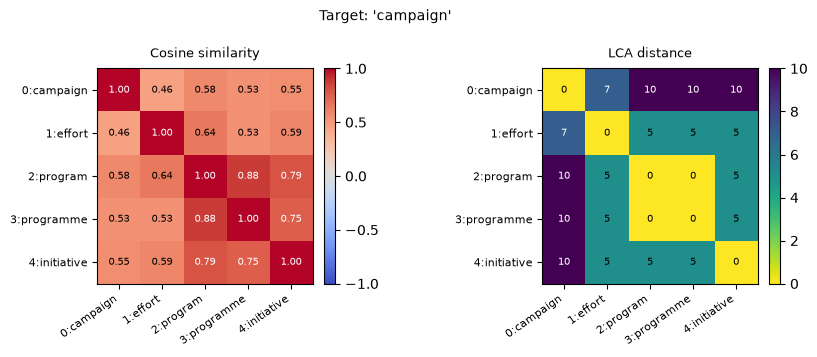


Context: 'Polio, which is transmitted only among humans, is targeted by an extensive eradication campaign that has' | Target: 'seen'
Top-5         |     0:already |        1:seen |         2:cut |         3:led |   4:succeeded
---------------------------------------------------------------------------------------------
0:already     |        1.0000 |        0.6051 |        0.4892 |        0.4673 |        0.4211
1:seen        |        0.6051 |        1.0000 |        0.6516 |        0.7241 |        0.6759
2:cut         |        0.4892 |        0.6516 |        1.0000 |        0.5994 |        0.5616
3:led         |        0.4673 |        0.7241 |        0.5994 |        1.0000 |        0.6922
4:succeeded   |        0.4211 |        0.6759 |        0.5616 |        0.6922 |        1.0000


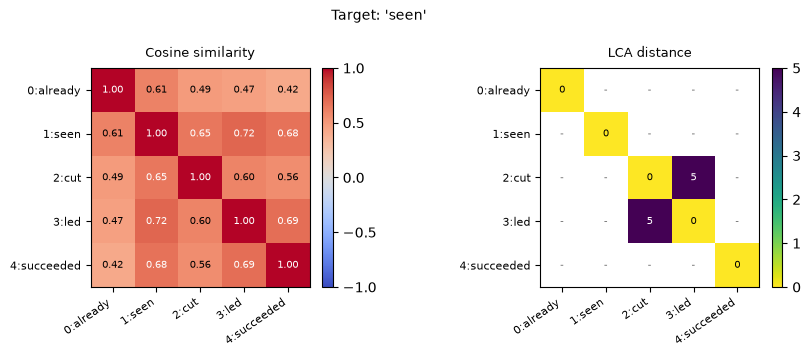


Context: 'Polio, which is transmitted only among humans, is targeted by an extensive eradication campaign that has seen' | Target: 'endemic'
Top-5        |    0:cases |    1:great |    2:major |     3:wild |     4:case
-----------------------------------------------------------------------------
0:cases      |     1.0000 |     0.5340 |     0.6743 |     0.6096 |     0.8641
1:great      |     0.5340 |     1.0000 |     0.5742 |     0.6559 |     0.5696
2:major      |     0.6743 |     0.5742 |     1.0000 |     0.6385 |     0.7200
3:wild       |     0.6096 |     0.6559 |     0.6385 |     1.0000 |     0.6400
4:case       |     0.8641 |     0.5696 |     0.7200 |     0.6400 |     1.0000


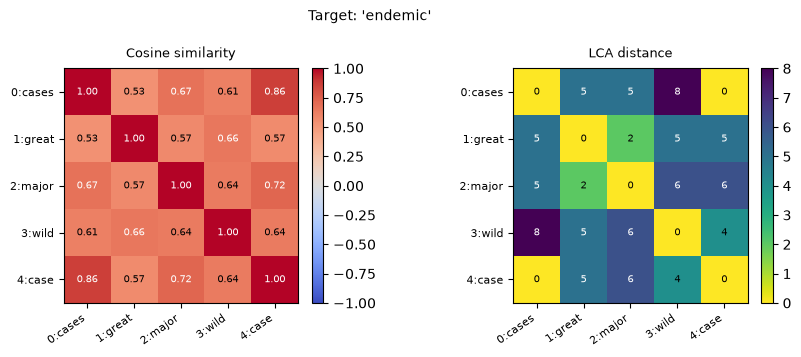


Context: 'Polio, which is transmitted only among humans, is targeted by an extensive eradication campaign that has seen endemic' | Target: 'polio'
Top-5            |   0:transmission |          1:cases |            2:pol |            3:ity |      4:infection
---------------------------------------------------------------------------------------------------------------
0:transmission   |           1.0000 |           0.6697 |           0.5959 |           0.3864 |           0.6754
1:cases          |           0.6697 |           1.0000 |           0.6631 |           0.4368 |           0.7391
2:pol            |           0.5959 |           0.6631 |           1.0000 |           0.4295 |           0.7554
3:ity            |           0.3864 |           0.4368 |           0.4295 |           1.0000 |           0.4377
4:infection      |           0.6754 |           0.7391 |           0.7554 |           0.4377 |           1.0000


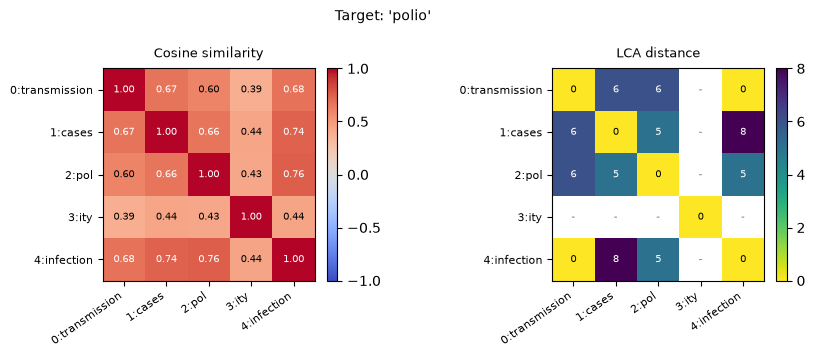


Context: 'Polio, which is transmitted only among humans, is targeted by an extensive eradication campaign that has seen endemic polio restricted to only' | Target: 'parts'
Top-5           |         0:three |          1:four |      2:pakistan |   3:afghanistan |         4:parts
---------------------------------------------------------------------------------------------------------
0:three         |          1.0000 |          0.8457 |          0.4497 |          0.3937 |          0.4825
1:four          |          0.8457 |          1.0000 |          0.3762 |          0.3099 |          0.4489
2:pakistan      |          0.4497 |          0.3762 |          1.0000 |          0.6871 |          0.4384
3:afghanistan   |          0.3937 |          0.3099 |          0.6871 |          1.0000 |          0.4348
4:parts         |          0.4825 |          0.4489 |          0.4384 |          0.4348 |          1.0000


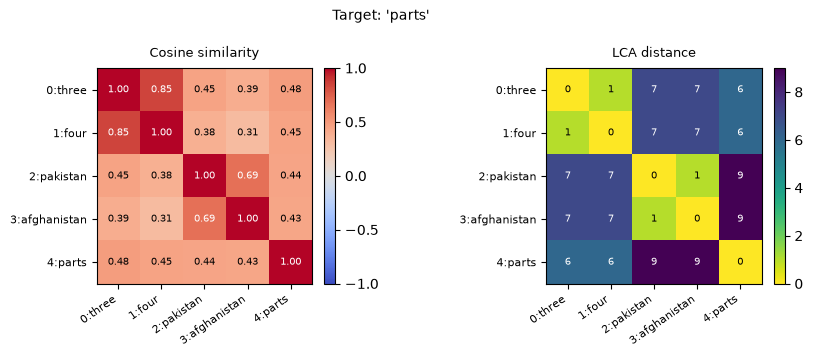


Context: 'Polio, which is transmitted only among humans, is targeted by an extensive eradication campaign that has seen endemic polio restricted to only parts of' | Target: 'three'
Top-5           |      0:pakistan |         1:three |   2:afghanistan |         3:india |       4:nigeria
---------------------------------------------------------------------------------------------------------
0:pakistan      |          1.0000 |          0.4497 |          0.6871 |          0.7303 |          0.6014
1:three         |          0.4497 |          1.0000 |          0.3937 |          0.5070 |          0.5337
2:afghanistan   |          0.6871 |          0.3937 |          1.0000 |          0.5695 |          0.6035
3:india         |          0.7303 |          0.5070 |          0.5695 |          1.0000 |          0.7440
4:nigeria       |          0.6014 |          0.5337 |          0.6035 |          0.7440 |          1.0000


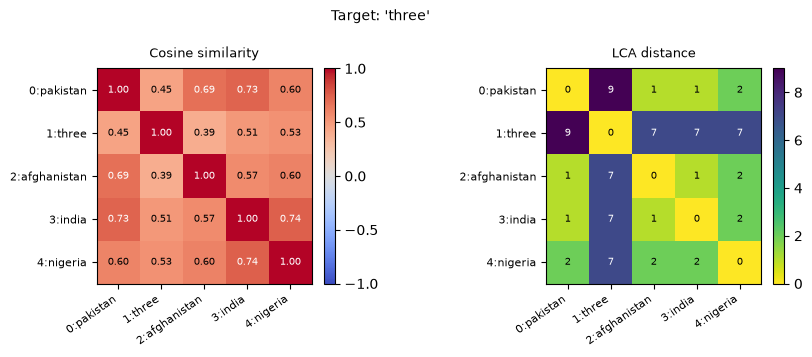


Context: 'Polio, which is transmitted only among humans, is targeted by an extensive eradication campaign that has seen endemic polio restricted to only parts of three' | Target: 'countries'
Top-5          |    0:countries |      1:nations |      2:african |        3:asian |   4:developing
---------------------------------------------------------------------------------------------------
0:countries    |         1.0000 |         0.6106 |         0.4533 |         0.4205 |         0.3741
1:nations      |         0.6106 |         1.0000 |         0.3750 |         0.3646 |         0.3443
2:african      |         0.4533 |         0.3750 |         1.0000 |         0.8233 |         0.7138
3:asian        |         0.4205 |         0.3646 |         0.8233 |         1.0000 |         0.7371
4:developing   |         0.3741 |         0.3443 |         0.7138 |         0.7371 |         1.0000


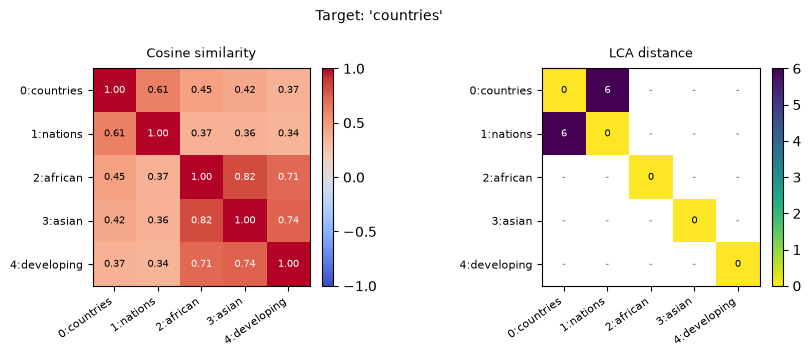


Context: 'Polio, which is transmitted only among humans, is targeted by an extensive eradication campaign that has seen endemic polio restricted to only parts of three countries' | Target: '(Afghanistan,'
Top-5        |      0:since |      1:today |      2:india |   3:pakistan |          4:p
---------------------------------------------------------------------------------------
0:since      |       1.0000 |       0.5320 |       0.4698 |       0.4005 |       0.4271
1:today      |       0.5320 |       1.0000 |       0.4637 |       0.4339 |       0.3605
2:india      |       0.4698 |       0.4637 |       1.0000 |       0.7303 |       0.4309
3:pakistan   |       0.4005 |       0.4339 |       0.7303 |       1.0000 |       0.3825
4:p          |       0.4271 |       0.3605 |       0.4309 |       0.3825 |       1.0000


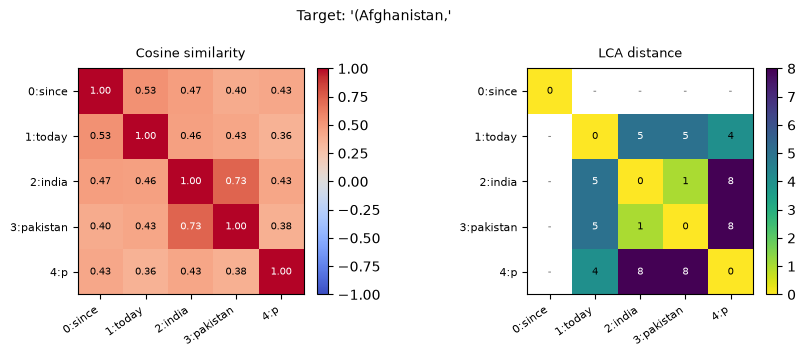


Context: 'Polio, which is transmitted only among humans, is targeted by an extensive eradication campaign that has seen endemic polio restricted to only parts of three countries (Afghanistan,' | Target: 'Nigeria,'
Top-5        |   0:pakistan |    1:nigeria |      2:india |      3:egypt |       4:iraq
---------------------------------------------------------------------------------------
0:pakistan   |       1.0000 |       0.6014 |       0.7303 |       0.6296 |       0.6065
1:nigeria    |       0.6014 |       1.0000 |       0.7440 |       0.6936 |       0.6395
2:india      |       0.7303 |       0.7440 |       1.0000 |       0.7081 |       0.5894
3:egypt      |       0.6296 |       0.6936 |       0.7081 |       1.0000 |       0.6866
4:iraq       |       0.6065 |       0.6395 |       0.5894 |       0.6866 |       1.0000


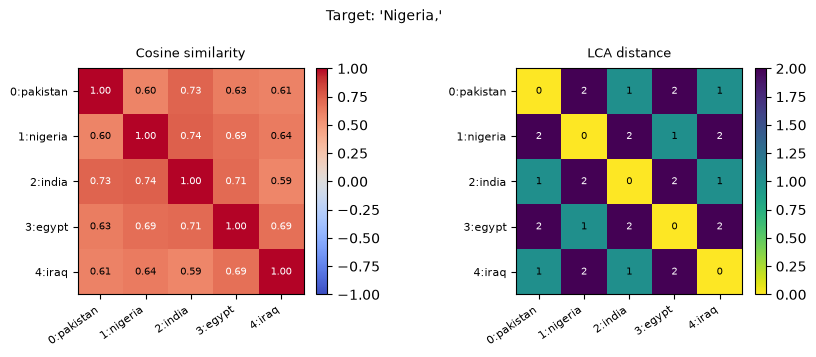


Context: 'Polio, which is transmitted only among humans, is targeted by an extensive eradication campaign that has seen endemic polio restricted to only parts of three countries (Afghanistan, Nigeria, and' | Target: 'Pakistan).'
Top-5        |   0:pakistan |      1:india |       2:iraq |      3:egypt |       4:wild
---------------------------------------------------------------------------------------
0:pakistan   |       1.0000 |       0.7303 |       0.6065 |       0.6296 |       0.4486
1:india      |       0.7303 |       1.0000 |       0.5894 |       0.7081 |       0.6056
2:iraq       |       0.6065 |       0.5894 |       1.0000 |       0.6866 |       0.4611
3:egypt      |       0.6296 |       0.7081 |       0.6866 |       1.0000 |       0.5326
4:wild       |       0.4486 |       0.6056 |       0.4611 |       0.5326 |       1.0000


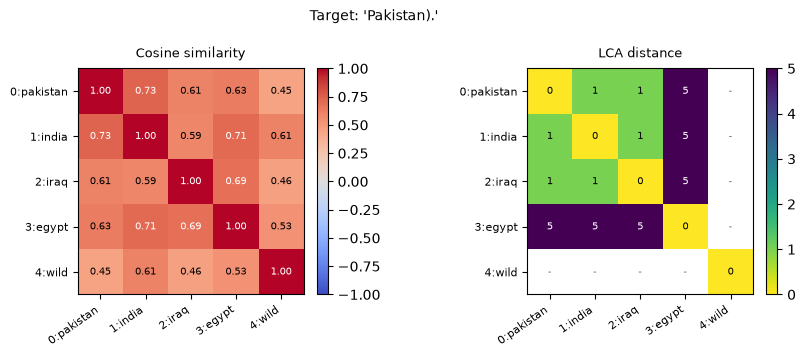


Context: 'However, the' | Target: 'difficulty'
Top-5        |   0:company |     1:first |    2:number |      3:fact |   4:problem
----------------------------------------------------------------------------------
0:company    |      1.0000 |      0.5611 |      0.7072 |      0.6945 |      0.5818
1:first      |      0.5611 |      1.0000 |      0.6225 |      0.5984 |      0.5349
2:number     |      0.7072 |      0.6225 |      1.0000 |      0.7143 |      0.6929
3:fact       |      0.6945 |      0.5984 |      0.7143 |      1.0000 |      0.6784
4:problem    |      0.5818 |      0.5349 |      0.6929 |      0.6784 |      1.0000


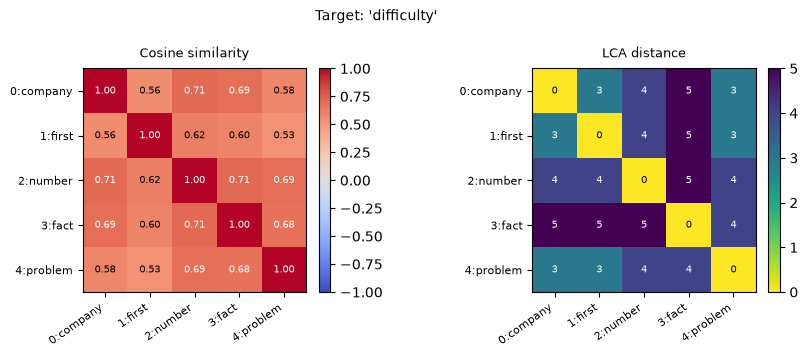


Context: 'However, the difficulty of' | Target: 'reaching'
Top-5            |        0:finding |      1:obtaining |         2:making |   3:implementing |      4:achieving
---------------------------------------------------------------------------------------------------------------
0:finding        |           1.0000 |           0.8074 |           0.8463 |           0.7641 |           0.8070
1:obtaining      |           0.8074 |           1.0000 |           0.7900 |           0.8028 |           0.8060
2:making         |           0.8463 |           0.7900 |           1.0000 |           0.8218 |           0.8208
3:implementing   |           0.7641 |           0.8028 |           0.8218 |           1.0000 |           0.8341
4:achieving      |           0.8070 |           0.8060 |           0.8208 |           0.8341 |           1.0000


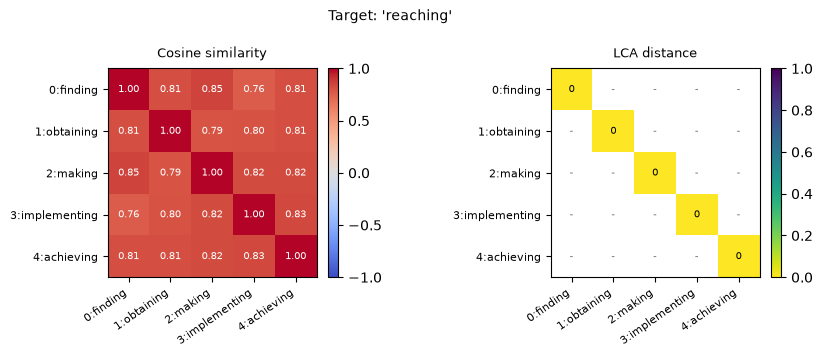


Context: 'However, the difficulty of reaching all' | Target: 'children,'
Top-5        |      0:areas |      1:parts |    2:corners |   3:patients |   4:students
---------------------------------------------------------------------------------------
0:areas      |       1.0000 |       0.7297 |       0.7804 |       0.6672 |       0.6481
1:parts      |       0.7297 |       1.0000 |       0.7374 |       0.6032 |       0.6216
2:corners    |       0.7804 |       0.7374 |       1.0000 |       0.6312 |       0.6240
3:patients   |       0.6672 |       0.6032 |       0.6312 |       1.0000 |       0.7143
4:students   |       0.6481 |       0.6216 |       0.6240 |       0.7143 |       1.0000


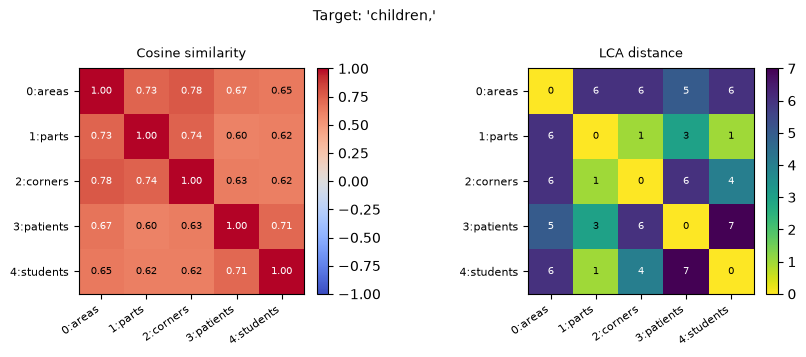


Context: 'However, the difficulty of reaching all children, cultural' | Target: 'misunderstandings,'
Top-5           |      0:barriers |   1:differences |       2:beliefs |         3:norms |           4:tab
---------------------------------------------------------------------------------------------------------
0:barriers      |          1.0000 |          0.6323 |          0.7659 |          0.7832 |          0.5526
1:differences   |          0.6323 |          1.0000 |          0.7005 |          0.5641 |          0.4169
2:beliefs       |          0.7659 |          0.7005 |          1.0000 |          0.7429 |          0.5469
3:norms         |          0.7832 |          0.5641 |          0.7429 |          1.0000 |          0.5886
4:tab           |          0.5526 |          0.4169 |          0.5469 |          0.5886 |          1.0000


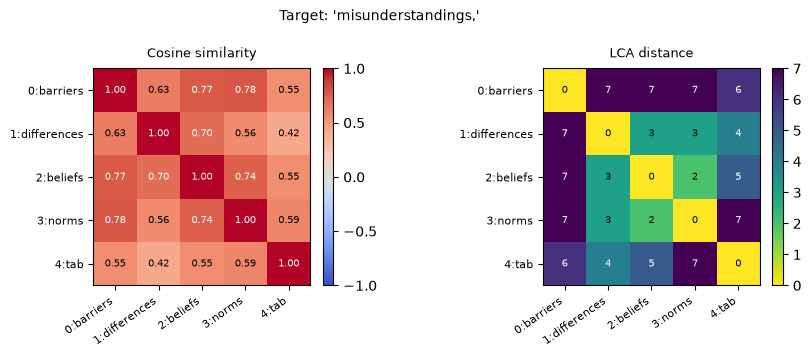


Context: 'However, the difficulty of reaching all children, cultural misunderstandings, and' | Target: 'disinformation'
Top-5          |         0:lack |     1:language |   2:resistance |      3:limited |         4:fear
---------------------------------------------------------------------------------------------------
0:lack         |         1.0000 |         0.4634 |         0.6420 |         0.6391 |         0.6215
1:language     |         0.4634 |         1.0000 |         0.5648 |         0.4473 |         0.5469
2:resistance   |         0.6420 |         0.5648 |         1.0000 |         0.6007 |         0.6606
3:limited      |         0.6391 |         0.4473 |         0.6007 |         1.0000 |         0.5893
4:fear         |         0.6215 |         0.5469 |         0.6606 |         0.5893 |         1.0000


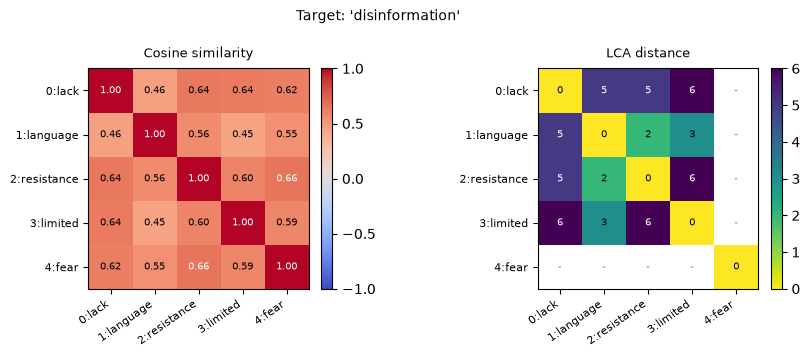


Context: 'However, the difficulty of reaching all children, cultural misunderstandings, and disinformation have' | Target: 'caused'
Top-5        |       0:ham |    1:hinder |   2:limited |    3:slowed |       4:imp
----------------------------------------------------------------------------------
0:ham        |      1.0000 |      0.5281 |      0.5476 |      0.6426 |      0.6643
1:hinder     |      0.5281 |      1.0000 |      0.4720 |      0.5652 |      0.5311
2:limited    |      0.5476 |      0.4720 |      1.0000 |      0.6442 |      0.7114
3:slowed     |      0.6426 |      0.5652 |      0.6442 |      1.0000 |      0.6614
4:imp        |      0.6643 |      0.5311 |      0.7114 |      0.6614 |      1.0000


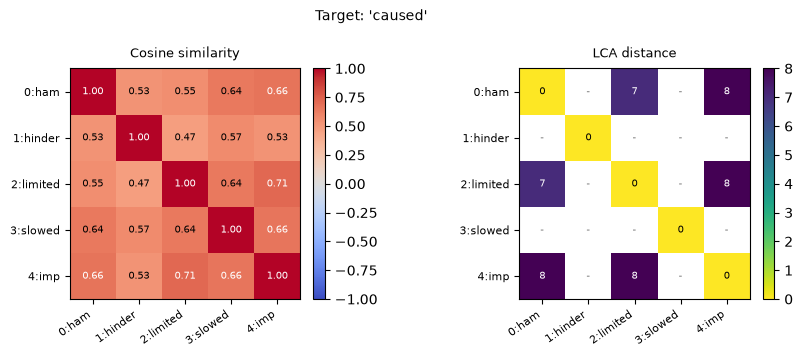


Context: 'However, the difficulty of reaching all children, cultural misunderstandings, and disinformation have caused the anticipated' | Target: 'eradication'
Top-5        |      0:gains |       1:erad |    2:results |   3:benefits |   4:progress
---------------------------------------------------------------------------------------
0:gains      |       1.0000 |       0.3037 |       0.2706 |       0.6458 |       0.5737
1:erad       |       0.3037 |       1.0000 |       0.4298 |       0.2994 |       0.4003
2:results    |       0.2706 |       0.4298 |       1.0000 |       0.3421 |       0.5034
3:benefits   |       0.6458 |       0.2994 |       0.3421 |       1.0000 |       0.5535
4:progress   |       0.5737 |       0.4003 |       0.5034 |       0.5535 |       1.0000


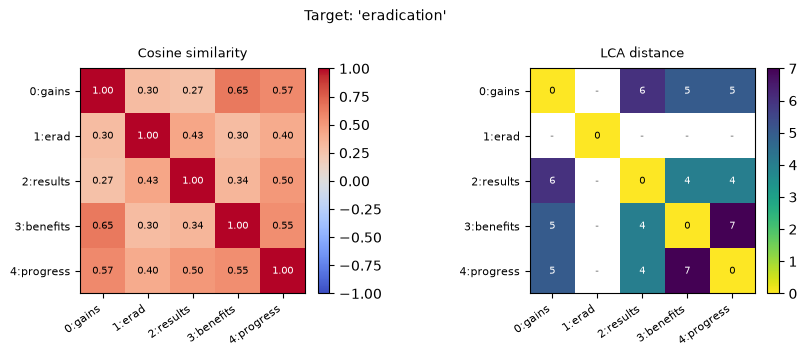


Context: 'However, the difficulty of reaching all children, cultural misunderstandings, and disinformation have caused the anticipated eradication' | Target: 'date'
Top-5        |     0:date |     1:goal |   2:target |    3:goals |    4:dates
-----------------------------------------------------------------------------
0:date       |     1.0000 |     0.5005 |     0.5706 |     0.4437 |     0.8116
1:goal       |     0.5005 |     1.0000 |     0.4957 |     0.8867 |     0.4963
2:target     |     0.5706 |     0.4957 |     1.0000 |     0.4073 |     0.5082
3:goals      |     0.4437 |     0.8867 |     0.4073 |     1.0000 |     0.5120
4:dates      |     0.8116 |     0.4963 |     0.5082 |     0.5120 |     1.0000


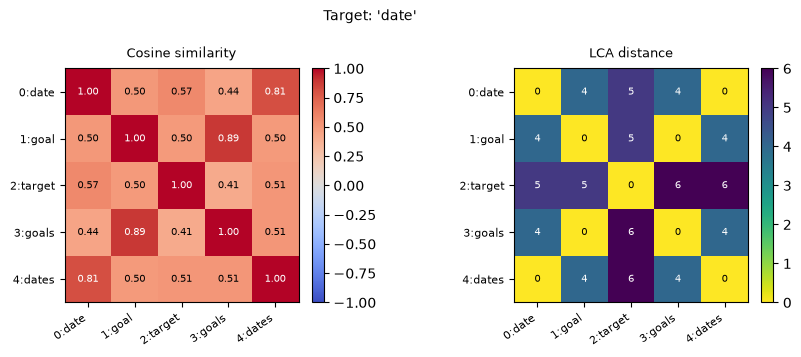


Context: 'However, the difficulty of reaching all children, cultural misunderstandings, and disinformation have caused the anticipated eradication date to be missed several' | Target: 'times.'
Top-5         |       0:times |       1:years |        2:time |     3:decades |   4:occasions
---------------------------------------------------------------------------------------------
0:times       |        1.0000 |        0.5845 |        0.7457 |        0.6564 |        0.7196
1:years       |        0.5845 |        1.0000 |        0.6223 |        0.8197 |        0.5586
2:time        |        0.7457 |        0.6223 |        1.0000 |        0.6874 |        0.6597
3:decades     |        0.6564 |        0.8197 |        0.6874 |        1.0000 |        0.6351
4:occasions   |        0.7196 |        0.5586 |        0.6597 |        0.6351 |        1.0000


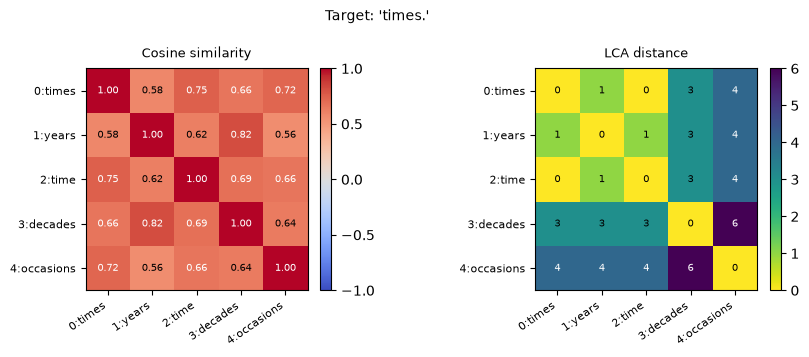


Context: 'Vaccines also' | Target: 'help'
Top-5        |      0:play |      1:help |   2:contain |   3:protect |     4:cause
----------------------------------------------------------------------------------
0:play       |      1.0000 |      0.5585 |      0.6223 |      0.5475 |      0.6402
1:help       |      0.5585 |      1.0000 |      0.6940 |      0.8043 |      0.7162
2:contain    |      0.6223 |      0.6940 |      1.0000 |      0.6746 |      0.7921
3:protect    |      0.5475 |      0.8043 |      0.6746 |      1.0000 |      0.7285
4:cause      |      0.6402 |      0.7162 |      0.7921 |      0.7285 |      1.0000


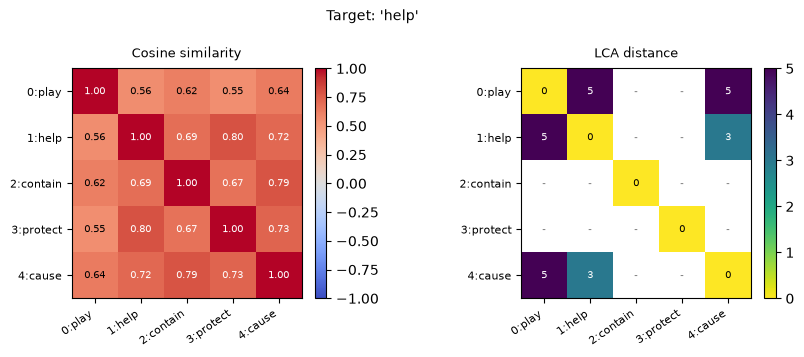


Context: 'Vaccines also help' | Target: 'prevent'
Top-5        |   0:prevent |   1:protect |    2:people |      3:keep |      4:stop
----------------------------------------------------------------------------------
0:prevent    |      1.0000 |      0.7785 |      0.6763 |      0.8129 |      0.7712
1:protect    |      0.7785 |      1.0000 |      0.6111 |      0.7080 |      0.7541
2:people     |      0.6763 |      0.6111 |      1.0000 |      0.6724 |      0.6164
3:keep       |      0.8129 |      0.7080 |      0.6724 |      1.0000 |      0.7371
4:stop       |      0.7712 |      0.7541 |      0.6164 |      0.7371 |      1.0000


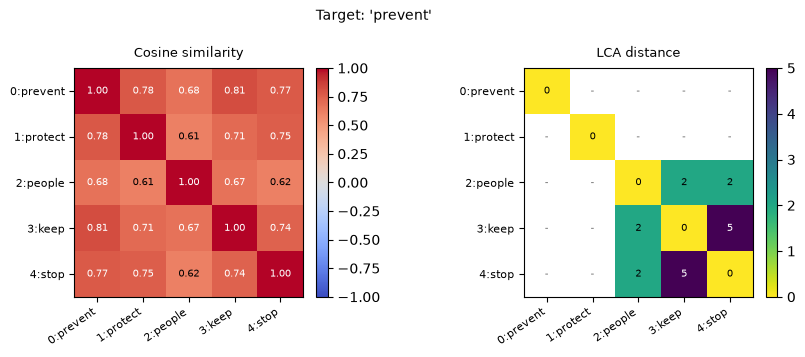


Context: 'Vaccines also help prevent the' | Target: 'development'
Top-5            |         0:spread |   1:transmission |    2:development |            3:flu |      4:emergence
---------------------------------------------------------------------------------------------------------------
0:spread         |           1.0000 |           0.6452 |           0.6207 |           0.8089 |           0.7989
1:transmission   |           0.6452 |           1.0000 |           0.7286 |           0.6179 |           0.6476
2:development    |           0.6207 |           0.7286 |           1.0000 |           0.5820 |           0.6460
3:flu            |           0.8089 |           0.6179 |           0.5820 |           1.0000 |           0.7640
4:emergence      |           0.7989 |           0.6476 |           0.6460 |           0.7640 |           1.0000


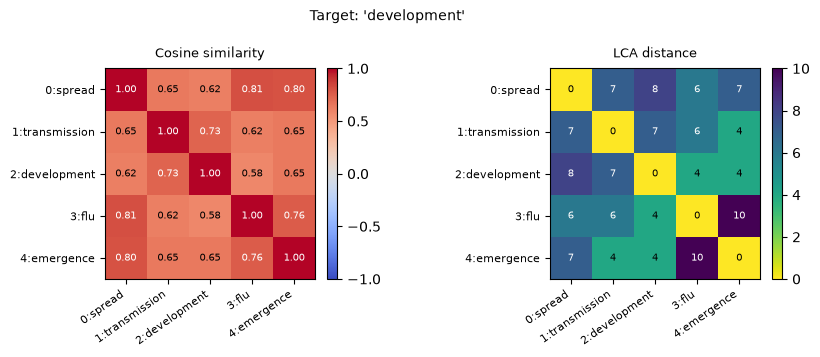


Context: 'Vaccines also help prevent the development of' | Target: 'antibiotic'
Top-5          |   0:antibiotic |     1:diseases |       2:cancer |      3:cancers |         4:life
---------------------------------------------------------------------------------------------------
0:antibiotic   |         1.0000 |         0.5938 |         0.4945 |         0.5536 |         0.4109
1:diseases     |         0.5938 |         1.0000 |         0.6659 |         0.8321 |         0.5707
2:cancer       |         0.4945 |         0.6659 |         1.0000 |         0.6502 |         0.4377
3:cancers      |         0.5536 |         0.8321 |         0.6502 |         1.0000 |         0.5723
4:life         |         0.4109 |         0.5707 |         0.4377 |         0.5723 |         1.0000


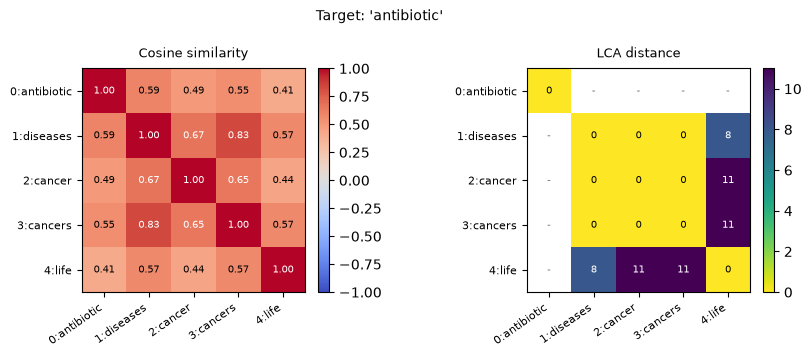


Context: 'Vaccines also help prevent the development of antibiotic' | Target: 'resistance.'
Top-5          |   0:resistance |          1:res |       2:resist |            3:耐 |   4:associated
---------------------------------------------------------------------------------------------------
0:resistance   |         1.0000 |         0.5058 |         0.7065 |         0.5660 |         0.6806
1:res          |         0.5058 |         1.0000 |         0.6209 |         0.5605 |         0.6130
2:resist       |         0.7065 |         0.6209 |         1.0000 |         0.6777 |         0.7124
3:耐            |         0.5660 |         0.5605 |         0.6777 |         1.0000 |         0.5831
4:associated   |         0.6806 |         0.6130 |         0.7124 |         0.5831 |         1.0000


/tmp/ipykernel_1427/764855093.py:81: UserWarning: Glyph 32784 (\N{CJK UNIFIED IDEOGRAPH-8010}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 32784 (\N{CJK UNIFIED IDEOGRAPH-8010}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


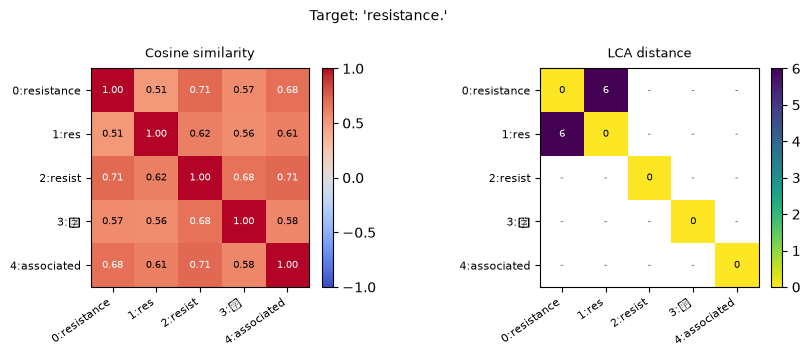

{'block1': [7, 8, None, 6, 5, 7, 9], 'block2': [6, 4, 9, None], 'block3': [7, None, 1, 5, None, 9, 7, None, 5, 7, 9, 6, 4, 7], 'block4': [6, 7, 7, 7, 5, 12, 6, 2, None, 3, 7, None, 7, 8, 6], 'block5': [None, None, None, 6, 9, 8, 10, 6, 10, 6, 6, 9, None, None, 11], 'block6': [5, 4, 9, 6, 6, 8, None], 'block7': [6, 9, None, None], 'block8': [7, 9, 8, 7, 8, 8, None, 9, 9, 7, 9, 6, 11, 7, 10], 'block9': [6, 9, 8, 8, 11, 5, 13], 'block10': [6, 9, 10, None, 9, 4, 16, None, 7, 8, 9, 6, 7, 9, 6, 8, 7], 'block11': [7, 10, 6, None], 'block12': [6, 6, 8, 5, 8, 7, 8, 8, 6, 9, 8], 'block13': [6, 9, 8, 1, 7, 7, 2, 9, 3, 9, 9, 8, 10, 2, 9, 8, 1, 11], 'block14': [6, 9, 9, 7, 8, 6, 10, 12, 5, 11, 12], 'block15': [None, 10, 9, 9, None, 6, 9, 4], 'block16': [6, 6, 8, 7, None, 6], 'block17': [6, 12, 8, 6, None, None, 9], 'block18': [6, 6, 6, 8, 6, 1, 4], 'block19': [7, 11, None, 5, 9, 5, 8, 4, 1, 2, 2, 10, 7, 2, 13, None, None, None, 6, 7, 2, 8], 'block20': [7, 5, 11, 6, None], 'block21': [9, 8, 5, 11, 1

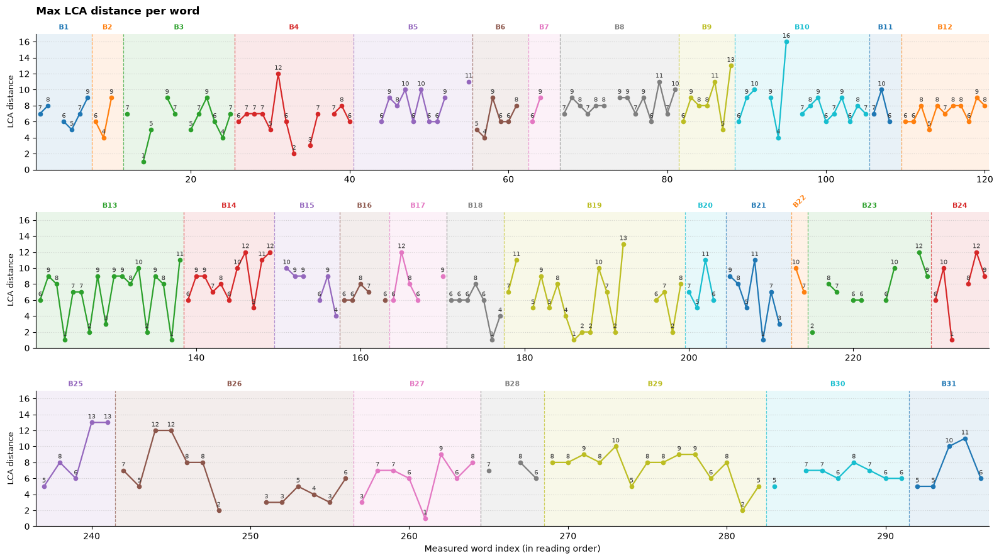

In [32]:
with open('./texts_data/factual_wiki_vaccine.txt', 'r') as file:
    content = file.read()
    # print(content)
    print("\n")
    context_blocks, blocks_max_distances = analyze_semantic_with_context_segments(
        content,
        tokenizer = tokenizer_7b,
        model = model_7b,
        with_bert=True,
        bert_tokenizer=bert_tokenizer_7b,
        bert_model=bert_model_7b,
        print_results=False)

print(blocks_max_distances)
fig = plot_lca_curve(blocks_max_distances, title="Max LCA distance per word", blocks_per_row=12, show_values=True)
fig.tight_layout()
plt.show()
plt.close(fig)




Context: '_Dealer:_' | Target: '"Pedigree?'
Top-5        |      0:good |     1:hello |   2:welcome |       3:yes |       4:exc
----------------------------------------------------------------------------------
0:good       |      1.0000 |      0.4877 |      0.5063 |      0.5885 |      0.3932
1:hello      |      0.4877 |      1.0000 |      0.6406 |      0.5649 |      0.3609
2:welcome    |      0.5063 |      0.6406 |      1.0000 |      0.5293 |      0.3509
3:yes        |      0.5885 |      0.5649 |      0.5293 |      1.0000 |      0.4092
4:exc        |      0.3932 |      0.3609 |      0.3509 |      0.4092 |      1.0000


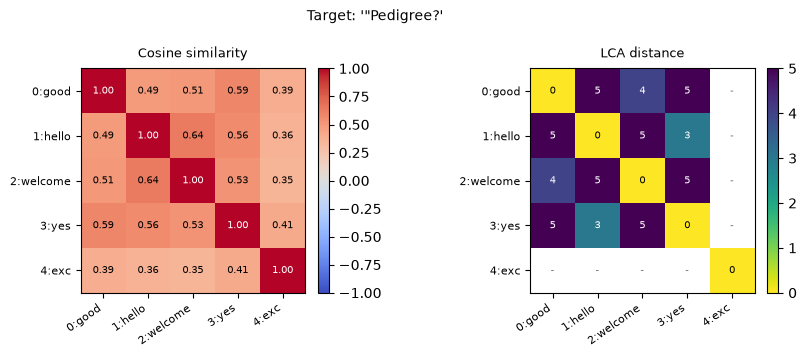


Context: 'I should just' | Target: 'think'
Top-5        |     0:start |       1:pre |   2:mention |      3:note |     4:point
----------------------------------------------------------------------------------
0:start      |      1.0000 |      0.4796 |      0.4705 |      0.5036 |      0.5331
1:pre        |      0.4796 |      1.0000 |      0.7388 |      0.5870 |      0.4750
2:mention    |      0.4705 |      0.7388 |      1.0000 |      0.6153 |      0.4785
3:note       |      0.5036 |      0.5870 |      0.6153 |      1.0000 |      0.5746
4:point      |      0.5331 |      0.4750 |      0.4785 |      0.5746 |      1.0000


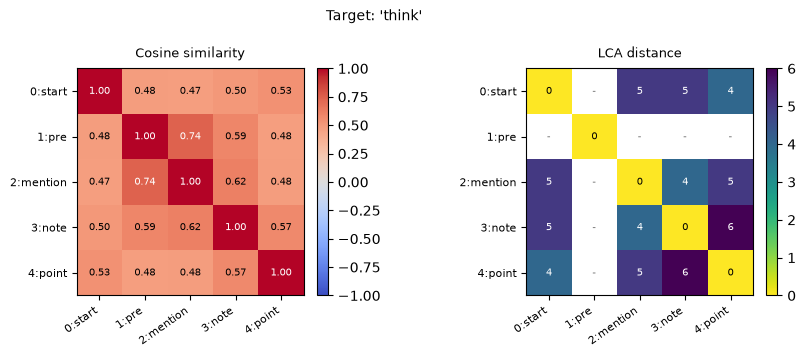


Context: 'I should just think' | Target: ''e'
Top-5        |    0:twice |     1:back |        2:n
---------------------------------------------------
0:twice      |     1.0000 |     0.5627 |     0.4734
1:back       |     0.5627 |     1.0000 |     0.5799
2:n          |     0.4734 |     0.5799 |     1.0000


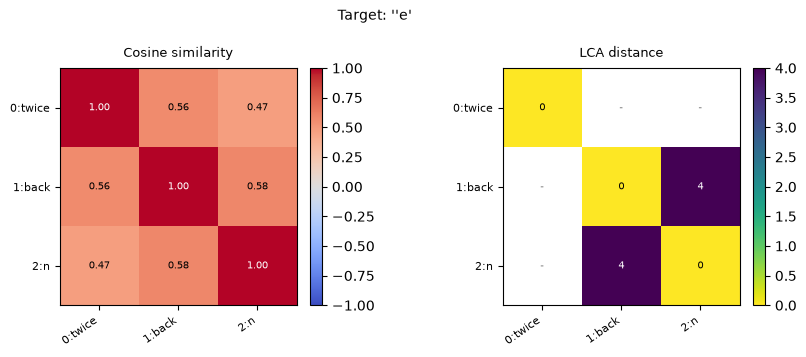


Context: 'I should just think 'e is,' | Target: 'Mum.'
Top-5        |    0:though |       1:sir |        2:eh |    3:indeed |   4:somehow
----------------------------------------------------------------------------------
0:though     |      1.0000 |      0.5316 |      0.5418 |      0.6558 |      0.7168
1:sir        |      0.5316 |      1.0000 |      0.6443 |      0.4693 |      0.5937
2:eh         |      0.5418 |      0.6443 |      1.0000 |      0.4571 |      0.5794
3:indeed     |      0.6558 |      0.4693 |      0.4571 |      1.0000 |      0.5548
4:somehow    |      0.7168 |      0.5937 |      0.5794 |      0.5548 |      1.0000


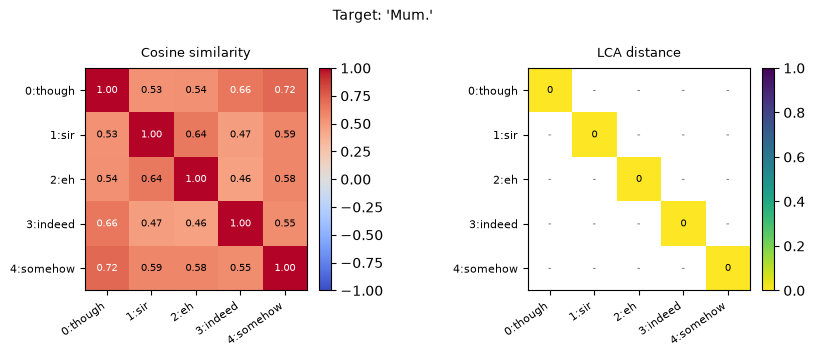


Context: 'Why, if the' | Target: 'animal'
Top-5        |        0:sum |   1:function |     2:number |   3:equation |    4:product
---------------------------------------------------------------------------------------
0:sum        |       1.0000 |       0.6384 |       0.6528 |       0.6134 |       0.6689
1:function   |       0.6384 |       1.0000 |       0.6338 |       0.6598 |       0.6281
2:number     |       0.6528 |       0.6338 |       1.0000 |       0.6853 |       0.6604
3:equation   |       0.6134 |       0.6598 |       0.6853 |       1.0000 |       0.6423
4:product    |       0.6689 |       0.6281 |       0.6604 |       0.6423 |       1.0000


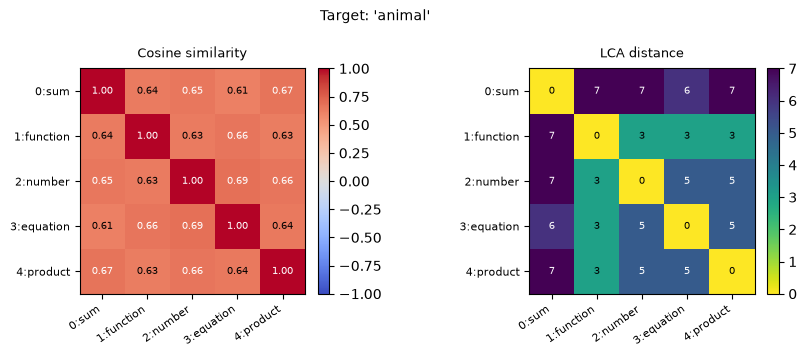


Context: 'Why, if the animal could only' | Target: 'talk'
Top-5        |     0:move |      1:see |      2:eat |     3:live |     4:walk
-----------------------------------------------------------------------------
0:move       |     1.0000 |     0.6412 |     0.7491 |     0.5367 |     0.7723
1:see        |     0.6412 |     1.0000 |     0.6530 |     0.5229 |     0.6498
2:eat        |     0.7491 |     0.6530 |     1.0000 |     0.5972 |     0.7845
3:live       |     0.5367 |     0.5229 |     0.5972 |     1.0000 |     0.5903
4:walk       |     0.7723 |     0.6498 |     0.7845 |     0.5903 |     1.0000


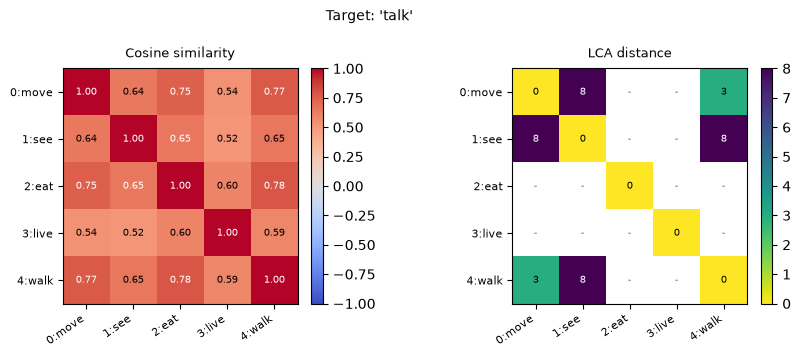


Context: 'Why, if the animal could only talk' | Target: ''e'
Top-5        |      0:back |   1:english
----------------------------------------
0:back       |      1.0000 |      0.5024
1:english    |      0.5024 |      1.0000


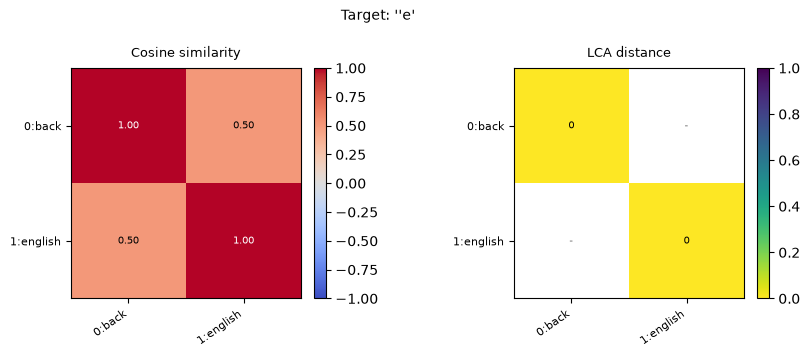


Context: 'Why, if the animal could only talk 'e' | Target: 'wouldn't'
Top-5        |    0:asily |     1:agle |       2:ek |      3:leg |        4:e
-----------------------------------------------------------------------------
0:asily      |     1.0000 |     0.6351 |     0.7476 |     0.5711 |     0.5996
1:agle       |     0.6351 |     1.0000 |     0.5504 |     0.4626 |     0.5093
2:ek         |     0.7476 |     0.5504 |     1.0000 |     0.6467 |     0.6924
3:leg        |     0.5711 |     0.4626 |     0.6467 |     1.0000 |     0.6221
4:e          |     0.5996 |     0.5093 |     0.6924 |     0.6221 |     1.0000


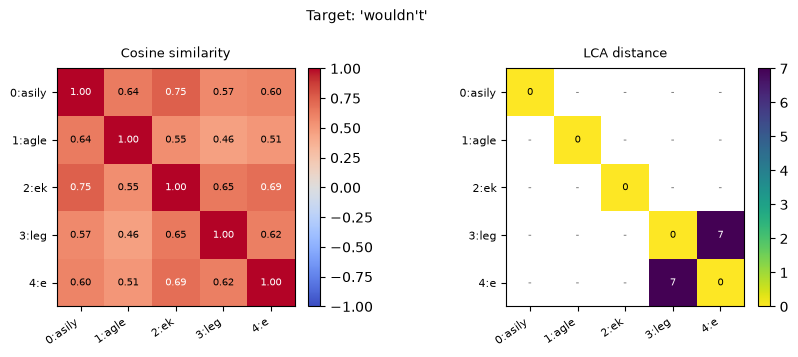


Context: 'Why, if the animal could only talk 'e wouldn't' | Target: 'speak'
Top-5          |         0:know |          1:eat |         2:want |   3:understand |         4:need
---------------------------------------------------------------------------------------------------
0:know         |         1.0000 |         0.7342 |         0.7659 |         0.8712 |         0.7421
1:eat          |         0.7342 |         1.0000 |         0.7447 |         0.7753 |         0.7318
2:want         |         0.7659 |         0.7447 |         1.0000 |         0.7489 |         0.8792
3:understand   |         0.8712 |         0.7753 |         0.7489 |         1.0000 |         0.7472
4:need         |         0.7421 |         0.7318 |         0.8792 |         0.7472 |         1.0000


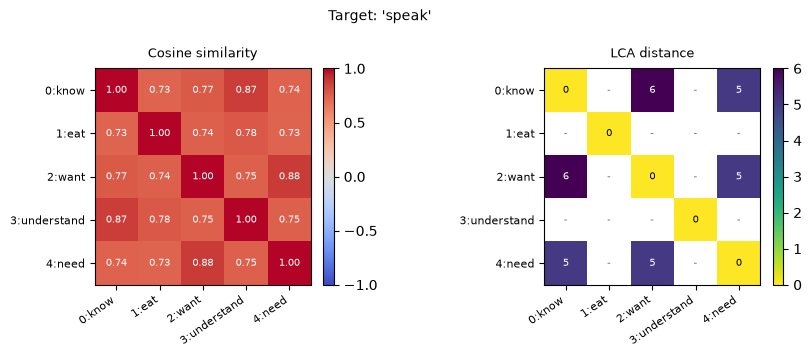


Context: 'Why, if the animal could only talk 'e wouldn't speak to' | Target: 'either'
Top-5        |   0:anyone |   1:humans |   2:people |      3:man |       4:ya
-----------------------------------------------------------------------------
0:anyone     |     1.0000 |     0.6161 |     0.7599 |     0.7401 |     0.5966
1:humans     |     0.6161 |     1.0000 |     0.7721 |     0.6216 |     0.5060
2:people     |     0.7599 |     0.7721 |     1.0000 |     0.7098 |     0.5990
3:man        |     0.7401 |     0.6216 |     0.7098 |     1.0000 |     0.6804
4:ya         |     0.5966 |     0.5060 |     0.5990 |     0.6804 |     1.0000


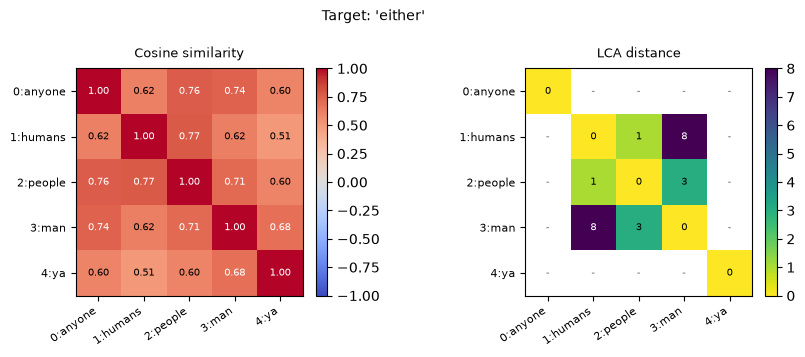


Context: '_Small' | Target: 'Bridesmaid_'
Top-5        |      0:int |     1:size |   2:object |     3:font |   4:number
-----------------------------------------------------------------------------
0:int        |     1.0000 |     0.6769 |     0.7024 |     0.5366 |     0.6276
1:size       |     0.6769 |     1.0000 |     0.7005 |     0.5810 |     0.8055
2:object     |     0.7024 |     0.7005 |     1.0000 |     0.5366 |     0.6668
3:font       |     0.5366 |     0.5810 |     0.5366 |     1.0000 |     0.5469
4:number     |     0.6276 |     0.8055 |     0.6668 |     0.5469 |     1.0000


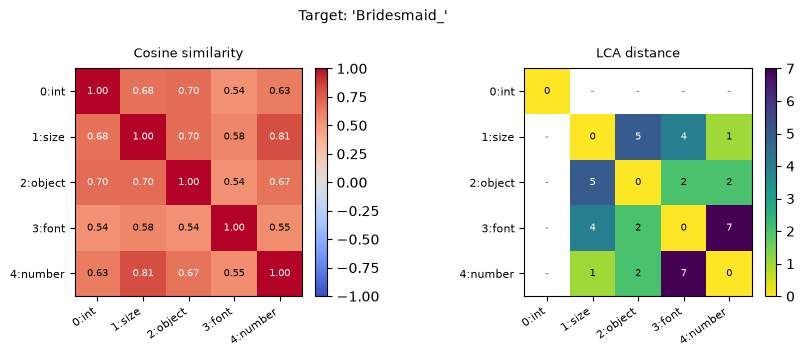


Context: '_Small Bridesmaid_' | Target: '(_loudly,'
Top-5        |     0:dress |   1:wedding |   2:dresses |         3:b
--------------------------------------------------------------------
0:dress      |      1.0000 |      0.7994 |      0.7978 |      0.5649
1:wedding    |      0.7994 |      1.0000 |      0.7441 |      0.5013
2:dresses    |      0.7978 |      0.7441 |      1.0000 |      0.3965
3:b          |      0.5649 |      0.5013 |      0.3965 |      1.0000


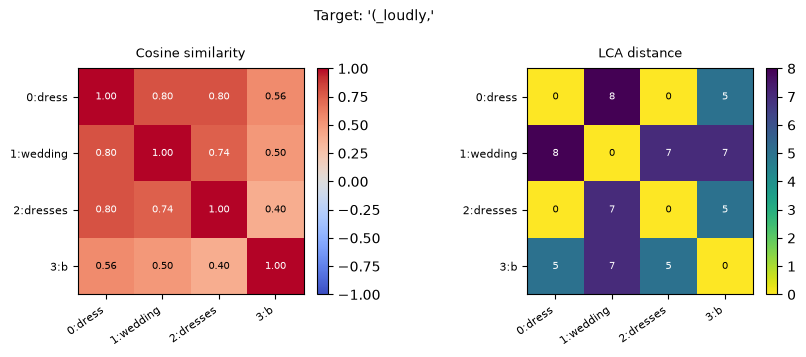


Context: '_Small Bridesmaid_ (_loudly, in' | Target: 'middle'
Top-5         |       0:shock |    1:response |       2:front |   3:disbelief |        4:mock
---------------------------------------------------------------------------------------------
0:shock       |        1.0000 |        0.6969 |        0.7362 |        0.9399 |        0.8171
1:response    |        0.6969 |        1.0000 |        0.7046 |        0.7211 |        0.7249
2:front       |        0.7362 |        0.7046 |        1.0000 |        0.7341 |        0.7645
3:disbelief   |        0.9399 |        0.7211 |        0.7341 |        1.0000 |        0.8427
4:mock        |        0.8171 |        0.7249 |        0.7645 |        0.8427 |        1.0000


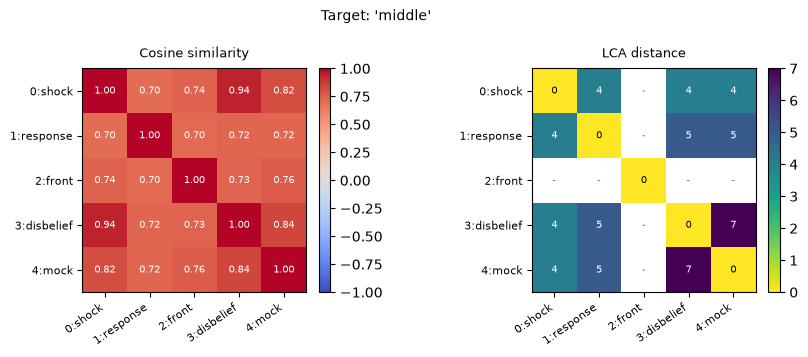


Context: '_Small Bridesmaid_ (_loudly, in middle of' | Target: 'ceremony_):'
Top-5        |      0:aisle |    1:wedding |   2:sentence |     3:church |       4:room
---------------------------------------------------------------------------------------
0:aisle      |       1.0000 |       0.7733 |       0.6859 |       0.3446 |       0.8110
1:wedding    |       0.7733 |       1.0000 |       0.6984 |       0.3714 |       0.7453
2:sentence   |       0.6859 |       0.6984 |       1.0000 |       0.3195 |       0.7187
3:church     |       0.3446 |       0.3714 |       0.3195 |       1.0000 |       0.3192
4:room       |       0.8110 |       0.7453 |       0.7187 |       0.3192 |       1.0000


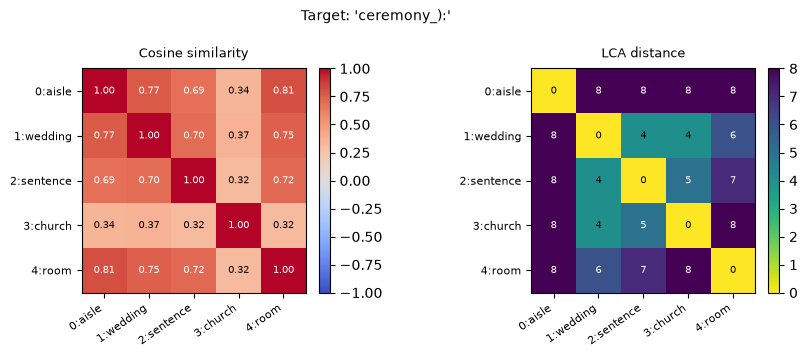


Context: '_Small Bridesmaid_ (_loudly, in middle of ceremony_):' | Target: '"Mummie,'
Top-5        |       0:oh |     1:wait |      2:hey |     3:look |       4:uh
-----------------------------------------------------------------------------
0:oh         |     1.0000 |     0.7956 |     0.7320 |     0.7289 |     0.7930
1:wait       |     0.7956 |     1.0000 |     0.7107 |     0.6832 |     0.7009
2:hey        |     0.7320 |     0.7107 |     1.0000 |     0.7082 |     0.7274
3:look       |     0.7289 |     0.6832 |     0.7082 |     1.0000 |     0.6872
4:uh         |     0.7930 |     0.7009 |     0.7274 |     0.6872 |     1.0000


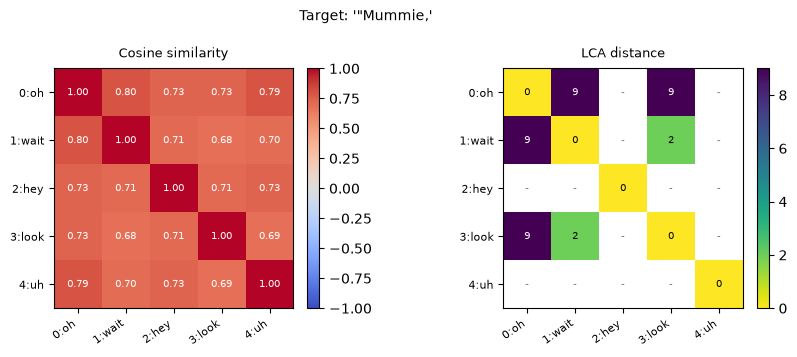


Context: '_Small Bridesmaid_ (_loudly, in middle of ceremony_): "Mummie, are we all' | Target: 'getting'
Top-5        |    0:going |    1:ready |    2:gonna |    3:right |      4:set
-----------------------------------------------------------------------------
0:going      |     1.0000 |     0.6823 |     0.8620 |     0.7241 |     0.6524
1:ready      |     0.6823 |     1.0000 |     0.6556 |     0.7124 |     0.5318
2:gonna      |     0.8620 |     0.6556 |     1.0000 |     0.6732 |     0.6278
3:right      |     0.7241 |     0.7124 |     0.6732 |     1.0000 |     0.6059
4:set        |     0.6524 |     0.5318 |     0.6278 |     0.6059 |     1.0000


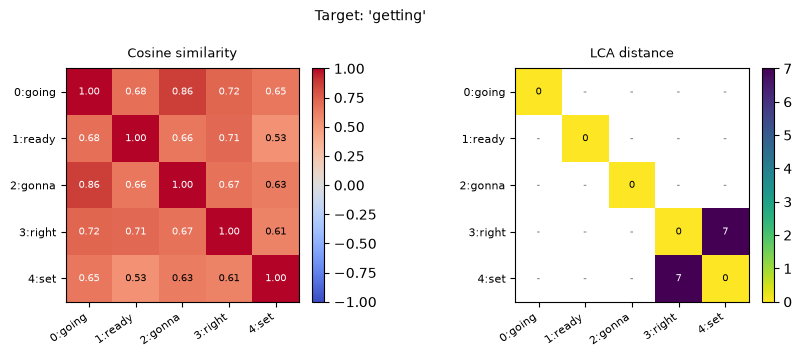


Context: '_Small Bridesmaid_ (_loudly, in middle of ceremony_): "Mummie, are we all getting' | Target: 'married?"'
Top-5        |    0:married |        1:ice |       2:cake |   3:presents |     4:drinks
---------------------------------------------------------------------------------------
0:married    |       1.0000 |       0.4652 |       0.4719 |       0.5939 |       0.5360
1:ice        |       0.4652 |       1.0000 |       0.6346 |       0.6251 |       0.7316
2:cake       |       0.4719 |       0.6346 |       1.0000 |       0.6242 |       0.6768
3:presents   |       0.5939 |       0.6251 |       0.6242 |       1.0000 |       0.7059
4:drinks     |       0.5360 |       0.7316 |       0.6768 |       0.7059 |       1.0000


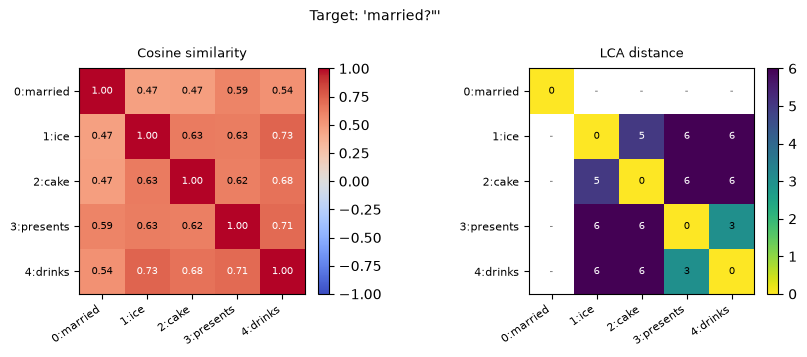


Context: '_Small' | Target: 'Girl:_'
Top-5        |      0:int |     1:size |   2:object |     3:font |   4:number
-----------------------------------------------------------------------------
0:int        |     1.0000 |     0.6769 |     0.7024 |     0.5366 |     0.6276
1:size       |     0.6769 |     1.0000 |     0.7005 |     0.5810 |     0.8055
2:object     |     0.7024 |     0.7005 |     1.0000 |     0.5366 |     0.6668
3:font       |     0.5366 |     0.5810 |     0.5366 |     1.0000 |     0.5469
4:number     |     0.6276 |     0.8055 |     0.6668 |     0.5469 |     1.0000


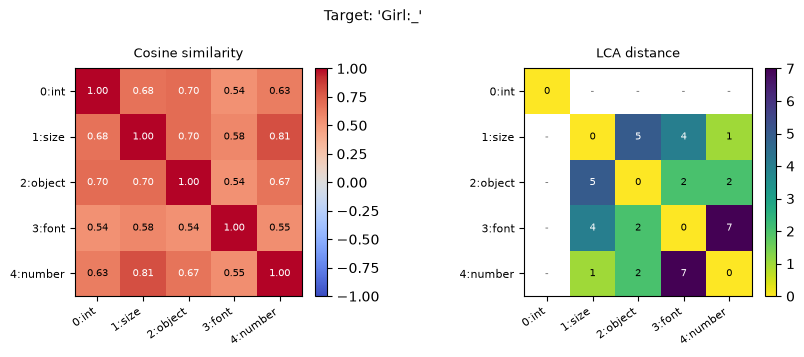


Context: '_Small Girl:_' | Target: '"To-day's'
Top-5        |      0:yes |       1:oh |     2:yeah |    3:hello |     4:good
-----------------------------------------------------------------------------
0:yes        |     1.0000 |     0.7699 |     0.8278 |     0.5649 |     0.5885
1:oh         |     0.7699 |     1.0000 |     0.7941 |     0.5163 |     0.5731
2:yeah       |     0.8278 |     0.7941 |     1.0000 |     0.4975 |     0.6240
3:hello      |     0.5649 |     0.5163 |     0.4975 |     1.0000 |     0.4877
4:good       |     0.5885 |     0.5731 |     0.6240 |     0.4877 |     1.0000


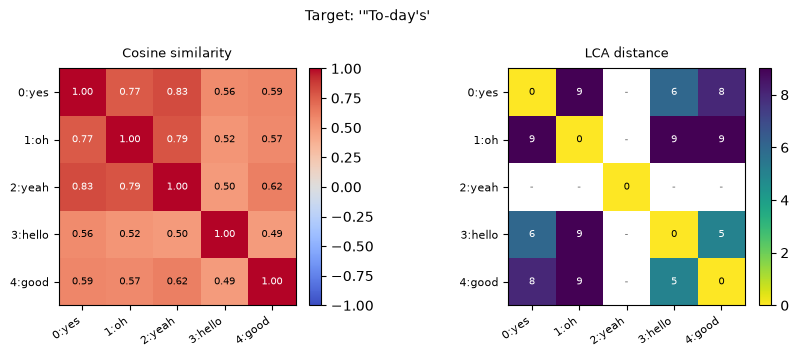


Context: '_Small Girl:_ "To-day's my' | Target: 'mummy's'
Top-5        |   0:birthday |      1:first |       2:last |     3:mother |         4:th
---------------------------------------------------------------------------------------
0:birthday   |       1.0000 |       0.4732 |       0.6564 |       0.6797 |       0.5560
1:first      |       0.4732 |       1.0000 |       0.7096 |       0.6474 |       0.4921
2:last       |       0.6564 |       0.7096 |       1.0000 |       0.7233 |       0.6460
3:mother     |       0.6797 |       0.6474 |       0.7233 |       1.0000 |       0.6385
4:th         |       0.5560 |       0.4921 |       0.6460 |       0.6385 |       1.0000


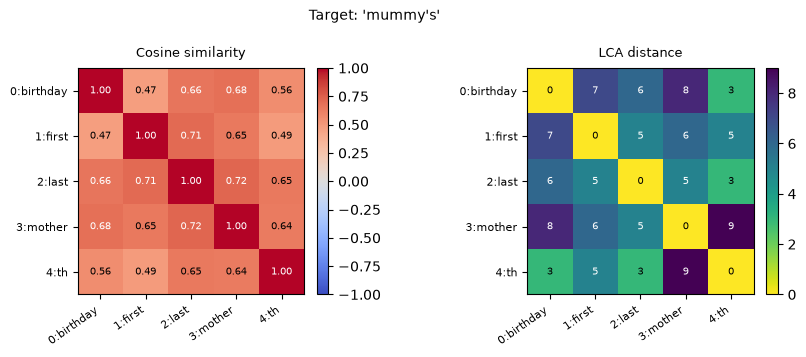


Context: '_Small Girl:_ "To-day's my mummy's' | Target: 'wedding-day."'
Top-5           |      0:birthday |           1:day |       2:wedding |             3:b |   4:anniversary
---------------------------------------------------------------------------------------------------------
0:birthday      |          1.0000 |          0.5602 |          0.7448 |          0.3928 |          0.6973
1:day           |          0.5602 |          1.0000 |          0.5813 |          0.3571 |          0.4569
2:wedding       |          0.7448 |          0.5813 |          1.0000 |          0.5013 |          0.6764
3:b             |          0.3928 |          0.3571 |          0.5013 |          1.0000 |          0.4622
4:anniversary   |          0.6973 |          0.4569 |          0.6764 |          0.4622 |          1.0000


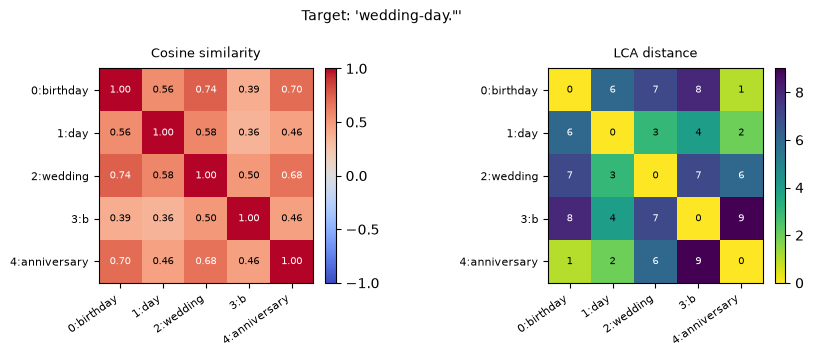


Context: '_Smaller' | Target: 'Girl_'
Top-5        |     0:size |   1:number |    2:value |    3:array |     4:font
-----------------------------------------------------------------------------
0:size       |     1.0000 |     0.8055 |     0.7561 |     0.6611 |     0.5810
1:number     |     0.8055 |     1.0000 |     0.7549 |     0.6483 |     0.5469
2:value      |     0.7561 |     0.7549 |     1.0000 |     0.7311 |     0.5382
3:array      |     0.6611 |     0.6483 |     0.7311 |     1.0000 |     0.5719
4:font       |     0.5810 |     0.5469 |     0.5382 |     0.5719 |     1.0000


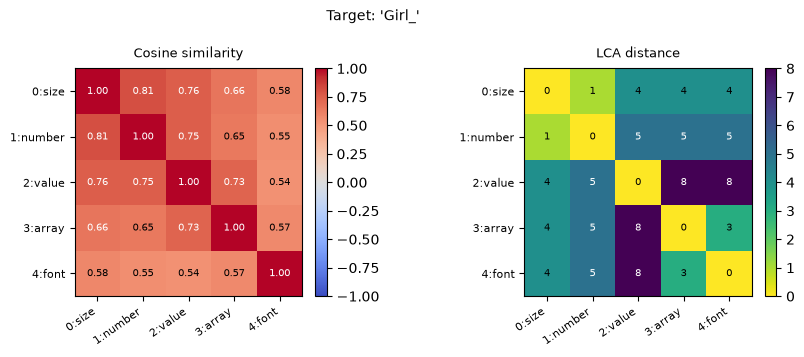


Context: '_Smaller Girl_ (_with' | Target: 'air'
Top-5         |         0:red |        1:blue |        2:hair |   3:apologies |        4:long
---------------------------------------------------------------------------------------------
0:red         |        1.0000 |        0.7940 |        0.6007 |        0.5912 |        0.5485
1:blue        |        0.7940 |        1.0000 |        0.5557 |        0.6090 |        0.5813
2:hair        |        0.6007 |        0.5557 |        1.0000 |        0.4803 |        0.4896
3:apologies   |        0.5912 |        0.6090 |        0.4803 |        1.0000 |        0.5129
4:long        |        0.5485 |        0.5813 |        0.4896 |        0.5129 |        1.0000


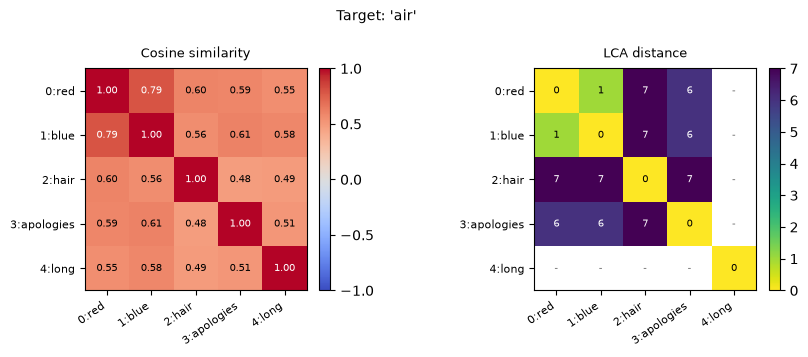


Context: '_Smaller Girl_ (_with air of' | Target: 'superiority_):'
Top-5           |      0:defiance |   1:superiority |     2:authority |    3:confidence |       4:triumph
---------------------------------------------------------------------------------------------------------
0:defiance      |          1.0000 |          0.6938 |          0.6992 |          0.6970 |          0.7178
1:superiority   |          0.6938 |          1.0000 |          0.6706 |          0.5671 |          0.6827
2:authority     |          0.6992 |          0.6706 |          1.0000 |          0.6428 |          0.6213
3:confidence    |          0.6970 |          0.5671 |          0.6428 |          1.0000 |          0.5596
4:triumph       |          0.7178 |          0.6827 |          0.6213 |          0.5596 |          1.0000


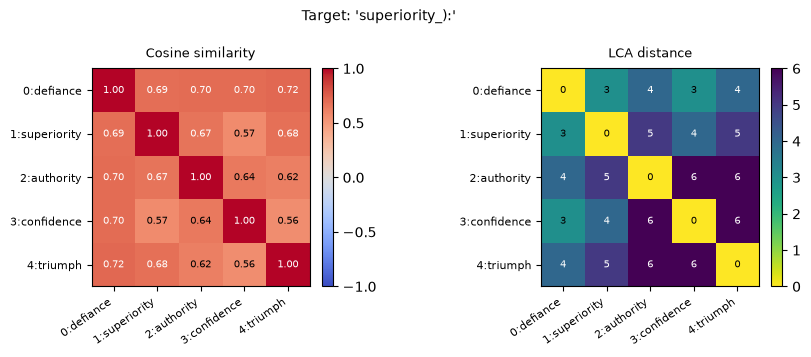


Context: '_Smaller Girl_ (_with air of superiority_): "_My_' | Target: 'mummy'
Top-5        |      0:name |    1:mother |    2:father |   3:parents |    4:family
----------------------------------------------------------------------------------
0:name       |      1.0000 |      0.8059 |      0.7675 |      0.7486 |      0.8072
1:mother     |      0.8059 |      1.0000 |      0.9228 |      0.8332 |      0.7990
2:father     |      0.7675 |      0.9228 |      1.0000 |      0.8075 |      0.7734
3:parents    |      0.7486 |      0.8332 |      0.8075 |      1.0000 |      0.8162
4:family     |      0.8072 |      0.7990 |      0.7734 |      0.8162 |      1.0000


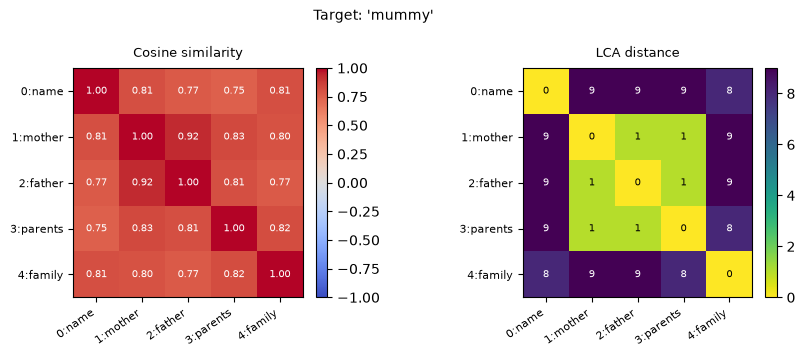


Context: '_Smaller Girl_ (_with air of superiority_): "_My_ mummy was' | Target: 'married'
Top-5        |   0:always |     1:born |    2:never |     3:nice |    4:first
-----------------------------------------------------------------------------
0:always     |     1.0000 |     0.6314 |     0.8476 |     0.6588 |     0.6184
1:born       |     0.6314 |     1.0000 |     0.6883 |     0.5943 |     0.5506
2:never      |     0.8476 |     0.6883 |     1.0000 |     0.6628 |     0.6505
3:nice       |     0.6588 |     0.5943 |     0.6628 |     1.0000 |     0.5736
4:first      |     0.6184 |     0.5506 |     0.6505 |     0.5736 |     1.0000


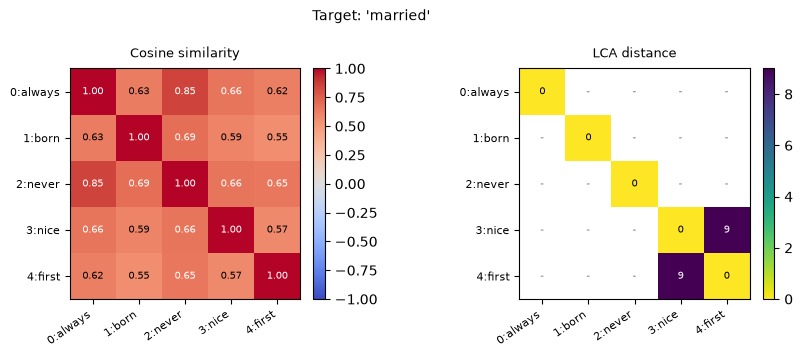


Context: '_Smaller Girl_ (_with air of superiority_): "_My_ mummy was married' | Target: '_years_'
Top-5        |    0:first |    1:twice |    2:three |     3:five |     4:four
-----------------------------------------------------------------------------
0:first      |     1.0000 |     0.5377 |     0.5925 |     0.5821 |     0.5619
1:twice      |     0.5377 |     1.0000 |     0.5743 |     0.4791 |     0.5020
2:three      |     0.5925 |     0.5743 |     1.0000 |     0.8208 |     0.8457
3:five       |     0.5821 |     0.4791 |     0.8208 |     1.0000 |     0.8584
4:four       |     0.5619 |     0.5020 |     0.8457 |     0.8584 |     1.0000


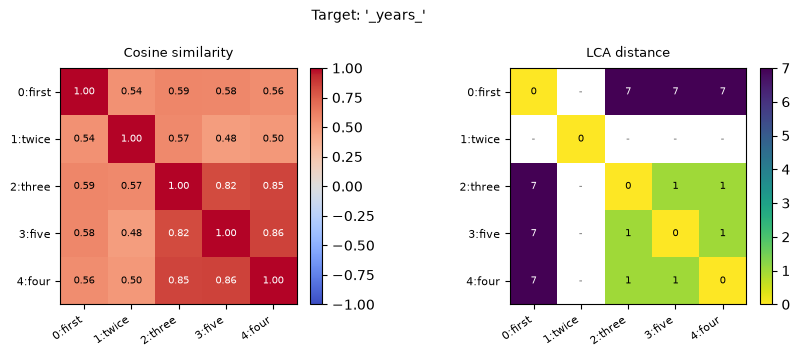


Context: '"Wot's a' | Target: 'minimum'
Top-5        |      0:blog |         1:f |   2:podcast |      3:meme |         4:g
----------------------------------------------------------------------------------
0:blog       |      1.0000 |      0.4632 |      0.8103 |      0.4200 |      0.4729
1:f          |      0.4632 |      1.0000 |      0.4099 |      0.5089 |      0.8116
2:podcast    |      0.8103 |      0.4099 |      1.0000 |      0.4056 |      0.4238
3:meme       |      0.4200 |      0.5089 |      0.4056 |      1.0000 |      0.4341
4:g          |      0.4729 |      0.8116 |      0.4238 |      0.4341 |      1.0000


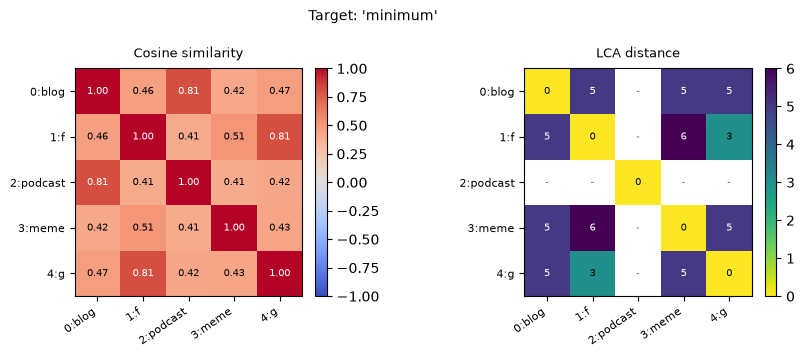


Context: '"Wot's a minimum' | Target: 'wage,'
Top-5        |       0:wage |   1:spanning |        2:age |      3:price |      4:speed
---------------------------------------------------------------------------------------
0:wage       |       1.0000 |       0.8132 |       0.6332 |       0.7743 |       0.6980
1:spanning   |       0.8132 |       1.0000 |       0.6450 |       0.7616 |       0.6876
2:age        |       0.6332 |       0.6450 |       1.0000 |       0.7041 |       0.6372
3:price      |       0.7743 |       0.7616 |       0.7041 |       1.0000 |       0.6976
4:speed      |       0.6980 |       0.6876 |       0.6372 |       0.6976 |       1.0000


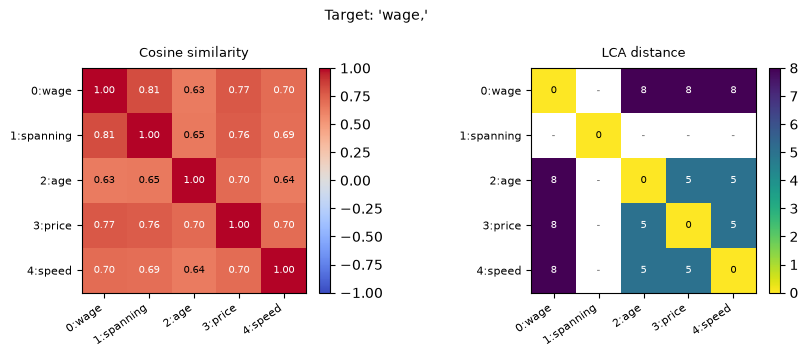


Context: '"Wot's a minimum wage,' | Target: 'Albert?"'
Top-5        |      0:boss |    1:anyway |   2:exactly |       3:cap |       4:doc
----------------------------------------------------------------------------------
0:boss       |      1.0000 |      0.4218 |      0.6334 |      0.6656 |      0.7939
1:anyway     |      0.4218 |      1.0000 |      0.4714 |      0.3622 |      0.3628
2:exactly    |      0.6334 |      0.4714 |      1.0000 |      0.6558 |      0.6396
3:cap        |      0.6656 |      0.3622 |      0.6558 |      1.0000 |      0.7229
4:doc        |      0.7939 |      0.3628 |      0.6396 |      0.7229 |      1.0000


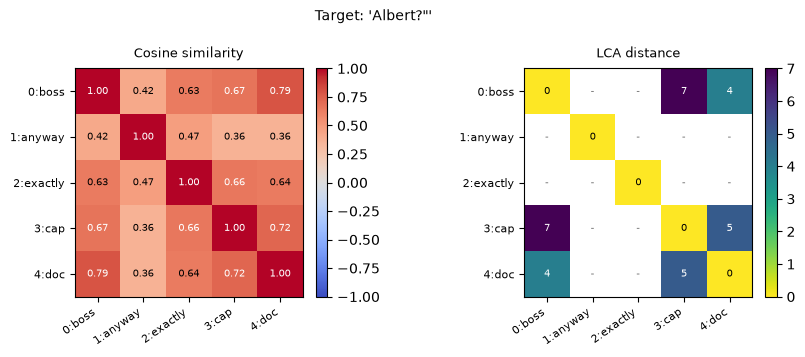


Context: '"Wot' | Target: 'yer'
Top-5        |      0:cha |     1:cher |        2:z |        3:w |      4:ani
-----------------------------------------------------------------------------
0:cha        |     1.0000 |     0.7296 |     0.6130 |     0.6153 |     0.6073
1:cher       |     0.7296 |     1.0000 |     0.5985 |     0.5835 |     0.5547
2:z          |     0.6130 |     0.5985 |     1.0000 |     0.7378 |     0.4494
3:w          |     0.6153 |     0.5835 |     0.7378 |     1.0000 |     0.4492
4:ani        |     0.6073 |     0.5547 |     0.4494 |     0.4492 |     1.0000


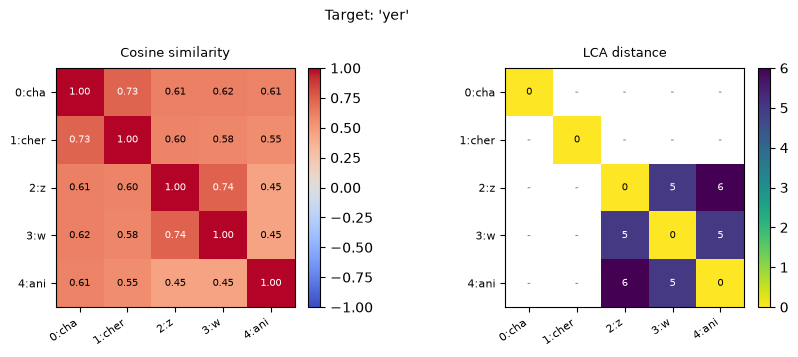


Context: '"Wot yer' | Target: 'gets'
Top-5        |      0:look |      1:name |      2:talk |        3:bl |   4:looking
----------------------------------------------------------------------------------
0:look       |      1.0000 |      0.7193 |      0.7684 |      0.5080 |      0.8590
1:name       |      0.7193 |      1.0000 |      0.7584 |      0.4767 |      0.7307
2:talk       |      0.7684 |      0.7584 |      1.0000 |      0.4809 |      0.7888
3:bl         |      0.5080 |      0.4767 |      0.4809 |      1.0000 |      0.5323
4:looking    |      0.8590 |      0.7307 |      0.7888 |      0.5323 |      1.0000


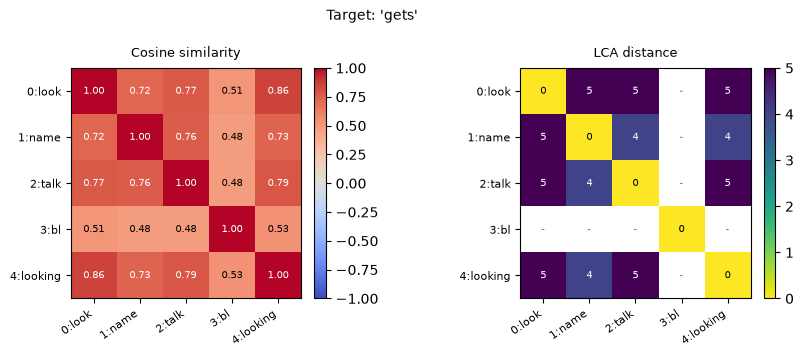


Context: '"Wot yer gets for' | Target: 'goin''
Top-5         |         0:yer |        1:free |   2:christmas |         3:sum |           4:g
---------------------------------------------------------------------------------------------
0:yer         |        1.0000 |        0.6124 |        0.5486 |        0.5715 |        0.6138
1:free        |        0.6124 |        1.0000 |        0.5532 |        0.6157 |        0.6611
2:christmas   |        0.5486 |        0.5532 |        1.0000 |        0.4962 |        0.4843
3:sum         |        0.5715 |        0.6157 |        0.4962 |        1.0000 |        0.5748
4:g           |        0.6138 |        0.6611 |        0.4843 |        0.5748 |        1.0000


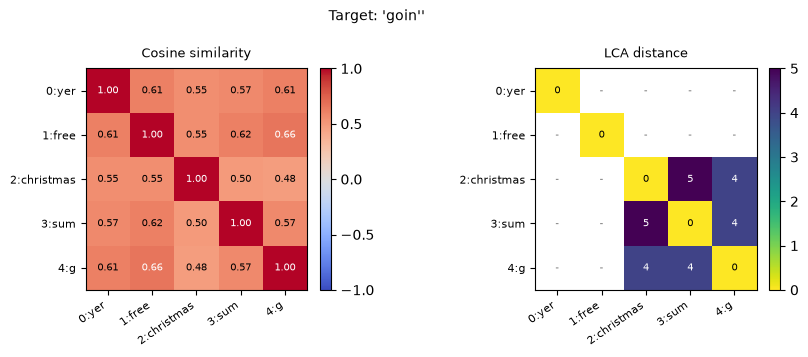


Context: '"Wot yer gets for goin' to' | Target: 'yer'
Top-5          |       0:school |   1:university |          2:war |          3:sea |      4:college
---------------------------------------------------------------------------------------------------
0:school       |         1.0000 |         0.6228 |         0.5840 |         0.6271 |         0.7335
1:university   |         0.6228 |         1.0000 |         0.5067 |         0.5473 |         0.7011
2:war          |         0.5840 |         0.5067 |         1.0000 |         0.6446 |         0.5746
3:sea          |         0.6271 |         0.5473 |         0.6446 |         1.0000 |         0.5872
4:college      |         0.7335 |         0.7011 |         0.5746 |         0.5872 |         1.0000


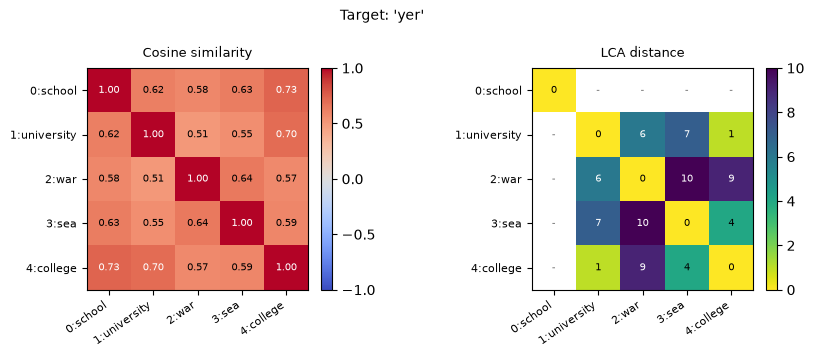


Context: '"Wot yer gets for goin' to yer' | Target: 'work.'
Top-5        |     0:grave |     1:local |   2:funeral |     3:mates |       4:fun
----------------------------------------------------------------------------------
0:grave      |      1.0000 |      0.5987 |      0.7625 |      0.6790 |      0.5232
1:local      |      0.5987 |      1.0000 |      0.6081 |      0.6302 |      0.5531
2:funeral    |      0.7625 |      0.6081 |      1.0000 |      0.7463 |      0.6258
3:mates      |      0.6790 |      0.6302 |      0.7463 |      1.0000 |      0.6394
4:fun        |      0.5232 |      0.5531 |      0.6258 |      0.6394 |      1.0000


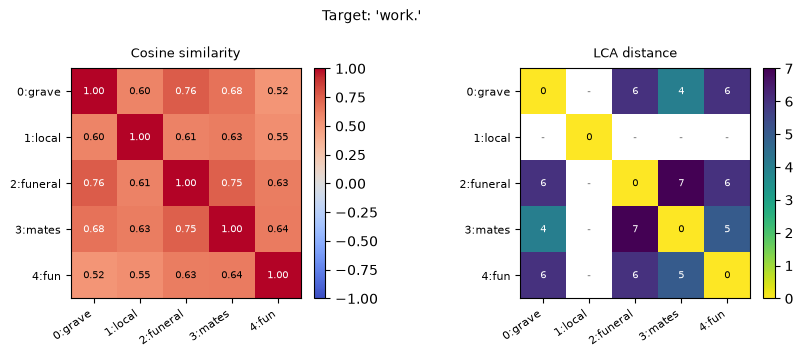


Context: 'If' | Target: 'yer'
Top-5        |     0:john |    1:james |        2:x |       3:mr |    4:three
-----------------------------------------------------------------------------
0:john       |     1.0000 |     0.8345 |     0.4683 |     0.6716 |     0.4900
1:james      |     0.8345 |     1.0000 |     0.4544 |     0.7128 |     0.5765
2:x          |     0.4683 |     0.4544 |     1.0000 |     0.4876 |     0.3881
3:mr         |     0.6716 |     0.7128 |     0.4876 |     1.0000 |     0.5262
4:three      |     0.4900 |     0.5765 |     0.3881 |     0.5262 |     1.0000


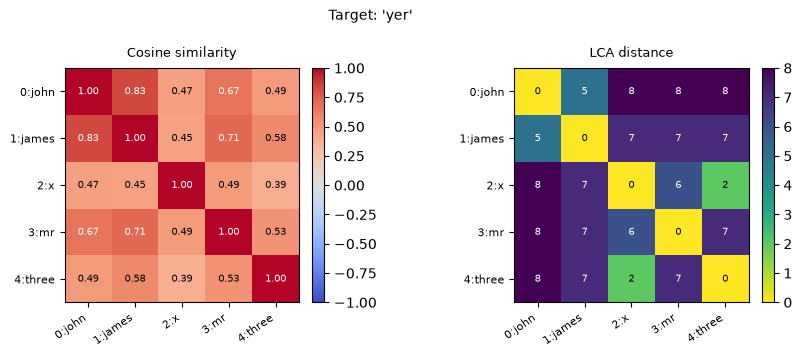


Context: 'If yer' | Target: 'wants'
Top-5        |       0:mom |   1:looking |        2:ba |    3:mother |     4:gonna
----------------------------------------------------------------------------------
0:mom        |      1.0000 |      0.7091 |      0.6781 |      0.8288 |      0.6610
1:looking    |      0.7091 |      1.0000 |      0.7447 |      0.7683 |      0.7617
2:ba         |      0.6781 |      0.7447 |      1.0000 |      0.6956 |      0.7731
3:mother     |      0.8288 |      0.7683 |      0.6956 |      1.0000 |      0.6976
4:gonna      |      0.6610 |      0.7617 |      0.7731 |      0.6976 |      1.0000


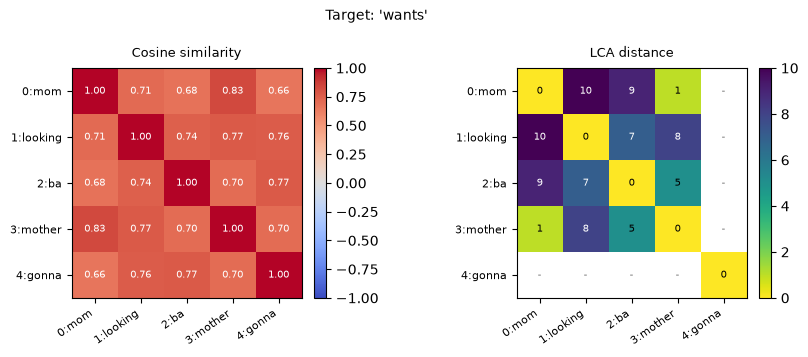


Context: 'If yer wants' | Target: 'ter'
Top-5        |       0:ta |      1:sum |      2:yer |      3:ter |      4:fer
-----------------------------------------------------------------------------
0:ta         |     1.0000 |     0.5993 |     0.6972 |     0.7543 |     0.5169
1:sum        |     0.5993 |     1.0000 |     0.5715 |     0.6397 |     0.4391
2:yer        |     0.6972 |     0.5715 |     1.0000 |     0.7655 |     0.5015
3:ter        |     0.7543 |     0.6397 |     0.7655 |     1.0000 |     0.5451
4:fer        |     0.5169 |     0.4391 |     0.5015 |     0.5451 |     1.0000


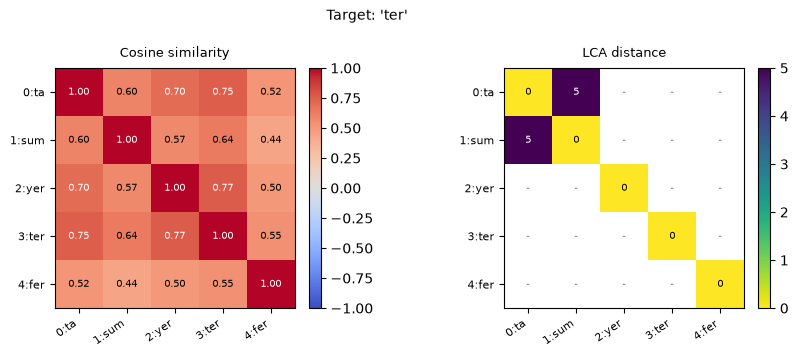


Context: 'If yer wants ter make a' | Target: 'bit'
Top-5        |     0:good |     1:list |        2:l |     3:buck |      4:bet
-----------------------------------------------------------------------------
0:good       |     1.0000 |     0.4550 |     0.4532 |     0.5598 |     0.5346
1:list       |     0.4550 |     1.0000 |     0.5573 |     0.6412 |     0.5379
2:l          |     0.4532 |     0.5573 |     1.0000 |     0.6727 |     0.5843
3:buck       |     0.5598 |     0.6412 |     0.6727 |     1.0000 |     0.7050
4:bet        |     0.5346 |     0.5379 |     0.5843 |     0.7050 |     1.0000


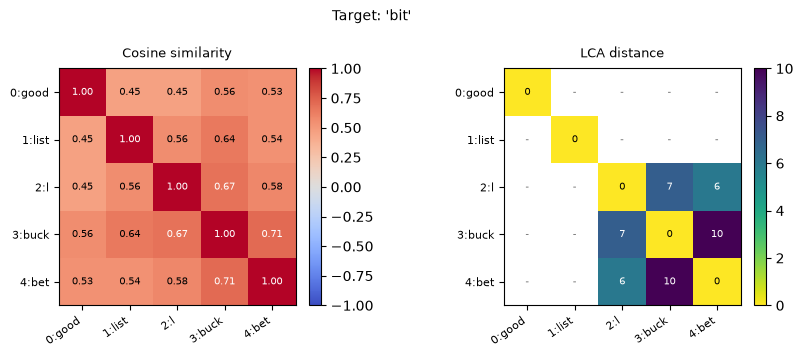


Context: 'If yer wants ter make a bit more' | Target: 'yer'
Top-5        |    0:money |     1:cash |     2:room |       3:cl |    4:dough
-----------------------------------------------------------------------------
0:money      |     1.0000 |     0.8060 |     0.7508 |     0.5997 |     0.7144
1:cash       |     0.8060 |     1.0000 |     0.7986 |     0.7164 |     0.7995
2:room       |     0.7508 |     0.7986 |     1.0000 |     0.6812 |     0.7688
3:cl         |     0.5997 |     0.7164 |     0.6812 |     1.0000 |     0.7451
4:dough      |     0.7144 |     0.7995 |     0.7688 |     0.7451 |     1.0000


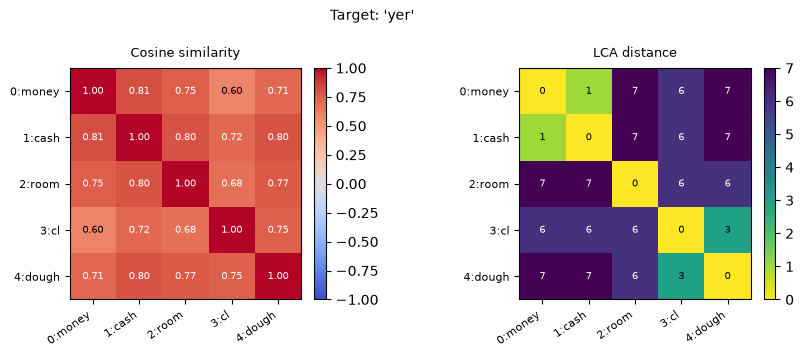


Context: 'If yer wants ter make a bit more yer does a' | Target: 'bit'
Top-5        |      0:bit |   1:little |     2:good |      3:job |   4:better
-----------------------------------------------------------------------------
0:bit        |     1.0000 |     0.6506 |     0.5043 |     0.6709 |     0.5814
1:little     |     0.6506 |     1.0000 |     0.5371 |     0.6146 |     0.5884
2:good       |     0.5043 |     0.5371 |     1.0000 |     0.5637 |     0.6536
3:job        |     0.6709 |     0.6146 |     0.5637 |     1.0000 |     0.5392
4:better     |     0.5814 |     0.5884 |     0.6536 |     0.5392 |     1.0000


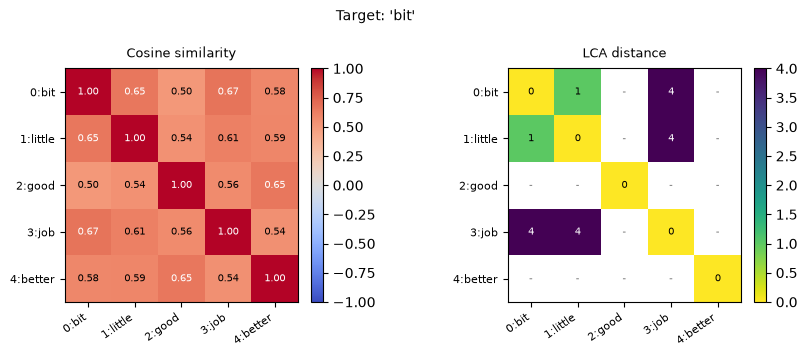


Context: 'If yer wants ter make a bit more yer does a bit o'' | Target: 'work'
Top-5         |          0:po |          1:th |        2:sell |   3:smuggling |       4:smugg
---------------------------------------------------------------------------------------------
0:po          |        1.0000 |        0.6177 |        0.7082 |        0.6542 |        0.6439
1:th          |        0.6177 |        1.0000 |        0.5903 |        0.5987 |        0.5550
2:sell        |        0.7082 |        0.5903 |        1.0000 |        0.7868 |        0.6606
3:smuggling   |        0.6542 |        0.5987 |        0.7868 |        1.0000 |        0.6464
4:smugg       |        0.6439 |        0.5550 |        0.6606 |        0.6464 |        1.0000


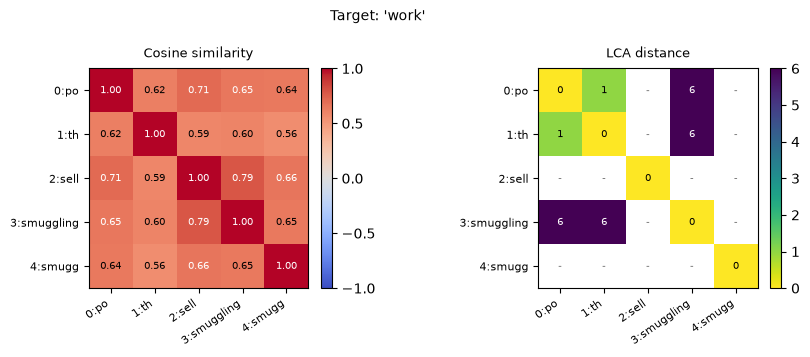


Context: '_Office' | Target: 'Boy_'
Top-5           |       0:manager |         1:hours |           2:app |   3:application |      4:location
---------------------------------------------------------------------------------------------------------
0:manager       |          1.0000 |          0.4068 |          0.4956 |          0.5446 |          0.5580
1:hours         |          0.4068 |          1.0000 |          0.4444 |          0.4748 |          0.4443
2:app           |          0.4956 |          0.4444 |          1.0000 |          0.7149 |          0.6073
3:application   |          0.5446 |          0.4748 |          0.7149 |          1.0000 |          0.6953
4:location      |          0.5580 |          0.4443 |          0.6073 |          0.6953 |          1.0000


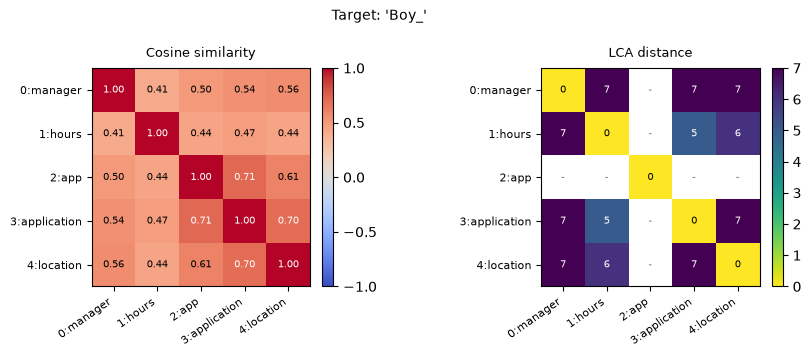


Context: '_Office Boy_ (_anxious to go to' | Target: 'football'
Top-5          |         0:work |      1:college |       2:school |   3:university |      4:beijing
---------------------------------------------------------------------------------------------------
0:work         |         1.0000 |         0.5711 |         0.5996 |         0.4802 |         0.3864
1:college      |         0.5711 |         1.0000 |         0.7335 |         0.7011 |         0.4560
2:school       |         0.5996 |         0.7335 |         1.0000 |         0.6228 |         0.3784
3:university   |         0.4802 |         0.7011 |         0.6228 |         1.0000 |         0.4726
4:beijing      |         0.3864 |         0.4560 |         0.3784 |         0.4726 |         1.0000


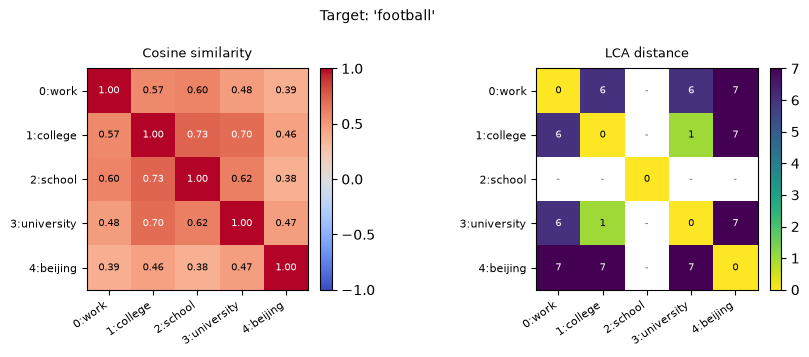


Context: '_Office Boy_ (_anxious to go to football' | Target: 'match_):'
Top-5        |   0:training |   1:practice |      2:match |       3:club |       4:camp
---------------------------------------------------------------------------------------
0:training   |       1.0000 |       0.8404 |       0.2913 |       0.5014 |       0.7047
1:practice   |       0.8404 |       1.0000 |       0.3487 |       0.5092 |       0.6729
2:match      |       0.2913 |       0.3487 |       1.0000 |       0.4082 |       0.3407
3:club       |       0.5014 |       0.5092 |       0.4082 |       1.0000 |       0.6154
4:camp       |       0.7047 |       0.6729 |       0.3407 |       0.6154 |       1.0000


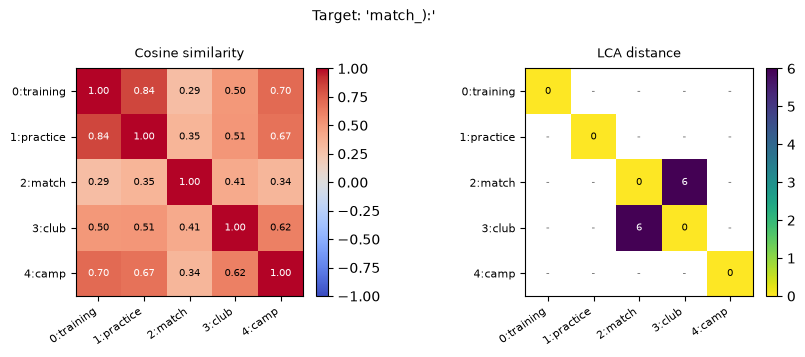


Context: '_Office Boy_ (_anxious to go to football match_): "May I have the' | Target: 'afternoon'
Top-5         |         0:day |      1:honour |        2:time |       3:honor |   4:afternoon
---------------------------------------------------------------------------------------------
0:day         |        1.0000 |        0.5142 |        0.6264 |        0.5651 |        0.6632
1:honour      |        0.5142 |        1.0000 |        0.5348 |        0.7836 |        0.4379
2:time        |        0.6264 |        0.5348 |        1.0000 |        0.6556 |        0.5374
3:honor       |        0.5651 |        0.7836 |        0.6556 |        1.0000 |        0.5421
4:afternoon   |        0.6632 |        0.4379 |        0.5374 |        0.5421 |        1.0000


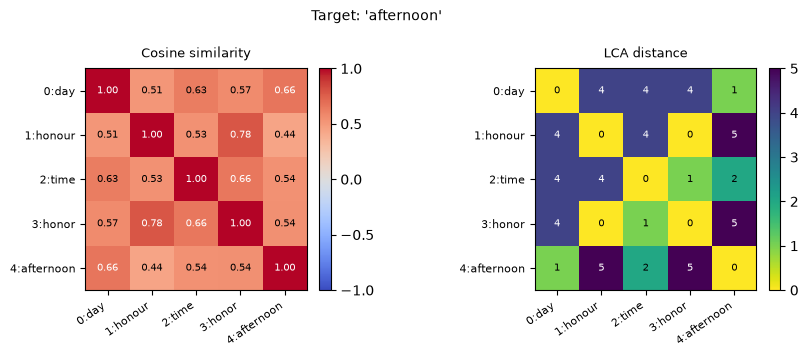


Context: '_Office Boy_ (_anxious to go to football match_): "May I have the afternoon off,' | Target: 'Sir?'
Top-5        |      0:sir |   1:please |       2:mr |     3:boss |     4:miss
-----------------------------------------------------------------------------
0:sir        |     1.0000 |     0.5657 |     0.8238 |     0.6971 |     0.6812
1:please     |     0.5657 |     1.0000 |     0.6046 |     0.6676 |     0.5525
2:mr         |     0.8238 |     0.6046 |     1.0000 |     0.7524 |     0.7803
3:boss       |     0.6971 |     0.6676 |     0.7524 |     1.0000 |     0.6340
4:miss       |     0.6812 |     0.5525 |     0.7803 |     0.6340 |     1.0000


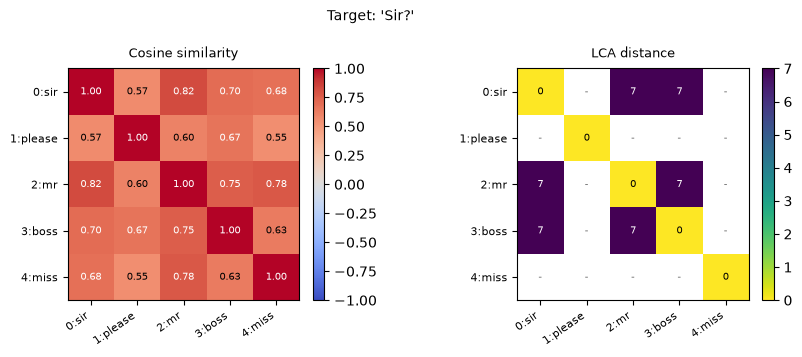


Context: 'My' | Target: 'grand----"'
Top-5        |   0:question |      1:first |    2:problem |       3:math |     4:friend
---------------------------------------------------------------------------------------
0:question   |       1.0000 |       0.6274 |       0.7299 |       0.6257 |       0.7641
1:first      |       0.6274 |       1.0000 |       0.5349 |       0.4979 |       0.5503
2:problem    |       0.7299 |       0.5349 |       1.0000 |       0.6837 |       0.6045
3:math       |       0.6257 |       0.4979 |       0.6837 |       1.0000 |       0.5270
4:friend     |       0.7641 |       0.5503 |       0.6045 |       0.5270 |       1.0000


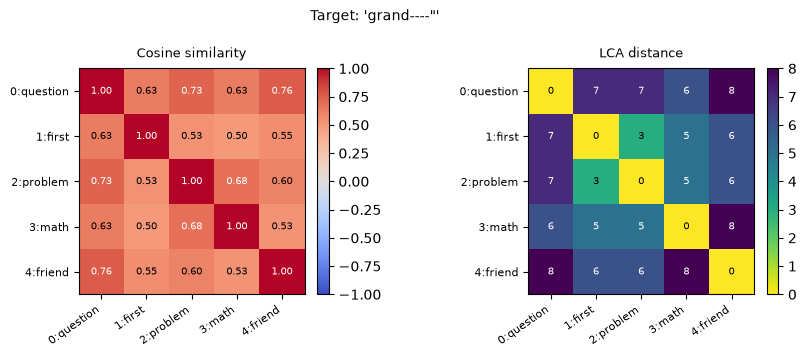


Context: 'My grand----"' | Target: '_Employer:_'
Top-5        |    0:began |      1:mrs |    2:grand |    3:tommy |       4:mr
-----------------------------------------------------------------------------
0:began      |     1.0000 |     0.6661 |     0.6591 |     0.6035 |     0.5971
1:mrs        |     0.6661 |     1.0000 |     0.7530 |     0.7403 |     0.8692
2:grand      |     0.6591 |     0.7530 |     1.0000 |     0.7397 |     0.7334
3:tommy      |     0.6035 |     0.7403 |     0.7397 |     1.0000 |     0.7473
4:mr         |     0.5971 |     0.8692 |     0.7334 |     0.7473 |     1.0000


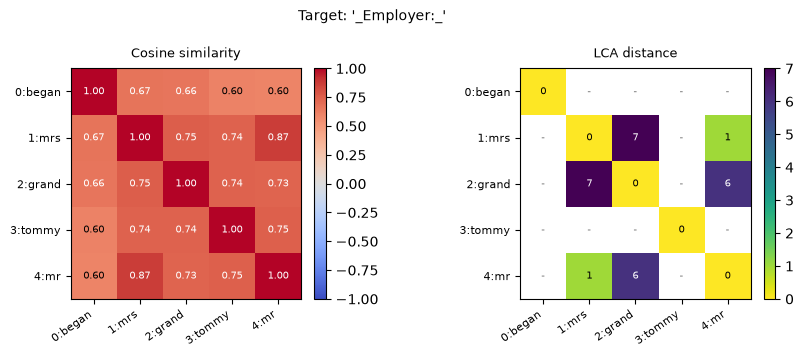


Context: 'My grand----" _Employer:_' | Target: '"Oh,'
Top-5        |       0:yes |        1:oh |   2:silence |     3:grand |        4:ah
----------------------------------------------------------------------------------
0:yes        |      1.0000 |      0.7699 |      0.5536 |      0.5988 |      0.7327
1:oh         |      0.7699 |      1.0000 |      0.6045 |      0.6599 |      0.9006
2:silence    |      0.5536 |      0.6045 |      1.0000 |      0.4929 |      0.5648
3:grand      |      0.5988 |      0.6599 |      0.4929 |      1.0000 |      0.6811
4:ah         |      0.7327 |      0.9006 |      0.5648 |      0.6811 |      1.0000


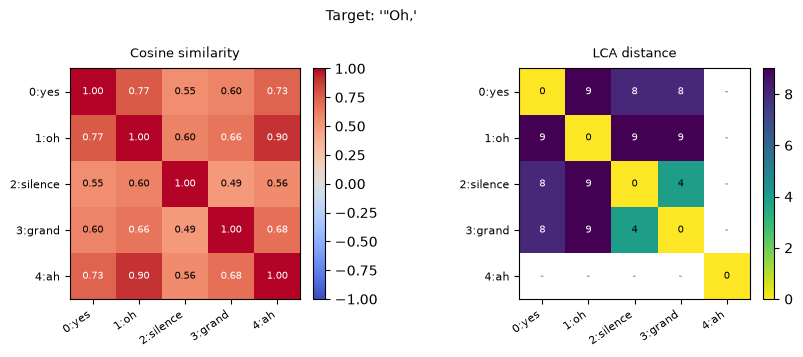


Context: 'My grand----" _Employer:_ "Oh,' | Target: 'yes,'
Top-5        |      0:yes |   1:indeed |     2:dear |   3:excuse |      4:let
-----------------------------------------------------------------------------
0:yes        |     1.0000 |     0.6381 |     0.5956 |     0.6256 |     0.5067
1:indeed     |     0.6381 |     1.0000 |     0.4761 |     0.4576 |     0.4315
2:dear       |     0.5956 |     0.4761 |     1.0000 |     0.6763 |     0.4909
3:excuse     |     0.6256 |     0.4576 |     0.6763 |     1.0000 |     0.6969
4:let        |     0.5067 |     0.4315 |     0.4909 |     0.6969 |     1.0000


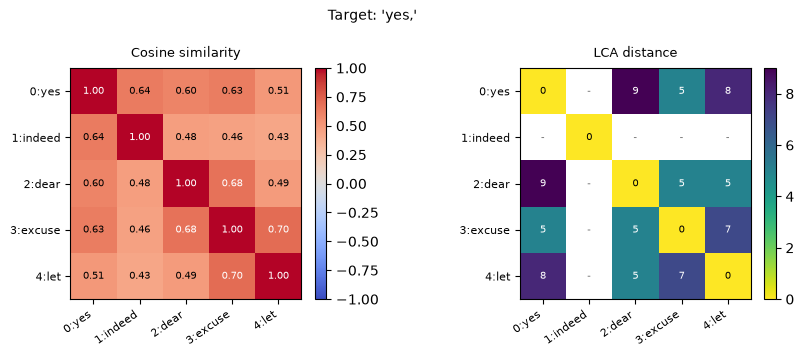


Context: 'Your' | Target: 'grandmother'
Top-5        |       0:task |     1:friend |        2:car |   3:feedback |     4:laptop
---------------------------------------------------------------------------------------
0:task       |       1.0000 |       0.7256 |       0.4915 |       0.7556 |       0.6843
1:friend     |       0.7256 |       1.0000 |       0.5632 |       0.6681 |       0.6598
2:car        |       0.4915 |       0.5632 |       1.0000 |       0.5153 |       0.5337
3:feedback   |       0.7556 |       0.6681 |       0.5153 |       1.0000 |       0.7012
4:laptop     |       0.6843 |       0.6598 |       0.5337 |       0.7012 |       1.0000


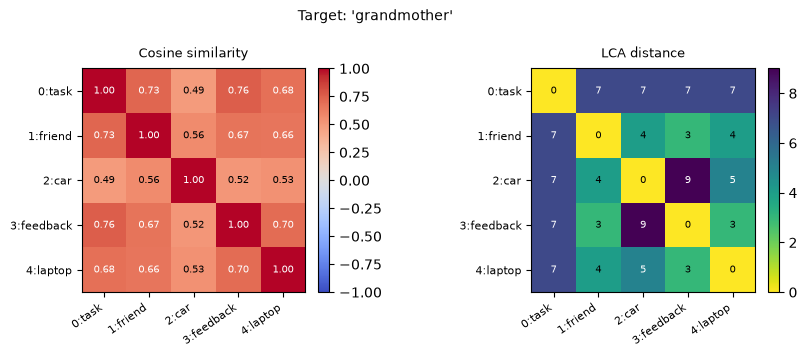


Context: 'Your grandmother' | Target: 'died'
Top-5         |       0:wants |        1:gave |       2:gives |      3:offers |   4:deposited
---------------------------------------------------------------------------------------------
0:wants       |        1.0000 |        0.8114 |        0.7040 |        0.6716 |        0.6186
1:gave        |        0.8114 |        1.0000 |        0.7843 |        0.6652 |        0.6738
2:gives       |        0.7040 |        0.7843 |        1.0000 |        0.6236 |        0.5354
3:offers      |        0.6716 |        0.6652 |        0.6236 |        1.0000 |        0.6601
4:deposited   |        0.6186 |        0.6738 |        0.5354 |        0.6601 |        1.0000


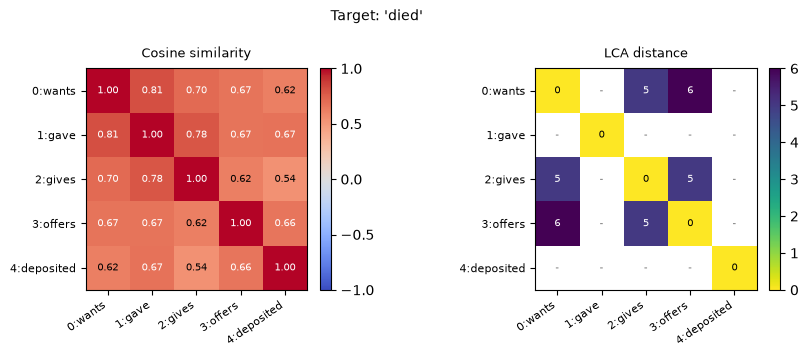


Context: 'Your grandmother died' | Target: 'last'
Top-5         |        0:last |    1:recently |       2:today |   3:yesterday |    4:suddenly
---------------------------------------------------------------------------------------------
0:last        |        1.0000 |        0.7180 |        0.6048 |        0.6758 |        0.4915
1:recently    |        0.7180 |        1.0000 |        0.6088 |        0.6897 |        0.5876
2:today       |        0.6048 |        0.6088 |        1.0000 |        0.6926 |        0.5288
3:yesterday   |        0.6758 |        0.6897 |        0.6926 |        1.0000 |        0.5538
4:suddenly    |        0.4915 |        0.5876 |        0.5288 |        0.5538 |        1.0000


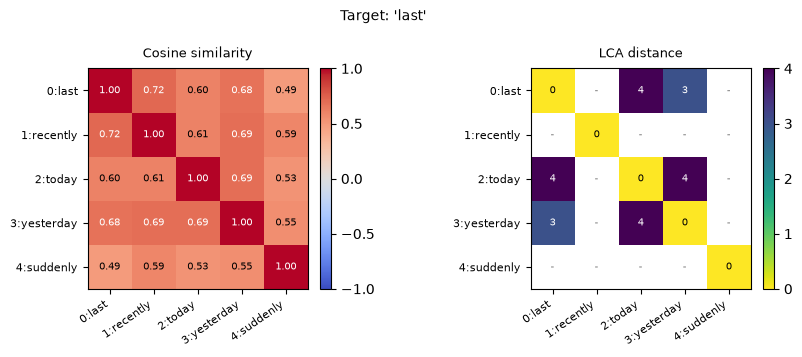


Context: 'Your grandmother died last' | Target: 'week."'
Top-5        |     0:year |     1:week |    2:month |    3:night |   4:summer
-----------------------------------------------------------------------------
0:year       |     1.0000 |     0.4826 |     0.5603 |     0.4140 |     0.4379
1:week       |     0.4826 |     1.0000 |     0.7832 |     0.4966 |     0.5402
2:month      |     0.5603 |     0.7832 |     1.0000 |     0.4912 |     0.6371
3:night      |     0.4140 |     0.4966 |     0.4912 |     1.0000 |     0.6283
4:summer     |     0.4379 |     0.5402 |     0.6371 |     0.6283 |     1.0000


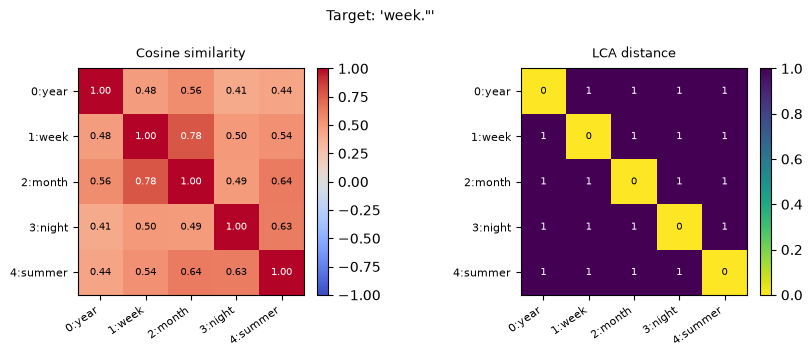


Context: '_Office' | Target: 'Boy:_'
Top-5           |       0:manager |         1:hours |           2:app |   3:application |      4:location
---------------------------------------------------------------------------------------------------------
0:manager       |          1.0000 |          0.4068 |          0.4956 |          0.5446 |          0.5580
1:hours         |          0.4068 |          1.0000 |          0.4444 |          0.4748 |          0.4443
2:app           |          0.4956 |          0.4444 |          1.0000 |          0.7149 |          0.6073
3:application   |          0.5446 |          0.4748 |          0.7149 |          1.0000 |          0.6953
4:location      |          0.5580 |          0.4443 |          0.6073 |          0.6953 |          1.0000


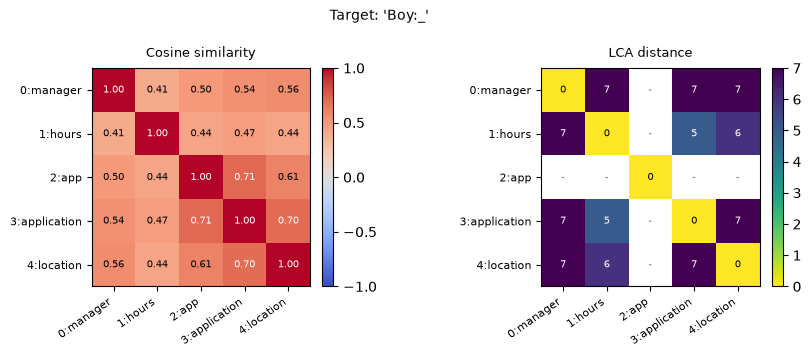


Context: '_Office Boy:_' | Target: '"Yes,'
Top-5        |      0:yes |       1:mr |   2:please |    3:hello |     4:good
-----------------------------------------------------------------------------
0:yes        |     1.0000 |     0.6803 |     0.6411 |     0.5649 |     0.5885
1:mr         |     0.6803 |     1.0000 |     0.6046 |     0.6039 |     0.5993
2:please     |     0.6411 |     0.6046 |     1.0000 |     0.5363 |     0.5225
3:hello      |     0.5649 |     0.6039 |     0.5363 |     1.0000 |     0.4877
4:good       |     0.5885 |     0.5993 |     0.5225 |     0.4877 |     1.0000


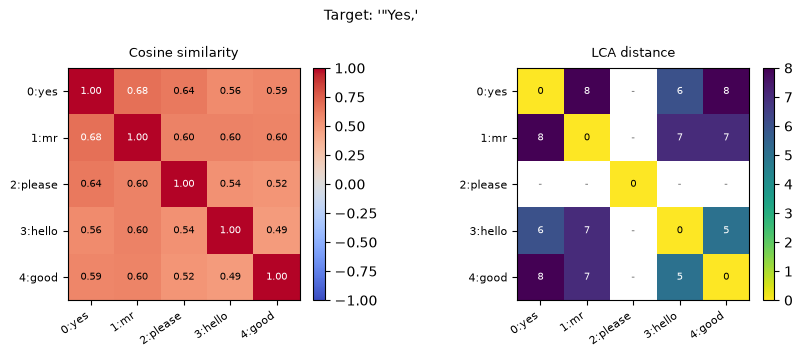


Context: '_Office Boy:_ "Yes,' | Target: 'Sir;'
Top-5        |      0:sir |       1:mr |     2:boss |     3:miss |   4:please
-----------------------------------------------------------------------------
0:sir        |     1.0000 |     0.8238 |     0.6971 |     0.6812 |     0.5657
1:mr         |     0.8238 |     1.0000 |     0.7524 |     0.7803 |     0.6046
2:boss       |     0.6971 |     0.7524 |     1.0000 |     0.6340 |     0.6676
3:miss       |     0.6812 |     0.7803 |     0.6340 |     1.0000 |     0.5525
4:please     |     0.5657 |     0.6046 |     0.6676 |     0.5525 |     1.0000


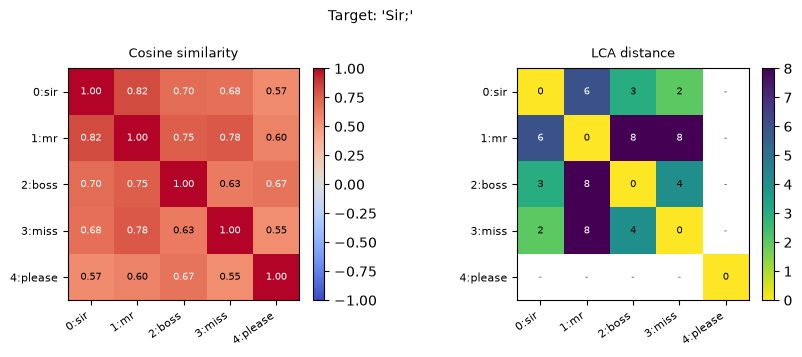


Context: '_Office Boy:_ "Yes, Sir;' | Target: 'but--my'
Top-5        |     0:please |         1:mr |   2:anything |        3:sir |      4:thank
---------------------------------------------------------------------------------------
0:please     |       1.0000 |       0.6046 |       0.6012 |       0.5657 |       0.7101
1:mr         |       0.6046 |       1.0000 |       0.6362 |       0.8238 |       0.6645
2:anything   |       0.6012 |       0.6362 |       1.0000 |       0.5751 |       0.5314
3:sir        |       0.5657 |       0.8238 |       0.5751 |       1.0000 |       0.6112
4:thank      |       0.7101 |       0.6645 |       0.5314 |       0.6112 |       1.0000


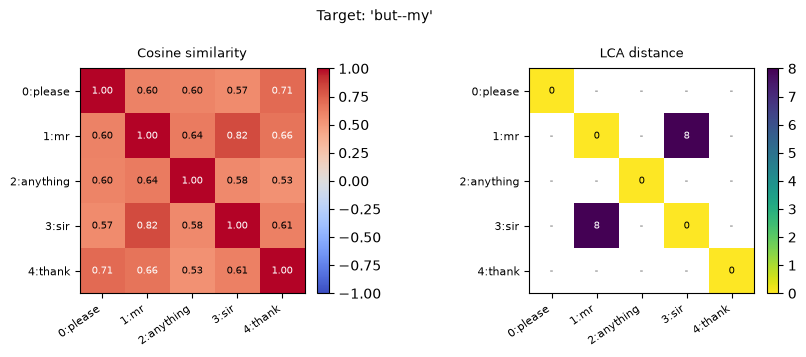


Context: '_Office Boy:_ "Yes, Sir; but--my' | Target: 'grandfather's'
Top-5        |   0:father |     1:wife |     2:name |   3:mother |   4:salary
-----------------------------------------------------------------------------
0:father     |     1.0000 |     0.8083 |     0.7675 |     0.9228 |     0.6166
1:wife       |     0.8083 |     1.0000 |     0.7516 |     0.8203 |     0.6678
2:name       |     0.7675 |     0.7516 |     1.0000 |     0.8059 |     0.6716
3:mother     |     0.9228 |     0.8203 |     0.8059 |     1.0000 |     0.6309
4:salary     |     0.6166 |     0.6678 |     0.6716 |     0.6309 |     1.0000


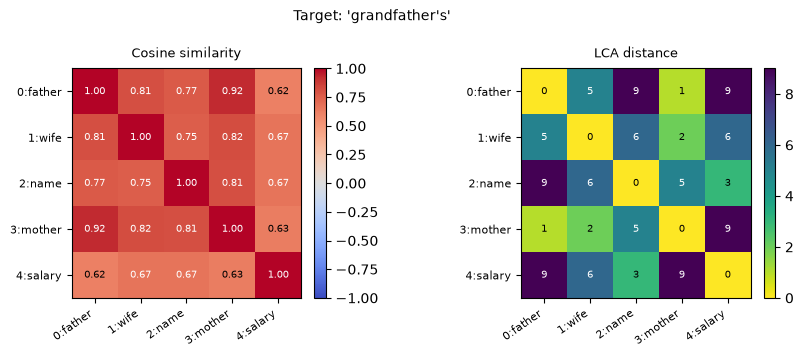


Context: '_Office Boy:_ "Yes, Sir; but--my grandfather's' | Target: 'getting'
Top-5        |     0:name |    1:still |     2:dead |    3:watch |      4:old
-----------------------------------------------------------------------------
0:name       |     1.0000 |     0.4164 |     0.5577 |     0.7072 |     0.5384
1:still      |     0.4164 |     1.0000 |     0.4182 |     0.4195 |     0.3869
2:dead       |     0.5577 |     0.4182 |     1.0000 |     0.5165 |     0.5645
3:watch      |     0.7072 |     0.4195 |     0.5165 |     1.0000 |     0.4608
4:old        |     0.5384 |     0.3869 |     0.5645 |     0.4608 |     1.0000


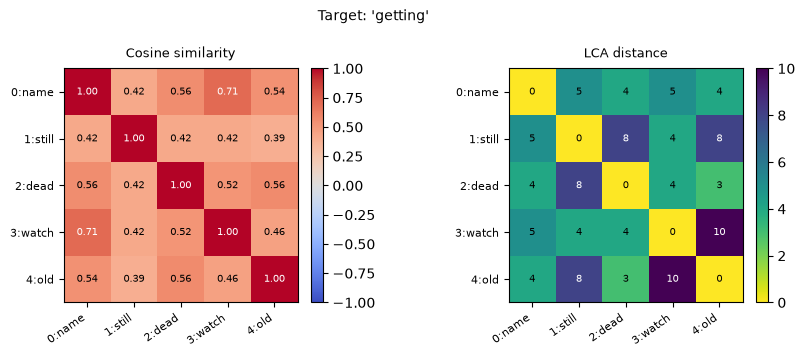


Context: '_Office Boy:_ "Yes, Sir; but--my grandfather's getting' | Target: 'married'
Top-5        |       0:old |     1:along |   2:married |    3:rather |      4:sick
----------------------------------------------------------------------------------
0:old        |      1.0000 |      0.5526 |      0.4539 |      0.5458 |      0.5501
1:along      |      0.5526 |      1.0000 |      0.5033 |      0.6781 |      0.4889
2:married    |      0.4539 |      0.5033 |      1.0000 |      0.5012 |      0.5073
3:rather     |      0.5458 |      0.6781 |      0.5012 |      1.0000 |      0.5348
4:sick       |      0.5501 |      0.4889 |      0.5073 |      0.5348 |      1.0000


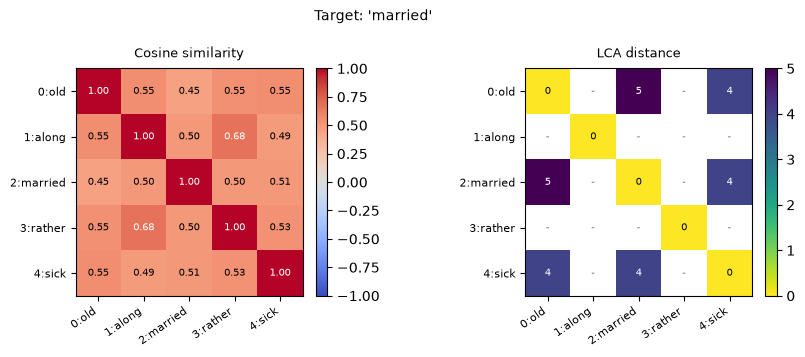


Context: '_Office Boy:_ "Yes, Sir; but--my grandfather's getting married again this' | Target: 'afternoon."'
Top-5         |        0:week |       1:month |     2:weekend |   3:afternoon |     4:evening
---------------------------------------------------------------------------------------------
0:week        |        1.0000 |        0.7832 |        0.6593 |        0.5492 |        0.6197
1:month       |        0.7832 |        1.0000 |        0.6386 |        0.5577 |        0.6587
2:weekend     |        0.6593 |        0.6386 |        1.0000 |        0.6657 |        0.7205
3:afternoon   |        0.5492 |        0.5577 |        0.6657 |        1.0000 |        0.8566
4:evening     |        0.6197 |        0.6587 |        0.7205 |        0.8567 |        1.0000


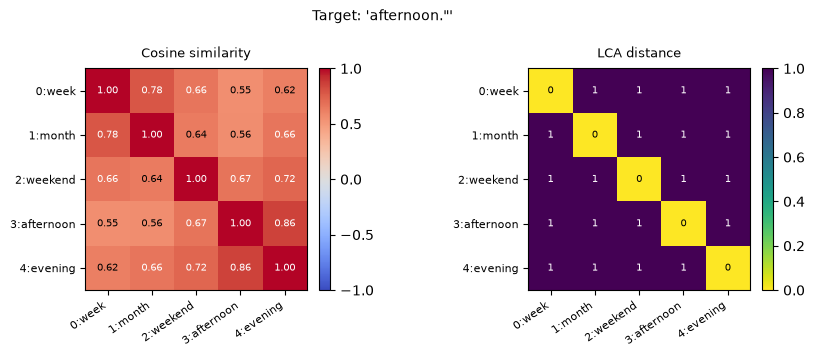


Context: '_Minister's' | Target: 'Wife:_'
Top-5         |      0:office |   1:statement |      2:speech |        3:note |      4:report
---------------------------------------------------------------------------------------------
0:office      |        1.0000 |        0.7541 |        0.6261 |        0.6716 |        0.6896
1:statement   |        0.7541 |        1.0000 |        0.6806 |        0.5618 |        0.7003
2:speech      |        0.6261 |        0.6806 |        1.0000 |        0.5695 |        0.6639
3:note        |        0.6716 |        0.5618 |        0.5695 |        1.0000 |        0.6222
4:report      |        0.6896 |        0.7003 |        0.6639 |        0.6222 |        1.0000


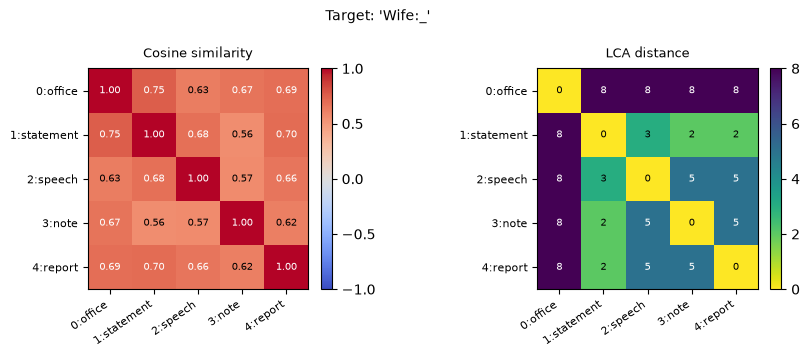


Context: '_Minister's Wife:_ "My' | Target: 'husband'
Top-5        |   0:husband |      1:dear |      2:name |        3:de |       4:son
----------------------------------------------------------------------------------
0:husband    |      1.0000 |      0.5609 |      0.6607 |      0.6141 |      0.7619
1:dear       |      0.5609 |      1.0000 |      0.6094 |      0.5161 |      0.5704
2:name       |      0.6607 |      0.6094 |      1.0000 |      0.6219 |      0.7327
3:de         |      0.6141 |      0.5161 |      0.6219 |      1.0000 |      0.6477
4:son        |      0.7620 |      0.5704 |      0.7327 |      0.6477 |      1.0000


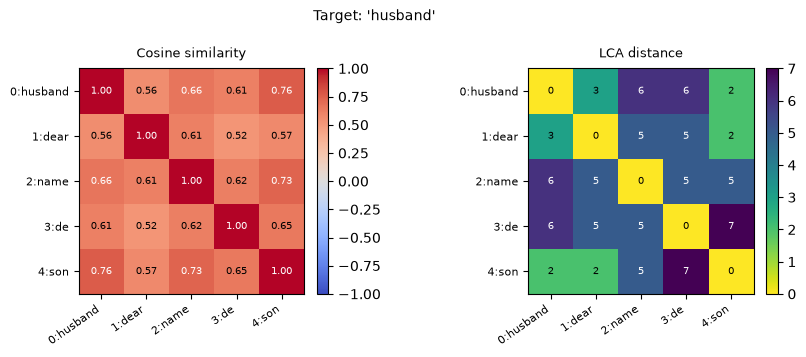


Context: '_Minister's Wife:_ "My husband was' | Target: 'asking'
Top-5        |     0:always |       1:born |      2:never |   3:minister |     4:killed
---------------------------------------------------------------------------------------
0:always     |       1.0000 |       0.6314 |       0.8476 |       0.5412 |       0.5948
1:born       |       0.6314 |       1.0000 |       0.6883 |       0.5660 |       0.7240
2:never      |       0.8476 |       0.6883 |       1.0000 |       0.5425 |       0.5974
3:minister   |       0.5412 |       0.5660 |       0.5425 |       1.0000 |       0.5200
4:killed     |       0.5948 |       0.7240 |       0.5974 |       0.5200 |       1.0000


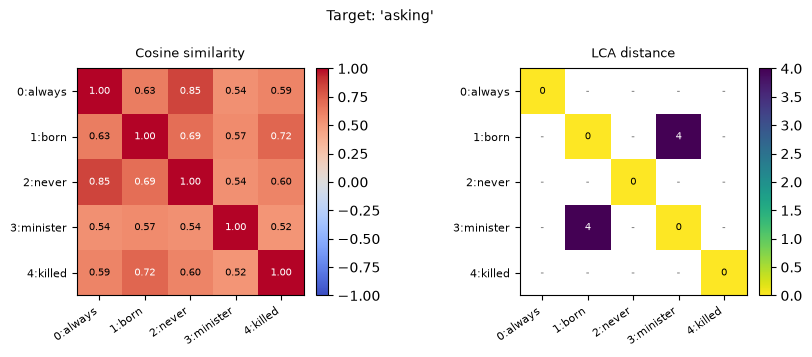


Context: '_Minister's Wife:_ "My husband was asking only this' | Target: 'morning'
Top-5         |     0:morning |    1:question |       2:favor |     3:evening |   4:afternoon
---------------------------------------------------------------------------------------------
0:morning     |        1.0000 |        0.6173 |        0.5499 |        0.7823 |        0.8010
1:question    |        0.6173 |        1.0000 |        0.7700 |        0.6845 |        0.6036
2:favor       |        0.5499 |        0.7700 |        1.0000 |        0.6300 |        0.4977
3:evening     |        0.7823 |        0.6845 |        0.6300 |        1.0000 |        0.8566
4:afternoon   |        0.8010 |        0.6036 |        0.4977 |        0.8567 |        1.0000


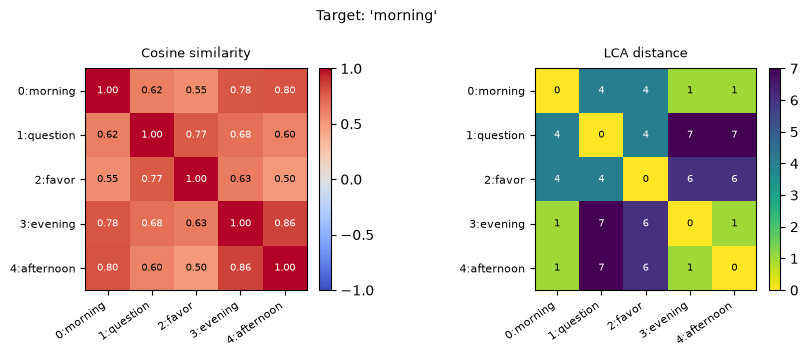


Context: '_Minister's Wife:_ "My husband was asking only this morning why you' | Target: 'weren't'
Top-5        |    0:never |    1:still |     2:seem |   3:seemed |   4:always
-----------------------------------------------------------------------------
0:never      |     1.0000 |     0.5003 |     0.7758 |     0.7890 |     0.8476
1:still      |     0.5003 |     1.0000 |     0.3875 |     0.4771 |     0.5271
2:seem       |     0.7758 |     0.3875 |     1.0000 |     0.8875 |     0.7694
3:seemed     |     0.7890 |     0.4771 |     0.8875 |     1.0000 |     0.7863
4:always     |     0.8476 |     0.5271 |     0.7694 |     0.7863 |     1.0000


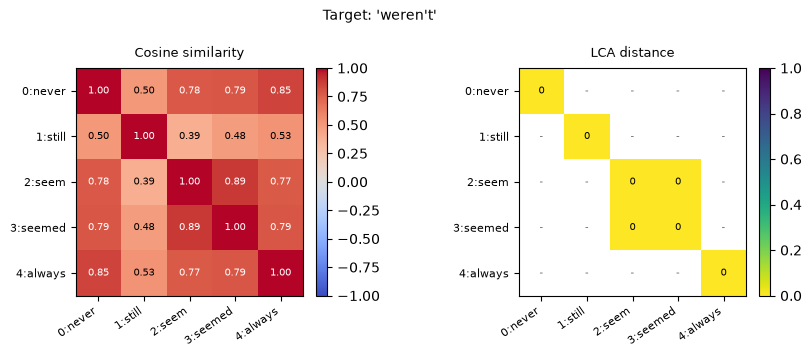


Context: '_Minister's Wife:_ "My husband was asking only this morning why you weren't in the' | Target: 'habit'
Top-5        |    0:office |    1:garden |    2:church |     3:house |   4:meeting
----------------------------------------------------------------------------------
0:office     |      1.0000 |      0.5684 |      0.3415 |      0.7399 |      0.7530
1:garden     |      0.5684 |      1.0000 |      0.5358 |      0.5957 |      0.6169
2:church     |      0.3415 |      0.5358 |      1.0000 |      0.4543 |      0.3756
3:house      |      0.7399 |      0.5957 |      0.4543 |      1.0000 |      0.6039
4:meeting    |      0.7530 |      0.6169 |      0.3756 |      0.6039 |      1.0000


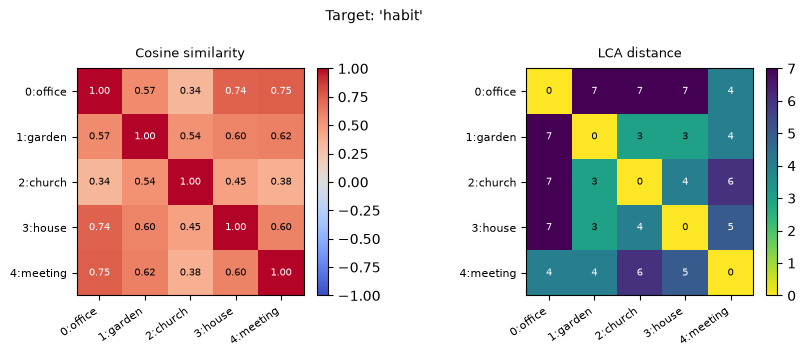


Context: '_Minister's Wife:_ "My husband was asking only this morning why you weren't in the habit of' | Target: 'attending'
Top-5        |    0:sending |    1:wearing |   2:visiting |    3:writing |      4:going
---------------------------------------------------------------------------------------
0:sending    |       1.0000 |       0.7781 |       0.7051 |       0.7246 |       0.7750
1:wearing    |       0.7781 |       1.0000 |       0.7584 |       0.7434 |       0.8107
2:visiting   |       0.7051 |       0.7584 |       1.0000 |       0.7790 |       0.7147
3:writing    |       0.7246 |       0.7434 |       0.7790 |       1.0000 |       0.7084
4:going      |       0.7750 |       0.8107 |       0.7147 |       0.7084 |       1.0000


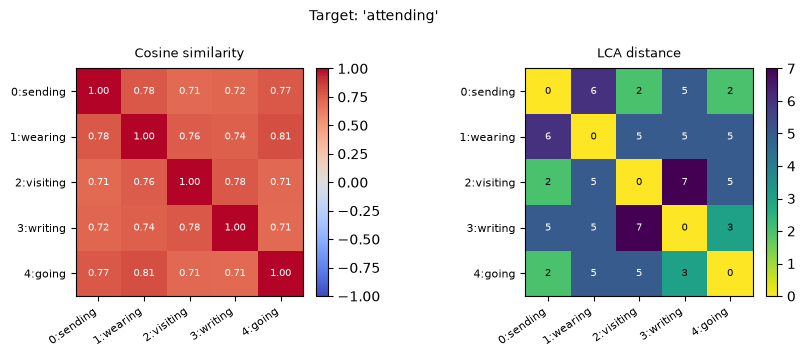


Context: '_Minister's Wife:_ "My husband was asking only this morning why you weren't in the habit of attending' | Target: 'church."'
Top-5        |     0:church |       1:mass |     2:sunday |   3:services |   4:meetings
---------------------------------------------------------------------------------------
0:church     |       1.0000 |       0.3341 |       0.4073 |       0.3959 |       0.5758
1:mass       |       0.3341 |       1.0000 |       0.4804 |       0.3944 |       0.4015
2:sunday     |       0.4073 |       0.4804 |       1.0000 |       0.3754 |       0.4813
3:services   |       0.3959 |       0.3944 |       0.3754 |       1.0000 |       0.3710
4:meetings   |       0.5758 |       0.4015 |       0.4813 |       0.3710 |       1.0000


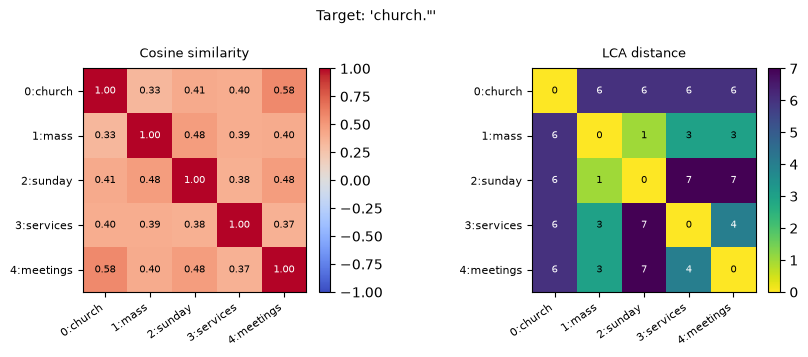


Context: '_Latest' | Target: 'Inhabitant:_'
Top-5        |   0:version |      1:data |     2:build |   3:release |         4:p
----------------------------------------------------------------------------------
0:version    |      1.0000 |      0.5567 |      0.5753 |      0.6806 |      0.5175
1:data       |      0.5567 |      1.0000 |      0.4705 |      0.4563 |      0.4035
2:build      |      0.5753 |      0.4705 |      1.0000 |      0.6227 |      0.4374
3:release    |      0.6806 |      0.4563 |      0.6227 |      1.0000 |      0.3994
4:p          |      0.5175 |      0.4035 |      0.4374 |      0.3994 |      1.0000


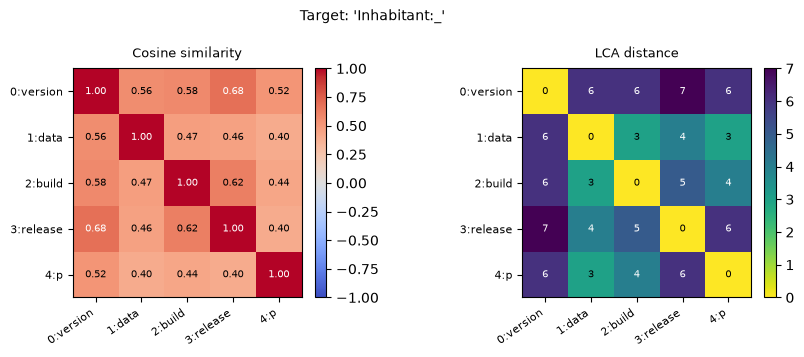


Context: '_Latest Inhabitant:_ "Well, you' | Target: 'see,'
Top-5         |        0:know |         1:see |        2:seem |     3:finally |   4:certainly
---------------------------------------------------------------------------------------------
0:know        |        1.0000 |        0.7738 |        0.8126 |        0.4817 |        0.5379
1:see         |        0.7738 |        1.0000 |        0.7690 |        0.5100 |        0.5278
2:seem        |        0.8126 |        0.7690 |        1.0000 |        0.5245 |        0.5556
3:finally     |        0.4817 |        0.5100 |        0.5245 |        1.0000 |        0.5116
4:certainly   |        0.5379 |        0.5278 |        0.5556 |        0.5116 |        1.0000


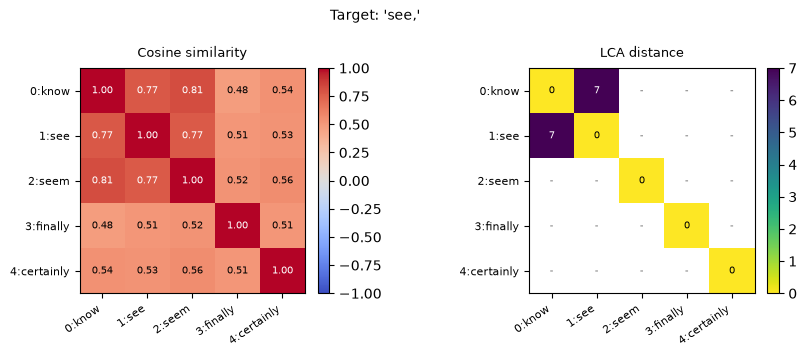


Context: '_Latest Inhabitant:_ "Well, you see, it does so' | Target: 'cut'
Top-5        |   0:happen |   1:depend |    2:often |     3:love |   4:little
-----------------------------------------------------------------------------
0:happen     |     1.0000 |     0.7377 |     0.7406 |     0.5601 |     0.6168
1:depend     |     0.7377 |     1.0000 |     0.6745 |     0.4845 |     0.5841
2:often      |     0.7406 |     0.6745 |     1.0000 |     0.4931 |     0.6464
3:love       |     0.5601 |     0.4845 |     0.4931 |     1.0000 |     0.5381
4:little     |     0.6168 |     0.5841 |     0.6464 |     0.5381 |     1.0000


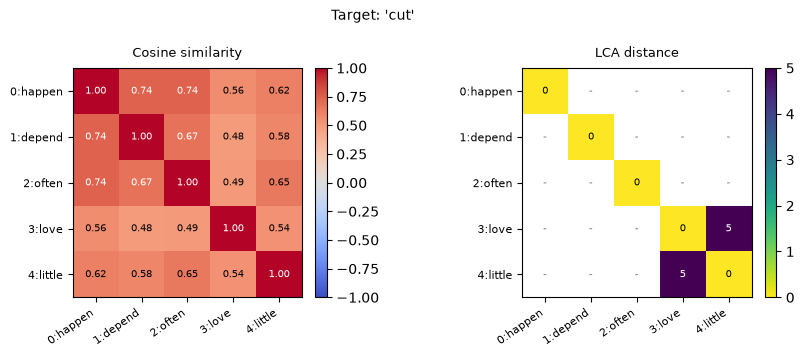


Context: '_Latest Inhabitant:_ "Well, you see, it does so cut into' | Target: 'one's'
Top-5        |       0:time |    1:leisure |     2:family |   3:personal |     4:people
---------------------------------------------------------------------------------------
0:time       |       1.0000 |       0.7097 |       0.7461 |       0.5126 |       0.6705
1:leisure    |       0.7097 |       1.0000 |       0.7118 |       0.5302 |       0.6469
2:family     |       0.7461 |       0.7118 |       1.0000 |       0.6384 |       0.7462
3:personal   |       0.5126 |       0.5302 |       0.6384 |       1.0000 |       0.5956
4:people     |       0.6705 |       0.6469 |       0.7462 |       0.5956 |       1.0000


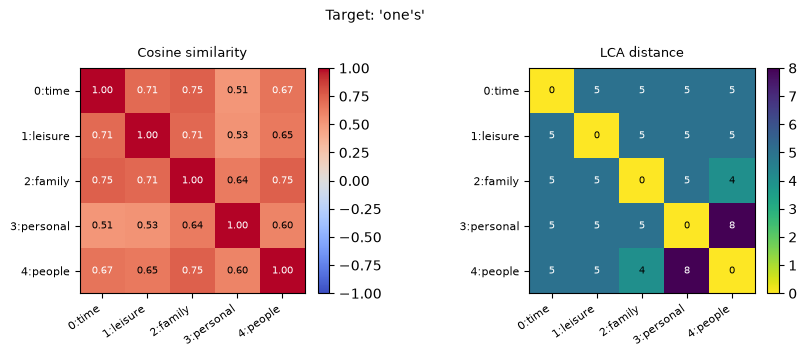


Context: '_Latest Inhabitant:_ "Well, you see, it does so cut into one's' | Target: 'Sundays."'
Top-5        |    0:leisure |       1:time |     2:social |   3:personal |       4:free
---------------------------------------------------------------------------------------
0:leisure    |       1.0000 |       0.7097 |       0.7519 |       0.5302 |       0.6993
1:time       |       0.7097 |       1.0000 |       0.6667 |       0.5126 |       0.6787
2:social     |       0.7519 |       0.6667 |       1.0000 |       0.5846 |       0.6280
3:personal   |       0.5302 |       0.5126 |       0.5846 |       1.0000 |       0.5169
4:free       |       0.6993 |       0.6787 |       0.6280 |       0.5169 |       1.0000


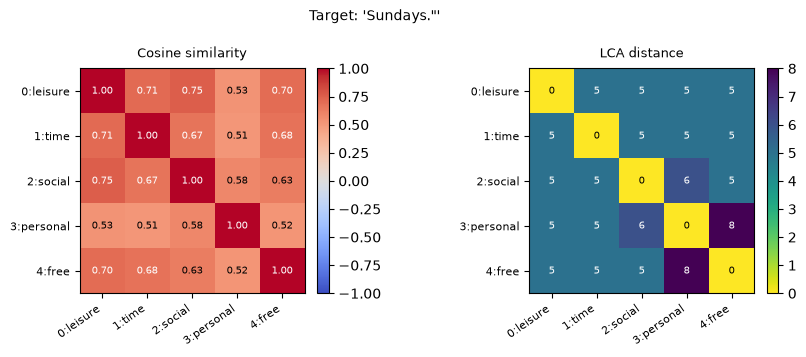


Context: '"Two' | Target: 'mistakes'
Top-5        |   0:tickets |      1:cent |       2:bom |   3:studies |     4:lines
----------------------------------------------------------------------------------
0:tickets    |      1.0000 |      0.5534 |      0.4162 |      0.6317 |      0.6613
1:cent       |      0.5534 |      1.0000 |      0.4984 |      0.5856 |      0.5944
2:bom        |      0.4162 |      0.4984 |      1.0000 |      0.4977 |      0.4159
3:studies    |      0.6317 |      0.5856 |      0.4977 |      1.0000 |      0.6609
4:lines      |      0.6613 |      0.5944 |      0.4159 |      0.6609 |      1.0000


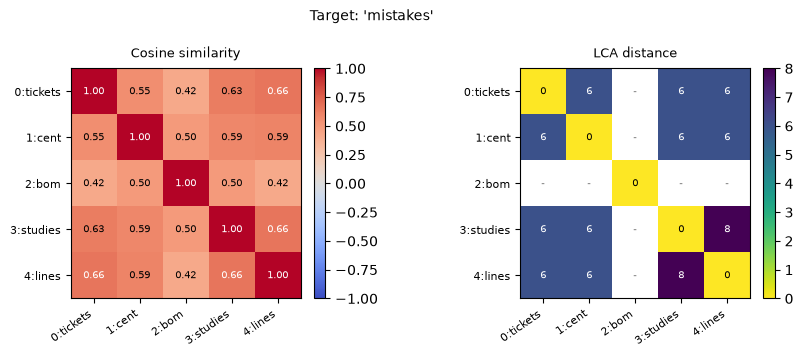


Context: '"Two mistakes here,' | Target: 'waiter--one'
Top-5        |    0:three |     1:four |     2:five |      3:ten |      4:six
-----------------------------------------------------------------------------
0:three      |     1.0000 |     0.8457 |     0.8208 |     0.6715 |     0.7322
1:four       |     0.8457 |     1.0000 |     0.8584 |     0.7105 |     0.8026
2:five       |     0.8208 |     0.8584 |     1.0000 |     0.8481 |     0.8797
3:ten        |     0.6715 |     0.7105 |     0.8481 |     1.0000 |     0.8075
4:six        |     0.7322 |     0.8026 |     0.8797 |     0.8075 |     1.0000


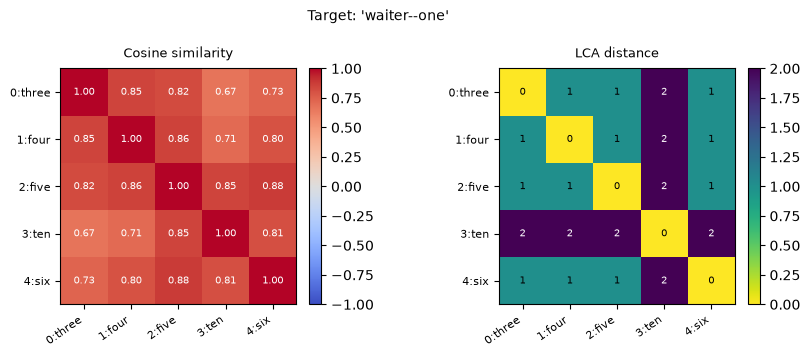


Context: '"Two mistakes here, waiter--one in your' | Target: 'favor,'
Top-5             |        0:spelling |            1:name |   2:pronunciation |         3:english |            4:head
---------------------------------------------------------------------------------------------------------------------
0:spelling        |            1.0000 |            0.7486 |            0.5312 |            0.6245 |            0.7372
1:name            |            0.7486 |            1.0000 |            0.4499 |            0.5529 |            0.7498
2:pronunciation   |            0.5312 |            0.4499 |            1.0000 |            0.5788 |            0.4014
3:english         |            0.6245 |            0.5529 |            0.5788 |            1.0000 |            0.5705
4:head            |            0.7372 |            0.7498 |            0.4014 |            0.5705 |            1.0000


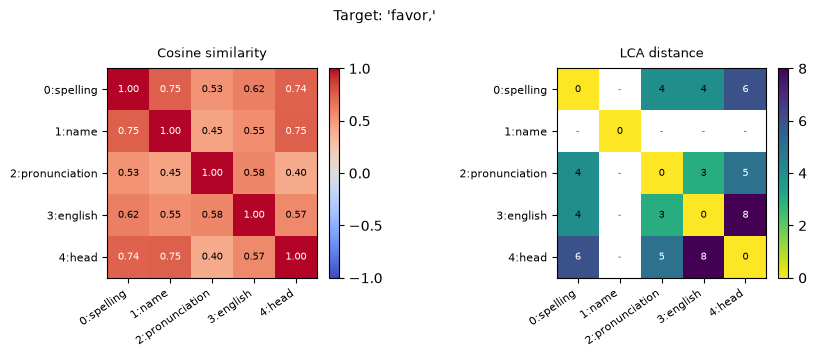


Context: '"Two mistakes here, waiter--one in your favor, one in' | Target: 'mine."'
Top-5        |       0:mine |      1:favor |   2:everyone |       3:mind |         4:mr
---------------------------------------------------------------------------------------
0:mine       |       1.0000 |       0.5823 |       0.5515 |       0.4996 |       0.5373
1:favor      |       0.5823 |       1.0000 |       0.7357 |       0.6667 |       0.7436
2:everyone   |       0.5515 |       0.7357 |       1.0000 |       0.6258 |       0.7356
3:mind       |       0.4996 |       0.6667 |       0.6258 |       1.0000 |       0.6054
4:mr         |       0.5373 |       0.7436 |       0.7356 |       0.6054 |       1.0000


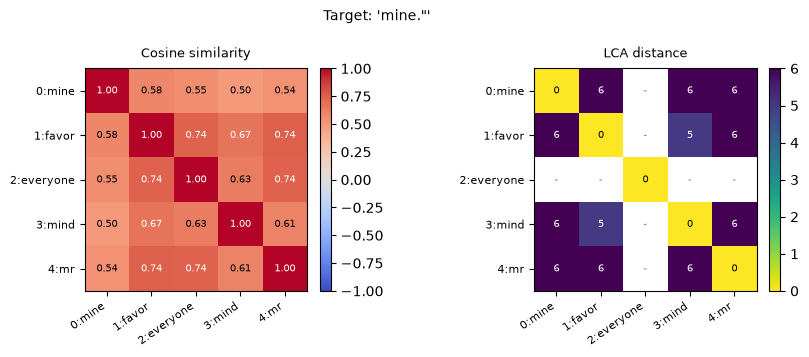


Context: '"In _your_' | Target: 'favor,'
Top-5        |   0:opinion |      1:room |      2:eyes |      3:time |     4:class
----------------------------------------------------------------------------------
0:opinion    |      1.0000 |      0.7332 |      0.7377 |      0.7086 |      0.7162
1:room       |      0.7332 |      1.0000 |      0.7401 |      0.7570 |      0.7055
2:eyes       |      0.7377 |      0.7401 |      1.0000 |      0.7773 |      0.6401
3:time       |      0.7086 |      0.7570 |      0.7773 |      1.0000 |      0.6568
4:class      |      0.7162 |      0.7055 |      0.6401 |      0.6568 |      1.0000


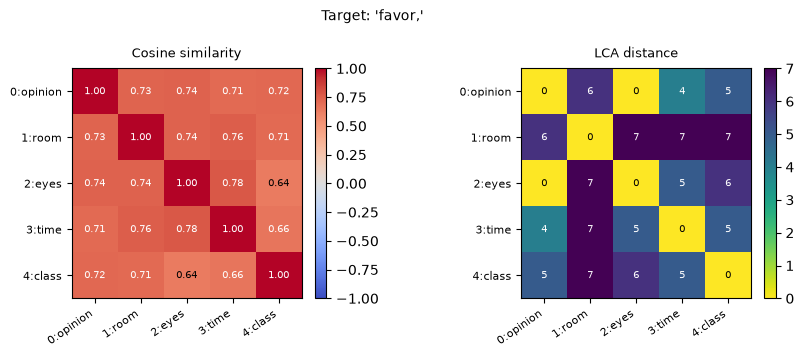


Context: '"In _your_ favor,' | Target: 'Sir?'
Top-5        |        0:mr |       1:sir |       2:let |   3:captain |      4:miss
----------------------------------------------------------------------------------
0:mr         |      1.0000 |      0.8238 |      0.6096 |      0.7072 |      0.7803
1:sir        |      0.8238 |      1.0000 |      0.5655 |      0.6856 |      0.6812
2:let        |      0.6096 |      0.5655 |      1.0000 |      0.4836 |      0.5405
3:captain    |      0.7072 |      0.6856 |      0.4836 |      1.0000 |      0.6938
4:miss       |      0.7803 |      0.6812 |      0.5405 |      0.6938 |      1.0000


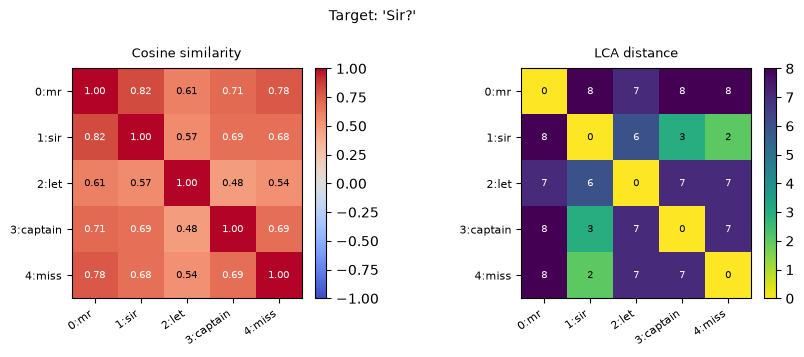


Context: '_Mistress:_' | Target: '"Oh,'
Top-5        |      0:yes |       1:oh |    2:hello |       3:ah |     4:good
-----------------------------------------------------------------------------
0:yes        |     1.0000 |     0.7699 |     0.5649 |     0.7327 |     0.5885
1:oh         |     0.7699 |     1.0000 |     0.5163 |     0.9006 |     0.5731
2:hello      |     0.5649 |     0.5163 |     1.0000 |     0.5102 |     0.4877
3:ah         |     0.7327 |     0.9006 |     0.5102 |     1.0000 |     0.5933
4:good       |     0.5885 |     0.5731 |     0.4877 |     0.5933 |     1.0000


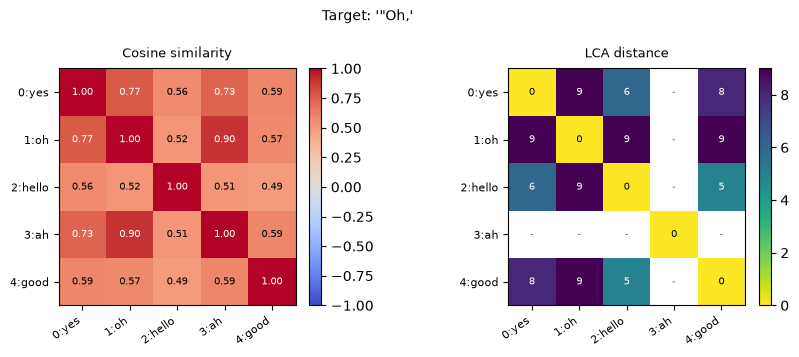


Context: '_Mistress:_ "Oh,' | Target: 'cook,'
Top-5        |      0:dear |        1:mr |       2:yes |     3:thank |   4:darling
----------------------------------------------------------------------------------
0:dear       |      1.0000 |      0.6596 |      0.5956 |      0.7259 |      0.6839
1:mr         |      0.6596 |      1.0000 |      0.6803 |      0.6645 |      0.7499
2:yes        |      0.5956 |      0.6803 |      1.0000 |      0.6698 |      0.6901
3:thank      |      0.7259 |      0.6645 |      0.6698 |      1.0000 |      0.6999
4:darling    |      0.6839 |      0.7499 |      0.6901 |      0.6999 |      1.0000


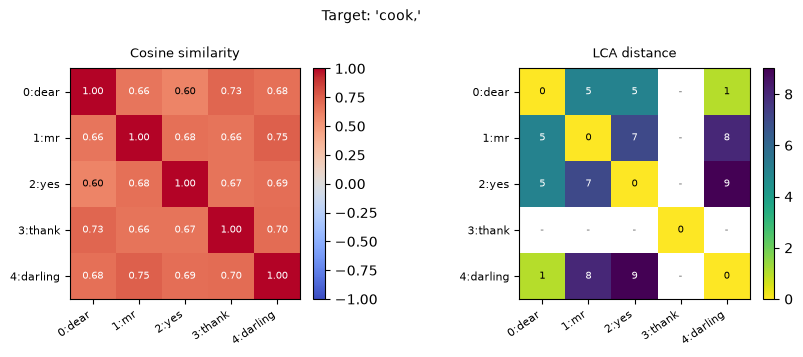


Context: '_Mistress:_ "Oh, cook, be sure and' | Target: 'put'
Top-5        |      0:add |      1:put |    2:bring |     3:tell |      4:use
-----------------------------------------------------------------------------
0:add        |     1.0000 |     0.7473 |     0.7574 |     0.6429 |     0.7389
1:put        |     0.7473 |     1.0000 |     0.8069 |     0.7408 |     0.7330
2:bring      |     0.7574 |     0.8069 |     1.0000 |     0.8339 |     0.7086
3:tell       |     0.6429 |     0.7408 |     0.8339 |     1.0000 |     0.6638
4:use        |     0.7389 |     0.7330 |     0.7086 |     0.6638 |     1.0000


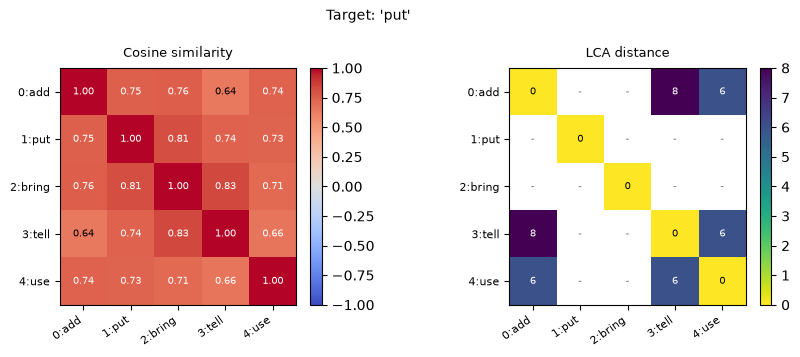


Context: '_Mistress:_ "Oh, cook, be sure and put' | Target: 'plenty'
Top-5        |   0:plenty |    1:extra |   2:enough |     3:lots |     4:salt
-----------------------------------------------------------------------------
0:plenty     |     1.0000 |     0.6061 |     0.7268 |     0.8514 |     0.5032
1:extra      |     0.6061 |     1.0000 |     0.4711 |     0.5538 |     0.4702
2:enough     |     0.7268 |     0.4711 |     1.0000 |     0.6433 |     0.4687
3:lots       |     0.8514 |     0.5538 |     0.6433 |     1.0000 |     0.5523
4:salt       |     0.5032 |     0.4702 |     0.4687 |     0.5523 |     1.0000


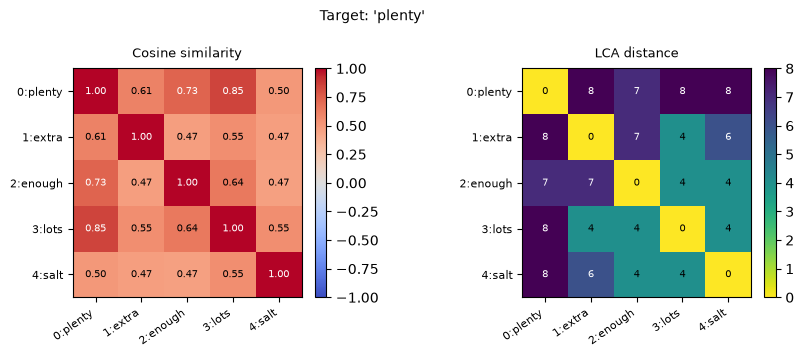


Context: '_Mistress:_ "Oh, cook, be sure and put plenty of nuts in the' | Target: 'cake."'
Top-5        |       0:cake |        1:pie |    2:dessert |    3:pudding |   4:stuffing
---------------------------------------------------------------------------------------
0:cake       |       1.0000 |       0.7534 |       0.7466 |       0.7676 |       0.6457
1:pie        |       0.7534 |       1.0000 |       0.6686 |       0.8135 |       0.7311
2:dessert    |       0.7466 |       0.6686 |       1.0000 |       0.7377 |       0.5883
3:pudding    |       0.7676 |       0.8135 |       0.7377 |       1.0000 |       0.8344
4:stuffing   |       0.6457 |       0.7311 |       0.5883 |       0.8344 |       1.0000


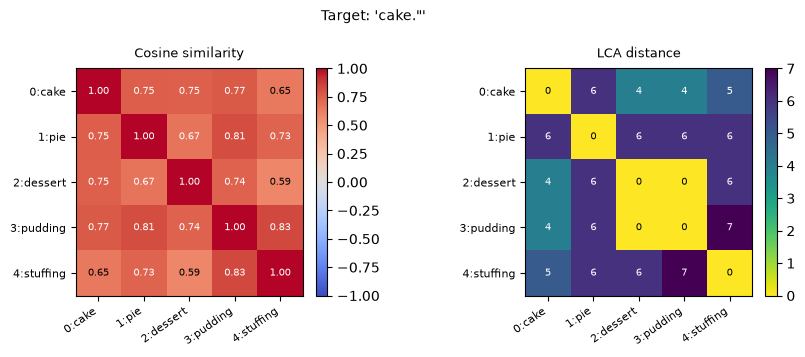


Context: '_Cook:_ "You don't' | Target: 'catch'
Top-5          |         0:need |         1:know |   2:understand |         3:want |         4:cook
---------------------------------------------------------------------------------------------------
0:need         |         1.0000 |         0.7421 |         0.7472 |         0.8792 |         0.6923
1:know         |         0.7421 |         1.0000 |         0.8712 |         0.7659 |         0.6886
2:understand   |         0.7472 |         0.8712 |         1.0000 |         0.7489 |         0.7028
3:want         |         0.8792 |         0.7659 |         0.7489 |         1.0000 |         0.6607
4:cook         |         0.6923 |         0.6886 |         0.7028 |         0.6607 |         1.0000


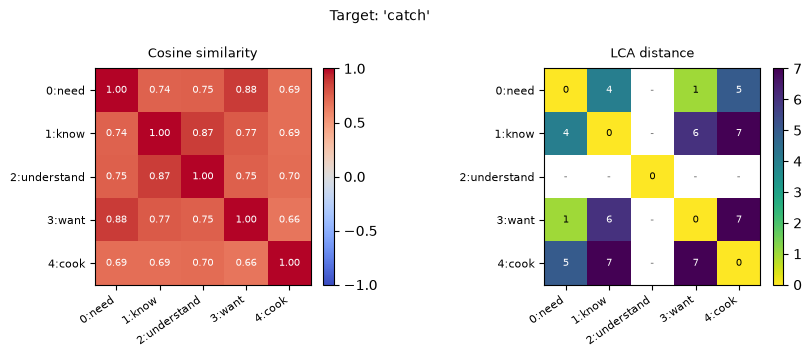


Context: '_Cook:_ "You don't catch me' | Target: 'crackin''
Top-5        |     0:using |   1:cooking |    2:eating |   3:without |   4:talking
----------------------------------------------------------------------------------
0:using      |      1.0000 |      0.5534 |      0.6599 |      0.7002 |      0.6309
1:cooking    |      0.5534 |      1.0000 |      0.7743 |      0.6219 |      0.7991
2:eating     |      0.6599 |      0.7743 |      1.0000 |      0.7852 |      0.9018
3:without    |      0.7002 |      0.6219 |      0.7852 |      1.0000 |      0.7422
4:talking    |      0.6309 |      0.7991 |      0.9018 |      0.7422 |      1.0000


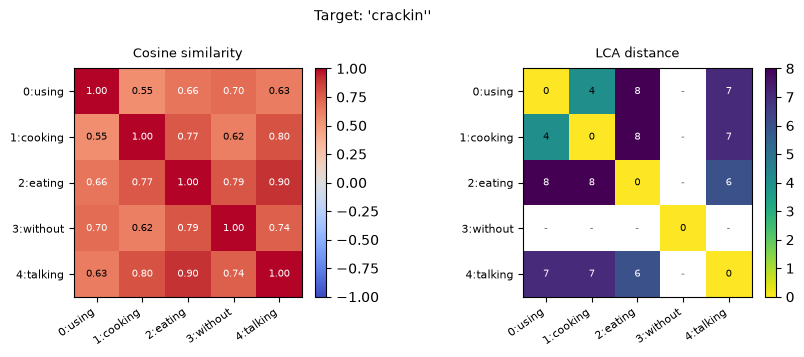


Context: '_Cook:_ "You don't catch me crackin' no more nuts' | Target: 'to-day.'
Top-5        |       0:wit |   1:without |     2:since |      3:till |       4:wid
----------------------------------------------------------------------------------
0:wit        |      1.0000 |      0.7038 |      0.5950 |      0.6479 |      0.5385
1:without    |      0.7038 |      1.0000 |      0.6801 |      0.6613 |      0.4330
2:since      |      0.5950 |      0.6801 |      1.0000 |      0.6635 |      0.4609
3:till       |      0.6479 |      0.6613 |      0.6635 |      1.0000 |      0.5303
4:wid        |      0.5385 |      0.4330 |      0.4609 |      0.5303 |      1.0000


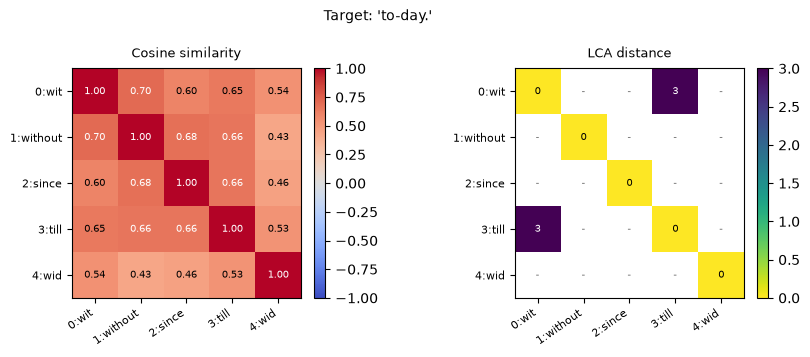


Context: 'I've very' | Target: 'near'
Top-5        |   0:recently |     1:simple |      2:basic |     3:little |    4:limited
---------------------------------------------------------------------------------------
0:recently   |       1.0000 |       0.6512 |       0.6446 |       0.5665 |       0.5975
1:simple     |       0.6512 |       1.0000 |       0.7969 |       0.6972 |       0.6595
2:basic      |       0.6446 |       0.7969 |       1.0000 |       0.6260 |       0.6938
3:little     |       0.5665 |       0.6972 |       0.6260 |       1.0000 |       0.5350
4:limited    |       0.5975 |       0.6595 |       0.6938 |       0.5350 |       1.0000


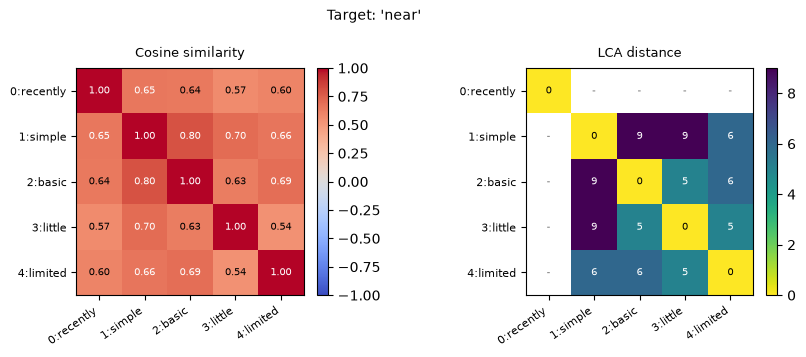


Context: 'I've very near broke me' | Target: 'jaw'
Top-5        |     0:head |      1:leg |    2:brain |      3:arm |     4:neck
-----------------------------------------------------------------------------
0:head       |     1.0000 |     0.7276 |     0.7744 |     0.6429 |     0.7671
1:leg        |     0.7276 |     1.0000 |     0.7082 |     0.7126 |     0.7205
2:brain      |     0.7744 |     0.7082 |     1.0000 |     0.6095 |     0.7482
3:arm        |     0.6429 |     0.7126 |     0.6095 |     1.0000 |     0.7285
4:neck       |     0.7671 |     0.7205 |     0.7482 |     0.7285 |     1.0000


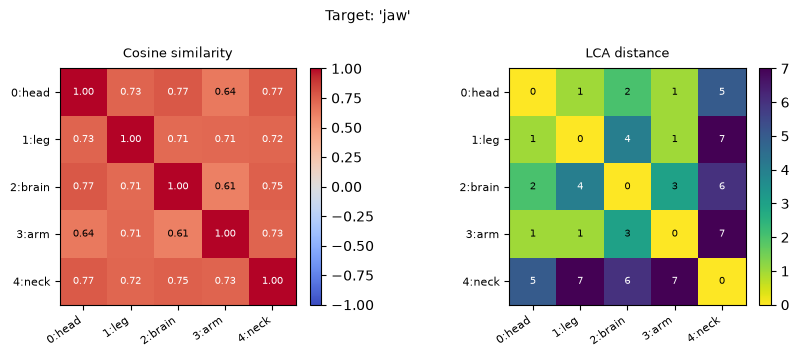


Context: 'I've very near broke me jaw' | Target: 'already."'
Top-5        |     0:twice |     1:today |       2:due |      3:last |   4:playing
----------------------------------------------------------------------------------
0:twice      |      1.0000 |      0.4692 |      0.5050 |      0.5516 |      0.5080
1:today      |      0.4692 |      1.0000 |      0.4928 |      0.6048 |      0.5035
2:due        |      0.5050 |      0.4928 |      1.0000 |      0.7474 |      0.7230
3:last       |      0.5516 |      0.6048 |      0.7474 |      1.0000 |      0.6881
4:playing    |      0.5080 |      0.5035 |      0.7230 |      0.6881 |      1.0000


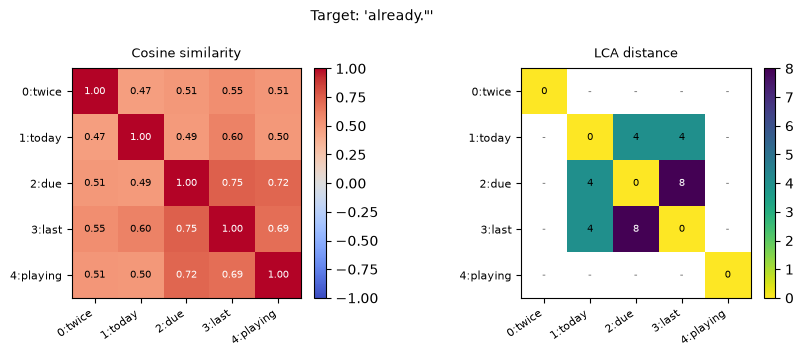


Context: '_Gushing' | Target: 'Lady:_'
Top-5        |    0:water |    1:river |   2:stream |   3:spring |        4:r
-----------------------------------------------------------------------------
0:water      |     1.0000 |     0.6752 |     0.7249 |     0.6663 |     0.5585
1:river      |     0.6752 |     1.0000 |     0.7884 |     0.5274 |     0.4002
2:stream     |     0.7249 |     0.7884 |     1.0000 |     0.5897 |     0.4023
3:spring     |     0.6663 |     0.5274 |     0.5897 |     1.0000 |     0.5462
4:r          |     0.5585 |     0.4002 |     0.4023 |     0.5462 |     1.0000


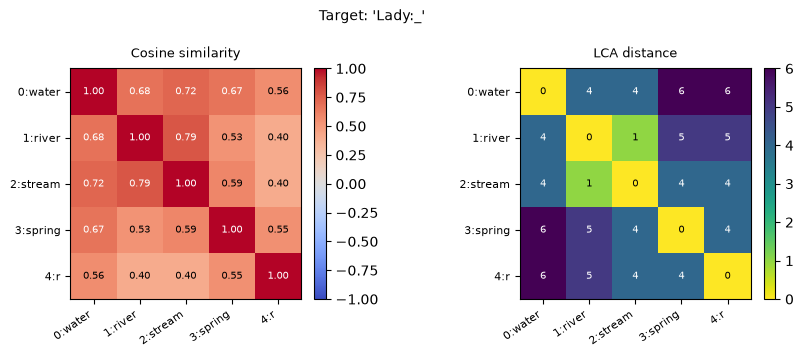


Context: '_Gushing Lady:_' | Target: '"Yes,'
Top-5        |      0:yes |       1:oh |      2:hey |     3:yeah |    4:hello
-----------------------------------------------------------------------------
0:yes        |     1.0000 |     0.7699 |     0.6492 |     0.8278 |     0.5649
1:oh         |     0.7699 |     1.0000 |     0.7320 |     0.7941 |     0.5163
2:hey        |     0.6492 |     0.7320 |     1.0000 |     0.7193 |     0.6819
3:yeah       |     0.8278 |     0.7941 |     0.7193 |     1.0000 |     0.4975
4:hello      |     0.5649 |     0.5163 |     0.6819 |     0.4975 |     1.0000


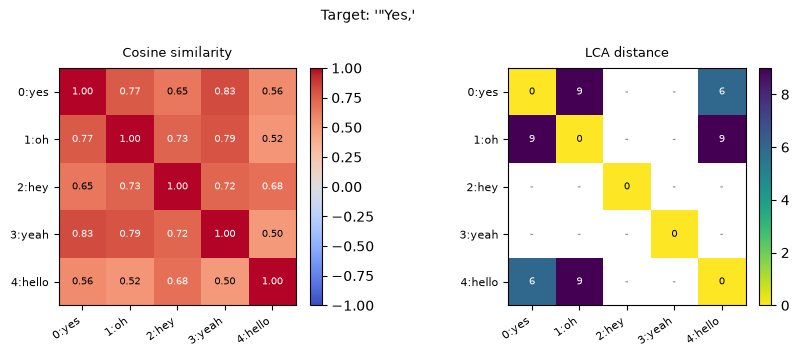


Context: '_Gushing Lady:_ "Yes,' | Target: 'she's'
Top-5        |       0:yes |       1:sir |     2:thank |    3:please |   4:exactly
----------------------------------------------------------------------------------
0:yes        |      1.0000 |      0.6205 |      0.6698 |      0.6411 |      0.7056
1:sir        |      0.6205 |      1.0000 |      0.6112 |      0.5657 |      0.5792
2:thank      |      0.6698 |      0.6112 |      1.0000 |      0.7101 |      0.5908
3:please     |      0.6411 |      0.5657 |      0.7101 |      1.0000 |      0.5914
4:exactly    |      0.7056 |      0.5792 |      0.5908 |      0.5914 |      1.0000


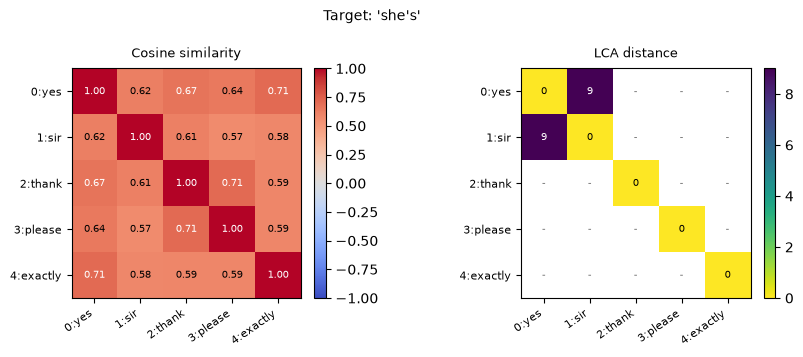


Context: '_Gushing Lady:_ "Yes, she's' | Target: 'married'
Top-5        |    0:still |    1:right |    2:going |   3:really |   4:always
-----------------------------------------------------------------------------
0:still      |     1.0000 |     0.3894 |     0.4163 |     0.4092 |     0.5271
1:right      |     0.3894 |     1.0000 |     0.7241 |     0.7125 |     0.6648
2:going      |     0.4163 |     0.7241 |     1.0000 |     0.6886 |     0.7725
3:really     |     0.4092 |     0.7125 |     0.6886 |     1.0000 |     0.6725
4:always     |     0.5271 |     0.6648 |     0.7725 |     0.6725 |     1.0000


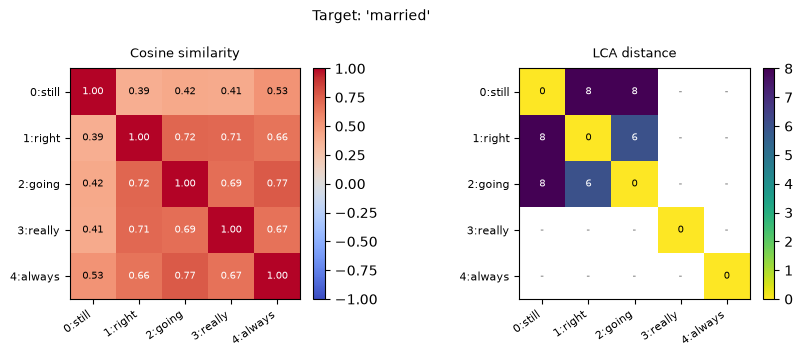


Context: '_Gushing Lady:_ "Yes, she's married to a' | Target: 'lawyer,'
Top-5        |      0:man |      1:guy |   2:doctor |     3:rich |   4:lawyer
-----------------------------------------------------------------------------
0:man        |     1.0000 |     0.8319 |     0.7385 |     0.6334 |     0.5044
1:guy        |     0.8319 |     1.0000 |     0.7803 |     0.7238 |     0.5257
2:doctor     |     0.7385 |     0.7803 |     1.0000 |     0.6644 |     0.5874
3:rich       |     0.6334 |     0.7238 |     0.6644 |     1.0000 |     0.4749
4:lawyer     |     0.5044 |     0.5257 |     0.5874 |     0.4749 |     1.0000


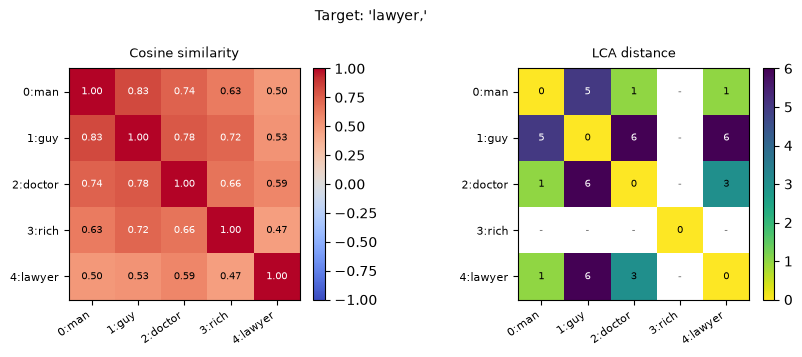


Context: '_Gushing Lady:_ "Yes, she's married to a lawyer, and a' | Target: 'good'
Top-5        |     0:good |   1:rather |     2:nice |   3:lawyer |    4:great
-----------------------------------------------------------------------------
0:good       |     1.0000 |     0.4693 |     0.7113 |     0.4680 |     0.7382
1:rather     |     0.4693 |     1.0000 |     0.5833 |     0.5019 |     0.5497
2:nice       |     0.7113 |     0.5833 |     1.0000 |     0.5220 |     0.7299
3:lawyer     |     0.4680 |     0.5019 |     0.5220 |     1.0000 |     0.4459
4:great      |     0.7382 |     0.5497 |     0.7299 |     0.4459 |     1.0000


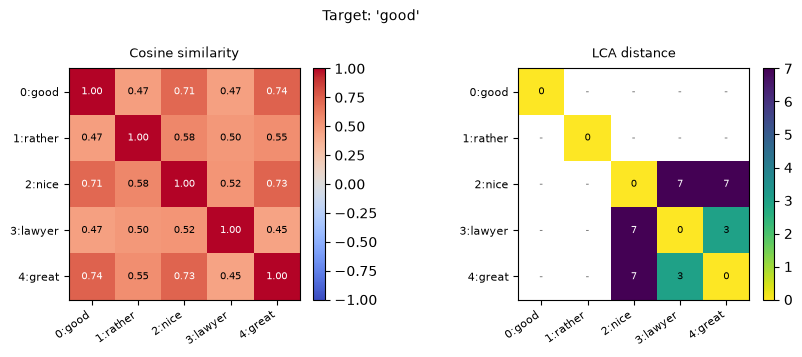


Context: '_Gushing Lady:_ "Yes, she's married to a lawyer, and a good honest' | Target: 'fellow'
Top-5        |        0:man |     1:lawyer |    2:working |     3:family |   4:american
---------------------------------------------------------------------------------------
0:man        |       1.0000 |       0.5044 |       0.7894 |       0.7019 |       0.4291
1:lawyer     |       0.5044 |       1.0000 |       0.5181 |       0.5282 |       0.6296
2:working    |       0.7894 |       0.5181 |       1.0000 |       0.7652 |       0.4157
3:family     |       0.7019 |       0.5282 |       0.7652 |       1.0000 |       0.4408
4:american   |       0.4291 |       0.6296 |       0.4157 |       0.4408 |       1.0000


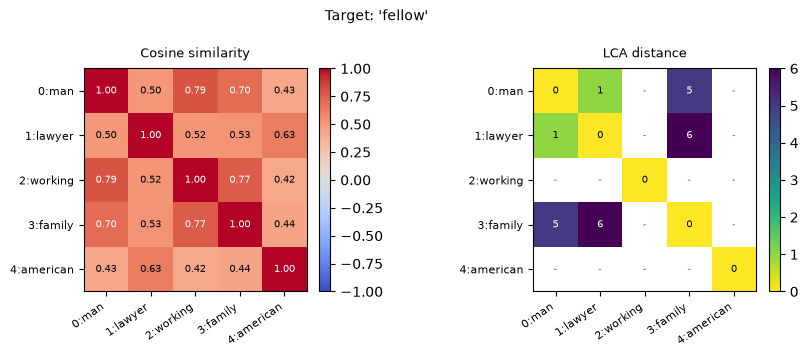


Context: '_Mother:_' | Target: '"Augustus,'
Top-5        |      0:yes |       1:oh |    2:hello |   3:mother |     4:good
-----------------------------------------------------------------------------
0:yes        |     1.0000 |     0.7699 |     0.5649 |     0.6234 |     0.5885
1:oh         |     0.7699 |     1.0000 |     0.5163 |     0.6807 |     0.5731
2:hello      |     0.5649 |     0.5163 |     1.0000 |     0.5854 |     0.4877
3:mother     |     0.6234 |     0.6807 |     0.5854 |     1.0000 |     0.5408
4:good       |     0.5885 |     0.5731 |     0.4877 |     0.5408 |     1.0000


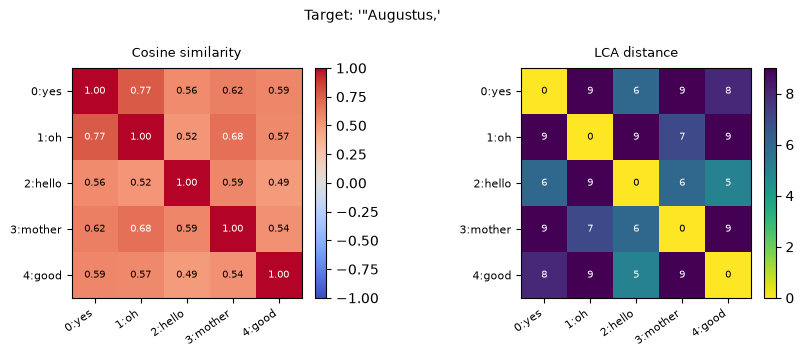


Context: '_Mother:_ "Augustus, you naughty' | Target: 'boy,'
Top-5        |      0:boy |   1:little |    2:child |    3:young |   4:fellow
-----------------------------------------------------------------------------
0:boy        |     1.0000 |     0.7542 |     0.6235 |     0.6526 |     0.6276
1:little     |     0.7542 |     1.0000 |     0.6578 |     0.6469 |     0.5699
2:child      |     0.6235 |     0.6578 |     1.0000 |     0.5638 |     0.4564
3:young      |     0.6526 |     0.6469 |     0.5638 |     1.0000 |     0.6756
4:fellow     |     0.6276 |     0.5699 |     0.4564 |     0.6756 |     1.0000


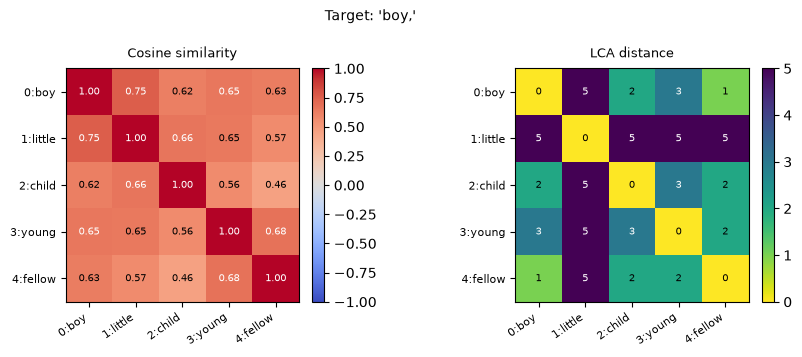


Context: '_Mother:_ "Augustus, you naughty boy,' | Target: 'you've'
Top-5        |     0:look |     1:stop |     2:come |    3:leave |     4:take
-----------------------------------------------------------------------------
0:look       |     1.0000 |     0.7781 |     0.6957 |     0.7114 |     0.7589
1:stop       |     0.7781 |     1.0000 |     0.6569 |     0.7820 |     0.7357
2:come       |     0.6957 |     0.6569 |     1.0000 |     0.7035 |     0.7544
3:leave      |     0.7114 |     0.7820 |     0.7035 |     1.0000 |     0.7878
4:take       |     0.7589 |     0.7357 |     0.7544 |     0.7878 |     1.0000


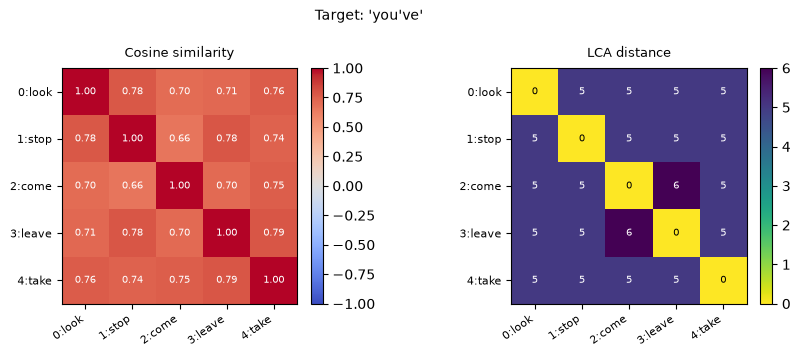


Context: '_Mother:_ "Augustus, you naughty boy, you've been' | Target: 'smoking.'
Top-5        |    0:playing |     1:making |    2:running |   3:watching |    4:outside
---------------------------------------------------------------------------------------
0:playing    |       1.0000 |       0.8115 |       0.6928 |       0.6971 |       0.5446
1:making     |       0.8115 |       1.0000 |       0.6760 |       0.7490 |       0.6026
2:running    |       0.6928 |       0.6760 |       1.0000 |       0.6958 |       0.5850
3:watching   |       0.6971 |       0.7490 |       0.6958 |       1.0000 |       0.6170
4:outside    |       0.5446 |       0.6026 |       0.5850 |       0.6170 |       1.0000


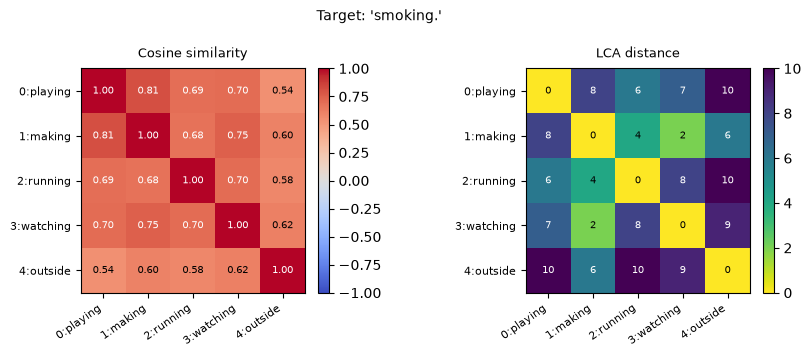


Context: 'Do you' | Target: 'feel'
Top-5        |      0:know |     1:think |      2:want |      3:need |   4:believe
----------------------------------------------------------------------------------
0:know       |      1.0000 |      0.7372 |      0.7659 |      0.7421 |      0.8158
1:think      |      0.7372 |      1.0000 |      0.7300 |      0.6569 |      0.7704
2:want       |      0.7659 |      0.7300 |      1.0000 |      0.8792 |      0.7671
3:need       |      0.7421 |      0.6569 |      0.8792 |      1.0000 |      0.7341
4:believe    |      0.8158 |      0.7704 |      0.7671 |      0.7341 |      1.0000


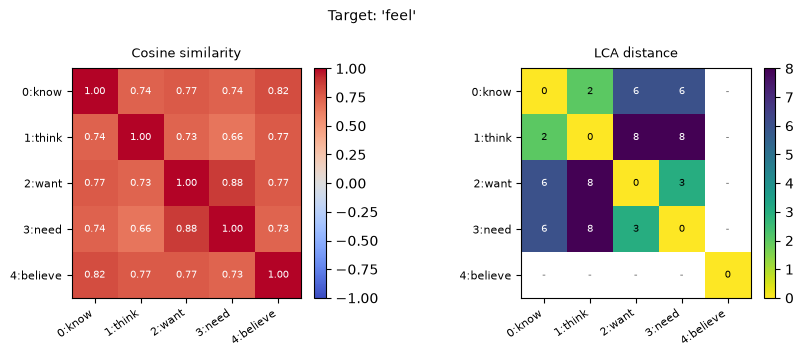


Context: 'Do you feel very' | Target: 'bad,'
Top-5        |     0:cold |      1:low |     2:warm |      3:fat |     4:good
-----------------------------------------------------------------------------
0:cold       |     1.0000 |     0.6695 |     0.8377 |     0.6276 |     0.5979
1:low        |     0.6695 |     1.0000 |     0.6494 |     0.6817 |     0.6122
2:warm       |     0.8377 |     0.6494 |     1.0000 |     0.6238 |     0.6521
3:fat        |     0.6276 |     0.6817 |     0.6238 |     1.0000 |     0.5863
4:good       |     0.5979 |     0.6122 |     0.6521 |     0.5863 |     1.0000


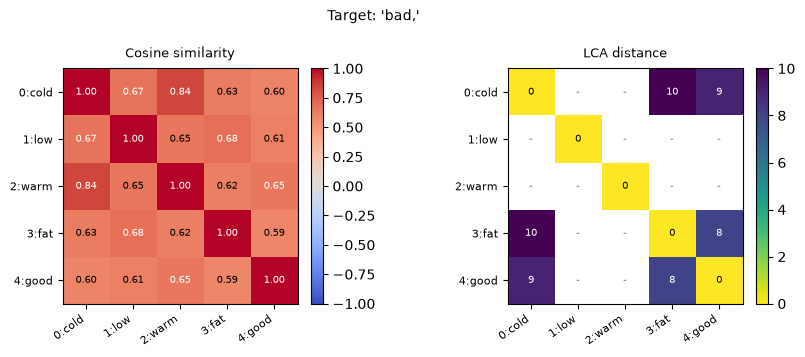


Context: 'Do you feel very bad,' | Target: 'dear?"'
Top-5           |         0:upset |         1:often |     2:extremely |         3:empty |   4:overwhelmed
---------------------------------------------------------------------------------------------------------
0:upset         |          1.0000 |          0.6144 |          0.6466 |          0.5680 |          0.7128
1:often         |          0.6144 |          1.0000 |          0.8208 |          0.5879 |          0.6973
2:extremely     |          0.6466 |          0.8208 |          1.0000 |          0.6098 |          0.7942
3:empty         |          0.5680 |          0.5879 |          0.6098 |          1.0000 |          0.6571
4:overwhelmed   |          0.7128 |          0.6973 |          0.7942 |          0.6571 |          1.0000


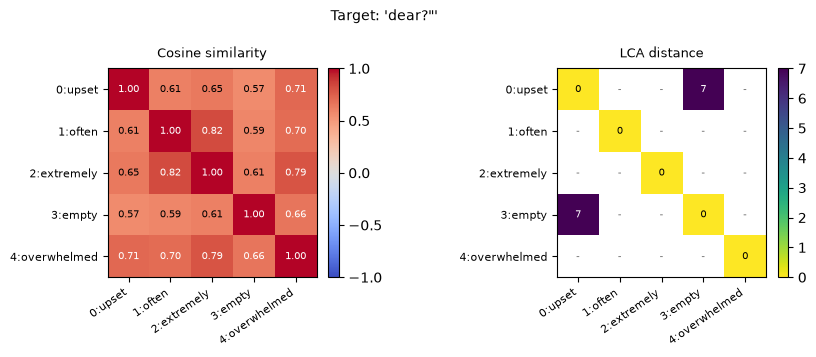


Context: '_Augustus:_' | Target: '"Thank'
Top-5        |      0:yes |   1:caesar |   2:august |      3:let
----------------------------------------------------------------
0:yes        |     1.0000 |     0.5574 |     0.3504 |     0.5067
1:caesar     |     0.5574 |     1.0000 |     0.4061 |     0.4999
2:august     |     0.3504 |     0.4061 |     1.0000 |     0.3843
3:let        |     0.5067 |     0.4999 |     0.3843 |     1.0000


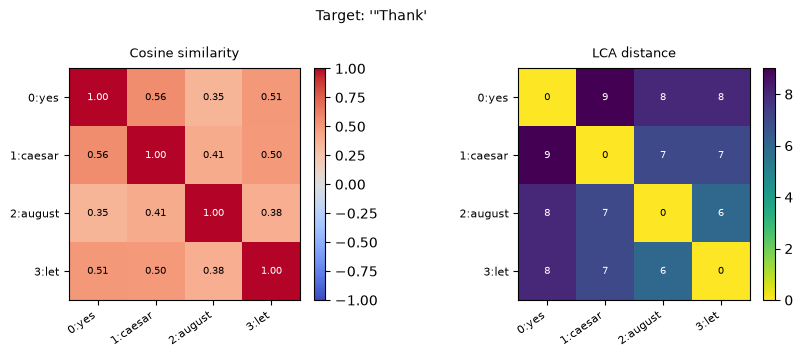


Context: '_Augustus:_ "Thank' | Target: 'you--I'm'
Top-5        |        0:god |      1:fully |   2:goodness |    3:heavens |    4:sgiving
---------------------------------------------------------------------------------------
0:god        |       1.0000 |       0.6420 |       0.7979 |       0.7568 |       0.4374
1:fully      |       0.6420 |       1.0000 |       0.8260 |       0.7838 |       0.5546
2:goodness   |       0.7979 |       0.8260 |       1.0000 |       0.8449 |       0.4791
3:heavens    |       0.7568 |       0.7838 |       0.8449 |       1.0000 |       0.5073
4:sgiving    |       0.4374 |       0.5546 |       0.4791 |       0.5073 |       1.0000


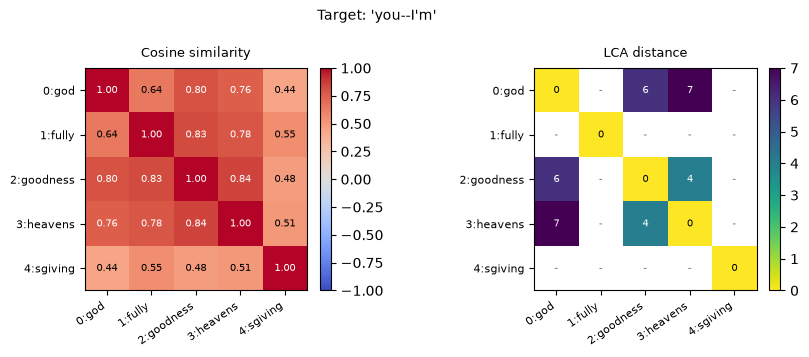


Context: '_Augustus:_ "Thank you--I'm only' | Target: 'dying."'
Top-5         |        0:glad |        1:half |       2:going |   3:beginning |      4:saying
---------------------------------------------------------------------------------------------
0:glad        |        1.0000 |        0.6636 |        0.7058 |        0.6607 |        0.7211
1:half        |        0.6636 |        1.0000 |        0.7144 |        0.7120 |        0.7341
2:going       |        0.7058 |        0.7144 |        1.0000 |        0.7741 |        0.8609
3:beginning   |        0.6607 |        0.7120 |        0.7741 |        1.0000 |        0.7997
4:saying      |        0.7211 |        0.7341 |        0.8609 |        0.7997 |        1.0000


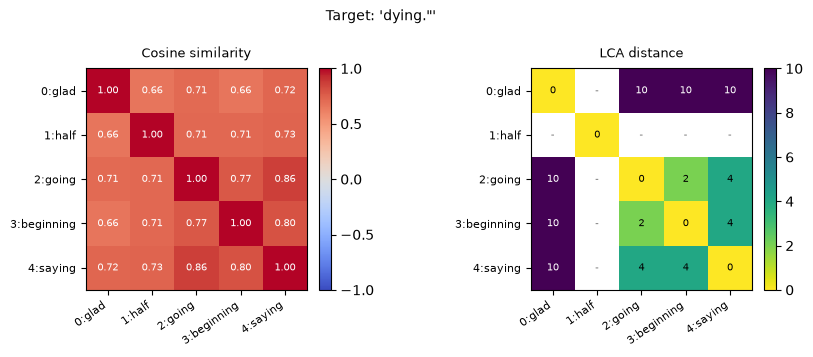


Context: '_New' | Target: 'Butler:_'
Top-5        |     0:file |     1:item |      2:ton |     3:list |      4:est
-----------------------------------------------------------------------------
0:file       |     1.0000 |     0.5941 |     0.5712 |     0.5817 |     0.3726
1:item       |     0.5941 |     1.0000 |     0.6666 |     0.6569 |     0.4674
2:ton        |     0.5712 |     0.6666 |     1.0000 |     0.5875 |     0.5356
3:list       |     0.5817 |     0.6569 |     0.5875 |     1.0000 |     0.4687
4:est        |     0.3726 |     0.4674 |     0.5356 |     0.4687 |     1.0000


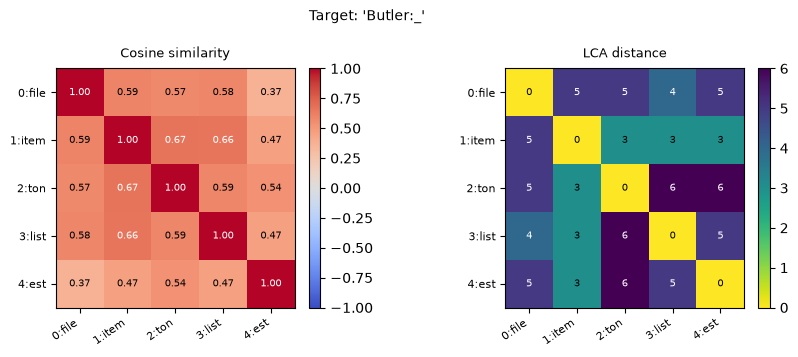


Context: '_New Butler:_ "At what' | Target: 'time,'
Top-5        |     0:time |     1:hour |    2:point |    3:price |      4:age
-----------------------------------------------------------------------------
0:time       |     1.0000 |     0.7545 |     0.4798 |     0.6935 |     0.6645
1:hour       |     0.7545 |     1.0000 |     0.4350 |     0.6343 |     0.6069
2:point      |     0.4798 |     0.4350 |     1.0000 |     0.4628 |     0.4326
3:price      |     0.6935 |     0.6343 |     0.4628 |     1.0000 |     0.7041
4:age        |     0.6645 |     0.6069 |     0.4326 |     0.7041 |     1.0000


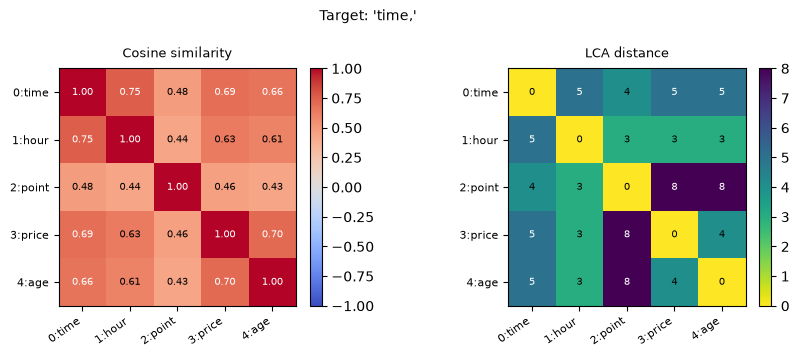


Context: '_New Butler:_ "At what time,' | Target: 'Sir,'
Top-5        |       0:sir |        1:mr |      2:miss |    3:master |   4:exactly
----------------------------------------------------------------------------------
0:sir        |      1.0000 |      0.8238 |      0.6812 |      0.7167 |      0.5792
1:mr         |      0.8238 |      1.0000 |      0.7803 |      0.7577 |      0.6271
2:miss       |      0.6812 |      0.7803 |      1.0000 |      0.7027 |      0.5543
3:master     |      0.7167 |      0.7577 |      0.7027 |      1.0000 |      0.6527
4:exactly    |      0.5792 |      0.6271 |      0.5543 |      0.6527 |      1.0000


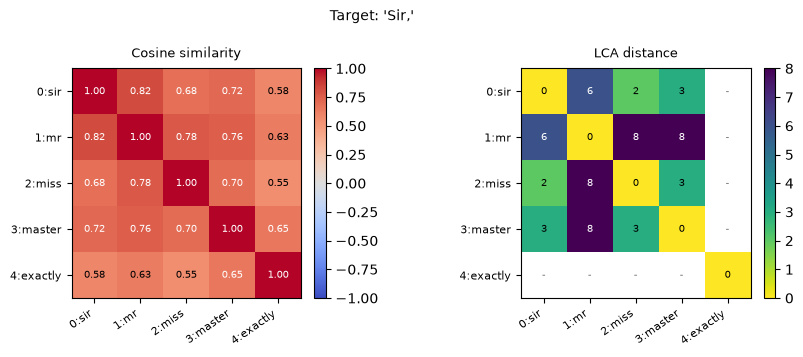


Context: '_New Butler:_ "At what time, Sir, would you' | Target: 'wish'
Top-5        |    0:prefer |      1:wish |   2:require |      3:care |      4:want
----------------------------------------------------------------------------------
0:prefer     |      1.0000 |      0.7336 |      0.8334 |      0.6777 |      0.7424
1:wish       |      0.7336 |      1.0000 |      0.6834 |      0.6669 |      0.7506
2:require    |      0.8334 |      0.6834 |      1.0000 |      0.6149 |      0.6578
3:care       |      0.6777 |      0.6669 |      0.6149 |      1.0000 |      0.6898
4:want       |      0.7424 |      0.7506 |      0.6578 |      0.6898 |      1.0000


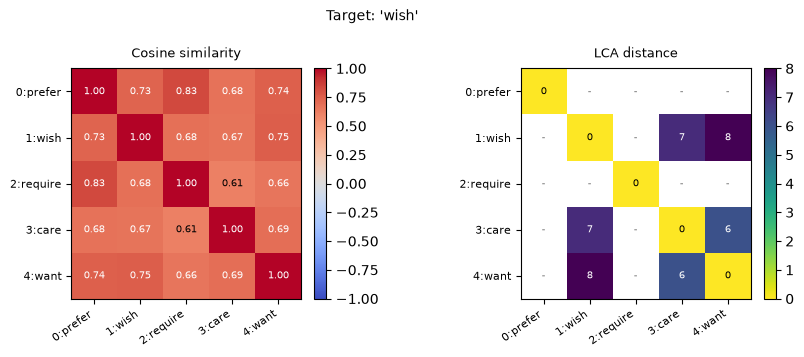


Context: '_New Butler:_ "At what time, Sir, would you wish to' | Target: 'dine'
Top-5        |    0:leave |   1:depart |     2:dine |     3:meet |      4:see
-----------------------------------------------------------------------------
0:leave      |     1.0000 |     0.6788 |     0.5158 |     0.6895 |     0.6177
1:depart     |     0.6788 |     1.0000 |     0.4278 |     0.6372 |     0.6226
2:dine       |     0.5158 |     0.4278 |     1.0000 |     0.5069 |     0.4601
3:meet       |     0.6895 |     0.6372 |     0.5069 |     1.0000 |     0.6759
4:see        |     0.6177 |     0.6226 |     0.4601 |     0.6759 |     1.0000


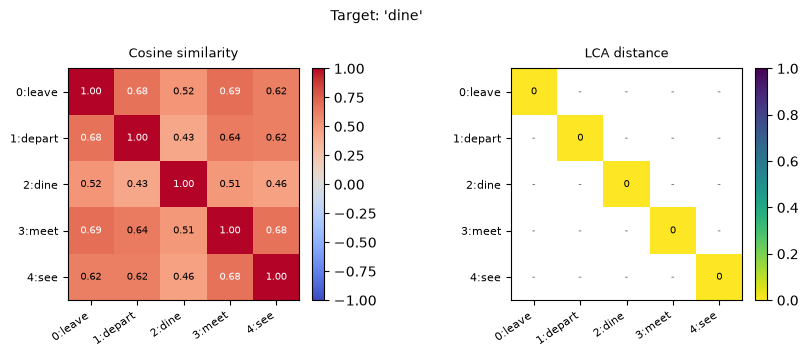


Context: '_New Butler:_ "At what time, Sir, would you wish to dine as a' | Target: 'rule?"'
Top-5          |        0:guest |       1:matter |      2:regular |    3:gentleman |   4:vegetarian
---------------------------------------------------------------------------------------------------
0:guest        |         1.0000 |         0.6191 |         0.6740 |         0.5447 |         0.7071
1:matter       |         0.6191 |         1.0000 |         0.6416 |         0.6006 |         0.7824
2:regular      |         0.6740 |         0.6416 |         1.0000 |         0.5947 |         0.7759
3:gentleman    |         0.5447 |         0.6006 |         0.5947 |         1.0000 |         0.6587
4:vegetarian   |         0.7071 |         0.7824 |         0.7759 |         0.6587 |         1.0000


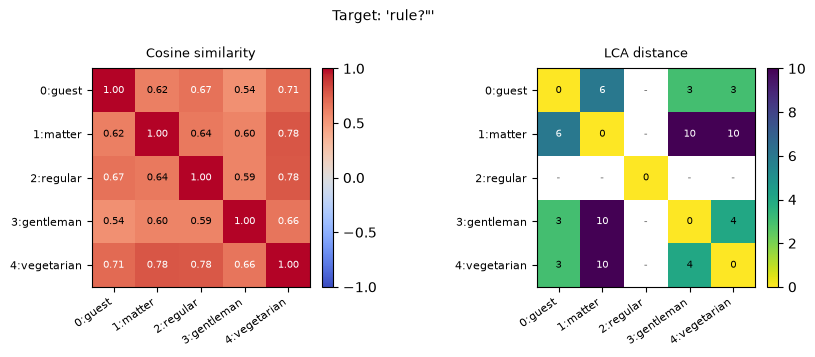


Context: '_Profiteer:_ "What' | Target: 'time'
Top-5        |       0:kind |      1:makes |    2:exactly |   3:happened |    4:happens
---------------------------------------------------------------------------------------
0:kind       |       1.0000 |       0.8216 |       0.6860 |       0.7923 |       0.8150
1:makes      |       0.8216 |       1.0000 |       0.6703 |       0.7726 |       0.8125
2:exactly    |       0.6860 |       0.6703 |       1.0000 |       0.6530 |       0.6740
3:happened   |       0.7923 |       0.7726 |       0.6530 |       1.0000 |       0.9224
4:happens    |       0.8150 |       0.8125 |       0.6740 |       0.9224 |       1.0000


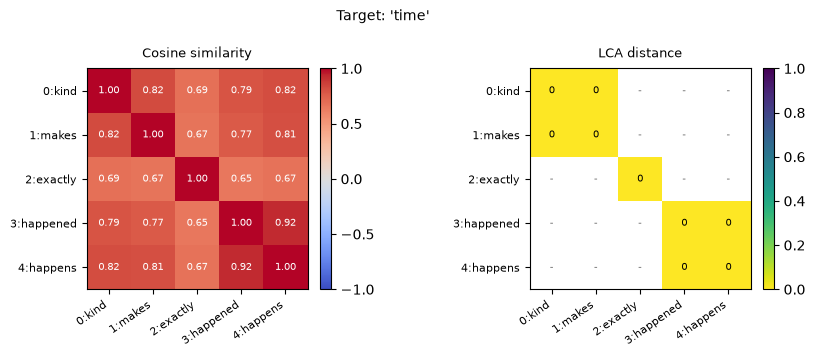


Context: '_Profiteer:_ "What time do the' | Target: 'best'
Top-5        |   0:trains |    1:buses |    2:banks |    3:shops |   4:stores
-----------------------------------------------------------------------------
0:trains     |     1.0000 |     0.7969 |     0.5727 |     0.6130 |     0.7031
1:buses      |     0.7969 |     1.0000 |     0.6384 |     0.7151 |     0.7093
2:banks      |     0.5727 |     0.6384 |     1.0000 |     0.5918 |     0.6608
3:shops      |     0.6130 |     0.7151 |     0.5918 |     1.0000 |     0.7331
4:stores     |     0.7031 |     0.7093 |     0.6608 |     0.7331 |     1.0000


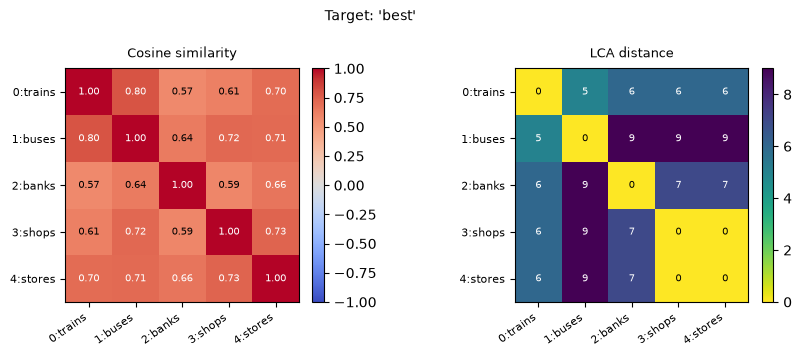


Context: '_Profiteer:_ "What time do the best' | Target: 'people'
Top-5           |         0:deals |        1:movies |        2:stocks |       3:players |   4:restaurants
---------------------------------------------------------------------------------------------------------
0:deals         |          1.0000 |          0.6236 |          0.7859 |          0.5759 |          0.7304
1:movies        |          0.6236 |          1.0000 |          0.5753 |          0.5316 |          0.6315
2:stocks        |          0.7859 |          0.5753 |          1.0000 |          0.5557 |          0.7459
3:players       |          0.5759 |          0.5316 |          0.5557 |          1.0000 |          0.5062
4:restaurants   |          0.7304 |          0.6315 |          0.7459 |          0.5062 |          1.0000


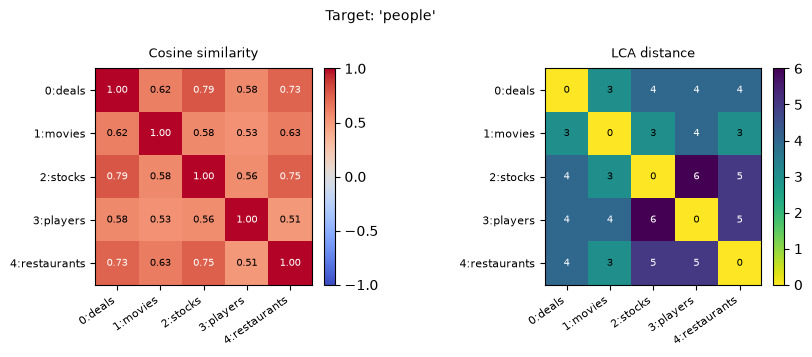


Context: '_Profiteer:_ "What time do the best people' | Target: 'dine?"'
Top-5        |     0:leave |    1:arrive |      2:come |      3:wake |   4:usually
----------------------------------------------------------------------------------
0:leave      |      1.0000 |      0.7084 |      0.7035 |      0.6895 |      0.6475
1:arrive     |      0.7084 |      1.0000 |      0.6734 |      0.7571 |      0.6336
2:come       |      0.7035 |      0.6734 |      1.0000 |      0.7310 |      0.5927
3:wake       |      0.6895 |      0.7571 |      0.7310 |      1.0000 |      0.6002
4:usually    |      0.6475 |      0.6336 |      0.5927 |      0.6002 |      1.0000


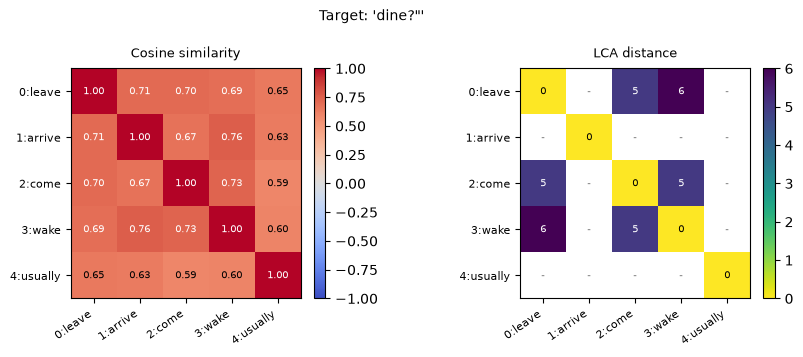


Context: '_New' | Target: 'Butler:_'
Top-5        |     0:file |     1:item |      2:ton |     3:list |      4:est
-----------------------------------------------------------------------------
0:file       |     1.0000 |     0.5941 |     0.5712 |     0.5817 |     0.3726
1:item       |     0.5941 |     1.0000 |     0.6666 |     0.6569 |     0.4674
2:ton        |     0.5712 |     0.6666 |     1.0000 |     0.5875 |     0.5356
3:list       |     0.5817 |     0.6569 |     0.5875 |     1.0000 |     0.4687
4:est        |     0.3726 |     0.4674 |     0.5356 |     0.4687 |     1.0000


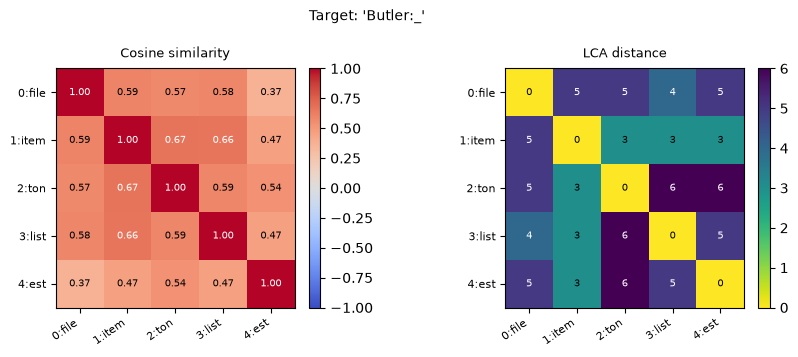


Context: '_New Butler:_ "At different' | Target: 'times,'
Top-5         |       0:times |      1:stages |      2:points |     3:moments |   4:occasions
---------------------------------------------------------------------------------------------
0:times       |        1.0000 |        0.3799 |        0.2275 |        0.7343 |        0.7196
1:stages      |        0.3799 |        1.0000 |        0.6023 |        0.3571 |        0.4430
2:points      |        0.2275 |        0.6023 |        1.0000 |        0.1842 |        0.2125
3:moments     |        0.7343 |        0.3571 |        0.1842 |        1.0000 |        0.7581
4:occasions   |        0.7196 |        0.4430 |        0.2125 |        0.7581 |        1.0000


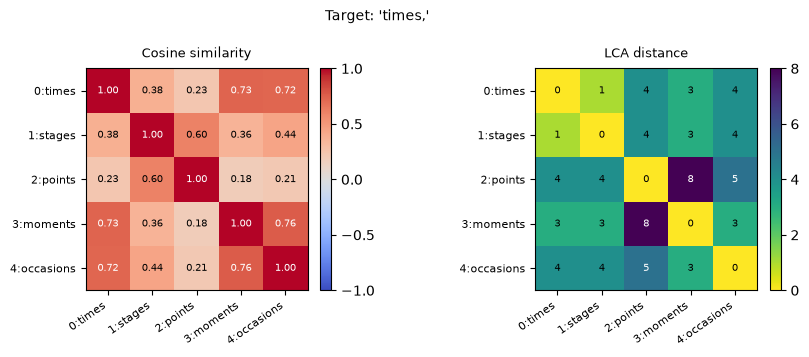


Context: '_New Butler:_ "At different times,' | Target: 'Sir."'
Top-5         |      0:people |          1:mr |        2:miss |         3:mrs |   4:president
---------------------------------------------------------------------------------------------
0:people      |        1.0000 |        0.6543 |        0.5991 |        0.6436 |        0.6523
1:mr          |        0.6543 |        1.0000 |        0.7803 |        0.8692 |        0.6455
2:miss        |        0.5991 |        0.7803 |        1.0000 |        0.7830 |        0.6217
3:mrs         |        0.6436 |        0.8692 |        0.7830 |        1.0000 |        0.6624
4:president   |        0.6523 |        0.6455 |        0.6217 |        0.6624 |        1.0000


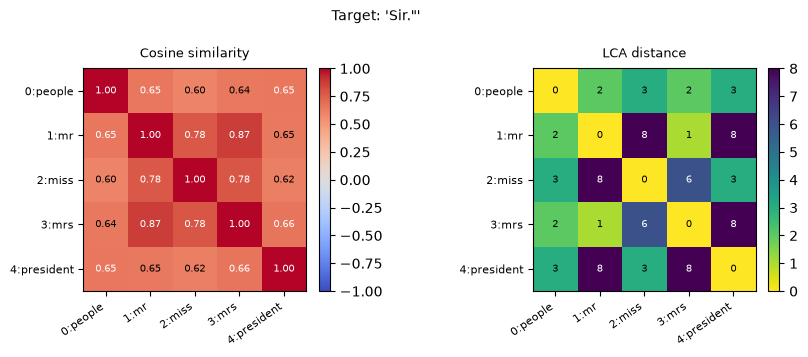


Context: 'Then I, too, will' | Target: 'dine'
Top-5        |     0:take |     1:come |     2:give |   3:become |     4:send
-----------------------------------------------------------------------------
0:take       |     1.0000 |     0.7544 |     0.8652 |     0.7929 |     0.6761
1:come       |     0.7544 |     1.0000 |     0.7279 |     0.7036 |     0.6347
2:give       |     0.8652 |     0.7279 |     1.0000 |     0.7737 |     0.7022
3:become     |     0.7929 |     0.7036 |     0.7737 |     1.0000 |     0.6390
4:send       |     0.6761 |     0.6347 |     0.7022 |     0.6390 |     1.0000


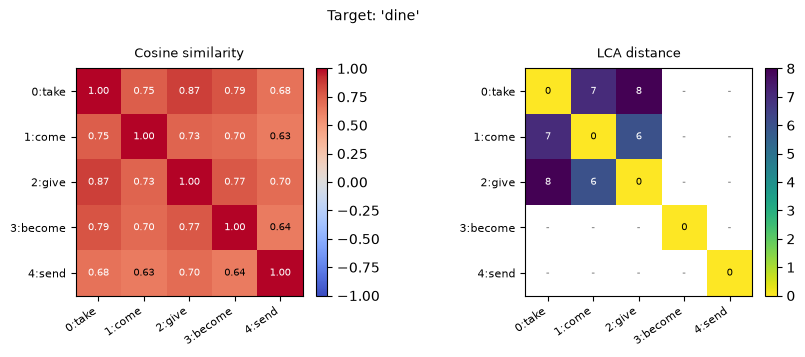


Context: 'Then I, too, will dine at different' | Target: 'times."'
Top-5           |        0:tables |        1:places |   2:restaurants |         3:times |         4:table
---------------------------------------------------------------------------------------------------------
0:tables        |          1.0000 |          0.6053 |          0.6660 |          0.5613 |          0.8391
1:places        |          0.6053 |          1.0000 |          0.6742 |          0.6398 |          0.4705
2:restaurants   |          0.6660 |          0.6742 |          1.0000 |          0.6511 |          0.4890
3:times         |          0.5613 |          0.6398 |          0.6511 |          1.0000 |          0.4672
4:table         |          0.8391 |          0.4705 |          0.4890 |          0.4672 |          1.0000


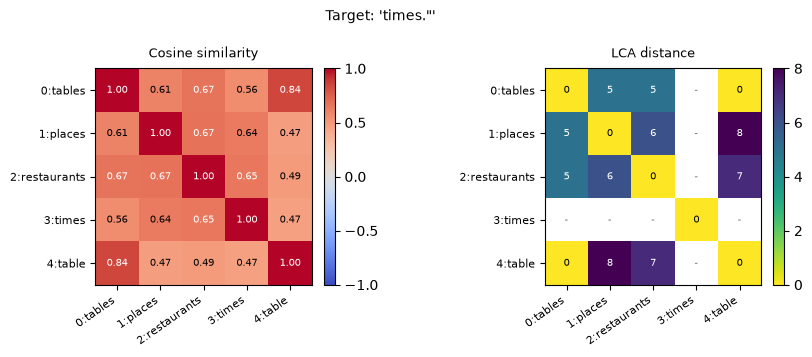


Context: '_Fond' | Target: 'Mamma:_'
Top-5        |        0:os |        1:ue |     2:ation |   3:amental |       4:ant
----------------------------------------------------------------------------------
0:os         |      1.0000 |      0.5048 |      0.5468 |      0.5902 |      0.8446
1:ue         |      0.5048 |      1.0000 |      0.4836 |      0.4799 |      0.5228
2:ation      |      0.5468 |      0.4836 |      1.0000 |      0.5531 |      0.5477
3:amental    |      0.5902 |      0.4799 |      0.5531 |      1.0000 |      0.6348
4:ant        |      0.8446 |      0.5228 |      0.5477 |      0.6348 |      1.0000


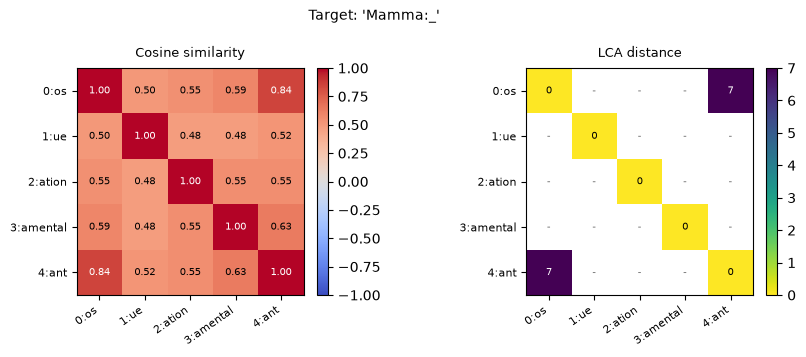


Context: '_Fond Mamma:_ "I' | Target: 'sometimes'
Top-5        |     0:know |     1:want |    2:think |     3:love |     4:hope
-----------------------------------------------------------------------------
0:know       |     1.0000 |     0.7659 |     0.7372 |     0.5931 |     0.6589
1:want       |     0.7659 |     1.0000 |     0.7300 |     0.6805 |     0.7060
2:think      |     0.7372 |     0.7300 |     1.0000 |     0.5152 |     0.5916
3:love       |     0.5931 |     0.6805 |     0.5152 |     1.0000 |     0.7035
4:hope       |     0.6589 |     0.7060 |     0.5916 |     0.7035 |     1.0000


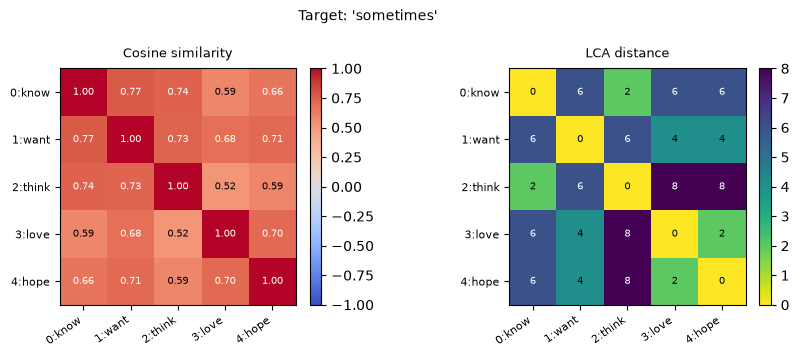


Context: '_Fond Mamma:_ "I sometimes' | Target: 'think,'
Top-5        |    0:think |   1:wonder |     2:feel |     3:wish |    4:worry
-----------------------------------------------------------------------------
0:think      |     1.0000 |     0.6370 |     0.7300 |     0.6833 |     0.6646
1:wonder     |     0.6370 |     1.0000 |     0.6658 |     0.6844 |     0.6991
2:feel       |     0.7300 |     0.6658 |     1.0000 |     0.6562 |     0.6401
3:wish       |     0.6833 |     0.6844 |     0.6562 |     1.0000 |     0.6799
4:worry      |     0.6646 |     0.6991 |     0.6401 |     0.6799 |     1.0000


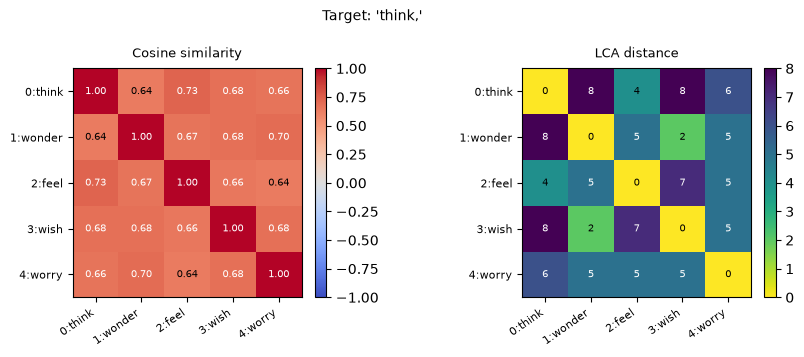


Context: '_Fond Mamma:_ "I sometimes think,' | Target: 'Percy,'
Top-5        |      0:dear |    1:though |   2:darling |       3:son |    4:mother
----------------------------------------------------------------------------------
0:dear       |      1.0000 |      0.5308 |      0.6839 |      0.5704 |      0.6313
1:though     |      0.5308 |      1.0000 |      0.6255 |      0.5691 |      0.5960
2:darling    |      0.6839 |      0.6255 |      1.0000 |      0.7003 |      0.7904
3:son        |      0.5704 |      0.5691 |      0.7003 |      1.0000 |      0.7940
4:mother     |      0.6313 |      0.5960 |      0.7904 |      0.7940 |      1.0000


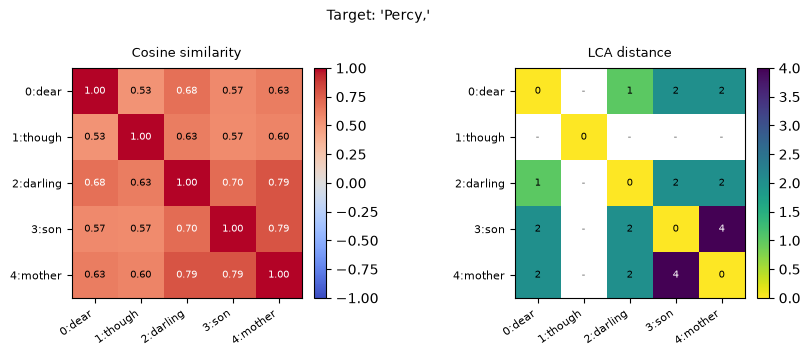


Context: '_Fond Mamma:_ "I sometimes think, Percy, you don't' | Target: 'treat'
Top-5          |         0:know |   1:understand |       2:really |         3:care |   4:appreciate
---------------------------------------------------------------------------------------------------
0:know         |         1.0000 |         0.8712 |         0.6571 |         0.6485 |         0.7739
1:understand   |         0.8712 |         1.0000 |         0.6780 |         0.6524 |         0.8655
2:really       |         0.6571 |         0.6780 |         1.0000 |         0.6215 |         0.6959
3:care         |         0.6485 |         0.6524 |         0.6215 |         1.0000 |         0.6856
4:appreciate   |         0.7739 |         0.8655 |         0.6959 |         0.6856 |         1.0000


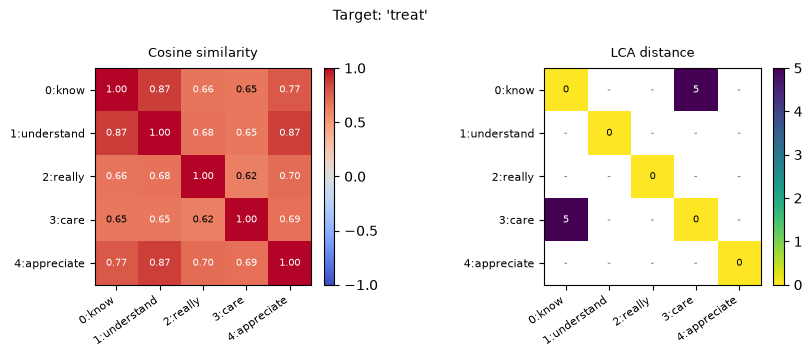


Context: '_Fond Mamma:_ "I sometimes think, Percy, you don't treat your' | Target: 'dear'
Top-5        |     0:mother |     1:father |       2:wife |   3:children |     4:sister
---------------------------------------------------------------------------------------
0:mother     |       1.0000 |       0.9228 |       0.8203 |       0.5195 |       0.8402
1:father     |       0.9228 |       1.0000 |       0.8083 |       0.5079 |       0.8430
2:wife       |       0.8203 |       0.8083 |       1.0000 |       0.5148 |       0.8329
3:children   |       0.5195 |       0.5079 |       0.5148 |       1.0000 |       0.4629
4:sister     |       0.8402 |       0.8430 |       0.8329 |       0.4629 |       1.0000


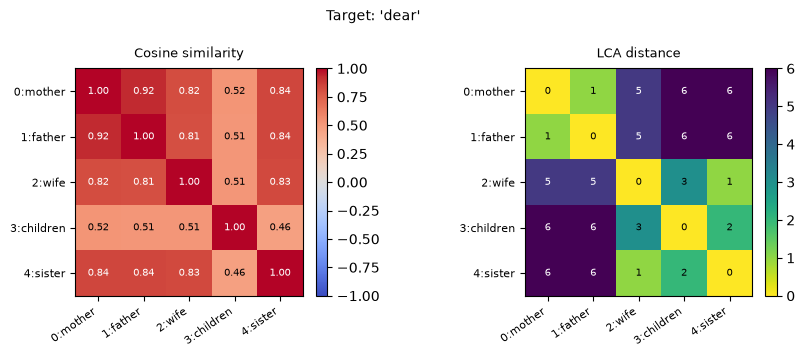


Context: '_Fond Mamma:_ "I sometimes think, Percy, you don't treat your dear' | Target: 'father'
Top-5        |     0:father |        1:old |     2:mother |       3:wife |   4:children
---------------------------------------------------------------------------------------
0:father     |       1.0000 |       0.5674 |       0.9228 |       0.8083 |       0.5079
1:old        |       0.5674 |       1.0000 |       0.5687 |       0.5272 |       0.4527
2:mother     |       0.9228 |       0.5687 |       1.0000 |       0.8203 |       0.5195
3:wife       |       0.8083 |       0.5272 |       0.8203 |       1.0000 |       0.5148
4:children   |       0.5079 |       0.4527 |       0.5195 |       0.5148 |       1.0000


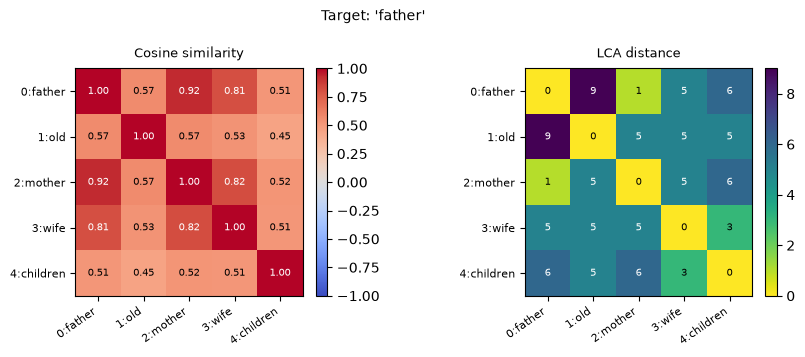


Context: '_Fond Mamma:_ "I sometimes think, Percy, you don't treat your dear father with quite the proper' | Target: 'respect."'
Top-5         |     0:respect |   1:affection |       2:defer |      3:amount |      4:regard
---------------------------------------------------------------------------------------------
0:respect     |        1.0000 |        0.7446 |        0.5241 |        0.6266 |        0.7190
1:affection   |        0.7446 |        1.0000 |        0.4593 |        0.6952 |        0.7245
2:defer       |        0.5241 |        0.4593 |        1.0000 |        0.5504 |        0.5769
3:amount      |        0.6266 |        0.6952 |        0.5504 |        1.0000 |        0.8255
4:regard      |        0.7190 |        0.7245 |        0.5769 |        0.8255 |        1.0000


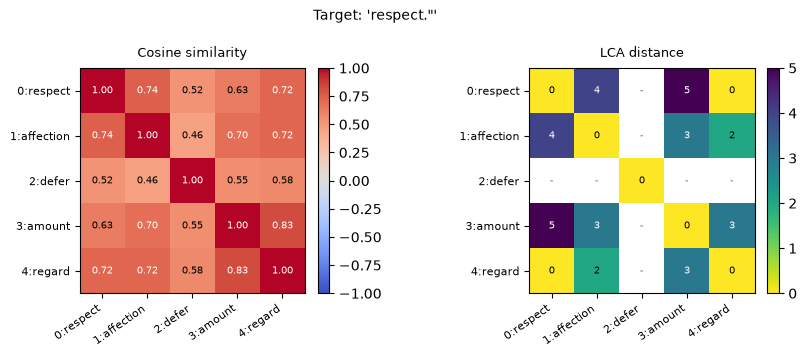


Context: '_Young' | Target: 'Hopeful_;'
Top-5        |       0:er |      1:est |   2:people |    3:stown |    4:blood
-----------------------------------------------------------------------------
0:er         |     1.0000 |     0.4577 |     0.4653 |     0.4837 |     0.3861
1:est        |     0.4577 |     1.0000 |     0.4318 |     0.5403 |     0.3985
2:people     |     0.4653 |     0.4318 |     1.0000 |     0.6125 |     0.5585
3:stown      |     0.4837 |     0.5403 |     0.6125 |     1.0000 |     0.5172
4:blood      |     0.3861 |     0.3985 |     0.5585 |     0.5172 |     1.0000


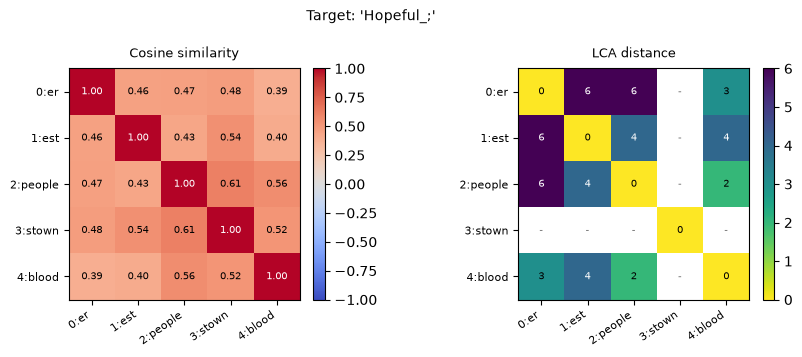


Context: '_Young Hopeful_; "Well, Ma, I' | Target: 'never'
Top-5        |     0:guess |    1:reckon |     2:think |      3:want |   4:suppose
----------------------------------------------------------------------------------
0:guess      |      1.0000 |      0.6400 |      0.7172 |      0.7081 |      0.5437
1:reckon     |      0.6400 |      1.0000 |      0.5779 |      0.5079 |      0.4442
2:think      |      0.7172 |      0.5779 |      1.0000 |      0.7300 |      0.5477
3:want       |      0.7081 |      0.5079 |      0.7300 |      1.0000 |      0.5143
4:suppose    |      0.5437 |      0.4442 |      0.5477 |      0.5143 |      1.0000


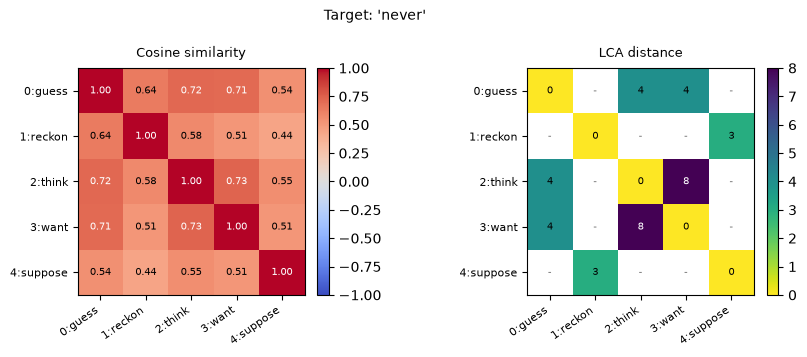


Context: '_Young Hopeful_; "Well, Ma, I never liked the' | Target: 'man."'
Top-5        |     0:idea |      1:old |      2:way |     3:name |    4:place
-----------------------------------------------------------------------------
0:idea       |     1.0000 |     0.5683 |     0.6371 |     0.7494 |     0.6944
1:old        |     0.5683 |     1.0000 |     0.5213 |     0.5384 |     0.4463
2:way        |     0.6371 |     0.5213 |     1.0000 |     0.6059 |     0.5360
3:name       |     0.7494 |     0.5384 |     0.6059 |     1.0000 |     0.7077
4:place      |     0.6944 |     0.4463 |     0.5360 |     0.7077 |     1.0000


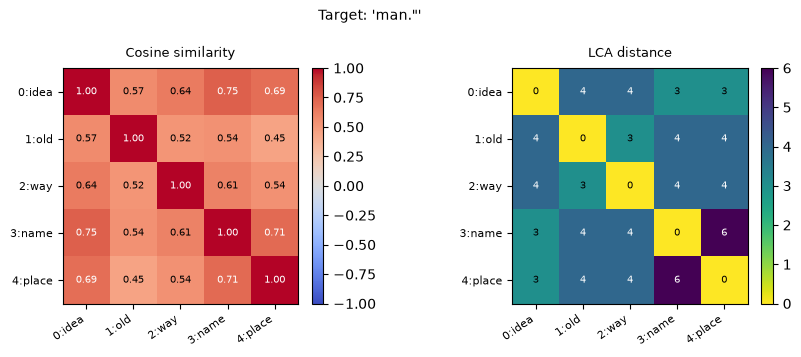


Context: '_Playful' | Target: 'Hostess:_'
Top-5        |        0:p |        1:c |        2:h |        3:b |        4:g
-----------------------------------------------------------------------------
0:p          |     1.0000 |     0.4837 |     0.4902 |     0.4080 |     0.5010
1:c          |     0.4837 |     1.0000 |     0.7300 |     0.7311 |     0.7687
2:h          |     0.4902 |     0.7300 |     1.0000 |     0.6068 |     0.7773
3:b          |     0.4080 |     0.7311 |     0.6068 |     1.0000 |     0.7561
4:g          |     0.5010 |     0.7687 |     0.7773 |     0.7561 |     1.0000


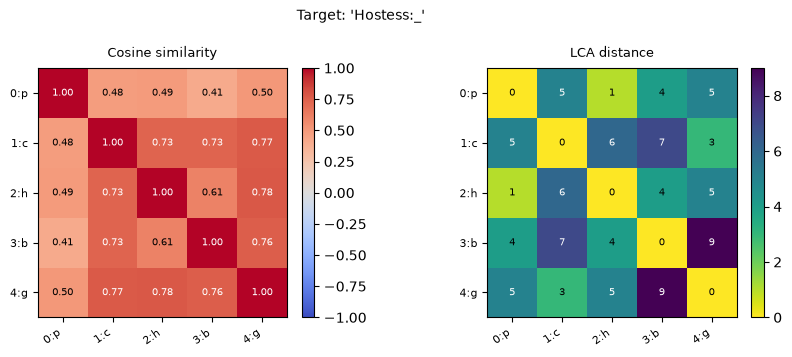


Context: '_Playful Hostess:_' | Target: '"Couldn't'
Top-5        |       0:oh |      1:yes |      2:hey |       3:ah |    4:thank
-----------------------------------------------------------------------------
0:oh         |     1.0000 |     0.7699 |     0.7320 |     0.9006 |     0.6875
1:yes        |     0.7699 |     1.0000 |     0.6492 |     0.7327 |     0.6698
2:hey        |     0.7320 |     0.6492 |     1.0000 |     0.7204 |     0.6473
3:ah         |     0.9006 |     0.7327 |     0.7204 |     1.0000 |     0.6505
4:thank      |     0.6875 |     0.6698 |     0.6473 |     0.6505 |     1.0000


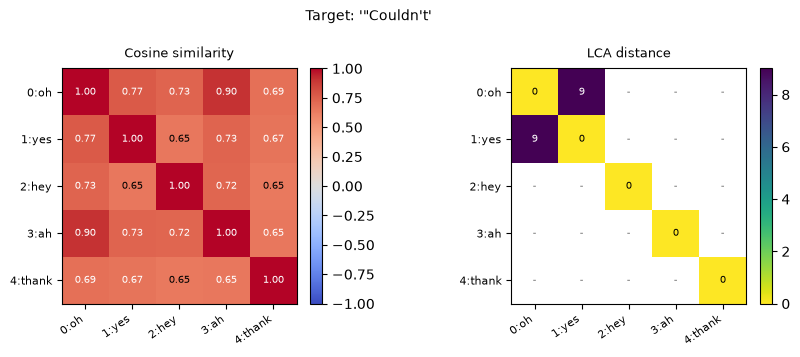


Context: '_Playful Hostess:_ "Couldn't you' | Target: 'manage'
Top-5        |     0:give |      1:use |      2:try |      3:see |     4:find
-----------------------------------------------------------------------------
0:give       |     1.0000 |     0.7439 |     0.7308 |     0.6655 |     0.7549
1:use        |     0.7439 |     1.0000 |     0.7424 |     0.7420 |     0.6922
2:try        |     0.7308 |     0.7424 |     1.0000 |     0.6517 |     0.7553
3:see        |     0.6655 |     0.7420 |     0.6517 |     1.0000 |     0.6650
4:find       |     0.7549 |     0.6922 |     0.7553 |     0.6650 |     1.0000


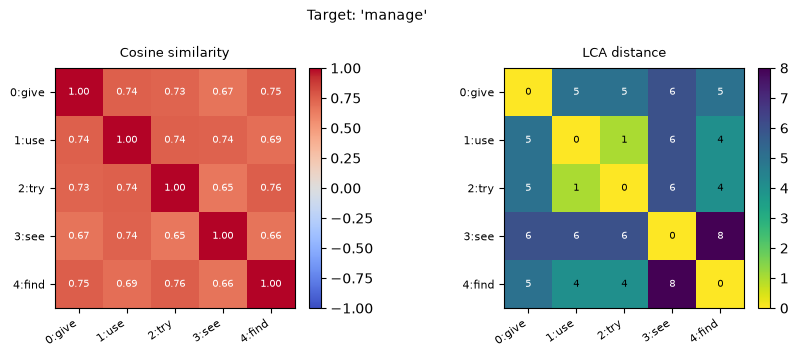


Context: '_Playful Hostess:_ "Couldn't you manage one more' | Target: '_eclair?_"'
Top-5        |     0:time |     1:joke |    2:dance |      3:day |    4:favor
-----------------------------------------------------------------------------
0:time       |     1.0000 |     0.7263 |     0.4294 |     0.6264 |     0.7416
1:joke       |     0.7263 |     1.0000 |     0.4715 |     0.5572 |     0.8223
2:dance      |     0.4294 |     0.4715 |     1.0000 |     0.4503 |     0.4150
3:day        |     0.6264 |     0.5572 |     0.4503 |     1.0000 |     0.5554
4:favor      |     0.7416 |     0.8223 |     0.4150 |     0.5554 |     1.0000


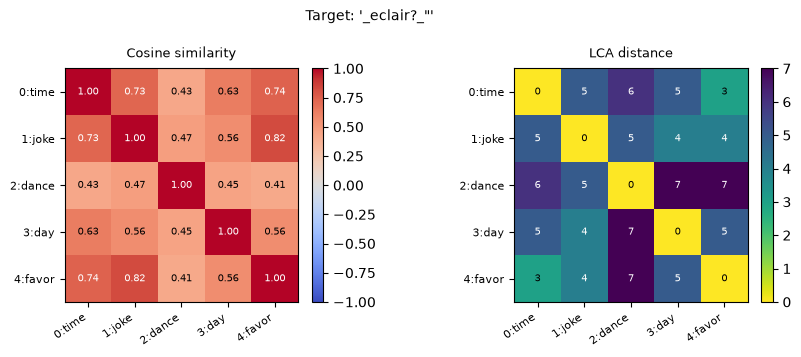


Context: '_Playful Hostess:_ "Couldn't you manage one more _eclair?_" _Serious' | Target: 'Little'
Top-5         |        0:host |        1:chef |    2:business |        3:face |   4:scientist
---------------------------------------------------------------------------------------------
0:host        |        1.0000 |        0.4875 |        0.3965 |        0.4730 |        0.5136
1:chef        |        0.4875 |        1.0000 |        0.6215 |        0.7716 |        0.8437
2:business    |        0.3965 |        0.6215 |        1.0000 |        0.6522 |        0.6598
3:face        |        0.4730 |        0.7716 |        0.6522 |        1.0000 |        0.7230
4:scientist   |        0.5136 |        0.8437 |        0.6598 |        0.7230 |        1.0000


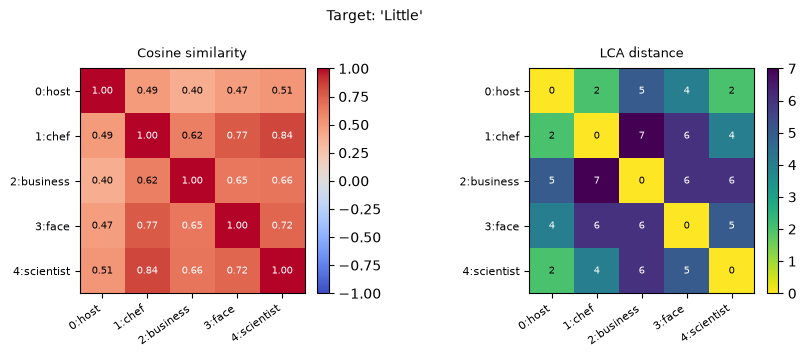


Context: '_Playful Hostess:_ "Couldn't you manage one more _eclair?_" _Serious Little' | Target: 'Boy:_'
Top-5        |      0:girl |       1:boy |      2:chef |   3:brother |      4:host
----------------------------------------------------------------------------------
0:girl       |      1.0000 |      0.8468 |      0.7139 |      0.7718 |      0.5069
1:boy        |      0.8468 |      1.0000 |      0.6859 |      0.7347 |      0.4217
2:chef       |      0.7139 |      0.6859 |      1.0000 |      0.7755 |      0.4875
3:brother    |      0.7718 |      0.7347 |      0.7755 |      1.0000 |      0.4711
4:host       |      0.5069 |      0.4217 |      0.4875 |      0.4711 |      1.0000


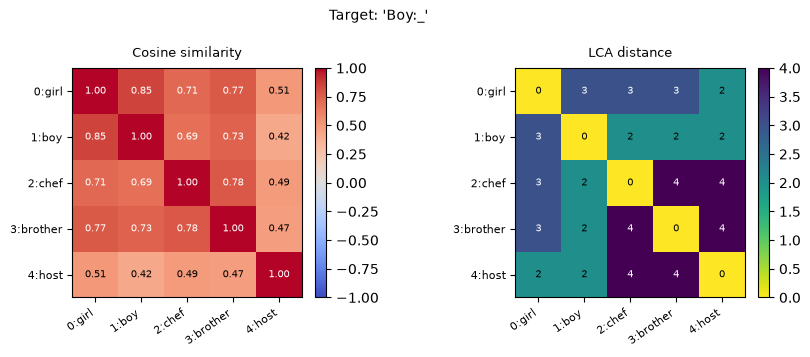


Context: '_Playful Hostess:_ "Couldn't you manage one more _eclair?_" _Serious Little Boy:_ "No,' | Target: 'fanks,'
Top-5        |    0:thank |   1:thanks |     2:miss |      3:mom |   4:please
-----------------------------------------------------------------------------
0:thank      |     1.0000 |     0.7948 |     0.5832 |     0.6050 |     0.7101
1:thanks     |     0.7948 |     1.0000 |     0.5414 |     0.6222 |     0.6247
2:miss       |     0.5832 |     0.5414 |     1.0000 |     0.6799 |     0.5525
3:mom        |     0.6050 |     0.6222 |     0.6799 |     1.0000 |     0.6507
4:please     |     0.7101 |     0.6247 |     0.5525 |     0.6507 |     1.0000


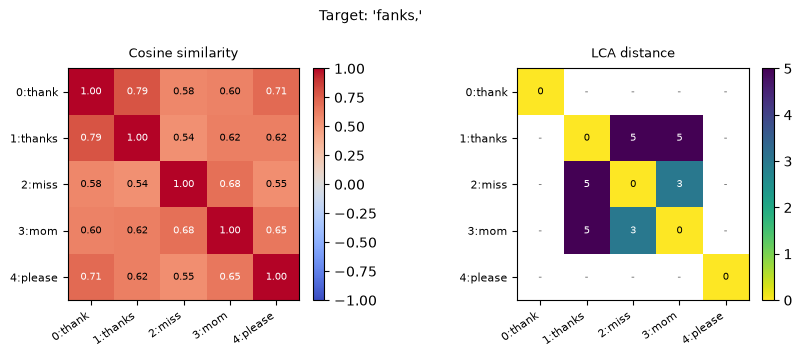


Context: '_Playful Hostess:_ "Couldn't you manage one more _eclair?_" _Serious Little Boy:_ "No, fanks, I've no more' | Target: 'room."'
Top-5        |     0:room |    1:space |       2:sp |        3:e |       4:st
-----------------------------------------------------------------------------
0:room       |     1.0000 |     0.8459 |     0.5968 |     0.6424 |     0.6148
1:space      |     0.8459 |     1.0000 |     0.5274 |     0.6513 |     0.6038
2:sp         |     0.5968 |     0.5274 |     1.0000 |     0.5771 |     0.6111
3:e          |     0.6424 |     0.6513 |     0.5771 |     1.0000 |     0.6243
4:st         |     0.6148 |     0.6038 |     0.6111 |     0.6243 |     1.0000


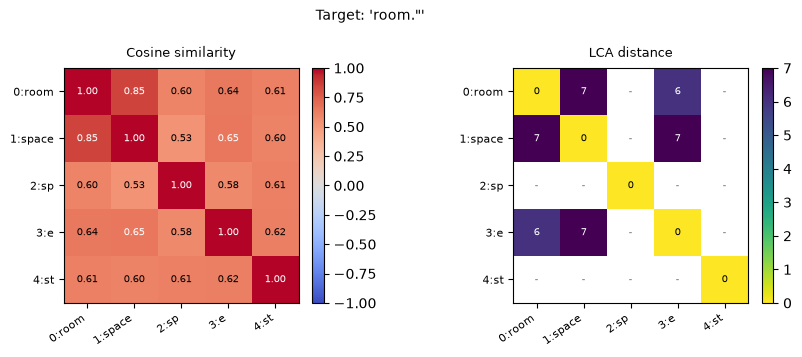


Context: '_Playful' | Target: 'Hostess:_'
Top-5        |        0:p |        1:c |        2:h |        3:b |        4:g
-----------------------------------------------------------------------------
0:p          |     1.0000 |     0.4837 |     0.4902 |     0.4080 |     0.5010
1:c          |     0.4837 |     1.0000 |     0.7300 |     0.7311 |     0.7687
2:h          |     0.4902 |     0.7300 |     1.0000 |     0.6068 |     0.7773
3:b          |     0.4080 |     0.7311 |     0.6068 |     1.0000 |     0.7561
4:g          |     0.5010 |     0.7687 |     0.7773 |     0.7561 |     1.0000


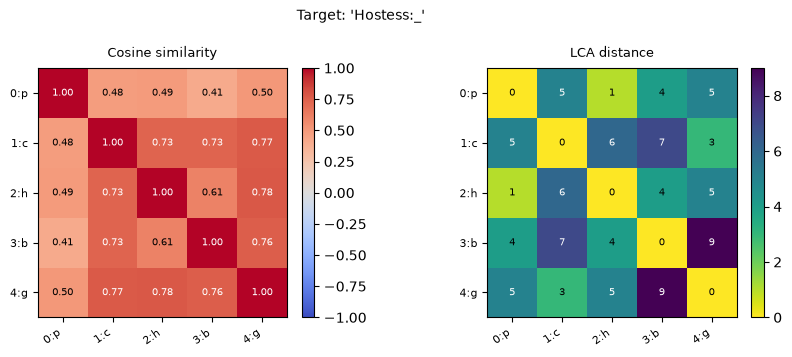


Context: '_Playful Hostess:_ "If I' | Target: 'picked'
Top-5        |     0:give |     1:want |    2:throw |     3:tell |    4:start
-----------------------------------------------------------------------------
0:give       |     1.0000 |     0.7781 |     0.7711 |     0.8343 |     0.5584
1:want       |     0.7781 |     1.0000 |     0.7040 |     0.7581 |     0.5154
2:throw      |     0.7711 |     0.7040 |     1.0000 |     0.7606 |     0.5430
3:tell       |     0.8343 |     0.7581 |     0.7606 |     1.0000 |     0.5035
4:start      |     0.5584 |     0.5154 |     0.5430 |     0.5035 |     1.0000


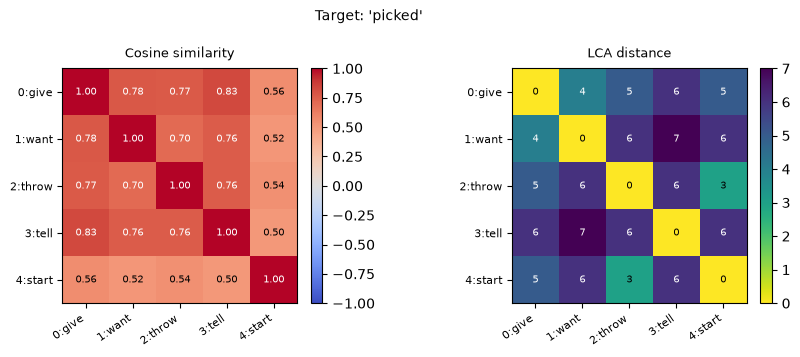


Context: '_Playful Hostess:_ "If I picked you up by the' | Target: 'heels'
Top-5        |     0:tail |     1:ears |     2:legs |      3:ear |     4:feet
-----------------------------------------------------------------------------
0:tail       |     1.0000 |     0.8229 |     0.7408 |     0.7780 |     0.6431
1:ears       |     0.8229 |     1.0000 |     0.7196 |     0.8946 |     0.7184
2:legs       |     0.7408 |     0.7196 |     1.0000 |     0.6516 |     0.7528
3:ear        |     0.7780 |     0.8946 |     0.6516 |     1.0000 |     0.6644
4:feet       |     0.6431 |     0.7184 |     0.7528 |     0.6644 |     1.0000


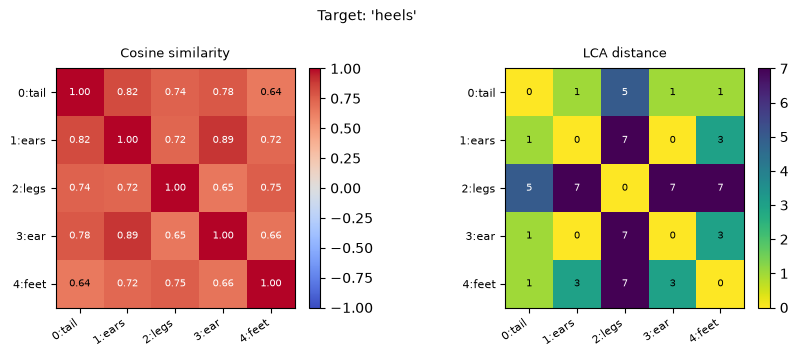


Context: '_Playful Hostess:_ "If I picked you up by the heels and' | Target: 'shook'
Top-5        |    0:swung |    1:shook |    2:threw |     3:spun |   4:tossed
-----------------------------------------------------------------------------
0:swung      |     1.0000 |     0.7884 |     0.8192 |     0.8613 |     0.8284
1:shook      |     0.7884 |     1.0000 |     0.8480 |     0.8529 |     0.8805
2:threw      |     0.8192 |     0.8480 |     1.0000 |     0.8578 |     0.8844
3:spun       |     0.8613 |     0.8529 |     0.8578 |     1.0000 |     0.8789
4:tossed     |     0.8284 |     0.8805 |     0.8844 |     0.8789 |     1.0000


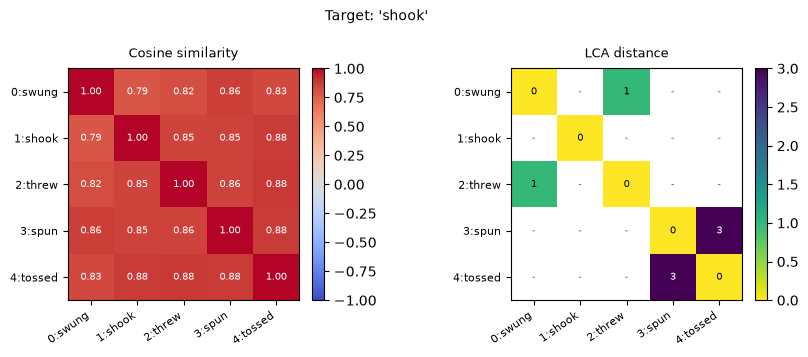


Context: '_Playful Hostess:_ "If I picked you up by the heels and shook you, would that' | Target: 'help?"'
Top-5        |     0:help |     1:wake |     2:tick |   3:change |      4:put
-----------------------------------------------------------------------------
0:help       |     1.0000 |     0.7164 |     0.6874 |     0.6355 |     0.7384
1:wake       |     0.7164 |     1.0000 |     0.6970 |     0.5314 |     0.7242
2:tick       |     0.6874 |     0.6970 |     1.0000 |     0.5684 |     0.6870
3:change     |     0.6355 |     0.5314 |     0.5684 |     1.0000 |     0.6060
4:put        |     0.7384 |     0.7242 |     0.6870 |     0.6060 |     1.0000


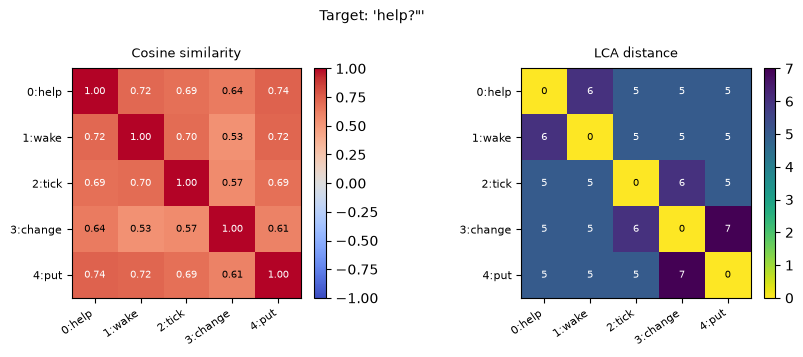


Context: '_Serious' | Target: 'Little'
Top-5        |       0:game |       1:ness |     2:injury |      3:error |   4:question
---------------------------------------------------------------------------------------
0:game       |       1.0000 |       0.6203 |       0.4982 |       0.5505 |       0.7155
1:ness       |       0.6203 |       1.0000 |       0.5199 |       0.5301 |       0.7474
2:injury     |       0.4982 |       0.5199 |       1.0000 |       0.5940 |       0.5668
3:error      |       0.5505 |       0.5301 |       0.5940 |       1.0000 |       0.5843
4:question   |       0.7155 |       0.7474 |       0.5668 |       0.5843 |       1.0000


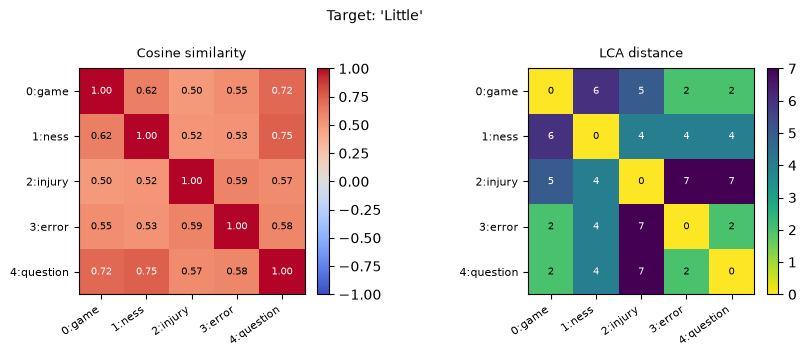


Context: '_Serious Little' | Target: 'Boy'
Top-5        |      0:man |     1:girl |     2:book |   3:people |      4:boy
-----------------------------------------------------------------------------
0:man        |     1.0000 |     0.7934 |     0.4721 |     0.7098 |     0.7447
1:girl       |     0.7934 |     1.0000 |     0.5243 |     0.7083 |     0.8468
2:book       |     0.4721 |     0.5243 |     1.0000 |     0.5662 |     0.5661
3:people     |     0.7098 |     0.7083 |     0.5662 |     1.0000 |     0.6596
4:boy        |     0.7447 |     0.8468 |     0.5661 |     0.6596 |     1.0000


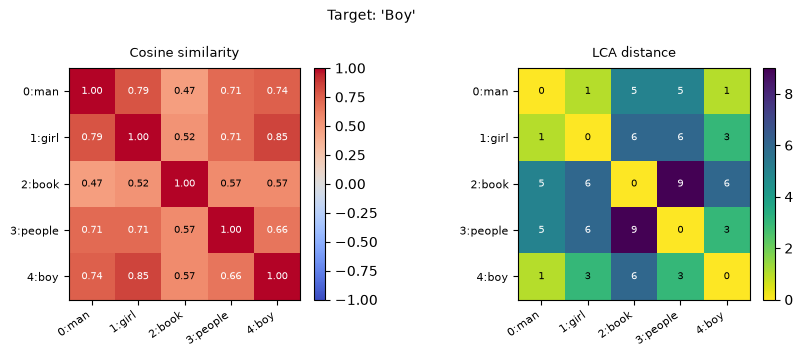


Context: '_Serious Little Boy (after' | Target: 'deep'
Top-5        |      0:rem |        1:g |        2:k |     3:jean |        4:b
-----------------------------------------------------------------------------
0:rem        |     1.0000 |     0.5154 |     0.5097 |     0.5987 |     0.4775
1:g          |     0.5154 |     1.0000 |     0.7793 |     0.6507 |     0.7561
2:k          |     0.5097 |     0.7793 |     1.0000 |     0.5993 |     0.6528
3:jean       |     0.5987 |     0.6507 |     0.5993 |     1.0000 |     0.5210
4:b          |     0.4775 |     0.7561 |     0.6528 |     0.5210 |     1.0000


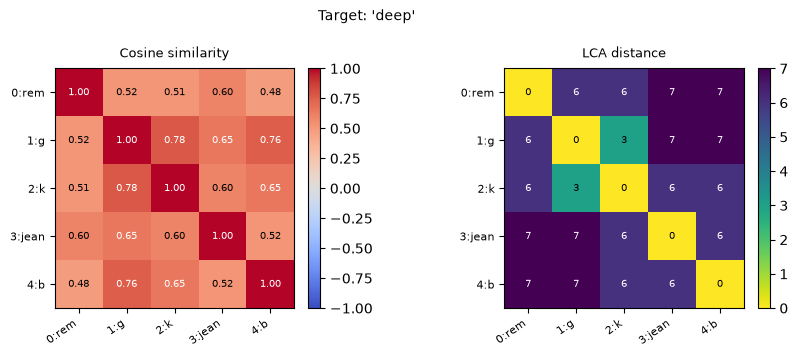


Context: '_Serious Little Boy (after deep' | Target: 'thought):_'
Top-5             |         0:thought |        1:thinking |   2:consideration |        3:contempl |        4:thoughts
---------------------------------------------------------------------------------------------------------------------
0:thought         |            1.0000 |            0.7519 |            0.6671 |            0.3547 |            0.6886
1:thinking        |            0.7519 |            1.0000 |            0.7797 |            0.4021 |            0.6951
2:consideration   |            0.6671 |            0.7797 |            1.0000 |            0.3619 |            0.5931
3:contempl        |            0.3547 |            0.4021 |            0.3619 |            1.0000 |            0.4059
4:thoughts        |            0.6886 |            0.6951 |            0.5931 |            0.4059 |            1.0000


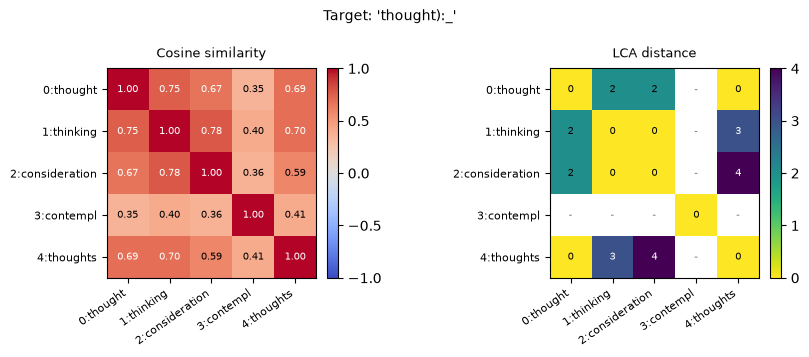


Context: '_Serious Little Boy (after deep thought):_ "No,' | Target: 'fanks,'
Top-5        |   0:actually |       1:wait |        2:dad |        3:mom |     4:father
---------------------------------------------------------------------------------------
0:actually   |       1.0000 |       0.5032 |       0.6159 |       0.6387 |       0.5472
1:wait       |       0.5032 |       1.0000 |       0.5539 |       0.5827 |       0.5341
2:dad        |       0.6159 |       0.5539 |       1.0000 |       0.9272 |       0.8499
3:mom        |       0.6387 |       0.5827 |       0.9272 |       1.0000 |       0.7909
4:father     |       0.5472 |       0.5341 |       0.8499 |       0.7909 |       1.0000


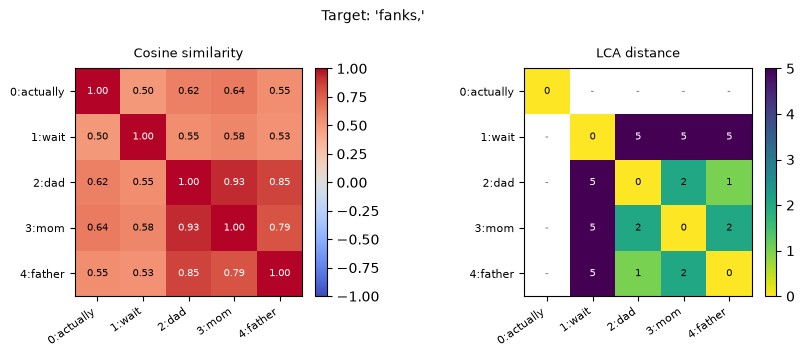


Context: '_Serious Little Boy (after deep thought):_ "No, fanks, that would make the' | Target: 'space'
Top-5        |    0:problem |   1:triangle |      2:world |      3:whole |   4:universe
---------------------------------------------------------------------------------------
0:problem    |       1.0000 |       0.6437 |       0.5863 |       0.5698 |       0.6388
1:triangle   |       0.6437 |       1.0000 |       0.4773 |       0.4751 |       0.5195
2:world      |       0.5863 |       0.4773 |       1.0000 |       0.6513 |       0.8181
3:whole      |       0.5698 |       0.4751 |       0.6513 |       1.0000 |       0.6986
4:universe   |       0.6388 |       0.5195 |       0.8181 |       0.6986 |       1.0000


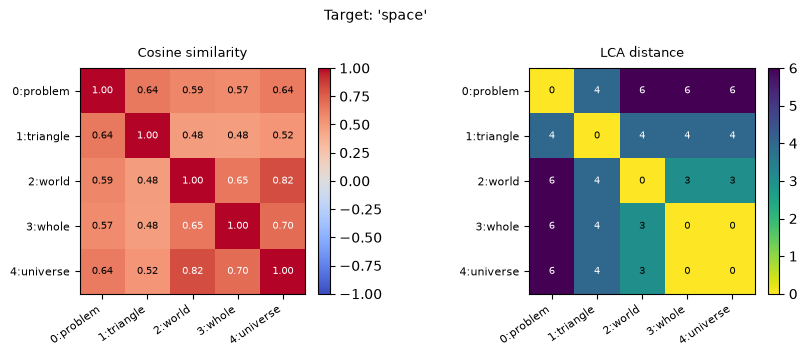


Context: '_Serious Little Boy (after deep thought):_ "No, fanks, that would make the space at the' | Target: 'wrong'
Top-5        |      0:end |    1:table |   2:bottom |      3:top |   4:center
-----------------------------------------------------------------------------
0:end        |     1.0000 |     0.3823 |     0.4813 |     0.4819 |     0.4834
1:table      |     0.3823 |     1.0000 |     0.4613 |     0.5358 |     0.5251
2:bottom     |     0.4813 |     0.4613 |     1.0000 |     0.6677 |     0.5781
3:top        |     0.4819 |     0.5358 |     0.6677 |     1.0000 |     0.5223
4:center     |     0.4834 |     0.5251 |     0.5781 |     0.5223 |     1.0000


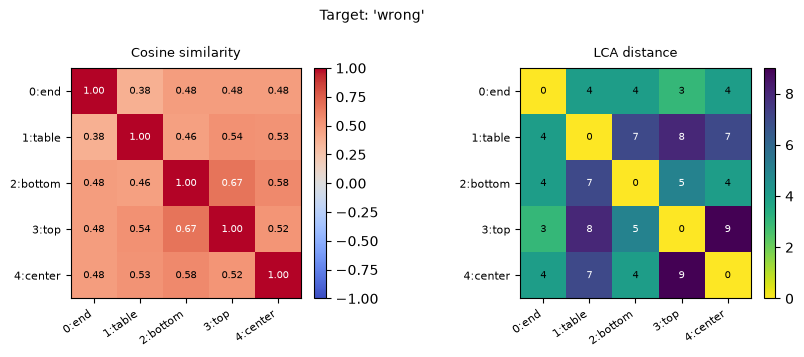


Context: '_Serious Little Boy (after deep thought):_ "No, fanks, that would make the space at the wrong' | Target: 'end."'
Top-5        |     0:size |    1:angle |    2:place |      3:end |    4:scale
-----------------------------------------------------------------------------
0:size       |     1.0000 |     0.8115 |     0.6775 |     0.4315 |     0.7835
1:angle      |     0.8115 |     1.0000 |     0.6276 |     0.4153 |     0.6865
2:place      |     0.6775 |     0.6276 |     1.0000 |     0.5224 |     0.5907
3:end        |     0.4315 |     0.4153 |     0.5224 |     1.0000 |     0.3682
4:scale      |     0.7835 |     0.6865 |     0.5907 |     0.3682 |     1.0000


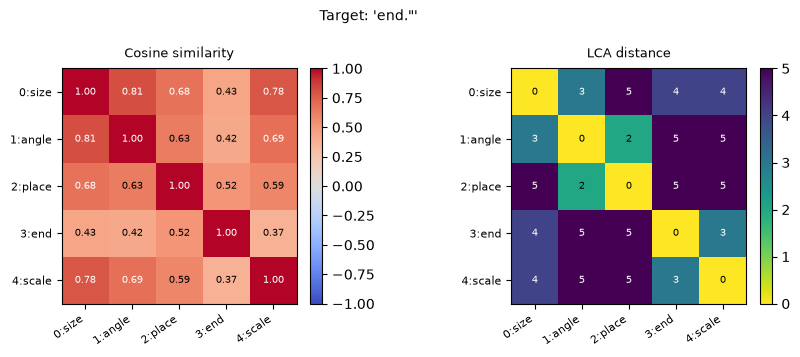


Context: '_Vicar's' | Target: 'Wife:_'
Top-5        |   0:journal |    1:office |         2:c |     3:notes |       4:log
----------------------------------------------------------------------------------
0:journal    |      1.0000 |      0.4918 |      0.4370 |      0.3112 |      0.3771
1:office     |      0.4918 |      1.0000 |      0.5980 |      0.4293 |      0.6294
2:c          |      0.4370 |      0.5980 |      1.0000 |      0.4285 |      0.4886
3:notes      |      0.3112 |      0.4293 |      0.4285 |      1.0000 |      0.3852
4:log        |      0.3771 |      0.6294 |      0.4886 |      0.3852 |      1.0000


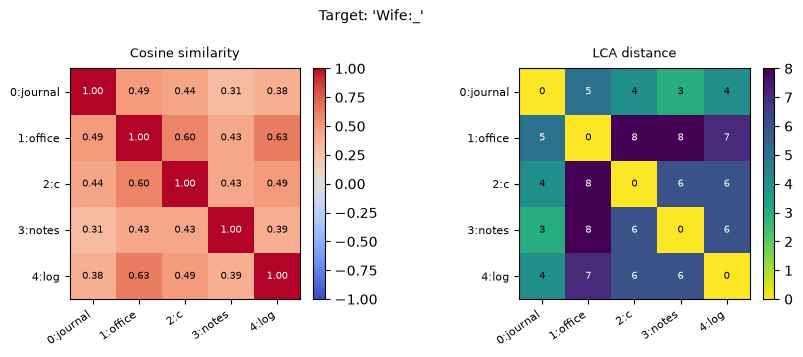


Context: '_Vicar's Wife:_ "What are you' | Target: 'children'
Top-5        |      0:going |    1:talking |   2:thinking |    3:looking |     4:saying
---------------------------------------------------------------------------------------
0:going      |       1.0000 |       0.7780 |       0.7724 |       0.8197 |       0.8609
1:talking    |       0.7780 |       1.0000 |       0.8826 |       0.8535 |       0.8389
2:thinking   |       0.7724 |       0.8826 |       1.0000 |       0.8298 |       0.8369
3:looking    |       0.8197 |       0.8535 |       0.8298 |       1.0000 |       0.8202
4:saying     |       0.8609 |       0.8389 |       0.8369 |       0.8202 |       1.0000


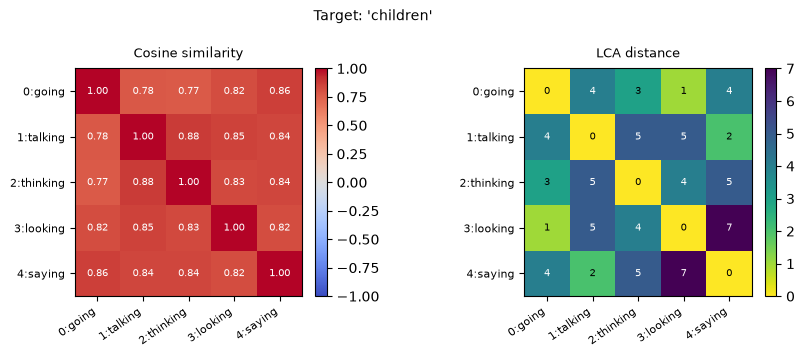


Context: '_Vicar's Wife:_ "What are you children doing in' | Target: 'daddy's'
Top-5        |     0:town |    1:front |   2:church |      3:bed |       4:mr
-----------------------------------------------------------------------------
0:town       |     1.0000 |     0.5963 |     0.4202 |     0.5946 |     0.5595
1:front      |     0.5963 |     1.0000 |     0.3504 |     0.6621 |     0.7176
2:church     |     0.4202 |     0.3504 |     1.0000 |     0.3759 |     0.2957
3:bed        |     0.5946 |     0.6621 |     0.3759 |     1.0000 |     0.6174
4:mr         |     0.5595 |     0.7176 |     0.2957 |     0.6174 |     1.0000


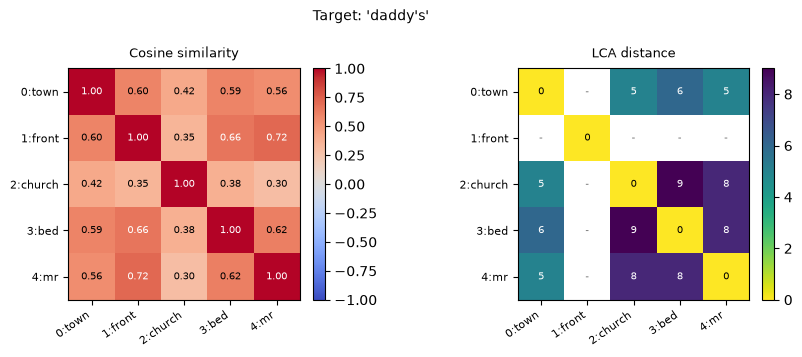


Context: '_Vicar's Wife:_ "What are you children doing in daddy's' | Target: 'study?"'
Top-5        |      0:study |       1:room |     2:office |   3:workshop |     4:garden
---------------------------------------------------------------------------------------
0:study      |       1.0000 |       0.7597 |       0.7169 |       0.7412 |       0.5515
1:room       |       0.7597 |       1.0000 |       0.7851 |       0.7157 |       0.5396
2:office     |       0.7169 |       0.7851 |       1.0000 |       0.6733 |       0.5684
3:workshop   |       0.7412 |       0.7157 |       0.6733 |       1.0000 |       0.5722
4:garden     |       0.5515 |       0.5396 |       0.5684 |       0.5722 |       1.0000


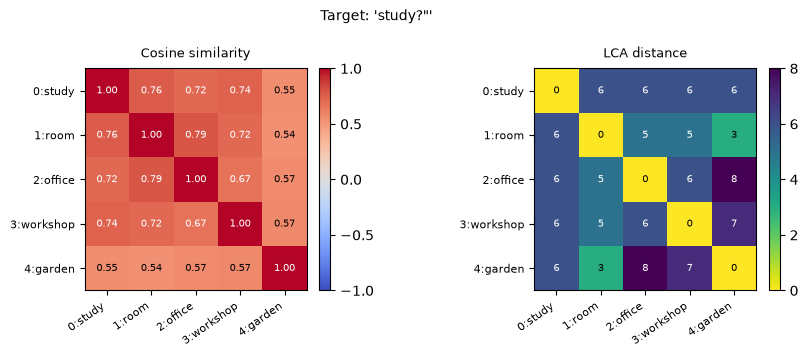


Context: '_Ethel:_ "It's a' | Target: 'great'
Top-5        |     0:good |    1:great |      2:bit |   3:little |     4:nice
-----------------------------------------------------------------------------
0:good       |     1.0000 |     0.7382 |     0.5043 |     0.5371 |     0.7113
1:great      |     0.7382 |     1.0000 |     0.6148 |     0.6254 |     0.7299
2:bit        |     0.5043 |     0.6148 |     1.0000 |     0.6506 |     0.6423
3:little     |     0.5371 |     0.6254 |     0.6506 |     1.0000 |     0.7112
4:nice       |     0.7113 |     0.7299 |     0.6423 |     0.7112 |     1.0000


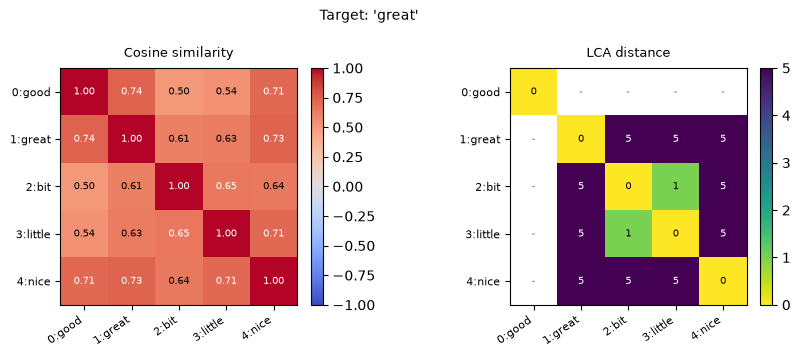


Context: '_Ethel:_ "It's a great' | Target: 'secret,'
Top-5        |     0:idea |      1:day |    2:honor |     3:pity |    4:place
-----------------------------------------------------------------------------
0:idea       |     1.0000 |     0.5347 |     0.6405 |     0.6266 |     0.6944
1:day        |     0.5347 |     1.0000 |     0.5651 |     0.4989 |     0.5275
2:honor      |     0.6405 |     0.5651 |     1.0000 |     0.6224 |     0.6341
3:pity       |     0.6266 |     0.4989 |     0.6224 |     1.0000 |     0.5791
4:place      |     0.6944 |     0.5275 |     0.6341 |     0.5791 |     1.0000


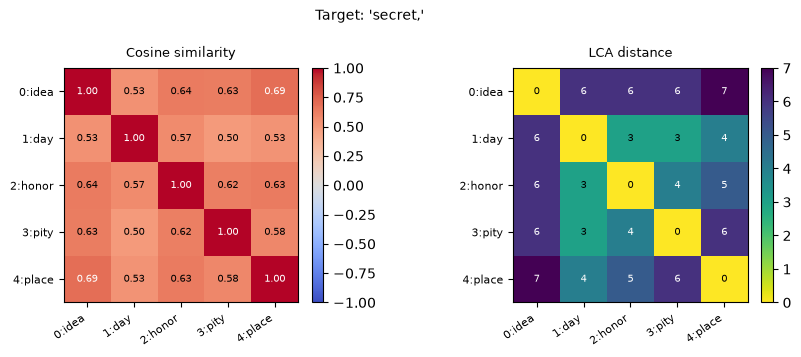


Context: '_Ethel:_ "It's a great secret,' | Target: 'Mummy.'
Top-5        |      0:dear |   1:darling |    2:really |    3:though |        4:mr
----------------------------------------------------------------------------------
0:dear       |      1.0000 |      0.6839 |      0.6306 |      0.5308 |      0.6596
1:darling    |      0.6839 |      1.0000 |      0.7292 |      0.6255 |      0.7499
2:really     |      0.6306 |      0.7292 |      1.0000 |      0.6871 |      0.6748
3:though     |      0.5308 |      0.6255 |      0.6871 |      1.0000 |      0.6001
4:mr         |      0.6596 |      0.7499 |      0.6748 |      0.6001 |      1.0000


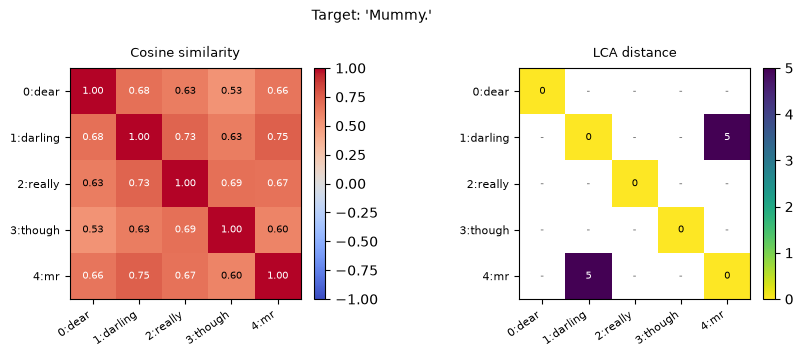


Context: 'We're' | Target: 'giving'
Top-5        |      0:using |    1:looking |      2:going |      3:given |   4:building
---------------------------------------------------------------------------------------
0:using      |       1.0000 |       0.6137 |       0.6690 |       0.7520 |       0.5223
1:looking    |       0.6137 |       1.0000 |       0.8197 |       0.6831 |       0.5656
2:going      |       0.6690 |       0.8197 |       1.0000 |       0.7373 |       0.5858
3:given      |       0.7520 |       0.6831 |       0.7373 |       1.0000 |       0.5311
4:building   |       0.5223 |       0.5656 |       0.5858 |       0.5311 |       1.0000


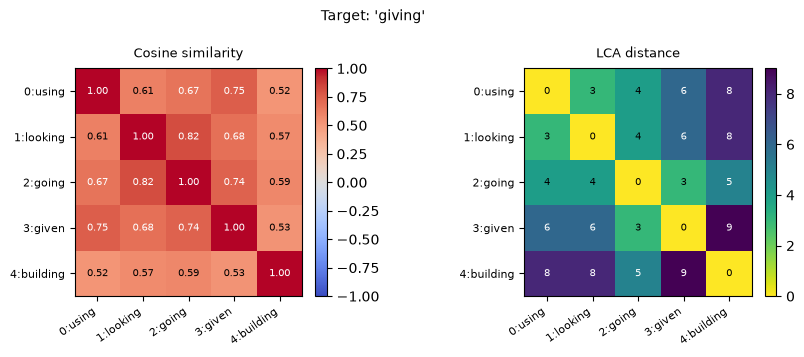


Context: 'We're giving' | Target: 'daddy'
Top-5        |       0:back |   1:everyone |     2:thanks |       3:free |      4:three
---------------------------------------------------------------------------------------
0:back       |       1.0000 |       0.6967 |       0.5231 |       0.6492 |       0.5920
1:everyone   |       0.6967 |       1.0000 |       0.5930 |       0.7540 |       0.5587
2:thanks     |       0.5231 |       0.5930 |       1.0000 |       0.5590 |       0.4443
3:free       |       0.6492 |       0.7540 |       0.5590 |       1.0000 |       0.5594
4:three      |       0.5920 |       0.5587 |       0.4443 |       0.5594 |       1.0000


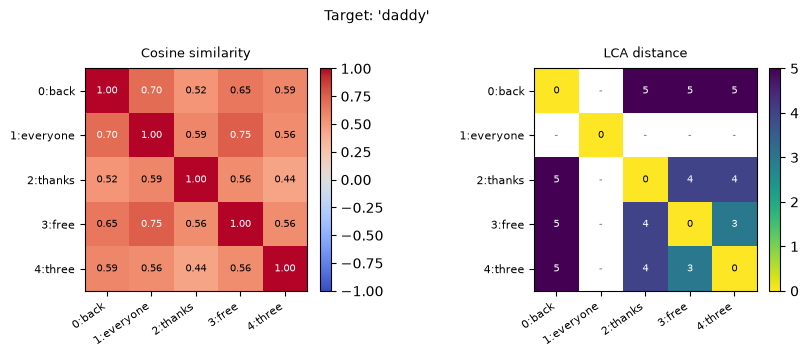


Context: 'We're giving daddy a new' | Target: 'bible'
Top-5        |       0:look |       1:name |      2:title |        3:toy |   4:nickname
---------------------------------------------------------------------------------------
0:look       |       1.0000 |       0.7193 |       0.4097 |       0.6799 |       0.6796
1:name       |       0.7193 |       1.0000 |       0.5576 |       0.7593 |       0.8136
2:title      |       0.4097 |       0.5576 |       1.0000 |       0.5076 |       0.5164
3:toy        |       0.6799 |       0.7593 |       0.5076 |       1.0000 |       0.8377
4:nickname   |       0.6796 |       0.8136 |       0.5164 |       0.8377 |       1.0000


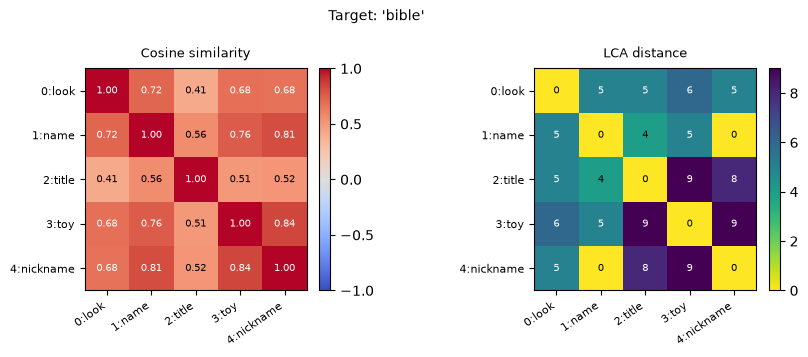


Context: 'We're giving daddy a new bible for his' | Target: 'birthday."'
Top-5           |      0:birthday |   1:anniversary |          2:book |         3:study |             4:b
---------------------------------------------------------------------------------------------------------
0:birthday      |          1.0000 |          0.6973 |          0.5714 |          0.6286 |          0.3928
1:anniversary   |          0.6973 |          1.0000 |          0.4867 |          0.6090 |          0.4622
2:book          |          0.5714 |          0.4867 |          1.0000 |          0.5744 |          0.3524
3:study         |          0.6286 |          0.6090 |          0.5744 |          1.0000 |          0.5630
4:b             |          0.3928 |          0.4622 |          0.3524 |          0.5630 |          1.0000


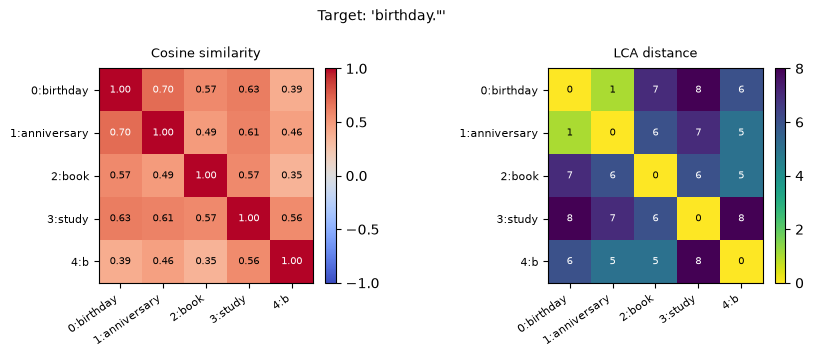


Context: '_Vicar's' | Target: 'Wife:_'
Top-5        |   0:journal |    1:office |         2:c |     3:notes |       4:log
----------------------------------------------------------------------------------
0:journal    |      1.0000 |      0.4918 |      0.4370 |      0.3112 |      0.3771
1:office     |      0.4918 |      1.0000 |      0.5980 |      0.4293 |      0.6294
2:c          |      0.4370 |      0.5980 |      1.0000 |      0.4285 |      0.4886
3:notes      |      0.3112 |      0.4293 |      0.4285 |      1.0000 |      0.3852
4:log        |      0.3771 |      0.6294 |      0.4886 |      0.3852 |      1.0000


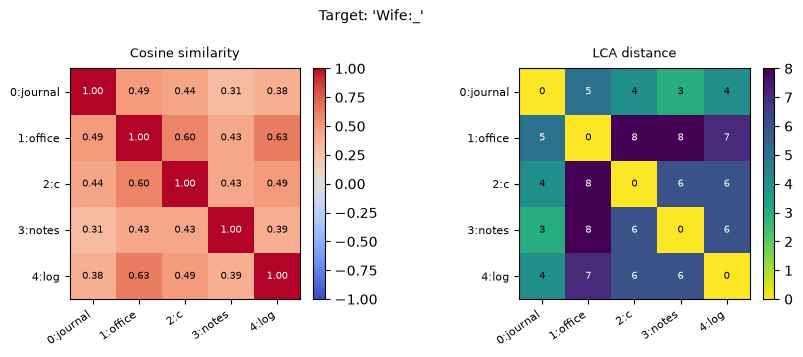


Context: '_Vicar's Wife:_' | Target: '"Oh--and'
Top-5        |      0:yes |       1:oh |     2:good |      3:mrs |       4:ah
-----------------------------------------------------------------------------
0:yes        |     1.0000 |     0.7699 |     0.5885 |     0.6320 |     0.7327
1:oh         |     0.7699 |     1.0000 |     0.5731 |     0.6822 |     0.9006
2:good       |     0.5885 |     0.5731 |     1.0000 |     0.5487 |     0.5933
3:mrs        |     0.6320 |     0.6822 |     0.5487 |     1.0000 |     0.6534
4:ah         |     0.7327 |     0.9006 |     0.5933 |     0.6534 |     1.0000


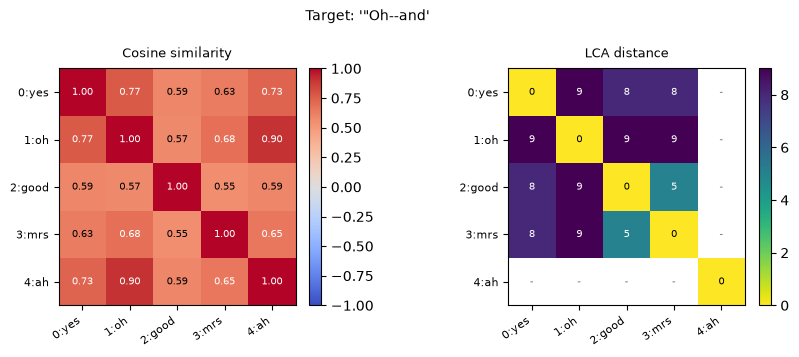


Context: '_Vicar's Wife:_ "Oh--and what are you' | Target: 'writing'
Top-5        |      0:going |   1:planning |   2:thinking |    3:wearing |    4:writing
---------------------------------------------------------------------------------------
0:going      |       1.0000 |       0.6723 |       0.7724 |       0.8107 |       0.7084
1:planning   |       0.6723 |       1.0000 |       0.7893 |       0.7625 |       0.8060
2:thinking   |       0.7724 |       0.7893 |       1.0000 |       0.8018 |       0.7973
3:wearing    |       0.8107 |       0.7625 |       0.8018 |       1.0000 |       0.7434
4:writing    |       0.7084 |       0.8060 |       0.7973 |       0.7434 |       1.0000


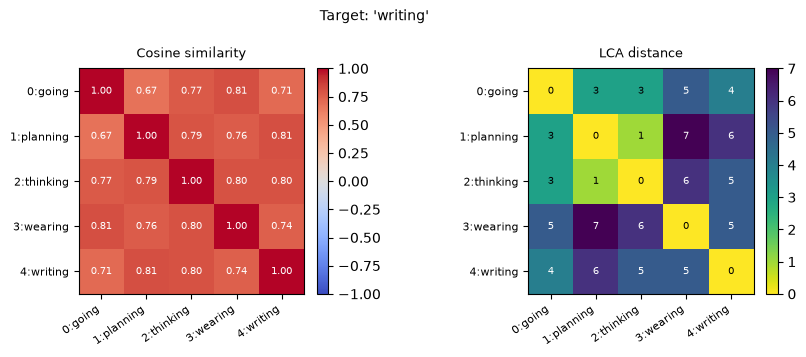


Context: '_Ethel:_ "Well, you' | Target: 'see,'
Top-5         |        0:know |         1:see |       2:never |   3:certainly |        4:look
---------------------------------------------------------------------------------------------
0:know        |        1.0000 |        0.7738 |        0.7240 |        0.5379 |        0.7639
1:see         |        0.7738 |        1.0000 |        0.6589 |        0.5278 |        0.6646
2:never       |        0.7240 |        0.6589 |        1.0000 |        0.6453 |        0.6912
3:certainly   |        0.5379 |        0.5278 |        0.6453 |        1.0000 |        0.5000
4:look        |        0.7639 |        0.6646 |        0.6912 |        0.5000 |        1.0000


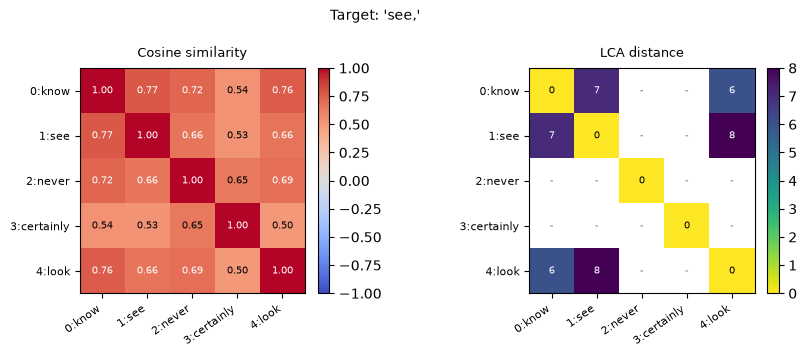


Context: '_Ethel:_ "Well, you see, we' | Target: 'thought'
Top-5        |      0:need |      1:want |    2:always |   3:thought |      4:live
----------------------------------------------------------------------------------
0:need       |      1.0000 |      0.8792 |      0.7632 |      0.6897 |      0.5446
1:want       |      0.8792 |      1.0000 |      0.7077 |      0.6708 |      0.5386
2:always     |      0.7632 |      0.7077 |      1.0000 |      0.6650 |      0.5559
3:thought    |      0.6897 |      0.6708 |      0.6650 |      1.0000 |      0.5067
4:live       |      0.5446 |      0.5386 |      0.5559 |      0.5067 |      1.0000


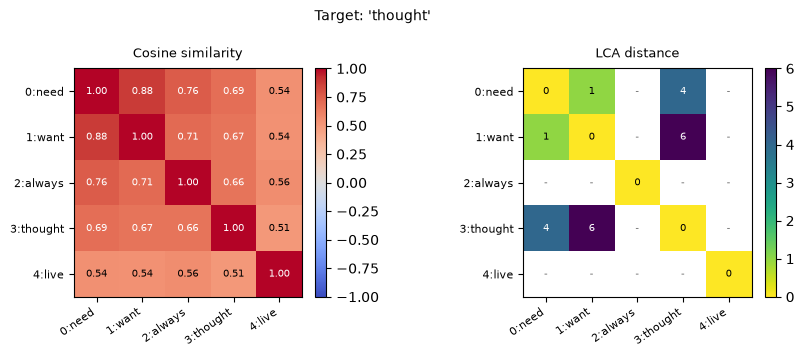


Context: '_Ethel:_ "Well, you see, we thought' | Target: 'we'd'
Top-5        |     0:maybe |     1:since |   2:perhaps |   3:someone |        4:mr
----------------------------------------------------------------------------------
0:maybe      |      1.0000 |      0.4991 |      0.8111 |      0.7003 |      0.5715
1:since      |      0.4991 |      1.0000 |      0.3912 |      0.6429 |      0.6112
2:perhaps    |      0.8111 |      0.3912 |      1.0000 |      0.5444 |      0.4360
3:someone    |      0.7003 |      0.6429 |      0.5444 |      1.0000 |      0.7268
4:mr         |      0.5715 |      0.6112 |      0.4360 |      0.7268 |      1.0000


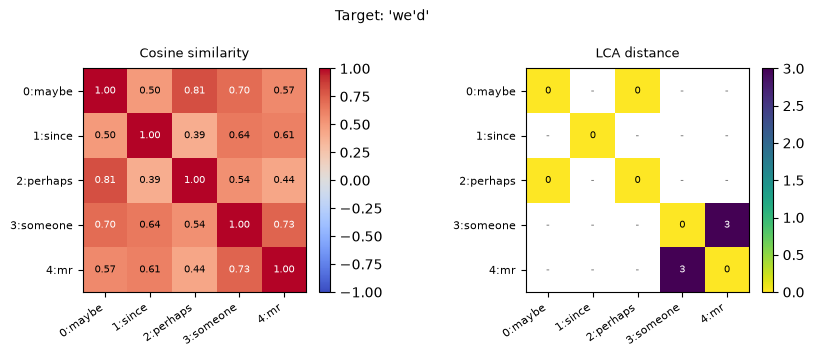


Context: '_Ethel:_ "Well, you see, we thought we'd' | Target: 'better'
Top-5        |   0:better |     1:give |      2:try |    3:start |     4:take
-----------------------------------------------------------------------------
0:better     |     1.0000 |     0.6048 |     0.5511 |     0.3568 |     0.5963
1:give       |     0.6048 |     1.0000 |     0.7308 |     0.5584 |     0.8652
2:try        |     0.5511 |     0.7308 |     1.0000 |     0.5217 |     0.7304
3:start      |     0.3568 |     0.5584 |     0.5217 |     1.0000 |     0.5291
4:take       |     0.5963 |     0.8652 |     0.7304 |     0.5291 |     1.0000


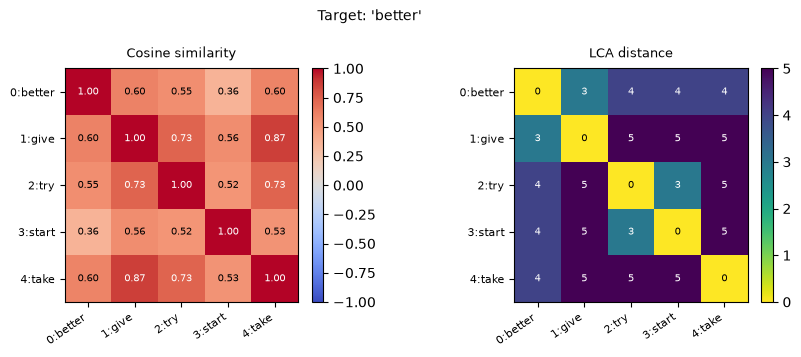


Context: '_Ethel:_ "Well, you see, we thought we'd better' | Target: 'copy'
Top-5        |     0:tell |     1:take |     2:come |      3:let |     4:keep
-----------------------------------------------------------------------------
0:tell       |     1.0000 |     0.7883 |     0.7066 |     0.6276 |     0.7161
1:take       |     0.7883 |     1.0000 |     0.7544 |     0.7485 |     0.7840
2:come       |     0.7066 |     0.7544 |     1.0000 |     0.6770 |     0.7189
3:let        |     0.6276 |     0.7485 |     0.6770 |     1.0000 |     0.7010
4:keep       |     0.7161 |     0.7840 |     0.7189 |     0.7010 |     1.0000


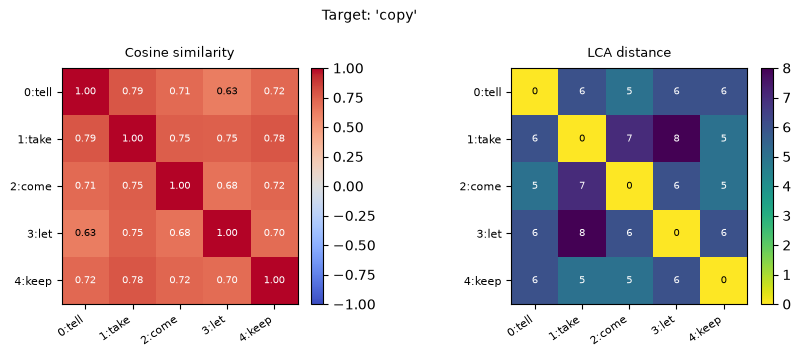


Context: '_Ethel:_ "Well, you see, we thought we'd better copy what' | Target: 'daddy's'
Top-5         |    0:everyone |          1:mr |   2:everybody |      3:people |      4:others
---------------------------------------------------------------------------------------------
0:everyone    |        1.0000 |        0.7356 |        0.9399 |        0.7999 |        0.7666
1:mr          |        0.7356 |        1.0000 |        0.7683 |        0.6543 |        0.6331
2:everybody   |        0.9399 |        0.7683 |        1.0000 |        0.7599 |        0.7490
3:people      |        0.7999 |        0.6543 |        0.7599 |        1.0000 |        0.7555
4:others      |        0.7666 |        0.6331 |        0.7490 |        0.7555 |        1.0000


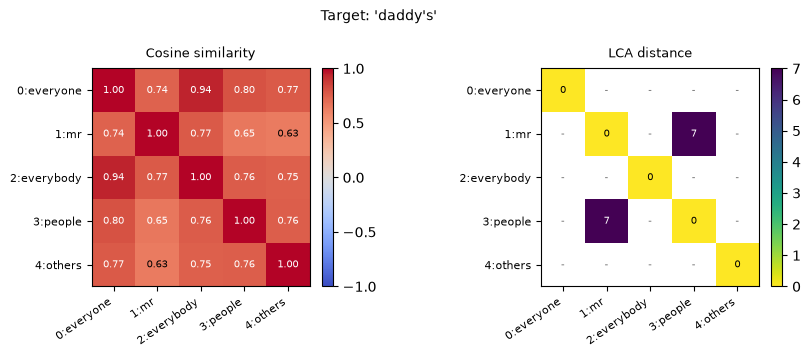


Context: '_Ethel:_ "Well, you see, we thought we'd better copy what daddy's' | Target: 'friends'
Top-5        |    0:company |    1:friends |     2:people |   3:business |       4:firm
---------------------------------------------------------------------------------------
0:company    |       1.0000 |       0.6663 |       0.6706 |       0.6420 |       0.7397
1:friends    |       0.6663 |       1.0000 |       0.7760 |       0.6211 |       0.7126
2:people     |       0.6706 |       0.7760 |       1.0000 |       0.6807 |       0.6729
3:business   |       0.6420 |       0.6211 |       0.6807 |       1.0000 |       0.6339
4:firm       |       0.7397 |       0.7126 |       0.6729 |       0.6339 |       1.0000


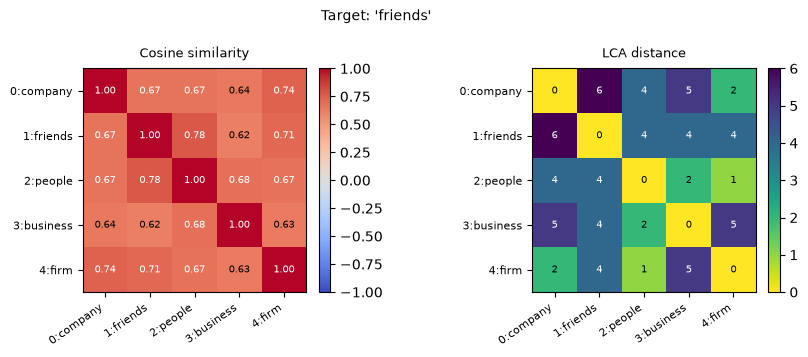


Context: '_Ethel:_ "Well, you see, we thought we'd better copy what daddy's friends' | Target: 'put'
Top-5        |     0:wear |     1:call |   2:always |      3:use |     4:copy
-----------------------------------------------------------------------------
0:wear       |     1.0000 |     0.6684 |     0.7334 |     0.7076 |     0.5239
1:call       |     0.6684 |     1.0000 |     0.6400 |     0.6653 |     0.5417
2:always     |     0.7334 |     0.6400 |     1.0000 |     0.6350 |     0.5427
3:use        |     0.7076 |     0.6653 |     0.6350 |     1.0000 |     0.5889
4:copy       |     0.5239 |     0.5417 |     0.5427 |     0.5889 |     1.0000


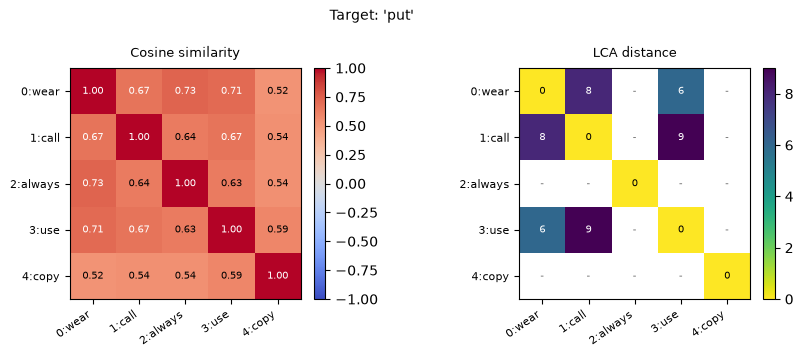


Context: '_Ethel:_ "Well, you see, we thought we'd better copy what daddy's friends put in the' | Target: 'books'
Top-5          |    0:newspaper |       1:papers |        2:paper |   3:newspapers |     4:envelope
---------------------------------------------------------------------------------------------------
0:newspaper    |         1.0000 |         0.5617 |         0.5712 |         0.8017 |         0.4042
1:papers       |         0.5617 |         1.0000 |         0.7160 |         0.5516 |         0.5536
2:paper        |         0.5712 |         0.7160 |         1.0000 |         0.5034 |         0.6934
3:newspapers   |         0.8017 |         0.5516 |         0.5034 |         1.0000 |         0.3045
4:envelope     |         0.4042 |         0.5536 |         0.6934 |         0.3045 |         1.0000


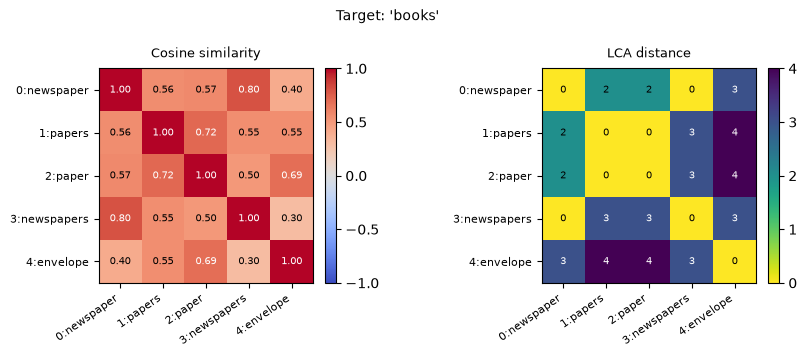


Context: '_Ethel:_ "Well, you see, we thought we'd better copy what daddy's friends put in the books they' | Target: 'give'
Top-5        |    0:wrote |    1:write |     2:read |     3:gave |     4:give
-----------------------------------------------------------------------------
0:wrote      |     1.0000 |     0.6851 |     0.7088 |     0.7657 |     0.6763
1:write      |     0.6851 |     1.0000 |     0.7988 |     0.6299 |     0.7412
2:read       |     0.7088 |     0.7988 |     1.0000 |     0.7145 |     0.7721
3:gave       |     0.7657 |     0.6299 |     0.7145 |     1.0000 |     0.8647
4:give       |     0.6763 |     0.7412 |     0.7721 |     0.8647 |     1.0000


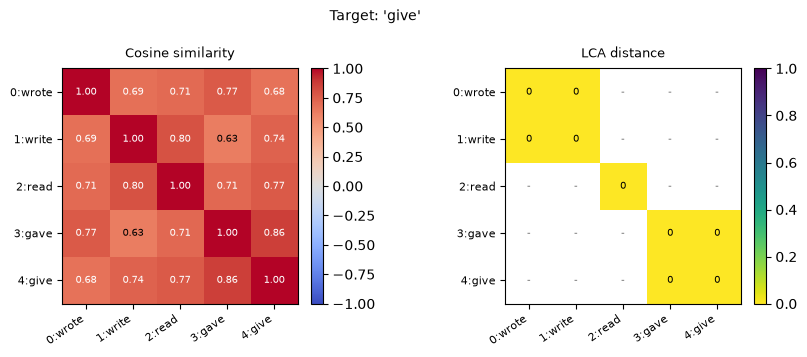


Context: '_Ethel:_ "Well, you see, we thought we'd better copy what daddy's friends put in the books they give him, so we're' | Target: 'writing,'
Top-5        |      0:going |    1:putting |    2:writing |    3:sending |   4:learning
---------------------------------------------------------------------------------------
0:going      |       1.0000 |       0.8410 |       0.7084 |       0.7750 |       0.7351
1:putting    |       0.8410 |       1.0000 |       0.7248 |       0.7981 |       0.7671
2:writing    |       0.7084 |       0.7248 |       1.0000 |       0.7246 |       0.7763
3:sending    |       0.7750 |       0.7981 |       0.7246 |       1.0000 |       0.7569
4:learning   |       0.7351 |       0.7671 |       0.7763 |       0.7569 |       1.0000


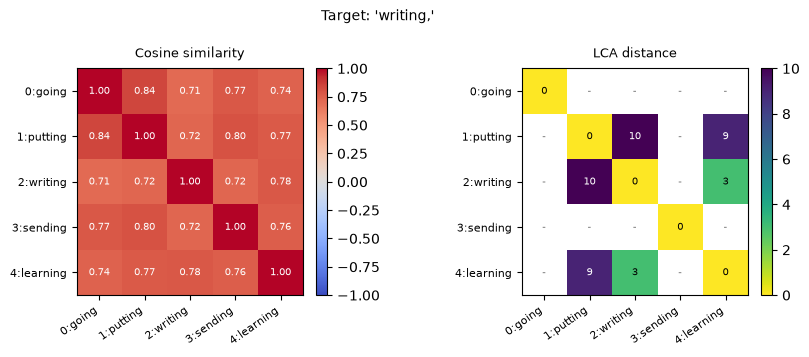


Context: '_Ethel:_ "Well, you see, we thought we'd better copy what daddy's friends put in the books they give him, so we're writing, 'With the' | Target: 'author's'
Top-5        |      0:best |      1:love |      2:warm |   3:deepest |       4:kin
----------------------------------------------------------------------------------
0:best       |      1.0000 |      0.5764 |      0.5704 |      0.7206 |      0.6391
1:love       |      0.5764 |      1.0000 |      0.5832 |      0.5882 |      0.5192
2:warm       |      0.5704 |      0.5832 |      1.0000 |      0.6958 |      0.6255
3:deepest    |      0.7206 |      0.5882 |      0.6958 |      1.0000 |      0.7932
4:kin        |      0.6391 |      0.5192 |      0.6255 |      0.7932 |      1.0000


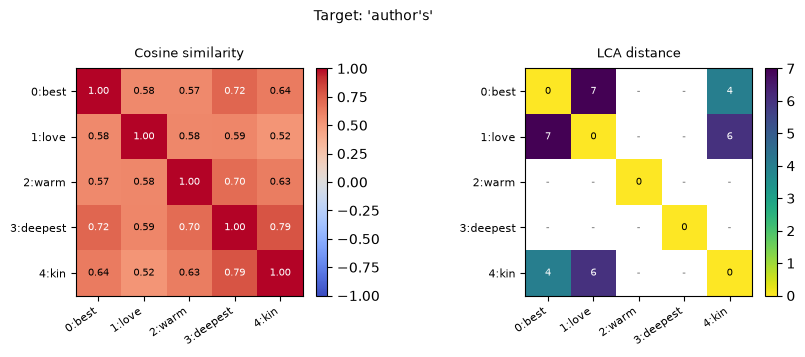


Context: '_Ethel:_ "Well, you see, we thought we'd better copy what daddy's friends put in the books they give him, so we're writing, 'With the author's' | Target: 'compliments.'"'
Top-5           |   0:compliments |    1:permission |          2:love |          3:best |          4:kind
---------------------------------------------------------------------------------------------------------
0:compliments   |          1.0000 |          0.6020 |          0.4916 |          0.5253 |          0.4841
1:permission    |          0.6020 |          1.0000 |          0.5970 |          0.6742 |          0.7397
2:love          |          0.4916 |          0.5970 |          1.0000 |          0.5764 |          0.5757
3:best          |          0.5253 |          0.6742 |          0.5764 |          1.0000 |          0.7345
4:kind          |          0.4841 |          0.7397 |          0.5757 |          0.7345 |          1.0000


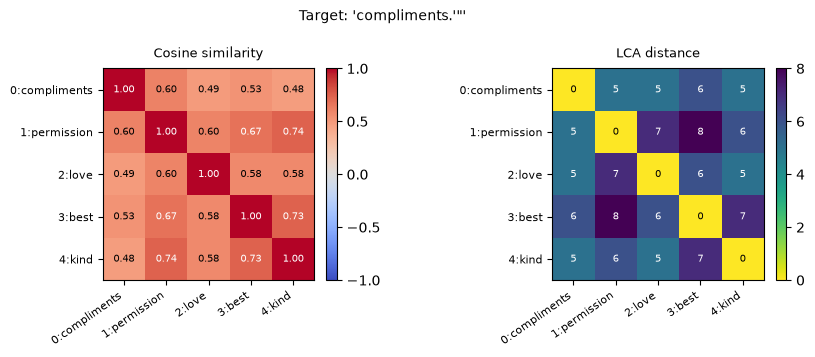


Context: '_George:_ "I' | Target: 'proposed'
Top-5        |    0:think |     1:want |     2:know |      3:see |     4:need
-----------------------------------------------------------------------------
0:think      |     1.0000 |     0.7300 |     0.7372 |     0.6476 |     0.6569
1:want       |     0.7300 |     1.0000 |     0.7659 |     0.6371 |     0.8792
2:know       |     0.7372 |     0.7659 |     1.0000 |     0.7738 |     0.7421
3:see        |     0.6476 |     0.6371 |     0.7738 |     1.0000 |     0.6363
4:need       |     0.6569 |     0.8792 |     0.7421 |     0.6363 |     1.0000


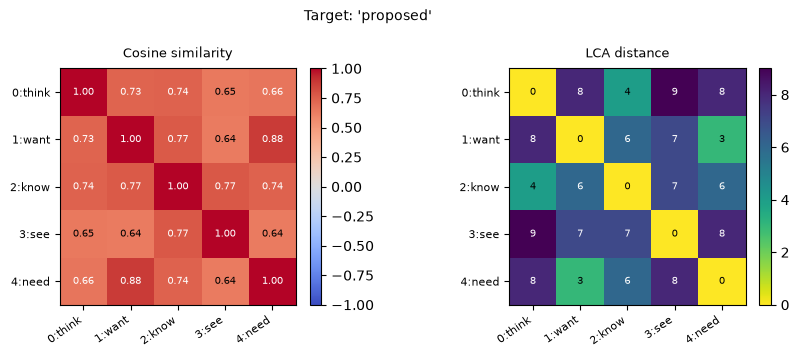


Context: '_George:_ "I proposed to that' | Target: 'girl'
Top-5        |     0:girl |    1:woman |     2:lady |     3:nice |   4:lovely
-----------------------------------------------------------------------------
0:girl       |     1.0000 |     0.8375 |     0.6566 |     0.7041 |     0.6984
1:woman      |     0.8375 |     1.0000 |     0.7029 |     0.6662 |     0.7103
2:lady       |     0.6566 |     0.7029 |     1.0000 |     0.6879 |     0.7324
3:nice       |     0.7041 |     0.6662 |     0.6879 |     1.0000 |     0.8298
4:lovely     |     0.6984 |     0.7103 |     0.7324 |     0.8298 |     1.0000


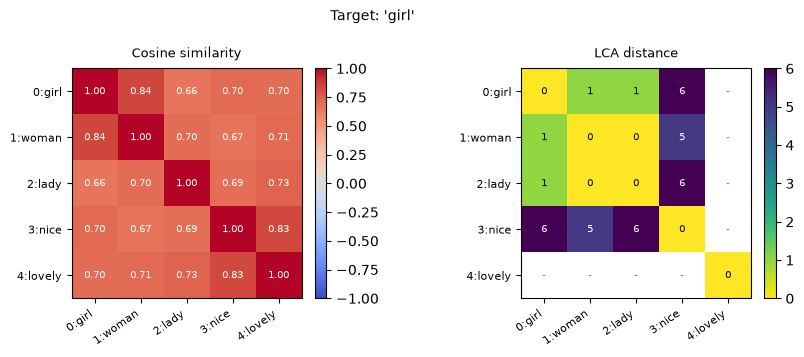


Context: '_George:_ "I proposed to that girl and would have' | Target: 'married'
Top-5        |    0:married |     1:gotten |     2:kissed |      3:given |   4:proposed
---------------------------------------------------------------------------------------
0:married    |       1.0000 |       0.6371 |       0.6105 |       0.6120 |       0.5565
1:gotten     |       0.6371 |       1.0000 |       0.6875 |       0.8344 |       0.5073
2:kissed     |       0.6105 |       0.6875 |       1.0000 |       0.5874 |       0.4820
3:given      |       0.6120 |       0.8344 |       0.5874 |       1.0000 |       0.5334
4:proposed   |       0.5565 |       0.5073 |       0.4820 |       0.5334 |       1.0000


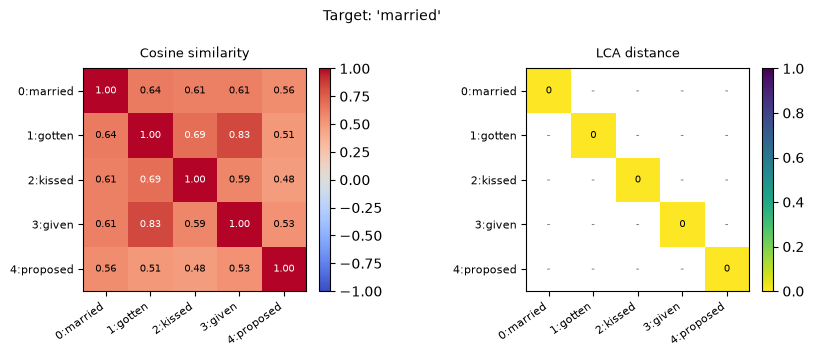


Context: '_George:_ "I proposed to that girl and would have married her if it' | Target: 'hadn't'
Top-5        |        0:n |      1:wer |    2:meant |     3:came |    4:still
-----------------------------------------------------------------------------
0:n          |     1.0000 |     0.4088 |     0.5516 |     0.5852 |     0.3564
1:wer        |     0.4088 |     1.0000 |     0.4369 |     0.5660 |     0.3614
2:meant      |     0.5516 |     0.4369 |     1.0000 |     0.6386 |     0.3676
3:came       |     0.5852 |     0.5660 |     0.6386 |     1.0000 |     0.4538
4:still      |     0.3564 |     0.3614 |     0.3676 |     0.4538 |     1.0000


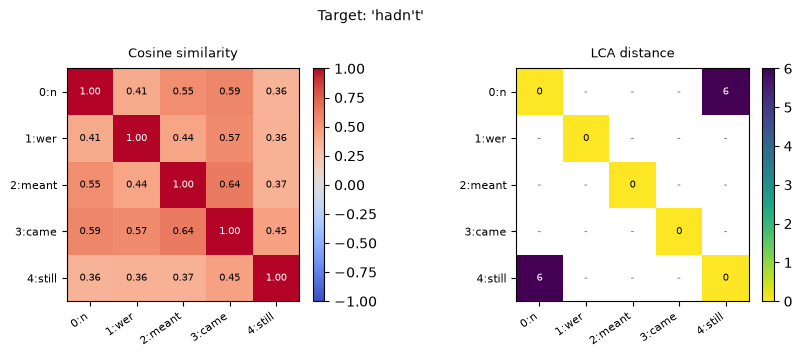


Context: '_George:_ "I proposed to that girl and would have married her if it hadn't been for' | Target: 'something'
Top-5         |   0:something |      1:family |        2:mary |       3:money |         4:tom
---------------------------------------------------------------------------------------------
0:something   |        1.0000 |        0.7600 |        0.7684 |        0.7282 |        0.6767
1:family      |        0.7600 |        1.0000 |        0.7569 |        0.7375 |        0.6523
2:mary        |        0.7684 |        0.7569 |        1.0000 |        0.7047 |        0.8053
3:money       |        0.7282 |        0.7375 |        0.7047 |        1.0000 |        0.6285
4:tom         |        0.6767 |        0.6523 |        0.8053 |        0.6285 |        1.0000


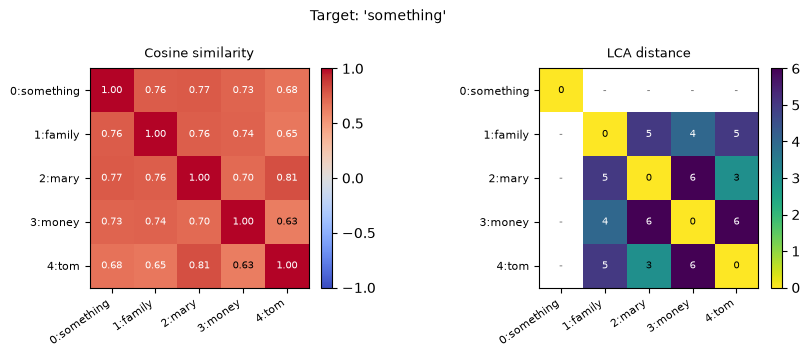


Context: 'Let us' | Target: 'change'
Top-5        |   0:consider |     1:define |     2:assume |       3:call |     4:denote
---------------------------------------------------------------------------------------
0:consider   |       1.0000 |       0.7733 |       0.6406 |       0.6241 |       0.6828
1:define     |       0.7733 |       1.0000 |       0.7663 |       0.5411 |       0.7424
2:assume     |       0.6406 |       0.7663 |       1.0000 |       0.3848 |       0.6481
3:call       |       0.6241 |       0.5411 |       0.3848 |       1.0000 |       0.5461
4:denote     |       0.6828 |       0.7424 |       0.6481 |       0.5461 |       1.0000


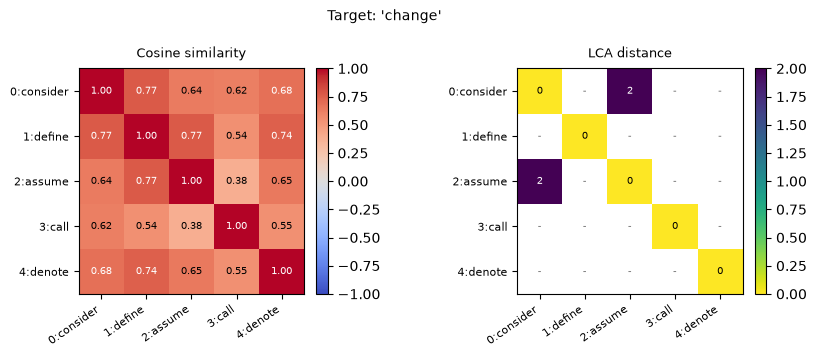


Context: 'Let us change the' | Target: 'subject.'
Top-5            |        0:problem |          1:given |       2:scenario |   3:coefficients |       4:function
---------------------------------------------------------------------------------------------------------------
0:problem        |           1.0000 |           0.6512 |           0.6632 |           0.6924 |           0.6799
1:given          |           0.6512 |           1.0000 |           0.5895 |           0.6736 |           0.6393
2:scenario       |           0.6632 |           0.5895 |           1.0000 |           0.6398 |           0.4812
3:coefficients   |           0.6924 |           0.6736 |           0.6398 |           1.0000 |           0.5904
4:function       |           0.6799 |           0.6393 |           0.4812 |           0.5904 |           1.0000


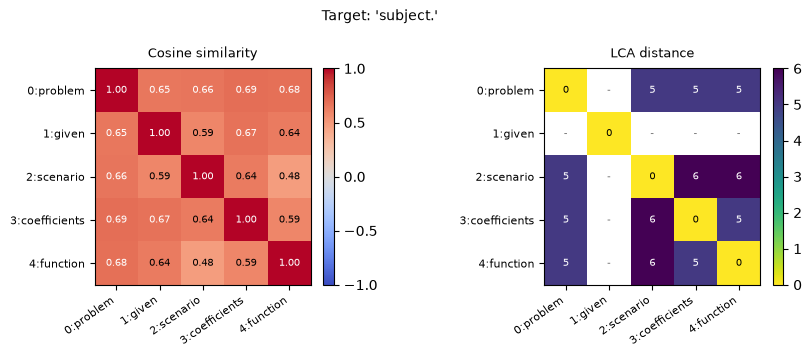


Context: 'I've done' | Target: 'nothing'
Top-5          |    0:something |   1:everything |     2:research |         3:lots |       4:plenty
---------------------------------------------------------------------------------------------------
0:something    |         1.0000 |         0.8056 |         0.6468 |         0.7379 |         0.7699
1:everything   |         0.8056 |         1.0000 |         0.6236 |         0.6731 |         0.6785
2:research     |         0.6468 |         0.6236 |         1.0000 |         0.5274 |         0.4933
3:lots         |         0.7379 |         0.6731 |         0.5274 |         1.0000 |         0.8514
4:plenty       |         0.7699 |         0.6785 |         0.4933 |         0.8514 |         1.0000


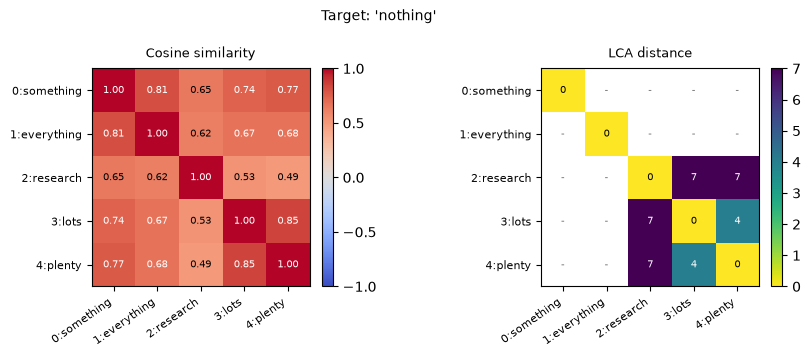


Context: 'I've done nothing but' | Target: 'talk'
Top-5        |     0:read |     1:good |     2:work |    3:study |      4:try
-----------------------------------------------------------------------------
0:read       |     1.0000 |     0.5326 |     0.7019 |     0.8034 |     0.7475
1:good       |     0.5326 |     1.0000 |     0.5320 |     0.5150 |     0.4923
2:work       |     0.7019 |     0.5320 |     1.0000 |     0.7379 |     0.6331
3:study      |     0.8034 |     0.5150 |     0.7379 |     1.0000 |     0.6648
4:try        |     0.7475 |     0.4923 |     0.6331 |     0.6648 |     1.0000


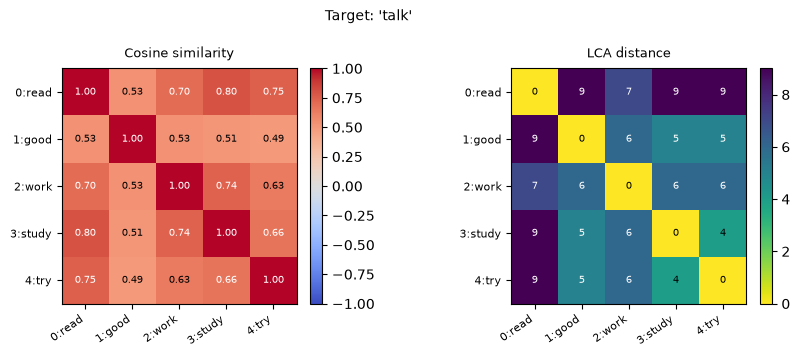


Context: 'I've done nothing but talk about myself all' | Target: 'evening."'
Top-5        |       0:day |     1:night |   2:evening |      3:week |   4:morning
----------------------------------------------------------------------------------
0:day        |      1.0000 |      0.6644 |      0.6815 |      0.6772 |      0.6557
1:night      |      0.6644 |      1.0000 |      0.6973 |      0.4966 |      0.6714
2:evening    |      0.6815 |      0.6973 |      1.0000 |      0.6197 |      0.7823
3:week       |      0.6772 |      0.4966 |      0.6197 |      1.0000 |      0.5472
4:morning    |      0.6557 |      0.6714 |      0.7823 |      0.5472 |      1.0000


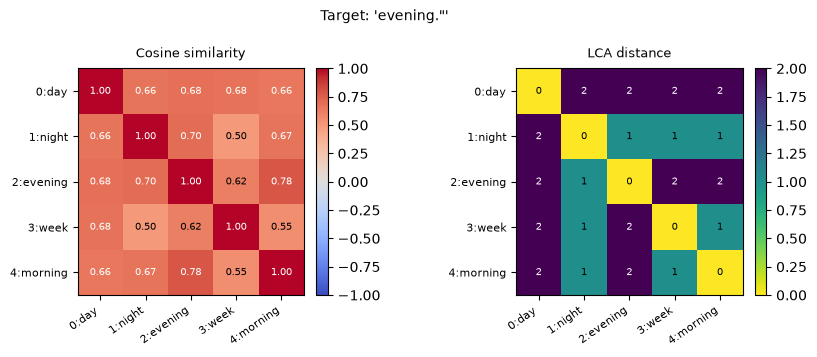


Context: '_He:_ "I'm sure we' | Target: 'couldn't'
Top-5        |     0:need |     1:know |    2:still |    3:never |    4:agree
-----------------------------------------------------------------------------
0:need       |     1.0000 |     0.7421 |     0.4444 |     0.7531 |     0.6695
1:know       |     0.7421 |     1.0000 |     0.3735 |     0.7240 |     0.7351
2:still      |     0.4444 |     0.3735 |     1.0000 |     0.5003 |     0.3655
3:never      |     0.7531 |     0.7240 |     0.5003 |     1.0000 |     0.6879
4:agree      |     0.6695 |     0.7351 |     0.3655 |     0.6879 |     1.0000


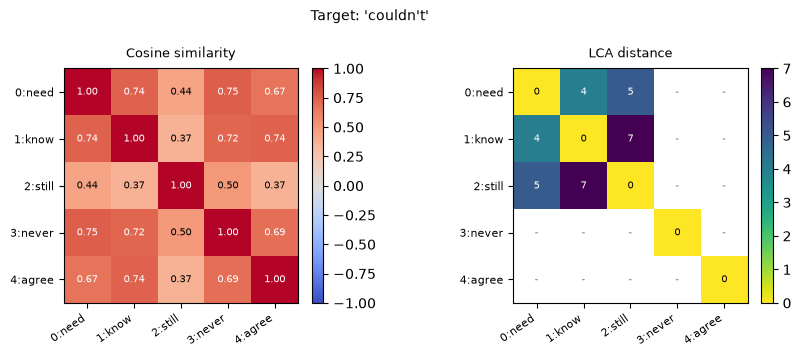


Context: '_He:_ "I'm sure we couldn't' | Target: 'find'
Top-5        |   0:possibly |       1:find |     2:afford |     3:manage |       4:live
---------------------------------------------------------------------------------------
0:possibly   |       1.0000 |       0.6001 |       0.6972 |       0.6941 |       0.5778
1:find       |       0.6001 |       1.0000 |       0.6448 |       0.6961 |       0.5387
2:afford     |       0.6972 |       0.6448 |       1.0000 |       0.7342 |       0.5061
3:manage     |       0.6941 |       0.6961 |       0.7342 |       1.0000 |       0.5896
4:live       |       0.5778 |       0.5387 |       0.5061 |       0.5896 |       1.0000


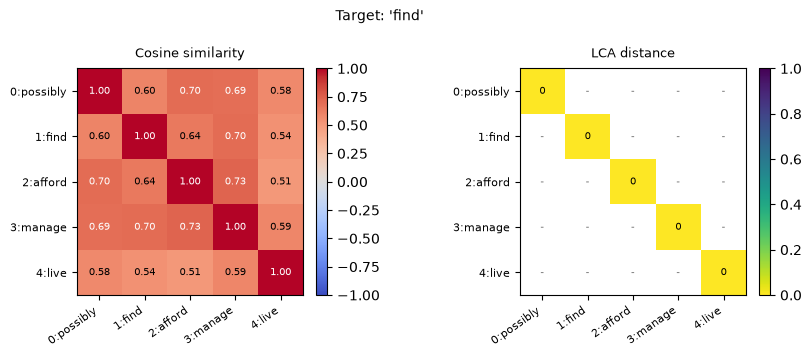


Context: '_He:_ "I'm sure we couldn't find' | Target: 'anything'
Top-5        |   0:anything |     1:anyone |     2:enough |     3:better |    4:someone
---------------------------------------------------------------------------------------
0:anything   |       1.0000 |       0.8400 |       0.6013 |       0.5859 |       0.7893
1:anyone     |       0.8400 |       1.0000 |       0.5607 |       0.5646 |       0.8700
2:enough     |       0.6013 |       0.5607 |       1.0000 |       0.5577 |       0.6400
3:better     |       0.5859 |       0.5646 |       0.5577 |       1.0000 |       0.6134
4:someone    |       0.7893 |       0.8700 |       0.6400 |       0.6134 |       1.0000


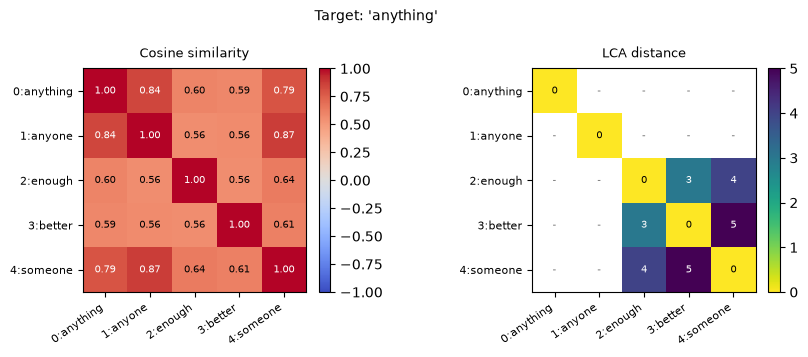


Context: '_He:_ "I'm sure we couldn't find anything' | Target: 'better."'
Top-5        |    0:better |      1:else |     2:wrong |     3:worse |   4:without
----------------------------------------------------------------------------------
0:better     |      1.0000 |      0.5668 |      0.5976 |      0.7743 |      0.6195
1:else       |      0.5668 |      1.0000 |      0.5750 |      0.5681 |      0.6758
2:wrong      |      0.5976 |      0.5750 |      1.0000 |      0.6632 |      0.5914
3:worse      |      0.7743 |      0.5681 |      0.6632 |      1.0000 |      0.6676
4:without    |      0.6195 |      0.6758 |      0.5914 |      0.6676 |      1.0000


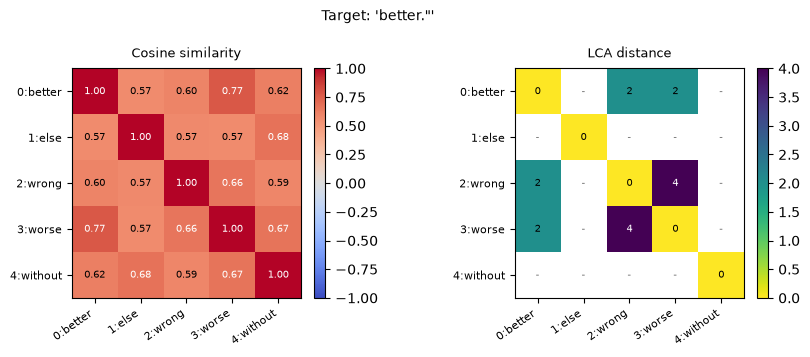


Context: 'Suppose _you_' | Target: 'talk'
Top-5        |      0:run |     1:work |    2:start |     3:want |   4:create
-----------------------------------------------------------------------------
0:run        |     1.0000 |     0.6210 |     0.5940 |     0.6523 |     0.6191
1:work       |     0.6210 |     1.0000 |     0.5313 |     0.6571 |     0.5895
2:start      |     0.5940 |     0.5313 |     1.0000 |     0.5154 |     0.5233
3:want       |     0.6523 |     0.6571 |     0.5154 |     1.0000 |     0.6418
4:create     |     0.6191 |     0.5895 |     0.5233 |     0.6418 |     1.0000


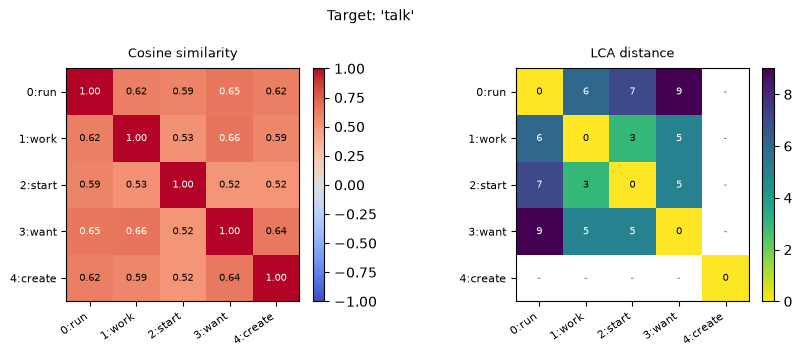


Context: '"I say,' | Target: 'Taxi,'
Top-5        |      0:let |      1:sir |       2:mr |     3:mate |    4:hello
-----------------------------------------------------------------------------
0:let        |     1.0000 |     0.5655 |     0.6096 |     0.5688 |     0.4299
1:sir        |     0.5655 |     1.0000 |     0.8238 |     0.6387 |     0.5838
2:mr         |     0.6096 |     0.8238 |     1.0000 |     0.6993 |     0.6039
3:mate       |     0.5688 |     0.6387 |     0.6993 |     1.0000 |     0.5398
4:hello      |     0.4299 |     0.5838 |     0.6039 |     0.5398 |     1.0000


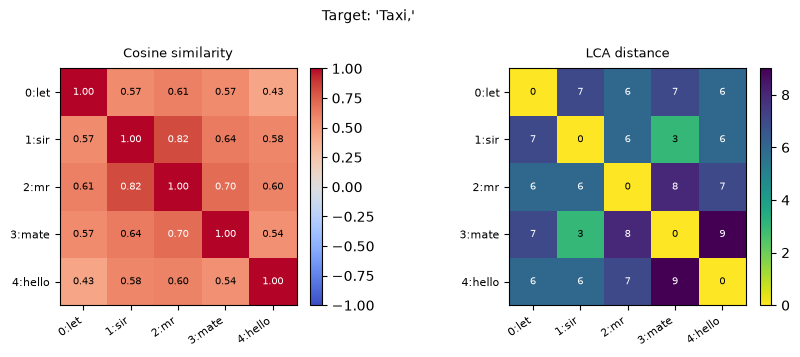


Context: '"I say, Taxi, I've only got' | Target: 'enough'
Top-5        |     0:five |      1:ten |   2:twenty |     3:time |    4:three
-----------------------------------------------------------------------------
0:five       |     1.0000 |     0.8481 |     0.8162 |     0.6828 |     0.8208
1:ten        |     0.8481 |     1.0000 |     0.8590 |     0.6300 |     0.6715
2:twenty     |     0.8162 |     0.8590 |     1.0000 |     0.6078 |     0.7065
3:time       |     0.6828 |     0.6300 |     0.6078 |     1.0000 |     0.6347
4:three      |     0.8208 |     0.6715 |     0.7065 |     0.6347 |     1.0000


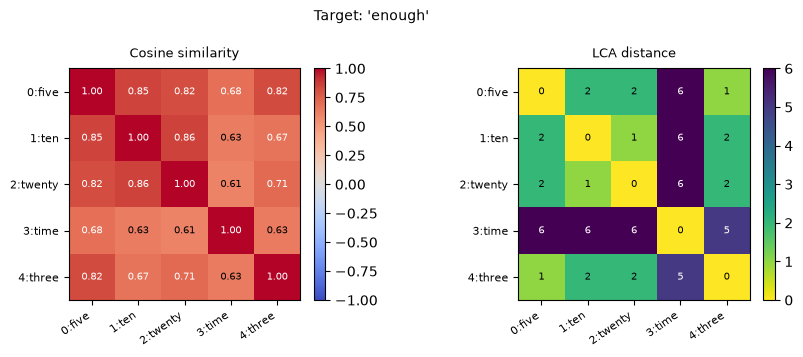


Context: '"I say, Taxi, I've only got enough' | Target: 'change'
Top-5        |    0:money |     1:cash |     2:fare |     3:time |   4:change
-----------------------------------------------------------------------------
0:money      |     1.0000 |     0.8060 |     0.5415 |     0.7431 |     0.6579
1:cash       |     0.8060 |     1.0000 |     0.6278 |     0.7834 |     0.6828
2:fare       |     0.5415 |     0.6278 |     1.0000 |     0.5950 |     0.5144
3:time       |     0.7431 |     0.7834 |     0.5950 |     1.0000 |     0.6757
4:change     |     0.6579 |     0.6828 |     0.5144 |     0.6757 |     1.0000


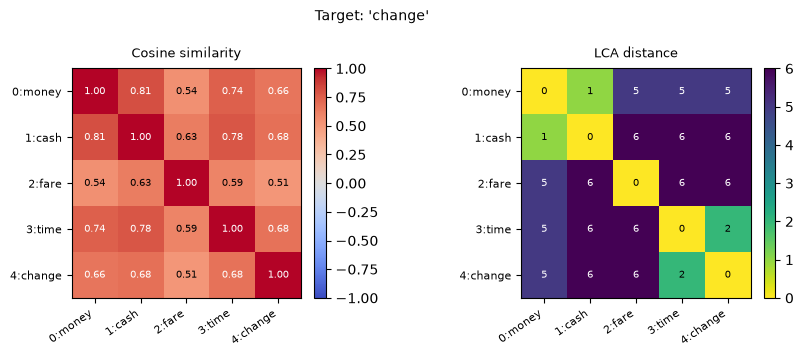


Context: '"I say, Taxi, I've only got enough change to' | Target: 'pay'
Top-5        |      0:pay |      1:buy |     2:give |     3:take |     4:fill
-----------------------------------------------------------------------------
0:pay        |     1.0000 |     0.7867 |     0.8300 |     0.8026 |     0.7974
1:buy        |     0.7867 |     1.0000 |     0.7865 |     0.7939 |     0.7795
2:give       |     0.8300 |     0.7865 |     1.0000 |     0.8652 |     0.8271
3:take       |     0.8026 |     0.7939 |     0.8652 |     1.0000 |     0.7860
4:fill       |     0.7974 |     0.7795 |     0.8271 |     0.7860 |     1.0000


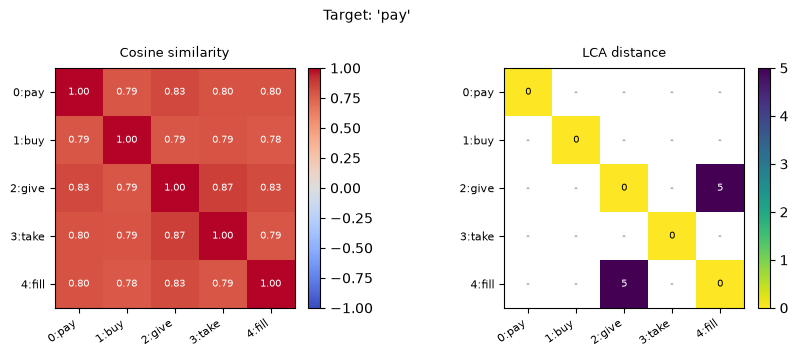


Context: '"I say, Taxi, I've only got enough change to pay the' | Target: 'exact'
Top-5        |    0:meter |     1:fare |   2:driver |    3:exact |     4:toll
-----------------------------------------------------------------------------
0:meter      |     1.0000 |     0.5986 |     0.6699 |     0.7459 |     0.6181
1:fare       |     0.5986 |     1.0000 |     0.5855 |     0.5955 |     0.6668
2:driver     |     0.6699 |     0.5855 |     1.0000 |     0.6424 |     0.6448
3:exact      |     0.7459 |     0.5955 |     0.6424 |     1.0000 |     0.6908
4:toll       |     0.6181 |     0.6668 |     0.6448 |     0.6908 |     1.0000


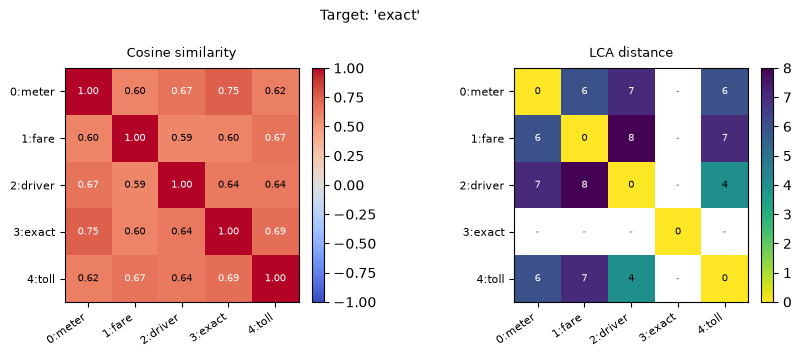


Context: '"I say, Taxi, I've only got enough change to pay the exact' | Target: 'fare.'
Top-5        |     0:fare |   1:amount |      2:sum |     3:toll |    4:price
-----------------------------------------------------------------------------
0:fare       |     1.0000 |     0.6263 |     0.5400 |     0.6668 |     0.6343
1:amount     |     0.6263 |     1.0000 |     0.7246 |     0.6586 |     0.7310
2:sum        |     0.5400 |     0.7246 |     1.0000 |     0.5059 |     0.5936
3:toll       |     0.6668 |     0.6586 |     0.5059 |     1.0000 |     0.6493
4:price      |     0.6343 |     0.7310 |     0.5936 |     0.6493 |     1.0000


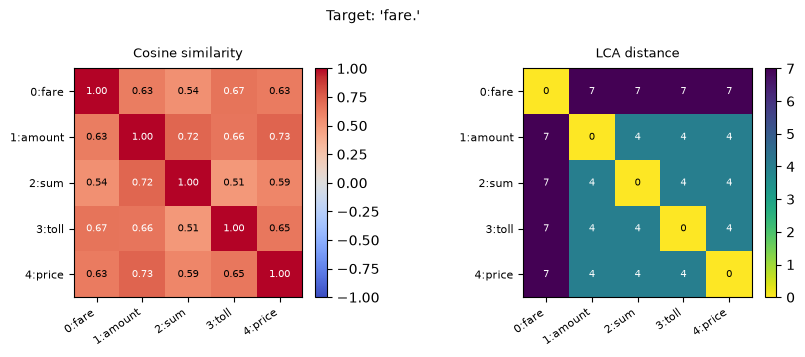


Context: 'D'you' | Target: 'mind'
Top-5        |       0:know |      1:think |       2:want |   3:remember |      4:wanna
---------------------------------------------------------------------------------------
0:know       |       1.0000 |       0.7372 |       0.7659 |       0.6623 |       0.7907
1:think      |       0.7372 |       1.0000 |       0.7300 |       0.6294 |       0.7486
2:want       |       0.7659 |       0.7300 |       1.0000 |       0.5700 |       0.7504
3:remember   |       0.6623 |       0.6294 |       0.5700 |       1.0000 |       0.6187
4:wanna      |       0.7907 |       0.7486 |       0.7504 |       0.6187 |       1.0000


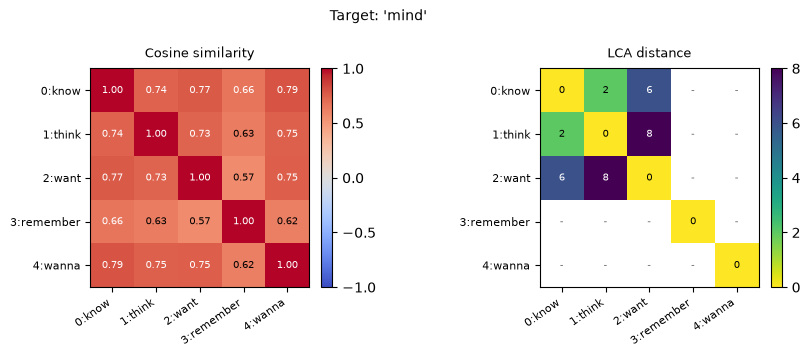


Context: 'D'you mind' | Target: 'taking'
Top-5          |   0:explaining |         1:tell |      2:explain |      3:telling |       4:giving
---------------------------------------------------------------------------------------------------
0:explaining   |         1.0000 |         0.7728 |         0.8876 |         0.9308 |         0.8727
1:tell         |         0.7728 |         1.0000 |         0.7784 |         0.8293 |         0.7768
2:explain      |         0.8876 |         0.7784 |         1.0000 |         0.8051 |         0.7927
3:telling      |         0.9308 |         0.8293 |         0.8051 |         1.0000 |         0.8775
4:giving       |         0.8727 |         0.7768 |         0.7927 |         0.8775 |         1.0000


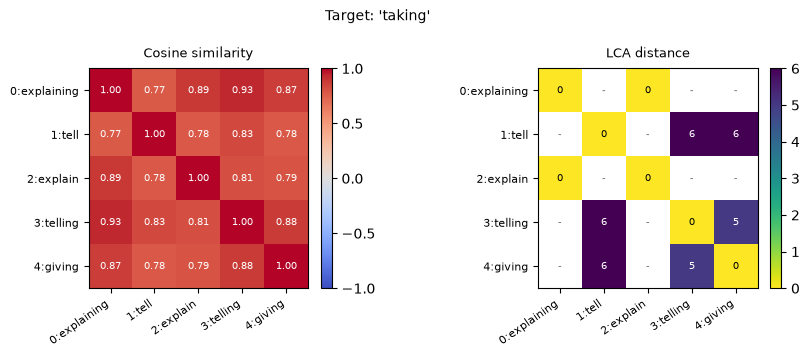


Context: 'D'you mind taking a' | Target: 'cheque'
Top-5          |         0:look |        1:quick |         2:peek |      3:picture |   4:screenshot
---------------------------------------------------------------------------------------------------
0:look         |         1.0000 |         0.7199 |         0.7802 |         0.7288 |         0.3224
1:quick        |         0.7199 |         1.0000 |         0.6976 |         0.6657 |         0.3669
2:peek         |         0.7802 |         0.6976 |         1.0000 |         0.6834 |         0.3044
3:picture      |         0.7288 |         0.6657 |         0.6834 |         1.0000 |         0.4746
4:screenshot   |         0.3224 |         0.3669 |         0.3044 |         0.4746 |         1.0000


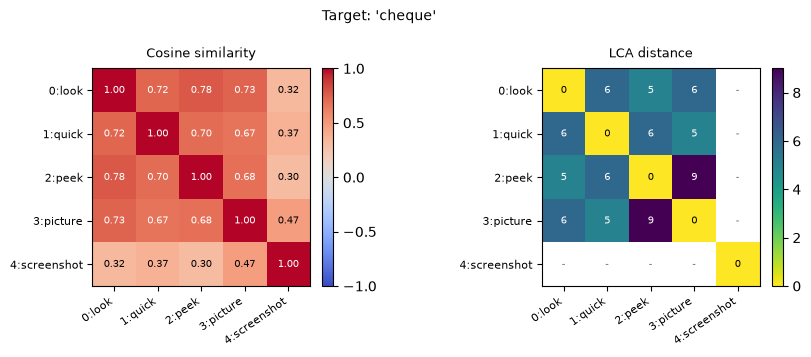


Context: 'D'you mind taking a cheque for the' | Target: 'tip?"'
Top-5        |   0:amount |     1:rent |      2:car |     3:bill |    4:total
-----------------------------------------------------------------------------
0:amount     |     1.0000 |     0.7591 |     0.4869 |     0.6279 |     0.4072
1:rent       |     0.7591 |     1.0000 |     0.5422 |     0.6067 |     0.4344
2:car        |     0.4869 |     0.5422 |     1.0000 |     0.4842 |     0.5394
3:bill       |     0.6279 |     0.6067 |     0.4842 |     1.0000 |     0.3448
4:total      |     0.4072 |     0.4344 |     0.5394 |     0.3448 |     1.0000


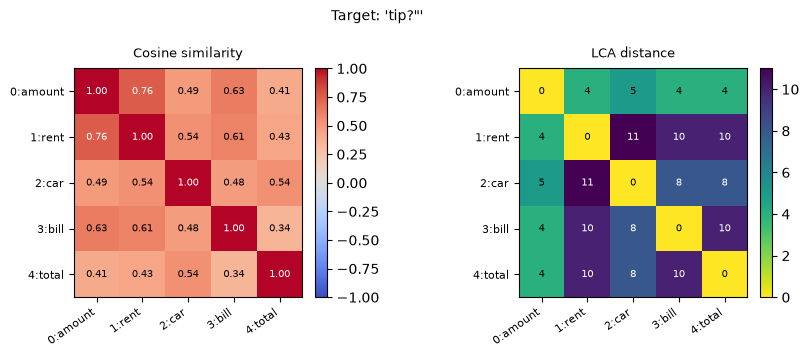


Context: '"Who was the' | Target: 'originator'
Top-5        |      0:first |       1:last |   2:director |   3:american |   4:original
---------------------------------------------------------------------------------------
0:first      |       1.0000 |       0.7096 |       0.5725 |       0.4400 |       0.5853
1:last       |       0.7096 |       1.0000 |       0.6443 |       0.5150 |       0.6723
2:director   |       0.5725 |       0.6443 |       1.0000 |       0.5309 |       0.6818
3:american   |       0.4400 |       0.5150 |       0.5309 |       1.0000 |       0.4746
4:original   |       0.5853 |       0.6723 |       0.6818 |       0.4746 |       1.0000


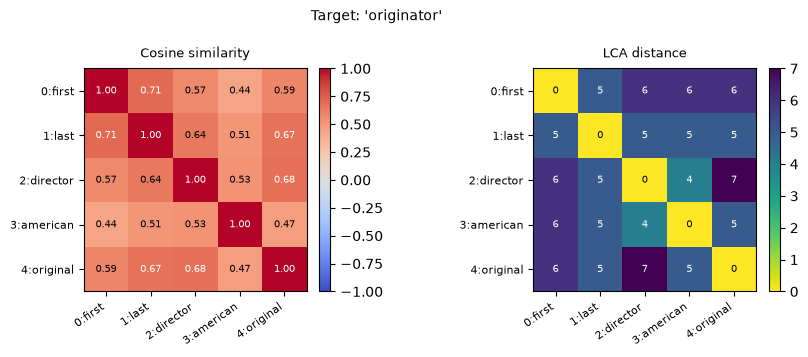


Context: '"Who was the originator of the' | Target: 'idea'
Top-5        |    0:phrase |      1:term |   2:concept |      3:idea |    4:theory
----------------------------------------------------------------------------------
0:phrase     |      1.0000 |      0.7476 |      0.7553 |      0.7654 |      0.6829
1:term       |      0.7476 |      1.0000 |      0.7010 |      0.6818 |      0.6184
2:concept    |      0.7553 |      0.7010 |      1.0000 |      0.8116 |      0.7743
3:idea       |      0.7654 |      0.6818 |      0.8116 |      1.0000 |      0.6992
4:theory     |      0.6829 |      0.6184 |      0.7743 |      0.6992 |      1.0000


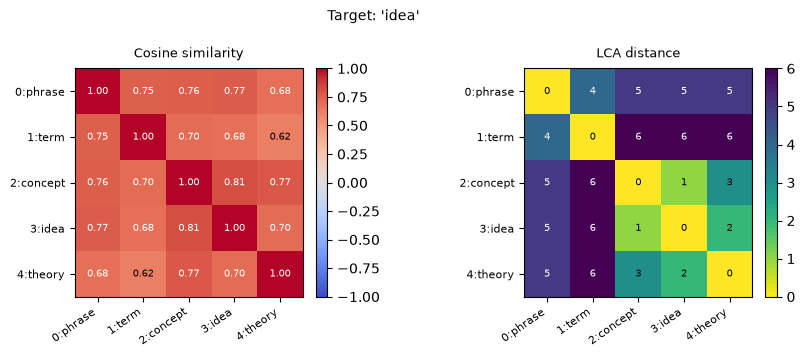


Context: '"Who was the originator of the idea that a' | Target: 'husband'
Top-5          |       0:person |       1:nation |      2:country |        3:state |   4:government
---------------------------------------------------------------------------------------------------
0:person       |         1.0000 |         0.4328 |         0.4360 |         0.4932 |         0.5392
1:nation       |         0.4328 |         1.0000 |         0.5169 |         0.4062 |         0.4877
2:country      |         0.4360 |         0.5169 |         1.0000 |         0.5623 |         0.3495
3:state        |         0.4932 |         0.4062 |         0.5623 |         1.0000 |         0.5140
4:government   |         0.5392 |         0.4877 |         0.3495 |         0.5140 |         1.0000


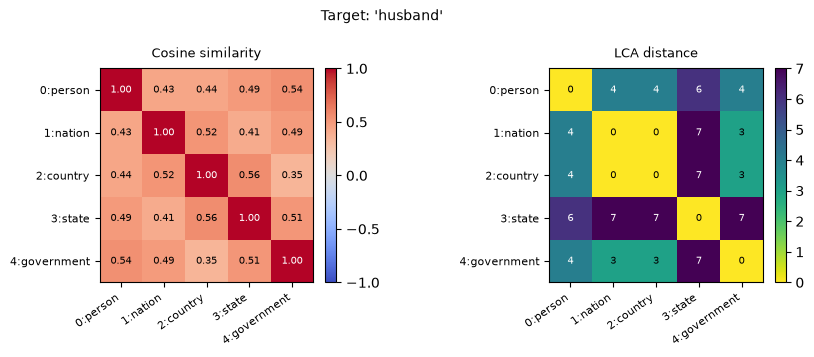


Context: '"Who was the originator of the idea that a husband and' | Target: 'wife'
Top-5        |     0:wife |   1:father |    2:wives |        3:w |    4:slave
-----------------------------------------------------------------------------
0:wife       |     1.0000 |     0.8083 |     0.8663 |     0.6743 |     0.6314
1:father     |     0.8083 |     1.0000 |     0.7414 |     0.6390 |     0.5994
2:wives      |     0.8663 |     0.7414 |     1.0000 |     0.6947 |     0.5987
3:w          |     0.6743 |     0.6390 |     0.6947 |     1.0000 |     0.5482
4:slave      |     0.6314 |     0.5994 |     0.5987 |     0.5482 |     1.0000


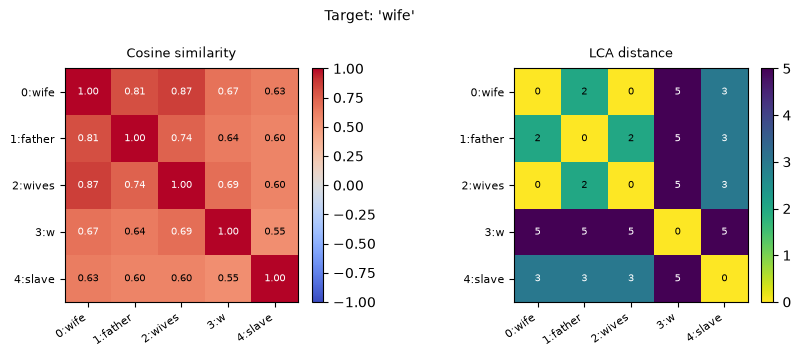


Context: '"I' | Target: 'give'
Top-5        |     0:want |     1:know |    2:think |     3:need |     4:love
-----------------------------------------------------------------------------
0:want       |     1.0000 |     0.7659 |     0.7300 |     0.8792 |     0.6805
1:know       |     0.7659 |     1.0000 |     0.7372 |     0.7421 |     0.5931
2:think      |     0.7300 |     0.7372 |     1.0000 |     0.6569 |     0.5152
3:need       |     0.8792 |     0.7421 |     0.6569 |     1.0000 |     0.6753
4:love       |     0.6805 |     0.5931 |     0.5152 |     0.6753 |     1.0000


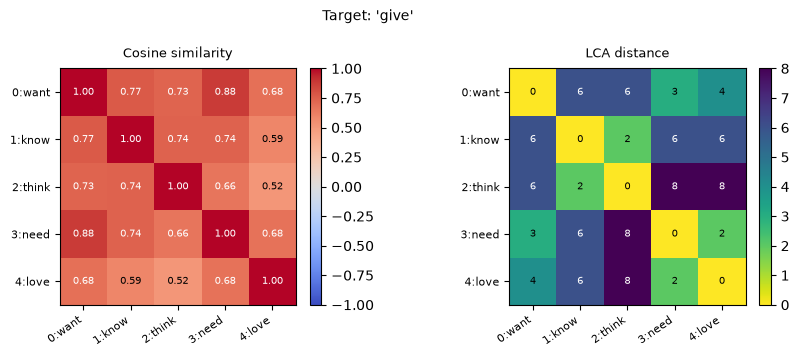


Context: '"I give it up; but it' | Target: 'strikes'
Top-5        |    0:seems |    1:looks |    2:gives |    3:makes |    4:takes
-----------------------------------------------------------------------------
0:seems      |     1.0000 |     0.8092 |     0.6484 |     0.7510 |     0.6651
1:looks      |     0.8092 |     1.0000 |     0.6298 |     0.7770 |     0.6800
2:gives      |     0.6484 |     0.6298 |     1.0000 |     0.7371 |     0.7093
3:makes      |     0.7510 |     0.7770 |     0.7371 |     1.0000 |     0.8116
4:takes      |     0.6651 |     0.6800 |     0.7093 |     0.8116 |     1.0000


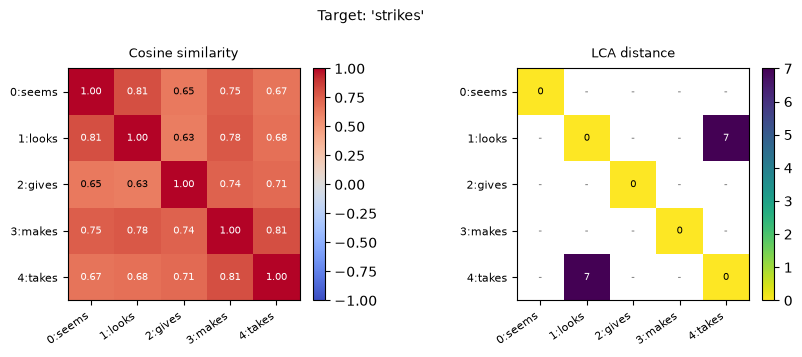


Context: '"I give it up; but it strikes me he might have saved a' | Target: 'lot'
Top-5        |   0:little |     1:good |      2:lot |    3:great |      4:bit
-----------------------------------------------------------------------------
0:little     |     1.0000 |     0.5371 |     0.7226 |     0.6254 |     0.6506
1:good       |     0.5371 |     1.0000 |     0.5824 |     0.7382 |     0.5043
2:lot        |     0.7226 |     0.5824 |     1.0000 |     0.6769 |     0.7945
3:great      |     0.6254 |     0.7382 |     0.6769 |     1.0000 |     0.6148
4:bit        |     0.6506 |     0.5043 |     0.7945 |     0.6148 |     1.0000


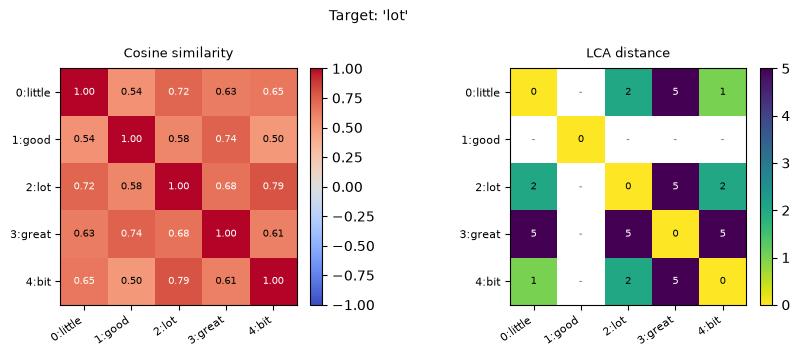


Context: '"I give it up; but it strikes me he might have saved a lot of' | Target: 'argument'
Top-5           |       0:trouble |          1:time |          2:talk |   3:explanation |        4:people
---------------------------------------------------------------------------------------------------------
0:trouble       |          1.0000 |          0.7976 |          0.8092 |          0.8621 |          0.7325
1:time          |          0.7976 |          1.0000 |          0.7436 |          0.7794 |          0.6705
2:talk          |          0.8092 |          0.7436 |          1.0000 |          0.8087 |          0.7098
3:explanation   |          0.8621 |          0.7794 |          0.8087 |          1.0000 |          0.7403
4:people        |          0.7325 |          0.6705 |          0.7098 |          0.7403 |          1.0000


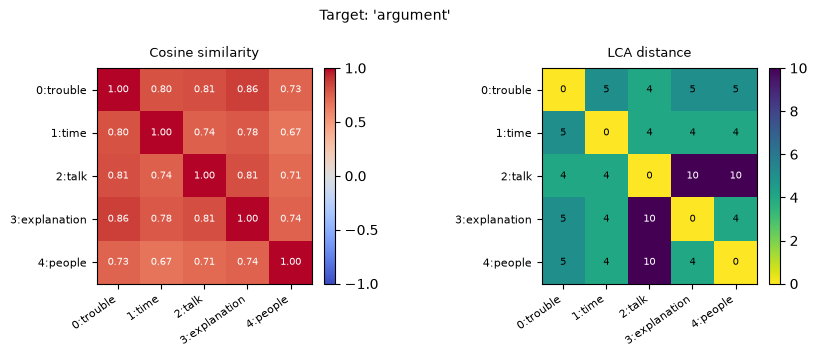

{'block1': [5], 'block2': [6, 4, None], 'block3': [7, 8, None, 7, 6, 8], 'block4': [7, 8, 7, 8, 9, 7, 6], 'block5': [7, 9, 9, 9], 'block6': [8, 7, 6, 9, 9, 7], 'block7': [6, 8, 7], 'block8': [6, 5, 5, 10, 7], 'block9': [8, 10, 5, 10, 7, 4, 6], 'block10': [7, 7, 6, 5, 7], 'block11': [8, 7, 9, 9], 'block12': [9, 6, 4, 1], 'block13': [7, 8, 8, 8, 9, 10, 5, 1], 'block14': [8, 7, 4, 7, None, 7, 7, 7], 'block15': [7, 7, 5, 8, 8], 'block16': [8, 2, 8, 6], 'block17': [7, 8], 'block19': [9, 9, 8, 8, 7], 'block20': [7, 8, 3], 'block21': [9, 7, 8], 'block22': [6, 9, 9, 8, 6, 7, 6], 'block23': [9, 5, 6, 10], 'block24': [8, 10, 7], 'block25': [9, 7, 10], 'block26': [6, 8, 8, 8, None, 10], 'block27': [None, 9, 6, 6], 'block28': [6, 8, 8], 'block30': [8, 8], 'block31': [7, 8, 8, 4, 5, 6, 9, 5], 'block32': [6, 8, 6], 'block33': [9, 9, 8, 7, 7, 4, 5, 7], 'block34': [9, 7, 7, 3, 7], 'block35': [7, 9, 7, 4, 5, 6, 9, 5], 'block36': [8, 7, 9, 8], 'block37': [5, 7, 5], 'block38': [9, 5, 9, 8], 'block39': [8

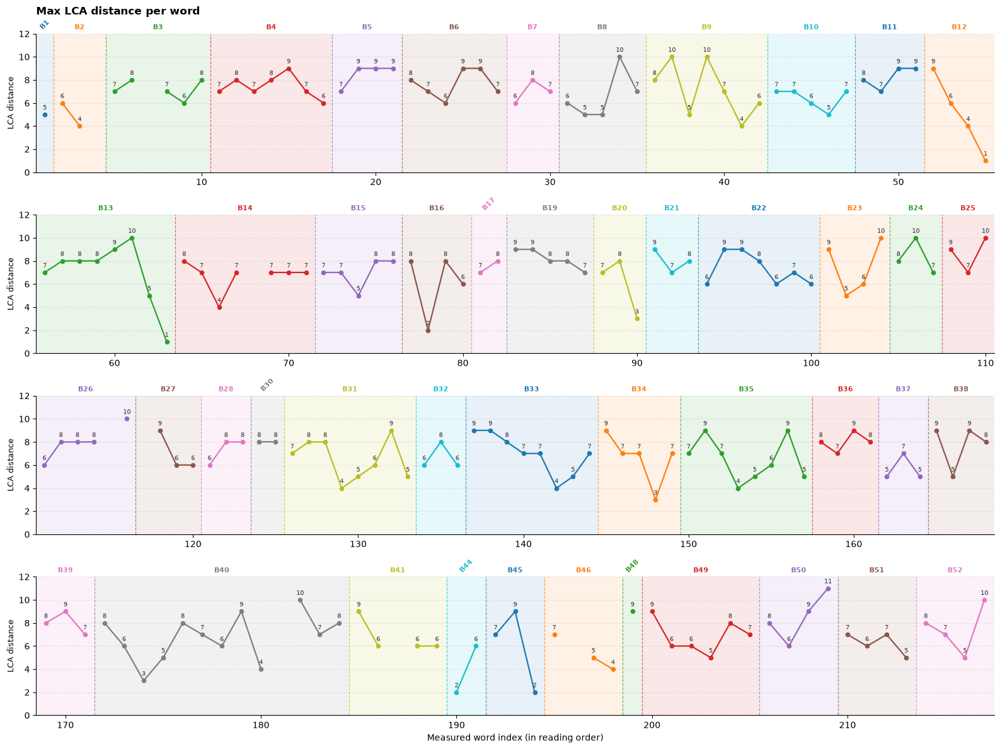

In [33]:

with open('./texts_data/creative_jokes_2.txt', 'r') as file:
    content = file.read()
    # print(content)
    print("\n")
    context_blocks, blocks_max_distances = analyze_semantic_with_context_segments(
        content,
        tokenizer = tokenizer_7b,
        model = model_7b,
        with_bert=True,
        bert_tokenizer=bert_tokenizer_7b,
        bert_model=bert_model_7b,
        print_results=False)

print(blocks_max_distances)
fig = plot_lca_curve(blocks_max_distances, title="Max LCA distance per word", blocks_per_row=12, show_values=True)
fig.tight_layout()
plt.show()
plt.close(fig)

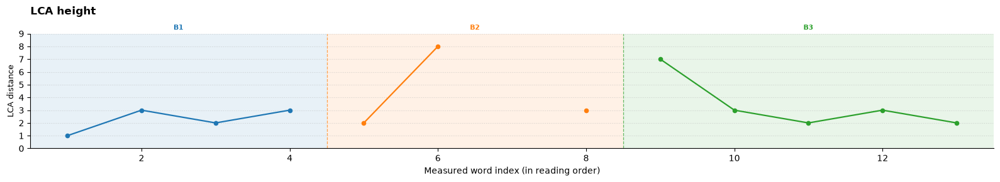

In [12]:
fig = plot_lca_curve({"block1": [1, 3, 2, 3], "block2": [2, 8, None, 3], "block3": [7, 3, 2, 3, 2]})
fig.tight_layout()
plt.show()
plt.close(fig)


In [33]:
from src.tools.generate import write_story_streaming

prompt = "ash ketchum get his first pokemon"
Seed = 0
tempeture = 0.7
#
ids = write_story_streaming(model_1_5b,tokenizer_1_5b,prompt,0.7,Seed,kind="creative")


Ash Ketchum, the young boy from Pallet Town, had always been a Pokémon enthusiast. His life revolved around his fascination with the creatures that lived in the Pokémon world. He had a strong desire to become the greatest Pokémon trainer in the entire region, and he was committed to achieving his goal at any cost.

The day had finally arrived when Ash received his very first Pokémon. It was a tiny, wiggly creature with a bright yellow and black striped body, a pair of red eyes, and a long, pointy beak. Ash's heart fluttered with excitement as he held the Pokémon close to his chest, marveling at its unique qualities.

The Pokémon was named Pikachu, and it was a Charizard, one of the most powerful and feared creatures in the Pokémon world. Pikachu had a fiery red body, a small silver tail, and a pair of sharp claws. It was a magnificent sight to behold, and Ash couldn't help but feel a surge of pride and excitement as he held it in his arms.

The Pokémon Trainer and the Pokémon were inse

In [13]:
# from transformers import TextStreamer

# def inject_prompt(text: str) -> str:
#     return (
#         f"Write a story of about 100 words about {text}. "
#         "Write only the story itself: no title, no headings, no notes."
#     )
    
# def stream_output(model, tokenizer, prompt: str):
#     messages = [{"role": "user", "content": inject_prompt(prompt)}]
#     inputs = tokenizer.apply_chat_template(
#         messages, add_generation_prompt=True, return_tensors="pt"
#     ).to(model.device)
#     streamer = TextStreamer(tokenizer, skip_prompt=True, skip_special_tokens=True)
    
#     model.generate(**inputs, max_new_tokens=200, streamer=streamer)
    

In [43]:
prompt = "Ash Ketchum get his first pokemon"
Seed = 0
tempeture = 0.7

stream_output(model_1_5b,tokenizer_1_5b,prompt)

Ash Ketchum was a boy with big dreams and an even bigger heart. He lived in a small village where he spent most of his time exploring the nearby forest. One day, while wandering through the dense woods, Ash stumbled upon a mysterious glowing rock. It wasn't until he picked it up that he realized its true power - it could transform into any Pokémon he desired!

Excitedly, Ash called out to the rock, "I want a Pikachu!" And suddenly, from within the stone, a bright flash of light appeared, revealing a tiny Pikachu peeking out at him. The little creature scampered over to Ash's hand and said hello.

From that moment on, Ash knew that this Pokémon would be his forever companion. Together, they faced countless challenges and adventures, growing stronger every day. With Pikachu by his side, Ash embarked on a journey that changed not just his life but also the world around him.


In [36]:
from threading import Thread
from transformers import TextIteratorStreamer

def inject_prompt(text: str,type_of_text) -> str:
    if type_of_text == "creative":
        return (f"Write a story of about 100 words about {prompt}. "
                "Write only the story itself: no title, no headings, no notes.")
    if type_of_text == "factual":
        return (f"Write an encyclopedia article of about 100 words about {prompt}. "
                "Write only the article itself: no title, no headings, no notes.")
    raise ValueError(f"kind must be 'creative' or 'factual', not {type_of_text!r}")

def stream_and_analyze(gen_model, gen_tokenizer, prompt: str,type_of_text:str, analyze_model, analyze_tokenizer):
    messages = [{"role": "user", "content": inject_prompt(prompt,type_of_text)}]
    inputs = gen_tokenizer.apply_chat_template(
        messages, add_generation_prompt=True, return_tensors="pt"
    ).to(gen_model.device)

    streamer = TextIteratorStreamer(gen_tokenizer, skip_prompt=True, skip_special_tokens=True)
    
    # הרצת הייצור ברקע כדי שנוכל לקרוא ממנו בלייב
    thread = Thread(target=gen_model.generate, kwargs=dict(**inputs, max_new_tokens=200, streamer=streamer))
    thread.start()

    sentence_buffer = ""
    all_blocks = []
    all_distances = {}

    for chunk in streamer:
        print(chunk, end="", flush=True)  # הדפסה חיה למסך
        sentence_buffer += chunk

        # ברגע שמסתיים משפט (נקודה/סימן קריאה/שאלה + רווח), מריצים את הפונקציה הקיימת שלך!
        if any(p in chunk for p in (".", "!", "?")) and len(sentence_buffer.split()) > 2:
            blocks, distances = analyze_semantic_with_context_segments(
                sentence_buffer,
                tokenizer = tokenizer_7b,
                model = model_7b,
                with_bert=True,
                bert_tokenizer=bert_tokenizer_7b,
                bert_model=bert_model_7b,
                print_results=False,
            )
            plot_lca_curve(distances, title="Max LCA distance per word", show_values=True)
            
            all_blocks.extend(blocks)
            for k, v in distances.items():
                all_distances[f"block{len(all_blocks)}"] = v
            sentence_buffer = ""  # איפוס למשפט הבא

    thread.join()
    return all_blocks, all_distances

Ash Ketchum was just an ordinary boy with big dreams and a love for adventure. 
Context: 'Ash' | Target: 'Ketchum'
Top-5        |      0:ley |     1:ford |       2:ar |       3:er |     4:land
-----------------------------------------------------------------------------
0:ley        |     1.0000 |     0.4210 |     0.7016 |     0.6343 |     0.4188
1:ford       |     0.4210 |     1.0000 |     0.3908 |     0.3603 |     0.4187
2:ar         |     0.7016 |     0.3908 |     1.0000 |     0.5248 |     0.3897
3:er         |     0.6343 |     0.3603 |     0.5248 |     1.0000 |     0.3764
4:land       |     0.4188 |     0.4187 |     0.3897 |     0.3764 |     1.0000


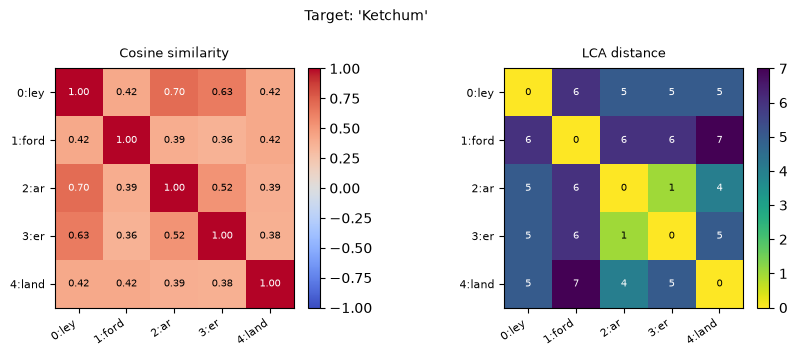


Context: 'Ash Ketchum was just an' | Target: 'ordinary'
Top-5        |   0:ordinary |    1:average |     2:eleven |   3:innocent |         4:un
---------------------------------------------------------------------------------------
0:ordinary   |       1.0000 |       0.5626 |       0.6314 |       0.7766 |       0.7955
1:average    |       0.5626 |       1.0000 |       0.3849 |       0.5286 |       0.4841
2:eleven     |       0.6314 |       0.3849 |       1.0000 |       0.5896 |       0.5631
3:innocent   |       0.7766 |       0.5286 |       0.5896 |       1.0000 |       0.6838
4:un         |       0.7955 |       0.4841 |       0.5631 |       0.6838 |       1.0000


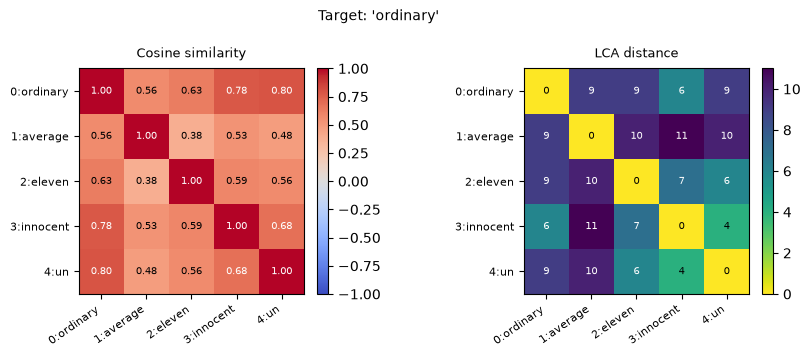


Context: 'Ash Ketchum was just an ordinary' | Target: 'boy'
Top-5        |      0:boy |      1:kid |   2:middle |    3:human |   4:eleven
-----------------------------------------------------------------------------
0:boy        |     1.0000 |     0.8242 |     0.6857 |     0.5843 |     0.5916
1:kid        |     0.8242 |     1.0000 |     0.7481 |     0.6411 |     0.6469
2:middle     |     0.6857 |     0.7481 |     1.0000 |     0.5939 |     0.5850
3:human      |     0.5843 |     0.6411 |     0.5939 |     1.0000 |     0.4559
4:eleven     |     0.5916 |     0.6469 |     0.5850 |     0.4559 |     1.0000


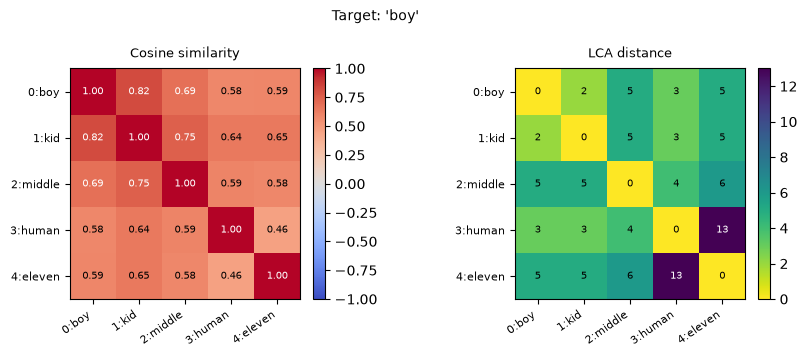


Context: 'Ash Ketchum was just an ordinary boy with big' | Target: 'dreams'
Top-5         |      0:dreams |        1:blue |   2:ambitions |       3:brown |        4:eyes
---------------------------------------------------------------------------------------------
0:dreams      |        1.0000 |        0.5775 |        0.5386 |        0.4299 |        0.5535
1:blue        |        0.5775 |        1.0000 |        0.6769 |        0.7062 |        0.7989
2:ambitions   |        0.5386 |        0.6769 |        1.0000 |        0.6852 |        0.7356
3:brown       |        0.4299 |        0.7062 |        0.6852 |        1.0000 |        0.6826
4:eyes        |        0.5535 |        0.7989 |        0.7356 |        0.6826 |        1.0000


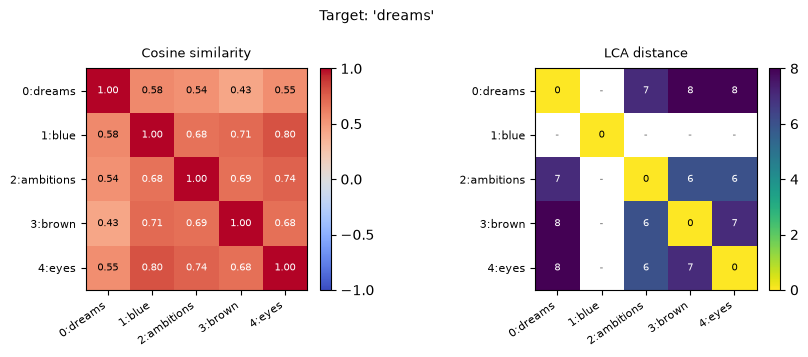


Context: 'Ash Ketchum was just an ordinary boy with big dreams and a' | Target: 'love'
Top-5        |   0:pikachu |     1:small |       2:lot |      3:love |   4:passion
----------------------------------------------------------------------------------
0:pikachu    |      1.0000 |      0.3808 |      0.3767 |      0.2843 |      0.3786
1:small      |      0.3808 |      1.0000 |      0.6552 |      0.5155 |      0.5087
2:lot        |      0.3767 |      0.6552 |      1.0000 |      0.6052 |      0.5499
3:love       |      0.2843 |      0.5155 |      0.6052 |      1.0000 |      0.6963
4:passion    |      0.3786 |      0.5087 |      0.5499 |      0.6963 |      1.0000


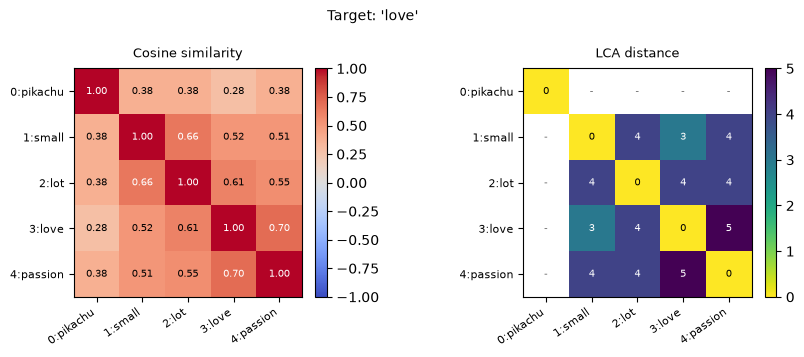


Context: 'Ash Ketchum was just an ordinary boy with big dreams and a love for' | Target: 'adventure.'
Top-5          |      0:pokémon |      1:pokemon |    2:adventure |          3:pok |   4:adventures
---------------------------------------------------------------------------------------------------
0:pokémon      |         1.0000 |         1.0000 |         0.7528 |         0.5634 |         0.7410
1:pokemon      |         1.0000 |         1.0000 |         0.7528 |         0.5634 |         0.7410
2:adventure    |         0.7528 |         0.7528 |         1.0000 |         0.5604 |         0.8866
3:pok          |         0.5634 |         0.5634 |         0.5604 |         1.0000 |         0.5578
4:adventures   |         0.7410 |         0.7410 |         0.8866 |         0.5578 |         1.0000


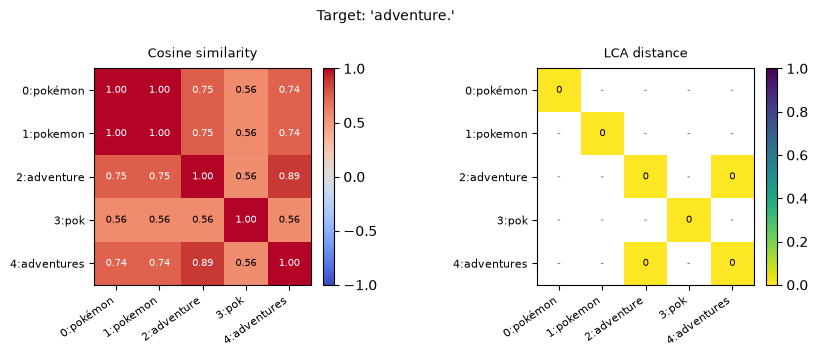

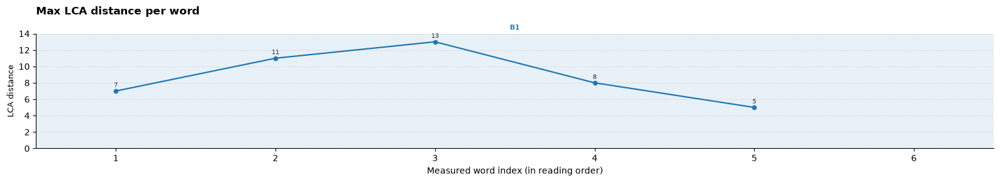

One day, while exploring a dense forest near his hometown, he stumbled upon a mysterious glowing ball in a puddle. 
Context: 'One' | Target: 'day,'
Top-5        |      0:side |   1:hundred |      2:year |       3:day |    4:ticket
----------------------------------------------------------------------------------
0:side       |      1.0000 |      0.5548 |      0.3684 |      0.5250 |      0.4817
1:hundred    |      0.5548 |      1.0000 |      0.3177 |      0.5204 |      0.4481
2:year       |      0.3684 |      0.3177 |      1.0000 |      0.4697 |      0.3704
3:day        |      0.5250 |      0.5204 |      0.4697 |      1.0000 |      0.4803
4:ticket     |      0.4817 |      0.4481 |      0.3704 |      0.4803 |      1.0000


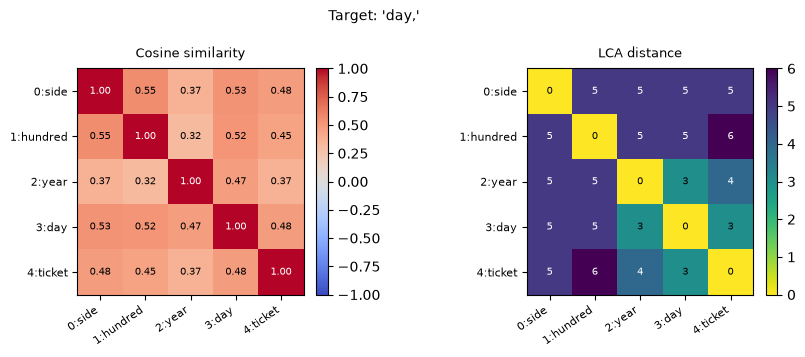


Context: 'One day, while' | Target: 'exploring'
Top-5        |   0:walking |   1:playing |   2:sitting |   3:working |   4:reading
----------------------------------------------------------------------------------
0:walking    |      1.0000 |      0.7289 |      0.7389 |      0.7961 |      0.7722
1:playing    |      0.7289 |      1.0000 |      0.7710 |      0.8195 |      0.8135
2:sitting    |      0.7389 |      0.7710 |      1.0000 |      0.8420 |      0.8420
3:working    |      0.7961 |      0.8195 |      0.8420 |      1.0000 |      0.8554
4:reading    |      0.7722 |      0.8135 |      0.8420 |      0.8554 |      1.0000


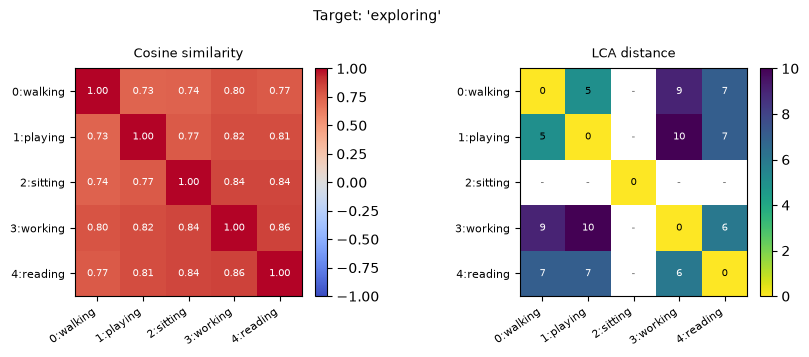


Context: 'One day, while exploring a dense' | Target: 'forest'
Top-5        |   0:forest |   1:jungle |      2:fog |     3:rain |       4:th
-----------------------------------------------------------------------------
0:forest     |     1.0000 |     0.7403 |     0.6484 |     0.6211 |     0.4896
1:jungle     |     0.7403 |     1.0000 |     0.7583 |     0.6205 |     0.5138
2:fog        |     0.6484 |     0.7583 |     1.0000 |     0.6015 |     0.6494
3:rain       |     0.6211 |     0.6205 |     0.6015 |     1.0000 |     0.4380
4:th         |     0.4896 |     0.5138 |     0.6494 |     0.4380 |     1.0000


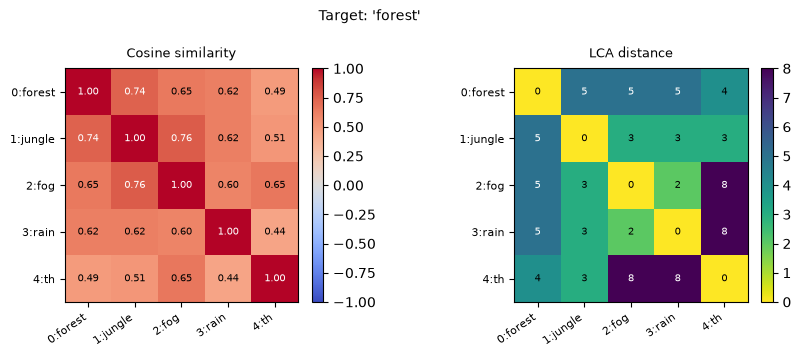


Context: 'One day, while exploring a dense forest' | Target: 'near'
Top-5        |     0:near |     1:area |     2:full |      3:far |     4:deep
-----------------------------------------------------------------------------
0:near       |     1.0000 |     0.6924 |     0.7082 |     0.7174 |     0.7720
1:area       |     0.6924 |     1.0000 |     0.6365 |     0.5550 |     0.6424
2:full       |     0.7082 |     0.6365 |     1.0000 |     0.6102 |     0.6912
3:far        |     0.7174 |     0.5550 |     0.6102 |     1.0000 |     0.6703
4:deep       |     0.7720 |     0.6424 |     0.6912 |     0.6703 |     1.0000


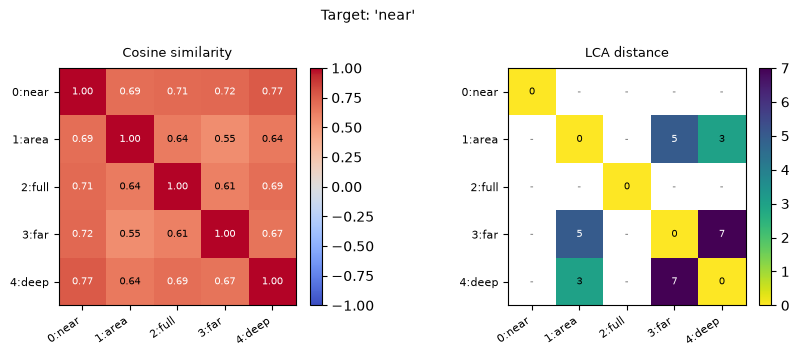


Context: 'One day, while exploring a dense forest near his' | Target: 'hometown,'
Top-5        |       0:home |    1:village |     2:school |      3:house |   4:hometown
---------------------------------------------------------------------------------------
0:home       |       1.0000 |       0.3800 |       0.4802 |       0.5664 |       0.5267
1:village    |       0.3800 |       1.0000 |       0.4324 |       0.4127 |       0.3649
2:school     |       0.4802 |       0.4324 |       1.0000 |       0.6802 |       0.6559
3:house      |       0.5664 |       0.4127 |       0.6802 |       1.0000 |       0.6613
4:hometown   |       0.5267 |       0.3649 |       0.6559 |       0.6613 |       1.0000


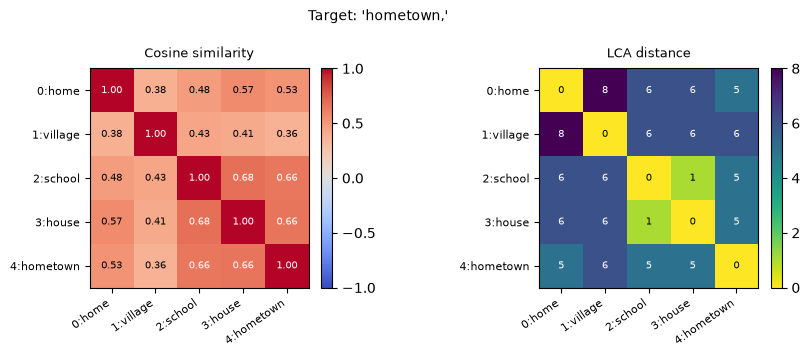


Context: 'One day, while exploring a dense forest near his hometown, he' | Target: 'stumbled'
Top-5           |         0:found |      1:suddenly |          2:came |      3:stumbled |   4:encountered
---------------------------------------------------------------------------------------------------------
0:found         |          1.0000 |          0.4577 |          0.6586 |          0.5558 |          0.7276
1:suddenly      |          0.4577 |          1.0000 |          0.5272 |          0.5520 |          0.4528
2:came          |          0.6586 |          0.5272 |          1.0000 |          0.5932 |          0.6240
3:stumbled      |          0.5558 |          0.5520 |          0.5932 |          1.0000 |          0.5575
4:encountered   |          0.7276 |          0.4528 |          0.6240 |          0.5575 |          1.0000


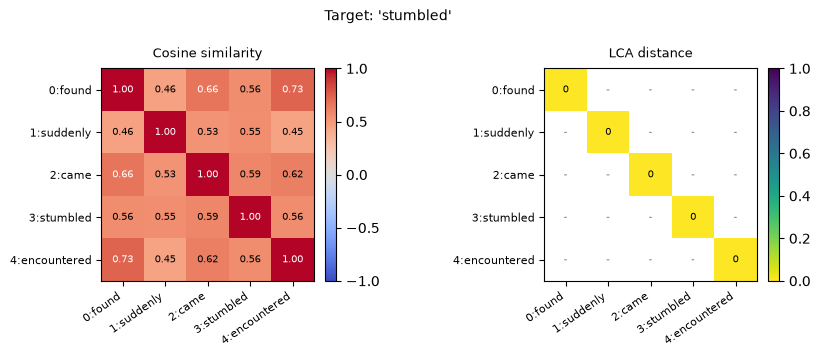


Context: 'One day, while exploring a dense forest near his hometown, he stumbled' | Target: 'upon'
Top-5            |           0:upon |         1:across |           2:onto |   3:unexpectedly |   4:accidentally
---------------------------------------------------------------------------------------------------------------
0:upon           |           1.0000 |           0.5842 |           0.8234 |           0.6498 |           0.6974
1:across         |           0.5842 |           1.0000 |           0.6916 |           0.6275 |           0.6493
2:onto           |           0.8234 |           0.6916 |           1.0000 |           0.7288 |           0.7641
3:unexpectedly   |           0.6498 |           0.6275 |           0.7288 |           1.0000 |           0.8108
4:accidentally   |           0.6974 |           0.6493 |           0.7641 |           0.8108 |           1.0000


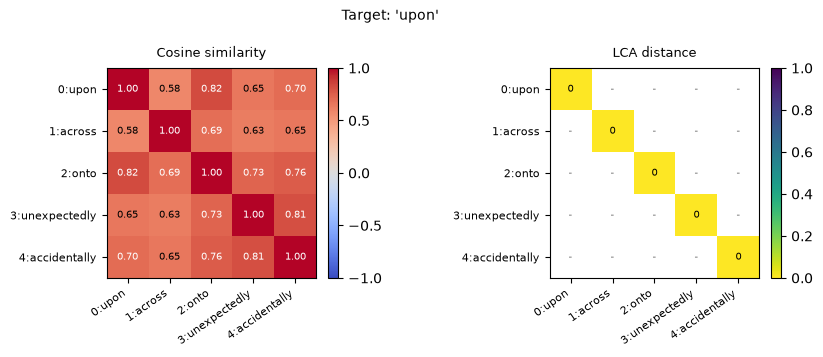


Context: 'One day, while exploring a dense forest near his hometown, he stumbled upon a mysterious' | Target: 'glowing'
Top-5        |      0:cave |     1:stone |       2:old |   3:ancient |       4:map
----------------------------------------------------------------------------------
0:cave       |      1.0000 |      0.6358 |      0.4402 |      0.5924 |      0.4765
1:stone      |      0.6358 |      1.0000 |      0.5741 |      0.6850 |      0.4740
2:old        |      0.4402 |      0.5741 |      1.0000 |      0.6782 |      0.4337
3:ancient    |      0.5924 |      0.6850 |      0.6782 |      1.0000 |      0.4169
4:map        |      0.4765 |      0.4740 |      0.4337 |      0.4169 |      1.0000


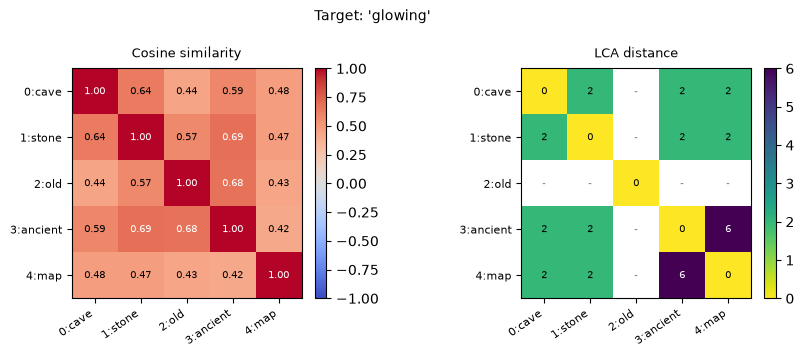


Context: 'One day, while exploring a dense forest near his hometown, he stumbled upon a mysterious glowing' | Target: 'ball'
Top-5        |   0:crystal |    1:object |      2:rock |      3:cave |     4:stone
----------------------------------------------------------------------------------
0:crystal    |      1.0000 |      0.5800 |      0.7455 |      0.6245 |      0.7472
1:object     |      0.5800 |      1.0000 |      0.5682 |      0.5457 |      0.5437
2:rock       |      0.7455 |      0.5682 |      1.0000 |      0.6127 |      0.7880
3:cave       |      0.6245 |      0.5457 |      0.6127 |      1.0000 |      0.6358
4:stone      |      0.7472 |      0.5437 |      0.7880 |      0.6358 |      1.0000


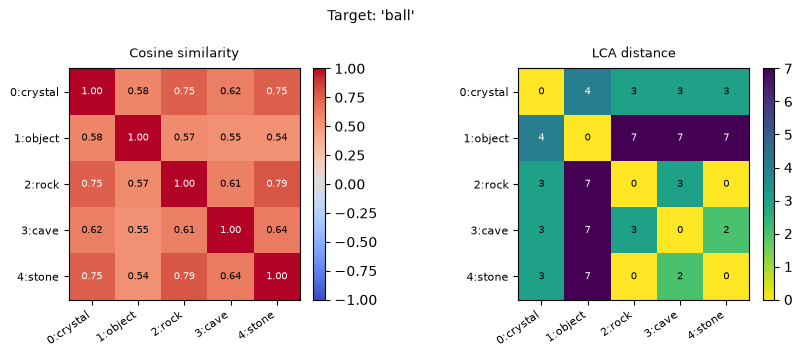


Context: 'One day, while exploring a dense forest near his hometown, he stumbled upon a mysterious glowing ball in a' | Target: 'puddle.'
Top-5        |   0:clearing |       1:cave |      2:small |       3:dark |       4:tree
---------------------------------------------------------------------------------------
0:clearing   |       1.0000 |       0.5936 |       0.6447 |       0.7505 |       0.6712
1:cave       |       0.5936 |       1.0000 |       0.5437 |       0.5849 |       0.6646
2:small      |       0.6447 |       0.5437 |       1.0000 |       0.7344 |       0.6418
3:dark       |       0.7505 |       0.5849 |       0.7344 |       1.0000 |       0.6472
4:tree       |       0.6712 |       0.6646 |       0.6418 |       0.6472 |       1.0000


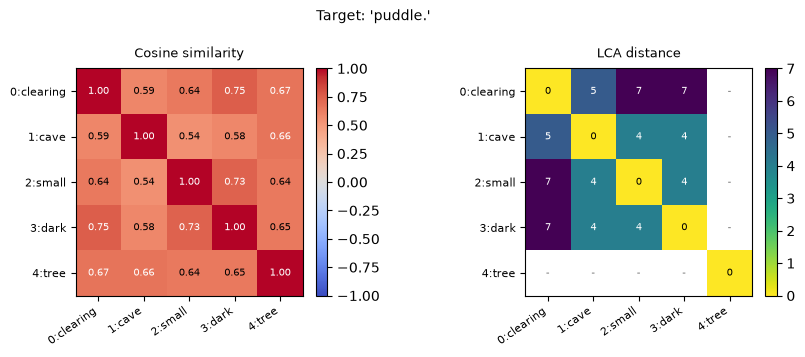

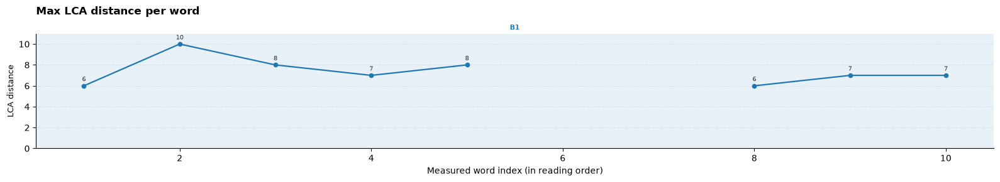

It sparkled like nothing he had ever seen before. 
Context: 'It' | Target: 'sparkled'
Top-5        |    0:takes |     1:took |    2:seems |    3:looks |    4:makes
-----------------------------------------------------------------------------
0:takes      |     1.0000 |     0.8302 |     0.6651 |     0.6800 |     0.8116
1:took       |     0.8302 |     1.0000 |     0.6684 |     0.7129 |     0.7483
2:seems      |     0.6651 |     0.6684 |     1.0000 |     0.8092 |     0.7510
3:looks      |     0.6800 |     0.7129 |     0.8092 |     1.0000 |     0.7770
4:makes      |     0.8116 |     0.7483 |     0.7510 |     0.7770 |     1.0000


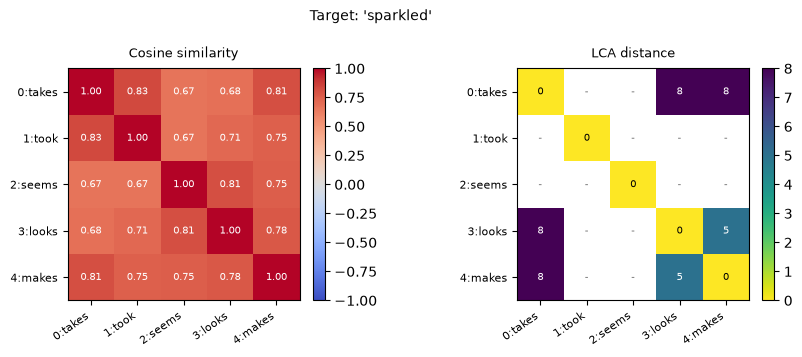


Context: 'It sparkled like' | Target: 'nothing'
Top-5        |   0:diamonds |       1:gold |     2:liquid |     3:silver |    4:nothing
---------------------------------------------------------------------------------------
0:diamonds   |       1.0000 |       0.6834 |       0.6354 |       0.7334 |       0.5788
1:gold       |       0.6834 |       1.0000 |       0.5964 |       0.8200 |       0.5461
2:liquid     |       0.6354 |       0.5964 |       1.0000 |       0.7691 |       0.6687
3:silver     |       0.7334 |       0.8200 |       0.7691 |       1.0000 |       0.6230
4:nothing    |       0.5788 |       0.5461 |       0.6687 |       0.6230 |       1.0000


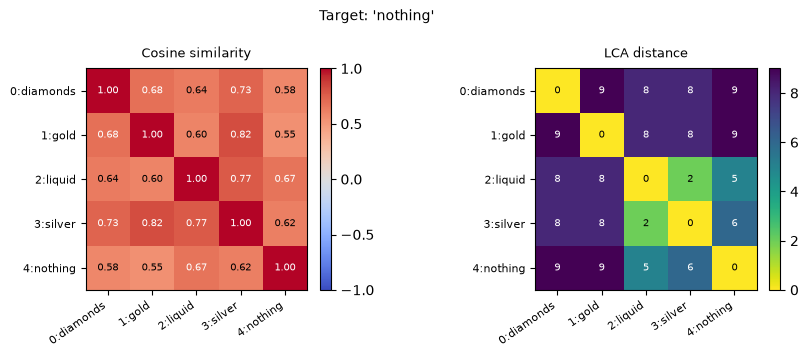


Context: 'It sparkled like nothing he had' | Target: 'ever'
Top-5           |          0:ever |          1:seen |           2:yet |    3:previously |   4:encountered
---------------------------------------------------------------------------------------------------------
0:ever          |          1.0000 |          0.6126 |          0.5379 |          0.4474 |          0.5058
1:seen          |          0.6126 |          1.0000 |          0.5485 |          0.4573 |          0.7559
2:yet           |          0.5379 |          0.5485 |          1.0000 |          0.3772 |          0.5056
3:previously    |          0.4474 |          0.4573 |          0.3772 |          1.0000 |          0.4243
4:encountered   |          0.5058 |          0.7559 |          0.5056 |          0.4243 |          1.0000


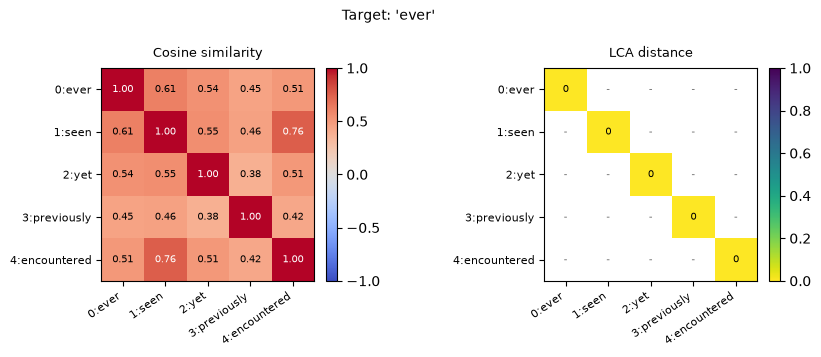


Context: 'It sparkled like nothing he had ever' | Target: 'seen'
Top-5           |          0:seen |      1:imagined |   2:encountered |     3:witnessed |           4:set
---------------------------------------------------------------------------------------------------------
0:seen          |          1.0000 |          0.7566 |          0.7559 |          0.8617 |          0.6352
1:imagined      |          0.7566 |          1.0000 |          0.7577 |          0.7927 |          0.6318
2:encountered   |          0.7559 |          0.7577 |          1.0000 |          0.7292 |          0.5509
3:witnessed     |          0.8617 |          0.7927 |          0.7292 |          1.0000 |          0.5435
4:set           |          0.6352 |          0.6318 |          0.5509 |          0.5435 |          1.0000


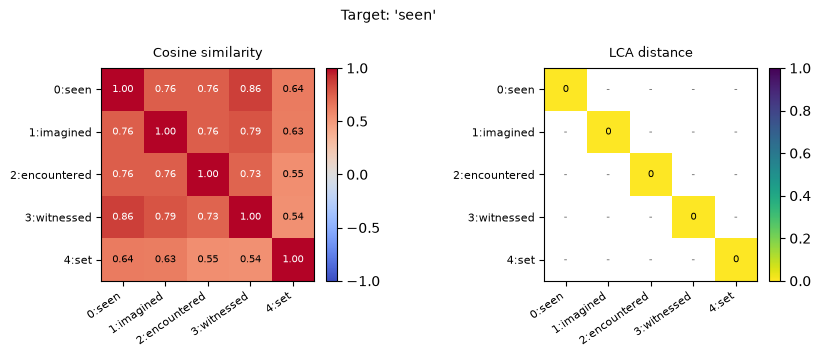

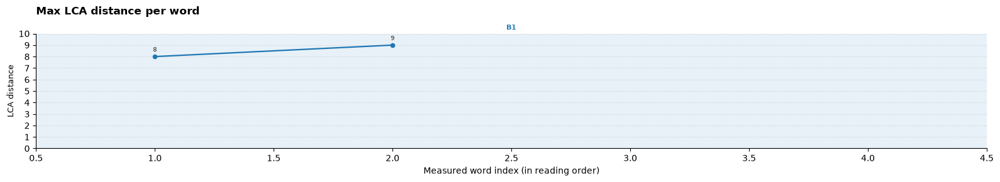

The next morning, when he woke up, the ball was gone, but a little green creature appeared beside him.


Context: 'The next' | Target: 'morning,'
Top-5          |         0:time |       1:number |   2:generation |         3:step |        4:thing
---------------------------------------------------------------------------------------------------
0:time         |         1.0000 |         0.7385 |         0.7733 |         0.6616 |         0.7148
1:number       |         0.7385 |         1.0000 |         0.7746 |         0.6461 |         0.7182
2:generation   |         0.7733 |         0.7746 |         1.0000 |         0.6208 |         0.7690
3:step         |         0.6616 |         0.6461 |         0.6208 |         1.0000 |         0.5993
4:thing        |         0.7148 |         0.7182 |         0.7690 |         0.5993 |         1.0000


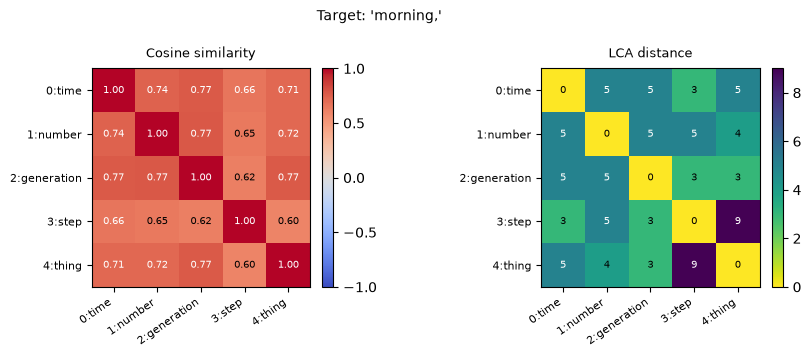


Context: 'The next morning, when he' | Target: 'woke'
Top-5        |       0:came |       1:woke |    2:arrived |   3:returned |        4:saw
---------------------------------------------------------------------------------------
0:came       |       1.0000 |       0.7069 |       0.7885 |       0.7740 |       0.6894
1:woke       |       0.7069 |       1.0000 |       0.7513 |       0.7314 |       0.7352
2:arrived    |       0.7885 |       0.7513 |       1.0000 |       0.8327 |       0.7468
3:returned   |       0.7740 |       0.7314 |       0.8327 |       1.0000 |       0.7289
4:saw        |       0.6894 |       0.7352 |       0.7468 |       0.7289 |       1.0000


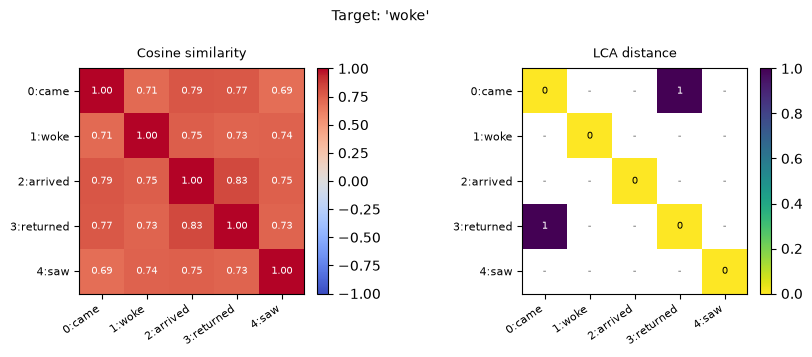


Context: 'The next morning, when he woke up, the' | Target: 'ball'
Top-5        |       0:sun |       1:sky |   2:weather |       3:boy |      4:snow
----------------------------------------------------------------------------------
0:sun        |      1.0000 |      0.7020 |      0.6225 |      0.6371 |      0.6281
1:sky        |      0.7020 |      1.0000 |      0.5458 |      0.6295 |      0.6000
2:weather    |      0.6225 |      0.5458 |      1.0000 |      0.5989 |      0.6857
3:boy        |      0.6371 |      0.6295 |      0.5989 |      1.0000 |      0.5915
4:snow       |      0.6281 |      0.6000 |      0.6857 |      0.5915 |      1.0000


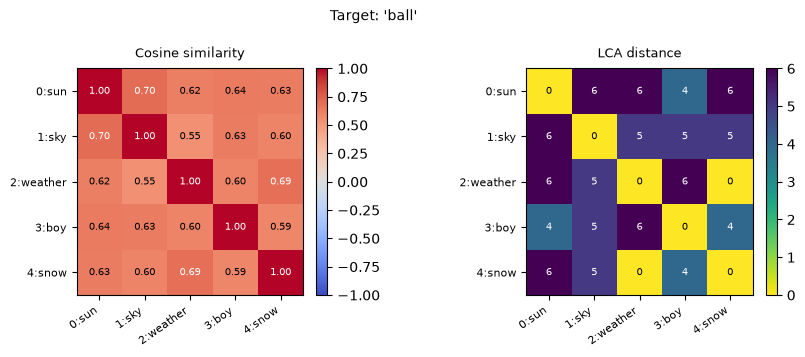


Context: 'The next morning, when he woke up, the ball was gone, but a' | Target: 'little'
Top-5        |     0:note |   1:letter |    2:piece |    3:small |    4:large
-----------------------------------------------------------------------------
0:note       |     1.0000 |     0.6539 |     0.5936 |     0.5103 |     0.5213
1:letter     |     0.6539 |     1.0000 |     0.7259 |     0.6462 |     0.6647
2:piece      |     0.5936 |     0.7259 |     1.0000 |     0.7082 |     0.7776
3:small      |     0.5103 |     0.6462 |     0.7082 |     1.0000 |     0.8865
4:large      |     0.5213 |     0.6647 |     0.7776 |     0.8865 |     1.0000


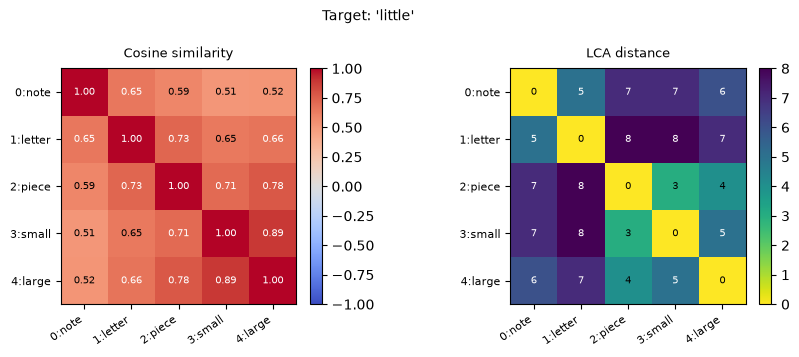


Context: 'The next morning, when he woke up, the ball was gone, but a little' | Target: 'green'
Top-5        |       0:note |      1:paper |        2:box |   3:envelope |        4:boy
---------------------------------------------------------------------------------------
0:note       |       1.0000 |       0.5806 |       0.6134 |       0.5959 |       0.5075
1:paper      |       0.5806 |       1.0000 |       0.6251 |       0.6934 |       0.5134
2:box        |       0.6134 |       0.6251 |       1.0000 |       0.8474 |       0.6903
3:envelope   |       0.5959 |       0.6934 |       0.8474 |       1.0000 |       0.6847
4:boy        |       0.5075 |       0.5134 |       0.6903 |       0.6847 |       1.0000


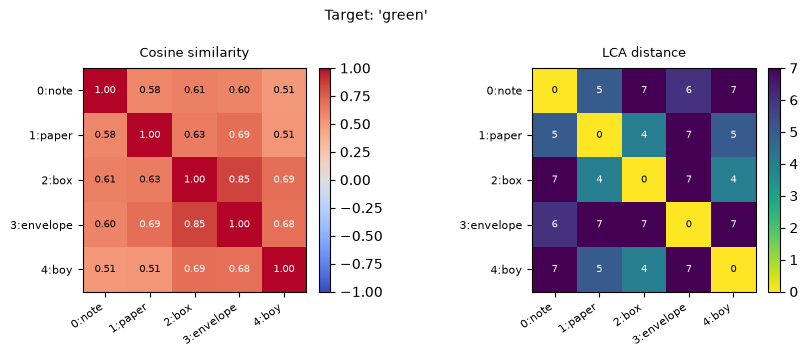


Context: 'The next morning, when he woke up, the ball was gone, but a little green' | Target: 'creature'
Top-5        |      0:man |     1:note |    2:alien |     3:frog |   4:bottle
-----------------------------------------------------------------------------
0:man        |     1.0000 |     0.5493 |     0.7576 |     0.6143 |     0.7854
1:note       |     0.5493 |     1.0000 |     0.5211 |     0.5193 |     0.6214
2:alien      |     0.7576 |     0.5211 |     1.0000 |     0.6412 |     0.7733
3:frog       |     0.6143 |     0.5193 |     0.6412 |     1.0000 |     0.7063
4:bottle     |     0.7854 |     0.6214 |     0.7733 |     0.7063 |     1.0000


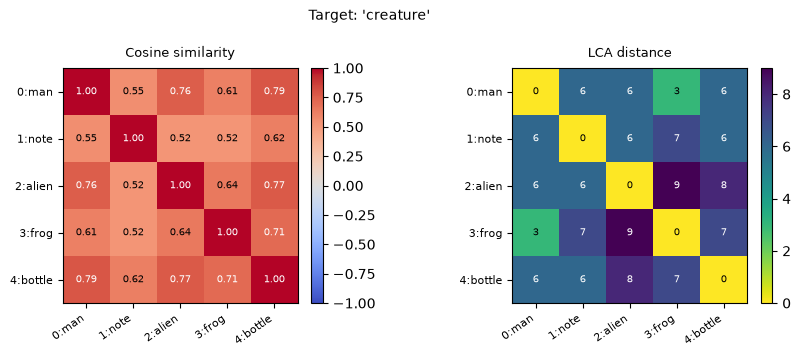


Context: 'The next morning, when he woke up, the ball was gone, but a little green creature' | Target: 'appeared'
Top-5        |        0:sat |    1:wearing |   2:remained |      3:stood |        4:lay
---------------------------------------------------------------------------------------
0:sat        |       1.0000 |       0.6739 |       0.6862 |       0.6331 |       0.6246
1:wearing    |       0.6739 |       1.0000 |       0.7816 |       0.5796 |       0.6351
2:remained   |       0.6862 |       0.7816 |       1.0000 |       0.6985 |       0.7106
3:stood      |       0.6331 |       0.5796 |       0.6985 |       1.0000 |       0.5596
4:lay        |       0.6246 |       0.6351 |       0.7106 |       0.5596 |       1.0000


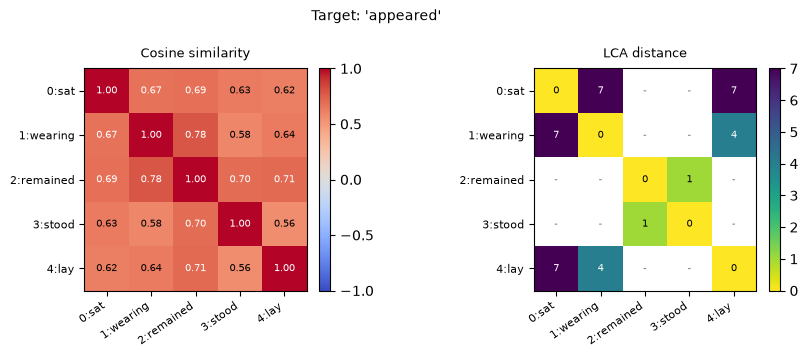


Context: 'The next morning, when he woke up, the ball was gone, but a little green creature appeared' | Target: 'beside'
Top-5        |   0:instead |    1:beside |     2:right |    3:inside |      4:near
----------------------------------------------------------------------------------
0:instead    |      1.0000 |      0.3489 |      0.4191 |      0.3855 |      0.4402
1:beside     |      0.3489 |      1.0000 |      0.6180 |      0.5812 |      0.7557
2:right      |      0.4191 |      0.6180 |      1.0000 |      0.5303 |      0.6999
3:inside     |      0.3855 |      0.5812 |      0.5303 |      1.0000 |      0.6202
4:near       |      0.4402 |      0.7557 |      0.6999 |      0.6202 |      1.0000


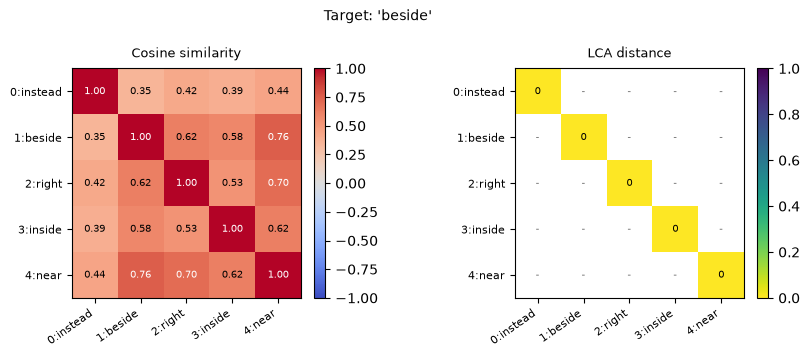

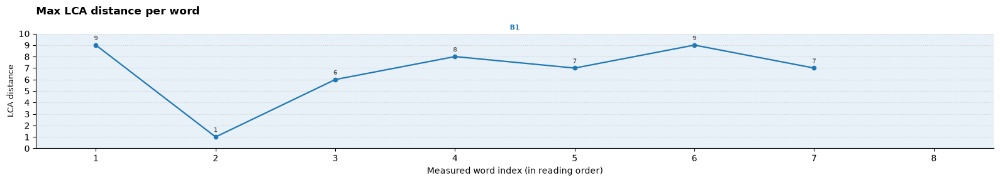

Ash named it Pikachu and taught it to use electricity. 
Context: 'Ash' | Target: 'named'
Top-5        |      0:ley |     1:ford |       2:ar |       3:er |     4:land
-----------------------------------------------------------------------------
0:ley        |     1.0000 |     0.4210 |     0.7016 |     0.6343 |     0.4188
1:ford       |     0.4210 |     1.0000 |     0.3908 |     0.3603 |     0.4187
2:ar         |     0.7016 |     0.3908 |     1.0000 |     0.5248 |     0.3897
3:er         |     0.6343 |     0.3603 |     0.5248 |     1.0000 |     0.3764
4:land       |     0.4188 |     0.4187 |     0.3897 |     0.3764 |     1.0000


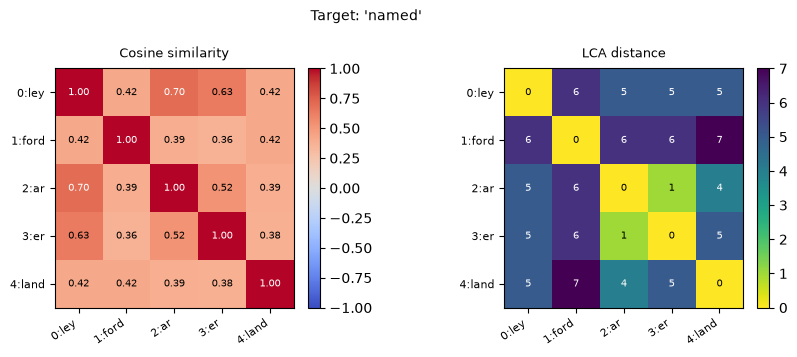


Context: 'Ash named it' | Target: 'Pikachu'
Top-5         |       0:first |     1:project |   2:something |           3:b |           4:g
---------------------------------------------------------------------------------------------
0:first       |        1.0000 |        0.5602 |        0.6415 |        0.4735 |        0.5476
1:project     |        0.5602 |        1.0000 |        0.7463 |        0.4754 |        0.5787
2:something   |        0.6415 |        0.7463 |        1.0000 |        0.5748 |        0.6802
3:b           |        0.4735 |        0.4754 |        0.5748 |        1.0000 |        0.7561
4:g           |        0.5476 |        0.5787 |        0.6802 |        0.7561 |        1.0000


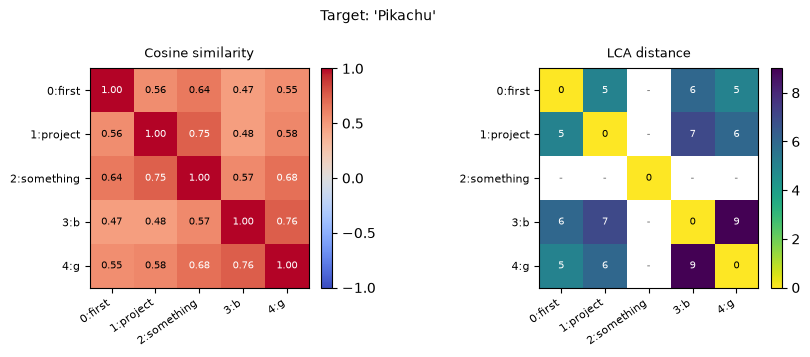


Context: 'Ash named it Pikachu and' | Target: 'taught'
Top-5        |      0:took |      1:gave |   2:brought |       3:put |   4:started
----------------------------------------------------------------------------------
0:took       |      1.0000 |      0.8190 |      0.8037 |      0.7661 |      0.7515
1:gave       |      0.8190 |      1.0000 |      0.8485 |      0.8180 |      0.7526
2:brought    |      0.8037 |      0.8485 |      1.0000 |      0.7976 |      0.7780
3:put        |      0.7661 |      0.8180 |      0.7976 |      1.0000 |      0.7436
4:started    |      0.7515 |      0.7526 |      0.7780 |      0.7436 |      1.0000


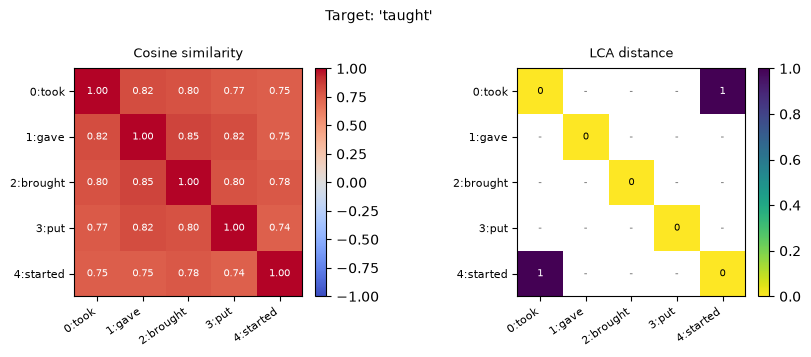


Context: 'Ash named it Pikachu and taught it to' | Target: 'use'
Top-5        |      0:use |   1:evolve |   2:attack |    3:fight |   4:battle
-----------------------------------------------------------------------------
0:use        |     1.0000 |     0.7004 |     0.7539 |     0.6222 |     0.6120
1:evolve     |     0.7004 |     1.0000 |     0.7712 |     0.7119 |     0.7017
2:attack     |     0.7539 |     0.7712 |     1.0000 |     0.7396 |     0.7129
3:fight      |     0.6222 |     0.7119 |     0.7396 |     1.0000 |     0.7621
4:battle     |     0.6120 |     0.7017 |     0.7129 |     0.7621 |     1.0000


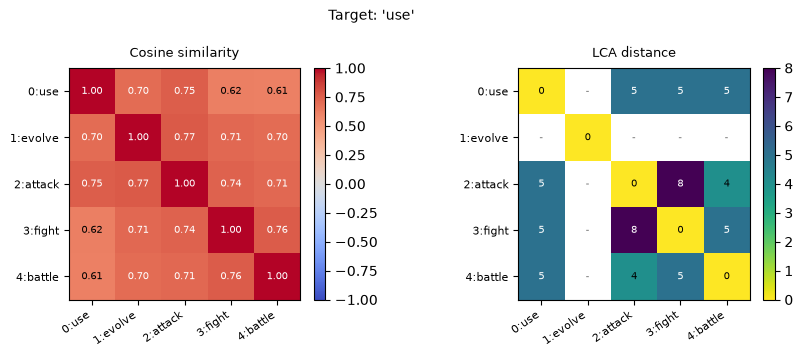


Context: 'Ash named it Pikachu and taught it to use' | Target: 'electricity.'
Top-5         |     0:thunder |          1:th |   2:lightning |       3:three |    4:multiple
---------------------------------------------------------------------------------------------
0:thunder     |        1.0000 |        0.4282 |        0.7047 |        0.5392 |        0.5890
1:th          |        0.4282 |        1.0000 |        0.5786 |        0.4439 |        0.5730
2:lightning   |        0.7047 |        0.5786 |        1.0000 |        0.6252 |        0.7655
3:three       |        0.5392 |        0.4439 |        0.6252 |        1.0000 |        0.5851
4:multiple    |        0.5890 |        0.5730 |        0.7655 |        0.5851 |        1.0000


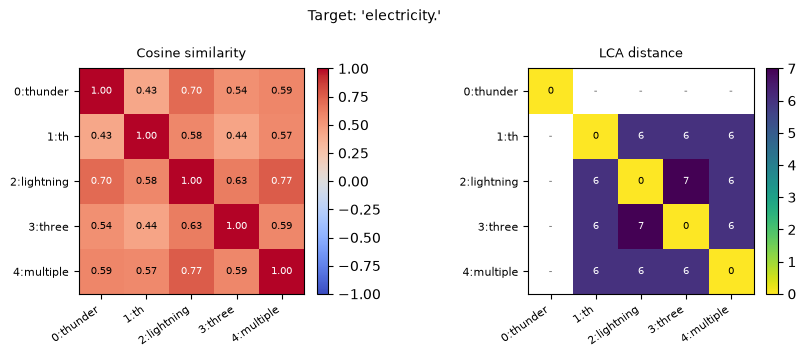

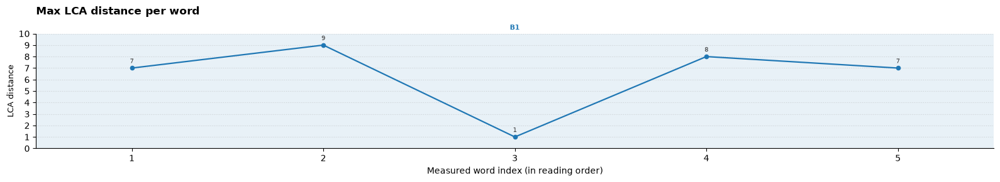

From that moment on, Pikachu became Ash's faithful companion and their adventures began. 
Context: 'From that' | Target: 'moment'
Top-5        |     0:time |      1:day |   2:moment |    3:point |    4:first
-----------------------------------------------------------------------------
0:time       |     1.0000 |     0.6264 |     0.8118 |     0.4798 |     0.6255
1:day        |     0.6264 |     1.0000 |     0.6464 |     0.4744 |     0.5405
2:moment     |     0.8118 |     0.6464 |     1.0000 |     0.4750 |     0.6082
3:point      |     0.4798 |     0.4744 |     0.4750 |     1.0000 |     0.4468
4:first      |     0.6255 |     0.5405 |     0.6082 |     0.4468 |     1.0000


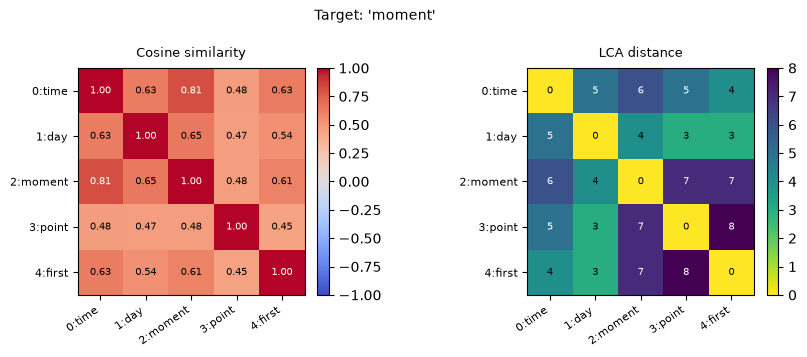


Context: 'From that moment on,' | Target: 'Pikachu'
Top-5          |   0:everything |         1:john |           2:mr |       3:things |     4:whenever
---------------------------------------------------------------------------------------------------
0:everything   |         1.0000 |         0.6392 |         0.6702 |         0.7847 |         0.7155
1:john         |         0.6392 |         1.0000 |         0.6716 |         0.5576 |         0.6947
2:mr           |         0.6702 |         0.6716 |         1.0000 |         0.5851 |         0.6971
3:things       |         0.7847 |         0.5576 |         0.5851 |         1.0000 |         0.6150
4:whenever     |         0.7155 |         0.6947 |         0.6971 |         0.6150 |         1.0000


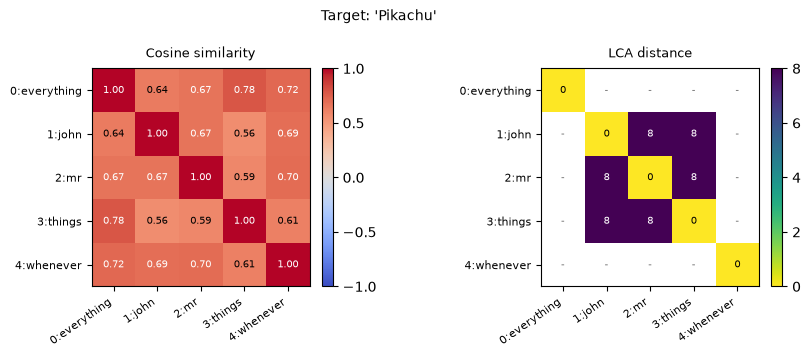


Context: 'From that moment on, Pikachu' | Target: 'became'
Top-5        |    0:became |     1:began |     2:never |   3:started |      4:felt
----------------------------------------------------------------------------------
0:became     |      1.0000 |      0.7927 |      0.7306 |      0.7396 |      0.7513
1:began      |      0.7927 |      1.0000 |      0.6683 |      0.8759 |      0.7178
2:never      |      0.7306 |      0.6683 |      1.0000 |      0.6777 |      0.6748
3:started    |      0.7396 |      0.8759 |      0.6777 |      1.0000 |      0.6941
4:felt       |      0.7513 |      0.7178 |      0.6748 |      0.6941 |      1.0000


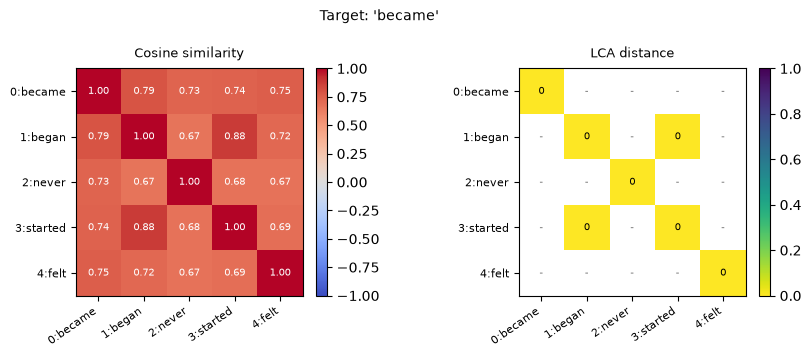


Context: 'From that moment on, Pikachu became' | Target: 'Ash's'
Top-5         |        0:inse |        1:part |   2:extremely |         3:ash |     4:friends
---------------------------------------------------------------------------------------------
0:inse        |        1.0000 |        0.5097 |        0.5215 |        0.4705 |        0.4690
1:part        |        0.5097 |        1.0000 |        0.4658 |        0.4196 |        0.3970
2:extremely   |        0.5215 |        0.4658 |        1.0000 |        0.6660 |        0.7173
3:ash         |        0.4705 |        0.4196 |        0.6660 |        1.0000 |        0.7161
4:friends     |        0.4690 |        0.3970 |        0.7173 |        0.7161 |        1.0000


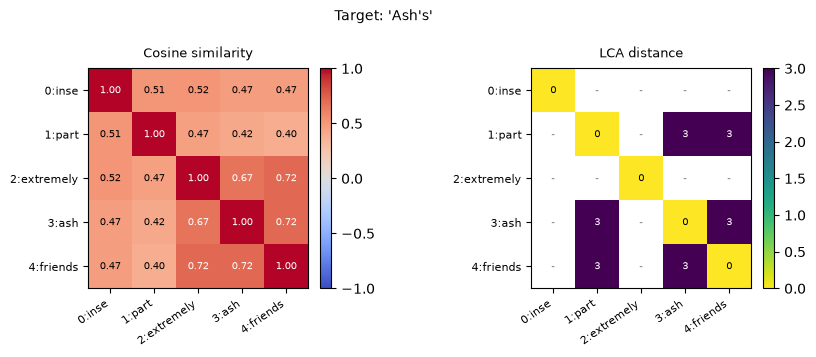


Context: 'From that moment on, Pikachu became Ash's' | Target: 'faithful'
Top-5         |    0:constant |        1:best |    2:faithful |     3:partner |   4:companion
---------------------------------------------------------------------------------------------
0:constant    |        1.0000 |        0.5355 |        0.6438 |        0.5756 |        0.4577
1:best        |        0.5355 |        1.0000 |        0.7065 |        0.6534 |        0.6550
2:faithful    |        0.6438 |        0.7065 |        1.0000 |        0.7204 |        0.6119
3:partner     |        0.5756 |        0.6534 |        0.7204 |        1.0000 |        0.7011
4:companion   |        0.4577 |        0.6550 |        0.6119 |        0.7011 |        1.0000


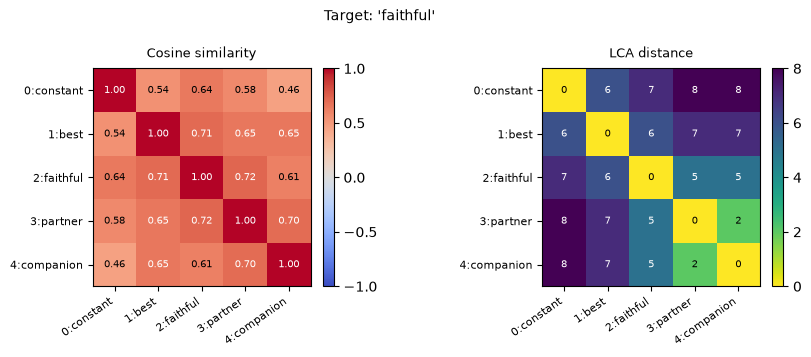


Context: 'From that moment on, Pikachu became Ash's faithful' | Target: 'companion'
Top-5         |   0:companion |     1:partner |        2:side |      3:friend |     4:pokémon
---------------------------------------------------------------------------------------------
0:companion   |        1.0000 |        0.7011 |        0.5190 |        0.6353 |        0.6077
1:partner     |        0.7011 |        1.0000 |        0.6217 |        0.8125 |        0.6852
2:side        |        0.5190 |        0.6217 |        1.0000 |        0.6502 |        0.5244
3:friend      |        0.6353 |        0.8125 |        0.6502 |        1.0000 |        0.6575
4:pokémon     |        0.6077 |        0.6852 |        0.5244 |        0.6575 |        1.0000


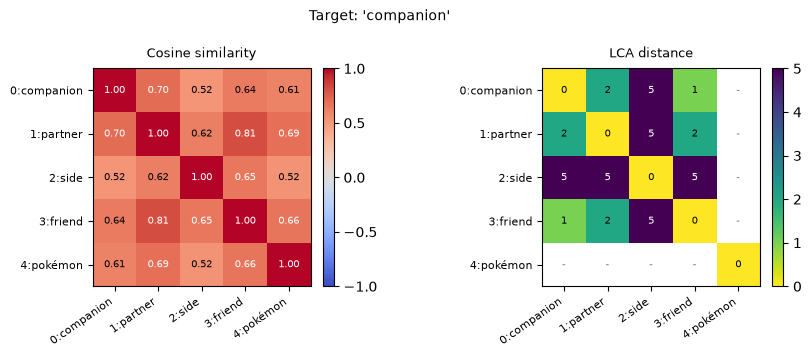


Context: 'From that moment on, Pikachu became Ash's faithful companion and their' | Target: 'adventures'
Top-5          |         0:bond |   1:adventures |      2:journey |   3:friendship |    4:adventure
---------------------------------------------------------------------------------------------------
0:bond         |         1.0000 |         0.5841 |         0.5624 |         0.5793 |         0.5609
1:adventures   |         0.5841 |         1.0000 |         0.8066 |         0.6907 |         0.8866
2:journey      |         0.5624 |         0.8066 |         1.0000 |         0.6743 |         0.8180
3:friendship   |         0.5793 |         0.6907 |         0.6743 |         1.0000 |         0.7147
4:adventure    |         0.5609 |         0.8866 |         0.8180 |         0.7147 |         1.0000


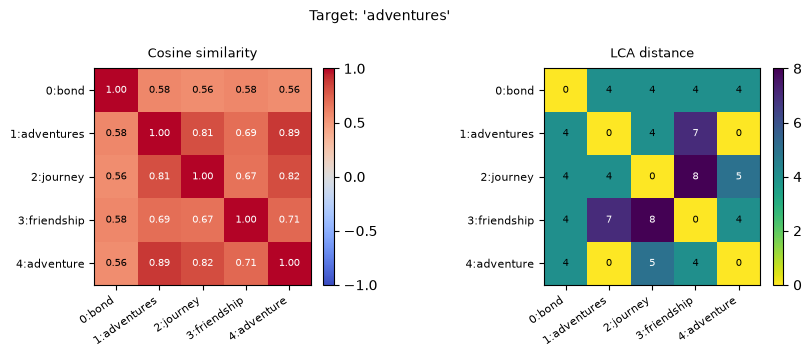


Context: 'From that moment on, Pikachu became Ash's faithful companion and their adventures' | Target: 'began.'
Top-5        |      0:began |   1:continue |        2:led |     3:became |       4:took
---------------------------------------------------------------------------------------
0:began      |       1.0000 |       0.7015 |       0.6870 |       0.7927 |       0.7754
1:continue   |       0.7015 |       1.0000 |       0.6156 |       0.6455 |       0.6351
2:led        |       0.6870 |       0.6156 |       1.0000 |       0.6970 |       0.7370
3:became     |       0.7927 |       0.6455 |       0.6970 |       1.0000 |       0.7684
4:took       |       0.7754 |       0.6351 |       0.7370 |       0.7684 |       1.0000


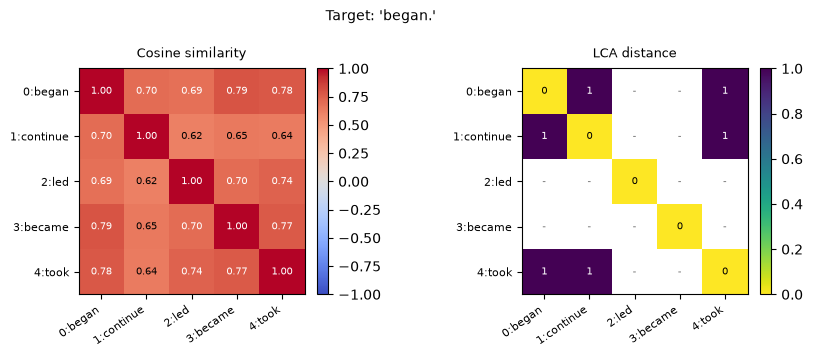

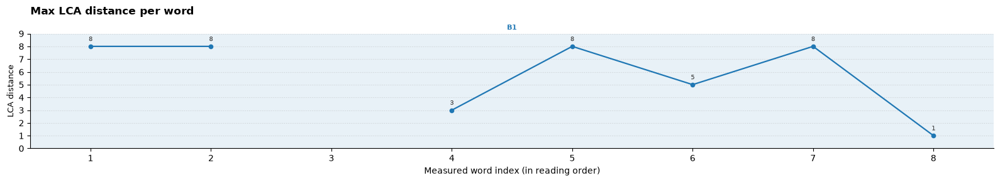

They went from village to village, facing challenges together. 
Context: 'They went from' | Target: 'village'
Top-5        |   0:strength |      1:house |       2:door |      3:place |       4:room
---------------------------------------------------------------------------------------
0:strength   |       1.0000 |       0.5204 |       0.5934 |       0.5651 |       0.6706
1:house      |       0.5204 |       1.0000 |       0.6830 |       0.6511 |       0.7272
2:door       |       0.5934 |       0.6830 |       1.0000 |       0.5995 |       0.7462
3:place      |       0.5651 |       0.6511 |       0.5995 |       1.0000 |       0.6880
4:room       |       0.6706 |       0.7272 |       0.7462 |       0.6880 |       1.0000


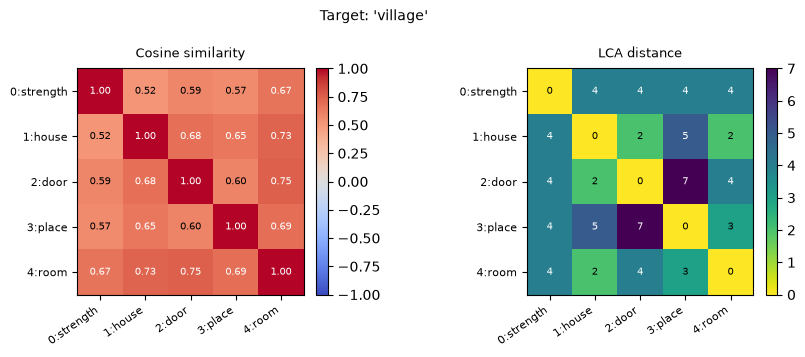


Context: 'They went from village to' | Target: 'village,'
Top-5        |   0:village |      1:town |         2:v |      3:city |      4:vill
----------------------------------------------------------------------------------
0:village    |      1.0000 |      0.5306 |      0.3064 |      0.4985 |      0.3164
1:town       |      0.5306 |      1.0000 |      0.4894 |      0.7824 |      0.4336
2:v          |      0.3064 |      0.4894 |      1.0000 |      0.5018 |      0.5982
3:city       |      0.4985 |      0.7824 |      0.5018 |      1.0000 |      0.4372
4:vill       |      0.3164 |      0.4336 |      0.5982 |      0.4372 |      1.0000


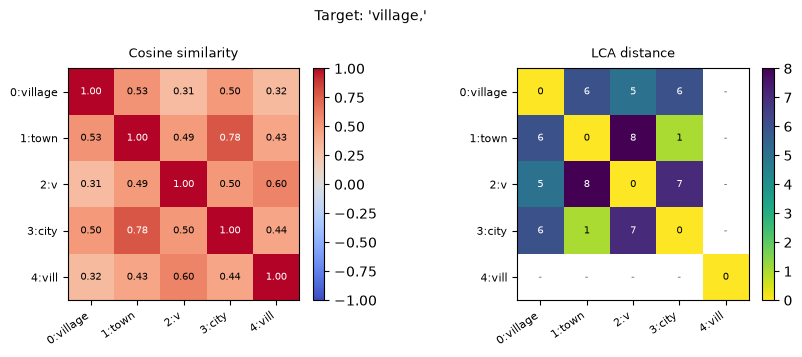


Context: 'They went from village to village,' | Target: 'facing'
Top-5          |    0:spreading |   1:performing |      2:telling |     3:teaching |      4:singing
---------------------------------------------------------------------------------------------------
0:spreading    |         1.0000 |         0.6534 |         0.9101 |         0.6318 |         0.5904
1:performing   |         0.6534 |         1.0000 |         0.6588 |         0.7426 |         0.7750
2:telling      |         0.9101 |         0.6588 |         1.0000 |         0.6393 |         0.6269
3:teaching     |         0.6318 |         0.7426 |         0.6393 |         1.0000 |         0.6939
4:singing      |         0.5904 |         0.7750 |         0.6269 |         0.6939 |         1.0000


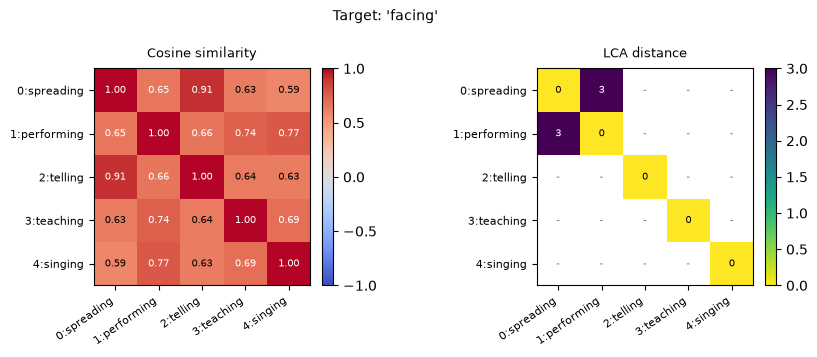


Context: 'They went from village to village, facing' | Target: 'challenges'
Top-5          |        0:great |       1:danger |      2:dangers |   3:challenges |    4:hardships
---------------------------------------------------------------------------------------------------
0:great        |         1.0000 |         0.6219 |         0.6292 |         0.4337 |         0.4202
1:danger       |         0.6219 |         1.0000 |         0.7593 |         0.5586 |         0.4852
2:dangers      |         0.6292 |         0.7593 |         1.0000 |         0.5819 |         0.4709
3:challenges   |         0.4337 |         0.5586 |         0.5819 |         1.0000 |         0.5500
4:hardships    |         0.4202 |         0.4852 |         0.4709 |         0.5500 |         1.0000


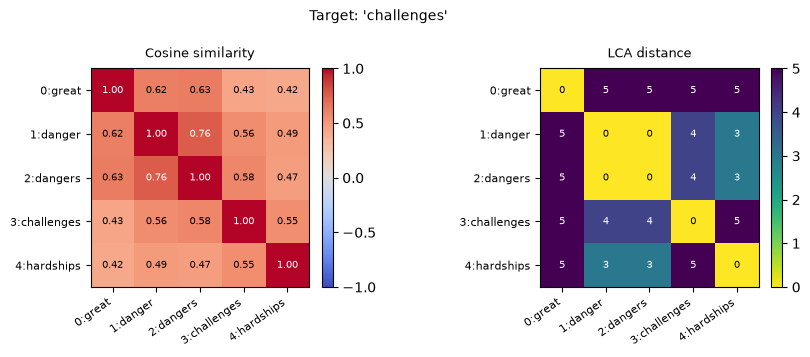

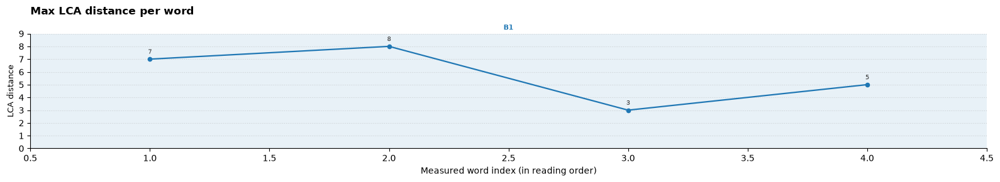

Pikachu proved to be more than just a cute mascot; it possessed incredible powers that made them unbeatable against any Pokémon trainer. 
Context: 'Pikachu proved to be more than just a cute' | Target: 'mascot;'
Top-5         |     0:pokémon |      1:little |     2:cartoon |      3:mascot |   4:character
---------------------------------------------------------------------------------------------
0:pokémon     |        1.0000 |        0.6204 |        0.7778 |        0.7018 |        0.6717
1:little      |        0.6204 |        1.0000 |        0.6618 |        0.6198 |        0.5929
2:cartoon     |        0.7778 |        0.6618 |        1.0000 |        0.7808 |        0.6989
3:mascot      |        0.7018 |        0.6198 |        0.7808 |        1.0000 |        0.6259
4:character   |        0.6717 |        0.5929 |        0.6989 |        0.6259 |        1.0000


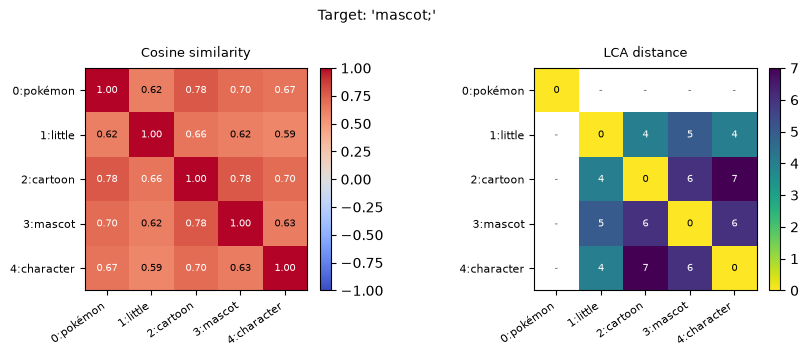


Context: 'Pikachu proved to be more than just a cute mascot; it possessed incredible' | Target: 'powers'
Top-5         |       0:power |      1:powers |    2:strength |   3:abilities |    4:electric
---------------------------------------------------------------------------------------------
0:power       |        1.0000 |        0.7951 |        0.8346 |        0.8172 |        0.6145
1:powers      |        0.7951 |        1.0000 |        0.6704 |        0.9051 |        0.5559
2:strength    |        0.8346 |        0.6704 |        1.0000 |        0.7276 |        0.5141
3:abilities   |        0.8172 |        0.9051 |        0.7276 |        1.0000 |        0.5590
4:electric    |        0.6145 |        0.5559 |        0.5141 |        0.5590 |        1.0000


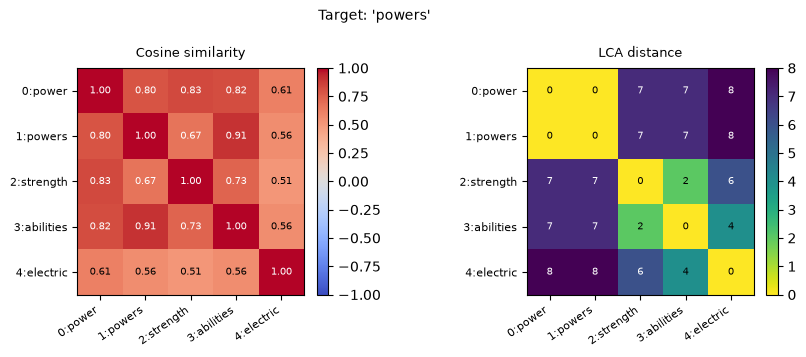


Context: 'Pikachu proved to be more than just a cute mascot; it possessed incredible powers that made them unbeatable against any' | Target: 'Pokémon'
Top-5        |   0:opponent |        1:foe |      2:enemy |    3:pokémon |      4:rival
---------------------------------------------------------------------------------------
0:opponent   |       1.0000 |       0.5814 |       0.7247 |       0.5469 |       0.6028
1:foe        |       0.5814 |       1.0000 |       0.6923 |       0.6291 |       0.8377
2:enemy      |       0.7247 |       0.6923 |       1.0000 |       0.6346 |       0.6882
3:pokémon    |       0.5469 |       0.6291 |       0.6346 |       1.0000 |       0.7421
4:rival      |       0.6028 |       0.8377 |       0.6882 |       0.7421 |       1.0000


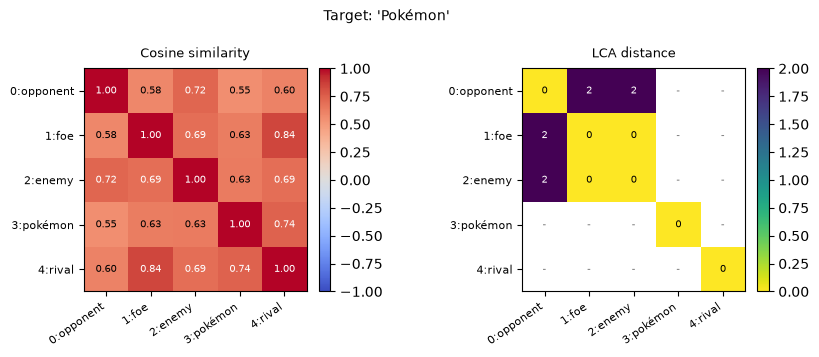


Context: 'Pikachu proved to be more than just a cute mascot; it possessed incredible powers that made them unbeatable against any Pokémon' | Target: 'trainer.'
Top-5         |    0:opponent |     1:trainer |   2:opponents |      3:battle |       4:rival
---------------------------------------------------------------------------------------------
0:opponent    |        1.0000 |        0.6286 |        0.8383 |        0.5912 |        0.6028
1:trainer     |        0.6286 |        1.0000 |        0.5772 |        0.5593 |        0.5724
2:opponents   |        0.8383 |        0.5772 |        1.0000 |        0.5078 |        0.5139
3:battle      |        0.5912 |        0.5593 |        0.5078 |        1.0000 |        0.7619
4:rival       |        0.6028 |        0.5724 |        0.5139 |        0.7619 |        1.0000


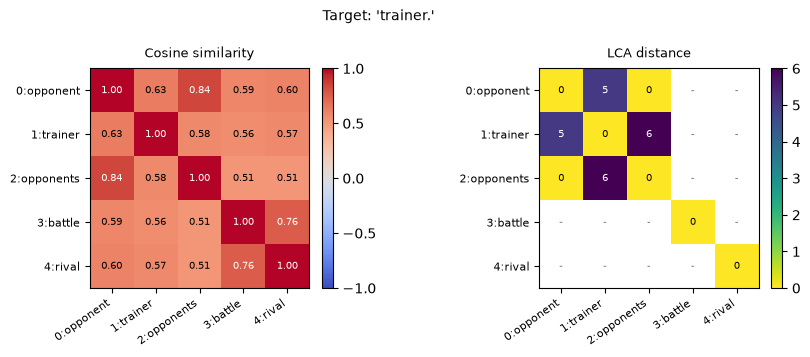

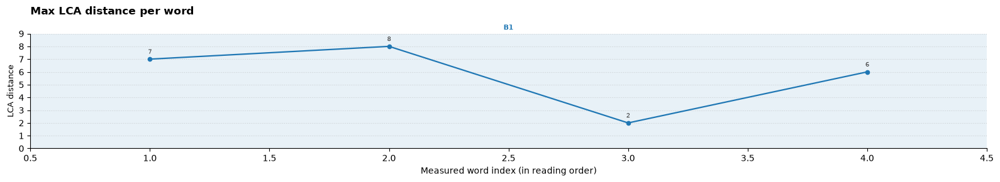

Ash learned not just how to battle, but also the true meaning of friendship and courage. 
Context: 'Ash learned not just how to' | Target: 'battle,'
Top-5        |     0:read |     1:play |     2:cook |     3:ride |    4:write
-----------------------------------------------------------------------------
0:read       |     1.0000 |     0.6768 |     0.6609 |     0.7054 |     0.7988
1:play       |     0.6768 |     1.0000 |     0.5935 |     0.6094 |     0.5987
2:cook       |     0.6609 |     0.5935 |     1.0000 |     0.7501 |     0.6528
3:ride       |     0.7054 |     0.6094 |     0.7501 |     1.0000 |     0.6466
4:write      |     0.7988 |     0.5987 |     0.6528 |     0.6466 |     1.0000


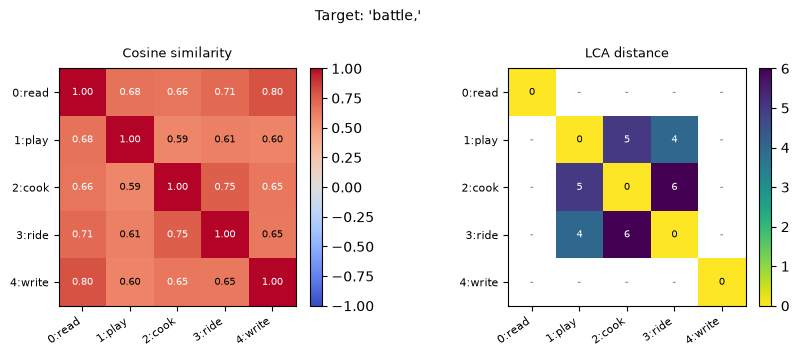


Context: 'Ash learned not just how to battle, but also the' | Target: 'true'
Top-5          |   0:importance |        1:value |          2:art |        3:rules |      4:history
---------------------------------------------------------------------------------------------------
0:importance   |         1.0000 |         0.7234 |         0.6594 |         0.7287 |         0.5664
1:value        |         0.7234 |         1.0000 |         0.5880 |         0.7063 |         0.4493
2:art          |         0.6594 |         0.5880 |         1.0000 |         0.6834 |         0.6071
3:rules        |         0.7287 |         0.7063 |         0.6834 |         1.0000 |         0.5434
4:history      |         0.5664 |         0.4493 |         0.6071 |         0.5434 |         1.0000


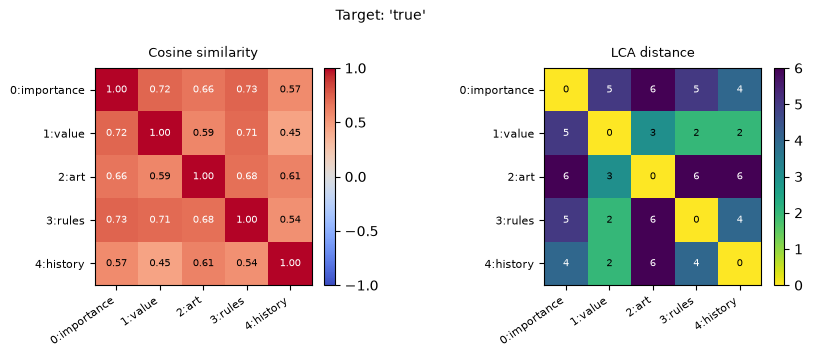


Context: 'Ash learned not just how to battle, but also the true' | Target: 'meaning'
Top-5        |   0:meaning |     1:value |      2:cost |    3:nature |     4:power
----------------------------------------------------------------------------------
0:meaning    |      1.0000 |      0.7706 |      0.6180 |      0.5478 |      0.6895
1:value      |      0.7706 |      1.0000 |      0.7176 |      0.5116 |      0.7179
2:cost       |      0.6180 |      0.7176 |      1.0000 |      0.5388 |      0.7009
3:nature     |      0.5478 |      0.5116 |      0.5388 |      1.0000 |      0.6398
4:power      |      0.6895 |      0.7179 |      0.7009 |      0.6398 |      1.0000


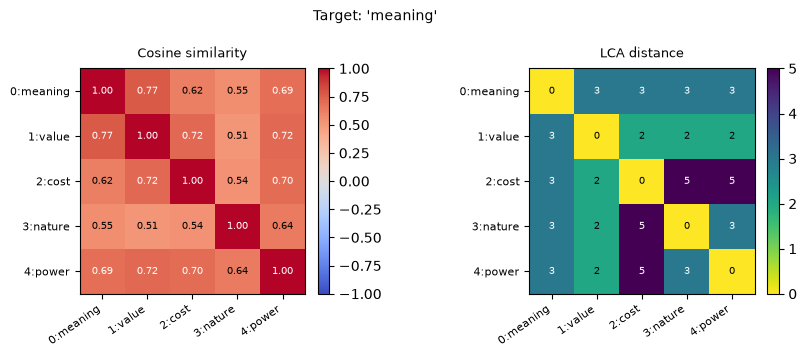


Context: 'Ash learned not just how to battle, but also the true meaning of' | Target: 'friendship'
Top-5          |         0:love |   1:friendship |      2:courage |        3:honor |      4:bravery
---------------------------------------------------------------------------------------------------
0:love         |         1.0000 |         0.6670 |         0.5272 |         0.5767 |         0.5270
1:friendship   |         0.6670 |         1.0000 |         0.6582 |         0.6665 |         0.7195
2:courage      |         0.5272 |         0.6582 |         1.0000 |         0.5066 |         0.8277
3:honor        |         0.5767 |         0.6665 |         0.5066 |         1.0000 |         0.6504
4:bravery      |         0.5270 |         0.7195 |         0.8277 |         0.6504 |         1.0000


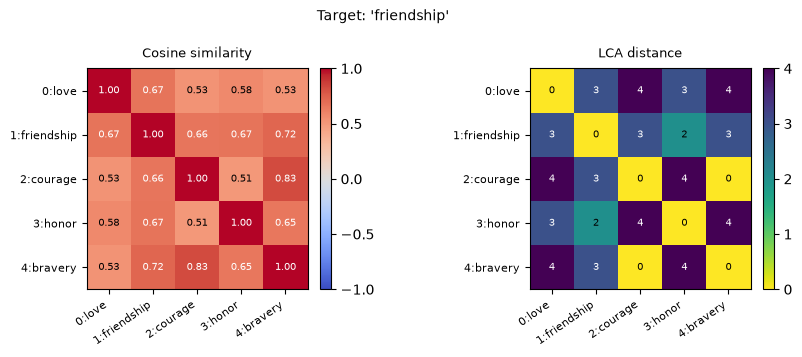


Context: 'Ash learned not just how to battle, but also the true meaning of friendship and' | Target: 'courage.'
Top-5         |     0:loyalty |       1:trust |        2:love |      3:family |   4:sacrifice
---------------------------------------------------------------------------------------------
0:loyalty     |        1.0000 |        0.7561 |        0.6566 |        0.7155 |        0.7264
1:trust       |        0.7561 |        1.0000 |        0.7283 |        0.6751 |        0.6772
2:love        |        0.6566 |        0.7283 |        1.0000 |        0.6279 |        0.6080
3:family      |        0.7155 |        0.6751 |        0.6279 |        1.0000 |        0.7188
4:sacrifice   |        0.7264 |        0.6772 |        0.6080 |        0.7188 |        1.0000


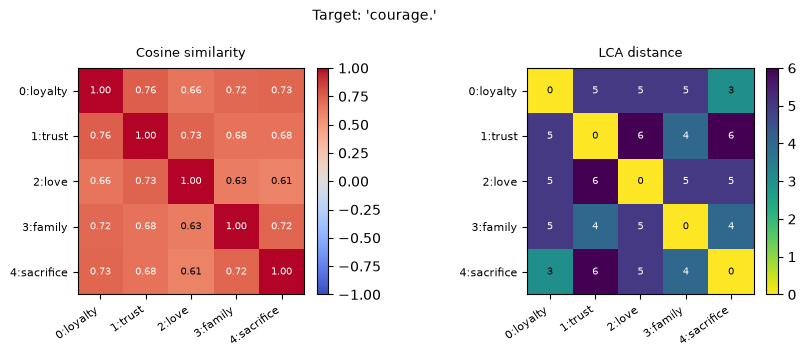

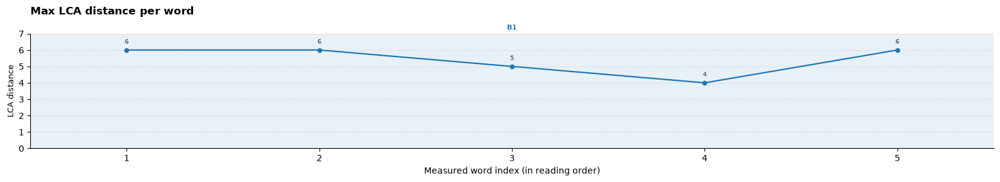

With each victory, they grew stronger, proving that even the smallest person could achieve greatness if they believed in themselves.
Context: 'With each' | Target: 'victory,'
Top-5        |   0:passing |      1:step |       2:day |   3:episode |      4:roll
----------------------------------------------------------------------------------
0:passing    |      1.0000 |      0.6126 |      0.5747 |      0.5458 |      0.7036
1:step       |      0.6126 |      1.0000 |      0.5621 |      0.5515 |      0.6575
2:day        |      0.5747 |      0.5621 |      1.0000 |      0.5580 |      0.5224
3:episode    |      0.5458 |      0.5515 |      0.5580 |      1.0000 |      0.4845
4:roll       |      0.7036 |      0.6575 |      0.5224 |      0.4845 |      1.0000


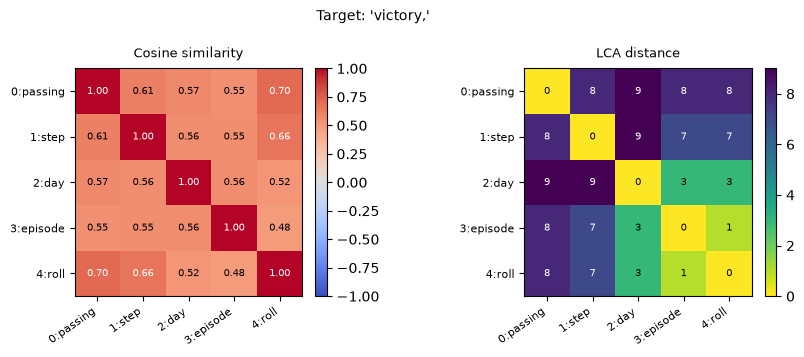


Context: 'With each victory, they' | Target: 'grew'
Top-5        |      0:gain |      1:earn |   2:advance |    3:become |       4:add
----------------------------------------------------------------------------------
0:gain       |      1.0000 |      0.8309 |      0.6172 |      0.7290 |      0.6385
1:earn       |      0.8309 |      1.0000 |      0.6567 |      0.7981 |      0.6910
2:advance    |      0.6172 |      0.6567 |      1.0000 |      0.5118 |      0.5714
3:become     |      0.7290 |      0.7981 |      0.5118 |      1.0000 |      0.6585
4:add        |      0.6385 |      0.6910 |      0.5714 |      0.6585 |      1.0000


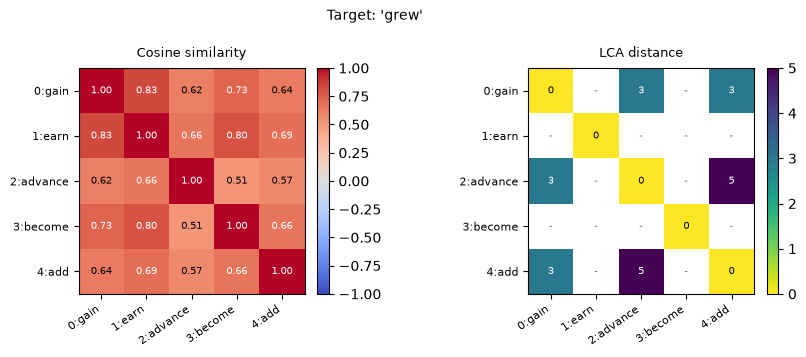


Context: 'With each victory, they grew' | Target: 'stronger,'
Top-5            |       0:stronger |         1:closer |              2:b |           3:ever |   4:increasingly
---------------------------------------------------------------------------------------------------------------
0:stronger       |           1.0000 |           0.7409 |           0.5374 |           0.5547 |           0.7841
1:closer         |           0.7409 |           1.0000 |           0.4299 |           0.5630 |           0.7269
2:b              |           0.5374 |           0.4299 |           1.0000 |           0.4619 |           0.4940
3:ever           |           0.5547 |           0.5630 |           0.4619 |           1.0000 |           0.6198
4:increasingly   |           0.7841 |           0.7269 |           0.4940 |           0.6198 |           1.0000


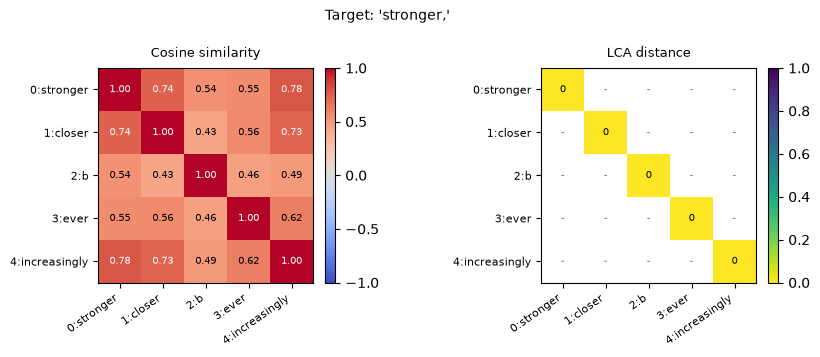


Context: 'With each victory, they grew stronger,' | Target: 'proving'
Top-5        |    0:gaining |   1:building |     2:making |   3:learning |        4:hon
---------------------------------------------------------------------------------------
0:gaining    |       1.0000 |       0.5917 |       0.8438 |       0.7427 |       0.4208
1:building   |       0.5917 |       1.0000 |       0.6364 |       0.5923 |       0.3767
2:making     |       0.8438 |       0.6364 |       1.0000 |       0.8268 |       0.3768
3:learning   |       0.7427 |       0.5923 |       0.8268 |       1.0000 |       0.3294
4:hon        |       0.4208 |       0.3767 |       0.3768 |       0.3294 |       1.0000


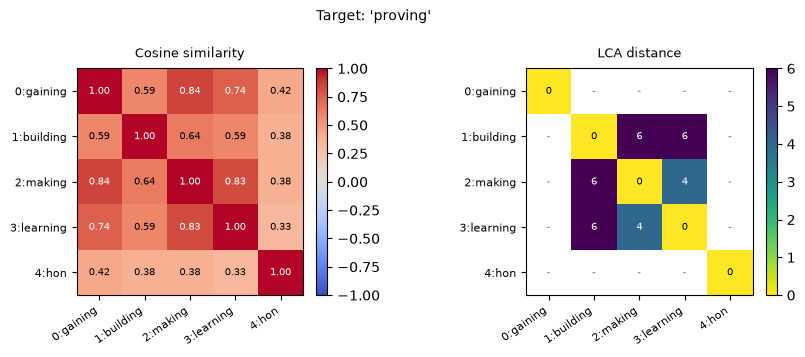


Context: 'With each victory, they grew stronger, proving that even the' | Target: 'smallest'
Top-5        |   0:smallest |    1:weakest |   2:toughest |       3:odds |    4:darkest
---------------------------------------------------------------------------------------
0:smallest   |       1.0000 |       0.5981 |       0.5197 |       0.5413 |       0.8989
1:weakest    |       0.5981 |       1.0000 |       0.7832 |       0.5603 |       0.6115
2:toughest   |       0.5197 |       0.7832 |       1.0000 |       0.5508 |       0.5500
3:odds       |       0.5413 |       0.5603 |       0.5508 |       1.0000 |       0.5983
4:darkest    |       0.8989 |       0.6115 |       0.5500 |       0.5983 |       1.0000


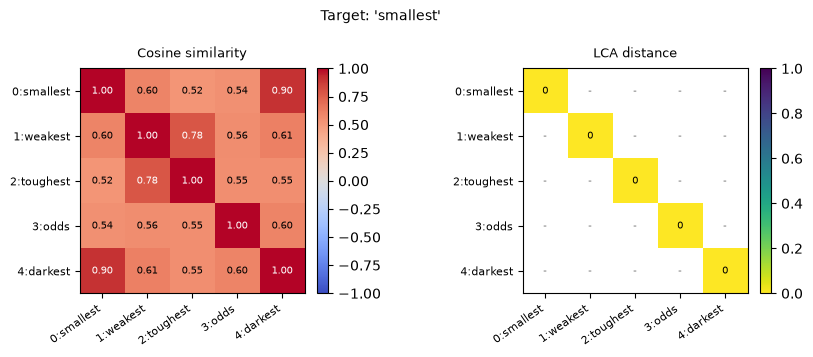


Context: 'With each victory, they grew stronger, proving that even the smallest' | Target: 'person'
Top-5        |     0:seed |    1:spark |    2:among |    3:seeds |       4:pe
-----------------------------------------------------------------------------
0:seed       |     1.0000 |     0.7057 |     0.5737 |     0.8601 |     0.5133
1:spark      |     0.7057 |     1.0000 |     0.6618 |     0.5625 |     0.4546
2:among      |     0.5737 |     0.6618 |     1.0000 |     0.5281 |     0.4238
3:seeds      |     0.8601 |     0.5625 |     0.5281 |     1.0000 |     0.4679
4:pe         |     0.5133 |     0.4546 |     0.4238 |     0.4679 |     1.0000


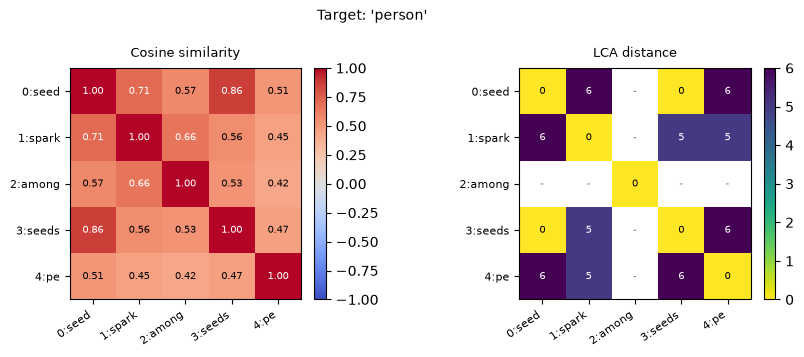


Context: 'With each victory, they grew stronger, proving that even the smallest person could' | Target: 'achieve'
Top-5         |      0:change |   1:challenge |        2:show |       3:cause |      4:become
---------------------------------------------------------------------------------------------
0:change      |        1.0000 |        0.6276 |        0.6019 |        0.6075 |        0.6252
1:challenge   |        0.6276 |        1.0000 |        0.7029 |        0.6177 |        0.6017
2:show        |        0.6019 |        0.7029 |        1.0000 |        0.6219 |        0.5782
3:cause       |        0.6075 |        0.6177 |        0.6219 |        1.0000 |        0.7508
4:become      |        0.6252 |        0.6017 |        0.5782 |        0.7508 |        1.0000


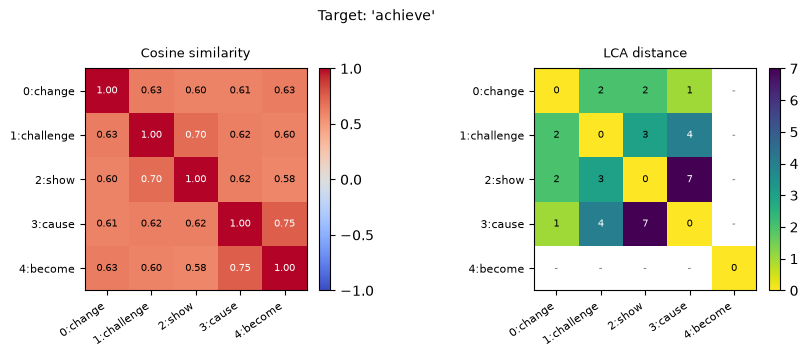


Context: 'With each victory, they grew stronger, proving that even the smallest person could achieve' | Target: 'greatness'
Top-5          |        0:great |    1:something |    2:greatness |   3:impossible |     4:miracles
---------------------------------------------------------------------------------------------------
0:great        |         1.0000 |         0.6476 |         0.5706 |         0.6669 |         0.4103
1:something    |         0.6476 |         1.0000 |         0.6122 |         0.7729 |         0.5426
2:greatness    |         0.5706 |         0.6122 |         1.0000 |         0.5681 |         0.6091
3:impossible   |         0.6669 |         0.7729 |         0.5681 |         1.0000 |         0.5320
4:miracles     |         0.4103 |         0.5426 |         0.6091 |         0.5320 |         1.0000


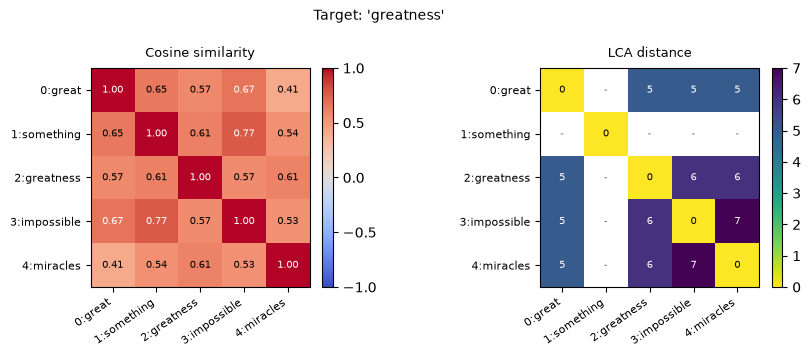


Context: 'With each victory, they grew stronger, proving that even the smallest person could achieve greatness if they' | Target: 'believed'
Top-5        |        0:set |   1:believed |     2:worked |      3:dared |       4:knew
---------------------------------------------------------------------------------------
0:set        |       1.0000 |       0.5923 |       0.5889 |       0.5559 |       0.4879
1:believed   |       0.5923 |       1.0000 |       0.7059 |       0.7640 |       0.6632
2:worked     |       0.5889 |       0.7059 |       1.0000 |       0.7073 |       0.7228
3:dared      |       0.5559 |       0.7640 |       0.7073 |       1.0000 |       0.7224
4:knew       |       0.4879 |       0.6632 |       0.7228 |       0.7224 |       1.0000


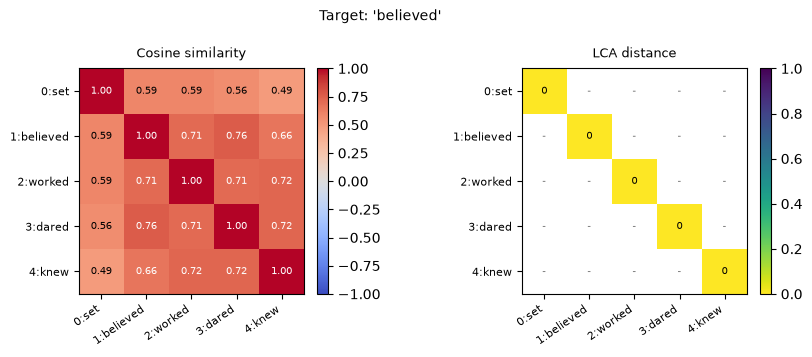

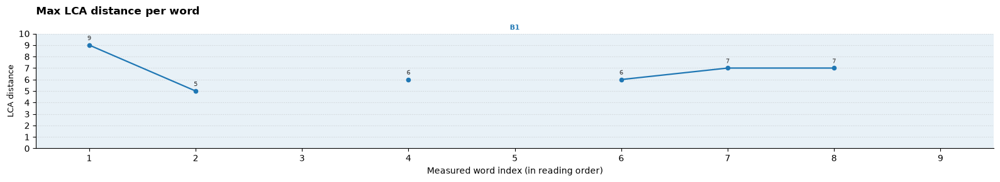


--- Full Generated Text ---
Ash Ketchum was just an ordinary boy with big dreams and a love for adventure. One day, while exploring a dense forest near his hometown, he stumbled upon a mysterious glowing ball in a puddle. It sparkled like nothing he had ever seen before. The next morning, when he woke up, the ball was gone, but a little green creature appeared beside him. Ash named it Pikachu and taught it to use electricity. From that moment on, Pikachu became Ash's faithful companion and their adventures began. They went from village to village, facing challenges together. Pikachu proved to be more than just a cute mascot; it possessed incredible powers that made them unbeatable against any Pokémon trainer. Ash learned not just how to battle, but also the true meaning of friendship and courage. With each victory, they grew stronger, proving that even the smallest person could achieve greatness if they believed in themselves. 

--- Blocks ---
Block 1: Ash Ketchum was just an ordinary

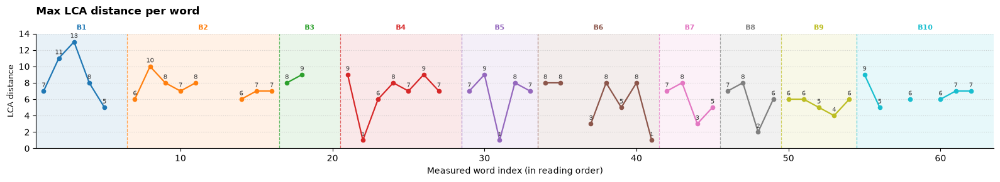

In [37]:
prompt = "Ash Ketchum get his first pokemon"
all_blocks, all_distances = stream_and_analyze(model_1_5b,tokenizer_1_5b,prompt,"creative",model_7b,tokenizer_7b)

print("\n--- Full Generated Text ---")
for block in all_blocks:
    print(block, end=" ")

print("\n\n--- Blocks ---")
for i, block in enumerate(all_blocks, 1):
    print(f"Block {i}: {block}")
    
fig = plot_lca_curve(all_distances, title="Max LCA distance per word", blocks_per_row=12, show_values=True)
fig.tight_layout()
plt.show()
plt.close(fig)

# Quantum Theory

Quantum theory is a fundamental framework in physics that describes the behavior of matter and energy at the atomic and subatomic level. 
Context: '#' | Target: 'Quantum'
Top-5          |       0:coding |    1:copyright |   2:definition |            3:c |       4:python
---------------------------------------------------------------------------------------------------
0:coding       |         1.0000 |         0.5653 |         0.7461 |         0.5892 |         0.7136
1:copyright    |         0.5653 |         1.0000 |         0.5062 |         0.3751 |         0.5566
2:definition   |         0.7461 |         0.5062 |         1.0000 |         0.5121 |         0.7143
3:c            |         0.5892 |         0.3751 |         0.5121 |         1.0000 |         0.5555
4:python       |         0.7136 |         0.5566 |         0.7143 |         0.5555 |         1.0000


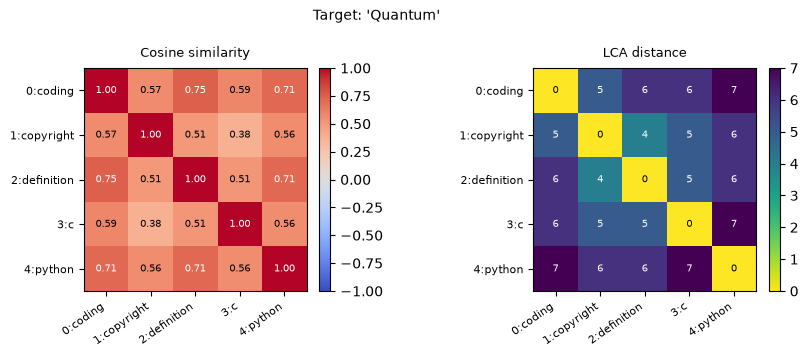


Context: '# Quantum' | Target: 'Theory'
Top-5           |     0:computing |     1:mechanics |   2:information |       3:physics |       4:algebra
---------------------------------------------------------------------------------------------------------
0:computing     |          1.0000 |          0.7139 |          0.5718 |          0.7344 |          0.6025
1:mechanics     |          0.7139 |          1.0000 |          0.4836 |          0.8826 |          0.6074
2:information   |          0.5718 |          0.4836 |          1.0000 |          0.5376 |          0.6888
3:physics       |          0.7344 |          0.8826 |          0.5376 |          1.0000 |          0.5924
4:algebra       |          0.6025 |          0.6074 |          0.6888 |          0.5924 |          1.0000


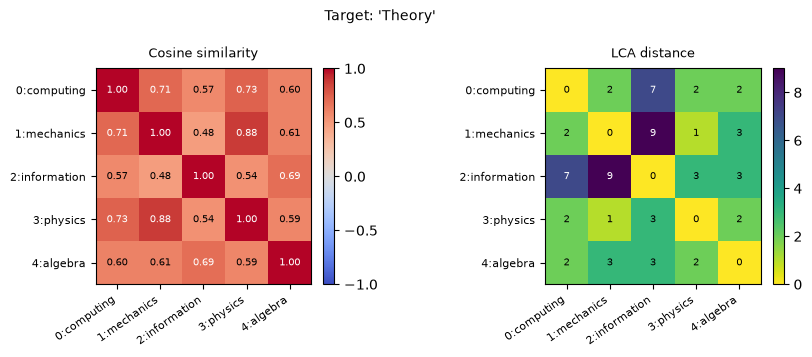


Context: '# Quantum Theory' | Target: 'Quantum'
Top-5         |          0:ii |           1:n |   2:questions |     3:without |     4:seminar
---------------------------------------------------------------------------------------------
0:ii          |        1.0000 |        0.5049 |        0.5321 |        0.5973 |        0.5036
1:n           |        0.5049 |        1.0000 |        0.5856 |        0.6664 |        0.4457
2:questions   |        0.5321 |        0.5856 |        1.0000 |        0.7025 |        0.6146
3:without     |        0.5973 |        0.6664 |        0.7025 |        1.0000 |        0.5383
4:seminar     |        0.5036 |        0.4457 |        0.6146 |        0.5383 |        1.0000


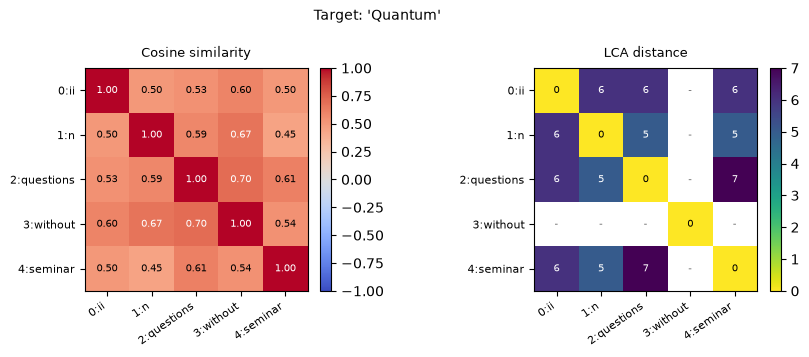


Context: '# Quantum Theory Quantum' | Target: 'theory'
Top-5           |        0:theory |     1:mechanics |       2:physics |     3:computing |   4:information
---------------------------------------------------------------------------------------------------------
0:theory        |          1.0000 |          0.8576 |          0.8066 |          0.7122 |          0.4986
1:mechanics     |          0.8576 |          1.0000 |          0.8826 |          0.7139 |          0.4836
2:physics       |          0.8066 |          0.8826 |          1.0000 |          0.7344 |          0.5376
3:computing     |          0.7122 |          0.7139 |          0.7344 |          1.0000 |          0.5718
4:information   |          0.4986 |          0.4836 |          0.5376 |          0.5718 |          1.0000


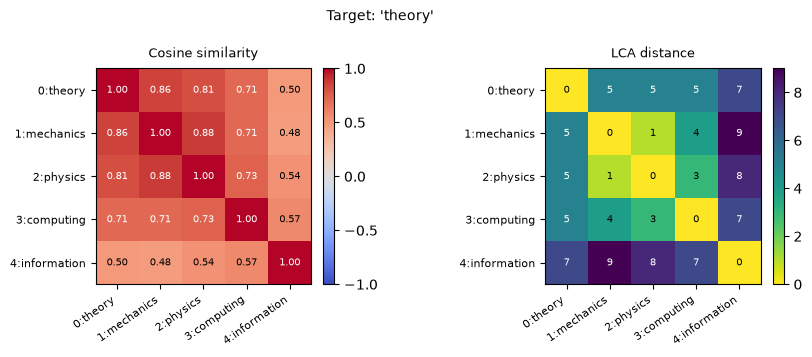


Context: '# Quantum Theory Quantum theory is a' | Target: 'fundamental'
Top-5           |        0:theory |        1:branch |   2:fundamental |           3:set |   4:description
---------------------------------------------------------------------------------------------------------
0:theory        |          1.0000 |          0.7047 |          0.7812 |          0.5541 |          0.5282
1:branch        |          0.7047 |          1.0000 |          0.7423 |          0.5948 |          0.4471
2:fundamental   |          0.7812 |          0.7423 |          1.0000 |          0.5335 |          0.4722
3:set           |          0.5541 |          0.5948 |          0.5335 |          1.0000 |          0.3134
4:description   |          0.5282 |          0.4471 |          0.4722 |          0.3134 |          1.0000


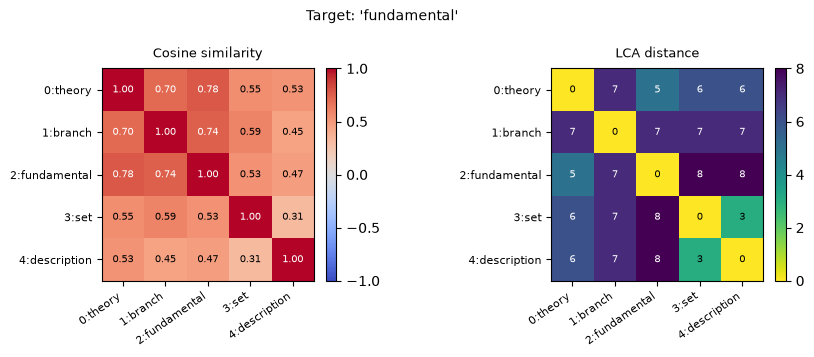


Context: '# Quantum Theory Quantum theory is a fundamental' | Target: 'framework'
Top-5           |        0:theory |     1:framework |          2:part |   3:description |        4:branch
---------------------------------------------------------------------------------------------------------
0:theory        |          1.0000 |          0.7888 |          0.4859 |          0.5282 |          0.7047
1:framework     |          0.7888 |          1.0000 |          0.4468 |          0.4485 |          0.7401
2:part          |          0.4859 |          0.4468 |          1.0000 |          0.2987 |          0.5045
3:description   |          0.5282 |          0.4485 |          0.2987 |          1.0000 |          0.4471
4:branch        |          0.7047 |          0.7401 |          0.5045 |          0.4471 |          1.0000


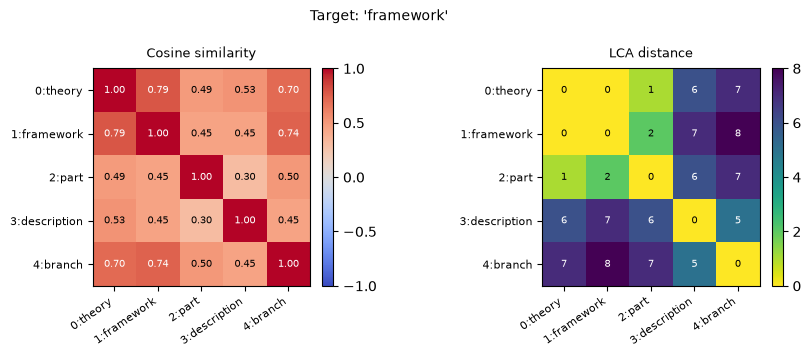


Context: '# Quantum Theory Quantum theory is a fundamental framework in' | Target: 'physics'
Top-5            |        0:physics |         1:modern |        2:science |   3:contemporary |    4:mathematics
---------------------------------------------------------------------------------------------------------------
0:physics        |           1.0000 |           0.5817 |           0.7396 |           0.5316 |           0.6641
1:modern         |           0.5817 |           1.0000 |           0.5397 |           0.8482 |           0.4589
2:science        |           0.7396 |           0.5397 |           1.0000 |           0.4639 |           0.5182
3:contemporary   |           0.5316 |           0.8482 |           0.4639 |           1.0000 |           0.4285
4:mathematics    |           0.6641 |           0.4589 |           0.5182 |           0.4285 |           1.0000


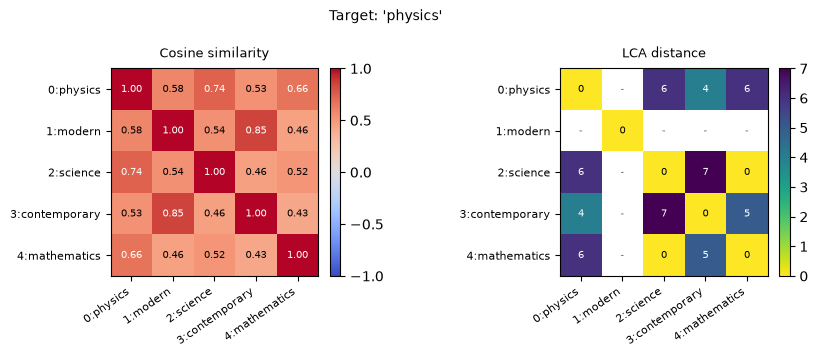


Context: '# Quantum Theory Quantum theory is a fundamental framework in physics that' | Target: 'describes'
Top-5         |   0:describes |    1:explains |    2:provides |    3:attempts |       4:deals
---------------------------------------------------------------------------------------------
0:describes   |        1.0000 |        0.8772 |        0.7226 |        0.7664 |        0.7373
1:explains    |        0.8772 |        1.0000 |        0.6526 |        0.7356 |        0.7371
2:provides    |        0.7226 |        0.6526 |        1.0000 |        0.6093 |        0.6237
3:attempts    |        0.7664 |        0.7356 |        0.6093 |        1.0000 |        0.7578
4:deals       |        0.7373 |        0.7371 |        0.6237 |        0.7578 |        1.0000


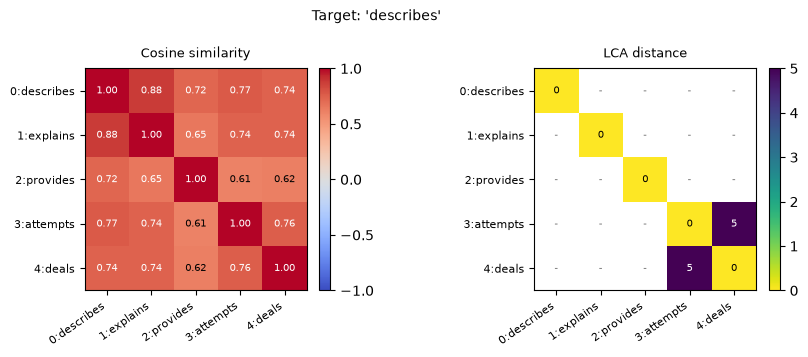


Context: '# Quantum Theory Quantum theory is a fundamental framework in physics that describes the' | Target: 'behavior'
Top-5            |       0:behavior |         1:nature |     2:properties |      3:behaviors |   4:interactions
---------------------------------------------------------------------------------------------------------------
0:behavior       |           1.0000 |           0.6455 |           0.8350 |           0.8739 |           0.7758
1:nature         |           0.6455 |           1.0000 |           0.6208 |           0.5664 |           0.5996
2:properties     |           0.8350 |           0.6208 |           1.0000 |           0.8100 |           0.7982
3:behaviors      |           0.8739 |           0.5664 |           0.8100 |           1.0000 |           0.7828
4:interactions   |           0.7758 |           0.5996 |           0.7982 |           0.7828 |           1.0000


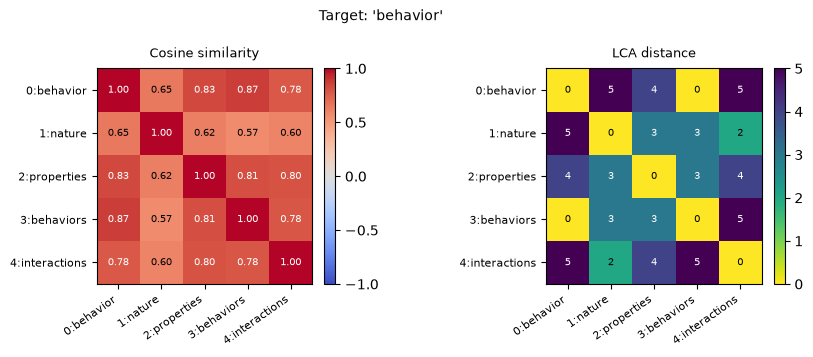


Context: '# Quantum Theory Quantum theory is a fundamental framework in physics that describes the behavior of' | Target: 'matter'
Top-5         |      0:matter |   1:particles |      2:nature |      3:energy |       4:small
---------------------------------------------------------------------------------------------
0:matter      |        1.0000 |        0.7714 |        0.5923 |        0.7972 |        0.6767
1:particles   |        0.7714 |        1.0000 |        0.5805 |        0.7752 |        0.6715
2:nature      |        0.5923 |        0.5805 |        1.0000 |        0.6458 |        0.5360
3:energy      |        0.7972 |        0.7752 |        0.6458 |        1.0000 |        0.6704
4:small       |        0.6767 |        0.6715 |        0.5360 |        0.6704 |        1.0000


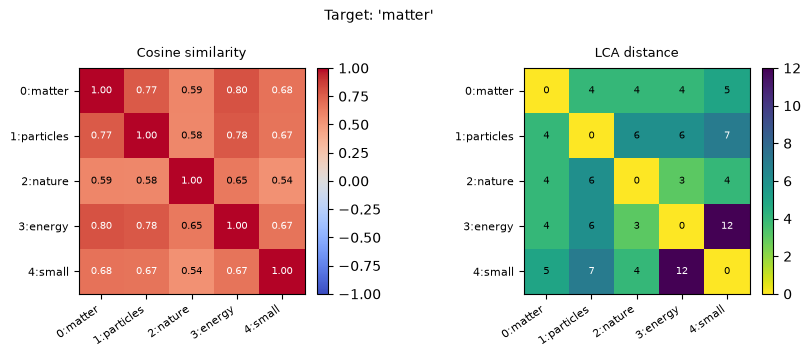


Context: '# Quantum Theory Quantum theory is a fundamental framework in physics that describes the behavior of matter and' | Target: 'energy'
Top-5         |      0:energy |       1:light |   2:radiation |      3:fields |    4:electrom
---------------------------------------------------------------------------------------------
0:energy      |        1.0000 |        0.7712 |        0.7821 |        0.7944 |        0.5782
1:light       |        0.7712 |        1.0000 |        0.6642 |        0.6979 |        0.4570
2:radiation   |        0.7821 |        0.6642 |        1.0000 |        0.7675 |        0.6157
3:fields      |        0.7944 |        0.6979 |        0.7675 |        1.0000 |        0.4708
4:electrom    |        0.5782 |        0.4570 |        0.6157 |        0.4708 |        1.0000


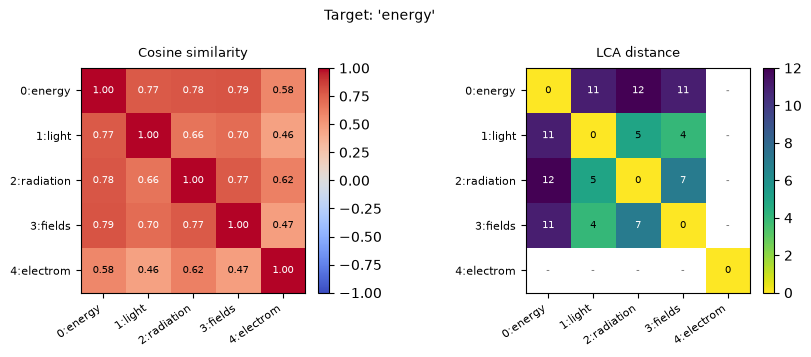


Context: '# Quantum Theory Quantum theory is a fundamental framework in physics that describes the behavior of matter and energy at the atomic and subatomic' | Target: 'level.'
Top-5        |      0:level |     1:scales |      2:scale |     3:levels |   4:particle
---------------------------------------------------------------------------------------
0:level      |       1.0000 |       0.6340 |       0.6213 |       0.7340 |       0.5593
1:scales     |       0.6340 |       1.0000 |       0.8148 |       0.6406 |       0.7541
2:scale      |       0.6213 |       0.8148 |       1.0000 |       0.5843 |       0.6750
3:levels     |       0.7340 |       0.6406 |       0.5843 |       1.0000 |       0.4831
4:particle   |       0.5593 |       0.7541 |       0.6750 |       0.4831 |       1.0000


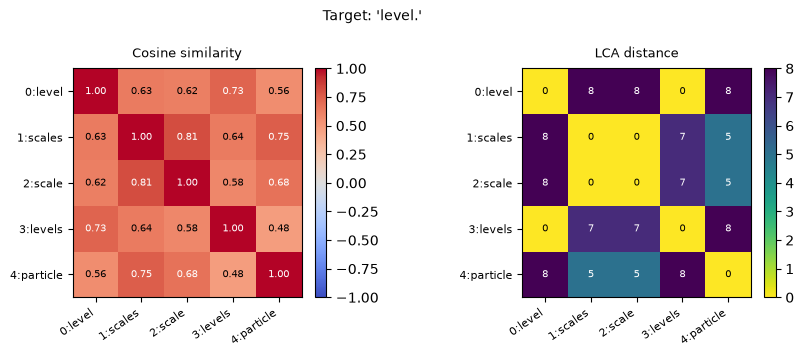

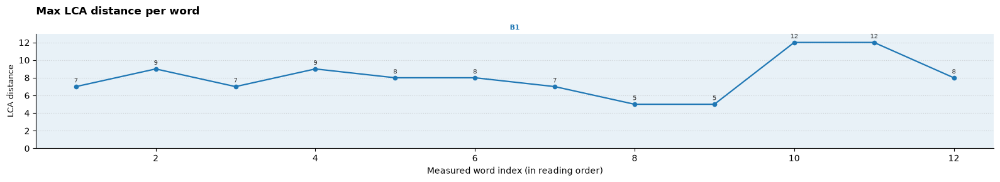

It was developed primarily to explain the results of experiments involving particles like electrons and photons.


Context: 'It was developed' | Target: 'primarily'
Top-5             |           0:using |    1:specifically |          2:around |       3:primarily |   4:independently
---------------------------------------------------------------------------------------------------------------------
0:using           |            1.0000 |            0.7090 |            0.5899 |            0.7095 |            0.7441
1:specifically    |            0.7090 |            1.0000 |            0.7148 |            0.8859 |            0.7707
2:around          |            0.5899 |            0.7148 |            1.0000 |            0.7647 |            0.7292
3:primarily       |            0.7095 |            0.8859 |            0.7647 |            1.0000 |            0.8093
4:independently   |            0.7441 |            0.7707 |            0.7292 |            0.8093 |            1.0000


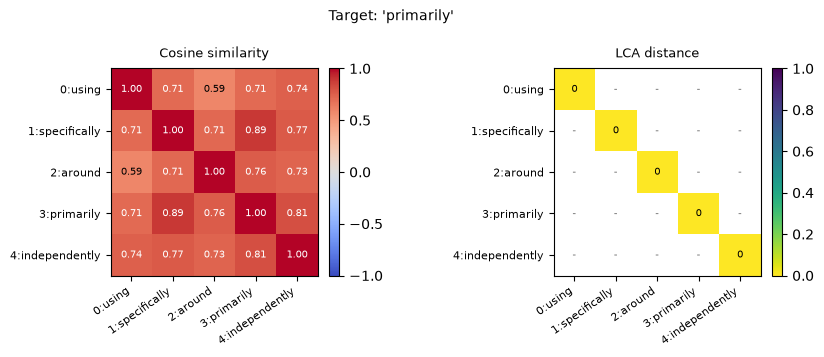


Context: 'It was developed primarily to' | Target: 'explain'
Top-5        |   0:support |   1:provide |   2:address |      3:help |      4:meet
----------------------------------------------------------------------------------
0:support    |      1.0000 |      0.7901 |      0.7492 |      0.7569 |      0.6437
1:provide    |      0.7901 |      1.0000 |      0.7305 |      0.7271 |      0.6548
2:address    |      0.7492 |      0.7305 |      1.0000 |      0.7719 |      0.7522
3:help       |      0.7569 |      0.7271 |      0.7719 |      1.0000 |      0.7453
4:meet       |      0.6437 |      0.6548 |      0.7522 |      0.7453 |      1.0000


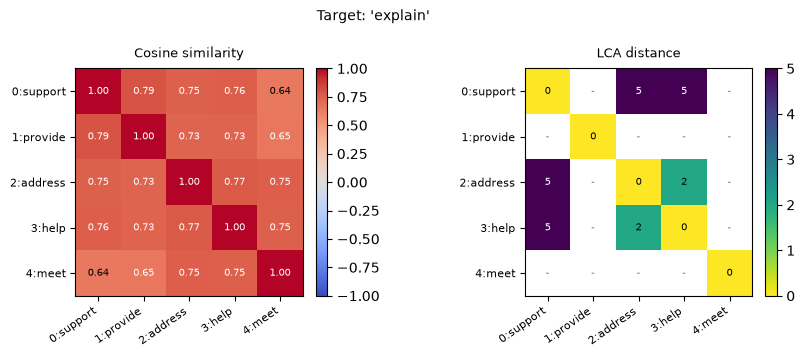


Context: 'It was developed primarily to explain the' | Target: 'results'
Top-5            |       0:behavior |   1:relationship |     2:phenomenon |      3:mechanism |      4:existence
---------------------------------------------------------------------------------------------------------------
0:behavior       |           1.0000 |           0.7855 |           0.8092 |           0.8113 |           0.7388
1:relationship   |           0.7855 |           1.0000 |           0.7166 |           0.7208 |           0.7256
2:phenomenon     |           0.8092 |           0.7166 |           1.0000 |           0.8686 |           0.7846
3:mechanism      |           0.8113 |           0.7208 |           0.8686 |           1.0000 |           0.7901
4:existence      |           0.7388 |           0.7256 |           0.7846 |           0.7901 |           1.0000


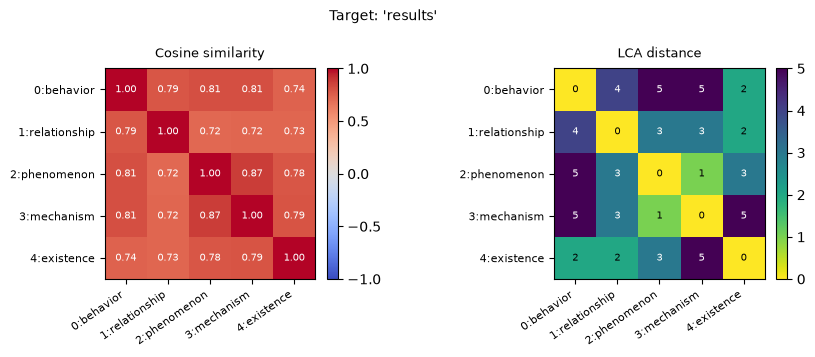


Context: 'It was developed primarily to explain the results of' | Target: 'experiments'
Top-5            |    0:experiments |   1:observations |   2:measurements |         3:recent |        4:studies
---------------------------------------------------------------------------------------------------------------
0:experiments    |           1.0000 |           0.7840 |           0.8007 |           0.6842 |           0.7629
1:observations   |           0.7840 |           1.0000 |           0.7715 |           0.6368 |           0.6902
2:measurements   |           0.8007 |           0.7715 |           1.0000 |           0.6025 |           0.7239
3:recent         |           0.6842 |           0.6368 |           0.6025 |           1.0000 |           0.7255
4:studies        |           0.7629 |           0.6902 |           0.7239 |           0.7255 |           1.0000


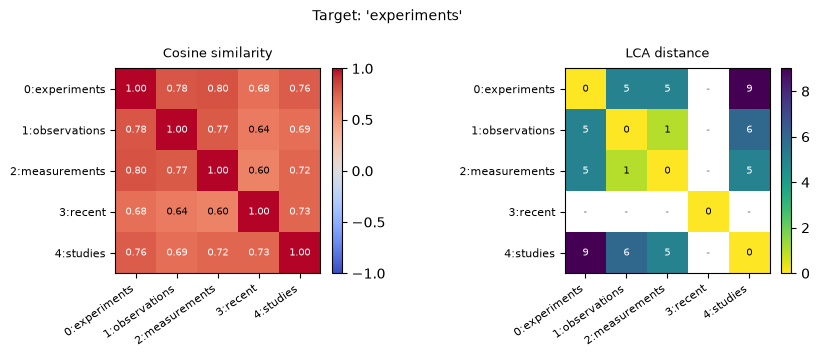


Context: 'It was developed primarily to explain the results of experiments' | Target: 'involving'
Top-5         |   0:involving |     1:carried |   2:performed |   3:conducted |       4:using
---------------------------------------------------------------------------------------------
0:involving   |        1.0000 |        0.8415 |        0.4597 |        0.4908 |        0.7086
1:carried     |        0.8415 |        1.0000 |        0.5280 |        0.5277 |        0.6664
2:performed   |        0.4597 |        0.5280 |        1.0000 |        0.7493 |        0.4511
3:conducted   |        0.4908 |        0.5277 |        0.7493 |        1.0000 |        0.4683
4:using       |        0.7086 |        0.6664 |        0.4511 |        0.4683 |        1.0000


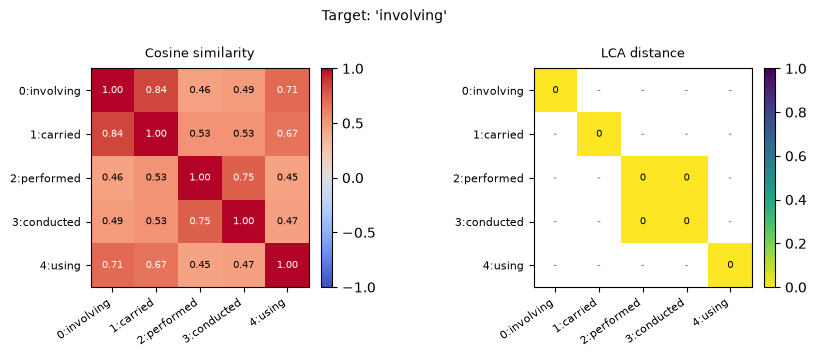


Context: 'It was developed primarily to explain the results of experiments involving' | Target: 'particles'
Top-5            |   0:measurements |     1:collisions |           2:high |        3:changes |          4:light
---------------------------------------------------------------------------------------------------------------
0:measurements   |           1.0000 |           0.5973 |           0.4560 |           0.5121 |           0.5776
1:collisions     |           0.5973 |           1.0000 |           0.4566 |           0.3686 |           0.6089
2:high           |           0.4560 |           0.4566 |           1.0000 |           0.3181 |           0.5211
3:changes        |           0.5121 |           0.3686 |           0.3181 |           1.0000 |           0.4674
4:light          |           0.5776 |           0.6089 |           0.5211 |           0.4674 |           1.0000


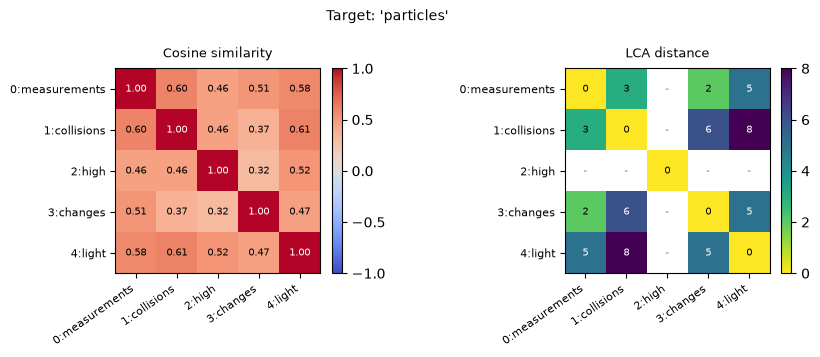


Context: 'It was developed primarily to explain the results of experiments involving particles like' | Target: 'electrons'
Top-5         |   0:electrons |         1:pro |        2:neut |          3:mu |           4:p
---------------------------------------------------------------------------------------------
0:electrons   |        1.0000 |        0.6505 |        0.5424 |        0.7361 |        0.4194
1:pro         |        0.6505 |        1.0000 |        0.5877 |        0.7707 |        0.4588
2:neut        |        0.5424 |        0.5877 |        1.0000 |        0.6215 |        0.4608
3:mu          |        0.7361 |        0.7707 |        0.6215 |        1.0000 |        0.4857
4:p           |        0.4194 |        0.4588 |        0.4608 |        0.4857 |        1.0000


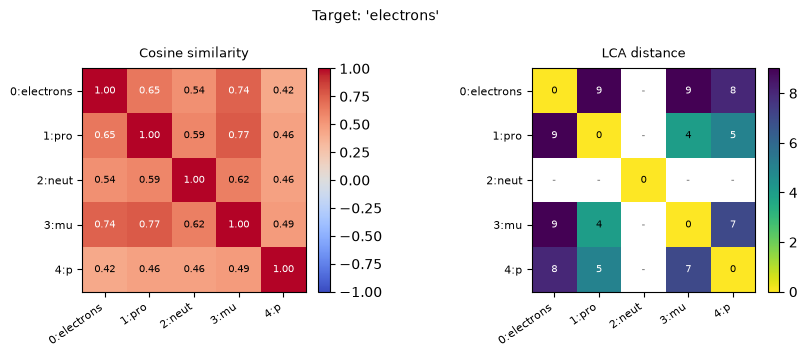


Context: 'It was developed primarily to explain the results of experiments involving particles like electrons and' | Target: 'photons.'
Top-5        |   0:photons |       1:pro |      2:neut |        3:mu |     4:light
----------------------------------------------------------------------------------
0:photons    |      1.0000 |      0.4820 |      0.4405 |      0.4971 |      0.5787
1:pro        |      0.4820 |      1.0000 |      0.5877 |      0.7707 |      0.5626
2:neut       |      0.4405 |      0.5877 |      1.0000 |      0.6215 |      0.5127
3:mu         |      0.4971 |      0.7707 |      0.6215 |      1.0000 |      0.6359
4:light      |      0.5787 |      0.5626 |      0.5127 |      0.6359 |      1.0000


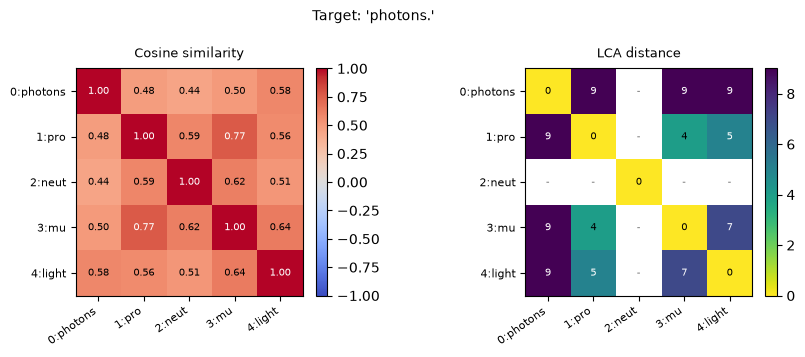

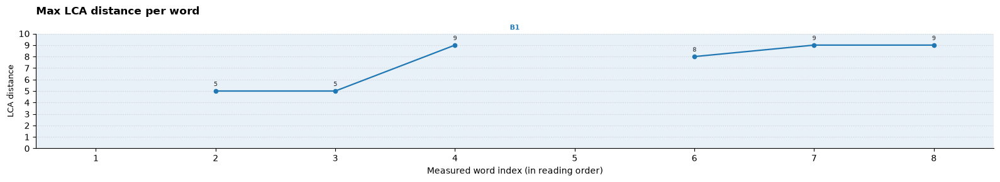

The core concept of quantum mechanics is that at the smallest scales, particles do not exist as definite positions or speeds but rather as probabilities. 
Context: 'The' | Target: 'core'
Top-5         |   0:following |         1:sum |      2:purple |    3:function |      4:number
---------------------------------------------------------------------------------------------
0:following   |        1.0000 |        0.5209 |        0.5680 |        0.4828 |        0.5987
1:sum         |        0.5209 |        1.0000 |        0.5980 |        0.6384 |        0.6528
2:purple      |        0.5680 |        0.5980 |        1.0000 |        0.5516 |        0.7352
3:function    |        0.4828 |        0.6384 |        0.5516 |        1.0000 |        0.6338
4:number      |        0.5987 |        0.6528 |        0.7352 |        0.6338 |        1.0000


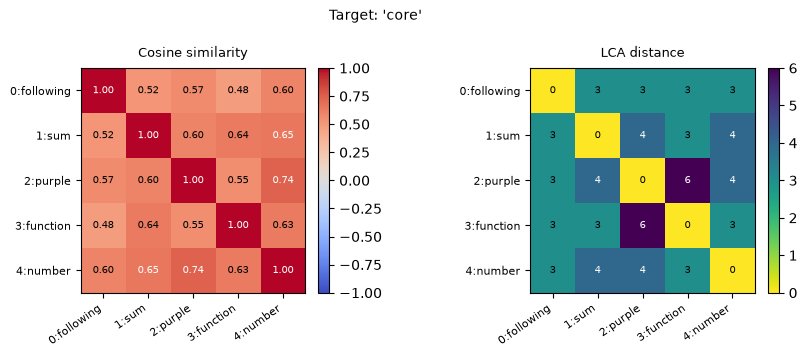


Context: 'The core' | Target: 'concept'
Top-5         |     0:content |     1:concept |      2:values |   3:principle |   4:component
---------------------------------------------------------------------------------------------
0:content     |        1.0000 |        0.7104 |        0.6275 |        0.6624 |        0.7101
1:concept     |        0.7104 |        1.0000 |        0.5952 |        0.8124 |        0.7779
2:values      |        0.6275 |        0.5952 |        1.0000 |        0.6463 |        0.6833
3:principle   |        0.6624 |        0.8124 |        0.6463 |        1.0000 |        0.7874
4:component   |        0.7101 |        0.7779 |        0.6833 |        0.7874 |        1.0000


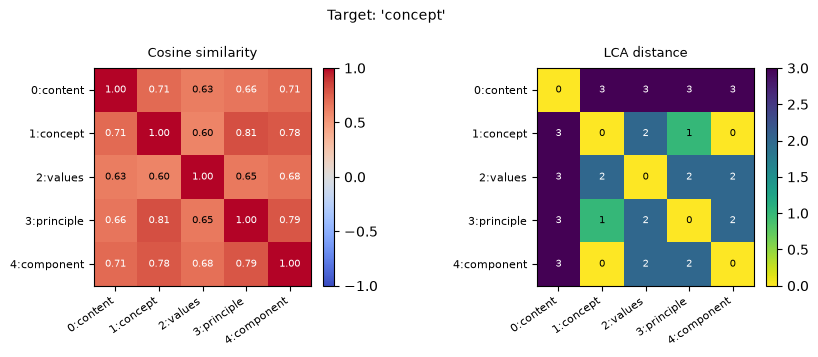


Context: 'The core concept of' | Target: 'quantum'
Top-5        |     0:lean |    1:total |    2:china |    3:green |   4:modern
-----------------------------------------------------------------------------
0:lean       |     1.0000 |     0.3495 |     0.5680 |     0.4731 |     0.5794
1:total      |     0.3495 |     1.0000 |     0.3734 |     0.5384 |     0.3995
2:china      |     0.5680 |     0.3734 |     1.0000 |     0.4447 |     0.5037
3:green      |     0.4731 |     0.5384 |     0.4447 |     1.0000 |     0.4483
4:modern     |     0.5794 |     0.3995 |     0.5037 |     0.4483 |     1.0000


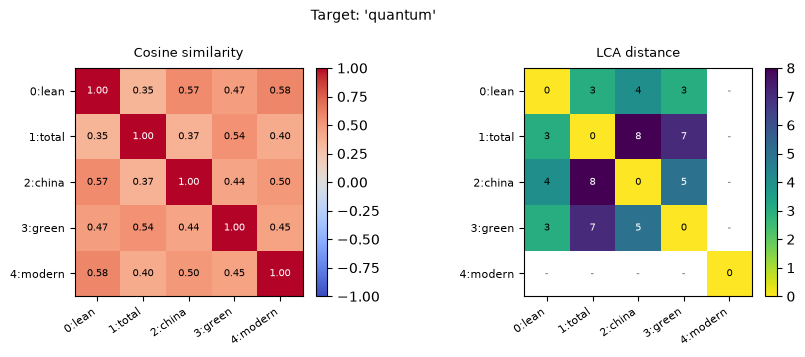


Context: 'The core concept of quantum' | Target: 'mechanics'
Top-5            |      0:mechanics |      1:computing |    2:information |   3:cryptography |          4:field
---------------------------------------------------------------------------------------------------------------
0:mechanics      |           1.0000 |           0.7139 |           0.4836 |           0.6237 |           0.6241
1:computing      |           0.7139 |           1.0000 |           0.5718 |           0.5868 |           0.6281
2:information    |           0.4836 |           0.5718 |           1.0000 |           0.3880 |           0.5330
3:cryptography   |           0.6237 |           0.5868 |           0.3880 |           1.0000 |           0.4575
4:field          |           0.6241 |           0.6281 |           0.5330 |           0.4575 |           1.0000


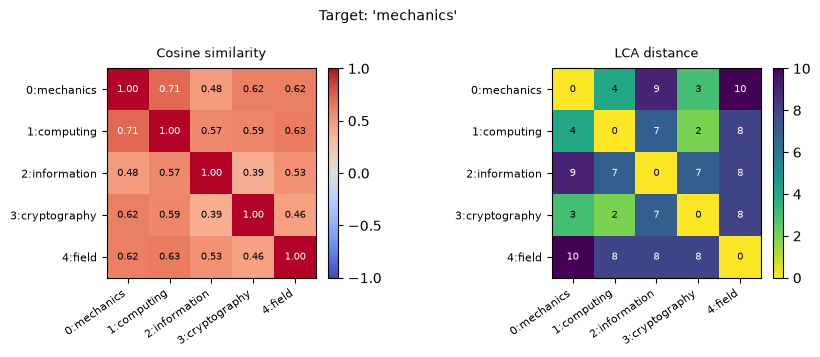


Context: 'The core concept of quantum mechanics is that at the' | Target: 'smallest'
Top-5           |           0:sub |       1:quantum |      2:smallest |   3:fundamental |         4:level
---------------------------------------------------------------------------------------------------------
0:sub           |          1.0000 |          0.7000 |          0.8028 |          0.7291 |          0.6113
1:quantum       |          0.7000 |          1.0000 |          0.7621 |          0.8643 |          0.5473
2:smallest      |          0.8028 |          0.7621 |          1.0000 |          0.8123 |          0.6736
3:fundamental   |          0.7291 |          0.8643 |          0.8123 |          1.0000 |          0.5793
4:level         |          0.6113 |          0.5473 |          0.6736 |          0.5793 |          1.0000


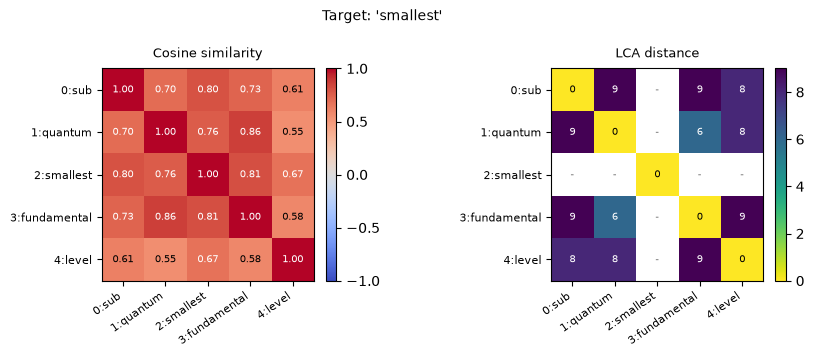


Context: 'The core concept of quantum mechanics is that at the smallest' | Target: 'scales,'
Top-5        |   0:scales |    1:scale |   2:levels |    3:level |   4:length
-----------------------------------------------------------------------------
0:scales     |     1.0000 |     0.8148 |     0.6406 |     0.6340 |     0.7940
1:scale      |     0.8148 |     1.0000 |     0.5843 |     0.6213 |     0.7524
2:levels     |     0.6406 |     0.5843 |     1.0000 |     0.7340 |     0.5850
3:level      |     0.6340 |     0.6213 |     0.7340 |     1.0000 |     0.6370
4:length     |     0.7940 |     0.7524 |     0.5850 |     0.6370 |     1.0000


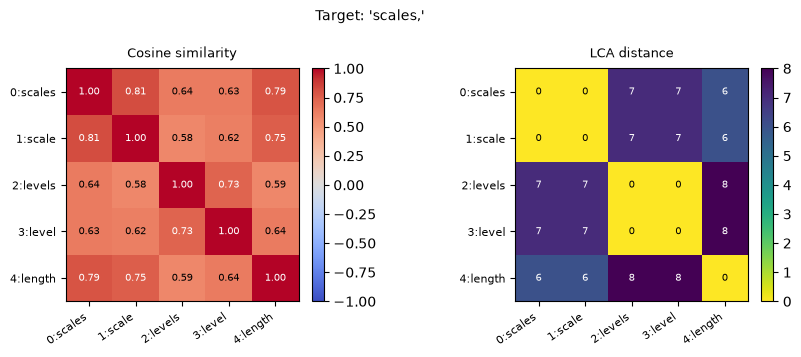


Context: 'The core concept of quantum mechanics is that at the smallest scales,' | Target: 'particles'
Top-5         |   0:particles |      1:things |      2:matter |     3:reality |      4:nature
---------------------------------------------------------------------------------------------
0:particles   |        1.0000 |        0.7012 |        0.7714 |        0.7323 |        0.5805
1:things      |        0.7012 |        1.0000 |        0.6651 |        0.7022 |        0.5431
2:matter      |        0.7714 |        0.6651 |        1.0000 |        0.7322 |        0.5923
3:reality     |        0.7323 |        0.7022 |        0.7322 |        1.0000 |        0.6586
4:nature      |        0.5805 |        0.5431 |        0.5923 |        0.6586 |        1.0000


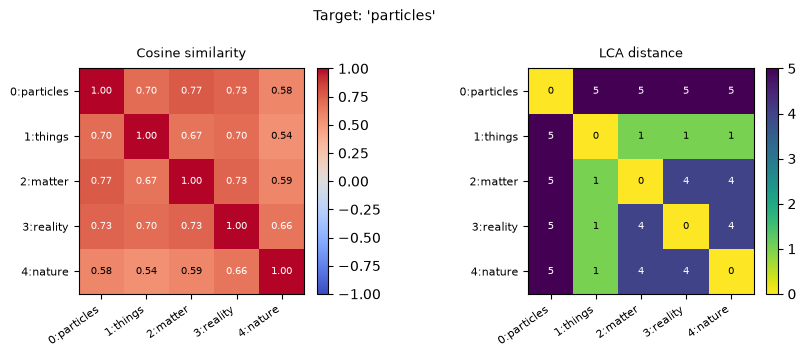


Context: 'The core concept of quantum mechanics is that at the smallest scales, particles do not' | Target: 'exist'
Top-5        |   0:behave |   1:follow |   2:always |    3:exist |      4:act
-----------------------------------------------------------------------------
0:behave     |     1.0000 |     0.7095 |     0.7383 |     0.7909 |     0.6046
1:follow     |     0.7095 |     1.0000 |     0.6320 |     0.6799 |     0.5112
2:always     |     0.7383 |     0.6320 |     1.0000 |     0.7303 |     0.5515
3:exist      |     0.7909 |     0.6799 |     0.7303 |     1.0000 |     0.5989
4:act        |     0.6046 |     0.5112 |     0.5515 |     0.5989 |     1.0000


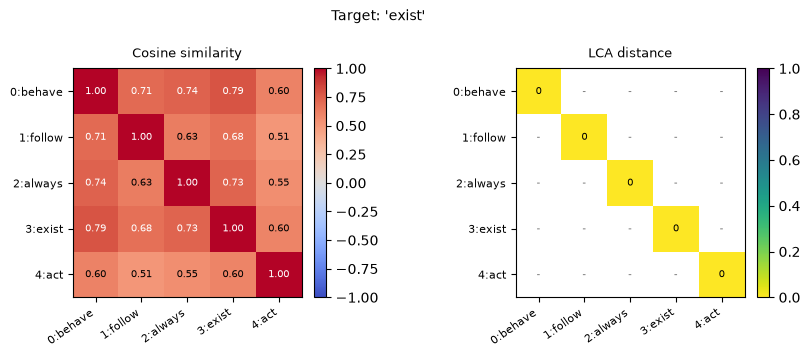


Context: 'The core concept of quantum mechanics is that at the smallest scales, particles do not exist as definite' | Target: 'positions'
Top-5         |      0:points |     1:objects |    2:entities |      3:things |   4:particles
---------------------------------------------------------------------------------------------
0:points      |        1.0000 |        0.2416 |        0.1732 |        0.2809 |        0.1800
1:objects     |        0.2416 |        1.0000 |        0.8012 |        0.7553 |        0.7961
2:entities    |        0.1732 |        0.8012 |        1.0000 |        0.6893 |        0.7638
3:things      |        0.2809 |        0.7553 |        0.6893 |        1.0000 |        0.7012
4:particles   |        0.1800 |        0.7961 |        0.7638 |        0.7012 |        1.0000


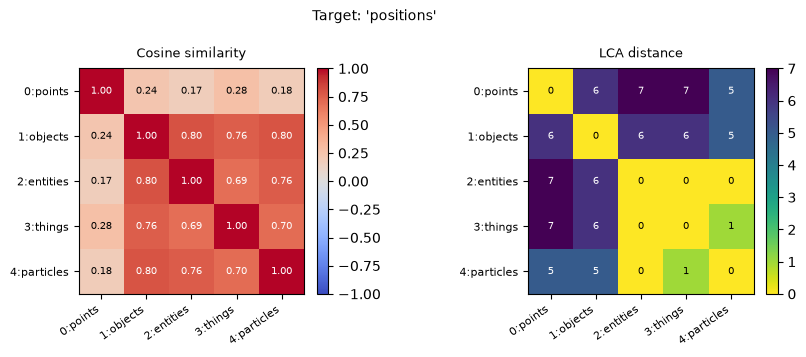


Context: 'The core concept of quantum mechanics is that at the smallest scales, particles do not exist as definite positions or' | Target: 'speeds'
Top-5          |   0:velocities |       1:states |       2:moment |       3:speeds |        4:paths
---------------------------------------------------------------------------------------------------
0:velocities   |         1.0000 |         0.3392 |         0.2009 |         0.2179 |         0.2960
1:states       |         0.3392 |         1.0000 |         0.3572 |         0.3903 |         0.5269
2:moment       |         0.2009 |         0.3572 |         1.0000 |         0.7884 |         0.6235
3:speeds       |         0.2179 |         0.3903 |         0.7884 |         1.0000 |         0.7584
4:paths        |         0.2960 |         0.5269 |         0.6235 |         0.7584 |         1.0000


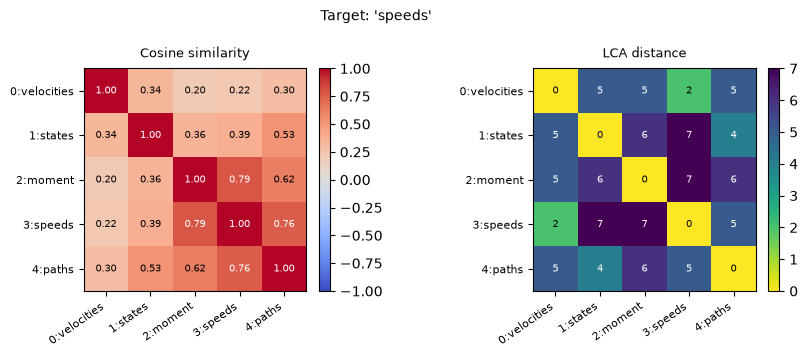


Context: 'The core concept of quantum mechanics is that at the smallest scales, particles do not exist as definite positions or speeds but' | Target: 'rather'
Top-5        |    0:rather |   1:instead |     2:exist |    3:behave |   4:exhibit
----------------------------------------------------------------------------------
0:rather     |      1.0000 |      0.6600 |      0.6399 |      0.6279 |      0.5236
1:instead    |      0.6600 |      1.0000 |      0.4121 |      0.3720 |      0.3472
2:exist      |      0.6399 |      0.4121 |      1.0000 |      0.7909 |      0.6019
3:behave     |      0.6279 |      0.3720 |      0.7909 |      1.0000 |      0.5727
4:exhibit    |      0.5236 |      0.3472 |      0.6019 |      0.5727 |      1.0000


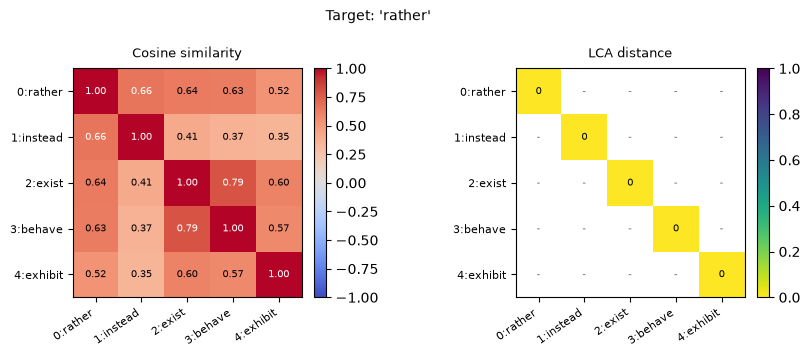


Context: 'The core concept of quantum mechanics is that at the smallest scales, particles do not exist as definite positions or speeds but rather as' | Target: 'probabilities.'
Top-5             |   0:probabilities |     1:probability |           2:waves |          3:clouds |        4:probabil
---------------------------------------------------------------------------------------------------------------------
0:probabilities   |            1.0000 |            0.4821 |            0.3347 |            0.2874 |            0.5322
1:probability     |            0.4821 |            1.0000 |            0.4302 |            0.4466 |            0.3966
2:waves           |            0.3347 |            0.4302 |            1.0000 |            0.7431 |            0.4621
3:clouds          |            0.2874 |            0.4466 |            0.7431 |            1.0000 |            0.4688
4:probabil        |            0.5322 |            0.3966 |            0.4621 |            0.4688 |            1.0

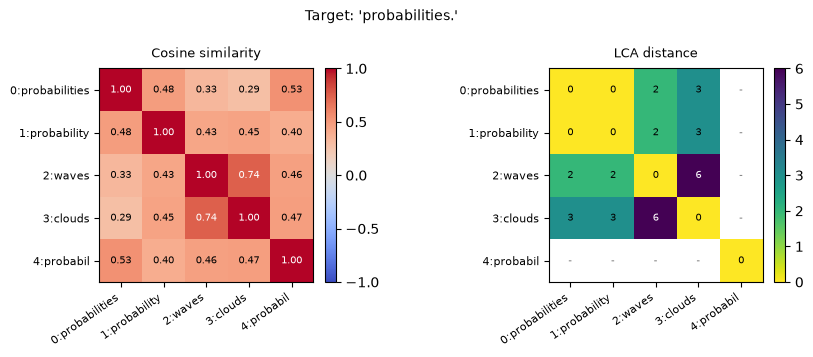

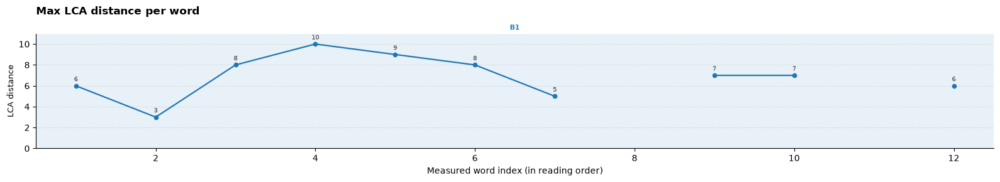

This is known as wave-particle duality. 
Context: 'This is known as' | Target: 'wave-particle'
Top-5        |          0:n |      1:cross |     2:newton |   3:negative |        4:non
---------------------------------------------------------------------------------------
0:n          |       1.0000 |       0.5821 |       0.5441 |       0.4884 |       0.7168
1:cross      |       0.5821 |       1.0000 |       0.7318 |       0.5015 |       0.6294
2:newton     |       0.5441 |       0.7318 |       1.0000 |       0.4605 |       0.6352
3:negative   |       0.4884 |       0.5015 |       0.4605 |       1.0000 |       0.5488
4:non        |       0.7168 |       0.6294 |       0.6352 |       0.5488 |       1.0000


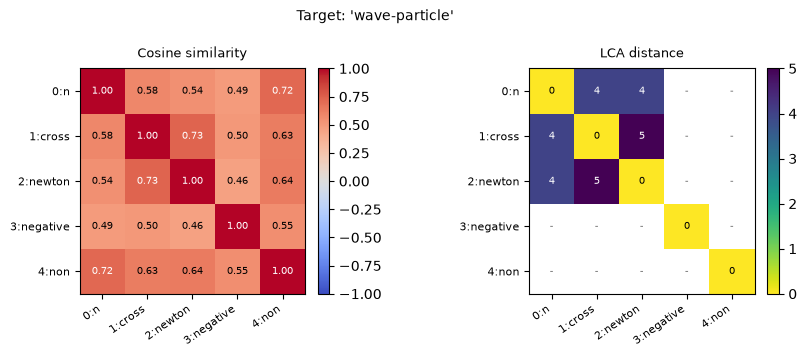


Context: 'This is known as wave-particle' | Target: 'duality.'
Top-5            |     0:complement |          1:super |        2:paradox |         3:theory |   4:interference
---------------------------------------------------------------------------------------------------------------
0:complement     |           1.0000 |           0.6432 |           0.7260 |           0.7158 |           0.5565
1:super          |           0.6432 |           1.0000 |           0.7236 |           0.6609 |           0.5735
2:paradox        |           0.7260 |           0.7236 |           1.0000 |           0.7722 |           0.6127
3:theory         |           0.7158 |           0.6609 |           0.7722 |           1.0000 |           0.5950
4:interference   |           0.5565 |           0.5735 |           0.6127 |           0.5950 |           1.0000


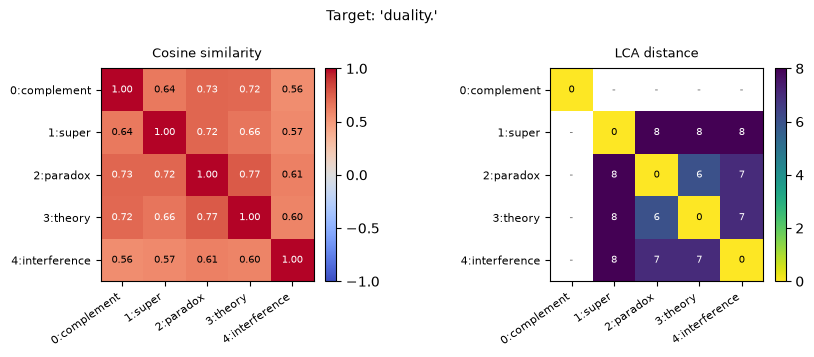

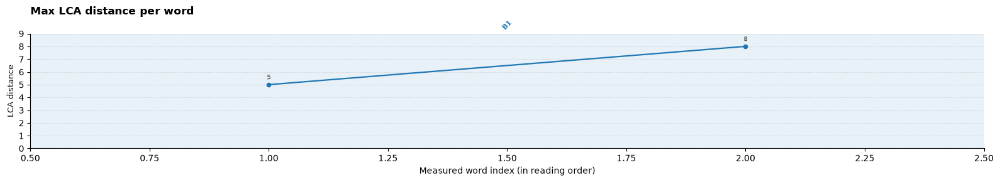

For example, light can behave both as a particle (photon) and a wave, which is why it has been difficult to definitively measure its properties until recent technological advancements.


Context: 'For' | Target: 'example,'
Top-5        |       0:real |    1:example |   2:patients |   3:positive |      4:three
---------------------------------------------------------------------------------------
0:real       |       1.0000 |       0.5747 |       0.5020 |       0.4704 |       0.5659
1:example    |       0.5747 |       1.0000 |       0.4223 |       0.3983 |       0.4518
2:patients   |       0.5020 |       0.4223 |       1.0000 |       0.4598 |       0.3791
3:positive   |       0.4704 |       0.3983 |       0.4598 |       1.0000 |       0.3712
4:three      |       0.5659 |       0.4518 |       0.3791 |       0.3712 |       1.0000


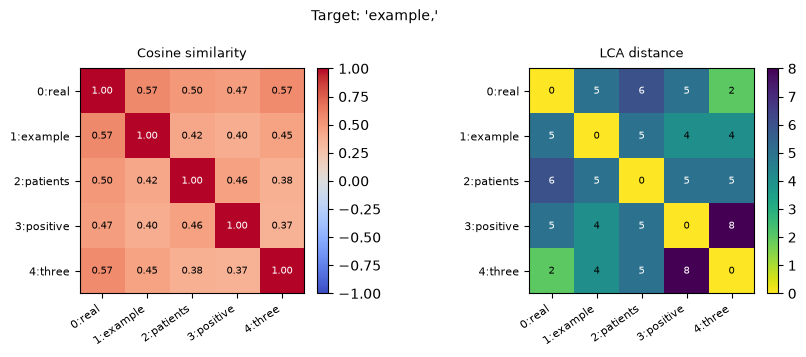


Context: 'For example,' | Target: 'light'
Top-5        |        0:let |      1:given |   2:consider |    3:suppose |       4:take
---------------------------------------------------------------------------------------
0:let        |       1.0000 |       0.7179 |       0.7736 |       0.5879 |       0.7485
1:given      |       0.7179 |       1.0000 |       0.6822 |       0.5593 |       0.7266
2:consider   |       0.7736 |       0.6822 |       1.0000 |       0.5910 |       0.7491
3:suppose    |       0.5879 |       0.5593 |       0.5910 |       1.0000 |       0.5243
4:take       |       0.7485 |       0.7266 |       0.7491 |       0.5243 |       1.0000


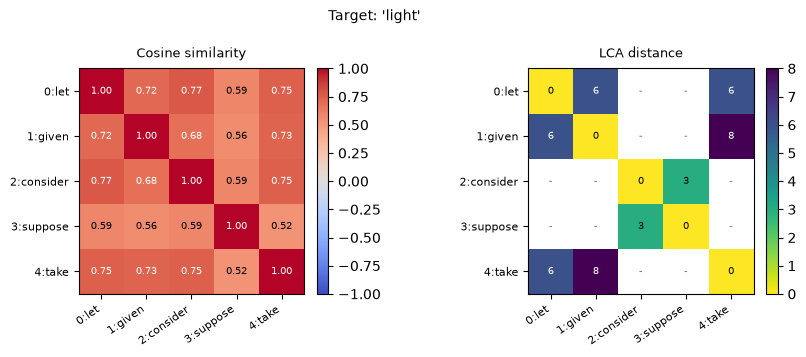


Context: 'For example, light can' | Target: 'behave'
Top-5        |     0:pass |   1:travel |    2:cause |    3:carry |    4:enter
-----------------------------------------------------------------------------
0:pass       |     1.0000 |     0.4917 |     0.6219 |     0.7197 |     0.6324
1:travel     |     0.4917 |     1.0000 |     0.4917 |     0.5403 |     0.4116
2:cause      |     0.6219 |     0.4917 |     1.0000 |     0.7786 |     0.5701
3:carry      |     0.7197 |     0.5403 |     0.7786 |     1.0000 |     0.5798
4:enter      |     0.6324 |     0.4116 |     0.5701 |     0.5798 |     1.0000


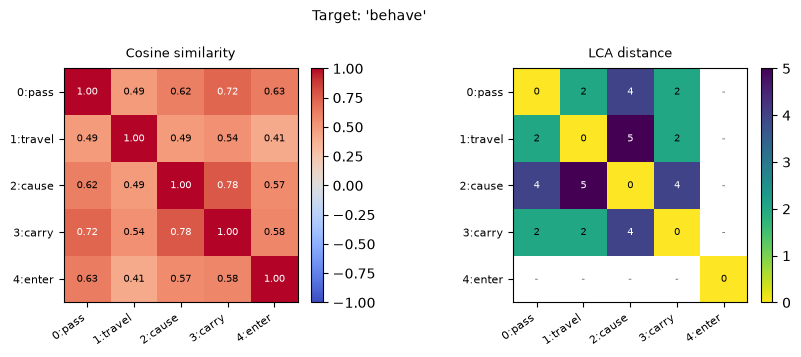


Context: 'For example, light can behave both as a' | Target: 'particle'
Top-5         |        0:wave |    1:particle |   2:classical |      3:stream |      4:photon
---------------------------------------------------------------------------------------------
0:wave        |        1.0000 |        0.7140 |        0.7039 |        0.6295 |        0.7303
1:particle    |        0.7140 |        1.0000 |        0.7635 |        0.5918 |        0.8211
2:classical   |        0.7039 |        0.7635 |        1.0000 |        0.5567 |        0.7945
3:stream      |        0.6295 |        0.5918 |        0.5567 |        1.0000 |        0.6084
4:photon      |        0.7303 |        0.8211 |        0.7945 |        0.6084 |        1.0000


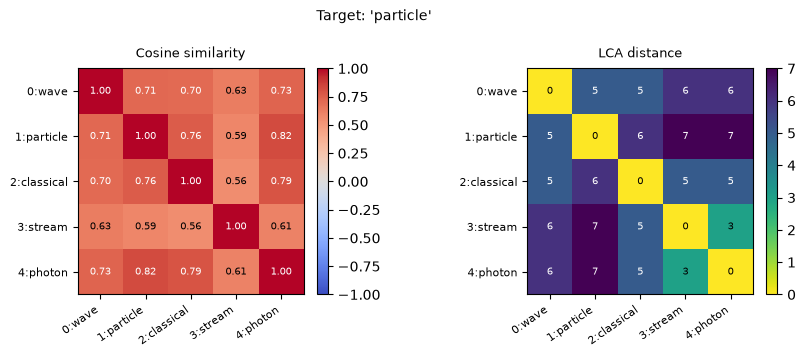


Context: 'For example, light can behave both as a particle' | Target: '(photon)'
Top-5          |       0:called |       1:stream |         2:beam |            3:w |   4:exhibiting
---------------------------------------------------------------------------------------------------
0:called       |         1.0000 |         0.5103 |         0.6287 |         0.5331 |         0.5662
1:stream       |         0.5103 |         1.0000 |         0.6019 |         0.4899 |         0.4732
2:beam         |         0.6287 |         0.6019 |         1.0000 |         0.5978 |         0.6392
3:w            |         0.5331 |         0.4899 |         0.5978 |         1.0000 |         0.6170
4:exhibiting   |         0.5662 |         0.4732 |         0.6392 |         0.6170 |         1.0000


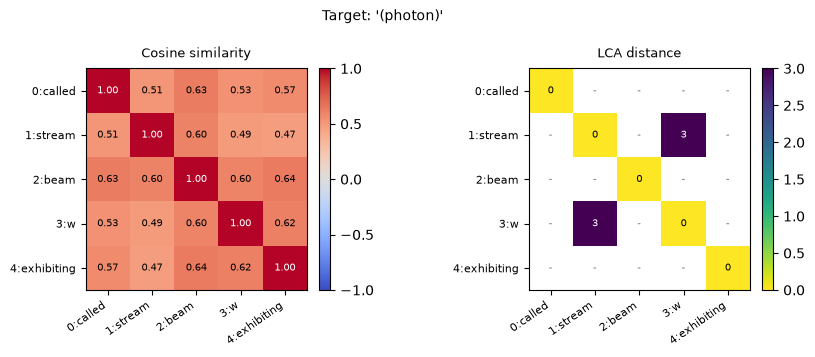


Context: 'For example, light can behave both as a particle (photon) and a' | Target: 'wave,'
Top-5          |         0:wave |    1:classical |        2:field |   3:wavelength |            4:w
---------------------------------------------------------------------------------------------------
0:wave         |         1.0000 |         0.7039 |         0.5360 |         0.7459 |         0.6633
1:classical    |         0.7039 |         1.0000 |         0.5598 |         0.8168 |         0.6528
2:field        |         0.5360 |         0.5598 |         1.0000 |         0.5373 |         0.5195
3:wavelength   |         0.7459 |         0.8168 |         0.5373 |         1.0000 |         0.6332
4:w            |         0.6633 |         0.6528 |         0.5195 |         0.6332 |         1.0000


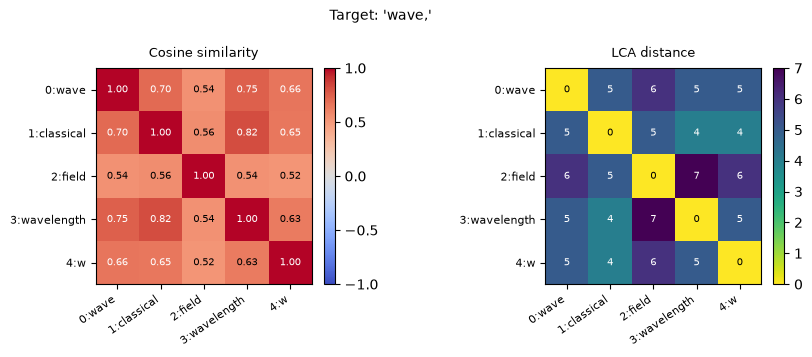


Context: 'For example, light can behave both as a particle (photon) and a wave, which is why it has been difficult to' | Target: 'definitively'
Top-5        |     0:define |   1:describe |        2:pin |    3:explain |   4:classify
---------------------------------------------------------------------------------------
0:define     |       1.0000 |       0.7390 |       0.5558 |       0.7266 |       0.6598
1:describe   |       0.7390 |       1.0000 |       0.6966 |       0.8872 |       0.8614
2:pin        |       0.5558 |       0.6966 |       1.0000 |       0.7152 |       0.7501
3:explain    |       0.7266 |       0.8872 |       0.7152 |       1.0000 |       0.8311
4:classify   |       0.6598 |       0.8614 |       0.7501 |       0.8311 |       1.0000


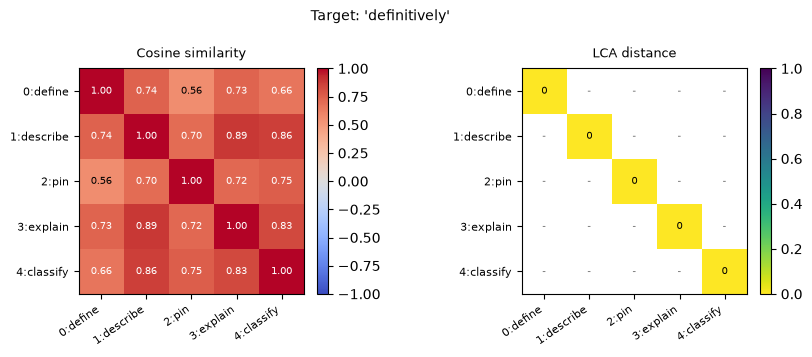


Context: 'For example, light can behave both as a particle (photon) and a wave, which is why it has been difficult to definitively' | Target: 'measure'
Top-5         |   0:determine |    1:classify |      2:define |     3:categor |    4:describe
---------------------------------------------------------------------------------------------
0:determine   |        1.0000 |        0.7844 |        0.6706 |        0.4314 |        0.7794
1:classify    |        0.7844 |        1.0000 |        0.6598 |        0.3948 |        0.8614
2:define      |        0.6706 |        0.6598 |        1.0000 |        0.3202 |        0.7390
3:categor     |        0.4314 |        0.3948 |        0.3202 |        1.0000 |        0.3921
4:describe    |        0.7794 |        0.8614 |        0.7390 |        0.3921 |        1.0000


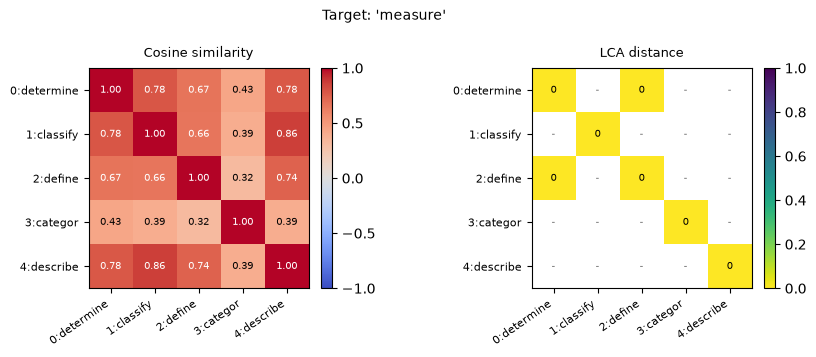


Context: 'For example, light can behave both as a particle (photon) and a wave, which is why it has been difficult to definitively measure its' | Target: 'properties'
Top-5          |   0:properties |       1:nature |        2:exact |     3:behavior |         4:true
---------------------------------------------------------------------------------------------------
0:properties   |         1.0000 |         0.6208 |         0.6766 |         0.8350 |         0.5319
1:nature       |         0.6208 |         1.0000 |         0.5187 |         0.6455 |         0.4386
2:exact        |         0.6766 |         0.5187 |         1.0000 |         0.6757 |         0.5827
3:behavior     |         0.8350 |         0.6455 |         0.6757 |         1.0000 |         0.5433
4:true         |         0.5319 |         0.4386 |         0.5827 |         0.5433 |         1.0000


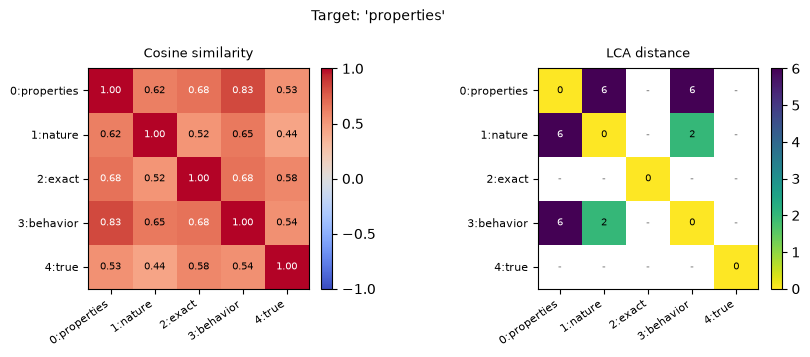


Context: 'For example, light can behave both as a particle (photon) and a wave, which is why it has been difficult to definitively measure its properties until' | Target: 'recent'
Top-5          |     0:recently |       1:recent |       2:modern |        3:today |   4:relatively
---------------------------------------------------------------------------------------------------
0:recently     |         1.0000 |         0.8548 |         0.6797 |         0.6088 |         0.7061
1:recent       |         0.8548 |         1.0000 |         0.7908 |         0.5152 |         0.7687
2:modern       |         0.6797 |         0.7908 |         1.0000 |         0.5022 |         0.6644
3:today        |         0.6088 |         0.5152 |         0.5022 |         1.0000 |         0.4751
4:relatively   |         0.7061 |         0.7687 |         0.6644 |         0.4751 |         1.0000


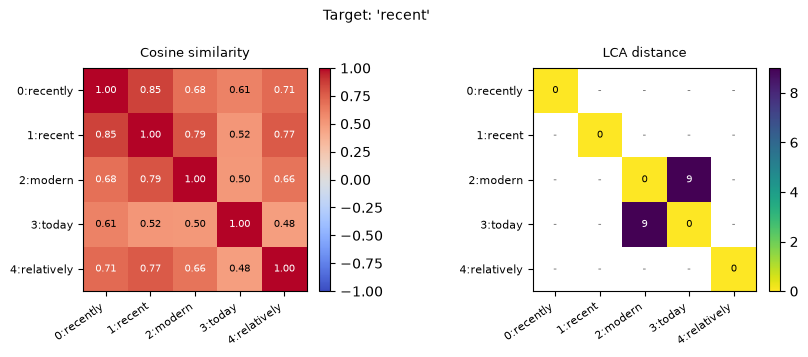


Context: 'For example, light can behave both as a particle (photon) and a wave, which is why it has been difficult to definitively measure its properties until recent technological' | Target: 'advancements.'
Top-5            |       0:advances |   1:advancements |   2:developments |   3:breakthrough |   4:improvements
---------------------------------------------------------------------------------------------------------------
0:advances       |           1.0000 |           0.5861 |           0.5819 |           0.5745 |           0.4803
1:advancements   |           0.5861 |           1.0000 |           0.5100 |           0.5212 |           0.6017
2:developments   |           0.5819 |           0.5100 |           1.0000 |           0.7999 |           0.4697
3:breakthrough   |           0.5745 |           0.5212 |           0.7999 |           1.0000 |           0.4598
4:improvements   |           0.4803 |           0.6017 |           0.4697 |           0.4598 |           1.0000


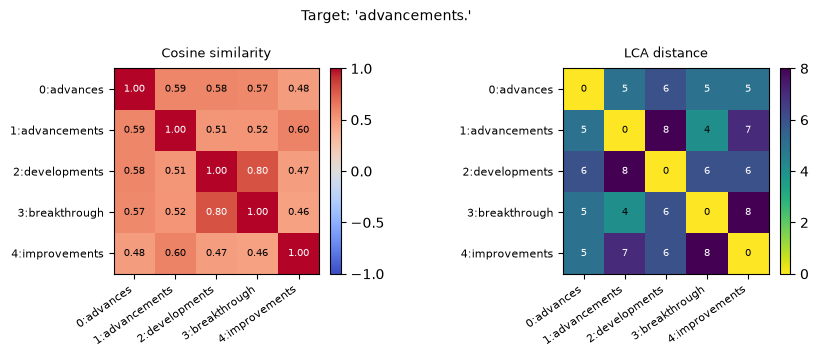

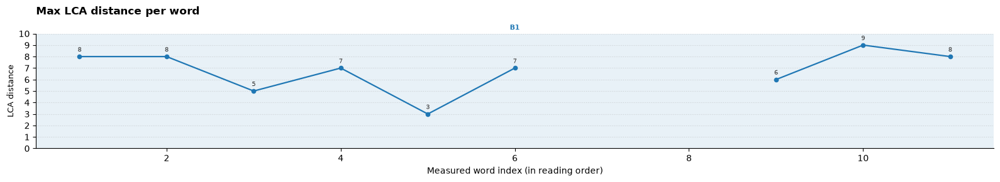

Quantum theory also introduces concepts such as superposition, where a system exists in multiple states simultaneously until observed. 
Context: 'Quantum' | Target: 'theory'
Top-5           |     0:computing |     1:mechanics |     2:computers |            3:qu |   4:information
---------------------------------------------------------------------------------------------------------
0:computing     |          1.0000 |          0.7139 |          0.7520 |          0.4865 |          0.5718
1:mechanics     |          0.7139 |          1.0000 |          0.7426 |          0.5073 |          0.4836
2:computers     |          0.7520 |          0.7426 |          1.0000 |          0.4849 |          0.4713
3:qu            |          0.4865 |          0.5073 |          0.4849 |          1.0000 |          0.3248
4:information   |          0.5718 |          0.4836 |          0.4713 |          0.3248 |          1.0000


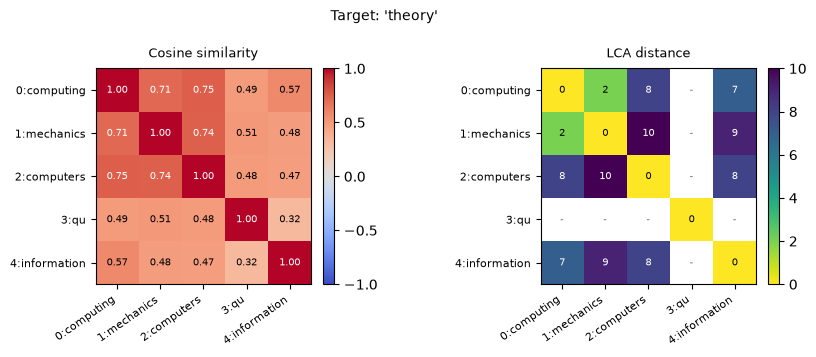


Context: 'Quantum theory also' | Target: 'introduces'
Top-5        |   0:predicts |   1:suggests |   2:provides |      3:tells |   4:explains
---------------------------------------------------------------------------------------
0:predicts   |       1.0000 |       0.5626 |       0.5380 |       0.5356 |       0.5375
1:suggests   |       0.5626 |       1.0000 |       0.7133 |       0.7887 |       0.8024
2:provides   |       0.5380 |       0.7133 |       1.0000 |       0.6511 |       0.6526
3:tells      |       0.5356 |       0.7887 |       0.6511 |       1.0000 |       0.8265
4:explains   |       0.5375 |       0.8024 |       0.6526 |       0.8265 |       1.0000


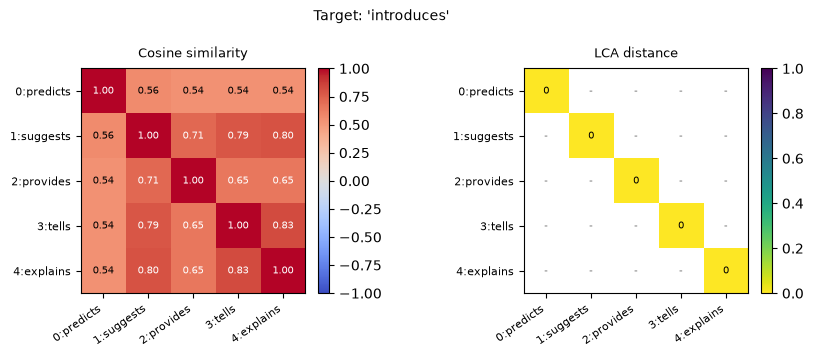


Context: 'Quantum theory also introduces' | Target: 'concepts'
Top-5             |             0:non |     1:uncertainty |      2:randomness |   3:probabilities |   4:uncertainties
---------------------------------------------------------------------------------------------------------------------
0:non             |            1.0000 |            0.5490 |            0.3904 |            0.2982 |            0.2718
1:uncertainty     |            0.5490 |            1.0000 |            0.7381 |            0.4955 |            0.5873
2:randomness      |            0.3904 |            0.7381 |            1.0000 |            0.4586 |            0.6248
3:probabilities   |            0.2982 |            0.4955 |            0.4586 |            1.0000 |            0.5302
4:uncertainties   |            0.2718 |            0.5873 |            0.6248 |            0.5302 |            1.0000


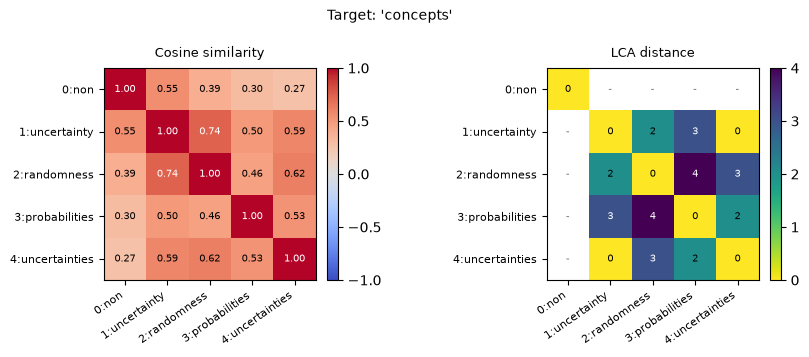


Context: 'Quantum theory also introduces concepts such as' | Target: 'superposition,'
Top-5        |     0:super |   1:quantum |       2:ent |      3:wave |       4:non
----------------------------------------------------------------------------------
0:super      |      1.0000 |      0.7088 |      0.3794 |      0.7320 |      0.7285
1:quantum    |      0.7088 |      1.0000 |      0.4522 |      0.7191 |      0.6423
2:ent        |      0.3794 |      0.4522 |      1.0000 |      0.3991 |      0.3905
3:wave       |      0.7320 |      0.7191 |      0.3991 |      1.0000 |      0.6614
4:non        |      0.7285 |      0.6423 |      0.3905 |      0.6614 |      1.0000


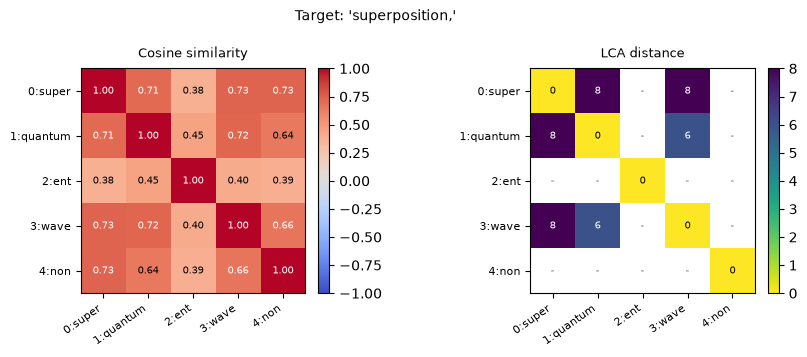


Context: 'Quantum theory also introduces concepts such as superposition, where a' | Target: 'system'
Top-5        |    0:quantum |   1:particle |     2:system |          3:q |     4:single
---------------------------------------------------------------------------------------
0:quantum    |       1.0000 |       0.8528 |       0.6591 |       0.6152 |       0.3791
1:particle   |       0.8528 |       1.0000 |       0.6798 |       0.5877 |       0.3611
2:system     |       0.6591 |       0.6798 |       1.0000 |       0.5718 |       0.3746
3:q          |       0.6152 |       0.5877 |       0.5718 |       1.0000 |       0.2896
4:single     |       0.3791 |       0.3611 |       0.3746 |       0.2896 |       1.0000


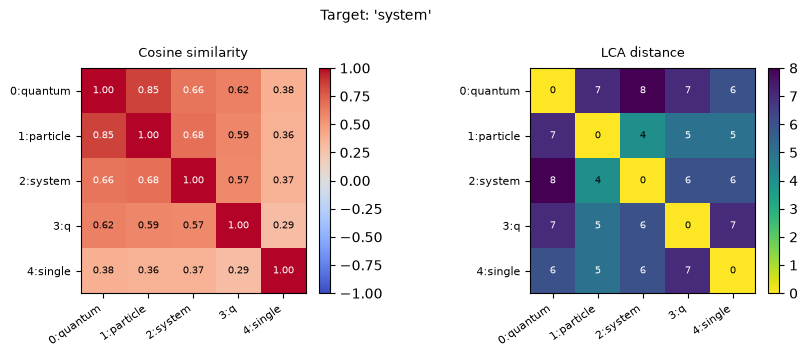


Context: 'Quantum theory also introduces concepts such as superposition, where a system' | Target: 'exists'
Top-5              |           0:exists |   1:simultaneously |           2:cannot |            3:exist |          4:remains
---------------------------------------------------------------------------------------------------------------------------
0:exists           |             1.0000 |             0.5813 |             0.7596 |             0.8925 |             0.6750
1:simultaneously   |             0.5813 |             1.0000 |             0.6519 |             0.6727 |             0.6721
2:cannot           |             0.7596 |             0.6519 |             1.0000 |             0.8242 |             0.7097
3:exist            |             0.8925 |             0.6727 |             0.8242 |             1.0000 |             0.7452
4:remains          |             0.6750 |             0.6721 |             0.7097 |             0.7452 |             1.0000


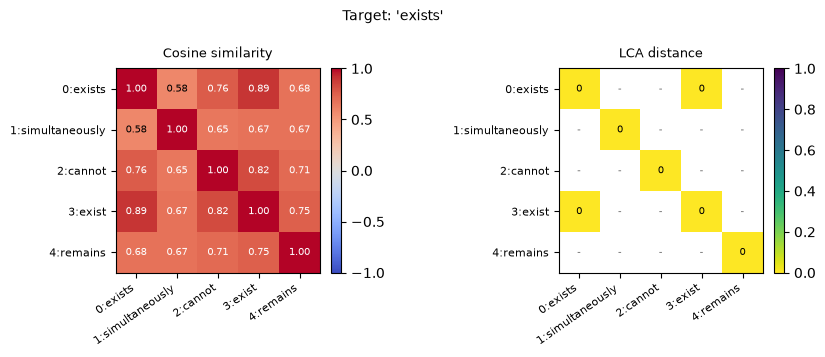


Context: 'Quantum theory also introduces concepts such as superposition, where a system exists in' | Target: 'multiple'
Top-5           |      0:multiple |   1:potentially |      2:parallel |        3:states |     4:multiples
---------------------------------------------------------------------------------------------------------
0:multiple      |          1.0000 |          0.7882 |          0.7198 |          0.4240 |          0.7249
1:potentially   |          0.7882 |          1.0000 |          0.5850 |          0.3859 |          0.5094
2:parallel      |          0.7198 |          0.5850 |          1.0000 |          0.4335 |          0.6549
3:states        |          0.4240 |          0.3859 |          0.4335 |          1.0000 |          0.4379
4:multiples     |          0.7249 |          0.5094 |          0.6549 |          0.4379 |          1.0000


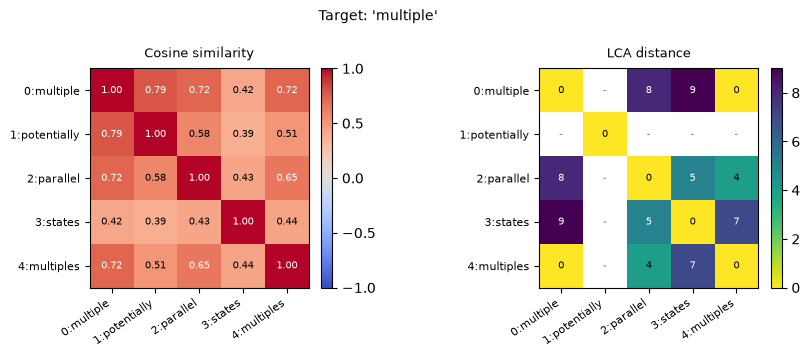


Context: 'Quantum theory also introduces concepts such as superposition, where a system exists in multiple' | Target: 'states'
Top-5             |          0:states |        1:possible |         2:quantum |   3:possibilities |        4:mutually
---------------------------------------------------------------------------------------------------------------------
0:states          |            1.0000 |            0.4425 |            0.3625 |            0.4875 |            0.4352
1:possible        |            0.4425 |            1.0000 |            0.6097 |            0.7421 |            0.6865
2:quantum         |            0.3625 |            0.6097 |            1.0000 |            0.6212 |            0.7105
3:possibilities   |            0.4875 |            0.7421 |            0.6212 |            1.0000 |            0.6716
4:mutually        |            0.4352 |            0.6865 |            0.7105 |            0.6716 |            1.0000


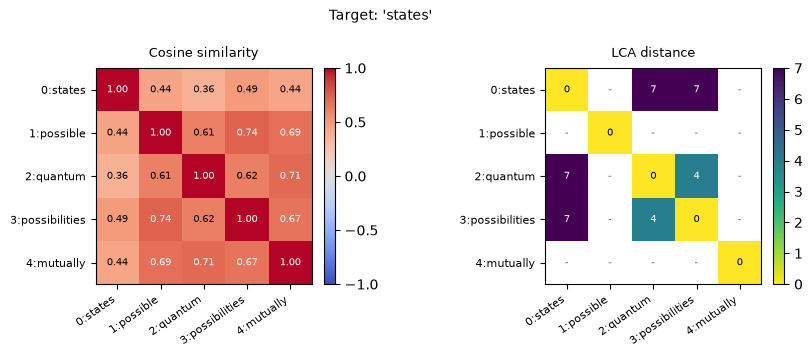


Context: 'Quantum theory also introduces concepts such as superposition, where a system exists in multiple states' | Target: 'simultaneously'
Top-5              |   0:simultaneously |     1:concurrently |           2:simult |            3:prior |           4:rather
---------------------------------------------------------------------------------------------------------------------------
0:simultaneously   |             1.0000 |             0.5673 |             0.5455 |             0.5403 |             0.5982
1:concurrently     |             0.5673 |             1.0000 |             0.4649 |             0.5399 |             0.4844
2:simult           |             0.5455 |             0.4649 |             1.0000 |             0.4887 |             0.4889
3:prior            |             0.5403 |             0.5399 |             0.4887 |             1.0000 |             0.5505
4:rather           |             0.5982 |             0.4844 |             0.4889 |             0.5505 |         

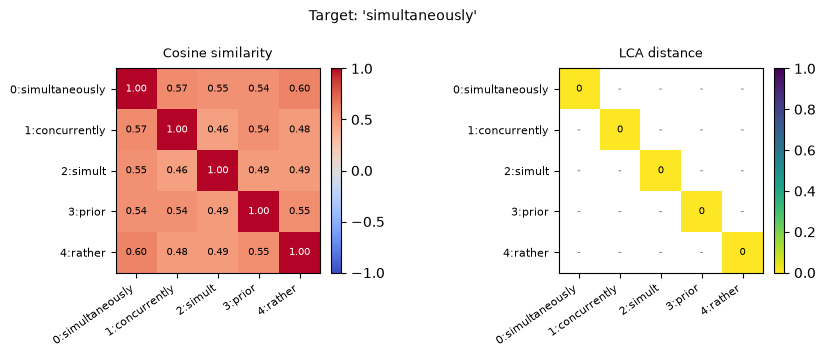

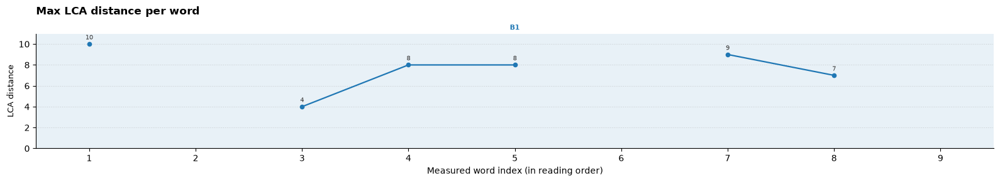

Entanglement, another key principle, allows particles to be connected in such a way that changes to one instantly affect the other, regardless of distance.


Context: 'Entanglement, another' | Target: 'key'
Top-5        |   0:quantum |      1:form |      2:word |      3:name |       4:way
----------------------------------------------------------------------------------
0:quantum    |      1.0000 |      0.6465 |      0.6827 |      0.6391 |      0.4927
1:form       |      0.6465 |      1.0000 |      0.6980 |      0.6808 |      0.5206
2:word       |      0.6827 |      0.6980 |      1.0000 |      0.7845 |      0.6408
3:name       |      0.6391 |      0.6808 |      0.7845 |      1.0000 |      0.6059
4:way        |      0.4927 |      0.5206 |      0.6408 |      0.6059 |      1.0000


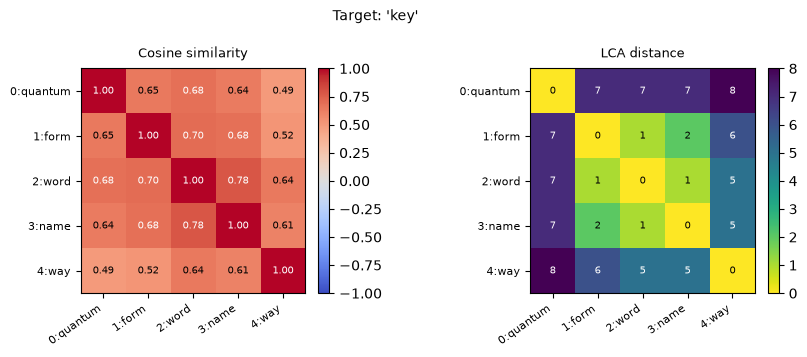


Context: 'Entanglement, another key' | Target: 'principle,'
Top-5          |      0:concept |      1:feature |      2:quantum |   3:ingredient |     4:resource
---------------------------------------------------------------------------------------------------
0:concept      |         1.0000 |         0.7192 |         0.7173 |         0.7246 |         0.6927
1:feature      |         0.7192 |         1.0000 |         0.6261 |         0.6368 |         0.6334
2:quantum      |         0.7173 |         0.6261 |         1.0000 |         0.7447 |         0.6257
3:ingredient   |         0.7246 |         0.6368 |         0.7447 |         1.0000 |         0.6661
4:resource     |         0.6927 |         0.6334 |         0.6257 |         0.6661 |         1.0000


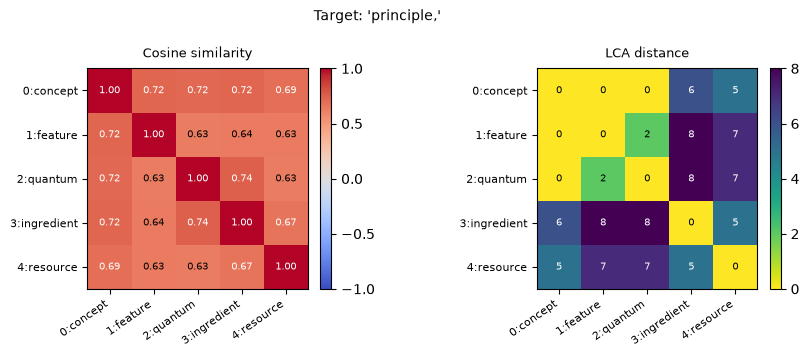


Context: 'Entanglement, another key principle,' | Target: 'allows'
Top-5         |      0:refers |      1:occurs |   2:describes |      3:allows |      4:arises
---------------------------------------------------------------------------------------------
0:refers      |        1.0000 |        0.7371 |        0.6986 |        0.6493 |        0.6580
1:occurs      |        0.7371 |        1.0000 |        0.7287 |        0.7199 |        0.7269
2:describes   |        0.6986 |        0.7287 |        1.0000 |        0.8521 |        0.8335
3:allows      |        0.6493 |        0.7199 |        0.8521 |        1.0000 |        0.8568
4:arises      |        0.6580 |        0.7269 |        0.8335 |        0.8568 |        1.0000


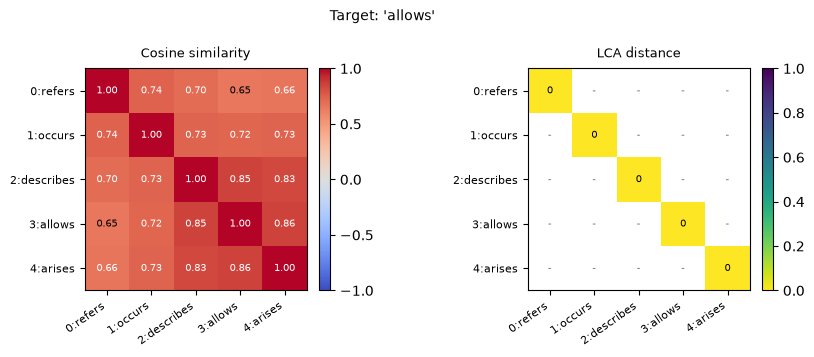


Context: 'Entanglement, another key principle, allows' | Target: 'particles'
Top-5           |       0:quantum |     1:particles |             2:q |   3:information |         4:pairs
---------------------------------------------------------------------------------------------------------
0:quantum       |          1.0000 |          0.8208 |          0.6152 |          0.4434 |          0.3181
1:particles     |          0.8208 |          1.0000 |          0.5768 |          0.4488 |          0.3685
2:q             |          0.6152 |          0.5768 |          1.0000 |          0.3884 |          0.4100
3:information   |          0.4434 |          0.4488 |          0.3884 |          1.0000 |          0.4080
4:pairs         |          0.3181 |          0.3685 |          0.4100 |          0.4080 |          1.0000


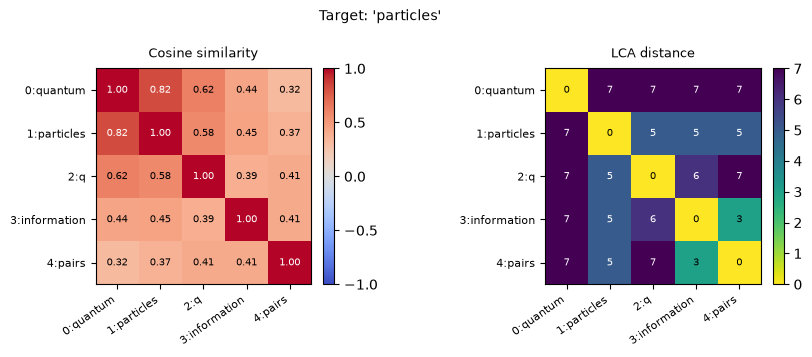


Context: 'Entanglement, another key principle, allows particles to be connected in such a' | Target: 'way'
Top-5        |        0:way |     1:manner |    2:fashion |   3:specific |    4:special
---------------------------------------------------------------------------------------
0:way        |       1.0000 |       0.5651 |       0.5730 |       0.5102 |       0.5159
1:manner     |       0.5651 |       1.0000 |       0.7067 |       0.6544 |       0.6159
2:fashion    |       0.5730 |       0.7067 |       1.0000 |       0.8031 |       0.7126
3:specific   |       0.5102 |       0.6544 |       0.8031 |       1.0000 |       0.7750
4:special    |       0.5159 |       0.6159 |       0.7126 |       0.7750 |       1.0000


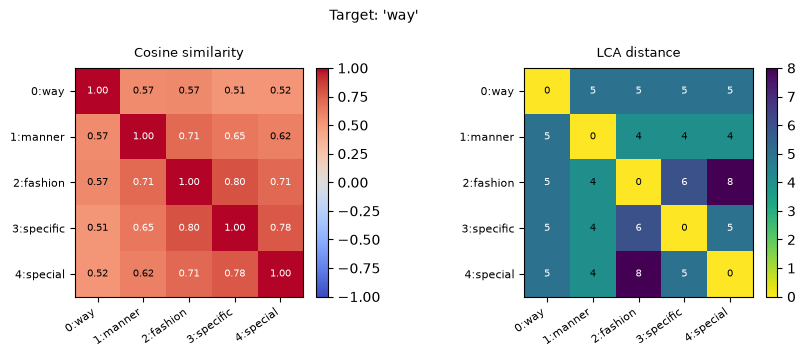


Context: 'Entanglement, another key principle, allows particles to be connected in such a way that' | Target: 'changes'
Top-5            |      0:measuring |        1:changes |        2:actions |   3:measurements |        4:knowing
---------------------------------------------------------------------------------------------------------------
0:measuring      |           1.0000 |           0.4385 |           0.6991 |           0.7237 |           0.8473
1:changes        |           0.4385 |           1.0000 |           0.5322 |           0.5121 |           0.3992
2:actions        |           0.6991 |           0.5322 |           1.0000 |           0.6262 |           0.6596
3:measurements   |           0.7237 |           0.5121 |           0.6262 |           1.0000 |           0.5710
4:knowing        |           0.8473 |           0.3992 |           0.6596 |           0.5710 |           1.0000


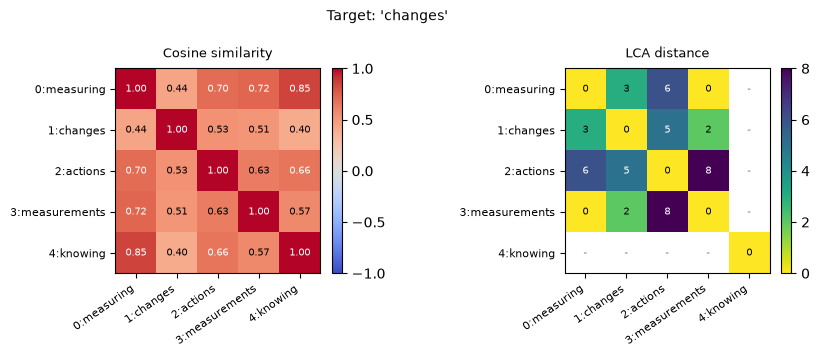


Context: 'Entanglement, another key principle, allows particles to be connected in such a way that changes to one' | Target: 'instantly'
Top-5           |      0:particle |     1:instantly |        2:affect |   3:immediately |       4:instant
---------------------------------------------------------------------------------------------------------
0:particle      |          1.0000 |          0.5313 |          0.7416 |          0.5793 |          0.6167
1:instantly     |          0.5313 |          1.0000 |          0.5894 |          0.9191 |          0.7674
2:affect        |          0.7416 |          0.5894 |          1.0000 |          0.6497 |          0.6369
3:immediately   |          0.5793 |          0.9191 |          0.6497 |          1.0000 |          0.7584
4:instant       |          0.6167 |          0.7674 |          0.6369 |          0.7584 |          1.0000


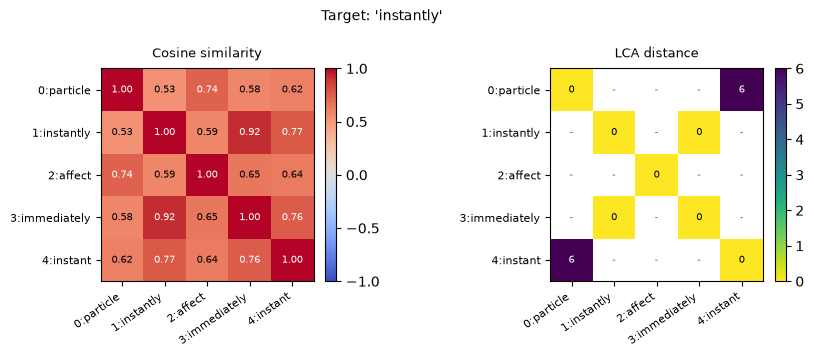


Context: 'Entanglement, another key principle, allows particles to be connected in such a way that changes to one instantly' | Target: 'affect'
Top-5         |      0:affect |   1:influence |      2:impact |     3:reflect |     4:affects
---------------------------------------------------------------------------------------------
0:affect      |        1.0000 |        0.8530 |        0.8116 |        0.8054 |        0.9218
1:influence   |        0.8530 |        1.0000 |        0.7429 |        0.7325 |        0.7927
2:impact      |        0.8116 |        0.7429 |        1.0000 |        0.7174 |        0.7440
3:reflect     |        0.8054 |        0.7325 |        0.7174 |        1.0000 |        0.7547
4:affects     |        0.9218 |        0.7927 |        0.7440 |        0.7547 |        1.0000


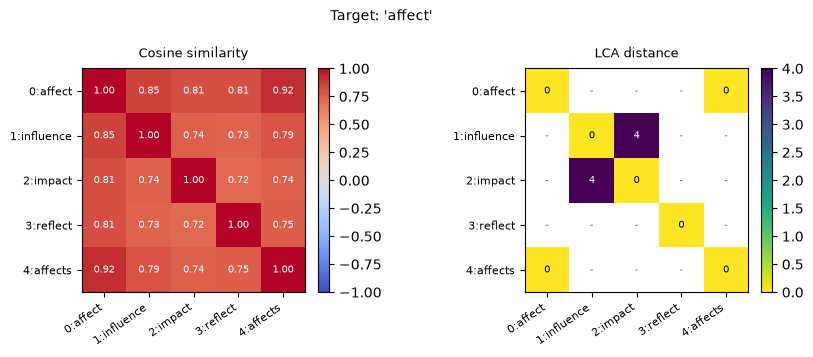


Context: 'Entanglement, another key principle, allows particles to be connected in such a way that changes to one instantly affect the other, regardless of' | Target: 'distance.'
Top-5          |     0:distance |   1:separation |      2:whether |        3:space |    4:distances
---------------------------------------------------------------------------------------------------
0:distance     |         1.0000 |         0.8052 |         0.6336 |         0.8193 |         0.7763
1:separation   |         0.8052 |         1.0000 |         0.6501 |         0.8028 |         0.6153
2:whether      |         0.6336 |         0.6501 |         1.0000 |         0.5973 |         0.5322
3:space        |         0.8193 |         0.8028 |         0.5973 |         1.0000 |         0.6345
4:distances    |         0.7763 |         0.6153 |         0.5322 |         0.6345 |         1.0000


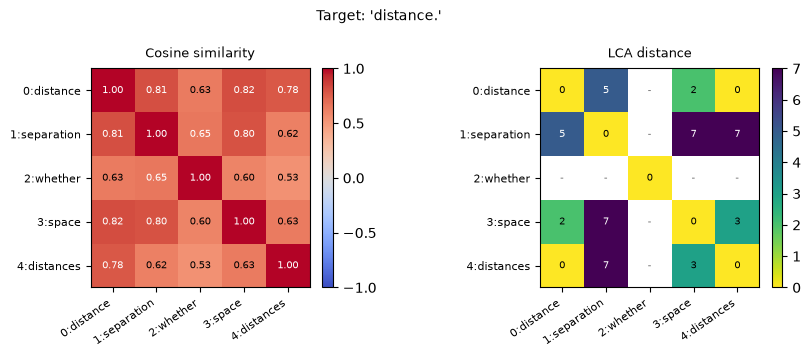

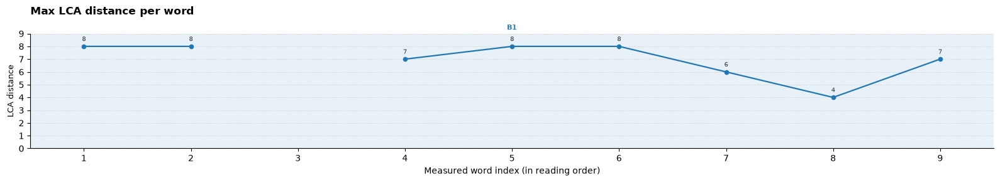

One of the most famous predictions of quantum theory is the Heisenberg Uncertainty Principle, which states that certain pairs of physical properties cannot both be
--- Full Generated Text ---
# Quantum Theory Quantum theory is a fundamental framework in physics that describes the behavior of matter and energy at the atomic and subatomic level. It was developed primarily to explain the results of experiments involving particles like electrons and photons. The core concept of quantum mechanics is that at the smallest scales, particles do not exist as definite positions or speeds but rather as probabilities. This is known as wave-particle duality. For example, light can behave both as a particle (photon) and a wave, which is why it has been difficult to definitively measure its properties until recent technological advancements. Quantum theory also introduces concepts such as superposition, where a system exists in multiple states simultaneously until observed. Entanglement, another key p

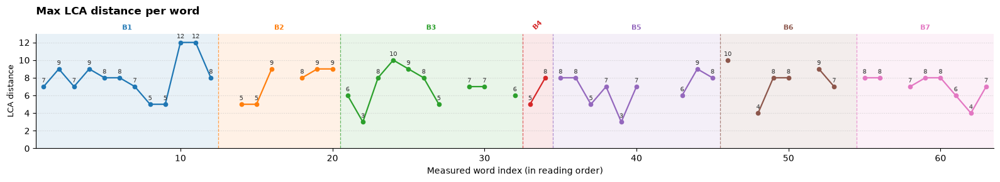

In [38]:
prompt = "Quantum theory a simple explanation"
all_blocks, all_distances = stream_and_analyze(model_1_5b,tokenizer_1_5b,prompt,"factual",model_7b,tokenizer_7b)

print("\n--- Full Generated Text ---")
for block in all_blocks:
    print(block, end=" ")

print("\n\n--- Blocks ---")
for i, block in enumerate(all_blocks, 1):
    print(f"Block {i}: {block}")
    
fig = plot_lca_curve(all_distances, title="Max LCA distance per word", blocks_per_row=12, show_values=True)
fig.tight_layout()
plt.show()
plt.close(fig)
